# 04 — Text Feature Extraction

## Multimodal Medicinal Plant Leaf Retrieval Using Visual and Textual Features

---

## 1. Notebook Overview

This notebook focuses on textual feature extraction from
medicinal plant leaf descriptions using Term Frequency–Inverse
Document Frequency (TF-IDF).

The textual features will represent the descriptive
characteristics of medicinal plant leaves, including color,
shape, texture, surface characteristics, venation, and other
morphological information.

The extracted textual features will be used for text-based
similarity matching using Cosine Similarity and subsequently
integrated with visual similarity scores through score-level
late fusion.

The visual features have been extracted in Notebook 03 using
HSV Histogram, Gray-Level Co-occurrence Matrix (GLCM),
and Hu Moments.

---

## 2. Objectives

The objectives of this notebook are:

1. Load the preprocessed textual dataset.
2. Validate textual descriptions and sample identifiers.
3. Analyze vocabulary and term frequency distributions.
4. Extract textual features using TF-IDF.
5. Analyze the resulting sparse feature matrix.
6. Identify important terms in medicinal plant leaf descriptions.
7. Validate numerical and mathematical feature consistency.
8. Analyze textual similarity using Cosine Similarity.
9. Verify single-query transformation consistency.
10. Ensure alignment between visual and textual features.
11. Save textual features, vocabulary, and fitted TF-IDF parameters.
12. Generate a comprehensive text feature extraction summary.

---

## 3. Input Dataset

The input dataset is obtained from Notebook 02 —
Image and Text Preprocessing.

### Dataset Information

| Attribute | Description |
|---|---|
| Dataset | Medicinal Plant Leaf Dataset |
| Modality | Text |
| Language | Indonesian |
| Total Samples | 104 |
| Total Classes | 5 |
| Text Representation | Preprocessed Leaf Descriptions |
| Sample Identifier | sample_id |
| Input File | metadata_processed.csv |

### Dataset Class Distribution

| Plant Class | Number of Samples |
|---|---:|
| Mangkok | 20 |
| Salam | 19 |
| Sambang Darah | 20 |
| Sirih | 20 |
| Tapak Kuda | 25 |
| **Total** | **104** |

The textual dataset must preserve the same sample identifiers
as the visual feature dataset to ensure correct multimodal
feature alignment.

---

## 4. Previous Text Preprocessing

The textual descriptions have been processed in Notebook 02.

The preprocessing procedure includes:

- Text validation
- Case folding
- Punctuation removal
- Whitespace normalization
- Plant class-name and alias removal
- Tokenization analysis
- Duplicate description identification
- Empty description validation

Additional stopword removal and stemming are not applied
in the initial configuration.

The removal of explicit plant class names is intended to
reduce direct class-label leakage during retrieval evaluation.

Duplicate textual descriptions and dataset review flags
will remain documented throughout the feature extraction process.

---

## 5. Textual Feature Extraction Method

### 5.1 Term Frequency–Inverse Document Frequency (TF-IDF)

TF-IDF is a statistical feature extraction method that
represents textual documents as numerical vectors based on
the occurrence and relative importance of terms.

Terms that occur frequently in a document but less frequently
across the document collection generally receive higher weights.

Each medicinal plant leaf description is transformed into
a numerical feature vector.

### Term Frequency (TF)

Term Frequency measures how often a term appears
within a document.

$$
TF(t,d) = f_{t,d}
$$

Where:

- $t$ represents a term.
- $d$ represents a document.
- $f_{t,d}$ represents the number of occurrences
  of term $t$ in document $d$.

### Inverse Document Frequency (IDF)

Inverse Document Frequency measures the relative importance
of a term across the document collection.

The initial configuration uses smoothed IDF:

$$
IDF(t) =
\log\left(
\frac{1+N}{1+DF(t)}
\right)+1
$$

Where:

- $N$ represents the number of reference documents.
- $DF(t)$ represents the number of reference documents
  containing term $t$.

### TF-IDF Weight

The TF-IDF weight is calculated as:

$$
TFIDF(t,d)=TF(t,d)\times IDF(t)
$$

The resulting document vectors are subsequently
normalized using L2 normalization.

$$
\hat{\mathbf{x}}_d =
\frac{\mathbf{x}_d}
{\|\mathbf{x}_d\|_2}
$$

L2 normalization is applied to nonzero document vectors.
Zero vectors will be identified during feature quality validation.

---

## 6. Initial TF-IDF Configuration

| Parameter | Initial Configuration |
|---|---|
| Feature Extraction Method | TF-IDF |
| Implementation | TfidfVectorizer |
| Analyzer | Word |
| Language | Indonesian |
| N-gram Baseline | Unigram (1, 1) |
| Alternative Configuration | Unigram and Bigram (1, 2) |
| Stopword Removal | None |
| Stemming | Not Applied |
| Minimum Document Frequency | 1 |
| Maximum Document Frequency | 1.0 |
| Use IDF | True |
| Smooth IDF | True |
| Sublinear TF | False |
| Vector Normalization | L2 |
| Matrix Representation | Sparse CSR Matrix |
| Numerical Data Type | Float64 |
| Text Similarity Method | Cosine Similarity |

The initial configuration may be evaluated against
alternative configurations using an appropriate validation
protocol.

The final vocabulary size will be determined after
the TF-IDF vectorizer is fitted.

---

## 7. Expected Text Feature Representation

Each textual description will be represented as:

$$
\mathbf{F}_{text} =
[w_1,w_2,w_3,\ldots,w_V]
$$

Where:

- $w_i$ represents the TF-IDF weight of term $i$.
- $V$ represents the vocabulary size.

The complete textual feature matrix is represented as:

$$
\mathbf{X}_{text}
\in
\mathbb{R}^{104\times V}
$$

The number of rows corresponds to the number of samples,
while the number of columns corresponds to the fitted vocabulary.

Unlike visual features, the final textual feature dimension
is not predetermined.

---

## 8. Textual Feature Matching

Cosine Similarity will be used to measure the similarity
between textual feature vectors.

$$
S_{text}(A,B)=
\frac{\mathbf{A}\cdot\mathbf{B}}
{\|\mathbf{A}\|_2\|\mathbf{B}\|_2}
$$

For nonzero, nonnegative TF-IDF vectors, the resulting
similarity score ranges from 0 to 1.

| Similarity Score | Interpretation |
|---|---|
| 0 | No shared weighted terms |
| Near 0 | Low textual similarity |
| Near 1 | High textual similarity |
| 1 | Identical normalized vector direction |

Cosine Similarity measures the similarity of textual
representations rather than direct botanical correctness.

Queries containing no recognized vocabulary terms may produce
zero vectors and must be handled explicitly.

---

## 9. Multimodal Feature Integration

### Visual Modality

The visual features obtained from Notebook 03 consist of:

| Feature Extraction Method | Feature Type | Dimension |
|---|---|---:|
| HSV Histogram | Color | 64 |
| GLCM | Texture | 72 |
| Hu Moments | Shape | 7 |
| **Total Visual Features** | | **143** |

The combined visual feature matrix is:

$$
\mathbf{X}_{visual}
\in
\mathbb{R}^{104\times143}
$$

### Textual Modality

The textual features are extracted using TF-IDF.

$$
\mathbf{X}_{text}
\in
\mathbb{R}^{104\times V}
$$

The visual and textual modalities do not need to have
the same feature dimension because the integration
is performed at the similarity-score level.

### Score-Level Late Fusion

Visual similarity is obtained from Euclidean Distance
using a distance-to-similarity transformation.

Textual similarity is obtained using Cosine Similarity.

The final multimodal similarity score is calculated as:

$$
S_{final}
=
w_iS_{image}
+
w_tS_{text}
$$

Subject to:

$$
w_i+w_t=1
$$

$$
w_i,w_t\geq0
$$

Where:

- $S_{image}$ represents the normalized visual similarity.
- $S_{text}$ represents textual similarity.
- $w_i$ represents the visual modality weight.
- $w_t$ represents the textual modality weight.
- $S_{final}$ represents the final multimodal similarity.

The similarity-score transformation and modality weights
will be determined in the subsequent matching and fusion stages.

---

## 10. Processing Workflow

    Preprocessed Text Dataset
                |
                v
    Text Dataset Validation
                |
                v
        Vocabulary Analysis
                |
                v
       TF-IDF Configuration
                |
                v
      TF-IDF Feature Extraction
                |
                v
      Sparse TF-IDF Feature Matrix
                |
                v
        Feature Matrix Analysis
                |
                v
      Text Feature Quality Validation
                |
                v
        Cosine Similarity Analysis
                |
                v
      Query Transformation Validation
                |
                v
        Image–Text Sample Alignment
                |
                v
          Save Text Features
                |
                v
     Text Feature Extraction Summary

---

## 11. Notebook Structure

| Cell | Processing Stage | Type |
|---:|---|---|
| 1 | Notebook Overview | Markdown |
| 2 | Import Libraries | Code |
| 3 | Path Configuration | Code |
| 4 | Load Processed Text Dataset | Code |
| 5 | Text Dataset Validation | Code |
| 6 | TF-IDF Configuration | Code |
| 7 | Vocabulary Analysis | Code |
| 8 | TF-IDF Feature Extraction | Code |
| 9 | TF-IDF Matrix Analysis | Code |
| 10 | Important Term Visualization | Code |
| 11 | Text Feature Quality Validation | Code |
| 12 | Cosine Similarity Analysis | Code |
| 13 | Query Transformation Consistency | Code |
| 14 | Image–Text Sample Alignment | Code |
| 15 | Save Text Features | Code |
| 16 | Text Feature Extraction Summary | Code |

---

## 12. Expected Output

The main outputs of this notebook include:

1. Validated textual dataset.
2. Vocabulary and term frequency statistics.
3. Fitted TF-IDF vectorizer.
4. Sparse TF-IDF feature matrix.
5. TF-IDF feature names.
6. Textual feature metadata.
7. Sample identifier mapping.
8. Important term analysis.
9. Cosine Similarity analysis.
10. Image–text feature alignment report.
11. Text feature quality validation reports.
12. Feature extraction configuration and integrity manifest.
13. Final text feature extraction summary.

---

## 13. Planned Output Directory

    dataset/
    └── features/
        └── text/
            ├── tfidf_features.npz
            ├── tfidf_vectorizer.joblib
            ├── text_sample_ids.npy
            ├── text_feature_metadata.csv
            ├── text_feature_names.json
            ├── text_vocabulary.csv
            ├── text_feature_config.json
            └── text_feature_manifest.json

    results/
    ├── figures/
    │   └── text_feature_extraction/
    └── metrics/

The sparse TF-IDF matrix will be stored in NPZ format
to preserve its sparse representation.

---

## 14. Methodological Considerations

The following considerations must be maintained:

- Preserve all sample identifiers and dataset review statuses.
- Do not use plant class labels as textual input features.
- Do not automatically remove duplicate textual descriptions
  without further investigation.
- Preserve the sparse representation of the TF-IDF matrix.
- Validate empty descriptions and zero feature vectors.
- Use the same fitted vocabulary for reference and query vectors.
- Do not refit the vectorizer when processing an individual query.
- Preserve visual and textual sample alignment.
- Use full-gallery fitting only for development and
  exploratory analysis.
- Refit TF-IDF vocabulary and IDF weights using reference
  data only during independent retrieval evaluation.
- Select feature configurations using validation data,
  not final test queries.
- Exclude self-matches and control for duplicate or
  related samples during retrieval evaluation.
- Complete pending manual dataset quality reviews before
  establishing the final evaluation dataset.

Technical feature validation does not represent
retrieval accuracy.

---

## 15. Expected Final Outcome

Upon successful completion of this notebook, each medicinal
plant leaf sample will have two numerical representations:

- A visual feature vector consisting of 143 dimensions.
- A textual TF-IDF feature vector consisting of V dimensions.

Both modalities will be aligned using sample identifiers
and prepared for similarity matching, multimodal score-level
late fusion, and retrieval evaluation.

---

**Previous Notebook:** 03 — Image Feature Extraction

**Current Notebook:** 04 — Text Feature Extraction

**Next Stage:** Similarity Matching and Multimodal Fusion

In [1]:
# ==================================================
# CELL 2 - IMPORT LIBRARIES
# ==================================================

print("IMPORT LIBRARIES")
print("=" * 60)


# ==================================================
# 1. STANDARD PYTHON LIBRARIES
# ==================================================

import os
import sys
import re
import json
import time
import hashlib
import platform

from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime


# ==================================================
# 2. DATA MANIPULATION AND NUMERICAL COMPUTATION
# ==================================================

import numpy as np
import pandas as pd


# ==================================================
# 3. TEXT FEATURE EXTRACTION
# ==================================================

import sklearn

from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer
)

from sklearn.preprocessing import normalize


# ==================================================
# 4. TEXT SIMILARITY MATCHING
# ==================================================

from sklearn.metrics.pairwise import (
    cosine_similarity,
    cosine_distances
)


# ==================================================
# 5. SPARSE MATRIX OPERATIONS
# ==================================================

import scipy

from scipy import sparse

from scipy.sparse import (
    csr_matrix,
    issparse,
    save_npz,
    load_npz
)


# ==================================================
# 6. DATA VISUALIZATION
# ==================================================

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.ticker import PercentFormatter


# ==================================================
# 7. MODEL AND FEATURE PERSISTENCE
# ==================================================

import joblib


# ==================================================
# 8. NOTEBOOK DISPLAY UTILITIES
# ==================================================

from IPython.display import (
    display,
    Markdown,
    HTML
)

from tqdm.auto import tqdm


# ==================================================
# 9. GLOBAL DISPLAY CONFIGURATION
# ==================================================

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.precision", 6)

np.set_printoptions(
    precision=6,
    suppress=True,
    linewidth=120
)


# ==================================================
# 10. VISUALIZATION CONFIGURATION
# ==================================================

sns.set_theme(
    style="whitegrid",
    context="notebook"
)

plt.rcParams.update({

    "figure.figsize": (12, 6),

    "figure.dpi": 120,

    "savefig.dpi": 300,

    "font.family": "DejaVu Sans",

    "font.size": 11,

    "axes.titlesize": 14,

    "axes.titleweight": "bold",

    "axes.labelsize": 11,

    "axes.spines.top": False,

    "axes.spines.right": False,

    "axes.grid": True,

    "grid.alpha": 0.25,

    "legend.fontsize": 10,

    "xtick.labelsize": 10,

    "ytick.labelsize": 10,

    "figure.facecolor": "white",

    "axes.facecolor": "white",

    "savefig.facecolor": "white",

    "savefig.bbox": "tight"
})


# ==================================================
# 11. PROJECT COLOR PALETTE
# ==================================================

# Maintain visual consistency with previous notebooks.

CLASS_COLORS = {

    "Mangkok": "#66A58A",

    "Salam": "#83A7C7",

    "Sambang Darah": "#CBA461",

    "Sirih": "#9888B9",

    "Tapak Kuda": "#D97878"
}

STATUS_COLORS = {

    "Passed Initial Check": "#66A58A",

    "Needs Review": "#E4B461",

    "Failed": "#D97878"
}

TEXT_FEATURE_COLORS = {

    "Unigram": "#66A58A",

    "Bigram": "#83A7C7",

    "Unigram + Bigram": "#CBA461",

    "TF-IDF": "#83A7C7",

    "Cosine Similarity": "#9888B9",

    "Nonzero": "#66A58A",

    "Zero": "#D9D9D9"
}

sns.set_palette(
    list(CLASS_COLORS.values())
)


# ==================================================
# 12. ENVIRONMENT INFORMATION
# ==================================================

print("\n1. EXECUTION ENVIRONMENT")

print("-" * 60)

print(f"Python version     : {platform.python_version()}")

print(f"Operating system   : {platform.system()}")

print(f"OS release         : {platform.release()}")

print(f"Architecture       : {platform.machine()}")

print(f"Python executable  : {sys.executable}")

print(f"Working directory  : {Path.cwd()}")


# ==================================================
# 13. LIBRARY VERSION INFORMATION
# ==================================================

text_library_versions = {

    "Python": platform.python_version(),

    "NumPy": np.__version__,

    "Pandas": pd.__version__,

    "Scikit-learn": sklearn.__version__,

    "SciPy": scipy.__version__,

    "Matplotlib": matplotlib.__version__,

    "Seaborn": sns.__version__,

    "Joblib": joblib.__version__
}

text_library_versions_df = pd.DataFrame(

    list(text_library_versions.items()),

    columns=[
        "Library",
        "Version"
    ]
)

print("\n2. LIBRARY VERSION INFORMATION")

print("-" * 60)

display(text_library_versions_df)


# ==================================================
# 14. VALIDATE CORE LIBRARY FUNCTIONALITY
# ==================================================

print("\n3. LIBRARY FUNCTIONALITY VALIDATION")

print("-" * 60)

# Synthetic descriptions for library smoke testing only.

library_test_documents = [

    "daun hijau berbentuk oval",

    "daun hijau dengan permukaan licin",

    "daun berbentuk oval dengan tepi bergerigi"
]


# --------------------------------------------------
# A. CountVectorizer test
# --------------------------------------------------

library_test_count_vectorizer = CountVectorizer()

library_test_count_matrix = (
    library_test_count_vectorizer.fit_transform(
        library_test_documents
    )
)

count_vectorizer_passed = (

    library_test_count_matrix.shape[0] == 3

    and library_test_count_matrix.shape[1] > 0
)


# --------------------------------------------------
# B. TF-IDF Vectorizer test
# --------------------------------------------------

library_test_tfidf_vectorizer = TfidfVectorizer(

    norm="l2",

    use_idf=True,

    smooth_idf=True,

    dtype=np.float64
)

library_test_tfidf_matrix = (
    library_test_tfidf_vectorizer.fit_transform(
        library_test_documents
    )
)

tfidf_vectorizer_passed = (

    library_test_tfidf_matrix.shape[0] == 3

    and library_test_tfidf_matrix.shape[1] > 0

    and np.isfinite(
        library_test_tfidf_matrix.data
    ).all()
)


# --------------------------------------------------
# C. Sparse matrix test
# --------------------------------------------------

sparse_matrix_passed = (

    issparse(library_test_tfidf_matrix)

    and library_test_tfidf_matrix.format == "csr"
)


# --------------------------------------------------
# D. L2 normalization test
# --------------------------------------------------

library_test_vector_norms = np.sqrt(

    library_test_tfidf_matrix

    .multiply(library_test_tfidf_matrix)

    .sum(axis=1)
).A1

l2_normalization_passed = bool(

    np.allclose(

        library_test_vector_norms,

        1.0,

        atol=1e-10
    )
)


# --------------------------------------------------
# E. Cosine Similarity test
# --------------------------------------------------

library_test_similarity_matrix = cosine_similarity(

    library_test_tfidf_matrix
)

cosine_similarity_passed = (

    library_test_similarity_matrix.shape == (3, 3)

    and np.isfinite(
        library_test_similarity_matrix
    ).all()

    and np.allclose(

        np.diag(library_test_similarity_matrix),

        1.0,

        atol=1e-10
    )

    and np.allclose(

        library_test_similarity_matrix,

        library_test_similarity_matrix.T,

        atol=1e-10
    )

    and np.all(
        library_test_similarity_matrix >= -1e-10
    )

    and np.all(
        library_test_similarity_matrix <= 1.0 + 1e-10
    )
)


# --------------------------------------------------
# F. Query transformation test
# --------------------------------------------------

library_test_query = [

    "daun hijau berbentuk oval"
]

library_test_query_vector = (
    library_test_tfidf_vectorizer.transform(
        library_test_query
    )
)

query_transformation_passed = (

    library_test_query_vector.shape == (

        1,

        library_test_tfidf_matrix.shape[1]
    )

    and np.allclose(

        library_test_query_vector.toarray(),

        library_test_tfidf_matrix[0].toarray(),

        atol=1e-10
    )
)


# ==================================================
# 15. CREATE LIBRARY VALIDATION SUMMARY
# ==================================================

text_library_validation_df = pd.DataFrame([

    {
        "validation_check": "CountVectorizer",
        "passed": count_vectorizer_passed
    },

    {
        "validation_check": "TF-IDF Vectorizer",
        "passed": tfidf_vectorizer_passed
    },

    {
        "validation_check": "Sparse CSR Matrix",
        "passed": sparse_matrix_passed
    },

    {
        "validation_check": "L2 Normalization",
        "passed": l2_normalization_passed
    },

    {
        "validation_check": "Cosine Similarity",
        "passed": cosine_similarity_passed
    },

    {
        "validation_check": "Query Transformation",
        "passed": query_transformation_passed
    }
])

text_library_validation_df["status"] = np.where(

    text_library_validation_df["passed"],

    "Passed",

    "Failed"
)

display(text_library_validation_df)

assert text_library_validation_df["passed"].all(), (

    "One or more library functionality tests failed."
)


# ==================================================
# 16. CLEAN UP TEMPORARY TEST OBJECTS
# ==================================================

del library_test_documents

del library_test_count_vectorizer
del library_test_count_matrix

del library_test_tfidf_vectorizer
del library_test_tfidf_matrix

del library_test_vector_norms
del library_test_similarity_matrix

del library_test_query
del library_test_query_vector


# ==================================================
# 17. FINAL IMPORT SUMMARY
# ==================================================

TEXT_LIBRARIES_IMPORTED = True

print("\n4. FINAL IMPORT SUMMARY")

print("=" * 60)

print(

    f"Version information : "

    f"{len(text_library_versions)} entries"
)

print(

    f"Validation passed   : "

    f"{text_library_validation_df['passed'].sum()}/"

    f"{len(text_library_validation_df)}"
)

print("\n[PASS] Standard Python libraries imported.")

print("[PASS] Data manipulation libraries imported.")

print("[PASS] Text feature extraction libraries imported.")

print("[PASS] Sparse matrix operations available.")

print("[PASS] Cosine Similarity available.")

print("[PASS] Visualization libraries imported.")

print("[PASS] Model persistence library imported.")

print("[PASS] All core functionality tests completed.")

print("\n[INFO] Synthetic test objects have been removed.")

print("[INFO] Actual dataset has not been loaded.")

print("[INFO] Final TF-IDF vectorizer has not been fitted.")

print("\nAll required libraries imported successfully!")

print("\nNext cell: Cell 3 - Path Configuration")

IMPORT LIBRARIES

1. EXECUTION ENVIRONMENT
------------------------------------------------------------
Python version     : 3.13.14
Operating system   : Windows
OS release         : 11
Architecture       : AMD64
Python executable  : d:\Project\Multimodal_Leaf_Retrieval\.venv\Scripts\python.exe
Working directory  : d:\Project\Multimodal_Leaf_Retrieval\notebooks

2. LIBRARY VERSION INFORMATION
------------------------------------------------------------


,Library,Version
0,Python,3.13.14
1,NumPy,2.5.5
2,Pandas,3.1.1
3,Scikit-learn,1.9.1
4,SciPy,1.18.1
5,Matplotlib,3.11.2
6,Seaborn,0.13.2
7,Joblib,1.6.0



3. LIBRARY FUNCTIONALITY VALIDATION
------------------------------------------------------------


,validation_check,passed,status
0,CountVectorizer,True,Passed
1,TF-IDF Vectorizer,True,Passed
2,Sparse CSR Matrix,True,Passed
3,L2 Normalization,True,Passed
4,Cosine Similarity,True,Passed
5,Query Transformation,True,Passed



4. FINAL IMPORT SUMMARY
Version information : 8 entries
Validation passed   : 6/6

[PASS] Standard Python libraries imported.
[PASS] Data manipulation libraries imported.
[PASS] Text feature extraction libraries imported.
[PASS] Sparse matrix operations available.
[PASS] Cosine Similarity available.
[PASS] Visualization libraries imported.
[PASS] Model persistence library imported.
[PASS] All core functionality tests completed.

[INFO] Synthetic test objects have been removed.
[INFO] Actual dataset has not been loaded.
[INFO] Final TF-IDF vectorizer has not been fitted.

All required libraries imported successfully!

Next cell: Cell 3 - Path Configuration


In [2]:
# ==================================================
# CELL 3 - PATH CONFIGURATION
# ==================================================

print("PATH CONFIGURATION")
print("=" * 65)

TEXT_PATH_CONFIGURATION_COMPLETED = False


# ==================================================
# 1. VALIDATE PREVIOUS CELL
# ==================================================

assert TEXT_LIBRARIES_IMPORTED is True, (
    "Run Cell 2 - Import Libraries first."
)

print("\n[PASS] Required libraries are available.")


# ==================================================
# 2. DETECT PROJECT ROOT
# ==================================================

def detect_project_root(start_path=None):

    """
    Automatically detect the project root by locating
    the processed dataset and notebooks directory.

    Supports execution from the project root
    or a nested directory such as notebooks/.
    """

    if start_path is None:

        start_path = Path.cwd()

    start_path = Path(start_path).resolve()

    candidate_paths = [
        start_path,
        *start_path.parents
    ]

    for candidate in candidate_paths:

        dataset_exists = (

            candidate
            / "dataset"
            / "processed"
            / "metadata_processed.csv"

        ).is_file()

        notebooks_exist = (

            candidate
            / "notebooks"

        ).is_dir()

        if dataset_exists and notebooks_exist:

            return candidate

    raise FileNotFoundError(

        "Project root could not be detected.\n"

        f"Current directory: {start_path}\n"

        "Open the project root folder in VS Code "
        "and verify dataset/processed/"
        "metadata_processed.csv."
    )


# Optional manual override:
# PROJECT_ROOT = detect_project_root(
#     r"D:\Project\Your_Project"
# )

PROJECT_ROOT = detect_project_root()

print("\n1. PROJECT ROOT")

print("-" * 65)

print(f"Current directory : {Path.cwd()}")

print(f"Project root      : {PROJECT_ROOT}")

print("[PASS] Project root successfully detected.")


# ==================================================
# 3. CONFIGURE MAIN DIRECTORIES
# ==================================================

NOTEBOOKS_DIR = PROJECT_ROOT / "notebooks"

DATASET_DIR = PROJECT_ROOT / "dataset"

RAW_DIR = DATASET_DIR / "raw"

PROCESSED_DIR = DATASET_DIR / "processed"

FEATURES_DIR = DATASET_DIR / "features"

VISUAL_FEATURE_DIR = FEATURES_DIR / "visual"

TEXT_FEATURE_DIR = FEATURES_DIR / "text"

RESULTS_DIR = PROJECT_ROOT / "results"

FIGURES_DIR = RESULTS_DIR / "figures"

METRICS_DIR = RESULTS_DIR / "metrics"

TEXT_FEATURE_FIGURES_DIR = (

    FIGURES_DIR

    / "text_feature_extraction"
)

# Consistent alias with Notebook 03.

FEATURE_FIGURES_DIR = TEXT_FEATURE_FIGURES_DIR

print("\n2. MAIN DIRECTORY CONFIGURATION")

print("-" * 65)


# ==================================================
# 4. CONFIGURE PROCESSED DATASET PATH
# ==================================================

PROCESSED_METADATA_PATH = (

    PROCESSED_DIR

    / "metadata_processed.csv"
)

# Primary input for text feature extraction.

TEXT_DATASET_PATH = PROCESSED_METADATA_PATH

print("\n3. TEXT DATASET INPUT")

print("-" * 65)

print(

    f"Processed metadata : "

    f"{PROCESSED_METADATA_PATH}"
)


# ==================================================
# 5. CONFIGURE VISUAL FEATURE INPUT PATHS
# ==================================================

# These files were generated in Notebook 03.

VISUAL_FEATURE_MATRIX_PATH = (

    VISUAL_FEATURE_DIR

    / "visual_features_normalized.npy"
)

VISUAL_RAW_FEATURE_MATRIX_PATH = (

    VISUAL_FEATURE_DIR

    / "visual_features_raw.npy"
)

VISUAL_BASELINE_FEATURE_MATRIX_PATH = (

    VISUAL_FEATURE_DIR

    / "visual_features_baseline.npy"
)

VISUAL_SAMPLE_IDS_PATH = (

    VISUAL_FEATURE_DIR

    / "visual_sample_ids.npy"
)

VISUAL_METADATA_PATH = (

    VISUAL_FEATURE_DIR

    / "visual_feature_metadata.csv"
)

VISUAL_FEATURE_NAMES_PATH = (

    VISUAL_FEATURE_DIR

    / "visual_feature_names.json"
)

VISUAL_FEATURE_CONFIG_PATH = (

    VISUAL_FEATURE_DIR

    / "visual_feature_config.json"
)

VISUAL_MANIFEST_PATH = (

    VISUAL_FEATURE_DIR

    / "visual_feature_manifest.json"
)

VISUAL_NORMALIZER_PATH = (

    VISUAL_FEATURE_DIR

    / "visual_normalizer.joblib"
)

VISUAL_BASELINE_NORMALIZER_PATH = (

    VISUAL_FEATURE_DIR

    / "baseline_visual_normalizer.joblib"
)


# ==================================================
# 6. CONFIGURE TEXT FEATURE OUTPUT PATHS
# ==================================================

TFIDF_FEATURE_MATRIX_PATH = (

    TEXT_FEATURE_DIR

    / "tfidf_features.npz"
)

TFIDF_VECTORIZER_PATH = (

    TEXT_FEATURE_DIR

    / "tfidf_vectorizer.joblib"
)

TEXT_SAMPLE_IDS_PATH = (

    TEXT_FEATURE_DIR

    / "text_sample_ids.npy"
)

TEXT_FEATURE_METADATA_PATH = (

    TEXT_FEATURE_DIR

    / "text_feature_metadata.csv"
)

TEXT_FEATURE_NAMES_PATH = (

    TEXT_FEATURE_DIR

    / "text_feature_names.json"
)

TEXT_VOCABULARY_PATH = (

    TEXT_FEATURE_DIR

    / "text_vocabulary.csv"
)

TEXT_FEATURE_CONFIG_PATH = (

    TEXT_FEATURE_DIR

    / "text_feature_config.json"
)

TEXT_FEATURE_MANIFEST_PATH = (

    TEXT_FEATURE_DIR

    / "text_feature_manifest.json"
)

# Additional artifacts for alternative configuration.
# These will be saved only if the alternative is implemented.

TFIDF_BIGRAM_MATRIX_PATH = (

    TEXT_FEATURE_DIR

    / "tfidf_unigram_bigram_features.npz"
)

TFIDF_BIGRAM_VECTORIZER_PATH = (

    TEXT_FEATURE_DIR

    / "tfidf_unigram_bigram_vectorizer.joblib"
)

TFIDF_BIGRAM_FEATURE_NAMES_PATH = (

    TEXT_FEATURE_DIR

    / "tfidf_unigram_bigram_feature_names.json"
)


# ==================================================
# 7. VALIDATE REQUIRED INPUT DIRECTORIES
# ==================================================

required_input_directories = {

    "Project Root":
        PROJECT_ROOT,

    "Notebooks":
        NOTEBOOKS_DIR,

    "Dataset":
        DATASET_DIR,

    "Processed Dataset":
        PROCESSED_DIR,

    "Visual Features":
        VISUAL_FEATURE_DIR
}

input_directory_records = []

for directory_name, directory_path in (

    required_input_directories.items()
):

    directory_exists = directory_path.is_dir()

    input_directory_records.append({

        "directory_name": directory_name,

        "relative_path": (
            directory_path
            .relative_to(PROJECT_ROOT)
            .as_posix()
        ),

        "exists": directory_exists,

        "status": (

            "Available"

            if directory_exists

            else "Missing"
        )
    })


input_directory_validation_df = pd.DataFrame(
    input_directory_records
)

print("\n4. INPUT DIRECTORY VALIDATION")

print("-" * 65)

display(input_directory_validation_df)

if not input_directory_validation_df["exists"].all():

    missing_directories = (

        input_directory_validation_df.loc[

            ~input_directory_validation_df["exists"],

            "relative_path"
        ].tolist()
    )

    raise FileNotFoundError(

        f"Missing input directories: "

        f"{missing_directories}"
    )

print("[PASS] All required input directories exist.")


# ==================================================
# 8. VALIDATE REQUIRED INPUT FILES
# ==================================================

required_input_files = {

    "Processed Text Dataset":
        PROCESSED_METADATA_PATH,

    "Normalized Visual Features":
        VISUAL_FEATURE_MATRIX_PATH,

    "Visual Sample IDs":
        VISUAL_SAMPLE_IDS_PATH,

    "Visual Feature Metadata":
        VISUAL_METADATA_PATH,

    "Visual Feature Configuration":
        VISUAL_FEATURE_CONFIG_PATH,

    "Visual Feature Manifest":
        VISUAL_MANIFEST_PATH
}

input_file_records = []

for file_description, file_path in (

    required_input_files.items()
):

    file_exists = file_path.is_file()

    file_size = (

        file_path.stat().st_size

        if file_exists

        else 0
    )

    file_valid = (

        file_exists

        and file_size > 0
    )

    input_file_records.append({

        "file_description": file_description,

        "filename": file_path.name,

        "relative_path": (

            file_path

            .relative_to(PROJECT_ROOT)

            .as_posix()
        ),

        "exists": file_exists,

        "size_bytes": file_size,

        "size_kib": file_size / 1024,

        "valid": file_valid,

        "status": (

            "Available"

            if file_valid

            else "Missing or Empty"
        )
    })


text_input_file_validation_df = pd.DataFrame(
    input_file_records
)

print("\n5. REQUIRED INPUT FILE VALIDATION")

print("-" * 65)

display(

    text_input_file_validation_df[
        [
            "file_description",
            "filename",
            "size_kib",
            "status"
        ]
    ].round(4)
)

if not text_input_file_validation_df["valid"].all():

    missing_files = (

        text_input_file_validation_df.loc[

            ~text_input_file_validation_df["valid"],

            "relative_path"
        ].tolist()
    )

    raise FileNotFoundError(

        "Required input files are missing or empty:\n"

        + "\n".join(missing_files)
    )

print("[PASS] All required input files are available.")


# ==================================================
# 9. CHECK ADDITIONAL VISUAL ARTIFACTS
# ==================================================

# These artifacts are useful for subsequent retrieval
# experiments but are not required for text extraction.

additional_visual_files = {

    "Raw Visual Features":
        VISUAL_RAW_FEATURE_MATRIX_PATH,

    "Baseline Visual Features":
        VISUAL_BASELINE_FEATURE_MATRIX_PATH,

    "Visual Feature Names":
        VISUAL_FEATURE_NAMES_PATH,

    "Proposed Visual Normalizer":
        VISUAL_NORMALIZER_PATH,

    "Baseline Visual Normalizer":
        VISUAL_BASELINE_NORMALIZER_PATH
}

additional_visual_records = []

for file_description, file_path in (

    additional_visual_files.items()
):

    file_available = (

        file_path.is_file()

        and file_path.stat().st_size > 0
    )

    additional_visual_records.append({

        "file_description": file_description,

        "filename": file_path.name,

        "available": file_available,

        "status": (

            "Available"

            if file_available

            else "Missing or Empty"
        )
    })


additional_visual_artifacts_df = pd.DataFrame(
    additional_visual_records
)

print("\n6. ADDITIONAL VISUAL ARTIFACTS")

print("-" * 65)

display(additional_visual_artifacts_df)

if additional_visual_artifacts_df["available"].all():

    print("[PASS] Additional visual artifacts are available.")

else:

    print(
        "[WARNING] Some additional visual artifacts "
        "are unavailable."
    )

    print(
        "[INFO] Text feature extraction can continue, "
        "but retrieval experiments may require them."
    )


# ==================================================
# 10. CREATE OUTPUT DIRECTORIES
# ==================================================

text_output_directories = {

    "Text Feature Artifacts":
        TEXT_FEATURE_DIR,

    "Text Feature Visualizations":
        TEXT_FEATURE_FIGURES_DIR,

    "Metrics and Reports":
        METRICS_DIR
}

output_directory_records = []

for directory_name, directory_path in (

    text_output_directories.items()
):

    already_exists = directory_path.is_dir()

    directory_path.mkdir(

        parents=True,

        exist_ok=True
    )

    output_directory_records.append({

        "directory_name": directory_name,

        "relative_path": (

            directory_path

            .relative_to(PROJECT_ROOT)

            .as_posix()
        ),

        "previously_exists": already_exists,

        "exists": directory_path.is_dir(),

        "status": (

            "Already Available"

            if already_exists

            else "Created"
        )
    })


text_output_directory_df = pd.DataFrame(
    output_directory_records
)

print("\n7. OUTPUT DIRECTORY PREPARATION")

print("-" * 65)

display(text_output_directory_df)

assert text_output_directory_df["exists"].all()

print("[PASS] All output directories are ready.")


# ==================================================
# 11. VALIDATE OUTPUT DIRECTORY WRITABILITY
# ==================================================

from tempfile import NamedTemporaryFile

output_writability_records = []

for directory_name, directory_path in (

    text_output_directories.items()
):

    error_message = ""

    try:

        with NamedTemporaryFile(

            mode="w",

            encoding="utf-8",

            dir=directory_path,

            prefix=".write_test_",

            delete=True

        ) as temporary_file:

            temporary_file.write(
                "Text feature extraction path validation"
            )

            temporary_file.flush()

        writable = True

    except OSError as error:

        writable = False

        error_message = str(error)

    output_writability_records.append({

        "directory_name": directory_name,

        "relative_path": (

            directory_path

            .relative_to(PROJECT_ROOT)

            .as_posix()
        ),

        "writable": writable,

        "error_message": error_message,

        "status": (

            "Passed"

            if writable

            else "Failed"
        )
    })


text_output_writability_df = pd.DataFrame(
    output_writability_records
)

print("\n8. OUTPUT DIRECTORY WRITABILITY")

print("-" * 65)

display(text_output_writability_df)

assert text_output_writability_df["writable"].all(), (

    "One or more output directories are not writable."
)

print("[PASS] All output directories are writable.")


# ==================================================
# 12. REGISTER PLANNED OUTPUT ARTIFACTS
# ==================================================

planned_text_artifacts = {

    "TF-IDF Feature Matrix":
        TFIDF_FEATURE_MATRIX_PATH,

    "Fitted TF-IDF Vectorizer":
        TFIDF_VECTORIZER_PATH,

    "Text Sample IDs":
        TEXT_SAMPLE_IDS_PATH,

    "Text Feature Metadata":
        TEXT_FEATURE_METADATA_PATH,

    "Text Feature Names":
        TEXT_FEATURE_NAMES_PATH,

    "Vocabulary Statistics":
        TEXT_VOCABULARY_PATH,

    "Text Feature Configuration":
        TEXT_FEATURE_CONFIG_PATH,

    "Text Feature Manifest":
        TEXT_FEATURE_MANIFEST_PATH
}

planned_artifact_records = []

for artifact_name, artifact_path in (

    planned_text_artifacts.items()
):

    planned_artifact_records.append({

        "artifact_name": artifact_name,

        "filename": artifact_path.name,

        "format": artifact_path.suffix,

        "relative_path": (

            artifact_path

            .relative_to(PROJECT_ROOT)

            .as_posix()
        ),

        "already_exists": artifact_path.is_file(),

        "status": (

            "Existing Artifact"

            if artifact_path.is_file()

            else "Planned"
        )
    })


planned_text_artifacts_df = pd.DataFrame(
    planned_artifact_records
)

print("\n9. PLANNED TEXT FEATURE ARTIFACTS")

print("-" * 65)

display(

    planned_text_artifacts_df[
        [
            "artifact_name",
            "filename",
            "format",
            "status"
        ]
    ]
)

print(
    "[INFO] Output file paths have been registered."
)

print(
    "[INFO] TF-IDF artifacts have not been generated."
)

print(
    "[INFO] Existing feature artifacts have not been modified."
)


# ==================================================
# 13. CREATE PATH CONFIGURATION SUMMARY
# ==================================================

path_configuration_records = []


# A. Input directories

for directory_name, directory_path in (

    required_input_directories.items()
):

    path_configuration_records.append({

        "category": "Input Directory",

        "name": directory_name,

        "relative_path": (

            directory_path

            .relative_to(PROJECT_ROOT)

            .as_posix()
        ),

        "available": directory_path.is_dir()
    })


# B. Required input files

for file_description, file_path in (

    required_input_files.items()
):

    path_configuration_records.append({

        "category": "Required Input File",

        "name": file_description,

        "relative_path": (

            file_path

            .relative_to(PROJECT_ROOT)

            .as_posix()
        ),

        "available": (

            file_path.is_file()

            and file_path.stat().st_size > 0
        )
    })


# C. Additional visual artifacts

for file_description, file_path in (

    additional_visual_files.items()
):

    path_configuration_records.append({

        "category": "Additional Visual File",

        "name": file_description,

        "relative_path": (

            file_path

            .relative_to(PROJECT_ROOT)

            .as_posix()
        ),

        "available": (

            file_path.is_file()

            and file_path.stat().st_size > 0
        )
    })


# D. Output directories

for directory_name, directory_path in (

    text_output_directories.items()
):

    path_configuration_records.append({

        "category": "Output Directory",

        "name": directory_name,

        "relative_path": (

            directory_path

            .relative_to(PROJECT_ROOT)

            .as_posix()
        ),

        "available": directory_path.is_dir()
    })


# E. Planned output files

for artifact_name, artifact_path in (

    planned_text_artifacts.items()
):

    path_configuration_records.append({

        "category": "Planned Output File",

        "name": artifact_name,

        "relative_path": (

            artifact_path

            .relative_to(PROJECT_ROOT)

            .as_posix()
        ),

        "available": artifact_path.is_file()
    })


text_path_configuration_df = pd.DataFrame(
    path_configuration_records
)

print("\n10. PATH CONFIGURATION SUMMARY")

print("-" * 65)

display(text_path_configuration_df)


# ==================================================
# 14. CREATE PATH VALIDATION SUMMARY
# ==================================================

text_path_validation_summary_df = pd.DataFrame({

    "Indicator": [

        "Project root detected",

        "Required input directories",

        "Available input directories",

        "Required input files",

        "Available required input files",

        "Missing required input files",

        "Additional visual artifacts",

        "Available additional visual artifacts",

        "Output directories",

        "Available output directories",

        "Writable output directories",

        "Planned text feature artifacts",

        "Library functionality tests passed",

        "Processed dataset loaded",

        "TF-IDF extraction completed",

        "Path configuration completed"
    ],

    "Result": [

        True,

        len(required_input_directories),

        int(
            input_directory_validation_df["exists"].sum()
        ),

        len(required_input_files),

        int(
            text_input_file_validation_df["valid"].sum()
        ),

        int(
            (~text_input_file_validation_df["valid"]).sum()
        ),

        len(additional_visual_files),

        int(
            additional_visual_artifacts_df["available"].sum()
        ),

        len(text_output_directories),

        int(
            text_output_directory_df["exists"].sum()
        ),

        int(
            text_output_writability_df["writable"].sum()
        ),

        len(planned_text_artifacts),

        int(
            text_library_validation_df["passed"].sum()
        ),

        False,

        False,

        True
    ]
})

print("\n11. PATH VALIDATION SUMMARY")

print("-" * 65)

display(text_path_validation_summary_df)


# ==================================================
# 15. SAVE PATH AND ENVIRONMENT REPORTS
# ==================================================

text_path_reports = {

    "182_text_library_versions.csv":
        text_library_versions_df,

    "183_text_library_validation.csv":
        text_library_validation_df,

    "184_text_input_directory_validation.csv":
        input_directory_validation_df,

    "185_text_input_file_validation.csv":
        text_input_file_validation_df,

    "186_additional_visual_artifacts.csv":
        additional_visual_artifacts_df,

    "187_text_output_directory_configuration.csv":
        text_output_directory_df,

    "188_text_output_directory_writability.csv":
        text_output_writability_df,

    "189_planned_text_feature_artifacts.csv":
        planned_text_artifacts_df,

    "190_text_path_configuration.csv":
        text_path_configuration_df,

    "191_text_path_validation_summary.csv":
        text_path_validation_summary_df
}

print("\n12. SAVING CONFIGURATION REPORTS")

print("-" * 65)

for filename, dataframe in (

    text_path_reports.items()
):

    output_path = METRICS_DIR / filename

    dataframe.to_csv(

        output_path,

        index=False,

        encoding="utf-8-sig",

        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ==================================================
# 16. FINAL PATH CONFIGURATION VALIDATION
# ==================================================

assert PROJECT_ROOT.is_dir()

assert PROCESSED_METADATA_PATH.is_file()

assert TEXT_FEATURE_DIR.is_dir()

assert VISUAL_FEATURE_DIR.is_dir()

assert TEXT_FEATURE_FIGURES_DIR.is_dir()

assert METRICS_DIR.is_dir()

assert input_directory_validation_df[
    "exists"
].all()

assert text_input_file_validation_df[
    "valid"
].all()

assert text_output_directory_df[
    "exists"
].all()

assert text_output_writability_df[
    "writable"
].all()

assert all(

    (METRICS_DIR / filename).is_file()

    and (METRICS_DIR / filename).stat().st_size > 0

    for filename in text_path_reports
)

TEXT_PATH_CONFIGURATION_COMPLETED = True


# ==================================================
# 17. FINAL CONFIGURATION SUMMARY
# ==================================================

print("\n13. FINAL PATH CONFIGURATION SUMMARY")

print("=" * 65)

print(f"Project root : {PROJECT_ROOT}")

print("\nINPUT VALIDATION")

print("-" * 65)

print(

    f"Input directories : "

    f"{input_directory_validation_df['exists'].sum()}/"

    f"{len(required_input_directories)}"
)

print(

    f"Required files    : "

    f"{text_input_file_validation_df['valid'].sum()}/"

    f"{len(required_input_files)}"
)

print(

    f"Additional files  : "

    f"{additional_visual_artifacts_df['available'].sum()}/"

    f"{len(additional_visual_files)}"
)

print("\nOUTPUT CONFIGURATION")

print("-" * 65)

print(

    f"Output directories : "

    f"{text_output_directory_df['exists'].sum()}/"

    f"{len(text_output_directories)}"
)

print(

    f"Writable directories: "

    f"{text_output_writability_df['writable'].sum()}/"

    f"{len(text_output_directories)}"
)

print(

    f"Planned artifacts   : "

    f"{len(planned_text_artifacts)}"
)

print(

    f"Generated reports   : "

    f"{len(text_path_reports)}"
)

print("\nOUTPUT PATHS")

print("-" * 65)

print(f"Text features : {TEXT_FEATURE_DIR}")

print(f"Figures       : {TEXT_FEATURE_FIGURES_DIR}")

print(f"Metrics       : {METRICS_DIR}")

print("\n[PASS] Project root detected.")

print("[PASS] Required input directories validated.")

print("[PASS] Processed metadata file available.")

print("[PASS] Required visual feature artifacts available.")

print("[PASS] Output directories prepared.")

print("[PASS] Directory writability validated.")

print("[PASS] Planned output paths registered.")

print("[PASS] Configuration reports saved.")

print("\n[INFO] Actual text dataset has not been loaded.")

print("[INFO] Existing visual artifacts remain unchanged.")

print("[INFO] TF-IDF extraction has not been performed.")

print(
    "[INFO] Input content, checksums, and sample alignment "
    "require subsequent validation."
)

print("\nPath configuration completed successfully!")

print("\nNext cell: Cell 4 - Load Processed Text Dataset")

PATH CONFIGURATION

[PASS] Required libraries are available.

1. PROJECT ROOT
-----------------------------------------------------------------
Current directory : d:\Project\Multimodal_Leaf_Retrieval\notebooks
Project root      : D:\Project\Multimodal_Leaf_Retrieval
[PASS] Project root successfully detected.

2. MAIN DIRECTORY CONFIGURATION
-----------------------------------------------------------------

3. TEXT DATASET INPUT
-----------------------------------------------------------------
Processed metadata : D:\Project\Multimodal_Leaf_Retrieval\dataset\processed\metadata_processed.csv

4. INPUT DIRECTORY VALIDATION
-----------------------------------------------------------------


,directory_name,relative_path,exists,status
0,Project Root,.,True,Available
1,Notebooks,notebooks,True,Available
2,Dataset,dataset,True,Available
3,Processed Dataset,dataset/processed,True,Available
4,Visual Features,dataset/features/visual,True,Available


[PASS] All required input directories exist.

5. REQUIRED INPUT FILE VALIDATION
-----------------------------------------------------------------


,file_description,filename,size_kib,status
0,Processed Text Dataset,metadata_processed.csv,147.1865,Available
1,Normalized Visual Features,visual_features_normalized.npy,116.3125,Available
2,Visual Sample IDs,visual_sample_ids.npy,8.6562,Available
3,Visual Feature Metadata,visual_feature_metadata.csv,159.1514,Available
4,Visual Feature Configuration,visual_feature_config.json,18.0176,Available
5,Visual Feature Manifest,visual_feature_manifest.json,4.9209,Available


[PASS] All required input files are available.

6. ADDITIONAL VISUAL ARTIFACTS
-----------------------------------------------------------------


,file_description,filename,available,status
0,Raw Visual Features,visual_features_raw.npy,True,Available
1,Baseline Visual Features,visual_features_baseline.npy,True,Available
2,Visual Feature Names,visual_feature_names.json,True,Available
3,Proposed Visual Normalizer,visual_normalizer.joblib,True,Available
4,Baseline Visual Normalizer,baseline_visual_normalizer.joblib,True,Available


... (7 outputs left out)

,category,name,relative_path,available
0,Input Directory,Project Root,.,True
1,Input Directory,Notebooks,notebooks,True
2,Input Directory,Dataset,dataset,True
3,Input Directory,Processed Dataset,dataset/processed,True
4,Input Directory,Visual Features,dataset/features/visual,True
5,Required Input File,Processed Text Dataset,dataset/processed/metadata_processed.csv,True
6,Required Input File,Normalized Visual Features,dataset/features/visual/visual_features_normalized.npy,True
7,Required Input File,Visual Sample IDs,dataset/features/visual/visual_sample_ids.npy,True
8,Required Input File,Visual Feature Metadata,dataset/features/visual/visual_feature_metadata.csv,True
9,Required Input File,Visual Feature Configuration,dataset/features/visual/visual_feature_config.json,True



11. PATH VALIDATION SUMMARY
-----------------------------------------------------------------


,Indicator,Result
0,Project root detected,True
1,Required input directories,5
2,Available input directories,5
3,Required input files,6
4,Available required input files,6
5,Missing required input files,0
6,Additional visual artifacts,5
7,Available additional visual artifacts,5
8,Output directories,3
9,Available output directories,3



12. SAVING CONFIGURATION REPORTS
-----------------------------------------------------------------
[SAVED] 182_text_library_versions.csv
[SAVED] 183_text_library_validation.csv
[SAVED] 184_text_input_directory_validation.csv
[SAVED] 185_text_input_file_validation.csv
[SAVED] 186_additional_visual_artifacts.csv
[SAVED] 187_text_output_directory_configuration.csv
[SAVED] 188_text_output_directory_writability.csv
[SAVED] 189_planned_text_feature_artifacts.csv
[SAVED] 190_text_path_configuration.csv
[SAVED] 191_text_path_validation_summary.csv

13. FINAL PATH CONFIGURATION SUMMARY
Project root : D:\Project\Multimodal_Leaf_Retrieval

INPUT VALIDATION
-----------------------------------------------------------------
Input directories : 5/5
Required files    : 6/6
Additional files  : 5/5

OUTPUT CONFIGURATION
-----------------------------------------------------------------
Output directories : 3/3
Writable directories: 3/3
Planned artifacts   : 8
Generated reports   : 10

OUTPUT PATHS
-----

LOAD PROCESSED TEXT DATASET

[PASS] Previous configurations validated.

1. PROCESSED TEXT DATASET
-----------------------------------------------------------------
Source file    : metadata_processed.csv
Dataset shape  : (104, 44)
Total records  : 104
Total columns  : 44
Loading time   : 4.9845 ms
[PASS] Processed metadata loaded successfully.

2. DATASET COLUMN STRUCTURE
-----------------------------------------------------------------


,column_index,column_name,data_type,non_null_values,missing_values,empty_string_values,unique_values
0,0,sample_id,str,104,0,0,104
1,1,nama_file,str,104,0,0,104
2,2,kelas,str,104,0,0,5
3,3,tampilan_daun,str,104,0,0,2
4,4,image_path,str,104,0,0,104
5,5,processed_image_path,str,104,0,0,104
6,6,mask_path,str,104,0,0,104
7,7,warna,str,104,0,0,10
8,8,bentuk,str,104,0,0,17
9,9,tepi,str,104,0,0,4



3. REQUIRED COLUMN VALIDATION
Available columns: 24/24
[PASS] All required text columns are available.

4. VISUAL INPUT FILE INTEGRITY
-----------------------------------------------------------------


,filename,size_matches,checksum_matches,passed
0,visual_features_normalized.npy,True,True,True
1,visual_sample_ids.npy,True,True,True
2,visual_feature_metadata.csv,True,True,True
3,visual_feature_config.json,True,True,True


[PASS] Visual input checksums are valid.

5. LOADED VISUAL FEATURE ARTIFACTS
-----------------------------------------------------------------
Visual feature matrix : (104, 143)
Visual sample IDs     : (104,)
Visual metadata       : (104, 58)
Visual feature dtype  : float64
[PASS] Visual artifacts loaded successfully.

6. INITIAL SAMPLE ALIGNMENT
-----------------------------------------------------------------


,validation_check,passed
0,Unique text sample IDs,True
1,Unique visual sample IDs,True
2,Equal sample counts,True
3,All text IDs exist in visual data,True
4,All visual IDs exist in text data,True


... (5 outputs left out)

,metric,minimum,maximum,mean,median,standard_deviation
0,Character count,122,176,151.8173,151.0,11.0050
1,Word count,18,24,21.0385,21.0,1.2241


Unique descriptions       : 95
Records in duplicate groups: 17
Token count consistency   : True

11. TEXT DATASET CLASS DISTRIBUTION
-----------------------------------------------------------------


,kelas,number_of_samples,unique_descriptions,mean_token_count,minimum_token_count,maximum_token_count,percentage
0,Mangkok,20,19,21.6500,20,23,19.2308
1,Salam,19,19,20.6842,19,23,18.2692
2,Sambang Darah,20,20,20.5500,18,23,19.2308
3,Sirih,20,19,21.4000,18,24,19.2308
4,Tapak Kuda,25,18,20.9200,20,23,24.0385



12. REPRESENTATIVE TEXT SAMPLES
-----------------------------------------------------------------

Class       : Mangkok
Sample ID   : leaf_165d2f32c7fda707
Image       : mangkok 10.jpeg
View        : belakang
Token count : 20
Text status : Passed Initial Check

Original description:
Daun berwarna hijau tua, berbentuk membulat, dengan tepi bergelombang halus dan ujung membulat. Permukaan tampak mengilap, berkerut, tulang daun tampak.

Cleaned description:
daun berwarna hijau tua berbentuk membulat dengan tepi bergelombang halus dan ujung membulat permukaan tampak mengilap berkerut tulang daun tampak
-----------------------------------------------------------------

Class       : Salam
Sample ID   : leaf_c29e2560b188fb2c
Image       : daun salam 10.jpeg
View        : belakang
Token count : 20
Text status : Passed Initial Check

Original description:
Daun berwarna hijau sedang, berbentuk lonjong memanjang, dengan tepi rata dan ujung runcing. Permukaan tampak kusam, tulang tengah tipis t

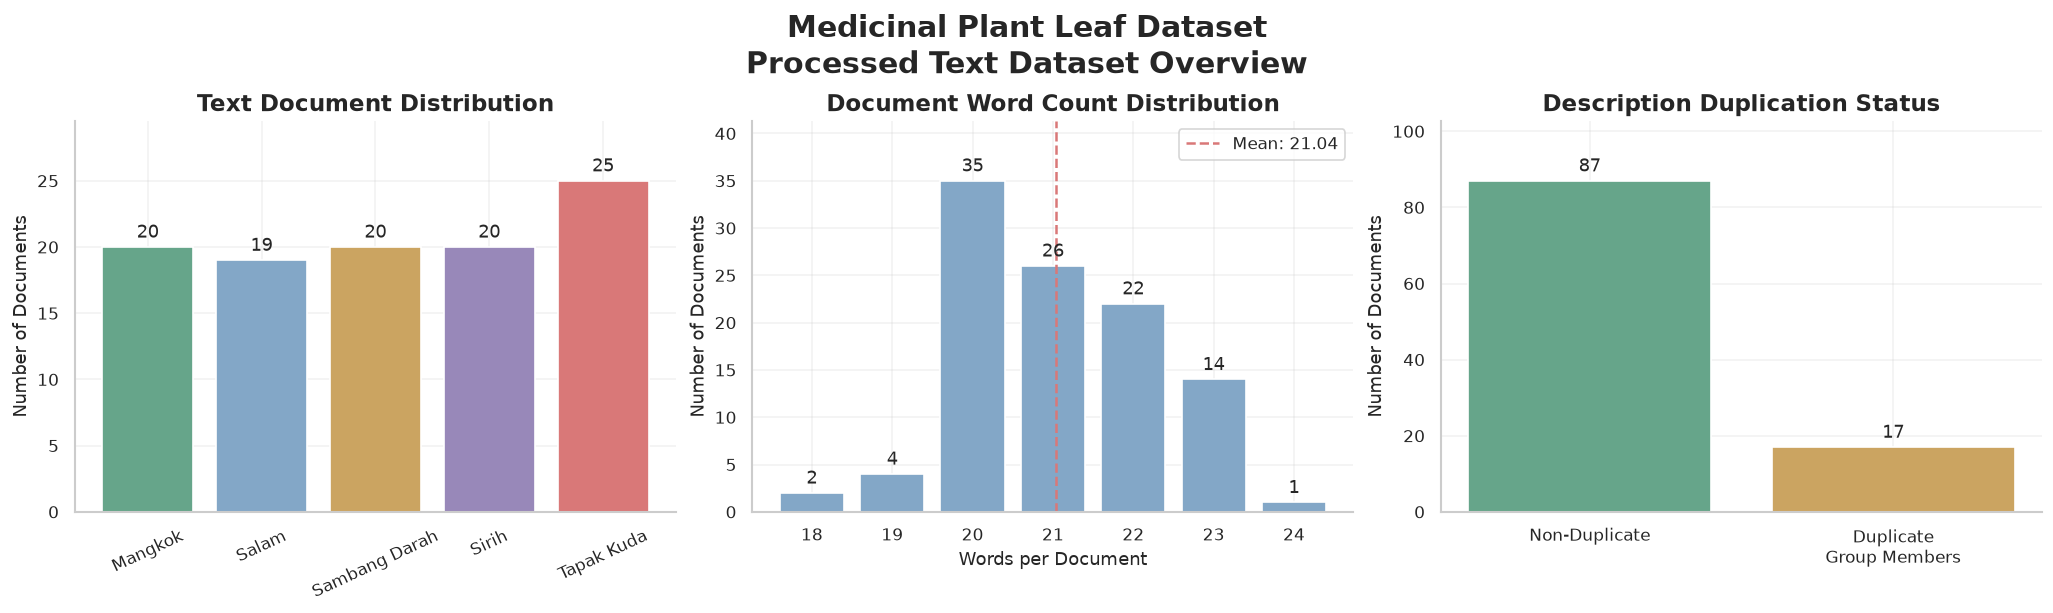


[SAVED] 60_processed_text_dataset_overview.png

13. SAMPLE ALIGNMENT MAPPING
-----------------------------------------------------------------


,sample_id,original_text_row_index,aligned_text_row_index,visual_row_index,kelas,text_quality_status,final_dataset_status,visual_validation_status,aligned
0,leaf_165d2f32c7fda707,0,0,0,Mangkok,Passed Initial Check,Ready - Pending Review,Needs Review,True
1,leaf_8473270c3702f48b,1,1,1,Mangkok,Passed Initial Check,Ready - Initial Checks Passed,Passed Initial Check,True
2,leaf_8f425d66b1e193b9,2,2,2,Mangkok,Passed Initial Check,Ready - Initial Checks Passed,Passed Initial Check,True
3,leaf_0ebc8f4f3ee9c8d5,3,3,3,Mangkok,Passed Initial Check,Ready - Initial Checks Passed,Passed Initial Check,True
4,leaf_b0c5f55e42499cae,4,4,4,Mangkok,Passed Initial Check,Ready - Initial Checks Passed,Passed Initial Check,True
5,leaf_de9e3e4ed5d89dfc,5,5,5,Mangkok,Passed Initial Check,Ready - Initial Checks Passed,Passed Initial Check,True
6,leaf_23b789945271fb92,6,6,6,Mangkok,Passed Initial Check,Ready - Pending Review,Needs Review,True
7,leaf_84de0dc731018607,7,7,7,Mangkok,Passed Initial Check,Ready - Pending Review,Needs Review,True
8,leaf_36d4f083fa652592,8,8,8,Mangkok,Passed Initial Check,Ready - Pending Review,Needs Review,True
9,leaf_c9d8d87fbc748d16,9,9,9,Mangkok,Passed Initial Check,Ready - Pending Review,Needs Review,True



14. TEXT DATASET LOADING SUMMARY
-----------------------------------------------------------------


,Indicator,Result
0,Source file,metadata_processed.csv
1,Source dataset shape,"(104, 44)"
2,Total text samples,104
3,Total classes,5
4,Input text column,cleaned_description
5,Unique sample IDs,104
6,Unique descriptions,95
7,Records in duplicate description groups,17
8,Minimum word count,18
9,Maximum word count,24



15. SAVING DATASET LOADING REPORTS
-----------------------------------------------------------------
[SAVED] 192_text_dataset_schema.csv
[SAVED] 193_required_text_column_validation.csv
[SAVED] 194_visual_input_integrity_validation.csv
[SAVED] 195_initial_text_sample_alignment.csv
[SAVED] 196_shared_image_text_metadata_validation.csv
[SAVED] 197_loaded_text_dataset_status.csv
[SAVED] 198_initial_text_corpus_statistics.csv
[SAVED] 199_loaded_text_class_distribution.csv
[SAVED] 200_text_sample_alignment_mapping.csv
[SAVED] 201_text_dataset_loading_summary.csv

16. FINAL TEXT DATASET LOADING SUMMARY
Source dataset shape : (104, 44)
Total text samples   : 104
Total classes        : 5
Text input column    : cleaned_description
Unique sample IDs    : 104
Unique descriptions  : 95
Duplicate group rows : 17
Minimum words        : 18
Maximum words        : 24
Mean words           : 21.0385

MULTIMODAL ALIGNMENT
-----------------------------------------------------------------
Visual feature sha

In [3]:
# ==================================================
# CELL 4 - LOAD PROCESSED TEXT DATASET
# ==================================================

print("LOAD PROCESSED TEXT DATASET")
print("=" * 65)

TEXT_DATASET_LOADING_COMPLETED = False


# ==================================================
# 1. VALIDATE PREVIOUS CELL
# ==================================================

assert TEXT_LIBRARIES_IMPORTED is True
assert TEXT_PATH_CONFIGURATION_COMPLETED is True

TEXT_INPUT_COLUMN = "cleaned_description"
TEXT_ENCODING = "utf-8-sig"

EXPECTED_TEXT_SAMPLES = 104
EXPECTED_TEXT_CLASSES = 5
EXPECTED_VISUAL_FEATURE_DIM = 143

print("\n[PASS] Previous configurations validated.")


# ==================================================
# 2. LOAD PROCESSED METADATA
# ==================================================

text_loading_start = time.perf_counter()

df_text_source = pd.read_csv(
    PROCESSED_METADATA_PATH,
    encoding=TEXT_ENCODING,
    dtype={"sample_id": str},
    keep_default_na=False
)

text_dataset_loading_time = (
    time.perf_counter() - text_loading_start
)

print("\n1. PROCESSED TEXT DATASET")
print("-" * 65)

print(f"Source file    : {PROCESSED_METADATA_PATH.name}")
print(f"Dataset shape  : {df_text_source.shape}")
print(f"Total records  : {len(df_text_source)}")
print(f"Total columns  : {len(df_text_source.columns)}")

print(
    f"Loading time   : "
    f"{text_dataset_loading_time * 1000:.4f} ms"
)

assert not df_text_source.empty

assert df_text_source.columns.is_unique

assert len(df_text_source) == EXPECTED_TEXT_SAMPLES, (
    "Unexpected number of processed samples."
)

print("[PASS] Processed metadata loaded successfully.")


# ==================================================
# 3. INSPECT DATASET COLUMN STRUCTURE
# ==================================================

text_dataset_schema_df = pd.DataFrame({

    "column_index": np.arange(
        len(df_text_source.columns)
    ),

    "column_name": df_text_source.columns,

    "data_type": [
        str(dtype)
        for dtype in df_text_source.dtypes
    ],

    "non_null_values": (
        df_text_source.notna().sum().to_numpy()
    ),

    "missing_values": (
        df_text_source.isna().sum().to_numpy()
    ),

    "empty_string_values": [

        int(
            df_text_source[column]
            .astype(str)
            .str.strip()
            .eq("")
            .sum()
        )

        for column in df_text_source.columns
    ],

    "unique_values": (
        df_text_source.nunique().to_numpy()
    )
})

print("\n2. DATASET COLUMN STRUCTURE")
print("-" * 65)

display(text_dataset_schema_df)


# ==================================================
# 4. VALIDATE REQUIRED DATASET COLUMNS
# ==================================================

REQUIRED_TEXT_COLUMNS = [

    "sample_id",
    "nama_file",
    "kelas",
    "tampilan_daun",

    "image_path",
    "processed_image_path",
    "mask_path",

    "original_description",
    "cleaned_description",
    "tokenized_description",
    "tokens_json",

    "token_count",
    "unique_token_count",
    "lexical_diversity",
    "duplicate_token_sequence",

    "text_quality_status",
    "text_quality_issues",

    "tokenization_status",
    "tokenization_issues",

    "processed_text_valid",
    "multimodal_valid",

    "final_dataset_status",
    "final_review_notes",

    "image_hash"
]

text_required_column_validation_df = pd.DataFrame([

    {
        "column_name": column,
        "available": column in df_text_source.columns
    }

    for column in REQUIRED_TEXT_COLUMNS
])

missing_text_columns = (

    text_required_column_validation_df.loc[

        ~text_required_column_validation_df[
            "available"
        ],

        "column_name"
    ].tolist()
)

if missing_text_columns:

    raise ValueError(

        "Required text columns are missing:\n"

        + "\n".join(missing_text_columns)
    )

print("\n3. REQUIRED COLUMN VALIDATION")

print(

    f"Available columns: "

    f"{text_required_column_validation_df['available'].sum()}/"

    f"{len(REQUIRED_TEXT_COLUMNS)}"
)

print("[PASS] All required text columns are available.")


# ==================================================
# 5. VALIDATE VISUAL ARTIFACT FILE INTEGRITY
# ==================================================

def calculate_text_input_file_hash(file_path):

    """
    Calculate SHA-256 checksum for an input file.
    """

    sha256 = hashlib.sha256()

    with Path(file_path).open("rb") as file:

        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):

            sha256.update(chunk)

    return sha256.hexdigest()


with VISUAL_MANIFEST_PATH.open(
    "r",
    encoding="utf-8"
) as file:

    visual_input_manifest = json.load(file)


manifest_entries = visual_input_manifest["artifacts"]

manifest_names = [

    entry["filename"]

    for entry in manifest_entries
]

assert len(manifest_names) == len(set(manifest_names))

visual_manifest_lookup = {

    entry["filename"]: entry

    for entry in manifest_entries
}

# Verify the visual artifacts used in this cell.

visual_inputs_to_verify = [

    VISUAL_FEATURE_MATRIX_PATH,

    VISUAL_SAMPLE_IDS_PATH,

    VISUAL_METADATA_PATH,

    VISUAL_FEATURE_CONFIG_PATH
]

visual_input_integrity_records = []

for file_path in visual_inputs_to_verify:

    expected_record = visual_manifest_lookup.get(
        file_path.name
    )

    assert expected_record is not None, (
        f"File not registered in manifest: {file_path.name}"
    )

    actual_checksum = (
        calculate_text_input_file_hash(file_path)
    )

    actual_size = file_path.stat().st_size

    checksum_matches = (

        actual_checksum

        == expected_record["sha256"]
    )

    size_matches = (

        actual_size

        == expected_record["size_bytes"]
    )

    visual_input_integrity_records.append({

        "filename": file_path.name,

        "size_matches": size_matches,

        "checksum_matches": checksum_matches,

        "passed": size_matches and checksum_matches
    })


visual_input_integrity_df = pd.DataFrame(
    visual_input_integrity_records
)

print("\n4. VISUAL INPUT FILE INTEGRITY")
print("-" * 65)

display(visual_input_integrity_df)

assert visual_input_integrity_df["passed"].all(), (
    "Visual artifact integrity validation failed."
)

print("[PASS] Visual input checksums are valid.")


# ==================================================
# 6. LOAD VISUAL FEATURE ARTIFACTS
# ==================================================

loaded_visual_features = np.load(

    VISUAL_FEATURE_MATRIX_PATH,

    allow_pickle=False
)

loaded_visual_sample_ids = np.load(

    VISUAL_SAMPLE_IDS_PATH,

    allow_pickle=False
).astype(str)

df_loaded_visual_metadata = pd.read_csv(

    VISUAL_METADATA_PATH,

    encoding=TEXT_ENCODING,

    dtype={"sample_id": str},

    keep_default_na=False
)

with VISUAL_FEATURE_CONFIG_PATH.open(
    "r",
    encoding="utf-8"
) as file:

    loaded_visual_feature_config = json.load(file)


visual_config_dimension = int(

    loaded_visual_feature_config[
        "feature_matrices"
    ][
        "total_feature_dimension"
    ]
)

assert visual_config_dimension == (
    EXPECTED_VISUAL_FEATURE_DIM
)

assert loaded_visual_features.shape == (

    EXPECTED_TEXT_SAMPLES,

    EXPECTED_VISUAL_FEATURE_DIM
)

assert np.isfinite(loaded_visual_features).all()

assert loaded_visual_sample_ids.ndim == 1

assert len(loaded_visual_sample_ids) == (
    EXPECTED_TEXT_SAMPLES
)

assert len(np.unique(loaded_visual_sample_ids)) == (
    EXPECTED_TEXT_SAMPLES
)

assert len(df_loaded_visual_metadata) == (
    EXPECTED_TEXT_SAMPLES
)

assert np.array_equal(

    df_loaded_visual_metadata[
        "sample_id"
    ].to_numpy(),

    loaded_visual_sample_ids
)

assert np.array_equal(

    df_loaded_visual_metadata[
        "feature_row_index"
    ].to_numpy(),

    np.arange(EXPECTED_TEXT_SAMPLES)
)

print("\n5. LOADED VISUAL FEATURE ARTIFACTS")
print("-" * 65)

print(
    f"Visual feature matrix : "
    f"{loaded_visual_features.shape}"
)

print(
    f"Visual sample IDs     : "
    f"{loaded_visual_sample_ids.shape}"
)

print(
    f"Visual metadata       : "
    f"{df_loaded_visual_metadata.shape}"
)

print(
    f"Visual feature dtype  : "
    f"{loaded_visual_features.dtype}"
)

print("[PASS] Visual artifacts loaded successfully.")


# ==================================================
# 7. INITIAL TEXT SAMPLE ID VALIDATION
# ==================================================

assert df_text_source["sample_id"].notna().all()

assert df_text_source[
    "sample_id"
].str.strip().ne("").all()

assert df_text_source["sample_id"].is_unique

source_text_sample_ids = (

    df_text_source["sample_id"]

    .to_numpy(dtype=str)
)

source_text_id_set = set(source_text_sample_ids)

visual_id_set = set(loaded_visual_sample_ids)

missing_visual_samples = sorted(

    source_text_id_set - visual_id_set
)

missing_text_samples = sorted(

    visual_id_set - source_text_id_set
)

original_sample_order_matches = bool(

    np.array_equal(

        source_text_sample_ids,

        loaded_visual_sample_ids
    )
)

initial_sample_alignment_df = pd.DataFrame([

    {
        "validation_check": "Unique text sample IDs",
        "passed": df_text_source["sample_id"].is_unique
    },

    {
        "validation_check": "Unique visual sample IDs",
        "passed": (
            len(visual_id_set)
            == len(loaded_visual_sample_ids)
        )
    },

    {
        "validation_check": "Equal sample counts",
        "passed": (
            len(source_text_sample_ids)
            == len(loaded_visual_sample_ids)
        )
    },

    {
        "validation_check": "All text IDs exist in visual data",
        "passed": len(missing_visual_samples) == 0
    },

    {
        "validation_check": "All visual IDs exist in text data",
        "passed": len(missing_text_samples) == 0
    }
])

print("\n6. INITIAL SAMPLE ALIGNMENT")
print("-" * 65)

display(initial_sample_alignment_df)

print(
    f"Missing visual samples : "
    f"{len(missing_visual_samples)}"
)

print(
    f"Missing text samples   : "
    f"{len(missing_text_samples)}"
)

print(
    f"Original order matches : "
    f"{original_sample_order_matches}"
)

if not initial_sample_alignment_df["passed"].all():

    raise ValueError(

        "Image-text sample identity mismatch.\n"

        f"Missing visual IDs: {missing_visual_samples}\n"

        f"Missing text IDs: {missing_text_samples}"
    )

print("[PASS] Visual and textual sample identities match.")


# ==================================================
# 8. ALIGN TEXT DATASET TO VISUAL SAMPLE ORDER
# ==================================================

# Preserve the source dataframe.
# Create an aligned copy for textual feature extraction.

df_text_loaded = (

    df_text_source

    .set_index("sample_id", drop=False)

    .loc[loaded_visual_sample_ids]

    .reset_index(drop=True)

    .copy()
)

df_text_loaded["text_row_index"] = np.arange(
    len(df_text_loaded)
)

text_sample_ids = (

    df_text_loaded["sample_id"]

    .to_numpy(dtype=str)
)

assert np.array_equal(

    text_sample_ids,

    loaded_visual_sample_ids
)

assert len(df_text_loaded) == len(df_text_source)

if original_sample_order_matches:

    print("\n[INFO] Original sample order already matches.")

else:

    print("\n[INFO] Text rows reordered using sample IDs.")

print("[PASS] Text dataset aligned with visual feature rows.")


# ==================================================
# 9. VALIDATE SHARED SAMPLE METADATA
# ==================================================

shared_metadata_columns = [

    "sample_id",

    "nama_file",

    "kelas",

    "tampilan_daun",

    "image_hash",

    "processed_image_path",

    "mask_path",

    "cleaned_description"
]

shared_metadata_records = []

for column in shared_metadata_columns:

    if column not in df_loaded_visual_metadata.columns:

        continue

    text_values = (

        df_text_loaded[column]

        .astype(str)

        .to_numpy()
    )

    visual_values = (

        df_loaded_visual_metadata[column]

        .astype(str)

        .to_numpy()
    )

    # Normalize path separators only for path comparison.

    if column in [
        "processed_image_path",
        "mask_path"
    ]:

        text_values = np.char.replace(
            text_values.astype(str),
            "\\",
            "/"
        )

        visual_values = np.char.replace(
            visual_values.astype(str),
            "\\",
            "/"
        )

    matching_values = int(

        np.sum(text_values == visual_values)
    )

    shared_metadata_records.append({

        "column_name": column,

        "matching_records": matching_values,

        "total_records": len(df_text_loaded),

        "passed": (
            matching_values == len(df_text_loaded)
        )
    })


shared_text_visual_metadata_df = pd.DataFrame(
    shared_metadata_records
)

print("\n7. SHARED IMAGE-TEXT METADATA VALIDATION")
print("-" * 65)

display(shared_text_visual_metadata_df)

assert set([

    "sample_id",

    "nama_file",

    "kelas",

    "tampilan_daun"

]).issubset(
    shared_text_visual_metadata_df["column_name"]
)

assert shared_text_visual_metadata_df["passed"].all(), (
    "Shared metadata differs between Notebook 02 and Notebook 03."
)

print("[PASS] Shared sample metadata is consistent.")


# ==================================================
# 10. PRESERVE DATASET QUALITY STATUS
# ==================================================

# Preserve both preprocessing and visual review statuses.
# Do not replace or remove existing review flags.

assert "validation_status" in (
    df_loaded_visual_metadata.columns
)

df_text_loaded["visual_validation_status"] = (

    df_loaded_visual_metadata[
        "validation_status"
    ].to_numpy()
)

# Validate the original preprocessing indicators.

def parse_text_validity_flag(value):

    normalized_value = str(value).strip().lower()

    if normalized_value in ["true", "1", "1.0"]:

        return True

    if normalized_value in ["false", "0", "0.0"]:

        return False

    raise ValueError(
        f"Invalid boolean value: {value}"
    )


processed_text_valid_flags = (

    df_text_loaded["processed_text_valid"]

    .map(parse_text_validity_flag)
)

multimodal_valid_flags = (

    df_text_loaded["multimodal_valid"]

    .map(parse_text_validity_flag)
)

assert processed_text_valid_flags.all()

assert multimodal_valid_flags.all()

text_dataset_status_records = []

for status_column in [

    "text_quality_status",

    "tokenization_status",

    "final_dataset_status",

    "visual_validation_status"
]:

    status_counts = (

        df_text_loaded[status_column]

        .value_counts(dropna=False)
    )

    for status, count in status_counts.items():

        text_dataset_status_records.append({

            "status_category": status_column,

            "status": status,

            "number_of_samples": int(count),

            "percentage": (
                count / len(df_text_loaded) * 100
            )
        })


text_loaded_status_summary_df = pd.DataFrame(
    text_dataset_status_records
)

print("\n8. DATASET QUALITY STATUS")
print("-" * 65)

display(
    text_loaded_status_summary_df.round(2)
)

print("[INFO] All original review flags retained.")

print("[INFO] Manual review samples have not been removed.")


# ==================================================
# 11. PREPARE TEXT CORPUS
# ==================================================

# Only cleaned_description will be used for TF-IDF.
# Class labels and other metadata are excluded.

assert df_text_loaded[TEXT_INPUT_COLUMN].notna().all()

assert df_text_loaded[
    TEXT_INPUT_COLUMN
].str.strip().ne("").all()

text_corpus = (

    df_text_loaded[TEXT_INPUT_COLUMN]

    .tolist()
)

original_text_corpus = (

    df_text_loaded["original_description"]

    .tolist()
)

tokenized_text_corpus = (

    df_text_loaded["tokenized_description"]

    .tolist()
)

text_labels = (

    df_text_loaded["kelas"]

    .to_numpy(dtype=str)
)

text_n_samples = len(text_corpus)

assert text_n_samples == EXPECTED_TEXT_SAMPLES

assert all(

    isinstance(document, str)

    for document in text_corpus
)

assert len(text_sample_ids) == text_n_samples

cleaned_tokenized_matches = int(

    df_text_loaded["cleaned_description"]

    .eq(df_text_loaded["tokenized_description"])

    .sum()
)

print("\n9. TEXT CORPUS PREPARATION")
print("-" * 65)

print(f"Input text column       : {TEXT_INPUT_COLUMN}")

print(f"Total documents         : {text_n_samples}")

print(
    f"Cleaned-tokenized matches: "
    f"{cleaned_tokenized_matches}/{text_n_samples}"
)

print("[PASS] Text corpus prepared successfully.")


# ==================================================
# 12. ANALYZE INITIAL CORPUS CHARACTERISTICS
# ==================================================

# These statistics do not modify the source descriptions.

loaded_text_character_counts = np.asarray([

    len(document)

    for document in text_corpus
])

loaded_text_word_counts = np.asarray([

    len(document.split())

    for document in text_corpus
])

metadata_token_counts = pd.to_numeric(

    df_text_loaded["token_count"],

    errors="raise"
).to_numpy()

text_token_count_matches = bool(

    np.array_equal(

        loaded_text_word_counts,

        metadata_token_counts
    )
)

duplicate_text_mask = (

    df_text_loaded[TEXT_INPUT_COLUMN]

    .duplicated(keep=False)
)

duplicate_description_records = int(
    duplicate_text_mask.sum()
)

unique_description_count = int(

    df_text_loaded[TEXT_INPUT_COLUMN]

    .nunique()
)

initial_text_statistics_df = pd.DataFrame([

    {
        "metric": "Character count",

        "minimum": loaded_text_character_counts.min(),

        "maximum": loaded_text_character_counts.max(),

        "mean": loaded_text_character_counts.mean(),

        "median": np.median(
            loaded_text_character_counts
        ),

        "standard_deviation": (
            loaded_text_character_counts.std(ddof=0)
        )
    },

    {
        "metric": "Word count",

        "minimum": loaded_text_word_counts.min(),

        "maximum": loaded_text_word_counts.max(),

        "mean": loaded_text_word_counts.mean(),

        "median": np.median(
            loaded_text_word_counts
        ),

        "standard_deviation": (
            loaded_text_word_counts.std(ddof=0)
        )
    }
])

print("\n10. INITIAL CORPUS STATISTICS")
print("-" * 65)

display(initial_text_statistics_df.round(4))

print(
    f"Unique descriptions       : "
    f"{unique_description_count}"
)

print(
    f"Records in duplicate groups: "
    f"{duplicate_description_records}"
)

print(
    f"Token count consistency   : "
    f"{text_token_count_matches}"
)

if not text_token_count_matches:

    print(
        "[WARNING] Word counts differ from stored token counts."
    )

    print(
        "[INFO] Detailed token validation will be performed in Cell 5."
    )


# ==================================================
# 13. ANALYZE TEXT DATASET DISTRIBUTION
# ==================================================

text_loaded_class_summary_df = (

    df_text_loaded

    .groupby("kelas", sort=True)

    .agg(

        number_of_samples=("sample_id", "count"),

        unique_descriptions=(
            TEXT_INPUT_COLUMN,
            "nunique"
        ),

        mean_token_count=("token_count", "mean"),

        minimum_token_count=("token_count", "min"),

        maximum_token_count=("token_count", "max")
    )

    .reset_index()
)

text_loaded_class_summary_df["percentage"] = (

    text_loaded_class_summary_df["number_of_samples"]

    / text_n_samples

    * 100
)

assert len(text_loaded_class_summary_df) == (
    EXPECTED_TEXT_CLASSES
)

assert text_loaded_class_summary_df[
    "number_of_samples"
].sum() == text_n_samples

print("\n11. TEXT DATASET CLASS DISTRIBUTION")
print("-" * 65)

display(
    text_loaded_class_summary_df.round(4)
)


# ==================================================
# 14. DISPLAY REPRESENTATIVE TEXT SAMPLES
# ==================================================

# Select the first sample of each class deterministically.

text_representative_samples = (

    df_text_loaded

    .groupby("kelas", sort=True)

    .head(1)

    .reset_index(drop=True)
)

print("\n12. REPRESENTATIVE TEXT SAMPLES")
print("-" * 65)

for _, row in text_representative_samples.iterrows():

    print(f"\nClass       : {row['kelas']}")

    print(f"Sample ID   : {row['sample_id']}")

    print(f"Image       : {row['nama_file']}")

    print(f"View        : {row['tampilan_daun']}")

    print(f"Token count : {row['token_count']}")

    print(f"Text status : {row['text_quality_status']}")

    print("\nOriginal description:")

    print(row["original_description"])

    print("\nCleaned description:")

    print(row[TEXT_INPUT_COLUMN])

    print("-" * 65)


# ==================================================
# 15. VISUALIZE LOADED TEXT DATASET
# ==================================================

fig, axes = plt.subplots(

    1, 3,

    figsize=(17, 5),

    constrained_layout=True
)

class_names = (
    text_loaded_class_summary_df["kelas"]
)

class_plot_colors = [

    CLASS_COLORS.get(class_name, "#83A7C7")

    for class_name in class_names
]


# --------------------------------------------------
# A. Number of text documents per class
# --------------------------------------------------

bars = axes[0].bar(

    class_names,

    text_loaded_class_summary_df[
        "number_of_samples"
    ],

    color=class_plot_colors
)

axes[0].bar_label(bars, padding=3)

axes[0].set_title(
    "Text Document Distribution"
)

axes[0].set_ylabel("Number of Documents")

axes[0].tick_params(
    axis="x",
    labelrotation=25
)

axes[0].margins(y=0.18)


# --------------------------------------------------
# B. Document word-count distribution
# --------------------------------------------------

word_count_frequency = (

    pd.Series(loaded_text_word_counts)

    .value_counts()

    .sort_index()
)

bars = axes[1].bar(

    word_count_frequency.index,

    word_count_frequency.values,

    color="#83A7C7"
)

axes[1].axvline(

    loaded_text_word_counts.mean(),

    color="#D97878",

    linestyle="--",

    label=(
        f"Mean: {loaded_text_word_counts.mean():.2f}"
    )
)

axes[1].bar_label(bars, padding=3)

axes[1].set_xticks(
    word_count_frequency.index
)

axes[1].set_title(
    "Document Word Count Distribution"
)

axes[1].set_xlabel("Words per Document")

axes[1].set_ylabel("Number of Documents")

axes[1].legend()

axes[1].margins(y=0.18)


# --------------------------------------------------
# C. Description duplication status
# --------------------------------------------------

non_duplicate_description_records = (

    text_n_samples

    - duplicate_description_records
)

bars = axes[2].bar(

    [
        "Non-Duplicate",
        "Duplicate\nGroup Members"
    ],

    [
        non_duplicate_description_records,
        duplicate_description_records
    ],

    color=[
        "#66A58A",
        "#CBA461"
    ]
)

axes[2].bar_label(bars, padding=3)

axes[2].set_title(
    "Description Duplication Status"
)

axes[2].set_ylabel("Number of Documents")

axes[2].margins(y=0.18)


# --------------------------------------------------
# Save visualization
# --------------------------------------------------

fig.suptitle(

    "Medicinal Plant Leaf Dataset\n"

    "Processed Text Dataset Overview",

    fontsize=18,

    fontweight="bold"
)

TEXT_DATASET_OVERVIEW_FIGURE = (

    TEXT_FEATURE_FIGURES_DIR

    / "60_processed_text_dataset_overview.png"
)

fig.savefig(

    TEXT_DATASET_OVERVIEW_FIGURE,

    dpi=300,

    bbox_inches="tight"
)

plt.show()

plt.close(fig)

print(
    f"\n[SAVED] {TEXT_DATASET_OVERVIEW_FIGURE.name}"
)


# ==================================================
# 16. CREATE SAMPLE ALIGNMENT MAPPING
# ==================================================

source_row_lookup = pd.Series(

    np.arange(len(df_text_source)),

    index=df_text_source["sample_id"]
)

text_initial_alignment_mapping_df = pd.DataFrame({

    "sample_id": text_sample_ids,

    "original_text_row_index": (

        source_row_lookup

        .loc[text_sample_ids]

        .to_numpy()
    ),

    "aligned_text_row_index": np.arange(
        text_n_samples
    ),

    "visual_row_index": (

        df_loaded_visual_metadata[
            "feature_row_index"
        ].to_numpy()
    ),

    "kelas": text_labels,

    "text_quality_status": (

        df_text_loaded[
            "text_quality_status"
        ].to_numpy()
    ),

    "final_dataset_status": (

        df_text_loaded[
            "final_dataset_status"
        ].to_numpy()
    ),

    "visual_validation_status": (

        df_text_loaded[
            "visual_validation_status"
        ].to_numpy()
    )
})

text_initial_alignment_mapping_df[
    "aligned"
] = (

    text_initial_alignment_mapping_df[
        "aligned_text_row_index"
    ]

    == text_initial_alignment_mapping_df[
        "visual_row_index"
    ]
)

assert text_initial_alignment_mapping_df[
    "aligned"
].all()

print("\n13. SAMPLE ALIGNMENT MAPPING")
print("-" * 65)

display(
    text_initial_alignment_mapping_df.head(10)
)


# ==================================================
# 17. CREATE DATASET LOADING SUMMARY
# ==================================================

text_dataset_loading_summary_df = pd.DataFrame([

    (
        "Source file",
        PROCESSED_METADATA_PATH.name
    ),

    (
        "Source dataset shape",
        str(df_text_source.shape)
    ),

    (
        "Total text samples",
        text_n_samples
    ),

    (
        "Total classes",
        len(text_loaded_class_summary_df)
    ),

    (
        "Input text column",
        TEXT_INPUT_COLUMN
    ),

    (
        "Unique sample IDs",
        len(set(text_sample_ids))
    ),

    (
        "Unique descriptions",
        unique_description_count
    ),

    (
        "Records in duplicate description groups",
        duplicate_description_records
    ),

    (
        "Minimum word count",
        int(loaded_text_word_counts.min())
    ),

    (
        "Maximum word count",
        int(loaded_text_word_counts.max())
    ),

    (
        "Mean word count",
        float(loaded_text_word_counts.mean())
    ),

    (
        "Empty descriptions",
        sum(not text.strip() for text in text_corpus)
    ),

    (
        "Cleaned-tokenized matching descriptions",
        cleaned_tokenized_matches
    ),

    (
        "Token count consistency",
        text_token_count_matches
    ),

    (
        "Text quality initial checks passed",
        int(
            df_text_loaded[
                "text_quality_status"
            ].eq("Passed Initial Check").sum()
        )
    ),

    (
        "Text quality samples requiring review",
        int(
            df_text_loaded[
                "text_quality_status"
            ].eq("Needs Review").sum()
        )
    ),

    (
        "Valid processed text samples",
        int(processed_text_valid_flags.sum())
    ),

    (
        "Valid multimodal samples",
        int(multimodal_valid_flags.sum())
    ),

    (
        "Visual feature matrix shape",
        str(loaded_visual_features.shape)
    ),

    (
        "Visual integrity checks passed",
        int(
            visual_input_integrity_df[
                "passed"
            ].sum()
        )
    ),

    (
        "Original sample order matches",
        original_sample_order_matches
    ),

    (
        "Final initial sample alignment",
        bool(
            np.array_equal(
                text_sample_ids,
                loaded_visual_sample_ids
            )
        )
    ),

    (
        "Aligned samples",
        int(
            text_initial_alignment_mapping_df[
                "aligned"
            ].sum()
        )
    ),

    (
        "Missing visual samples",
        len(missing_visual_samples)
    ),

    (
        "Missing text samples",
        len(missing_text_samples)
    ),

    (
        "Samples removed",
        0
    ),

    (
        "Descriptions modified",
        0
    ),

    (
        "Class labels included in corpus",
        False
    ),

    (
        "TF-IDF fitted",
        False
    ),

    (
        "Text dataset loading completed",
        True
    )

], columns=["Indicator", "Result"])

print("\n14. TEXT DATASET LOADING SUMMARY")
print("-" * 65)

display(text_dataset_loading_summary_df)


# ==================================================
# 18. SAVE DATASET LOADING REPORTS
# ==================================================

text_loading_reports = {

    "192_text_dataset_schema.csv":
        text_dataset_schema_df,

    "193_required_text_column_validation.csv":
        text_required_column_validation_df,

    "194_visual_input_integrity_validation.csv":
        visual_input_integrity_df,

    "195_initial_text_sample_alignment.csv":
        initial_sample_alignment_df,

    "196_shared_image_text_metadata_validation.csv":
        shared_text_visual_metadata_df,

    "197_loaded_text_dataset_status.csv":
        text_loaded_status_summary_df,

    "198_initial_text_corpus_statistics.csv":
        initial_text_statistics_df,

    "199_loaded_text_class_distribution.csv":
        text_loaded_class_summary_df,

    "200_text_sample_alignment_mapping.csv":
        text_initial_alignment_mapping_df,

    "201_text_dataset_loading_summary.csv":
        text_dataset_loading_summary_df
}

print("\n15. SAVING DATASET LOADING REPORTS")
print("-" * 65)

for filename, dataframe in text_loading_reports.items():

    dataframe.to_csv(

        METRICS_DIR / filename,

        index=False,

        encoding="utf-8-sig",

        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ==================================================
# 19. FINAL DATASET LOADING VALIDATION
# ==================================================

assert len(df_text_loaded) == EXPECTED_TEXT_SAMPLES

assert text_n_samples == len(text_sample_ids)

assert len(text_corpus) == len(text_labels)

assert len(text_corpus) == len(loaded_visual_features)

assert df_text_loaded["sample_id"].is_unique

assert np.array_equal(

    text_sample_ids,

    loaded_visual_sample_ids
)

assert initial_sample_alignment_df["passed"].all()

assert shared_text_visual_metadata_df["passed"].all()

assert visual_input_integrity_df["passed"].all()

assert text_initial_alignment_mapping_df[
    "aligned"
].all()

# Confirm the corpus was not modified during loading.

assert text_corpus == (

    df_text_source

    .set_index("sample_id")

    .loc[text_sample_ids, TEXT_INPUT_COLUMN]

    .tolist()
)

assert TEXT_DATASET_OVERVIEW_FIGURE.is_file()

assert TEXT_DATASET_OVERVIEW_FIGURE.stat().st_size > 0

assert all(

    (METRICS_DIR / filename).is_file()

    and (METRICS_DIR / filename).stat().st_size > 0

    for filename in text_loading_reports
)

TEXT_DATASET_LOADING_COMPLETED = True


# ==================================================
# 20. FINAL LOADING SUMMARY
# ==================================================

print("\n16. FINAL TEXT DATASET LOADING SUMMARY")
print("=" * 65)

print(f"Source dataset shape : {df_text_source.shape}")

print(f"Total text samples   : {text_n_samples}")

print(
    f"Total classes        : "
    f"{len(text_loaded_class_summary_df)}"
)

print(f"Text input column    : {TEXT_INPUT_COLUMN}")

print(f"Unique sample IDs    : {len(set(text_sample_ids))}")

print(f"Unique descriptions  : {unique_description_count}")

print(f"Duplicate group rows : {duplicate_description_records}")

print(
    f"Minimum words        : "
    f"{loaded_text_word_counts.min()}"
)

print(
    f"Maximum words        : "
    f"{loaded_text_word_counts.max()}"
)

print(
    f"Mean words           : "
    f"{loaded_text_word_counts.mean():.4f}"
)

print("\nMULTIMODAL ALIGNMENT")
print("-" * 65)

print(f"Visual feature shape : {loaded_visual_features.shape}")

print(f"Text corpus size     : {len(text_corpus)}")

print(
    f"Aligned samples      : "
    f"{text_initial_alignment_mapping_df['aligned'].sum()}/"
    f"{text_n_samples}"
)

print(
    f"Visual integrity     : "
    f"{visual_input_integrity_df['passed'].sum()}/"
    f"{len(visual_input_integrity_df)}"
)

print("\nOUTPUT SUMMARY")
print("-" * 65)

print(f"Generated reports    : {len(text_loading_reports)}")

print("Generated figures    : 1")

print("\n[PASS] Processed text dataset loaded.")

print("[PASS] Required metadata columns validated.")

print("[PASS] Visual input file integrity verified.")

print("[PASS] Visual feature artifacts loaded.")

print("[PASS] Text and visual sample identities match.")

print("[PASS] Shared sample metadata validated.")

print("[PASS] Text corpus prepared.")

print("[PASS] Initial sample alignment completed.")

print("[PASS] All loading reports saved.")

print("\n[INFO] Original text descriptions remain unchanged.")

print("[INFO] Duplicate descriptions are retained.")

print("[INFO] Manual dataset review flags are retained.")

print("[INFO] Detailed text validation will follow.")

print("[INFO] TF-IDF has not been fitted.")

print("\nProcessed text dataset loaded successfully!")

print("\nNext cell: Cell 5 - Text Dataset Validation")

TEXT DATASET VALIDATION

[PASS] Previous processing stages validated.

1. TEXT VALIDATION CONFIGURATION
-----------------------------------------------------------------
Validation method : Rule-Based Text Validation
Token pattern     : (?u)\b\w\w+\b
Near duplicate threshold : 0.85
Lexical diversity threshold : 0.7
[INFO] Text descriptions will not be modified.

2. INDIVIDUAL TEXT DOCUMENT VALIDATION
-----------------------------------------------------------------


Validating text documents:   0%|          | 0/104 [00:00<?, ?it/s]


Individual validation completed.
Validation time : 0.0234 seconds


,sample_id,nama_file,kelas,character_count,token_count,unique_token_count,lexical_diversity,non_empty,original_description_non_empty,lowercase_valid,whitespace_valid,character_valid,has_tokens,stored_tokens_valid,token_sequence_matches,tokenized_description_matches,token_count_matches,unique_token_count_matches,lexical_diversity_matches,class_label_leakage,detected_class_aliases,low_lexical_diversity,existing_text_review,technical_valid,technical_issues,review_issues
0,leaf_165d2f32c7fda707,mangkok 10.jpeg,Mangkok,146,20,17,0.850000,True,True,True,True,True,True,True,True,True,True,True,True,False,,False,False,True,,
1,leaf_8473270c3702f48b,mangkok 11.png,Mangkok,176,23,21,0.913043,True,True,True,True,True,True,True,True,True,True,True,True,False,,False,False,True,,
2,leaf_8f425d66b1e193b9,mangkok 12.png,Mangkok,154,21,18,0.857143,True,True,True,True,True,True,True,True,True,True,True,True,False,,False,False,True,,
3,leaf_0ebc8f4f3ee9c8d5,mangkok 13.png,Mangkok,155,21,19,0.904762,True,True,True,True,True,True,True,True,True,True,True,True,False,,False,False,True,,
4,leaf_b0c5f55e42499cae,mangkok 14.png,Mangkok,167,22,20,0.909091,True,True,True,True,True,True,True,True,True,True,True,True,False,,False,False,True,,
5,leaf_de9e3e4ed5d89dfc,mangkok 15.png,Mangkok,159,22,19,0.863636,True,True,True,True,True,True,True,True,True,True,True,True,False,,False,False,True,,
6,leaf_23b789945271fb92,mangkok 6.jpeg,Mangkok,163,22,21,0.954545,True,True,True,True,True,True,True,True,True,True,True,True,False,,False,False,True,,
7,leaf_84de0dc731018607,mangkok 7.jpeg,Mangkok,155,21,19,0.904762,True,True,True,True,True,True,True,True,True,True,True,True,False,,False,False,True,,
8,leaf_36d4f083fa652592,mangkok 8.jpeg,Mangkok,174,23,22,0.956522,True,True,True,True,True,True,True,True,True,True,True,True,False,,False,False,True,,
9,leaf_c9d8d87fbc748d16,mangkok 9.jpeg,Mangkok,144,20,18,0.900000,True,True,True,True,True,True,True,True,True,True,True,True,False,,False,False,True,,



3. CLASS-LABEL LEAKAGE ANALYSIS
-----------------------------------------------------------------
Documents containing class names or aliases: 0
[PASS] No configured class aliases detected.

4. EXACT DUPLICATE DESCRIPTION ANALYSIS
-----------------------------------------------------------------
Exact duplicate groups : 8
Documents in duplicate groups : 17
Cross-class duplicate groups : 0
Stored duplicate flags consistent : True


,duplicate_group_id,number_of_documents,number_of_classes,classes,cross_class_duplicate,description
0,duplicate_group_001,2,1,Mangkok,False,daun berwarna hijau tua berbentuk membulat lebar dengan tepi bergelombang halus dan ujung membulat permukaan tampak ...
1,duplicate_group_002,2,1,Sirih,False,daun berwarna hijau tua berbentuk bulat telur memanjang terlipat dengan tepi rata dan ujung meruncing permukaan tamp...
2,duplicate_group_003,2,1,Tapak Kuda,False,daun berwarna hijau tua berbentuk menyerupai ginjal dengan tepi daun tidak terlihat jelas dan ujung membulat permuka...
3,duplicate_group_004,2,1,Tapak Kuda,False,daun berwarna hijau kekuningan berbentuk menyerupai ginjal dengan tepi berlekuk membulat dan ujung membulat permukaa...
4,duplicate_group_005,2,1,Tapak Kuda,False,daun berwarna hijau tua berbentuk menyerupai ginjal dengan tepi berlekuk membulat dan ujung membulat permukaan tampa...
5,duplicate_group_006,2,1,Tapak Kuda,False,daun berwarna hijau tua berbentuk menyerupai ginjal dengan tepi bergelombang halus dan ujung membulat permukaan tamp...
6,duplicate_group_007,3,1,Tapak Kuda,False,daun berwarna hijau sedang berbentuk menyerupai ginjal dengan tepi berlekuk membulat dan ujung membulat permukaan ta...
7,duplicate_group_008,2,1,Tapak Kuda,False,daun berwarna hijau tua berbentuk menyerupai ginjal dengan tepi berlekuk membulat dan ujung membulat permukaan tampa...


... (10 outputs left out)


10. TEXT VALIDATION STATUS
-----------------------------------------------------------------


,validation_status,number_of_documents,percentage
0,Passed Initial Check,87,83.6538
1,Needs Review,17,16.3462
2,Failed,0,0.0000



11. TECHNICAL VALIDATION CHECKLIST
-----------------------------------------------------------------


,validation_check,passed,status
0,Unique sample identifiers,True,Passed
1,Nonempty cleaned descriptions,True,Passed
2,Nonempty original descriptions,True,Passed
3,Lowercase text consistency,True,Passed
4,Whitespace consistency,True,Passed
5,Character validity,True,Passed
6,Nonempty token sequences,True,Passed
7,Stored JSON tokens valid,True,Passed
8,Token sequence consistency,True,Passed
9,Tokenized description consistency,True,Passed


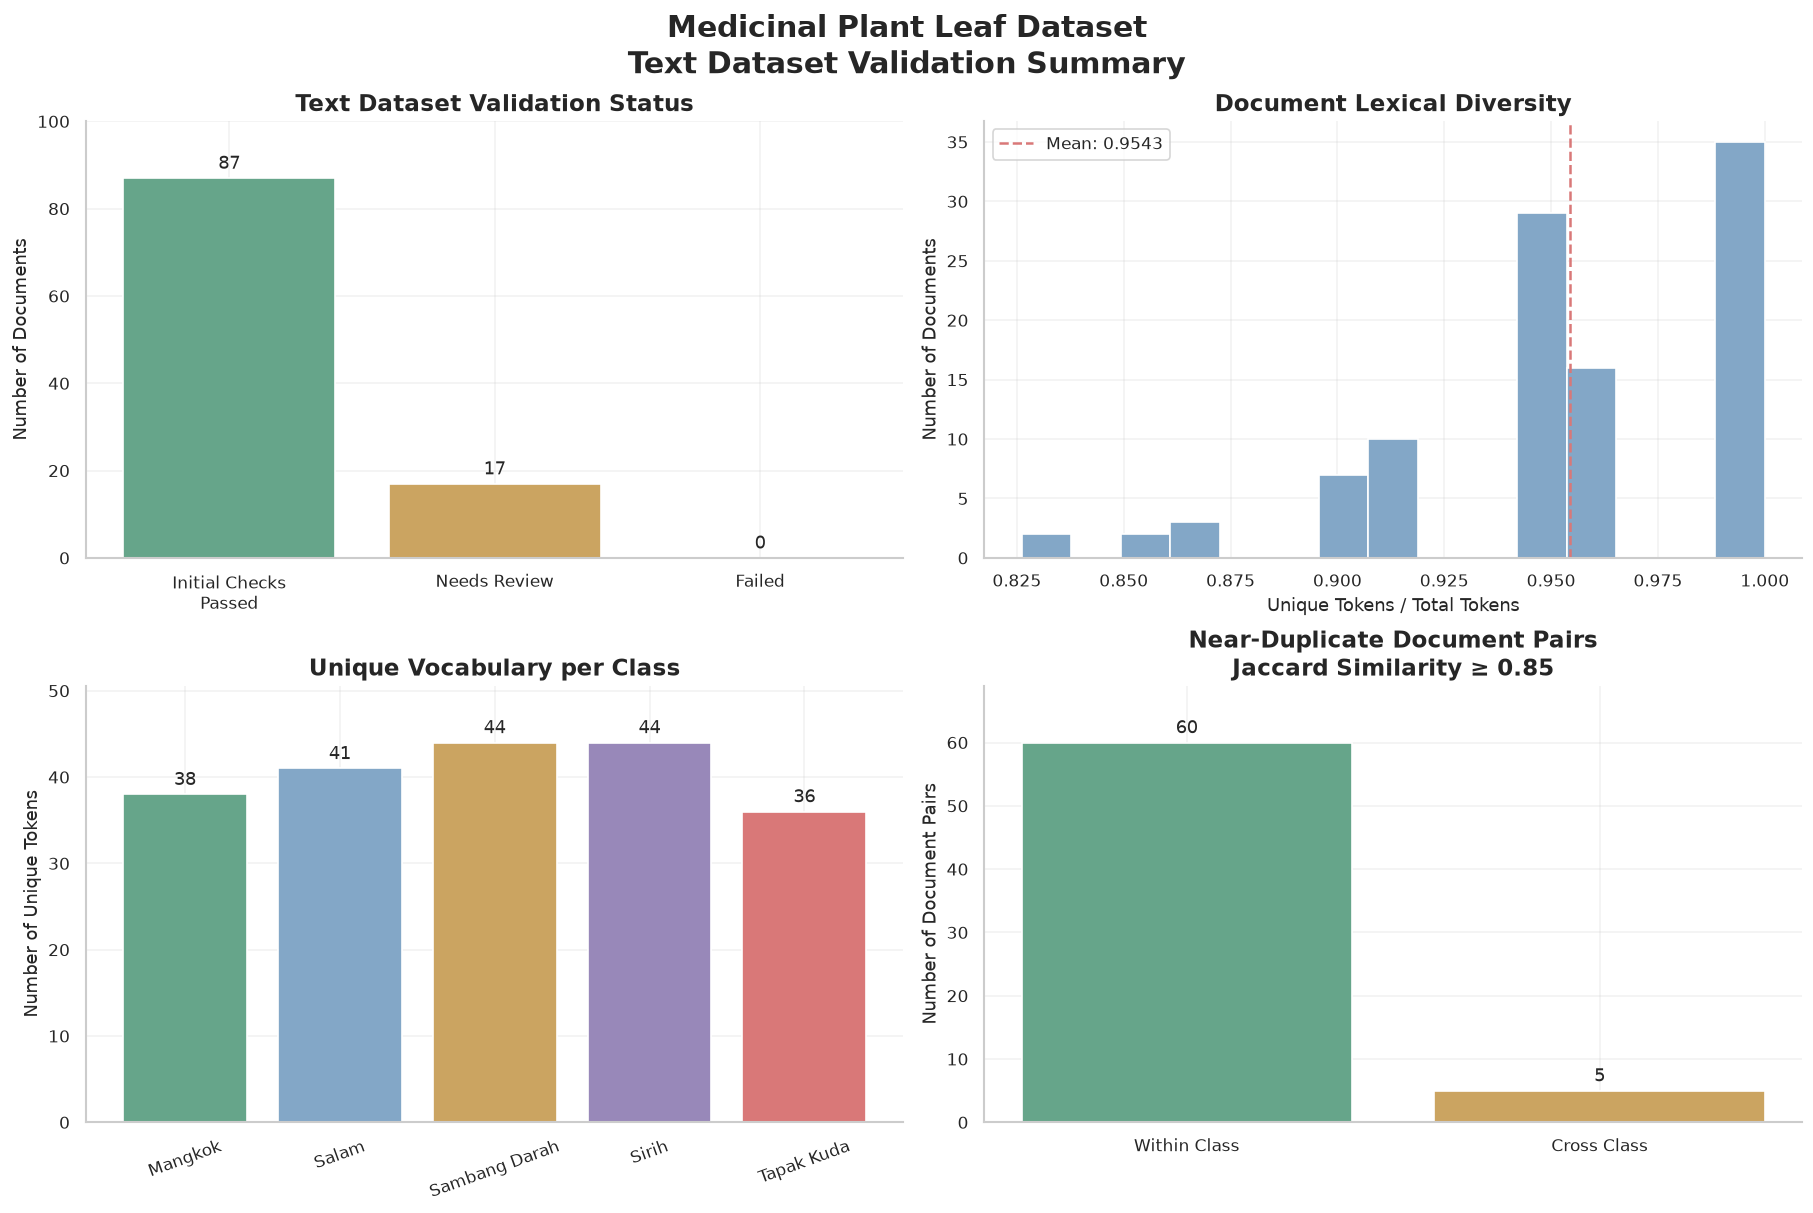

[SAVED] 61_text_dataset_validation_summary.png


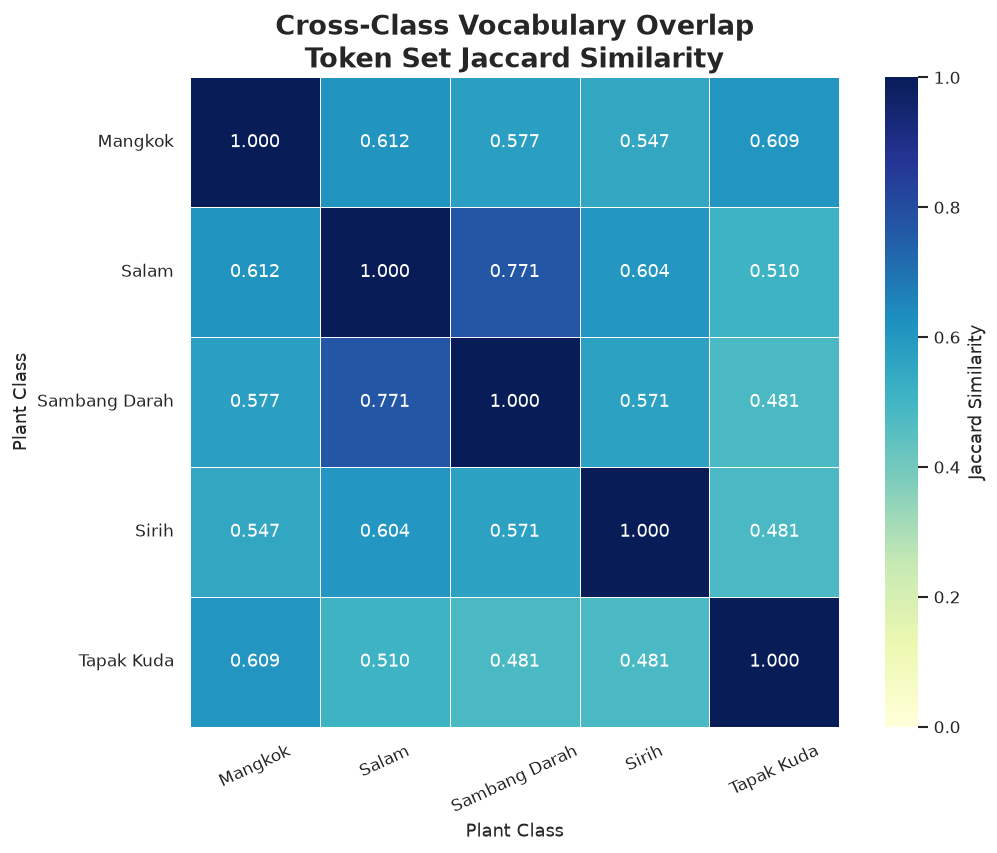

[SAVED] 62_cross_class_vocabulary_overlap.png


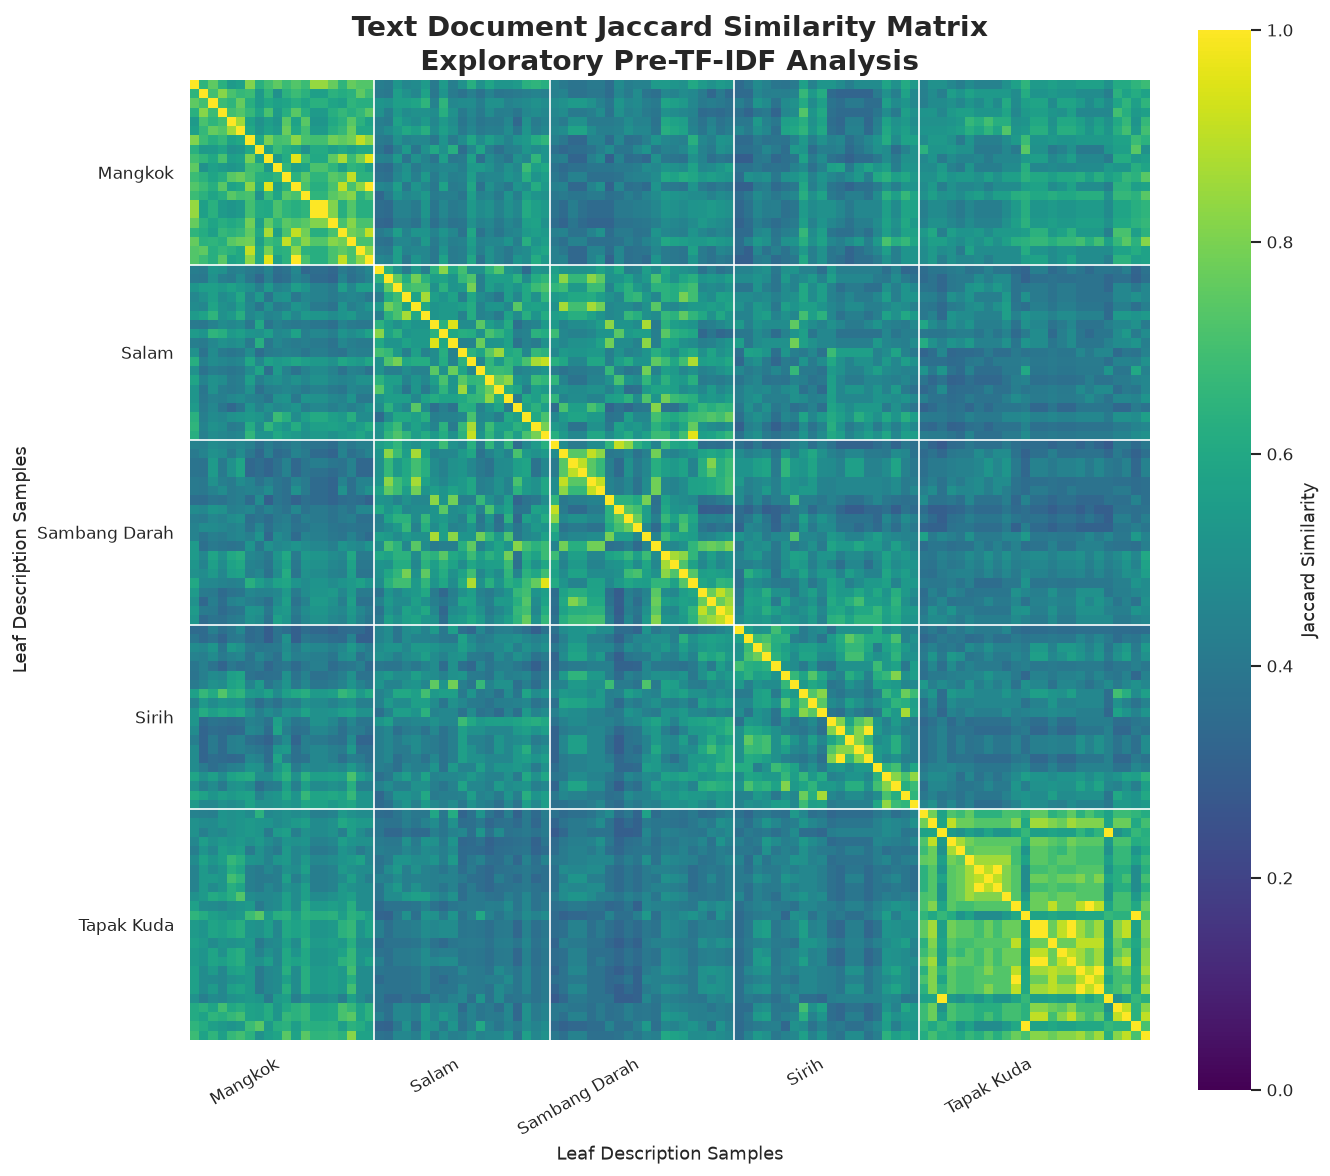

[SAVED] 63_text_document_jaccard_similarity.png


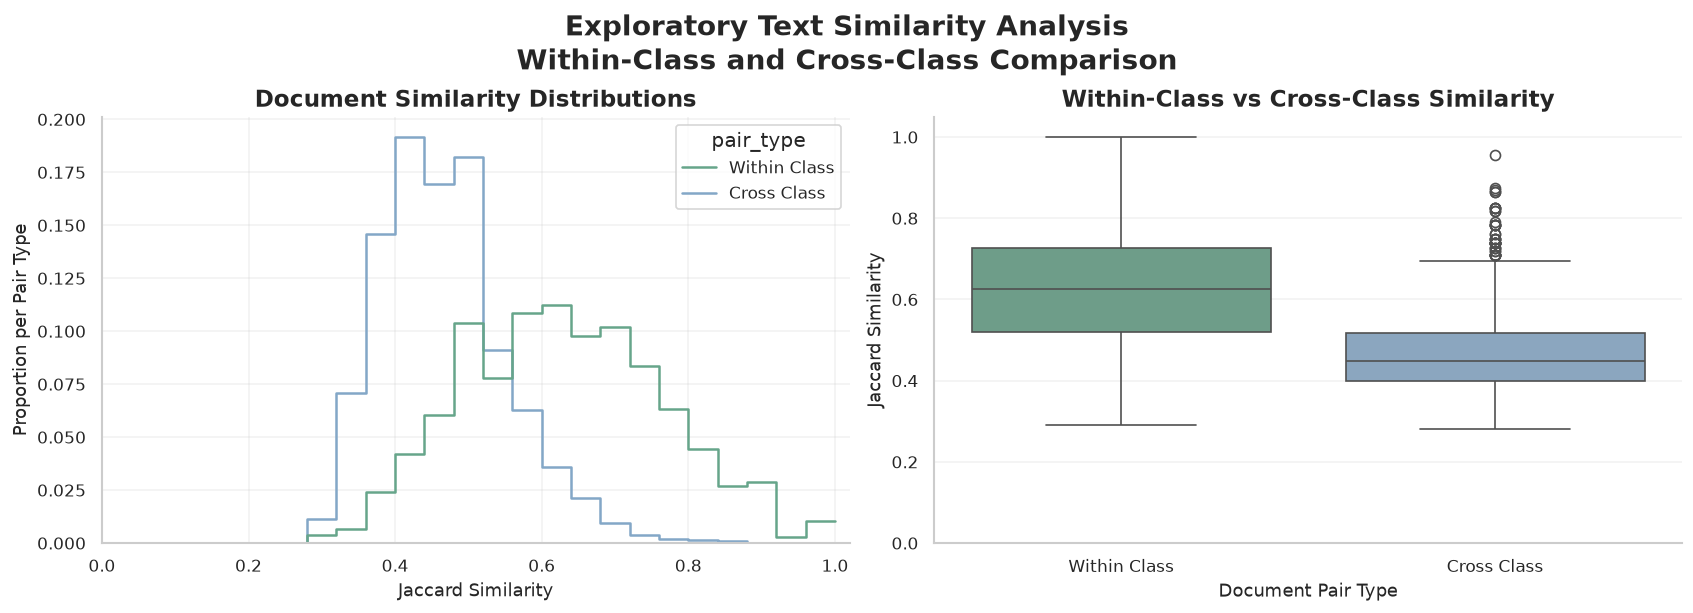

[SAVED] 64_within_cross_class_text_similarity.png

12. VALIDATED CORPUS PREPARATION
-----------------------------------------------------------------
Technically valid documents : 104
Failed documents : 0
Initial checks passed : 87
Text review documents : 17
Pending multimodal review : 70

13. OVERALL TEXT DATASET VALIDATION SUMMARY
-----------------------------------------------------------------


,Indicator,Result
0,Total documents,104
1,Total classes,5
2,Technically valid documents,104
3,Technically failed documents,0
4,Initial checks passed,87
5,Text documents requiring review,17
6,Pending multimodal review,70
7,Empty descriptions,0
8,Invalid character documents,0
9,Token sequence mismatches,0



14. SAVING VALIDATION REPORTS
-----------------------------------------------------------------
[SAVED] 202_individual_text_validation.csv
[SAVED] 203_class_label_leakage_analysis.csv
[SAVED] 204_exact_duplicate_text_groups.csv
[SAVED] 205_exact_duplicate_text_documents.csv
[SAVED] 206_near_duplicate_text_pairs.csv
[SAVED] 207_text_pairwise_jaccard_similarity.csv
[SAVED] 208_lexical_diversity_summary.csv
[SAVED] 209_class_lexical_diversity.csv
[SAVED] 210_cross_class_vocabulary_overlap.csv
[SAVED] 211_text_similarity_group_summary.csv
[SAVED] 212_text_validation_status_summary.csv
[SAVED] 213_text_dataset_validation_checks.csv
[SAVED] 214_text_dataset_validation_summary.csv

FINAL TEXT DATASET VALIDATION SUMMARY

DATASET VALIDATION
-----------------------------------------------------------------
Total documents       : 104
Total classes         : 5
Technically valid     : 104
Technically failed    : 0
Initial checks passed : 87
Needs review          : 17

DUPLICATE ANALYSIS
---------

In [4]:
# ==================================================
# CELL 5 - TEXT DATASET VALIDATION
# ==================================================

from itertools import combinations

print("TEXT DATASET VALIDATION")
print("=" * 65)

TEXT_DATASET_VALIDATION_COMPLETED = False


# ==================================================
# 1. VALIDATE PREVIOUS CELL
# ==================================================

assert TEXT_LIBRARIES_IMPORTED is True
assert TEXT_PATH_CONFIGURATION_COMPLETED is True
assert TEXT_DATASET_LOADING_COMPLETED is True

assert len(df_text_loaded) == text_n_samples

assert len(text_corpus) == text_n_samples

assert np.array_equal(
    text_sample_ids,
    loaded_visual_sample_ids
)

print("\n[PASS] Previous processing stages validated.")


# ==================================================
# 2. TEXT VALIDATION CONFIGURATION
# ==================================================

TEXT_TOKEN_PATTERN = r"(?u)\b\w\w+\b"

TEXT_TOKEN_REGEX = re.compile(
    TEXT_TOKEN_PATTERN
)

TEXT_CHARACTER_PATTERN = (
    r"[^\W\d_]+(?: [^\W\d_]+)*"
)

TEXT_VALIDATION_TOLERANCE = 1e-8

NEAR_DUPLICATE_THRESHOLD = 0.85

LEXICAL_DIVERSITY_REVIEW_THRESHOLD = 0.70

TEXT_VALIDATION_METHOD = (
    "Rule-Based Text Validation"
)

NEAR_DUPLICATE_METHOD = (
    "Token Set Jaccard Similarity"
)


# Class names and initial alias candidates.
# Used for validation only, not text modification.

TEXT_CLASS_ALIASES = {

    "Mangkok": [
        "mangkok",
        "mangkuk"
    ],

    "Salam": [
        "salam"
    ],

    "Sambang Darah": [
        "sambang darah",
        "sambangdarah",
        "sambang"
    ],

    "Sirih": [
        "sirih"
    ],

    "Tapak Kuda": [
        "tapak kuda",
        "tapakkuda"
    ]
}

# Compile whole-word patterns to prevent
# accidental substring matching.

class_alias_patterns = {}

for class_name, aliases in TEXT_CLASS_ALIASES.items():

    class_alias_patterns[class_name] = [

        (
            alias,
            re.compile(
                r"(?<!\w)"
                + re.escape(alias)
                + r"(?!\w)",
                flags=re.IGNORECASE
            )
        )

        for alias in aliases
    ]

print("\n1. TEXT VALIDATION CONFIGURATION")
print("-" * 65)

print(f"Validation method : {TEXT_VALIDATION_METHOD}")

print(f"Token pattern     : {TEXT_TOKEN_PATTERN}")

print(
    f"Near duplicate threshold : "
    f"{NEAR_DUPLICATE_THRESHOLD}"
)

print(
    f"Lexical diversity threshold : "
    f"{LEXICAL_DIVERSITY_REVIEW_THRESHOLD}"
)

print("[INFO] Text descriptions will not be modified.")


# ==================================================
# 3. CREATE VALIDATION DATAFRAME
# ==================================================

df_text_validated = (
    df_text_loaded.copy()
    .reset_index(drop=True)
)

original_corpus_snapshot = list(text_corpus)

assert df_text_validated["sample_id"].is_unique

assert np.array_equal(
    df_text_validated["sample_id"].to_numpy(dtype=str),
    text_sample_ids
)

text_validation_records = []

validated_token_lists = []

class_leakage_records = []


# ==================================================
# 4. VALIDATE INDIVIDUAL TEXT DOCUMENTS
# ==================================================

print("\n2. INDIVIDUAL TEXT DOCUMENT VALIDATION")
print("-" * 65)

validation_start = time.perf_counter()

for _, row in tqdm(

    df_text_validated.iterrows(),

    total=len(df_text_validated),

    desc="Validating text documents"
):

    sample_id = row["sample_id"]

    class_name = row["kelas"]

    document = row[TEXT_INPUT_COLUMN]

    validation_issues = []

    review_issues = []


    # --------------------------------------------------
    # A. Text completeness
    # --------------------------------------------------

    text_is_string = isinstance(
        document,
        str
    )

    non_empty = (
        text_is_string
        and bool(document.strip())
    )

    original_description_non_empty = (

        isinstance(row["original_description"], str)

        and bool(row["original_description"].strip())
    )

    if not non_empty:

        validation_issues.append(
            "Empty or invalid description"
        )

    if not original_description_non_empty:

        validation_issues.append(
            "Missing original description"
        )

    safe_document = (
        document if text_is_string else ""
    )


    # --------------------------------------------------
    # B. Character validation
    # --------------------------------------------------

    lowercase_valid = (

        safe_document
        == safe_document.lower()
    )

    whitespace_valid = (

        safe_document
        == " ".join(safe_document.split())
    )

    character_valid = bool(

        re.fullmatch(

            TEXT_CHARACTER_PATTERN,

            safe_document
        )
    )

    if not lowercase_valid:

        validation_issues.append(
            "Uppercase characters detected"
        )

    if not whitespace_valid:

        validation_issues.append(
            "Invalid whitespace"
        )

    if not character_valid:

        validation_issues.append(
            "Unexpected characters detected"
        )


    # --------------------------------------------------
    # C. Reconstruct tokens using the same
    #    token pattern planned for TF-IDF
    # --------------------------------------------------

    reconstructed_tokens = (
        TEXT_TOKEN_REGEX.findall(
            safe_document
        )
    )

    validated_token_lists.append(
        reconstructed_tokens
    )

    reconstructed_token_count = len(
        reconstructed_tokens
    )

    reconstructed_unique_token_count = len(
        set(reconstructed_tokens)
    )

    reconstructed_lexical_diversity = (

        reconstructed_unique_token_count
        / reconstructed_token_count

        if reconstructed_token_count > 0

        else 0.0
    )

    has_tokens = reconstructed_token_count > 0

    if not has_tokens:

        validation_issues.append(
            "No valid tokens"
        )


    # --------------------------------------------------
    # D. Validate stored tokens_json
    # --------------------------------------------------

    try:

        stored_tokens = json.loads(
            row["tokens_json"]
        )

        stored_tokens_valid = (

            isinstance(stored_tokens, list)

            and all(
                isinstance(token, str)
                for token in stored_tokens
            )
        )

    except (
        json.JSONDecodeError,
        TypeError,
        ValueError
    ):

        stored_tokens = []

        stored_tokens_valid = False

    token_sequence_matches = (

        stored_tokens_valid

        and reconstructed_tokens == stored_tokens
    )

    tokenized_description_matches = (

        " ".join(reconstructed_tokens)

        == row["tokenized_description"]
    )

    if not token_sequence_matches:

        validation_issues.append(
            "Stored token sequence mismatch"
        )

    if not tokenized_description_matches:

        validation_issues.append(
            "Tokenized description mismatch"
        )


    # --------------------------------------------------
    # E. Validate stored numerical token metadata
    # --------------------------------------------------

    stored_token_count = pd.to_numeric(
        row["token_count"],
        errors="coerce"
    )

    stored_unique_token_count = pd.to_numeric(
        row["unique_token_count"],
        errors="coerce"
    )

    stored_lexical_diversity = pd.to_numeric(
        row["lexical_diversity"],
        errors="coerce"
    )

    token_count_matches = bool(

        pd.notna(stored_token_count)

        and reconstructed_token_count
        == stored_token_count
    )

    unique_token_count_matches = bool(

        pd.notna(stored_unique_token_count)

        and reconstructed_unique_token_count
        == stored_unique_token_count
    )

    lexical_diversity_matches = bool(

        pd.notna(stored_lexical_diversity)

        and np.isclose(

            reconstructed_lexical_diversity,

            stored_lexical_diversity,

            atol=TEXT_VALIDATION_TOLERANCE,

            rtol=0
        )
    )

    if not token_count_matches:

        validation_issues.append(
            "Token count mismatch"
        )

    if not unique_token_count_matches:

        validation_issues.append(
            "Unique token count mismatch"
        )

    if not lexical_diversity_matches:

        validation_issues.append(
            "Lexical diversity mismatch"
        )


    # --------------------------------------------------
    # F. Detect possible class-label leakage
    # --------------------------------------------------

    detected_aliases = []

    for alias_class, patterns in (
        class_alias_patterns.items()
    ):

        for alias, pattern in patterns:

            if pattern.search(safe_document):

                detected_aliases.append(alias)

                class_leakage_records.append({

                    "sample_id": sample_id,

                    "kelas": class_name,

                    "detected_alias": alias,

                    "alias_class": alias_class,

                    "same_class": (
                        alias_class == class_name
                    ),

                    "description": safe_document
                })

    detected_aliases = sorted(
        set(detected_aliases)
    )

    class_label_leakage = (
        len(detected_aliases) > 0
    )

    if class_label_leakage:

        validation_issues.append(
            "Possible class-label leakage"
        )


    # --------------------------------------------------
    # G. Lexical diversity diagnostic
    # --------------------------------------------------

    low_lexical_diversity = (

        reconstructed_lexical_diversity
        < LEXICAL_DIVERSITY_REVIEW_THRESHOLD
    )

    if low_lexical_diversity:

        review_issues.append(
            "Low lexical diversity"
        )


    # --------------------------------------------------
    # H. Preserve existing text review status
    # --------------------------------------------------

    existing_text_review = (

        row["text_quality_status"]
        == "Needs Review"

        or row["tokenization_status"]
        == "Needs Review"
    )

    if existing_text_review:

        review_issues.append(
            "Existing text review flag"
        )


    # --------------------------------------------------
    # I. Record technical validation results
    # --------------------------------------------------

    technical_valid = (
        len(validation_issues) == 0
    )

    text_validation_records.append({

        "sample_id": sample_id,

        "nama_file": row["nama_file"],

        "kelas": class_name,

        "character_count": len(safe_document),

        "token_count": reconstructed_token_count,

        "unique_token_count": (
            reconstructed_unique_token_count
        ),

        "lexical_diversity": (
            reconstructed_lexical_diversity
        ),

        "non_empty": non_empty,

        "original_description_non_empty": (
            original_description_non_empty
        ),

        "lowercase_valid": lowercase_valid,

        "whitespace_valid": whitespace_valid,

        "character_valid": character_valid,

        "has_tokens": has_tokens,

        "stored_tokens_valid": stored_tokens_valid,

        "token_sequence_matches": (
            token_sequence_matches
        ),

        "tokenized_description_matches": (
            tokenized_description_matches
        ),

        "token_count_matches": token_count_matches,

        "unique_token_count_matches": (
            unique_token_count_matches
        ),

        "lexical_diversity_matches": (
            lexical_diversity_matches
        ),

        "class_label_leakage": class_label_leakage,

        "detected_class_aliases": (
            "; ".join(detected_aliases)
        ),

        "low_lexical_diversity": (
            low_lexical_diversity
        ),

        "existing_text_review": existing_text_review,

        "technical_valid": technical_valid,

        "technical_issues": (
            "; ".join(validation_issues)
        ),

        "review_issues": (
            "; ".join(review_issues)
        )
    })


text_validation_time_seconds = (

    time.perf_counter()
    - validation_start
)

text_document_validation_df = pd.DataFrame(
    text_validation_records
)

assert len(text_document_validation_df) == (
    text_n_samples
)

print("\nIndividual validation completed.")

print(

    f"Validation time : "

    f"{text_validation_time_seconds:.4f} seconds"
)

display(
    text_document_validation_df.head(10)
)


# ==================================================
# 5. CLASS-LABEL LEAKAGE ANALYSIS
# ==================================================

class_label_leakage_df = pd.DataFrame(

    class_leakage_records,

    columns=[

        "sample_id",

        "kelas",

        "detected_alias",

        "alias_class",

        "same_class",

        "description"
    ]
)

class_label_leakage_count = int(

    text_document_validation_df[
        "class_label_leakage"
    ].sum()
)

print("\n3. CLASS-LABEL LEAKAGE ANALYSIS")
print("-" * 65)

print(

    f"Documents containing class names or aliases: "

    f"{class_label_leakage_count}"
)

if class_label_leakage_count == 0:

    print(
        "[PASS] No configured class aliases detected."
    )

else:

    print(
        "[WARNING] Possible class-label leakage detected."
    )

    display(class_label_leakage_df)


# ==================================================
# 6. EXACT DUPLICATE DESCRIPTION ANALYSIS
# ==================================================

print("\n4. EXACT DUPLICATE DESCRIPTION ANALYSIS")
print("-" * 65)

exact_duplicate_mask = (

    df_text_validated[TEXT_INPUT_COLUMN]

    .duplicated(keep=False)
)

exact_duplicate_records = []

exact_duplicate_group_records = []

duplicate_group_lookup = {}

duplicate_group_counter = 0

for description, group in (

    df_text_validated.groupby(

        TEXT_INPUT_COLUMN,

        sort=False
    )
):

    if len(group) <= 1:

        continue

    duplicate_group_counter += 1

    group_id = (

        f"duplicate_group_"

        f"{duplicate_group_counter:03d}"
    )

    group_classes = sorted(

        group["kelas"].unique().tolist()
    )

    cross_class_duplicate = (
        len(group_classes) > 1
    )

    exact_duplicate_group_records.append({

        "duplicate_group_id": group_id,

        "number_of_documents": len(group),

        "number_of_classes": len(group_classes),

        "classes": "; ".join(group_classes),

        "cross_class_duplicate": (
            cross_class_duplicate
        ),

        "description": description
    })

    for _, row in group.iterrows():

        duplicate_group_lookup[
            row["sample_id"]
        ] = group_id

        exact_duplicate_records.append({

            "duplicate_group_id": group_id,

            "sample_id": row["sample_id"],

            "nama_file": row["nama_file"],

            "kelas": row["kelas"],

            "tampilan_daun": row["tampilan_daun"],

            "group_size": len(group),

            "cross_class_duplicate": (
                cross_class_duplicate
            ),

            "description": description
        })


exact_duplicate_groups_df = pd.DataFrame(

    exact_duplicate_group_records,

    columns=[

        "duplicate_group_id",

        "number_of_documents",

        "number_of_classes",

        "classes",

        "cross_class_duplicate",

        "description"
    ]
)

exact_duplicate_documents_df = pd.DataFrame(

    exact_duplicate_records,

    columns=[

        "duplicate_group_id",

        "sample_id",

        "nama_file",

        "kelas",

        "tampilan_daun",

        "group_size",

        "cross_class_duplicate",

        "description"
    ]
)

exact_duplicate_group_count = len(
    exact_duplicate_groups_df
)

exact_duplicate_sample_count = int(
    exact_duplicate_mask.sum()
)

cross_class_exact_duplicate_groups = int(

    exact_duplicate_groups_df[
        "cross_class_duplicate"
    ].sum()
)

# Independently verify stored token duplication flags.

token_sequence_keys = [

    tuple(tokens)

    for tokens in validated_token_lists
]

reconstructed_duplicate_token_mask = (

    pd.Series(token_sequence_keys)

    .duplicated(keep=False)

    .to_numpy()
)

stored_duplicate_token_mask = (

    df_text_validated[
        "duplicate_token_sequence"
    ]

    .map(parse_text_validity_flag)

    .to_numpy(dtype=bool)
)

duplicate_token_flags_match = bool(

    np.array_equal(

        reconstructed_duplicate_token_mask,

        stored_duplicate_token_mask
    )
)

print(

    f"Exact duplicate groups : "

    f"{exact_duplicate_group_count}"
)

print(

    f"Documents in duplicate groups : "

    f"{exact_duplicate_sample_count}"
)

print(

    f"Cross-class duplicate groups : "

    f"{cross_class_exact_duplicate_groups}"
)

print(

    f"Stored duplicate flags consistent : "

    f"{duplicate_token_flags_match}"
)

display(exact_duplicate_groups_df)

print(
    "[INFO] Exact duplicate descriptions are retained."
)


# ==================================================
# 7. DEFINE JACCARD SIMILARITY
# ==================================================

def calculate_text_jaccard_similarity(
    tokens_a,
    tokens_b
):

    """
    Calculate Jaccard Similarity between
    two sets of unique tokens.

    J(A, B) = |A intersection B| / |A union B|
    """

    set_a = set(tokens_a)

    set_b = set(tokens_b)

    union = set_a | set_b

    intersection = set_a & set_b

    if len(union) == 0:

        return 0.0

    return (

        len(intersection)

        / len(union)
    )


# Basic mathematical checks.

assert calculate_text_jaccard_similarity(

    ["daun", "hijau"],

    ["daun", "hijau"]

) == 1.0

assert calculate_text_jaccard_similarity(

    ["hijau"],

    ["merah"]

) == 0.0

assert np.isclose(

    calculate_text_jaccard_similarity(

        ["daun", "hijau", "oval"],

        ["daun", "hijau", "licin"]
    ),

    0.5
)

print("\n[PASS] Jaccard Similarity function validated.")


# ==================================================
# 8. NEAR-DUPLICATE DESCRIPTION ANALYSIS
# ==================================================

print("\n5. NEAR-DUPLICATE DESCRIPTION ANALYSIS")
print("-" * 65)

text_token_sets = [

    set(tokens)

    for tokens in validated_token_lists
]

text_jaccard_matrix = np.zeros(

    (text_n_samples, text_n_samples),

    dtype=np.float64
)

# Nonempty documents have self-similarity 1.

np.fill_diagonal(

    text_jaccard_matrix,

    [
        float(bool(tokens))
        for tokens in text_token_sets
    ]
)

near_duplicate_records = []

pairwise_jaccard_records = []

for i, j in combinations(
    range(text_n_samples),
    2
):

    similarity = (
        calculate_text_jaccard_similarity(

            text_token_sets[i],

            text_token_sets[j]
        )
    )

    text_jaccard_matrix[i, j] = similarity

    text_jaccard_matrix[j, i] = similarity

    same_class = (

        text_labels[i]

        == text_labels[j]
    )

    exact_duplicate = (

        text_corpus[i]

        == text_corpus[j]
    )

    pairwise_jaccard_records.append({

        "sample_id_a": text_sample_ids[i],

        "sample_id_b": text_sample_ids[j],

        "class_a": text_labels[i],

        "class_b": text_labels[j],

        "same_class": same_class,

        "exact_duplicate": exact_duplicate,

        "jaccard_similarity": similarity
    })

    # Exact duplicates are excluded here because
    # they were already analyzed separately.

    if (

        similarity >= NEAR_DUPLICATE_THRESHOLD

        and not exact_duplicate
    ):

        near_duplicate_records.append({

            "sample_id_a": text_sample_ids[i],

            "sample_id_b": text_sample_ids[j],

            "nama_file_a": (

                df_text_validated.iloc[i]["nama_file"]
            ),

            "nama_file_b": (

                df_text_validated.iloc[j]["nama_file"]
            ),

            "class_a": text_labels[i],

            "class_b": text_labels[j],

            "same_class": same_class,

            "jaccard_similarity": similarity,

            "description_a": text_corpus[i],

            "description_b": text_corpus[j]
        })


text_pairwise_jaccard_df = pd.DataFrame(
    pairwise_jaccard_records
)

near_duplicate_pairs_df = pd.DataFrame(

    near_duplicate_records,

    columns=[

        "sample_id_a",

        "sample_id_b",

        "nama_file_a",

        "nama_file_b",

        "class_a",

        "class_b",

        "same_class",

        "jaccard_similarity",

        "description_a",

        "description_b"
    ]
)

near_duplicate_pairs_df = (

    near_duplicate_pairs_df

    .sort_values(

        "jaccard_similarity",

        ascending=False
    )

    .reset_index(drop=True)
)

near_duplicate_pair_count = len(
    near_duplicate_pairs_df
)

near_duplicate_same_class_pairs = int(

    near_duplicate_pairs_df[
        "same_class"
    ].eq(True).sum()
)

near_duplicate_cross_class_pairs = int(

    near_duplicate_pairs_df[
        "same_class"
    ].eq(False).sum()
)

near_duplicate_sample_ids = (

    set(
        near_duplicate_pairs_df["sample_id_a"]
    )

    | set(
        near_duplicate_pairs_df["sample_id_b"]
    )
)

expected_text_pair_count = (

    text_n_samples
    * (text_n_samples - 1)
    // 2
)

assert len(text_pairwise_jaccard_df) == (
    expected_text_pair_count
)

assert np.isfinite(text_jaccard_matrix).all()

assert np.allclose(

    text_jaccard_matrix,

    text_jaccard_matrix.T,

    atol=TEXT_VALIDATION_TOLERANCE
)

assert np.all(
    text_jaccard_matrix >= 0
)

assert np.all(
    text_jaccard_matrix <= 1
)

print(

    f"Total unique document pairs : "

    f"{expected_text_pair_count:,}"
)

print(

    f"Jaccard threshold : "

    f"{NEAR_DUPLICATE_THRESHOLD}"
)

print(

    f"Near-duplicate pairs : "

    f"{near_duplicate_pair_count}"
)

print(

    f"Within-class pairs : "

    f"{near_duplicate_same_class_pairs}"
)

print(

    f"Cross-class pairs : "

    f"{near_duplicate_cross_class_pairs}"
)

print(

    f"Unique samples involved : "

    f"{len(near_duplicate_sample_ids)}"
)

display(

    near_duplicate_pairs_df[
        [
            "sample_id_a",
            "sample_id_b",
            "class_a",
            "class_b",
            "jaccard_similarity"
        ]
    ].head(15)
)

print(
    "[INFO] Near duplicates are diagnostic flags, "
    "not automatic removal criteria."
)


# ==================================================
# 9. ANALYZE LEXICAL DIVERSITY
# ==================================================

print("\n6. LEXICAL DIVERSITY ANALYSIS")
print("-" * 65)

all_validated_tokens = [

    token

    for tokens in validated_token_lists

    for token in tokens
]

global_text_vocabulary = sorted(
    set(all_validated_tokens)
)

total_corpus_tokens = len(
    all_validated_tokens
)

global_vocabulary_size = len(
    global_text_vocabulary
)

corpus_type_token_ratio = (

    global_vocabulary_size
    / total_corpus_tokens

    if total_corpus_tokens > 0

    else 0.0
)

lexical_diversity_values = (

    text_document_validation_df[
        "lexical_diversity"
    ].to_numpy()
)

lexical_diversity_summary_df = pd.DataFrame([

    (
        "Total corpus tokens",
        total_corpus_tokens
    ),

    (
        "Unique corpus tokens",
        global_vocabulary_size
    ),

    (
        "Corpus type-token ratio",
        corpus_type_token_ratio
    ),

    (
        "Minimum document lexical diversity",
        lexical_diversity_values.min()
    ),

    (
        "Maximum document lexical diversity",
        lexical_diversity_values.max()
    ),

    (
        "Mean document lexical diversity",
        lexical_diversity_values.mean()
    ),

    (
        "Median document lexical diversity",
        np.median(lexical_diversity_values)
    ),

    (
        "Lexical diversity standard deviation",
        lexical_diversity_values.std(ddof=0)
    ),

    (
        "Low lexical diversity documents",
        int(
            text_document_validation_df[
                "low_lexical_diversity"
            ].sum()
        )
    )

], columns=["Indicator", "Result"])

display(
    lexical_diversity_summary_df.round(6)
)


# ==================================================
# 10. ANALYZE VOCABULARY PER CLASS
# ==================================================

print("\n7. CLASS VOCABULARY ANALYSIS")
print("-" * 65)

class_text_vocabularies = {}

class_lexical_records = []

validation_class_names = sorted(
    df_text_validated["kelas"].unique()
)

for class_name in validation_class_names:

    class_indices = np.flatnonzero(
        text_labels == class_name
    )

    class_tokens = [

        token

        for idx in class_indices

        for token in validated_token_lists[idx]
    ]

    class_vocabulary = set(
        class_tokens
    )

    class_text_vocabularies[
        class_name
    ] = class_vocabulary

    class_lexical_values = (

        text_document_validation_df

        .iloc[class_indices][
            "lexical_diversity"
        ]
    )

    class_lexical_records.append({

        "kelas": class_name,

        "number_of_documents": len(class_indices),

        "total_tokens": len(class_tokens),

        "unique_tokens": len(class_vocabulary),

        "corpus_type_token_ratio": (

            len(class_vocabulary)
            / len(class_tokens)

            if class_tokens

            else 0.0
        ),

        "mean_document_lexical_diversity": (

            class_lexical_values.mean()
        ),

        "minimum_document_lexical_diversity": (

            class_lexical_values.min()
        ),

        "maximum_document_lexical_diversity": (

            class_lexical_values.max()
        )
    })


class_lexical_diversity_df = pd.DataFrame(
    class_lexical_records
)

display(
    class_lexical_diversity_df.round(6)
)


# ==================================================
# 11. CROSS-CLASS VOCABULARY OVERLAP
# ==================================================

print("\n8. CROSS-CLASS VOCABULARY OVERLAP")
print("-" * 65)

n_text_classes = len(
    validation_class_names
)

class_vocabulary_jaccard_matrix = np.eye(

    n_text_classes,

    dtype=np.float64
)

class_vocabulary_overlap_records = []

for i, j in combinations(

    range(n_text_classes),

    2
):

    class_a = validation_class_names[i]

    class_b = validation_class_names[j]

    vocabulary_a = (
        class_text_vocabularies[class_a]
    )

    vocabulary_b = (
        class_text_vocabularies[class_b]
    )

    shared_vocabulary = (

        vocabulary_a
        & vocabulary_b
    )

    combined_vocabulary = (

        vocabulary_a
        | vocabulary_b
    )

    overlap_similarity = (

        calculate_text_jaccard_similarity(

            vocabulary_a,

            vocabulary_b
        )
    )

    class_vocabulary_jaccard_matrix[
        i, j
    ] = overlap_similarity

    class_vocabulary_jaccard_matrix[
        j, i
    ] = overlap_similarity

    class_vocabulary_overlap_records.append({

        "class_a": class_a,

        "class_b": class_b,

        "vocabulary_a_size": len(vocabulary_a),

        "vocabulary_b_size": len(vocabulary_b),

        "shared_terms": len(shared_vocabulary),

        "combined_vocabulary_size": (

            len(combined_vocabulary)
        ),

        "jaccard_similarity": overlap_similarity,

        "shared_vocabulary": (

            "; ".join(sorted(shared_vocabulary))
        )
    })


class_vocabulary_overlap_df = pd.DataFrame(
    class_vocabulary_overlap_records
)

class_vocabulary_jaccard_df = pd.DataFrame(

    class_vocabulary_jaccard_matrix,

    index=validation_class_names,

    columns=validation_class_names
)

display(

    class_vocabulary_overlap_df[
        [
            "class_a",
            "class_b",
            "shared_terms",
            "jaccard_similarity"
        ]
    ].round(6)
)

print(
    "[INFO] Vocabulary overlap is exploratory "
    "and does not represent retrieval performance."
)


# ==================================================
# 12. COMPARE WITHIN-CLASS AND CROSS-CLASS
#     DOCUMENT SIMILARITY
# ==================================================

text_similarity_group_summary_df = (

    text_pairwise_jaccard_df

    .assign(

        pair_type=np.where(

            text_pairwise_jaccard_df["same_class"],

            "Within Class",

            "Cross Class"
        )
    )

    .groupby("pair_type")

    .agg(

        number_of_pairs=(
            "jaccard_similarity", "count"
        ),

        minimum_similarity=(
            "jaccard_similarity", "min"
        ),

        maximum_similarity=(
            "jaccard_similarity", "max"
        ),

        mean_similarity=(
            "jaccard_similarity", "mean"
        ),

        median_similarity=(
            "jaccard_similarity", "median"
        ),

        standard_deviation=(
            "jaccard_similarity", "std"
        )
    )

    .reset_index()
)

print("\n9. DOCUMENT SIMILARITY SUMMARY")
print("-" * 65)

display(
    text_similarity_group_summary_df.round(6)
)


# ==================================================
# 13. INTEGRATE VALIDATION AND REVIEW FLAGS
# ==================================================

text_document_validation_df[
    "exact_duplicate"
] = exact_duplicate_mask.to_numpy()

text_document_validation_df[
    "duplicate_group_id"
] = (

    text_document_validation_df["sample_id"]

    .map(duplicate_group_lookup)

    .fillna("")
)

text_document_validation_df[
    "near_duplicate"
] = (

    text_document_validation_df["sample_id"]

    .isin(near_duplicate_sample_ids)
)

# Keep near-duplicate screening separate
# from the existing manual review status.

text_document_validation_df[
    "existing_or_exact_review"
] = (

    text_document_validation_df[
        "existing_text_review"
    ]

    | text_document_validation_df[
        "exact_duplicate"
    ]

    | text_document_validation_df[
        "low_lexical_diversity"
    ]
)

text_document_validation_df[
    "text_validation_status"
] = np.select(

    [

        ~text_document_validation_df[
            "technical_valid"
        ],

        text_document_validation_df[
            "existing_or_exact_review"
        ]
    ],

    [

        "Failed",

        "Needs Review"
    ],

    default="Passed Initial Check"
)

# Additional diagnostic columns are added
# without overwriting previous metadata.

validation_columns_to_add = [

    "technical_valid",

    "technical_issues",

    "class_label_leakage",

    "low_lexical_diversity",

    "exact_duplicate",

    "duplicate_group_id",

    "near_duplicate",

    "text_validation_status"
]

for column in validation_columns_to_add:

    df_text_validated[column] = (

        text_document_validation_df[column]

        .to_numpy()
    )

text_validation_status_summary_df = (

    df_text_validated["text_validation_status"]

    .value_counts()

    .reindex(

        [
            "Passed Initial Check",
            "Needs Review",
            "Failed"
        ],

        fill_value=0
    )

    .rename_axis("validation_status")

    .reset_index(name="number_of_documents")
)

text_validation_status_summary_df[
    "percentage"
] = (

    text_validation_status_summary_df[
        "number_of_documents"
    ]

    / text_n_samples

    * 100
)

print("\n10. TEXT VALIDATION STATUS")
print("-" * 65)

display(
    text_validation_status_summary_df.round(4)
)


# ==================================================
# 14. CREATE TECHNICAL VALIDATION CHECKLIST
# ==================================================

text_technical_validation_checks = {

    "Unique sample identifiers": (

        df_text_validated["sample_id"].is_unique
    ),

    "Nonempty cleaned descriptions": (

        text_document_validation_df[
            "non_empty"
        ].all()
    ),

    "Nonempty original descriptions": (

        text_document_validation_df[
            "original_description_non_empty"
        ].all()
    ),

    "Lowercase text consistency": (

        text_document_validation_df[
            "lowercase_valid"
        ].all()
    ),

    "Whitespace consistency": (

        text_document_validation_df[
            "whitespace_valid"
        ].all()
    ),

    "Character validity": (

        text_document_validation_df[
            "character_valid"
        ].all()
    ),

    "Nonempty token sequences": (

        text_document_validation_df[
            "has_tokens"
        ].all()
    ),

    "Stored JSON tokens valid": (

        text_document_validation_df[
            "stored_tokens_valid"
        ].all()
    ),

    "Token sequence consistency": (

        text_document_validation_df[
            "token_sequence_matches"
        ].all()
    ),

    "Tokenized description consistency": (

        text_document_validation_df[
            "tokenized_description_matches"
        ].all()
    ),

    "Token count consistency": (

        text_document_validation_df[
            "token_count_matches"
        ].all()
    ),

    "Unique token count consistency": (

        text_document_validation_df[
            "unique_token_count_matches"
        ].all()
    ),

    "Lexical diversity consistency": (

        text_document_validation_df[
            "lexical_diversity_matches"
        ].all()
    ),

    "No configured class-label leakage": (

        class_label_leakage_count == 0
    ),

    "Duplicate token flags consistent": (

        duplicate_token_flags_match
    ),

    "Image-text sample alignment": (

        np.array_equal(

            df_text_validated[
                "sample_id"
            ].to_numpy(dtype=str),

            loaded_visual_sample_ids
        )
    ),

    "Original corpus preserved": (

        df_text_validated[
            TEXT_INPUT_COLUMN
        ].tolist()

        == original_corpus_snapshot
    ),

    "Original review statuses preserved": (

        df_text_validated[
            [
                "text_quality_status",
                "tokenization_status",
                "final_dataset_status",
                "visual_validation_status"
            ]
        ].equals(

            df_text_loaded[
                [
                    "text_quality_status",
                    "tokenization_status",
                    "final_dataset_status",
                    "visual_validation_status"
                ]
            ].reset_index(drop=True)
        )
    )
}

text_dataset_validation_checks_df = pd.DataFrame([

    {

        "validation_check": check_name,

        "passed": bool(passed),

        "status": (

            "Passed"

            if passed

            else "Failed"
        )
    }

    for check_name, passed in (

        text_technical_validation_checks.items()
    )
])

print("\n11. TECHNICAL VALIDATION CHECKLIST")
print("-" * 65)

display(text_dataset_validation_checks_df)


# ==================================================
# 15. VISUALIZATION HELPER
# ==================================================

text_validation_figure_paths = []


def save_text_validation_figure(
    fig,
    filename
):

    output_path = (
        TEXT_FEATURE_FIGURES_DIR / filename
    )

    fig.savefig(

        output_path,

        dpi=300,

        bbox_inches="tight"
    )

    text_validation_figure_paths.append(
        output_path
    )

    plt.show()

    plt.close(fig)

    print(f"[SAVED] {filename}")


# ==================================================
# 16. VISUALIZE TEXT VALIDATION SUMMARY
# ==================================================

fig, axes = plt.subplots(

    2, 2,

    figsize=(15, 10),

    constrained_layout=True
)


# --------------------------------------------------
# A. Text validation status
# --------------------------------------------------

ax = axes[0, 0]

bars = ax.bar(

    [
        "Initial Checks\nPassed",
        "Needs Review",
        "Failed"
    ],

    text_validation_status_summary_df[
        "number_of_documents"
    ],

    color=[
        "#66A58A",
        "#CBA461",
        "#D97878"
    ]
)

ax.bar_label(bars, padding=3)

ax.set_title("Text Dataset Validation Status")

ax.set_ylabel("Number of Documents")

ax.margins(y=0.15)


# --------------------------------------------------
# B. Lexical diversity distribution
# --------------------------------------------------

ax = axes[0, 1]

ax.hist(

    lexical_diversity_values,

    bins=15,

    color="#83A7C7",

    edgecolor="white"
)

ax.axvline(

    lexical_diversity_values.mean(),

    color="#D97878",

    linestyle="--",

    label=(

        f"Mean: "

        f"{lexical_diversity_values.mean():.4f}"
    )
)

ax.set_title("Document Lexical Diversity")

ax.set_xlabel("Unique Tokens / Total Tokens")

ax.set_ylabel("Number of Documents")

ax.legend()


# --------------------------------------------------
# C. Vocabulary size per class
# --------------------------------------------------

ax = axes[1, 0]

bars = ax.bar(

    class_lexical_diversity_df["kelas"],

    class_lexical_diversity_df[
        "unique_tokens"
    ],

    color=[

        CLASS_COLORS.get(c, "#83A7C7")

        for c in class_lexical_diversity_df["kelas"]
    ]
)

ax.bar_label(bars, padding=3)

ax.set_title("Unique Vocabulary per Class")

ax.set_ylabel("Number of Unique Tokens")

ax.tick_params(axis="x", labelrotation=20)

ax.margins(y=0.15)


# --------------------------------------------------
# D. Near-duplicate pair distribution
# --------------------------------------------------

ax = axes[1, 1]

bars = ax.bar(

    [
        "Within Class",
        "Cross Class"
    ],

    [
        near_duplicate_same_class_pairs,

        near_duplicate_cross_class_pairs
    ],

    color=[
        "#66A58A",
        "#CBA461"
    ]
)

ax.bar_label(bars, padding=3)

ax.set_title(

    "Near-Duplicate Document Pairs\n"

    f"Jaccard Similarity ≥ "

    f"{NEAR_DUPLICATE_THRESHOLD}"
)

ax.set_ylabel("Number of Document Pairs")

ax.margins(y=0.15)

fig.suptitle(

    "Medicinal Plant Leaf Dataset\n"

    "Text Dataset Validation Summary",

    fontsize=18,

    fontweight="bold"
)

save_text_validation_figure(

    fig,

    "61_text_dataset_validation_summary.png"
)


# ==================================================
# 17. VISUALIZE CLASS VOCABULARY OVERLAP
# ==================================================

fig, ax = plt.subplots(

    figsize=(9, 7),

    constrained_layout=True
)

sns.heatmap(

    class_vocabulary_jaccard_df,

    annot=True,

    fmt=".3f",

    cmap="YlGnBu",

    vmin=0,

    vmax=1,

    square=True,

    linewidths=0.5,

    cbar_kws={

        "label": "Jaccard Similarity"
    },

    ax=ax
)

ax.set_title(

    "Cross-Class Vocabulary Overlap\n"

    "Token Set Jaccard Similarity",

    fontsize=16,

    fontweight="bold"
)

ax.set_xlabel("Plant Class")

ax.set_ylabel("Plant Class")

ax.tick_params(

    axis="x",

    labelrotation=25
)

ax.tick_params(

    axis="y",

    labelrotation=0
)

save_text_validation_figure(

    fig,

    "62_cross_class_vocabulary_overlap.png"
)


# ==================================================
# 18. VISUALIZE DOCUMENT SIMILARITY MATRIX
# ==================================================

# Sort only for visualization.
# Preserve the original text corpus order.

text_visualization_order = np.argsort(

    text_labels,

    kind="stable"
)

sorted_text_labels = text_labels[
    text_visualization_order
]

sorted_text_jaccard_matrix = (

    text_jaccard_matrix[
        np.ix_(

            text_visualization_order,

            text_visualization_order
        )
    ]
)

text_class_boundaries = np.flatnonzero(

    sorted_text_labels[1:]

    != sorted_text_labels[:-1]

) + 1

text_class_starts = np.r_[

    0,

    text_class_boundaries
]

text_class_ends = np.r_[

    text_class_boundaries,

    text_n_samples
]

text_class_centers = (

    text_class_starts

    + text_class_ends

) / 2

text_class_tick_labels = (

    sorted_text_labels[text_class_starts]
)

fig, ax = plt.subplots(

    figsize=(11, 10),

    constrained_layout=True
)

sns.heatmap(

    sorted_text_jaccard_matrix,

    cmap="viridis",

    vmin=0,

    vmax=1,

    square=True,

    xticklabels=False,

    yticklabels=False,

    cbar_kws={

        "label": "Jaccard Similarity"
    },

    ax=ax
)

for boundary in text_class_boundaries:

    ax.axvline(

        boundary,

        color="white",

        linewidth=1.0
    )

    ax.axhline(

        boundary,

        color="white",

        linewidth=1.0
    )

ax.set_xticks(text_class_centers)

ax.set_yticks(text_class_centers)

ax.set_xticklabels(

    text_class_tick_labels,

    rotation=30,

    ha="right"
)

ax.set_yticklabels(

    text_class_tick_labels,

    rotation=0
)

ax.set_xlabel("Leaf Description Samples")

ax.set_ylabel("Leaf Description Samples")

ax.set_title(

    "Text Document Jaccard Similarity Matrix\n"

    "Exploratory Pre-TF-IDF Analysis",

    fontsize=17,

    fontweight="bold"
)

save_text_validation_figure(

    fig,

    "63_text_document_jaccard_similarity.png"
)


# ==================================================
# 19. VISUALIZE WITHIN-CLASS AND CROSS-CLASS
#     TEXT SIMILARITY
# ==================================================

text_jaccard_plot_df = (

    text_pairwise_jaccard_df.copy()
)

text_jaccard_plot_df["pair_type"] = np.where(

    text_jaccard_plot_df["same_class"],

    "Within Class",

    "Cross Class"
)

fig, axes = plt.subplots(

    1, 2,

    figsize=(14, 5),

    constrained_layout=True
)

# A. Similarity distributions

sns.histplot(

    data=text_jaccard_plot_df,

    x="jaccard_similarity",

    hue="pair_type",

    bins=np.linspace(0, 1, 26),

    stat="probability",

    common_norm=False,

    element="step",

    fill=False,

    palette={
        "Within Class": "#66A58A",
        "Cross Class": "#83A7C7"
    },

    ax=axes[0]
)

axes[0].set_title(

    "Document Similarity Distributions"
)

axes[0].set_xlabel("Jaccard Similarity")

axes[0].set_ylabel("Proportion per Pair Type")

axes[0].set_xlim(0, 1.02)


# B. Boxplot comparison

sns.boxplot(

    data=text_jaccard_plot_df,

    x="pair_type",

    y="jaccard_similarity",

    hue="pair_type",

    order=[
        "Within Class",
        "Cross Class"
    ],

    hue_order=[
        "Within Class",
        "Cross Class"
    ],

    palette={
        "Within Class": "#66A58A",
        "Cross Class": "#83A7C7"
    },

    dodge=False,

    ax=axes[1]
)

if axes[1].get_legend() is not None:

    axes[1].get_legend().remove()

axes[1].set_title(

    "Within-Class vs Cross-Class Similarity"
)

axes[1].set_xlabel("Document Pair Type")

axes[1].set_ylabel("Jaccard Similarity")

axes[1].set_ylim(0, 1.05)

fig.suptitle(

    "Exploratory Text Similarity Analysis\n"

    "Within-Class and Cross-Class Comparison",

    fontsize=17,

    fontweight="bold"
)

save_text_validation_figure(

    fig,

    "64_within_cross_class_text_similarity.png"
)


# ==================================================
# 20. PREPARE VALIDATED CORPUS
# ==================================================

# No document removal or text modification.

validated_text_corpus = (

    df_text_validated[
        TEXT_INPUT_COLUMN
    ].tolist()
)

validated_text_sample_ids = (

    df_text_validated[
        "sample_id"
    ].to_numpy(dtype=str)
)

validated_text_labels = (

    df_text_validated[
        "kelas"
    ].to_numpy(dtype=str)
)

text_technical_valid_count = int(

    text_document_validation_df[
        "technical_valid"
    ].sum()
)

text_technical_failed_count = (

    text_n_samples

    - text_technical_valid_count
)

text_initial_pass_count = int(

    df_text_validated[
        "text_validation_status"
    ].eq("Passed Initial Check").sum()
)

text_review_count = int(

    df_text_validated[
        "text_validation_status"
    ].eq("Needs Review").sum()
)

text_pending_multimodal_review = int(

    df_text_validated[
        "visual_validation_status"
    ].eq("Needs Review").sum()
)

print("\n12. VALIDATED CORPUS PREPARATION")
print("-" * 65)

print(

    f"Technically valid documents : "

    f"{text_technical_valid_count}"
)

print(

    f"Failed documents : "

    f"{text_technical_failed_count}"
)

print(

    f"Initial checks passed : "

    f"{text_initial_pass_count}"
)

print(

    f"Text review documents : "

    f"{text_review_count}"
)

print(

    f"Pending multimodal review : "

    f"{text_pending_multimodal_review}"
)


# ==================================================
# 21. CREATE OVERALL VALIDATION SUMMARY
# ==================================================

all_text_validation_passed = bool(

    text_dataset_validation_checks_df[
        "passed"
    ].all()

    and text_technical_failed_count == 0
)

text_dataset_validation_summary_df = pd.DataFrame([

    (
        "Total documents",
        text_n_samples
    ),

    (
        "Total classes",
        n_text_classes
    ),

    (
        "Technically valid documents",
        text_technical_valid_count
    ),

    (
        "Technically failed documents",
        text_technical_failed_count
    ),

    (
        "Initial checks passed",
        text_initial_pass_count
    ),

    (
        "Text documents requiring review",
        text_review_count
    ),

    (
        "Pending multimodal review",
        text_pending_multimodal_review
    ),

    (
        "Empty descriptions",
        int(
            (~text_document_validation_df[
                "non_empty"
            ]).sum()
        )
    ),

    (
        "Invalid character documents",
        int(
            (~text_document_validation_df[
                "character_valid"
            ]).sum()
        )
    ),

    (
        "Token sequence mismatches",
        int(
            (~text_document_validation_df[
                "token_sequence_matches"
            ]).sum()
        )
    ),

    (
        "Token count mismatches",
        int(
            (~text_document_validation_df[
                "token_count_matches"
            ]).sum()
        )
    ),

    (
        "Class-label leakage documents",
        class_label_leakage_count
    ),

    (
        "Exact duplicate groups",
        exact_duplicate_group_count
    ),

    (
        "Documents in exact duplicate groups",
        exact_duplicate_sample_count
    ),

    (
        "Cross-class exact duplicate groups",
        cross_class_exact_duplicate_groups
    ),

    (
        "Duplicate token flags consistent",
        duplicate_token_flags_match
    ),

    (
        "Near duplicate threshold",
        NEAR_DUPLICATE_THRESHOLD
    ),

    (
        "Total near-duplicate pairs",
        near_duplicate_pair_count
    ),

    (
        "Within-class near-duplicate pairs",
        near_duplicate_same_class_pairs
    ),

    (
        "Cross-class near-duplicate pairs",
        near_duplicate_cross_class_pairs
    ),

    (
        "Samples involved in near duplicates",
        len(near_duplicate_sample_ids)
    ),

    (
        "Total unique document pairs",
        expected_text_pair_count
    ),

    (
        "Total corpus tokens",
        total_corpus_tokens
    ),

    (
        "Unique corpus tokens",
        global_vocabulary_size
    ),

    (
        "Corpus type-token ratio",
        corpus_type_token_ratio
    ),

    (
        "Mean document lexical diversity",
        float(lexical_diversity_values.mean())
    ),

    (
        "Minimum document lexical diversity",
        float(lexical_diversity_values.min())
    ),

    (
        "Maximum document lexical diversity",
        float(lexical_diversity_values.max())
    ),

    (
        "Low lexical diversity documents",
        int(
            text_document_validation_df[
                "low_lexical_diversity"
            ].sum()
        )
    ),

    (
        "Technical validation checks",
        len(text_dataset_validation_checks_df)
    ),

    (
        "Technical validation checks passed",
        int(
            text_dataset_validation_checks_df[
                "passed"
            ].sum()
        )
    ),

    (
        "Samples removed",
        0
    ),

    (
        "Descriptions modified",
        0
    ),

    (
        "Generated visualizations",
        len(text_validation_figure_paths)
    ),

    (
        "Manual dataset review completed",
        False
    ),

    (
        "TF-IDF fitted",
        False
    ),

    (
        "Text dataset validation completed",
        all_text_validation_passed
    )

], columns=["Indicator", "Result"])

print("\n13. OVERALL TEXT DATASET VALIDATION SUMMARY")
print("-" * 65)

display(text_dataset_validation_summary_df)


# ==================================================
# 22. SAVE TEXT VALIDATION REPORTS
# ==================================================

text_validation_reports = {

    "202_individual_text_validation.csv":
        text_document_validation_df,

    "203_class_label_leakage_analysis.csv":
        class_label_leakage_df,

    "204_exact_duplicate_text_groups.csv":
        exact_duplicate_groups_df,

    "205_exact_duplicate_text_documents.csv":
        exact_duplicate_documents_df,

    "206_near_duplicate_text_pairs.csv":
        near_duplicate_pairs_df,

    "207_text_pairwise_jaccard_similarity.csv":
        text_pairwise_jaccard_df,

    "208_lexical_diversity_summary.csv":
        lexical_diversity_summary_df,

    "209_class_lexical_diversity.csv":
        class_lexical_diversity_df,

    "210_cross_class_vocabulary_overlap.csv":
        class_vocabulary_overlap_df,

    "211_text_similarity_group_summary.csv":
        text_similarity_group_summary_df,

    "212_text_validation_status_summary.csv":
        text_validation_status_summary_df,

    "213_text_dataset_validation_checks.csv":
        text_dataset_validation_checks_df,

    "214_text_dataset_validation_summary.csv":
        text_dataset_validation_summary_df
}

print("\n14. SAVING VALIDATION REPORTS")
print("-" * 65)

for filename, dataframe in (

    text_validation_reports.items()
):

    dataframe.to_csv(

        METRICS_DIR / filename,

        index=False,

        encoding="utf-8-sig",

        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ==================================================
# 23. FINAL TEXT DATASET VALIDATION
# ==================================================

assert all_text_validation_passed, (

    "Text dataset validation failed. "

    "Inspect reports 202, 203, and 213."
)

assert len(validated_text_corpus) == (
    text_n_samples
)

assert len(validated_text_sample_ids) == (
    text_n_samples
)

assert validated_text_corpus == text_corpus

assert validated_text_corpus == (
    original_corpus_snapshot
)

assert np.array_equal(

    validated_text_sample_ids,

    loaded_visual_sample_ids
)

assert np.array_equal(

    validated_text_labels,

    text_labels
)

assert text_technical_failed_count == 0

assert text_validation_status_summary_df[
    "number_of_documents"
].sum() == text_n_samples

assert len(text_validation_figure_paths) == 4

assert all(

    path.is_file()

    and path.stat().st_size > 0

    for path in text_validation_figure_paths
)

assert all(

    (METRICS_DIR / filename).is_file()

    and (METRICS_DIR / filename).stat().st_size > 0

    for filename in text_validation_reports
)

TEXT_DATASET_VALIDATION_COMPLETED = True


# ==================================================
# 24. FINAL VALIDATION SUMMARY
# ==================================================

print("\n" + "=" * 65)

print("FINAL TEXT DATASET VALIDATION SUMMARY")

print("=" * 65)


print("\nDATASET VALIDATION")
print("-" * 65)

print(f"Total documents       : {text_n_samples}")

print(f"Total classes         : {n_text_classes}")

print(

    f"Technically valid     : "

    f"{text_technical_valid_count}"
)

print(

    f"Technically failed    : "

    f"{text_technical_failed_count}"
)

print(f"Initial checks passed : {text_initial_pass_count}")

print(f"Needs review          : {text_review_count}")


print("\nDUPLICATE ANALYSIS")
print("-" * 65)

print(

    f"Exact duplicate groups : "

    f"{exact_duplicate_group_count}"
)

print(

    f"Exact duplicate samples: "

    f"{exact_duplicate_sample_count}"
)

print(

    f"Cross-class duplicate groups: "

    f"{cross_class_exact_duplicate_groups}"
)

print(

    f"Near-duplicate pairs   : "

    f"{near_duplicate_pair_count}"
)

print(

    f"Within-class pairs     : "

    f"{near_duplicate_same_class_pairs}"
)

print(

    f"Cross-class pairs      : "

    f"{near_duplicate_cross_class_pairs}"
)


print("\nLEXICAL DIVERSITY")
print("-" * 65)

print(

    f"Total tokens          : "

    f"{total_corpus_tokens:,}"
)

print(

    f"Unique vocabulary     : "

    f"{global_vocabulary_size}"
)

print(

    f"Corpus type-token ratio: "

    f"{corpus_type_token_ratio:.6f}"
)

print(

    f"Mean lexical diversity: "

    f"{lexical_diversity_values.mean():.6f}"
)

print(

    f"Class-label leakage   : "

    f"{class_label_leakage_count}"
)


print("\nTECHNICAL VALIDATION")
print("-" * 65)

print(

    f"Validation checks     : "

    f"{text_dataset_validation_checks_df['passed'].sum()}/"

    f"{len(text_dataset_validation_checks_df)}"
)

print(

    f"Generated reports     : "

    f"{len(text_validation_reports)}"
)

print(

    f"Generated figures     : "

    f"{len(text_validation_figure_paths)}"
)


print("\n[PASS] Text completeness validated.")

print("[PASS] Character and whitespace consistency verified.")

print("[PASS] Token sequences validated.")

print("[PASS] Token count consistency verified.")

print("[PASS] Lexical diversity consistency verified.")

print("[PASS] No configured class-label leakage detected.")

print("[PASS] Exact duplicate analysis completed.")

print("[PASS] Near-duplicate analysis completed.")

print("[PASS] Cross-class vocabulary analysis completed.")

print("[PASS] Image-text sample alignment preserved.")

print("[PASS] All technical validation checks passed.")

print("[PASS] All validation reports saved.")


print("\n[INFO] No descriptions were modified.")

print("[INFO] No samples were removed.")

print("[INFO] Duplicate descriptions are retained.")

print("[INFO] Near-duplicate flags are exploratory.")

print("[INFO] Existing manual review statuses are preserved.")

print("[INFO] Independent retrieval evaluation remains pending.")

print("[INFO] TF-IDF has not been fitted.")

print("\nText dataset validation completed successfully!")

print("\nNext cell: Cell 6 - TF-IDF Configuration")

In [5]:
# ==================================================
# CELL 6 - TF-IDF CONFIGURATION
# ==================================================

print("TF-IDF CONFIGURATION")
print("=" * 65)

TFIDF_CONFIGURATION_COMPLETED = False


# ==================================================
# 1. VALIDATE PREVIOUS PROCESSING STAGES
# ==================================================

assert TEXT_LIBRARIES_IMPORTED is True
assert TEXT_PATH_CONFIGURATION_COMPLETED is True
assert TEXT_DATASET_LOADING_COMPLETED is True
assert TEXT_DATASET_VALIDATION_COMPLETED is True

assert len(validated_text_corpus) == text_n_samples

assert df_text_validated["technical_valid"].all()

assert np.array_equal(
    validated_text_sample_ids,
    loaded_visual_sample_ids
)

assert all(
    isinstance(document, str) and document.strip()
    for document in validated_text_corpus
)

print("\n[PASS] Previous processing stages validated.")


# ==================================================
# 2. GLOBAL TF-IDF CONFIGURATION
# ==================================================

TEXT_FEATURE_METHOD = "TF-IDF"

TEXT_FEATURE_DTYPE = np.float64

TEXT_FEATURE_FORMAT = "CSR"

TEXT_MATCHING_METHOD = "Cosine Similarity"

TFIDF_TOLERANCE = 1e-10

TFIDF_FIT_SCOPE = "Full Dataset - Gallery Development"

TFIDF_BASELINE_NAME = "Unigram"

TFIDF_ALTERNATIVE_NAME = "Unigram + Bigram"

TFIDF_CONFIGURATION_ORDER = [
    TFIDF_BASELINE_NAME,
    TFIDF_ALTERNATIVE_NAME
]

TFIDF_EVALUATION_REQUIRES_REFIT = True

TFIDF_QUERY_REFIT_ALLOWED = False

TFIDF_ZERO_VECTOR_POLICY = (
    "Detect and flag; do not silently rank "
    "as a valid text query"
)

print("\n1. GLOBAL CONFIGURATION")
print("-" * 65)

print(f"Feature method     : {TEXT_FEATURE_METHOD}")
print(f"Feature data type  : {np.dtype(TEXT_FEATURE_DTYPE)}")
print(f"Matrix format      : {TEXT_FEATURE_FORMAT}")
print(f"Matching method    : {TEXT_MATCHING_METHOD}")
print(f"Input documents    : {text_n_samples}")
print(f"Future fit scope   : {TFIDF_FIT_SCOPE}")


# ==================================================
# 3. COMMON TF-IDF PARAMETERS
# ==================================================

TFIDF_COMMON_CONFIG = {

    "input": "content",

    "analyzer": "word",

    "lowercase": True,

    "strip_accents": None,

    "tokenizer": None,

    "preprocessor": None,

    "token_pattern": TEXT_TOKEN_PATTERN,

    "stop_words": None,

    "min_df": 1,

    "max_df": 1.0,

    "max_features": None,

    "vocabulary": None,

    "binary": False,

    "use_idf": True,

    "smooth_idf": True,

    "sublinear_tf": False,

    "norm": "l2",

    "dtype": TEXT_FEATURE_DTYPE
}


# ==================================================
# 4. BASELINE TF-IDF CONFIGURATION
# ==================================================

TFIDF_BASELINE_CONFIG = {

    **TFIDF_COMMON_CONFIG,

    "ngram_range": (1, 1)
}


# ==================================================
# 5. ALTERNATIVE TF-IDF CONFIGURATION
# ==================================================

TFIDF_ALTERNATIVE_CONFIG = {

    **TFIDF_COMMON_CONFIG,

    "ngram_range": (1, 2)
}


# ==================================================
# 6. REGISTER ALL CONFIGURATIONS
# ==================================================

TFIDF_CONFIGS = {

    TFIDF_BASELINE_NAME:
        TFIDF_BASELINE_CONFIG,

    TFIDF_ALTERNATIVE_NAME:
        TFIDF_ALTERNATIVE_CONFIG
}

# The baseline remains the default configuration
# until retrieval evaluation is performed.

TFIDF_DEFAULT_CONFIGURATION = TFIDF_BASELINE_NAME

TFIDF_CONFIG = TFIDF_BASELINE_CONFIG.copy()

print("\n2. REGISTERED TF-IDF CONFIGURATIONS")
print("-" * 65)

for configuration_name, configuration in (
    TFIDF_CONFIGS.items()
):

    print(f"\nConfiguration : {configuration_name}")

    print(
        f"N-gram range  : "
        f"{configuration['ngram_range']}"
    )

    print(
        f"Normalization : "
        f"{configuration['norm']}"
    )

    print(
        f"Smooth IDF    : "
        f"{configuration['smooth_idf']}"
    )

print(
    f"\nDefault configuration: "
    f"{TFIDF_DEFAULT_CONFIGURATION}"
)


# ==================================================
# 7. DEFINE VECTORIZER FACTORY FUNCTIONS
# ==================================================

def create_tfidf_vectorizer(
    configuration_name=TFIDF_BASELINE_NAME
):

    """
    Create a new, unfitted TF-IDF vectorizer.

    The vectorizer must be fitted using reference
    documents before transforming query documents.
    """

    if configuration_name not in TFIDF_CONFIGS:

        raise ValueError(
            f"Unknown TF-IDF configuration: "
            f"{configuration_name}"
        )

    return TfidfVectorizer(
        **TFIDF_CONFIGS[configuration_name].copy()
    )


def create_count_vectorizer(
    configuration_name=TFIDF_BASELINE_NAME
):

    """
    Create a CountVectorizer using the same
    tokenization and vocabulary settings.

    Used for vocabulary and term frequency analysis.
    """

    if configuration_name not in TFIDF_CONFIGS:

        raise ValueError(
            f"Unknown configuration: "
            f"{configuration_name}"
        )

    configuration = TFIDF_CONFIGS[
        configuration_name
    ]

    count_parameters = [

        "input",
        "analyzer",
        "lowercase",
        "strip_accents",
        "tokenizer",
        "preprocessor",
        "token_pattern",
        "stop_words",
        "ngram_range",
        "min_df",
        "max_df",
        "max_features",
        "vocabulary",
        "binary"
    ]

    return CountVectorizer(

        **{
            parameter: configuration[parameter]
            for parameter in count_parameters
        },

        dtype=np.int64
    )


print("\n[PASS] Vectorizer factory functions created.")


# ==================================================
# 8. CREATE UNFITTED VECTORIZERS
# ==================================================

tfidf_vectorizers = {

    configuration_name:
        create_tfidf_vectorizer(configuration_name)

    for configuration_name in TFIDF_CONFIGURATION_ORDER
}

tfidf_vectorizer = tfidf_vectorizers[
    TFIDF_BASELINE_NAME
]

tfidf_bigram_vectorizer = tfidf_vectorizers[
    TFIDF_ALTERNATIVE_NAME
]

count_vectorizers = {

    configuration_name:
        create_count_vectorizer(configuration_name)

    for configuration_name in TFIDF_CONFIGURATION_ORDER
}

assert all(

    not hasattr(vectorizer, "vocabulary_")

    for vectorizer in tfidf_vectorizers.values()
)

assert all(

    not hasattr(vectorizer, "vocabulary_")

    for vectorizer in count_vectorizers.values()
)

print("\n3. UNFITTED VECTORIZERS")

print("[PASS] Baseline vectorizer created.")
print("[PASS] Alternative vectorizer created.")
print("[PASS] CountVectorizers created.")
print("[INFO] Actual dataset fitting has not been performed.")


# ==================================================
# 9. CREATE PARAMETER COMPARISON TABLE
# ==================================================

def format_tfidf_parameter(value):

    """
    Convert configuration values into readable
    text for reporting.
    """

    if value is TEXT_FEATURE_DTYPE:

        return str(np.dtype(value))

    if value is None:

        return "None"

    return str(value)


tfidf_parameter_comparison_df = pd.DataFrame([

    {
        "parameter": parameter,

        "baseline_value": format_tfidf_parameter(
            TFIDF_BASELINE_CONFIG[parameter]
        ),

        "alternative_value": format_tfidf_parameter(
            TFIDF_ALTERNATIVE_CONFIG[parameter]
        ),

        "same_configuration": (
            TFIDF_BASELINE_CONFIG[parameter]
            == TFIDF_ALTERNATIVE_CONFIG[parameter]
        )
    }

    for parameter in TFIDF_BASELINE_CONFIG
])

different_tfidf_parameters = (

    tfidf_parameter_comparison_df.loc[

        ~tfidf_parameter_comparison_df[
            "same_configuration"
        ],

        "parameter"

    ].tolist()
)

assert different_tfidf_parameters == [
    "ngram_range"
]

print("\n4. PARAMETER COMPARISON")
print("-" * 65)

display(tfidf_parameter_comparison_df)

print(
    f"Different parameters: "
    f"{different_tfidf_parameters}"
)

print(
    "[PASS] Only ngram_range differs "
    "between configurations."
)


# ==================================================
# 10. VALIDATE TOKENIZATION COMPATIBILITY
# ==================================================

baseline_analyzer = (
    tfidf_vectorizer.build_analyzer()
)

alternative_analyzer = (
    tfidf_bigram_vectorizer.build_analyzer()
)

tokenization_compatibility_records = []

for sample_index, document in enumerate(
    validated_text_corpus
):

    expected_tokens = validated_token_lists[
        sample_index
    ]

    baseline_tokens = baseline_analyzer(
        document
    )

    alternative_tokens = alternative_analyzer(
        document
    )

    expected_bigrams = [

        f"{expected_tokens[i]} "
        f"{expected_tokens[i + 1]}"

        for i in range(len(expected_tokens) - 1)
    ]

    expected_alternative_tokens = (

        expected_tokens
        + expected_bigrams
    )

    baseline_tokens_match = (
        baseline_tokens == expected_tokens
    )

    alternative_tokens_match = (

        alternative_tokens
        == expected_alternative_tokens
    )

    tokenization_compatibility_records.append({

        "sample_id":
            validated_text_sample_ids[sample_index],

        "kelas":
            validated_text_labels[sample_index],

        "expected_unigram_count":
            len(expected_tokens),

        "generated_unigram_count":
            len(baseline_tokens),

        "expected_bigram_count":
            len(expected_bigrams),

        "generated_bigram_count":
            sum(
                " " in term
                for term in alternative_tokens
            ),

        "baseline_tokenization_matches":
            baseline_tokens_match,

        "alternative_tokenization_matches":
            alternative_tokens_match,

        "passed": (
            baseline_tokens_match
            and alternative_tokens_match
        )
    })


tfidf_tokenization_compatibility_df = pd.DataFrame(
    tokenization_compatibility_records
)

assert tfidf_tokenization_compatibility_df[
    "passed"
].all()

print("\n5. TOKENIZATION COMPATIBILITY")
print("-" * 65)

display(
    tfidf_tokenization_compatibility_df.head(10)
)

print(

    f"Compatible documents: "

    f"{tfidf_tokenization_compatibility_df['passed'].sum()}/"

    f"{text_n_samples}"
)

print(
    "[PASS] TF-IDF tokenization matches "
    "previous preprocessing."
)


# ==================================================
# 11. CALCULATE EXPECTED N-GRAM OCCURRENCES
# ==================================================

total_unigram_occurrences = int(

    tfidf_tokenization_compatibility_df[
        "generated_unigram_count"
    ].sum()
)

total_bigram_occurrences = int(

    tfidf_tokenization_compatibility_df[
        "generated_bigram_count"
    ].sum()
)

total_combined_ngram_occurrences = (

    total_unigram_occurrences
    + total_bigram_occurrences
)

assert total_unigram_occurrences == (
    total_corpus_tokens
)

assert total_bigram_occurrences == sum(

    max(len(tokens) - 1, 0)

    for tokens in validated_token_lists
)

tfidf_ngram_occurrence_summary_df = pd.DataFrame([

    {
        "configuration": "Unigram",

        "unigram_occurrences":
            total_unigram_occurrences,

        "bigram_occurrences": 0,

        "total_ngram_occurrences":
            total_unigram_occurrences
    },

    {
        "configuration": "Unigram + Bigram",

        "unigram_occurrences":
            total_unigram_occurrences,

        "bigram_occurrences":
            total_bigram_occurrences,

        "total_ngram_occurrences":
            total_combined_ngram_occurrences
    }
])

print("\n6. EXPECTED N-GRAM OCCURRENCES")
print("-" * 65)

display(tfidf_ngram_occurrence_summary_df)

print(
    "[INFO] Term occurrences are not "
    "the final vocabulary dimension."
)


# ==================================================
# 12. DEMONSTRATE N-GRAM GENERATION
# ==================================================

tfidf_example_text = (

    "daun berwarna hijau tua "
    "berbentuk oval dengan permukaan licin"
)

example_unigrams = baseline_analyzer(
    tfidf_example_text
)

example_combined_ngrams = alternative_analyzer(
    tfidf_example_text
)

example_bigrams = [

    term

    for term in example_combined_ngrams

    if " " in term
]

tfidf_ngram_example_df = pd.DataFrame([

    {
        "term": term,
        "ngram_type": "Unigram"
    }

    for term in example_unigrams

] + [

    {
        "term": term,
        "ngram_type": "Bigram"
    }

    for term in example_bigrams
])

print("\n7. N-GRAM GENERATION EXAMPLE")
print("-" * 65)

print(f"Example text:\n{tfidf_example_text}")

print("\nUnigrams:")
print(example_unigrams)

print("\nBigrams:")
print(example_bigrams)

print("\nUnigram + Bigram:")
print(example_combined_ngrams)

display(tfidf_ngram_example_df)


# ==================================================
# 13. DEFINE MANUAL TF-IDF CALCULATION
# ==================================================

def calculate_manual_tfidf(count_matrix):

    """
    Manually calculate TF-IDF using:

    TF  = raw term frequency
    IDF = log((1 + N) / (1 + DF)) + 1
    TF-IDF = TF * IDF

    Followed by row-wise L2 normalization.

    Used only for mathematical validation.
    """

    dense_counts = np.asarray(

        count_matrix.toarray(),

        dtype=np.float64
    )

    number_of_documents = dense_counts.shape[0]

    document_frequency = (

        dense_counts > 0

    ).sum(axis=0)

    manual_idf = (

        np.log(

            (1 + number_of_documents)

            / (1 + document_frequency)
        )

        + 1
    )

    manual_weighted_matrix = (

        dense_counts
        * manual_idf
    )

    row_norms = np.linalg.norm(

        manual_weighted_matrix,

        axis=1,

        keepdims=True
    )

    manual_normalized_matrix = np.divide(

        manual_weighted_matrix,

        row_norms,

        out=np.zeros_like(
            manual_weighted_matrix
        ),

        where=row_norms > 0
    )

    return (
        manual_idf,
        manual_normalized_matrix
    )


# ==================================================
# 14. VALIDATE TF-IDF ON SYNTHETIC DOCUMENTS
# ==================================================

# Synthetic documents are used for technical
# and mathematical testing only.

tfidf_test_documents = [

    "daun hijau tua hijau",

    "daun hijau muda",

    "permukaan daun licin"
]

tfidf_test_query = [
    "daun hijau tua hijau"
]

tfidf_unknown_query = [
    "zzzxxyy qqqxxzz"
]

tfidf_test_records = []

tfidf_mathematical_test_records = []

print("\n8. SYNTHETIC TF-IDF VALIDATION")
print("-" * 65)

for configuration_name in (
    TFIDF_CONFIGURATION_ORDER
):

    # Create temporary vectorizers.
    # Do not fit the main vectorizers.

    test_vectorizer = create_tfidf_vectorizer(
        configuration_name
    )

    test_count_vectorizer = create_count_vectorizer(
        configuration_name
    )

    test_matrix = test_vectorizer.fit_transform(
        tfidf_test_documents
    )

    test_count_matrix = (
        test_count_vectorizer.fit_transform(
            tfidf_test_documents
        )
    )

    test_feature_names = (
        test_vectorizer.get_feature_names_out()
    )

    test_count_feature_names = (
        test_count_vectorizer.get_feature_names_out()
    )

    # A. Compare feature order.

    feature_order_matches = np.array_equal(

        test_feature_names,

        test_count_feature_names
    )

    assert feature_order_matches

    # B. Compare with manual TF-IDF.

    manual_idf, manual_tfidf = (
        calculate_manual_tfidf(
            test_count_matrix
        )
    )

    idf_max_difference = float(

        np.abs(

            test_vectorizer.idf_

            - manual_idf

        ).max()
    )

    tfidf_max_difference = float(

        np.abs(

            test_matrix.toarray()

            - manual_tfidf

        ).max()
    )

    idf_matches = np.allclose(

        test_vectorizer.idf_,

        manual_idf,

        atol=TFIDF_TOLERANCE,

        rtol=0
    )

    manual_tfidf_matches = np.allclose(

        test_matrix.toarray(),

        manual_tfidf,

        atol=TFIDF_TOLERANCE,

        rtol=0
    )

    # C. Validate L2 vector norms.

    test_vector_norms = np.sqrt(

        np.asarray(

            test_matrix
            .multiply(test_matrix)
            .sum(axis=1)

        ).ravel()
    )

    l2_norms_valid = np.allclose(

        test_vector_norms,

        1.0,

        atol=TFIDF_TOLERANCE,

        rtol=0
    )

    # D. Validate query transformation.

    vocabulary_snapshot = (
        test_vectorizer.vocabulary_.copy()
    )

    idf_snapshot = (
        test_vectorizer.idf_.copy()
    )

    test_query_vector = (
        test_vectorizer.transform(
            tfidf_test_query
        )
    )

    query_matches = np.allclose(

        test_query_vector.toarray(),

        test_matrix[0].toarray(),

        atol=TFIDF_TOLERANCE,

        rtol=0
    )

    # E. Validate unknown-word query behavior.

    unknown_query_vector = (
        test_vectorizer.transform(
            tfidf_unknown_query
        )
    )

    unknown_query_is_zero = (

        unknown_query_vector.nnz == 0
    )

    vocabulary_preserved = (

        test_vectorizer.vocabulary_
        == vocabulary_snapshot

        and np.array_equal(

            test_vectorizer.idf_,

            idf_snapshot
        )
    )

    # F. Validate Cosine Similarity.

    test_similarity_matrix = cosine_similarity(
        test_matrix
    )

    cosine_similarity_valid = (

        np.allclose(

            np.diag(test_similarity_matrix),

            1.0,

            atol=TFIDF_TOLERANCE,

            rtol=0
        )

        and np.allclose(

            test_similarity_matrix,

            test_similarity_matrix.T,

            atol=TFIDF_TOLERANCE,

            rtol=0
        )

        and np.all(
            test_similarity_matrix
            >= -TFIDF_TOLERANCE
        )

        and np.all(
            test_similarity_matrix
            <= 1.0 + TFIDF_TOLERANCE
        )
    )

    # G. Record all validation checks.

    configuration_checks = {

        "Correct document count": (
            test_matrix.shape[0]
            == len(tfidf_test_documents)
        ),

        "Sparse CSR format": (
            issparse(test_matrix)
            and test_matrix.format == "csr"
        ),

        "Float64 data type": (
            test_matrix.dtype
            == np.dtype(TEXT_FEATURE_DTYPE)
        ),

        "Finite numerical values": (
            np.isfinite(test_matrix.data).all()
        ),

        "Nonnegative TF-IDF values": (
            np.all(test_matrix.data >= 0)
        ),

        "Feature order consistency":
            feature_order_matches,

        "Manual IDF consistency":
            idf_matches,

        "Manual TF-IDF consistency":
            manual_tfidf_matches,

        "L2 normalization consistency":
            l2_norms_valid,

        "Query transformation consistency":
            query_matches,

        "Unknown-word query produces zero vector":
            unknown_query_is_zero,

        "Vocabulary and IDF preserved":
            vocabulary_preserved,

        "Cosine Similarity consistency":
            cosine_similarity_valid
    }

    for check_name, passed in (
        configuration_checks.items()
    ):

        tfidf_test_records.append({

            "configuration":
                configuration_name,

            "validation_check":
                check_name,

            "passed":
                bool(passed),

            "status":
                "Passed" if passed else "Failed"
        })

    tfidf_mathematical_test_records.append({

        "configuration":
            configuration_name,

        "test_documents":
            len(tfidf_test_documents),

        "test_feature_dimension":
            test_matrix.shape[1],

        "idf_maximum_difference":
            idf_max_difference,

        "tfidf_maximum_difference":
            tfidf_max_difference,

        "minimum_vector_norm":
            float(test_vector_norms.min()),

        "maximum_vector_norm":
            float(test_vector_norms.max()),

        "query_consistency":
            bool(query_matches),

        "unknown_query_nonzero_values":
            unknown_query_vector.nnz,

        "passed":
            bool(all(configuration_checks.values()))
    })

    print(f"\nConfiguration: {configuration_name}")

    print(f"Test matrix shape : {test_matrix.shape}")

    print(
        f"IDF max difference : "
        f"{idf_max_difference:.12e}"
    )

    print(
        f"TF-IDF max difference: "
        f"{tfidf_max_difference:.12e}"
    )

    print(
        f"Validation passed: "
        f"{sum(configuration_checks.values())}/"
        f"{len(configuration_checks)}"
    )


tfidf_configuration_validation_df = pd.DataFrame(
    tfidf_test_records
)

tfidf_mathematical_validation_df = pd.DataFrame(
    tfidf_mathematical_test_records
)

print("\n9. MATHEMATICAL VALIDATION RESULTS")
print("-" * 65)

display(tfidf_mathematical_validation_df)

assert tfidf_configuration_validation_df[
    "passed"
].all()

assert tfidf_mathematical_validation_df[
    "passed"
].all()


# ==================================================
# 15. VALIDATE MAIN VECTORIZERS REMAIN UNFITTED
# ==================================================

main_vectorizers_unfitted = all(

    not hasattr(vectorizer, "vocabulary_")

    for vectorizer in tfidf_vectorizers.values()
)

main_count_vectorizers_unfitted = all(

    not hasattr(vectorizer, "vocabulary_")

    for vectorizer in count_vectorizers.values()
)

assert main_vectorizers_unfitted

assert main_count_vectorizers_unfitted

assert validated_text_corpus == text_corpus

assert np.array_equal(

    validated_text_sample_ids,

    loaded_visual_sample_ids
)

print("\n[PASS] Main vectorizers remain unfitted.")

print("[PASS] Original corpus remains unchanged.")

print("[PASS] Image-text sample alignment preserved.")


# ==================================================
# 16. CREATE CONFIGURATION VALIDATION SUMMARY
# ==================================================

tfidf_configuration_test_summary_df = (

    tfidf_configuration_validation_df

    .groupby("configuration", sort=False)

    .agg(

        total_checks=("passed", "count"),

        passed_checks=("passed", "sum")
    )

    .reset_index()
)

tfidf_configuration_test_summary_df[
    "failed_checks"
] = (

    tfidf_configuration_test_summary_df[
        "total_checks"
    ]

    - tfidf_configuration_test_summary_df[
        "passed_checks"
    ]
)

tfidf_configuration_test_summary_df[
    "success_rate"
] = (

    tfidf_configuration_test_summary_df[
        "passed_checks"
    ]

    / tfidf_configuration_test_summary_df[
        "total_checks"
    ]

    * 100
)

print("\n10. CONFIGURATION VALIDATION SUMMARY")
print("-" * 65)

display(tfidf_configuration_test_summary_df)


# ==================================================
# 17. PREPARE PORTABLE CONFIGURATION METADATA
# ==================================================

# This metadata can be reused during Cell 15
# when saving the fitted TF-IDF artifacts.

def serialize_tfidf_configuration(configuration):

    return {

        key: (

            str(np.dtype(value))
            if key == "dtype"

            else list(value)
            if isinstance(value, tuple)

            else value
        )

        for key, value in configuration.items()
    }


tfidf_feature_config = {

    "schema_version": "1.0",

    "feature_method":
        TEXT_FEATURE_METHOD,

    "modality": "Text",

    "language": "Indonesian",

    "input_text_column":
        TEXT_INPUT_COLUMN,

    "total_documents":
        text_n_samples,

    "default_configuration":
        TFIDF_DEFAULT_CONFIGURATION,

    "configurations": {

        name: serialize_tfidf_configuration(config)

        for name, config in TFIDF_CONFIGS.items()
    },

    "stemming_applied": False,

    "stopword_removal_applied": False,

    "matrix_format":
        TEXT_FEATURE_FORMAT,

    "matching_method":
        TEXT_MATCHING_METHOD,

    "fit_scope":
        TFIDF_FIT_SCOPE,

    "evaluation_requires_reference_only_refit":
        TFIDF_EVALUATION_REQUIRES_REFIT,

    "query_refit_allowed":
        TFIDF_QUERY_REFIT_ALLOWED,

    "zero_vector_policy":
        TFIDF_ZERO_VECTOR_POLICY,

    "feature_dimension": None,

    "actual_corpus_fitted": False,

    "configuration_selected_by_evaluation": False
}

# Check that the configuration is JSON-compatible.
# The final configuration file is saved in Cell 15.

json.dumps(

    tfidf_feature_config,

    ensure_ascii=False,

    allow_nan=False
)

print("\n[PASS] Portable configuration metadata prepared.")


# ==================================================
# 18. CREATE OVERALL CONFIGURATION SUMMARY
# ==================================================

tfidf_configuration_summary_df = pd.DataFrame([

    (
        "Total input documents",
        text_n_samples
    ),

    (
        "Feature extraction method",
        TEXT_FEATURE_METHOD
    ),

    (
        "Total configurations",
        len(TFIDF_CONFIGS)
    ),

    (
        "Baseline configuration",
        TFIDF_BASELINE_NAME
    ),

    (
        "Alternative configuration",
        TFIDF_ALTERNATIVE_NAME
    ),

    (
        "Default configuration",
        TFIDF_DEFAULT_CONFIGURATION
    ),

    (
        "Baseline n-gram range",
        str(
            TFIDF_BASELINE_CONFIG["ngram_range"]
        )
    ),

    (
        "Alternative n-gram range",
        str(
            TFIDF_ALTERNATIVE_CONFIG["ngram_range"]
        )
    ),

    (
        "Previous unique unigram tokens",
        global_vocabulary_size
    ),

    (
        "Total unigram occurrences",
        total_unigram_occurrences
    ),

    (
        "Total bigram occurrences",
        total_bigram_occurrences
    ),

    (
        "Total combined n-gram occurrences",
        total_combined_ngram_occurrences
    ),

    (
        "Tokenization compatibility checks",
        len(tfidf_tokenization_compatibility_df)
    ),

    (
        "Compatible documents",
        int(
            tfidf_tokenization_compatibility_df[
                "passed"
            ].sum()
        )
    ),

    (
        "Minimum document frequency",
        TFIDF_COMMON_CONFIG["min_df"]
    ),

    (
        "Maximum document frequency",
        TFIDF_COMMON_CONFIG["max_df"]
    ),

    (
        "Stopword removal applied",
        False
    ),

    (
        "Stemming applied",
        False
    ),

    (
        "Smooth IDF",
        TFIDF_COMMON_CONFIG["smooth_idf"]
    ),

    (
        "Sublinear TF",
        TFIDF_COMMON_CONFIG["sublinear_tf"]
    ),

    (
        "Vector normalization",
        TFIDF_COMMON_CONFIG["norm"]
    ),

    (
        "Matrix format",
        TEXT_FEATURE_FORMAT
    ),

    (
        "Feature data type",
        str(np.dtype(TEXT_FEATURE_DTYPE))
    ),

    (
        "Text matching method",
        TEXT_MATCHING_METHOD
    ),

    (
        "Synthetic validation checks",
        len(tfidf_configuration_validation_df)
    ),

    (
        "Synthetic checks passed",
        int(
            tfidf_configuration_validation_df[
                "passed"
            ].sum()
        )
    ),

    (
        "Synthetic checks failed",
        int(
            (~tfidf_configuration_validation_df[
                "passed"
            ]).sum()
        )
    ),

    (
        "Main vectorizers remain unfitted",
        main_vectorizers_unfitted
    ),

    (
        "Samples removed",
        0
    ),

    (
        "Descriptions modified",
        0
    ),

    (
        "Actual TF-IDF vocabulary fitted",
        False
    ),

    (
        "Actual TF-IDF feature matrix generated",
        False
    ),

    (
        "Final configuration selected by evaluation",
        False
    ),

    (
        "Future normalization fit scope",
        TFIDF_FIT_SCOPE
    ),

    (
        "Evaluation requires reference-only refit",
        TFIDF_EVALUATION_REQUIRES_REFIT
    ),

    (
        "TF-IDF configuration completed",
        True
    )

], columns=["Indicator", "Result"])

print("\n11. OVERALL CONFIGURATION SUMMARY")
print("-" * 65)

display(tfidf_configuration_summary_df)


# ==================================================
# 19. SAVE CONFIGURATION REPORTS
# ==================================================

tfidf_configuration_reports = {

    "215_tfidf_parameter_comparison.csv":
        tfidf_parameter_comparison_df,

    "216_tfidf_tokenization_compatibility.csv":
        tfidf_tokenization_compatibility_df,

    "217_tfidf_ngram_occurrence_summary.csv":
        tfidf_ngram_occurrence_summary_df,

    "218_tfidf_ngram_example.csv":
        tfidf_ngram_example_df,

    "219_tfidf_configuration_validation.csv":
        tfidf_configuration_validation_df,

    "220_tfidf_mathematical_validation.csv":
        tfidf_mathematical_validation_df,

    "221_tfidf_configuration_test_summary.csv":
        tfidf_configuration_test_summary_df,

    "222_tfidf_configuration_summary.csv":
        tfidf_configuration_summary_df
}

print("\n12. SAVING CONFIGURATION REPORTS")
print("-" * 65)

for filename, dataframe in (
    tfidf_configuration_reports.items()
):

    dataframe.to_csv(

        METRICS_DIR / filename,

        index=False,

        encoding="utf-8-sig",

        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ==================================================
# 20. FINAL CONFIGURATION VALIDATION
# ==================================================

assert len(TFIDF_CONFIGS) == 2

assert different_tfidf_parameters == [
    "ngram_range"
]

assert TFIDF_BASELINE_CONFIG[
    "ngram_range"
] == (1, 1)

assert TFIDF_ALTERNATIVE_CONFIG[
    "ngram_range"
] == (1, 2)

assert len(
    tfidf_configuration_validation_df
) == 26

assert tfidf_configuration_validation_df[
    "passed"
].all()

assert tfidf_tokenization_compatibility_df[
    "passed"
].all()

assert tfidf_mathematical_validation_df[
    "passed"
].all()

assert main_vectorizers_unfitted

assert main_count_vectorizers_unfitted

assert validated_text_corpus == text_corpus

assert all(

    (METRICS_DIR / filename).is_file()

    and (METRICS_DIR / filename).stat().st_size > 0

    for filename in tfidf_configuration_reports
)

TFIDF_CONFIGURATION_COMPLETED = True


# ==================================================
# 21. FINAL CONFIGURATION SUMMARY
# ==================================================

print("\n" + "=" * 65)

print("FINAL TF-IDF CONFIGURATION SUMMARY")

print("=" * 65)

print(f"\nInput documents       : {text_n_samples}")

print(f"Configurations        : {len(TFIDF_CONFIGS)}")

print("Baseline              : Unigram (1, 1)")

print("Alternative           : Unigram + Bigram (1, 2)")

print(f"Default configuration : {TFIDF_DEFAULT_CONFIGURATION}")

print("\nN-GRAM OCCURRENCES")
print("-" * 65)

print(
    f"Unigram occurrences   : "
    f"{total_unigram_occurrences:,}"
)

print(
    f"Bigram occurrences    : "
    f"{total_bigram_occurrences:,}"
)

print(
    f"Combined occurrences  : "
    f"{total_combined_ngram_occurrences:,}"
)

print("\nALGORITHM CONFIGURATION")
print("-" * 65)

print("Analyzer              : Word")

print("Minimum DF            : 1")

print("Maximum DF            : 1.0")

print("Stopword removal      : False")

print("Stemming              : False")

print("Smooth IDF            : True")

print("Sublinear TF          : False")

print("Normalization         : L2")

print(f"Matrix format         : {TEXT_FEATURE_FORMAT}")

print(
    f"Data type             : "
    f"{np.dtype(TEXT_FEATURE_DTYPE)}"
)

print(f"Matching method       : {TEXT_MATCHING_METHOD}")

print("\nVALIDATION RESULTS")
print("-" * 65)

print(

    f"Tokenization checks   : "

    f"{tfidf_tokenization_compatibility_df['passed'].sum()}/"

    f"{text_n_samples}"
)

print(

    f"Synthetic tests       : "

    f"{tfidf_configuration_validation_df['passed'].sum()}/"

    f"{len(tfidf_configuration_validation_df)}"
)

print(

    f"Generated reports     : "

    f"{len(tfidf_configuration_reports)}"
)

print("\n[PASS] TF-IDF configurations registered.")

print("[PASS] Vectorizer factory functions created.")

print("[PASS] Tokenization compatibility validated.")

print("[PASS] Manual IDF calculations validated.")

print("[PASS] Manual TF-IDF calculations validated.")

print("[PASS] L2 normalization validated.")

print("[PASS] Query transformation validated.")

print("[PASS] Unknown-word query behavior validated.")

print("[PASS] All configuration reports saved.")

print("\n[INFO] Main vectorizers remain unfitted.")

print("[INFO] Actual dataset has not been fitted.")

print("[INFO] Final feature dimensions remain undetermined.")

print("[INFO] Original corpus has not been modified.")

print("[INFO] Final configuration requires retrieval evaluation.")

print("\nTF-IDF configuration completed successfully!")

print("\nNext cell: Cell 7 - Vocabulary Analysis")

TF-IDF CONFIGURATION

[PASS] Previous processing stages validated.

1. GLOBAL CONFIGURATION
-----------------------------------------------------------------
Feature method     : TF-IDF
Feature data type  : float64
Matrix format      : CSR
Matching method    : Cosine Similarity
Input documents    : 104
Future fit scope   : Full Dataset - Gallery Development

2. REGISTERED TF-IDF CONFIGURATIONS
-----------------------------------------------------------------

Configuration : Unigram
N-gram range  : (1, 1)
Normalization : l2
Smooth IDF    : True

Configuration : Unigram + Bigram
N-gram range  : (1, 2)
Normalization : l2
Smooth IDF    : True

Default configuration: Unigram

[PASS] Vectorizer factory functions created.

3. UNFITTED VECTORIZERS
[PASS] Baseline vectorizer created.
[PASS] Alternative vectorizer created.
[PASS] CountVectorizers created.
[INFO] Actual dataset fitting has not been performed.

4. PARAMETER COMPARISON
--------------------------------------------------------------

,parameter,baseline_value,alternative_value,same_configuration
0,input,content,content,True
1,analyzer,word,word,True
2,lowercase,True,True,True
3,strip_accents,None,None,True
4,tokenizer,None,None,True
5,preprocessor,None,None,True
6,token_pattern,(?u)\b\w\w+\b,(?u)\b\w\w+\b,True
7,stop_words,None,None,True
8,min_df,1,1,True
9,max_df,1.0,1.0,True


Different parameters: ['ngram_range']
[PASS] Only ngram_range differs between configurations.

5. TOKENIZATION COMPATIBILITY
-----------------------------------------------------------------


,sample_id,kelas,expected_unigram_count,generated_unigram_count,expected_bigram_count,generated_bigram_count,baseline_tokenization_matches,alternative_tokenization_matches,passed
0,leaf_165d2f32c7fda707,Mangkok,20,20,19,19,True,True,True
1,leaf_8473270c3702f48b,Mangkok,23,23,22,22,True,True,True
2,leaf_8f425d66b1e193b9,Mangkok,21,21,20,20,True,True,True
3,leaf_0ebc8f4f3ee9c8d5,Mangkok,21,21,20,20,True,True,True
4,leaf_b0c5f55e42499cae,Mangkok,22,22,21,21,True,True,True
5,leaf_de9e3e4ed5d89dfc,Mangkok,22,22,21,21,True,True,True
6,leaf_23b789945271fb92,Mangkok,22,22,21,21,True,True,True
7,leaf_84de0dc731018607,Mangkok,21,21,20,20,True,True,True
8,leaf_36d4f083fa652592,Mangkok,23,23,22,22,True,True,True
9,leaf_c9d8d87fbc748d16,Mangkok,20,20,19,19,True,True,True


Compatible documents: 104/104
[PASS] TF-IDF tokenization matches previous preprocessing.

6. EXPECTED N-GRAM OCCURRENCES
-----------------------------------------------------------------


,configuration,unigram_occurrences,bigram_occurrences,total_ngram_occurrences
0,Unigram,2188,0,2188
1,Unigram + Bigram,2188,2084,4272


... (5 outputs left out)

,configuration,total_checks,passed_checks,failed_checks,success_rate
0,Unigram,13,13,0,100.0
1,Unigram + Bigram,13,13,0,100.0



[PASS] Portable configuration metadata prepared.

11. OVERALL CONFIGURATION SUMMARY
-----------------------------------------------------------------


,Indicator,Result
0,Total input documents,104
1,Feature extraction method,TF-IDF
2,Total configurations,2
3,Baseline configuration,Unigram
4,Alternative configuration,Unigram + Bigram
5,Default configuration,Unigram
6,Baseline n-gram range,"(1, 1)"
7,Alternative n-gram range,"(1, 2)"
8,Previous unique unigram tokens,68
9,Total unigram occurrences,2188



12. SAVING CONFIGURATION REPORTS
-----------------------------------------------------------------
[SAVED] 215_tfidf_parameter_comparison.csv
[SAVED] 216_tfidf_tokenization_compatibility.csv
[SAVED] 217_tfidf_ngram_occurrence_summary.csv
[SAVED] 218_tfidf_ngram_example.csv
[SAVED] 219_tfidf_configuration_validation.csv
[SAVED] 220_tfidf_mathematical_validation.csv
[SAVED] 221_tfidf_configuration_test_summary.csv
[SAVED] 222_tfidf_configuration_summary.csv

FINAL TF-IDF CONFIGURATION SUMMARY

Input documents       : 104
Configurations        : 2
Baseline              : Unigram (1, 1)
Alternative           : Unigram + Bigram (1, 2)
Default configuration : Unigram

N-GRAM OCCURRENCES
-----------------------------------------------------------------
Unigram occurrences   : 2,188
Bigram occurrences    : 2,084
Combined occurrences  : 4,272

ALGORITHM CONFIGURATION
-----------------------------------------------------------------
Analyzer              : Word
Minimum DF            : 1
Maximum

VOCABULARY ANALYSIS

[PASS] Previous processing stages validated.

1. VOCABULARY CONFIGURATION
-----------------------------------------------------------------
Total documents       : 104
Total classes         : 5
Rare term maximum DF  : 1
Common term min ratio : 0.8
Fit scope             : Full Dataset - Gallery Development

2. COUNT MATRIX CONSTRUCTION
-----------------------------------------------------------------

Configuration : Unigram
Matrix shape  : (104, 68)
Vocabulary    : 68
Total counts  : 2,188
Nonzero values: 2,086
Matrix format : csr
Data type     : int64
Processing time: 2.7137 ms

Configuration : Unigram + Bigram
Matrix shape  : (104, 261)
Vocabulary    : 261
Total counts  : 4,272
Nonzero values: 4,166
Matrix format : csr
Data type     : int64
Processing time: 5.3925 ms

[PASS] Count matrices constructed successfully.

3. UNIGRAM VOCABULARY STATISTICS
-----------------------------------------------------------------


,configuration,feature_index,term,ngram_type,term_frequency,document_frequency,document_frequency_ratio,document_frequency_percent,expected_idf,rare_term,common_term,universal_term
13,Unigram,13,daun,Unigram,121,104,1.000000,100.000000,1.000000,False,True,True
2,Unigram,2,berbentuk,Unigram,114,104,1.000000,100.000000,1.000000,False,True,True
11,Unigram,11,dan,Unigram,114,104,1.000000,100.000000,1.000000,False,True,True
42,Unigram,42,permukaan,Unigram,110,104,1.000000,100.000000,1.000000,False,True,True
51,Unigram,51,tampak,Unigram,105,104,1.000000,100.000000,1.000000,False,True,True
55,Unigram,55,tepi,Unigram,104,104,1.000000,100.000000,1.000000,False,True,True
14,Unigram,14,dengan,Unigram,104,104,1.000000,100.000000,1.000000,False,True,True
65,Unigram,65,ujung,Unigram,104,104,1.000000,100.000000,1.000000,False,True,True
8,Unigram,8,berwarna,Unigram,104,104,1.000000,100.000000,1.000000,False,True,True
20,Unigram,20,hijau,Unigram,100,99,0.951923,95.192308,1.048790,False,True,False



4. BIGRAM VOCABULARY STATISTICS
-----------------------------------------------------------------


,configuration,feature_index,term,ngram_type,term_frequency,document_frequency,document_frequency_ratio,document_frequency_percent,expected_idf,rare_term,common_term,universal_term
28,Unigram + Bigram,40,dan ujung,Bigram,104,104,1.000000,100.000000,1.000000,False,True,True
40,Unigram + Bigram,55,dengan tepi,Bigram,104,104,1.000000,100.000000,1.000000,False,True,True
32,Unigram + Bigram,46,daun berwarna,Bigram,104,104,1.000000,100.000000,1.000000,False,True,True
123,Unigram + Bigram,166,permukaan tampak,Bigram,104,104,1.000000,100.000000,1.000000,False,True,True
19,Unigram + Bigram,28,berwarna hijau,Bigram,99,99,0.951923,95.192308,1.048790,False,True,False
173,Unigram + Bigram,236,tua berbentuk,Bigram,49,49,0.471154,47.115385,1.741937,False,False,False
46,Unigram + Bigram,65,halus dan,Bigram,49,49,0.471154,47.115385,1.741937,False,False,False
10,Unigram + Bigram,15,bergelombang halus,Bigram,48,48,0.461538,46.153846,1.762140,False,False,False
58,Unigram + Bigram,79,hijau tua,Bigram,48,48,0.461538,46.153846,1.762140,False,False,False
160,Unigram + Bigram,216,tepi bergelombang,Bigram,48,48,0.461538,46.153846,1.762140,False,False,False



5. N-GRAM VOCABULARY SUMMARY
-----------------------------------------------------------------


,ngram_group,unique_terms,total_occurrences,minimum_term_frequency,maximum_term_frequency,mean_term_frequency,minimum_document_frequency,maximum_document_frequency,mean_document_frequency,rare_terms,common_terms,universal_terms,minimum_expected_idf,maximum_expected_idf
0,Unigram,68,2188,1,121,32.176471,1,104,30.676471,5,10,9,1.0,4.960813
1,Bigram,193,2084,1,104,10.797927,1,104,10.777202,51,5,4,1.0,4.960813
2,Unigram + Bigram,261,4272,1,121,16.367816,1,104,15.961686,56,15,13,1.0,4.960813


... (15 outputs left out)

,configuration,validation_check,passed,status
0,Unigram,Correct document count,True,Passed
1,Unigram,Correct vocabulary dimension,True,Passed
2,Unigram,Sparse CSR matrix,True,Passed
3,Unigram,Integer count data type,True,Passed
4,Unigram,Finite numerical values,True,Passed
5,Unigram,Positive stored counts,True,Passed
6,Unigram,Unique vocabulary terms,True,Passed
7,Unigram,Vocabulary matches independent tokens,True,Passed
8,Unigram,Vocabulary index consistency,True,Passed
9,Unigram,Total occurrence consistency,True,Passed



12. CROSS-CONFIGURATION VALIDATION
-----------------------------------------------------------------


,validation_check,passed,status
0,Baseline unigram vocabulary preserved,True,Passed
1,Combined vocabulary dimension correct,True,Passed
2,Unigram counts identical across configurations,True,Passed
3,Bigram occurrence consistency,True,Passed
4,Corpus unchanged,True,Passed
5,Sample alignment preserved,True,Passed
6,TF-IDF vectorizers remain unfitted,True,Passed


[PASS] Adding bigrams does not change the original unigram counts.


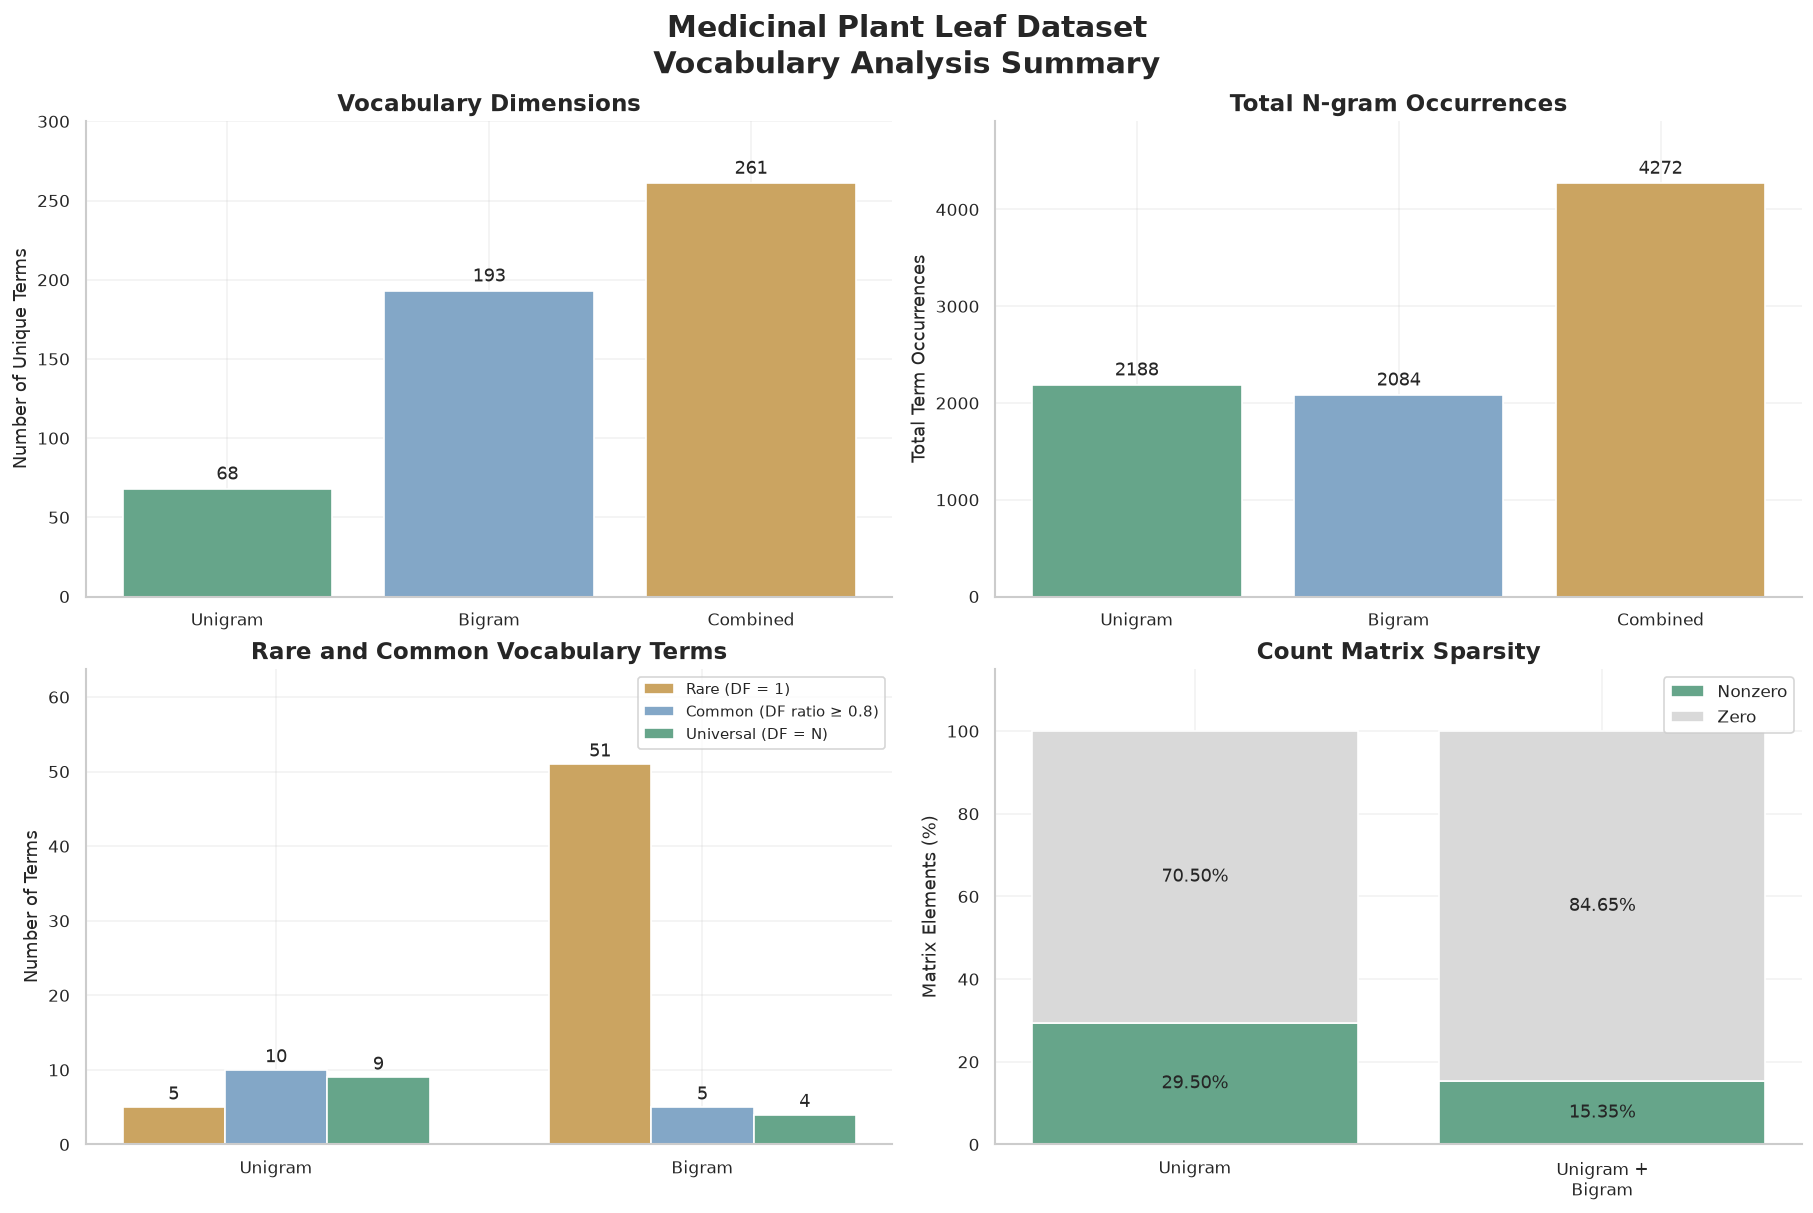

[SAVED] 65_vocabulary_analysis_summary.png


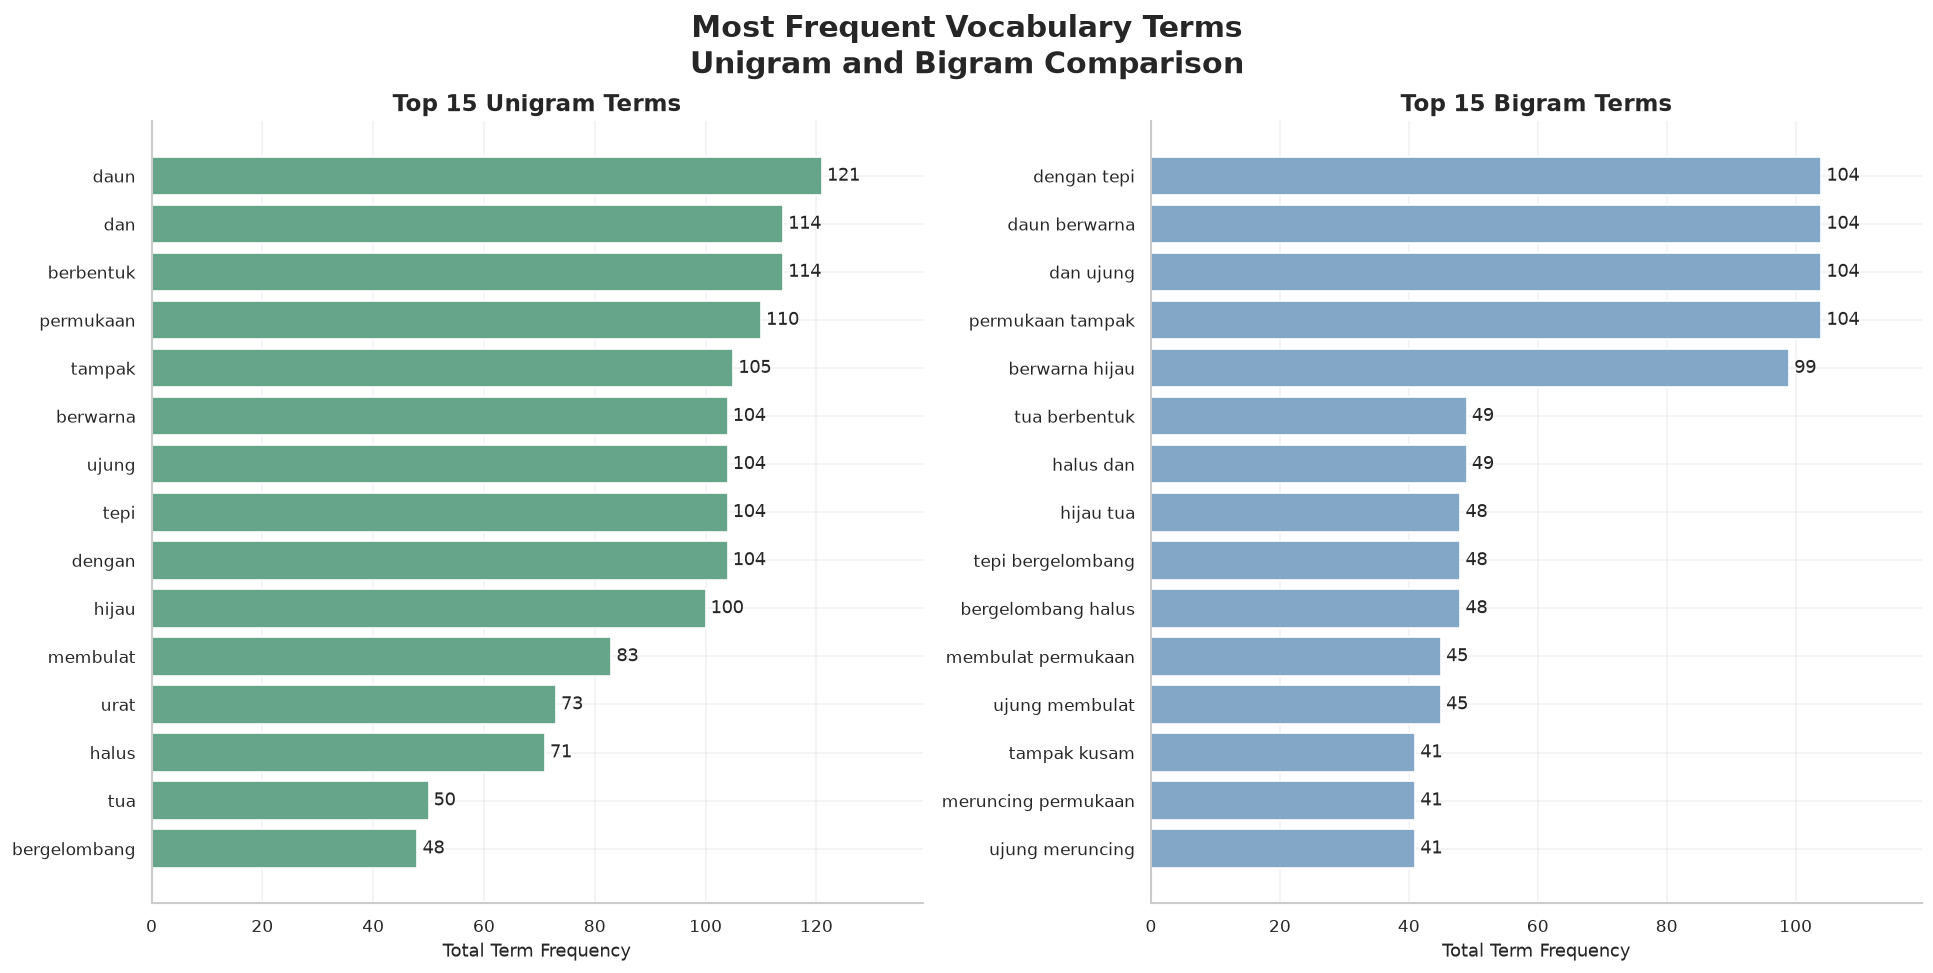

[SAVED] 66_most_frequent_vocabulary_terms.png


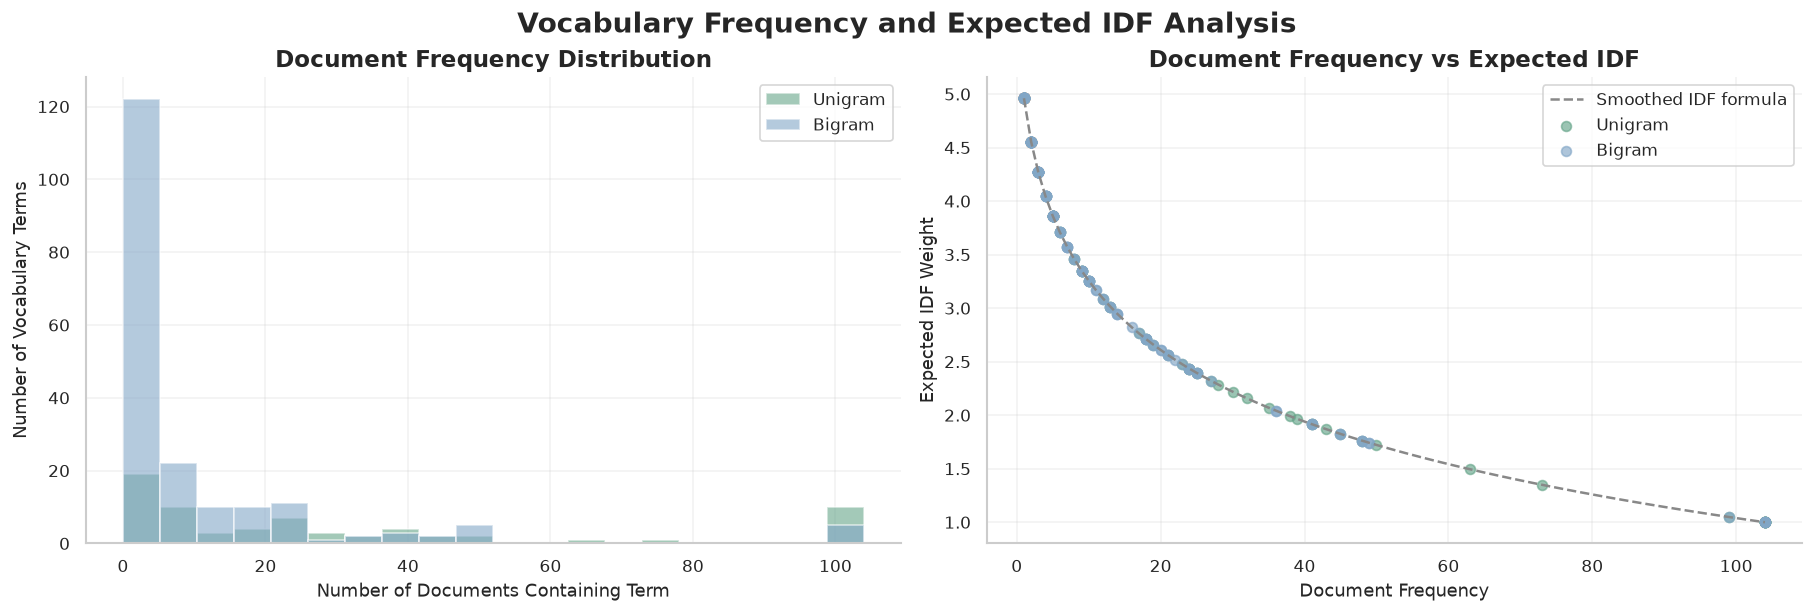

[SAVED] 67_vocabulary_frequency_and_expected_idf.png


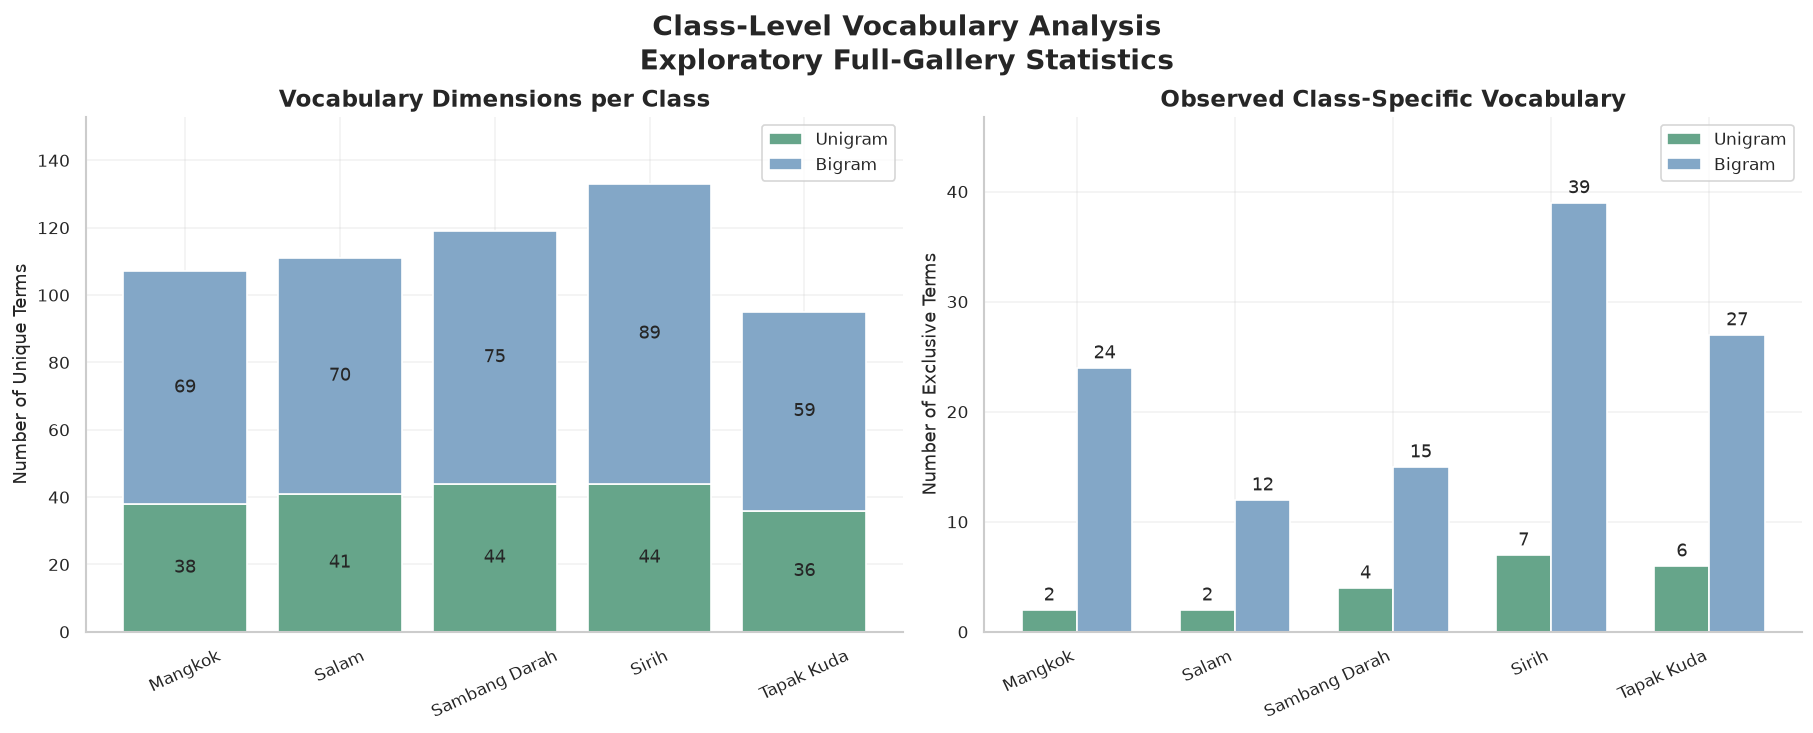

[SAVED] 68_class_level_vocabulary_analysis.png


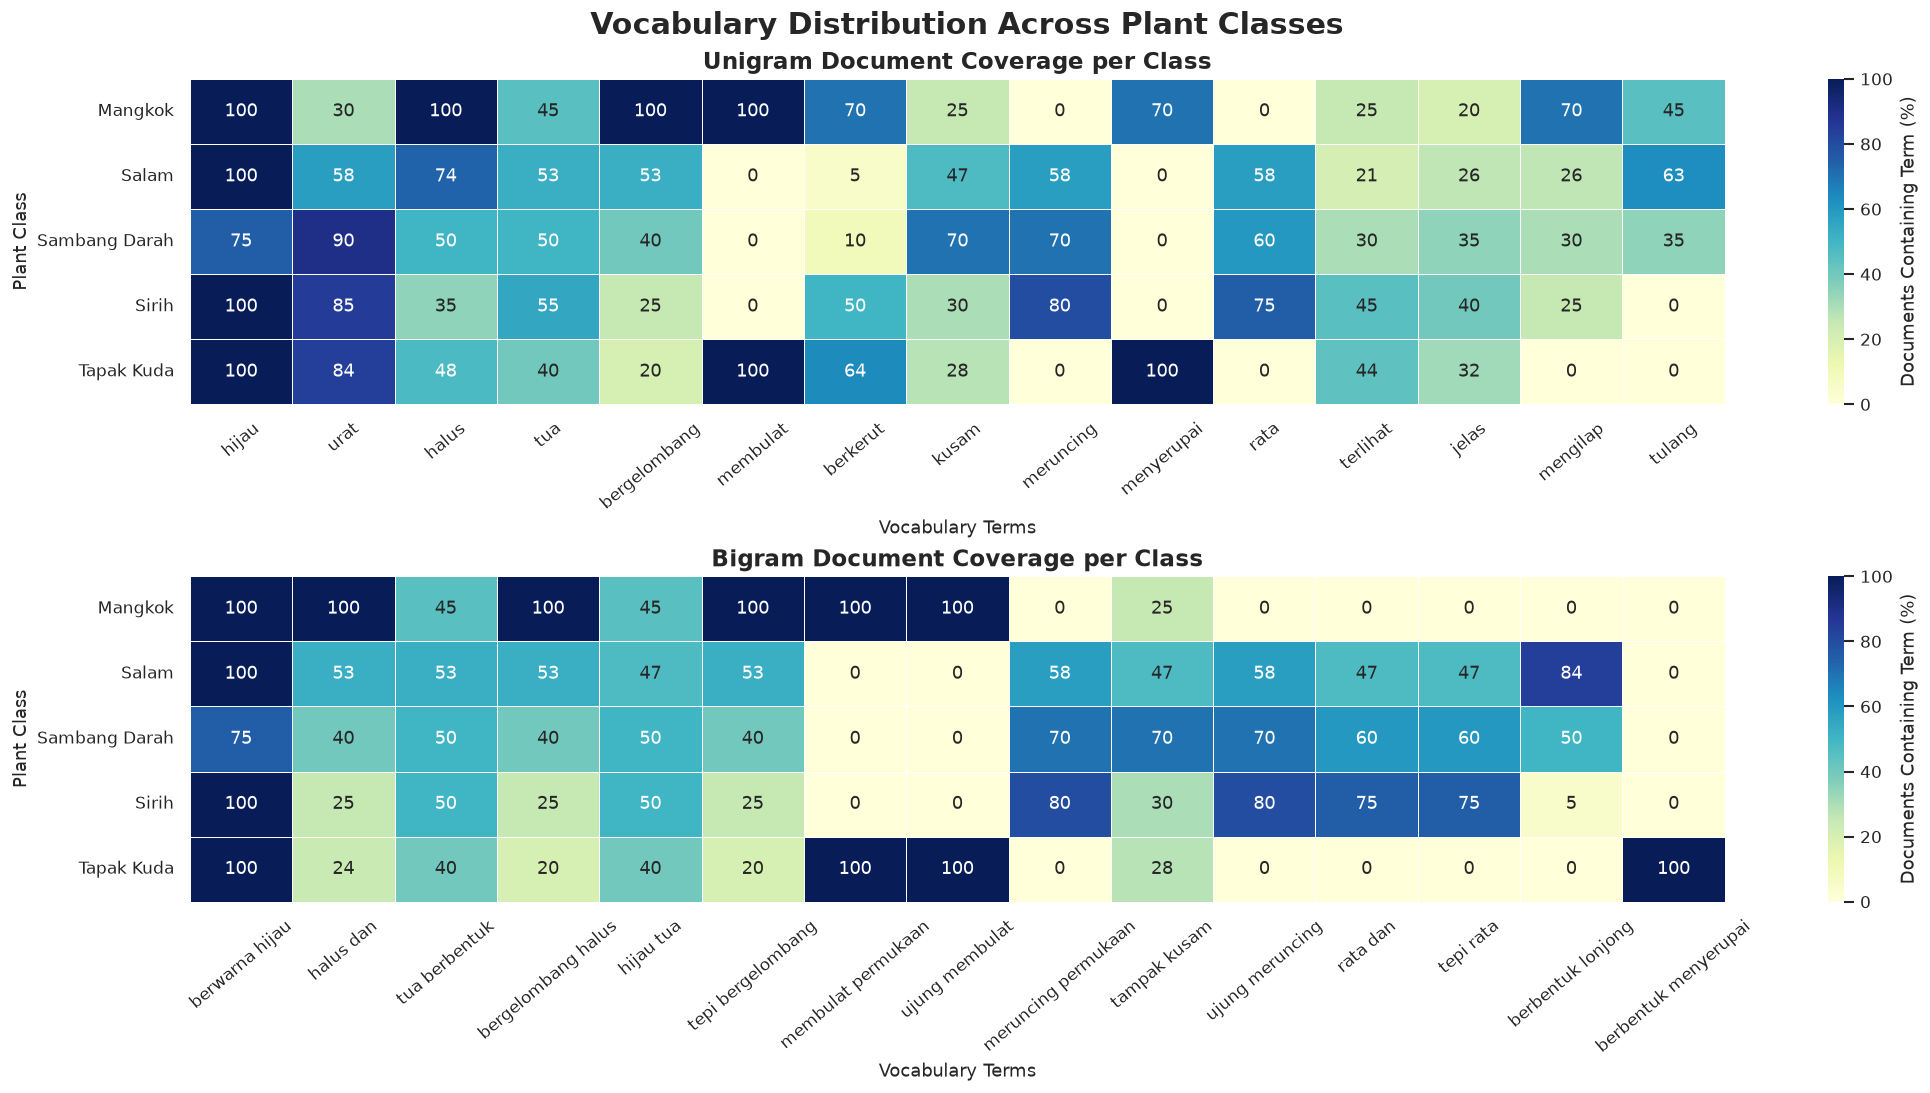

[SAVED] 69_class_vocabulary_coverage_heatmap.png

13. OVERALL VOCABULARY ANALYSIS SUMMARY
-----------------------------------------------------------------


,Indicator,Result
0,Total documents,104
1,Total classes,5
2,Unigram vocabulary size,68
3,Bigram vocabulary size,193
4,Combined vocabulary size,261
5,Unigram occurrences,2188
6,Bigram occurrences,2084
7,Combined occurrences,4272
8,Vocabulary increase percent,283.823529
9,Unigram count matrix shape,"(104, 68)"



14. SAVING VOCABULARY REPORTS
-----------------------------------------------------------------
[SAVED] 223_unigram_vocabulary_statistics.csv
[SAVED] 224_bigram_vocabulary_statistics.csv
[SAVED] 225_combined_vocabulary_statistics.csv
[SAVED] 226_ngram_vocabulary_summary.csv
[SAVED] 227_rare_vocabulary_terms.csv
[SAVED] 228_common_vocabulary_terms.csv
[SAVED] 229_universal_vocabulary_terms.csv
[SAVED] 230_class_vocabulary_statistics.csv
[SAVED] 231_class_vocabulary_summary.csv
[SAVED] 232_class_specific_vocabulary.csv
[SAVED] 233_class_specific_vocabulary_summary.csv
[SAVED] 234_count_matrix_summary.csv
[SAVED] 235_vocabulary_validation.csv
[SAVED] 236_vocabulary_document_consistency.csv
[SAVED] 237_cross_configuration_validation.csv
[SAVED] 238_vocabulary_analysis_summary.csv

FINAL VOCABULARY ANALYSIS SUMMARY

DATASET INFORMATION
-----------------------------------------------------------------
Total documents       : 104
Total classes         : 5

VOCABULARY DIMENSIONS
-------------

In [6]:
# ==================================================
# CELL 7 - VOCABULARY ANALYSIS
# ==================================================

print("VOCABULARY ANALYSIS")
print("=" * 65)

VOCABULARY_ANALYSIS_COMPLETED = False


# ==================================================
# 1. VALIDATE PREVIOUS PROCESSING STAGES
# ==================================================

assert TEXT_DATASET_VALIDATION_COMPLETED is True
assert TFIDF_CONFIGURATION_COMPLETED is True

assert len(validated_text_corpus) == text_n_samples

assert np.array_equal(
    validated_text_sample_ids,
    loaded_visual_sample_ids
)

assert df_text_validated["technical_valid"].all()

vocabulary_corpus_snapshot = list(validated_text_corpus)

print("\n[PASS] Previous processing stages validated.")


# ==================================================
# 2. VOCABULARY ANALYSIS CONFIGURATION
# ==================================================

RARE_TERM_MAX_DF = 1
COMMON_TERM_MIN_DF_RATIO = 0.80

TOP_VOCABULARY_TERMS = 15

VOCABULARY_FIT_SCOPE = (
    "Full Dataset - Gallery Development"
)

VOCABULARY_COLORS = {
    "Unigram": "#66A58A",
    "Bigram": "#83A7C7"
}

vocabulary_class_names = sorted(
    np.unique(validated_text_labels)
)

print("\n1. VOCABULARY CONFIGURATION")
print("-" * 65)

print(f"Total documents       : {text_n_samples}")
print(f"Total classes         : {len(vocabulary_class_names)}")
print(f"Rare term maximum DF  : {RARE_TERM_MAX_DF}")
print(f"Common term min ratio : {COMMON_TERM_MIN_DF_RATIO}")
print(f"Fit scope             : {VOCABULARY_FIT_SCOPE}")


# ==================================================
# 3. BUILD COUNT MATRICES
# ==================================================

count_vectorizers = {}

count_matrices = {}

count_feature_names = {}

count_extraction_times = {}

print("\n2. COUNT MATRIX CONSTRUCTION")
print("-" * 65)

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    count_vectorizer = create_count_vectorizer(
        configuration_name
    )

    start_time = time.perf_counter()

    count_matrix = count_vectorizer.fit_transform(
        validated_text_corpus
    ).tocsr()

    extraction_time = (
        time.perf_counter() - start_time
    )

    count_matrix.sum_duplicates()
    count_matrix.eliminate_zeros()
    count_matrix.sort_indices()

    feature_names = (
        count_vectorizer.get_feature_names_out()
    )

    count_vectorizers[configuration_name] = (
        count_vectorizer
    )

    count_matrices[configuration_name] = (
        count_matrix
    )

    count_feature_names[configuration_name] = (
        feature_names
    )

    count_extraction_times[configuration_name] = (
        extraction_time
    )

    print(f"\nConfiguration : {configuration_name}")
    print(f"Matrix shape  : {count_matrix.shape}")
    print(f"Vocabulary    : {len(feature_names)}")
    print(f"Total counts  : {int(count_matrix.sum()):,}")
    print(f"Nonzero values: {count_matrix.nnz:,}")
    print(f"Matrix format : {count_matrix.format}")
    print(f"Data type     : {count_matrix.dtype}")

    print(
        f"Processing time: "
        f"{extraction_time * 1000:.4f} ms"
    )


# Main aliases for subsequent cells.

unigram_count_vectorizer = count_vectorizers[
    TFIDF_BASELINE_NAME
]

unigram_bigram_count_vectorizer = count_vectorizers[
    TFIDF_ALTERNATIVE_NAME
]

unigram_count_matrix = count_matrices[
    TFIDF_BASELINE_NAME
]

unigram_bigram_count_matrix = count_matrices[
    TFIDF_ALTERNATIVE_NAME
]

unigram_feature_names = count_feature_names[
    TFIDF_BASELINE_NAME
]

unigram_bigram_feature_names = count_feature_names[
    TFIDF_ALTERNATIVE_NAME
]

bigram_feature_names = np.asarray([

    term

    for term in unigram_bigram_feature_names

    if " " in term
])

UNIGRAM_VOCABULARY_SIZE = len(
    unigram_feature_names
)

BIGRAM_VOCABULARY_SIZE = len(
    bigram_feature_names
)

COMBINED_VOCABULARY_SIZE = len(
    unigram_bigram_feature_names
)

assert UNIGRAM_VOCABULARY_SIZE == (
    global_vocabulary_size
)

assert COMBINED_VOCABULARY_SIZE == (
    UNIGRAM_VOCABULARY_SIZE
    + BIGRAM_VOCABULARY_SIZE
)

print("\n[PASS] Count matrices constructed successfully.")


# ==================================================
# 4. CALCULATE VOCABULARY STATISTICS
# ==================================================

def calculate_vocabulary_statistics(
    count_matrix,
    feature_names,
    configuration_name
):

    """
    Calculate corpus-level term statistics.

    TF: total occurrences of a term.
    DF: number of documents containing a term.
    IDF: expected smoothed inverse document frequency.
    """

    number_of_documents = count_matrix.shape[0]

    term_frequency = np.asarray(
        count_matrix.sum(axis=0)
    ).ravel()

    document_frequency = np.asarray(
        (count_matrix > 0).sum(axis=0)
    ).ravel()

    document_frequency_ratio = (
        document_frequency
        / number_of_documents
    )

    expected_idf = (

        np.log(

            (1 + number_of_documents)

            / (1 + document_frequency)
        )

        + 1
    )

    vocabulary_df = pd.DataFrame({

        "configuration": configuration_name,

        "feature_index": np.arange(
            len(feature_names)
        ),

        "term": feature_names,

        "ngram_type": [

            "Bigram" if " " in term

            else "Unigram"

            for term in feature_names
        ],

        "term_frequency": term_frequency,

        "document_frequency": document_frequency,

        "document_frequency_ratio": (
            document_frequency_ratio
        ),

        "document_frequency_percent": (
            document_frequency_ratio * 100
        ),

        "expected_idf": expected_idf,

        "rare_term": (
            document_frequency <= RARE_TERM_MAX_DF
        ),

        "common_term": (

            document_frequency_ratio
            >= COMMON_TERM_MIN_DF_RATIO
        ),

        "universal_term": (

            document_frequency
            == number_of_documents
        )
    })

    return vocabulary_df


vocabulary_statistics = {}

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    vocabulary_statistics[configuration_name] = (
        calculate_vocabulary_statistics(

            count_matrices[configuration_name],

            count_feature_names[configuration_name],

            configuration_name
        )
    )

unigram_vocabulary_df = vocabulary_statistics[
    TFIDF_BASELINE_NAME
]

unigram_bigram_vocabulary_df = vocabulary_statistics[
    TFIDF_ALTERNATIVE_NAME
]

bigram_vocabulary_df = (

    unigram_bigram_vocabulary_df.loc[

        unigram_bigram_vocabulary_df[
            "ngram_type"
        ].eq("Bigram")
    ]

    .copy()

    .reset_index(drop=True)
)

print("\n3. UNIGRAM VOCABULARY STATISTICS")
print("-" * 65)

display(

    unigram_vocabulary_df

    .sort_values(
        "term_frequency",
        ascending=False
    )

    .head(20)

    .round(6)
)

print("\n4. BIGRAM VOCABULARY STATISTICS")
print("-" * 65)

display(

    bigram_vocabulary_df

    .sort_values(
        "term_frequency",
        ascending=False
    )

    .head(20)

    .round(6)
)


# ==================================================
# 5. CREATE N-GRAM VOCABULARY SUMMARY
# ==================================================

ngram_summary_records = []

ngram_groups = {

    "Unigram": unigram_vocabulary_df,

    "Bigram": bigram_vocabulary_df,

    "Unigram + Bigram": (
        unigram_bigram_vocabulary_df
    )
}

for group_name, group_df in ngram_groups.items():

    ngram_summary_records.append({

        "ngram_group": group_name,

        "unique_terms": len(group_df),

        "total_occurrences": int(

            group_df["term_frequency"].sum()
        ),

        "minimum_term_frequency": int(

            group_df["term_frequency"].min()
        ),

        "maximum_term_frequency": int(

            group_df["term_frequency"].max()
        ),

        "mean_term_frequency": float(

            group_df["term_frequency"].mean()
        ),

        "minimum_document_frequency": int(

            group_df["document_frequency"].min()
        ),

        "maximum_document_frequency": int(

            group_df["document_frequency"].max()
        ),

        "mean_document_frequency": float(

            group_df["document_frequency"].mean()
        ),

        "rare_terms": int(

            group_df["rare_term"].sum()
        ),

        "common_terms": int(

            group_df["common_term"].sum()
        ),

        "universal_terms": int(

            group_df["universal_term"].sum()
        ),

        "minimum_expected_idf": float(

            group_df["expected_idf"].min()
        ),

        "maximum_expected_idf": float(

            group_df["expected_idf"].max()
        )
    })


ngram_vocabulary_summary_df = pd.DataFrame(
    ngram_summary_records
)

print("\n5. N-GRAM VOCABULARY SUMMARY")
print("-" * 65)

display(
    ngram_vocabulary_summary_df.round(6)
)


# ==================================================
# 6. ANALYZE RARE AND COMMON TERMS
# ==================================================

rare_vocabulary_terms_df = (

    unigram_bigram_vocabulary_df.loc[

        unigram_bigram_vocabulary_df["rare_term"]
    ]

    .sort_values(

        ["ngram_type", "term_frequency", "term"],

        ascending=[True, True, True]
    )

    .reset_index(drop=True)
)

common_vocabulary_terms_df = (

    unigram_bigram_vocabulary_df.loc[

        unigram_bigram_vocabulary_df["common_term"]
    ]

    .sort_values(

        ["document_frequency", "term_frequency"],

        ascending=False
    )

    .reset_index(drop=True)
)

universal_vocabulary_terms_df = (

    unigram_bigram_vocabulary_df.loc[

        unigram_bigram_vocabulary_df[
            "universal_term"
        ]
    ]

    .sort_values("term")

    .reset_index(drop=True)
)

print("\n6. RARE TERM ANALYSIS")
print("-" * 65)

print(
    f"Rare unigram terms: "
    f"{unigram_vocabulary_df['rare_term'].sum()}"
)

print(
    f"Rare bigram terms : "
    f"{bigram_vocabulary_df['rare_term'].sum()}"
)

display(

    rare_vocabulary_terms_df[
        [
            "term",
            "ngram_type",
            "term_frequency",
            "document_frequency",
            "expected_idf"
        ]
    ].head(20)
)

print("\n7. COMMON TERM ANALYSIS")
print("-" * 65)

display(

    common_vocabulary_terms_df[
        [
            "term",
            "ngram_type",
            "term_frequency",
            "document_frequency",
            "document_frequency_percent",
            "expected_idf"
        ]
    ].round(6)
)

print("\nUniversal vocabulary terms:")

display(

    universal_vocabulary_terms_df[
        [
            "term",
            "ngram_type",
            "document_frequency",
            "expected_idf"
        ]
    ]
)

print(
    "[INFO] Rare and common terms are retained."
)

print(
    "[INFO] No vocabulary filtering has been applied."
)


# ==================================================
# 7. ANALYZE VOCABULARY DISTRIBUTION PER CLASS
# ==================================================

class_vocabulary_records = []

class_vocabulary_summary_records = []

class_term_frequency_matrices = {}

class_document_frequency_matrices = {}

print("\n8. CLASS-LEVEL VOCABULARY ANALYSIS")
print("-" * 65)

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    count_matrix = count_matrices[
        configuration_name
    ]

    feature_names = count_feature_names[
        configuration_name
    ]

    class_tf_rows = []

    class_df_rows = []

    for class_name in vocabulary_class_names:

        class_mask = (

            validated_text_labels == class_name
        )

        class_matrix = count_matrix[class_mask]

        class_sample_count = int(
            class_mask.sum()
        )

        class_tf = np.asarray(

            class_matrix.sum(axis=0)
        ).ravel()

        class_df = np.asarray(

            (class_matrix > 0).sum(axis=0)
        ).ravel()

        class_tf_rows.append(class_tf)

        class_df_rows.append(class_df)

        for feature_index, term in enumerate(
            feature_names
        ):

            class_vocabulary_records.append({

                "configuration":
                    configuration_name,

                "kelas":
                    class_name,

                "feature_index":
                    feature_index,

                "term":
                    term,

                "ngram_type": (

                    "Bigram" if " " in term

                    else "Unigram"
                ),

                "class_documents":
                    class_sample_count,

                "class_term_frequency":
                    int(class_tf[feature_index]),

                "class_document_frequency":
                    int(class_df[feature_index]),

                "class_document_frequency_ratio": (

                    class_df[feature_index]

                    / class_sample_count
                )
            })

        present_terms = feature_names[
            class_df > 0
        ]

        unigram_count = sum(

            " " not in term

            for term in present_terms
        )

        bigram_count = sum(

            " " in term

            for term in present_terms
        )

        class_vocabulary_summary_records.append({

            "configuration":
                configuration_name,

            "kelas":
                class_name,

            "number_of_documents":
                class_sample_count,

            "unique_unigrams":
                unigram_count,

            "unique_bigrams":
                bigram_count,

            "total_unique_terms":
                len(present_terms),

            "total_term_occurrences":
                int(class_tf.sum()),

            "vocabulary_coverage_percent": (

                len(present_terms)

                / len(feature_names)

                * 100
            )
        })

    class_term_frequency_matrices[
        configuration_name
    ] = pd.DataFrame(

        class_tf_rows,

        index=vocabulary_class_names,

        columns=feature_names
    )

    class_document_frequency_matrices[
        configuration_name
    ] = pd.DataFrame(

        class_df_rows,

        index=vocabulary_class_names,

        columns=feature_names
    )


class_vocabulary_statistics_df = pd.DataFrame(
    class_vocabulary_records
)

class_vocabulary_summary_df = pd.DataFrame(
    class_vocabulary_summary_records
)

display(
    class_vocabulary_summary_df.round(6)
)


# ==================================================
# 8. IDENTIFY CLASS-SPECIFIC VOCABULARY
# ==================================================

# A class-specific term is a term that occurs
# exclusively in one class in the observed corpus.
#
# This is descriptive analysis, not feature selection.

class_specific_vocabulary_records = []

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    class_df_matrix = (

        class_document_frequency_matrices[
            configuration_name
        ]
    )

    class_tf_matrix = (

        class_term_frequency_matrices[
            configuration_name
        ]
    )

    class_presence_count = (

        class_df_matrix.gt(0).sum(axis=0)
    )

    for term in class_df_matrix.columns:

        if class_presence_count[term] != 1:

            continue

        term_class = (

            class_df_matrix[term]

            .idxmax()
        )

        class_document_count = int(

            np.sum(
                validated_text_labels == term_class
            )
        )

        term_df = int(

            class_df_matrix.loc[term_class, term]
        )

        term_tf = int(

            class_tf_matrix.loc[term_class, term]
        )

        class_specific_vocabulary_records.append({

            "configuration":
                configuration_name,

            "kelas":
                term_class,

            "term":
                term,

            "ngram_type": (

                "Bigram" if " " in term

                else "Unigram"
            ),

            "term_frequency":
                term_tf,

            "document_frequency":
                term_df,

            "class_document_count":
                class_document_count,

            "class_document_coverage_percent": (

                term_df

                / class_document_count

                * 100
            ),

            "number_of_classes_present": 1
        })


class_specific_vocabulary_df = pd.DataFrame(

    class_specific_vocabulary_records,

    columns=[

        "configuration",
        "kelas",
        "term",
        "ngram_type",
        "term_frequency",
        "document_frequency",
        "class_document_count",
        "class_document_coverage_percent",
        "number_of_classes_present"
    ]
)

class_specific_vocabulary_df = (

    class_specific_vocabulary_df

    .sort_values(

        [
            "configuration",
            "kelas",
            "document_frequency",
            "term"
        ],

        ascending=[True, True, False, True]
    )

    .reset_index(drop=True)
)

# Use the combined configuration to avoid
# counting the same unigram twice.

combined_class_specific_df = (

    class_specific_vocabulary_df.loc[

        class_specific_vocabulary_df[
            "configuration"
        ].eq(TFIDF_ALTERNATIVE_NAME)
    ]

    .copy()
)

class_specific_summary_df = (

    combined_class_specific_df

    .groupby(
        ["kelas", "ngram_type"]
    )

    .size()

    .unstack(fill_value=0)

    .reindex(

        index=vocabulary_class_names,

        columns=["Unigram", "Bigram"],

        fill_value=0
    )

    .reset_index()
)

class_specific_summary_df[
    "total_class_specific_terms"
] = (

    class_specific_summary_df["Unigram"]

    + class_specific_summary_df["Bigram"]
)

print("\n9. CLASS-SPECIFIC VOCABULARY")
print("-" * 65)

display(class_specific_summary_df)

print("\nRepresentative class-specific terms:")

display(

    combined_class_specific_df

    .sort_values(

        "document_frequency",

        ascending=False
    )

    .groupby(
        ["kelas", "ngram_type"],
        sort=False
    )

    .head(3)

    .round(4)
)

print(
    "[INFO] Class-specific terms are exclusive "
    "only within the current dataset."
)


# ==================================================
# 9. ANALYZE COUNT MATRIX SPARSITY
# ==================================================

count_matrix_summary_records = []

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    count_matrix = count_matrices[
        configuration_name
    ]

    n_rows, n_columns = count_matrix.shape

    total_elements = n_rows * n_columns

    nonzero_elements = count_matrix.nnz

    zero_elements = (
        total_elements - nonzero_elements
    )

    density = (
        nonzero_elements / total_elements
    )

    sparsity = (
        zero_elements / total_elements
    )

    document_nonzero_counts = (
        count_matrix.getnnz(axis=1)
    )

    sparse_memory_bytes = (

        count_matrix.data.nbytes

        + count_matrix.indices.nbytes

        + count_matrix.indptr.nbytes
    )

    dense_memory_bytes = (

        total_elements

        * count_matrix.dtype.itemsize
    )

    count_matrix_summary_records.append({

        "configuration":
            configuration_name,

        "number_of_documents":
            n_rows,

        "vocabulary_size":
            n_columns,

        "total_elements":
            total_elements,

        "nonzero_elements":
            nonzero_elements,

        "zero_elements":
            zero_elements,

        "density_percent":
            density * 100,

        "sparsity_percent":
            sparsity * 100,

        "minimum_nonzero_terms_per_document":
            int(document_nonzero_counts.min()),

        "maximum_nonzero_terms_per_document":
            int(document_nonzero_counts.max()),

        "mean_nonzero_terms_per_document":
            float(document_nonzero_counts.mean()),

        "empty_documents":
            int(np.sum(document_nonzero_counts == 0)),

        "sparse_memory_bytes":
            sparse_memory_bytes,

        "dense_memory_bytes":
            dense_memory_bytes,

        "memory_reduction_percent": (

            1

            - sparse_memory_bytes / dense_memory_bytes

        ) * 100,

        "matrix_format":
            count_matrix.format,

        "data_type":
            str(count_matrix.dtype),

        "construction_time_ms": (

            count_extraction_times[
                configuration_name
            ] * 1000
        )
    })


count_matrix_summary_df = pd.DataFrame(
    count_matrix_summary_records
)

print("\n10. COUNT MATRIX SUMMARY")
print("-" * 65)

display(
    count_matrix_summary_df.round(6)
)


# ==================================================
# 10. VALIDATE VOCABULARY AND COUNT MATRICES
# ==================================================

vocabulary_validation_records = []

vocabulary_document_consistency_records = []

print("\n11. VOCABULARY VALIDATION")
print("-" * 65)

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    count_matrix = count_matrices[
        configuration_name
    ]

    feature_names = count_feature_names[
        configuration_name
    ]

    count_vectorizer = count_vectorizers[
        configuration_name
    ]

    vocabulary_df = vocabulary_statistics[
        configuration_name
    ]

    is_baseline = (

        configuration_name == TFIDF_BASELINE_NAME
    )

    # Independently reconstruct term frequencies
    # from previously validated token lists.

    expected_term_counts = Counter()

    expected_document_counts = Counter()

    expected_row_counts = []

    all_document_counts_match = True

    for row_index, tokens in enumerate(
        validated_token_lists
    ):

        expected_terms = list(tokens)

        if not is_baseline:

            expected_terms += [

                f"{tokens[i]} {tokens[i + 1]}"

                for i in range(len(tokens) - 1)
            ]

        expected_counts = Counter(
            expected_terms
        )

        expected_term_counts.update(
            expected_terms
        )

        expected_document_counts.update(
            set(expected_terms)
        )

        expected_row_counts.append(
            len(expected_terms)
        )

        actual_row = count_matrix.getrow(
            row_index
        )

        actual_counts = {

            feature_names[column_index]: int(value)

            for column_index, value in zip(

                actual_row.indices,

                actual_row.data
            )
        }

        row_matches = (

            dict(expected_counts)

            == actual_counts
        )

        all_document_counts_match = (

            all_document_counts_match

            and row_matches
        )

        vocabulary_document_consistency_records.append({

            "configuration":
                configuration_name,

            "sample_id":
                validated_text_sample_ids[row_index],

            "expected_term_occurrences":
                len(expected_terms),

            "actual_term_occurrences":
                int(actual_row.sum()),

            "expected_unique_terms":
                len(expected_counts),

            "actual_unique_terms":
                actual_row.nnz,

            "passed":
                row_matches
        })

    expected_total_occurrences = (

        total_unigram_occurrences

        if is_baseline

        else total_combined_ngram_occurrences
    )

    reconstructed_row_counts = np.asarray(

        count_matrix.sum(axis=1)
    ).ravel()

    class_tf_sum = (

        class_term_frequency_matrices[
            configuration_name
        ]

        .sum(axis=0)

        .to_numpy()
    )

    class_df_sum = (

        class_document_frequency_matrices[
            configuration_name
        ]

        .sum(axis=0)

        .to_numpy()
    )

    expected_tf = np.asarray([

        expected_term_counts[term]

        for term in feature_names
    ])

    expected_df = np.asarray([

        expected_document_counts[term]

        for term in feature_names
    ])

    checks = {

        "Correct document count": (

            count_matrix.shape[0]
            == text_n_samples
        ),

        "Correct vocabulary dimension": (

            count_matrix.shape[1]
            == len(feature_names)
        ),

        "Sparse CSR matrix": (

            issparse(count_matrix)

            and count_matrix.format == "csr"
        ),

        "Integer count data type": (

            np.issubdtype(
                count_matrix.dtype,
                np.integer
            )
        ),

        "Finite numerical values": (

            np.isfinite(count_matrix.data).all()
        ),

        "Positive stored counts": (

            np.all(count_matrix.data > 0)
        ),

        "Unique vocabulary terms": (

            len(set(feature_names))
            == len(feature_names)
        ),

        "Vocabulary matches independent tokens": (

            set(feature_names)
            == set(expected_term_counts)
        ),

        "Vocabulary index consistency": (

            all(

                count_vectorizer.vocabulary_[term]
                == idx

                for idx, term in enumerate(feature_names)
            )
        ),

        "Total occurrence consistency": (

            int(count_matrix.sum())
            == expected_total_occurrences
        ),

        "Document occurrence consistency": (

            np.array_equal(

                reconstructed_row_counts,

                expected_row_counts
            )
        ),

        "Individual document count consistency": (
            all_document_counts_match
        ),

        "Term frequency consistency": (

            np.array_equal(

                vocabulary_df[
                    "term_frequency"
                ].to_numpy(),

                expected_tf
            )
        ),

        "Document frequency consistency": (

            np.array_equal(

                vocabulary_df[
                    "document_frequency"
                ].to_numpy(),

                expected_df
            )
        ),

        "Valid document frequency range": (

            vocabulary_df["document_frequency"]

            .between(1, text_n_samples)

            .all()
        ),

        "Term frequency not below document frequency": (

            vocabulary_df["term_frequency"]

            .ge(vocabulary_df["document_frequency"])

            .all()
        ),

        "Expected IDF finite and at least one": (

            np.isfinite(
                vocabulary_df["expected_idf"]
            ).all()

            and vocabulary_df[
                "expected_idf"
            ].ge(1).all()
        ),

        "No empty document vectors": (

            np.all(
                count_matrix.getnnz(axis=1) > 0
            )
        ),

        "Class term frequencies reconcile": (

            np.array_equal(
                class_tf_sum,
                expected_tf
            )
        ),

        "Class document frequencies reconcile": (

            np.array_equal(
                class_df_sum,
                expected_df
            )
        )
    }

    for check_name, passed in checks.items():

        vocabulary_validation_records.append({

            "configuration":
                configuration_name,

            "validation_check":
                check_name,

            "passed":
                bool(passed),

            "status": (

                "Passed" if passed

                else "Failed"
            )
        })


vocabulary_validation_df = pd.DataFrame(
    vocabulary_validation_records
)

vocabulary_document_consistency_df = pd.DataFrame(
    vocabulary_document_consistency_records
)

display(vocabulary_validation_df)

assert vocabulary_validation_df["passed"].all(), (

    "Vocabulary validation failed."
)

assert vocabulary_document_consistency_df[
    "passed"
].all()


# ==================================================
# 11. CROSS-CONFIGURATION CONSISTENCY
# ==================================================

# The unigram vocabulary and counts must remain
# identical after adding bigrams.

alternative_vocabulary_lookup = {

    term: idx

    for idx, term in enumerate(
        unigram_bigram_feature_names
    )
}

alternative_unigram_indices = [

    alternative_vocabulary_lookup[term]

    for term in unigram_feature_names
]

alternative_unigram_submatrix = (

    unigram_bigram_count_matrix[
        :, alternative_unigram_indices
    ]
)

unigram_count_difference = (

    alternative_unigram_submatrix

    - unigram_count_matrix
)

unigram_count_difference.eliminate_zeros()

cross_configuration_checks = {

    "Baseline unigram vocabulary preserved": (

        set(unigram_feature_names)

        == set(

            term

            for term in unigram_bigram_feature_names

            if " " not in term
        )
    ),

    "Combined vocabulary dimension correct": (

        COMBINED_VOCABULARY_SIZE

        == UNIGRAM_VOCABULARY_SIZE

        + BIGRAM_VOCABULARY_SIZE
    ),

    "Unigram counts identical across configurations": (

        unigram_count_difference.nnz == 0
    ),

    "Bigram occurrence consistency": (

        bigram_vocabulary_df[
            "term_frequency"
        ].sum()

        == total_bigram_occurrences
    ),

    "Corpus unchanged": (

        validated_text_corpus

        == vocabulary_corpus_snapshot
    ),

    "Sample alignment preserved": (

        np.array_equal(

            validated_text_sample_ids,

            loaded_visual_sample_ids
        )
    ),

    "TF-IDF vectorizers remain unfitted": (

        all(

            not hasattr(vectorizer, "vocabulary_")

            for vectorizer in tfidf_vectorizers.values()
        )
    )
}

cross_configuration_validation_df = pd.DataFrame([

    {

        "validation_check": check_name,

        "passed": bool(passed),

        "status": "Passed" if passed else "Failed"
    }

    for check_name, passed in (

        cross_configuration_checks.items()
    )
])

print("\n12. CROSS-CONFIGURATION VALIDATION")
print("-" * 65)

display(cross_configuration_validation_df)

assert cross_configuration_validation_df[
    "passed"
].all()

print(
    "[PASS] Adding bigrams does not change "
    "the original unigram counts."
)


# ==================================================
# 12. VISUALIZATION HELPER
# ==================================================

vocabulary_figure_paths = []


def save_vocabulary_figure(fig, filename):

    output_path = (
        TEXT_FEATURE_FIGURES_DIR / filename
    )

    fig.savefig(

        output_path,

        dpi=300,

        bbox_inches="tight"
    )

    vocabulary_figure_paths.append(output_path)

    plt.show()

    plt.close(fig)

    print(f"[SAVED] {filename}")


# ==================================================
# 13. VISUALIZE VOCABULARY SUMMARY
# ==================================================

fig, axes = plt.subplots(

    2, 2,

    figsize=(15, 10),

    constrained_layout=True
)


# A. Vocabulary dimensions

ax = axes[0, 0]

bars = ax.bar(

    [
        "Unigram",
        "Bigram",
        "Combined"
    ],

    [
        UNIGRAM_VOCABULARY_SIZE,
        BIGRAM_VOCABULARY_SIZE,
        COMBINED_VOCABULARY_SIZE
    ],

    color=[
        "#66A58A",
        "#83A7C7",
        "#CBA461"
    ]
)

ax.bar_label(bars, padding=3)

ax.set_title("Vocabulary Dimensions")

ax.set_ylabel("Number of Unique Terms")

ax.margins(y=0.15)


# B. N-gram occurrences

ax = axes[0, 1]

bars = ax.bar(

    [
        "Unigram",
        "Bigram",
        "Combined"
    ],

    [
        total_unigram_occurrences,
        total_bigram_occurrences,
        total_combined_ngram_occurrences
    ],

    color=[
        "#66A58A",
        "#83A7C7",
        "#CBA461"
    ]
)

ax.bar_label(bars, padding=3)

ax.set_title("Total N-gram Occurrences")

ax.set_ylabel("Total Term Occurrences")

ax.margins(y=0.15)


# C. Rare, common, and universal terms

ax = axes[1, 0]

group_positions = np.arange(2)

bar_width = 0.24

frequency_categories = [

    (
        "rare_term",
        "Rare (DF = 1)",
        "#CBA461"
    ),

    (
        "common_term",
        "Common (DF ratio ≥ 0.8)",
        "#83A7C7"
    ),

    (
        "universal_term",
        "Universal (DF = N)",
        "#66A58A"
    )
]

for idx, (column, label, color) in enumerate(
    frequency_categories
):

    counts = [

        unigram_vocabulary_df[column].sum(),

        bigram_vocabulary_df[column].sum()
    ]

    bars = ax.bar(

        group_positions + (idx - 1) * bar_width,

        counts,

        width=bar_width,

        label=label,

        color=color
    )

    ax.bar_label(bars, padding=2)

ax.set_xticks(group_positions)

ax.set_xticklabels(["Unigram", "Bigram"])

ax.set_title("Rare and Common Vocabulary Terms")

ax.set_ylabel("Number of Terms")

ax.legend(fontsize=9)

ax.margins(y=0.25)


# D. Count matrix density and sparsity

ax = axes[1, 1]

configuration_labels = [

    "Unigram",

    "Unigram +\nBigram"
]

density_values = count_matrix_summary_df[
    "density_percent"
].to_numpy()

sparsity_values = count_matrix_summary_df[
    "sparsity_percent"
].to_numpy()

density_bars = ax.bar(

    configuration_labels,

    density_values,

    color="#66A58A",

    label="Nonzero"
)

sparsity_bars = ax.bar(

    configuration_labels,

    sparsity_values,

    bottom=density_values,

    color="#D9D9D9",

    label="Zero"
)

ax.bar_label(

    density_bars,

    fmt="%.2f%%",

    label_type="center"
)

ax.bar_label(

    sparsity_bars,

    fmt="%.2f%%",

    label_type="center"
)

ax.set_ylim(0, 115)

ax.set_ylabel("Matrix Elements (%)")

ax.set_title("Count Matrix Sparsity")

ax.legend(loc="upper right")

fig.suptitle(

    "Medicinal Plant Leaf Dataset\n"

    "Vocabulary Analysis Summary",

    fontsize=18,

    fontweight="bold"
)

save_vocabulary_figure(

    fig,

    "65_vocabulary_analysis_summary.png"
)


# ==================================================
# 14. VISUALIZE MOST FREQUENT TERMS
# ==================================================

fig, axes = plt.subplots(

    1, 2,

    figsize=(16, 8),

    constrained_layout=True
)

for ax, group_name, vocabulary_df in [

    (
        axes[0],
        "Unigram",
        unigram_vocabulary_df
    ),

    (
        axes[1],
        "Bigram",
        bigram_vocabulary_df
    )
]:

    top_terms = (

        vocabulary_df

        .sort_values(

            ["term_frequency", "term"],

            ascending=[False, True]
        )

        .head(TOP_VOCABULARY_TERMS)

        .sort_values("term_frequency")
    )

    bars = ax.barh(

        top_terms["term"],

        top_terms["term_frequency"],

        color=VOCABULARY_COLORS[group_name]
    )

    ax.bar_label(bars, padding=3)

    ax.set_title(

        f"Top {len(top_terms)} {group_name} Terms"
    )

    ax.set_xlabel("Total Term Frequency")

    ax.margins(x=0.15)

fig.suptitle(

    "Most Frequent Vocabulary Terms\n"

    "Unigram and Bigram Comparison",

    fontsize=18,

    fontweight="bold"
)

save_vocabulary_figure(

    fig,

    "66_most_frequent_vocabulary_terms.png"
)


# ==================================================
# 15. VISUALIZE DOCUMENT FREQUENCY AND EXPECTED IDF
# ==================================================

fig, axes = plt.subplots(

    1, 2,

    figsize=(15, 5),

    constrained_layout=True
)

# A. Document frequency distribution

ax = axes[0]

for group_name, vocabulary_df in [

    ("Unigram", unigram_vocabulary_df),

    ("Bigram", bigram_vocabulary_df)
]:

    ax.hist(

        vocabulary_df["document_frequency"],

        bins=np.linspace(
            0, text_n_samples, 21
        ),

        color=VOCABULARY_COLORS[group_name],

        alpha=0.60,

        label=group_name,

        edgecolor="white"
    )

ax.set_title("Document Frequency Distribution")

ax.set_xlabel("Number of Documents Containing Term")

ax.set_ylabel("Number of Vocabulary Terms")

ax.legend()


# B. Document frequency versus IDF

ax = axes[1]

df_range = np.arange(
    1, text_n_samples + 1
)

idf_curve = (

    np.log(

        (1 + text_n_samples)

        / (1 + df_range)
    )

    + 1
)

ax.plot(

    df_range,

    idf_curve,

    color="#888888",

    linestyle="--",

    linewidth=1.5,

    label="Smoothed IDF formula"
)

for group_name, vocabulary_df in [

    ("Unigram", unigram_vocabulary_df),

    ("Bigram", bigram_vocabulary_df)
]:

    ax.scatter(

        vocabulary_df["document_frequency"],

        vocabulary_df["expected_idf"],

        color=VOCABULARY_COLORS[group_name],

        alpha=0.65,

        s=35,

        label=group_name
    )

ax.set_title("Document Frequency vs Expected IDF")

ax.set_xlabel("Document Frequency")

ax.set_ylabel("Expected IDF Weight")

ax.legend()

fig.suptitle(

    "Vocabulary Frequency and Expected IDF Analysis",

    fontsize=17,

    fontweight="bold"
)

save_vocabulary_figure(

    fig,

    "67_vocabulary_frequency_and_expected_idf.png"
)


# ==================================================
# 16. VISUALIZE CLASS-LEVEL VOCABULARY
# ==================================================

fig, axes = plt.subplots(

    1, 2,

    figsize=(15, 6),

    constrained_layout=True
)

class_plot_df = (

    class_vocabulary_summary_df.loc[

        class_vocabulary_summary_df[
            "configuration"
        ].eq(TFIDF_ALTERNATIVE_NAME)
    ]

    .set_index("kelas")

    .loc[vocabulary_class_names]

    .reset_index()
)

# A. Vocabulary dimensions per class

ax = axes[0]

bars_unigram = ax.bar(

    class_plot_df["kelas"],

    class_plot_df["unique_unigrams"],

    color="#66A58A",

    label="Unigram"
)

bars_bigram = ax.bar(

    class_plot_df["kelas"],

    class_plot_df["unique_bigrams"],

    bottom=class_plot_df["unique_unigrams"],

    color="#83A7C7",

    label="Bigram"
)

ax.bar_label(

    bars_unigram,

    label_type="center"
)

ax.bar_label(

    bars_bigram,

    label_type="center"
)

ax.set_title("Vocabulary Dimensions per Class")

ax.set_ylabel("Number of Unique Terms")

ax.tick_params(axis="x", labelrotation=25)

ax.legend()

ax.margins(y=0.15)


# B. Class-specific vocabulary

ax = axes[1]

positions = np.arange(
    len(vocabulary_class_names)
)

bar_width = 0.35

bars_unigram = ax.bar(

    positions - bar_width / 2,

    class_specific_summary_df["Unigram"],

    width=bar_width,

    color="#66A58A",

    label="Unigram"
)

bars_bigram = ax.bar(

    positions + bar_width / 2,

    class_specific_summary_df["Bigram"],

    width=bar_width,

    color="#83A7C7",

    label="Bigram"
)

ax.bar_label(bars_unigram, padding=3)

ax.bar_label(bars_bigram, padding=3)

ax.set_xticks(positions)

ax.set_xticklabels(

    vocabulary_class_names,

    rotation=25,

    ha="right"
)

ax.set_title("Observed Class-Specific Vocabulary")

ax.set_ylabel("Number of Exclusive Terms")

ax.legend()

ax.margins(y=0.20)

fig.suptitle(

    "Class-Level Vocabulary Analysis\n"

    "Exploratory Full-Gallery Statistics",

    fontsize=17,

    fontweight="bold"
)

save_vocabulary_figure(

    fig,

    "68_class_level_vocabulary_analysis.png"
)


# ==================================================
# 17. VISUALIZE CLASS TERM COVERAGE HEATMAP
# ==================================================

# Select frequent terms using corpus-level DF.
# Classes are used for visualization only.

fig, axes = plt.subplots(

    2, 1,

    figsize=(16, 9),

    constrained_layout=True
)

combined_class_df_matrix = (

    class_document_frequency_matrices[
        TFIDF_ALTERNATIVE_NAME
    ]
)

class_document_counts = pd.Series({

    class_name: int(

        np.sum(
            validated_text_labels == class_name
        )
    )

    for class_name in vocabulary_class_names
})

for ax, group_name, vocabulary_df in [

    (
        axes[0],
        "Unigram",
        unigram_vocabulary_df
    ),

    (
        axes[1],
        "Bigram",
        bigram_vocabulary_df
    )
]:

    # Omit universal terms from the heatmap
    # to make differences easier to inspect.

    selected_terms = (

        vocabulary_df.loc[

            ~vocabulary_df["universal_term"]
        ]

        .sort_values(

            [
                "document_frequency",
                "term_frequency",
                "term"
            ],

            ascending=[False, False, True]
        )

        .head(TOP_VOCABULARY_TERMS)["term"]

        .tolist()
    )

    if not selected_terms:

        ax.set_axis_off()

        ax.set_title(

            f"No non-universal {group_name} terms"
        )

        continue

    class_coverage_df = (

        combined_class_df_matrix[
            selected_terms
        ]

        .div(

            class_document_counts,

            axis=0
        )

        * 100
    )

    sns.heatmap(

        class_coverage_df,

        annot=True,

        fmt=".0f",

        cmap="YlGnBu",

        vmin=0,

        vmax=100,

        linewidths=0.5,

        cbar_kws={

            "label": "Documents Containing Term (%)"
        },

        ax=ax
    )

    ax.set_title(

        f"{group_name} Document Coverage per Class"
    )

    ax.set_xlabel("Vocabulary Terms")

    ax.set_ylabel("Plant Class")

    ax.tick_params(

        axis="x",

        labelrotation=40
    )

    ax.tick_params(

        axis="y",

        labelrotation=0
    )

fig.suptitle(

    "Vocabulary Distribution Across Plant Classes",

    fontsize=18,

    fontweight="bold"
)

save_vocabulary_figure(

    fig,

    "69_class_vocabulary_coverage_heatmap.png"
)


# ==================================================
# 18. CREATE OVERALL VOCABULARY SUMMARY
# ==================================================

total_vocabulary_validation_checks = (

    len(vocabulary_validation_df)

    + len(cross_configuration_validation_df)
)

passed_vocabulary_validation_checks = (

    int(vocabulary_validation_df["passed"].sum())

    + int(
        cross_configuration_validation_df[
            "passed"
        ].sum()
    )
)

vocabulary_analysis_summary_df = pd.DataFrame([

    ("Total documents", text_n_samples),

    ("Total classes", len(vocabulary_class_names)),

    ("Unigram vocabulary size", UNIGRAM_VOCABULARY_SIZE),

    ("Bigram vocabulary size", BIGRAM_VOCABULARY_SIZE),

    ("Combined vocabulary size", COMBINED_VOCABULARY_SIZE),

    (
        "Unigram occurrences",
        total_unigram_occurrences
    ),

    (
        "Bigram occurrences",
        total_bigram_occurrences
    ),

    (
        "Combined occurrences",
        total_combined_ngram_occurrences
    ),

    (
        "Vocabulary increase percent",
        BIGRAM_VOCABULARY_SIZE
        / UNIGRAM_VOCABULARY_SIZE * 100
    ),

    (
        "Unigram count matrix shape",
        str(unigram_count_matrix.shape)
    ),

    (
        "Combined count matrix shape",
        str(unigram_bigram_count_matrix.shape)
    ),

    (
        "Unigram nonzero elements",
        unigram_count_matrix.nnz
    ),

    (
        "Combined nonzero elements",
        unigram_bigram_count_matrix.nnz
    ),

    (
        "Rare unigram terms",
        int(unigram_vocabulary_df["rare_term"].sum())
    ),

    (
        "Rare bigram terms",
        int(bigram_vocabulary_df["rare_term"].sum())
    ),

    (
        "Common unigram terms",
        int(unigram_vocabulary_df["common_term"].sum())
    ),

    (
        "Common bigram terms",
        int(bigram_vocabulary_df["common_term"].sum())
    ),

    (
        "Universal unigram terms",
        int(unigram_vocabulary_df["universal_term"].sum())
    ),

    (
        "Universal bigram terms",
        int(bigram_vocabulary_df["universal_term"].sum())
    ),

    (
        "Class-specific unigram terms",
        int(
            combined_class_specific_df[
                "ngram_type"
            ].eq("Unigram").sum()
        )
    ),

    (
        "Class-specific bigram terms",
        int(
            combined_class_specific_df[
                "ngram_type"
            ].eq("Bigram").sum()
        )
    ),

    (
        "Document count consistency checks",
        len(vocabulary_document_consistency_df)
    ),

    (
        "Document count consistency checks passed",
        int(
            vocabulary_document_consistency_df[
                "passed"
            ].sum()
        )
    ),

    (
        "Total vocabulary validation checks",
        total_vocabulary_validation_checks
    ),

    (
        "Vocabulary validation checks passed",
        passed_vocabulary_validation_checks
    ),

    (
        "Vocabulary validation checks failed",
        total_vocabulary_validation_checks
        - passed_vocabulary_validation_checks
    ),

    ("Vocabulary fit scope", VOCABULARY_FIT_SCOPE),

    ("Vocabulary terms removed", 0),

    ("Samples removed", 0),

    ("Descriptions modified", 0),

    ("TF-IDF vectorizers fitted", False),

    ("Feature selection applied", False),

    ("Generated visualizations", len(vocabulary_figure_paths)),

    ("Vocabulary analysis completed", True)

], columns=["Indicator", "Result"])

print("\n13. OVERALL VOCABULARY ANALYSIS SUMMARY")
print("-" * 65)

display(vocabulary_analysis_summary_df)


# ==================================================
# 19. SAVE VOCABULARY ANALYSIS REPORTS
# ==================================================

vocabulary_reports = {

    "223_unigram_vocabulary_statistics.csv":
        unigram_vocabulary_df,

    "224_bigram_vocabulary_statistics.csv":
        bigram_vocabulary_df,

    "225_combined_vocabulary_statistics.csv":
        unigram_bigram_vocabulary_df,

    "226_ngram_vocabulary_summary.csv":
        ngram_vocabulary_summary_df,

    "227_rare_vocabulary_terms.csv":
        rare_vocabulary_terms_df,

    "228_common_vocabulary_terms.csv":
        common_vocabulary_terms_df,

    "229_universal_vocabulary_terms.csv":
        universal_vocabulary_terms_df,

    "230_class_vocabulary_statistics.csv":
        class_vocabulary_statistics_df,

    "231_class_vocabulary_summary.csv":
        class_vocabulary_summary_df,

    "232_class_specific_vocabulary.csv":
        class_specific_vocabulary_df,

    "233_class_specific_vocabulary_summary.csv":
        class_specific_summary_df,

    "234_count_matrix_summary.csv":
        count_matrix_summary_df,

    "235_vocabulary_validation.csv":
        vocabulary_validation_df,

    "236_vocabulary_document_consistency.csv":
        vocabulary_document_consistency_df,

    "237_cross_configuration_validation.csv":
        cross_configuration_validation_df,

    "238_vocabulary_analysis_summary.csv":
        vocabulary_analysis_summary_df
}

print("\n14. SAVING VOCABULARY REPORTS")
print("-" * 65)

for filename, dataframe in vocabulary_reports.items():

    dataframe.to_csv(

        METRICS_DIR / filename,

        index=False,

        encoding="utf-8-sig",

        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ==================================================
# 20. FINAL VOCABULARY VALIDATION
# ==================================================

assert unigram_count_matrix.shape == (

    text_n_samples,

    UNIGRAM_VOCABULARY_SIZE
)

assert unigram_bigram_count_matrix.shape == (

    text_n_samples,

    COMBINED_VOCABULARY_SIZE
)

assert vocabulary_validation_df["passed"].all()

assert vocabulary_document_consistency_df[
    "passed"
].all()

assert cross_configuration_validation_df[
    "passed"
].all()

assert passed_vocabulary_validation_checks == (
    total_vocabulary_validation_checks
)

assert len(
    vocabulary_document_consistency_df
) == text_n_samples * len(TFIDF_CONFIGS)

assert validated_text_corpus == text_corpus

assert np.array_equal(

    validated_text_sample_ids,

    loaded_visual_sample_ids
)

assert all(

    not hasattr(vectorizer, "vocabulary_")

    for vectorizer in tfidf_vectorizers.values()
)

assert len(vocabulary_figure_paths) == 5

assert all(

    path.is_file()

    and path.stat().st_size > 0

    for path in vocabulary_figure_paths
)

assert all(

    (METRICS_DIR / filename).is_file()

    and (METRICS_DIR / filename).stat().st_size > 0

    for filename in vocabulary_reports
)

VOCABULARY_ANALYSIS_COMPLETED = True


# ==================================================
# 21. FINAL VOCABULARY ANALYSIS SUMMARY
# ==================================================

print("\n" + "=" * 65)
print("FINAL VOCABULARY ANALYSIS SUMMARY")
print("=" * 65)

print("\nDATASET INFORMATION")
print("-" * 65)

print(f"Total documents       : {text_n_samples}")

print(

    f"Total classes         : "

    f"{len(vocabulary_class_names)}"
)

print("\nVOCABULARY DIMENSIONS")
print("-" * 65)

print(

    f"Unigram vocabulary    : "

    f"{UNIGRAM_VOCABULARY_SIZE}"
)

print(

    f"Bigram vocabulary     : "

    f"{BIGRAM_VOCABULARY_SIZE}"
)

print(

    f"Combined vocabulary   : "

    f"{COMBINED_VOCABULARY_SIZE}"
)

print(

    f"Vocabulary increase   : "

    f"{BIGRAM_VOCABULARY_SIZE / UNIGRAM_VOCABULARY_SIZE * 100:.2f}%"
)

print("\nCOUNT MATRICES")
print("-" * 65)

print(f"Unigram matrix        : {unigram_count_matrix.shape}")

print(

    f"Combined matrix       : "

    f"{unigram_bigram_count_matrix.shape}"
)

print(

    f"Unigram occurrences   : "

    f"{total_unigram_occurrences:,}"
)

print(

    f"Bigram occurrences    : "

    f"{total_bigram_occurrences:,}"
)

print(

    f"Combined occurrences  : "

    f"{total_combined_ngram_occurrences:,}"
)

print("\nVOCABULARY FREQUENCY")
print("-" * 65)

print(

    f"Rare unigram terms    : "

    f"{unigram_vocabulary_df['rare_term'].sum()}"
)

print(

    f"Rare bigram terms     : "

    f"{bigram_vocabulary_df['rare_term'].sum()}"
)

print(

    f"Universal unigram     : "

    f"{unigram_vocabulary_df['universal_term'].sum()}"
)

print(

    f"Universal bigram      : "

    f"{bigram_vocabulary_df['universal_term'].sum()}"
)

print("\nVALIDATION RESULTS")
print("-" * 65)

print(

    f"Vocabulary checks     : "

    f"{passed_vocabulary_validation_checks}/"

    f"{total_vocabulary_validation_checks}"
)

print(

    f"Document consistency  : "

    f"{vocabulary_document_consistency_df['passed'].sum()}/"

    f"{len(vocabulary_document_consistency_df)}"
)

print(

    f"Generated reports     : "

    f"{len(vocabulary_reports)}"
)

print(

    f"Generated figures     : "

    f"{len(vocabulary_figure_paths)}"
)

print("\n[PASS] Vocabulary construction completed.")

print("[PASS] Term frequency consistency validated.")

print("[PASS] Document frequency consistency validated.")

print("[PASS] Count matrices validated.")

print("[PASS] Class vocabulary analysis completed.")

print("[PASS] Cross-configuration consistency verified.")

print("[PASS] Image-text alignment preserved.")

print("[PASS] Vocabulary reports saved.")

print("\n[INFO] No vocabulary terms were removed.")

print("[INFO] No descriptions were modified.")

print("[INFO] No samples were removed.")

print("[INFO] Class labels were used only for analysis.")

print("[INFO] Expected IDF weights are exploratory.")

print("[INFO] Main TF-IDF vectorizers remain unfitted.")

print("[INFO] Evaluation requires reference-only fitting.")

print("\nVocabulary analysis completed successfully!")

print("\nNext cell: Cell 8 - TF-IDF Feature Extraction")

TF-IDF FEATURE EXTRACTION

[PASS] Previous processing stages validated.

[PASS] TF-IDF feature containers initialized.

1. TF-IDF FEATURE EXTRACTION
-----------------------------------------------------------------

Configuration: Unigram
Matrix shape     : (104, 68)
Feature dimension: 68
Nonzero elements : 2,086
Matrix format    : csr
Data type        : float64
Extraction time  : 2.9163 ms

Configuration: Unigram + Bigram
Matrix shape     : (104, 261)
Feature dimension: 261
Nonzero elements : 4,166
Matrix format    : csr
Data type        : float64
Extraction time  : 2.5866 ms

[PASS] Both TF-IDF configurations fitted.

2. FEATURE MATRIX DIMENSIONS
-----------------------------------------------------------------
Baseline matrix   : (104, 68)
Alternative matrix: (104, 261)
Default dimension : 68

3. TF-IDF MATHEMATICAL VALIDATION
-----------------------------------------------------------------

Configuration: Unigram
Maximum IDF difference   : 0.000000000000e+00
Maximum TF-IDF differe

,configuration,number_of_documents,feature_dimension,total_elements,nonzero_elements,zero_elements,density_percent,sparsity_percent,minimum_nonzero_weight,maximum_nonzero_weight,mean_nonzero_weight,minimum_idf,maximum_idf,minimum_l2_norm,maximum_l2_norm,maximum_norm_deviation,maximum_idf_difference,maximum_tfidf_difference,empty_vectors,nan_values,infinite_values,matrix_format,data_type,extraction_time_ms,validation_checks,validation_checks_passed,passed
0,Unigram,104,68,7072,2086,4986,29.496606,70.503394,0.074940,0.682756,0.199984,1.0,4.960813,1.0,1.0,0.0,0.0,0.0,0,0,0,csr,float64,2.9163,20,20,True
1,Unigram + Bigram,104,261,27144,4166,22978,15.347775,84.652225,0.044557,0.405942,0.141254,1.0,4.960813,1.0,1.0,0.0,0.0,0.0,0,0,0,csr,float64,2.5866,20,20,True



5. TECHNICAL VALIDATION CHECKLIST
-----------------------------------------------------------------


,configuration,validation_check,passed,status
0,Unigram,Correct document count,True,Passed
1,Unigram,Correct feature dimension,True,Passed
2,Unigram,Vocabulary order consistency,True,Passed
3,Unigram,Vocabulary index consistency,True,Passed
4,Unigram,Sparse CSR matrix,True,Passed
5,Unigram,Float64 data type,True,Passed
6,Unigram,Finite TF-IDF values,True,Passed
7,Unigram,Positive stored TF-IDF values,True,Passed
8,Unigram,TF-IDF values within normalized range,True,Passed
9,Unigram,Finite IDF weights,True,Passed



6. INDIVIDUAL DOCUMENT VALIDATION
-----------------------------------------------------------------


,configuration,row_index,sample_id,kelas,nonzero_features,l2_norm,maximum_absolute_tfidf_error,passed
0,Unigram,0,leaf_165d2f32c7fda707,Mangkok,17,1.0,0.000000e+00,True
1,Unigram,1,leaf_8473270c3702f48b,Mangkok,21,1.0,0.000000e+00,True
2,Unigram,2,leaf_8f425d66b1e193b9,Mangkok,18,1.0,1.110223e-16,True
3,Unigram,3,leaf_0ebc8f4f3ee9c8d5,Mangkok,19,1.0,0.000000e+00,True
4,Unigram,4,leaf_b0c5f55e42499cae,Mangkok,20,1.0,1.110223e-16,True
5,Unigram,5,leaf_de9e3e4ed5d89dfc,Mangkok,19,1.0,0.000000e+00,True
6,Unigram,6,leaf_23b789945271fb92,Mangkok,21,1.0,1.110223e-16,True
7,Unigram,7,leaf_84de0dc731018607,Mangkok,19,1.0,0.000000e+00,True
8,Unigram,8,leaf_36d4f083fa652592,Mangkok,22,1.0,0.000000e+00,True
9,Unigram,9,leaf_c9d8d87fbc748d16,Mangkok,18,1.0,0.000000e+00,True


... (8 outputs left out)


11. ALTERNATIVE FEATURE DATAFRAME
-----------------------------------------------------------------
DataFrame shape: (104, 269)


,feature_row_index,sample_id,nama_file,kelas,tampilan_daun,text_validation_status,final_dataset_status,visual_validation_status,tfidf_agak,tfidf_agak asimetris,tfidf_asimetris,tfidf_asimetris dengan,tfidf_berbentuk,tfidf_berbentuk berbentuk,tfidf_berbentuk bulat
0,0,leaf_165d2f32c7fda707,mangkok 10.jpeg,Mangkok,belakang,Passed Initial Check,Ready - Pending Review,Needs Review,0.0,0.0,0.0,0.0,0.075767,0.0,0.0
1,1,leaf_8473270c3702f48b,mangkok 11.png,Mangkok,belakang,Passed Initial Check,Ready - Initial Checks Passed,Passed Initial Check,0.0,0.0,0.0,0.0,0.064594,0.0,0.0
2,2,leaf_8f425d66b1e193b9,mangkok 12.png,Mangkok,belakang,Passed Initial Check,Ready - Initial Checks Passed,Passed Initial Check,0.0,0.0,0.0,0.0,0.067858,0.0,0.0
3,3,leaf_0ebc8f4f3ee9c8d5,mangkok 13.png,Mangkok,belakang,Passed Initial Check,Ready - Initial Checks Passed,Passed Initial Check,0.0,0.0,0.0,0.0,0.074523,0.0,0.0
4,4,leaf_b0c5f55e42499cae,mangkok 14.png,Mangkok,belakang,Passed Initial Check,Ready - Initial Checks Passed,Passed Initial Check,0.0,0.0,0.0,0.0,0.066705,0.0,0.0



12. REPRESENTATIVE TF-IDF SAMPLES
-----------------------------------------------------------------


,configuration,sample_id,kelas,rank,feature_index,term,tfidf_weight
0,Unigram,leaf_165d2f32c7fda707,Mangkok,1,33,membulat,0.509266
1,Unigram,leaf_165d2f32c7fda707,Mangkok,2,63,tulang,0.318991
2,Unigram,leaf_165d2f32c7fda707,Mangkok,3,34,mengilap,0.309687
10,Unigram,leaf_c29e2560b188fb2c,Salam,1,61,tipis,0.546529
11,Unigram,leaf_c29e2560b188fb2c,Salam,2,46,runcing,0.298506
12,Unigram,leaf_c29e2560b188fb2c,Salam,3,49,sedang,0.272769
20,Unigram,leaf_df16548c53396aeb,Sambang Darah,1,25,keunguan,0.387267
21,Unigram,leaf_df16548c53396aeb,Sambang Darah,2,39,merah,0.387267
22,Unigram,leaf_df16548c53396aeb,Sambang Darah,3,47,samar,0.336046
30,Unigram,leaf_1d4f34320b1b8b8d,Sirih,1,0,agak,0.379548


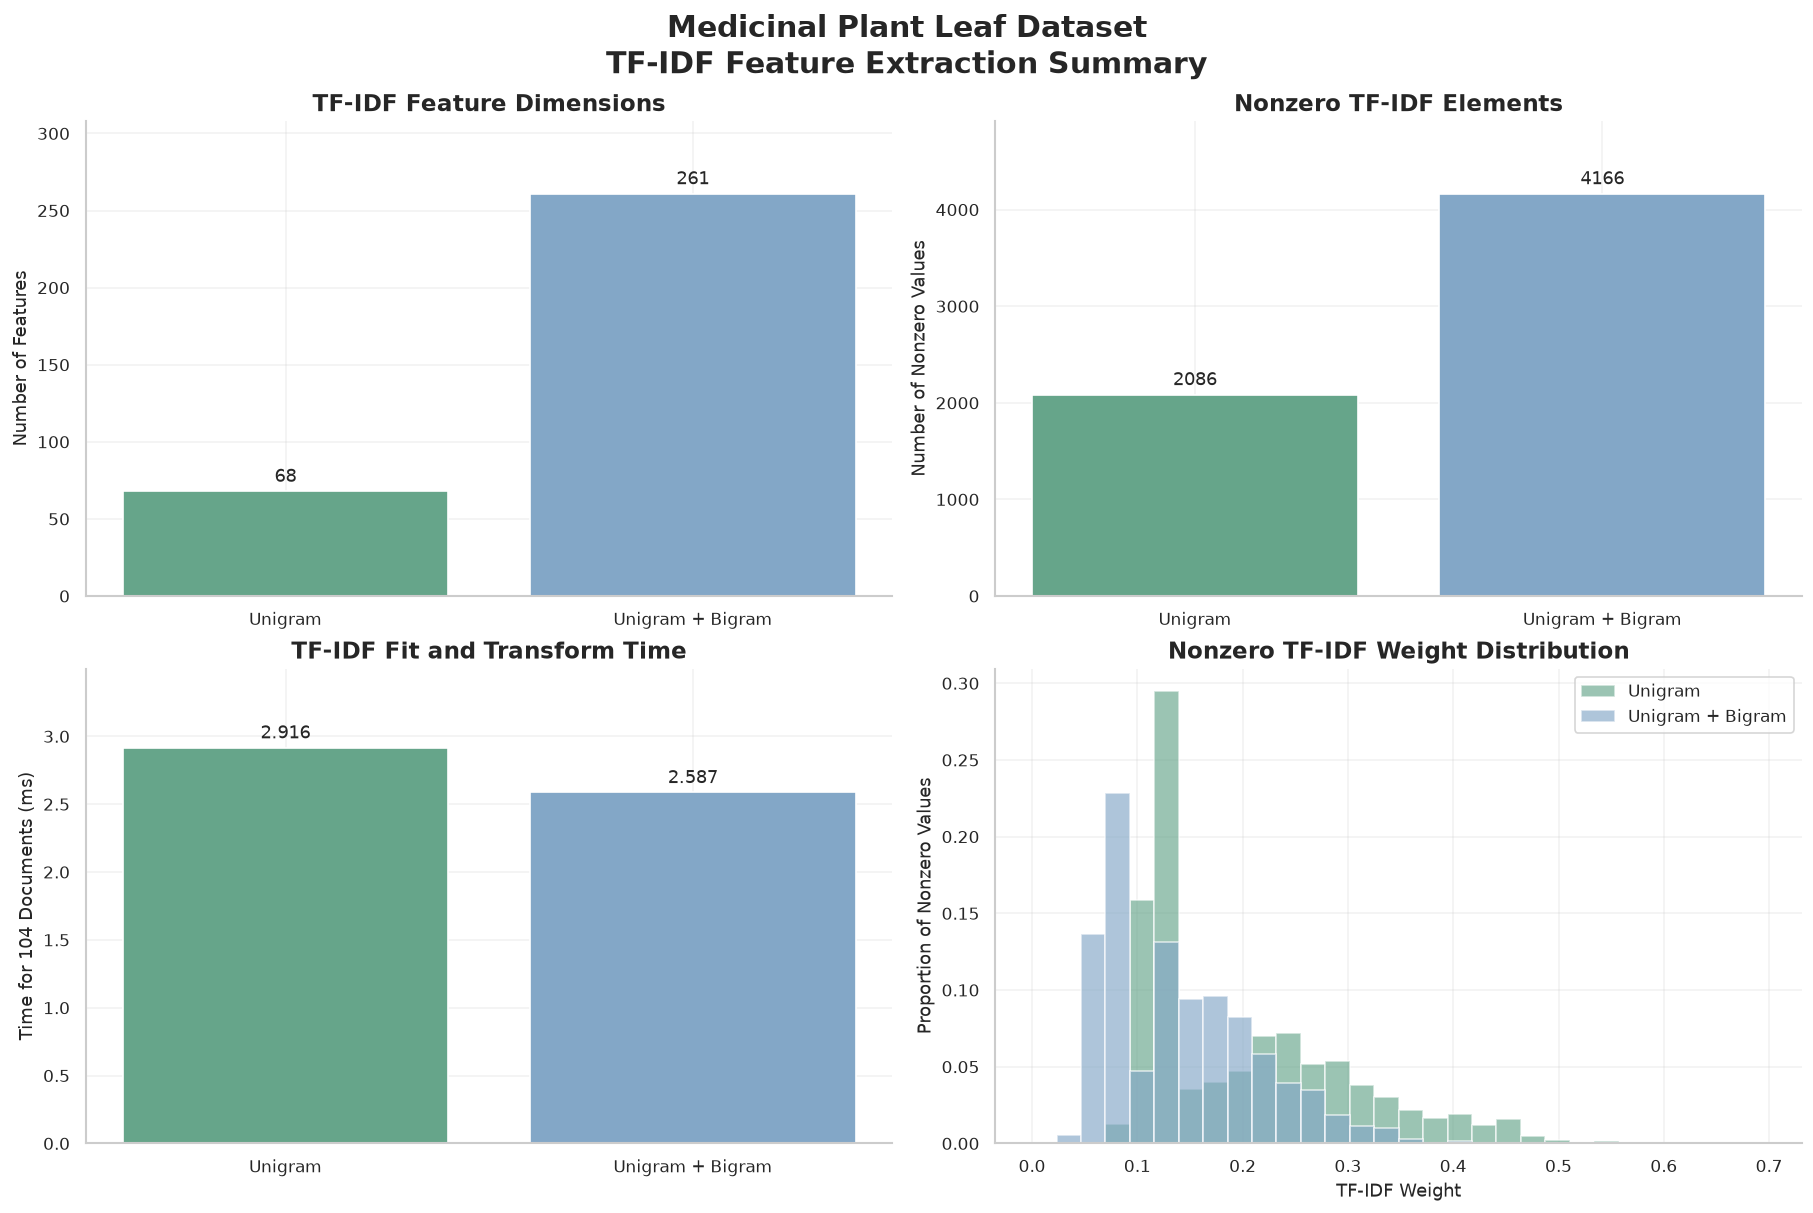

[SAVED] 70_tfidf_feature_extraction_summary.png


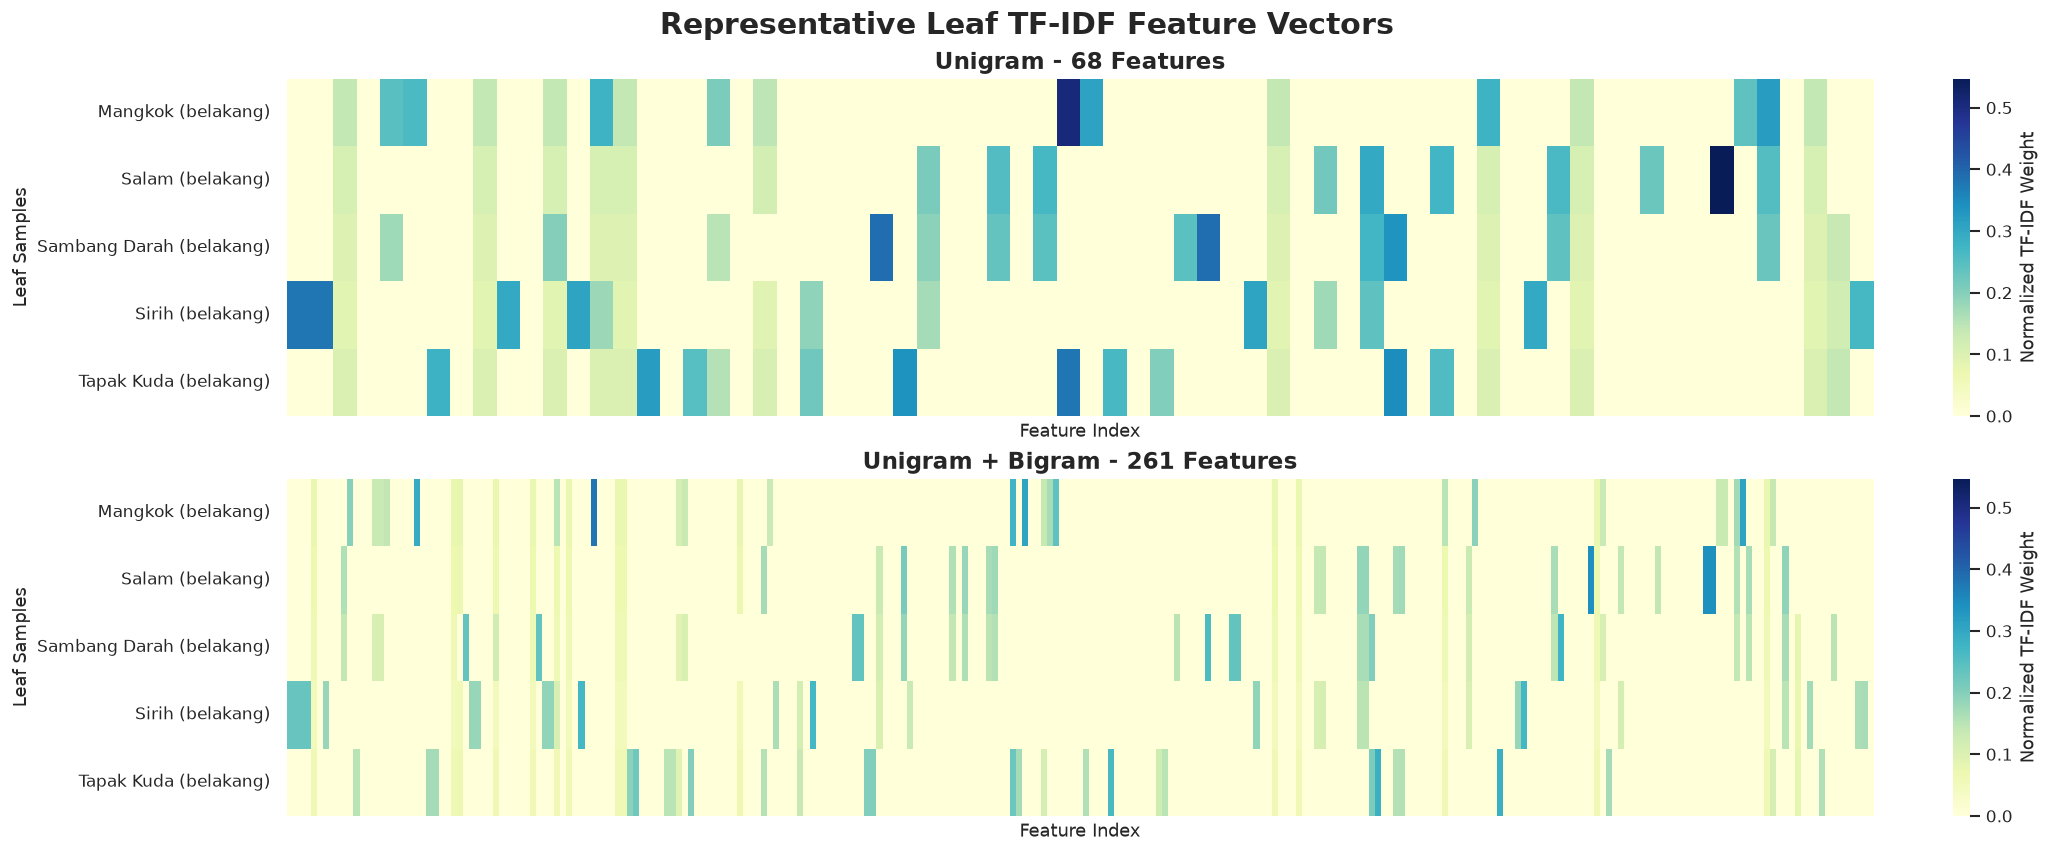

[SAVED] 71_representative_tfidf_feature_vectors.png

[PASS] TF-IDF configuration metadata updated.

13. OVERALL EXTRACTION SUMMARY
-----------------------------------------------------------------


,Indicator,Result
0,Total text documents,104
1,Total classes,5
2,Feature method,TF-IDF
3,Default configuration,Unigram
4,Baseline feature dimension,68
5,Alternative feature dimension,261
6,Baseline matrix shape,"(104, 68)"
7,Alternative matrix shape,"(104, 261)"
8,Baseline nonzero elements,2086
9,Alternative nonzero elements,4166



14. SAVING EXTRACTION REPORTS
-----------------------------------------------------------------
[SAVED] 239_tfidf_extraction_summary.csv
[SAVED] 240_tfidf_extraction_validation.csv
[SAVED] 241_tfidf_document_validation.csv
[SAVED] 242_tfidf_idf_validation.csv
[SAVED] 243_tfidf_feature_statistics.csv
[SAVED] 244_tfidf_extraction_check_summary.csv
[SAVED] 245_tfidf_cross_configuration_consistency.csv
[SAVED] 246_representative_tfidf_terms.csv
[SAVED] 247_overall_tfidf_extraction_summary.csv

FINAL TF-IDF FEATURE EXTRACTION SUMMARY

DATASET INFORMATION
-----------------------------------------------------------------
Total documents       : 104
Total classes         : 5
Default configuration : Unigram

FEATURE MATRICES
-----------------------------------------------------------------
Unigram matrix        : (104, 68)
Unigram + Bigram      : (104, 261)
Unigram nonzero       : 2,086
Combined nonzero      : 4,166
Matrix format         : CSR
Data type             : float64

MATHEMATICAL VALI

In [7]:
# ==================================================
# CELL 8 - TF-IDF FEATURE EXTRACTION
# ==================================================

from scipy.sparse import issparse

print("TF-IDF FEATURE EXTRACTION")
print("=" * 65)

TFIDF_FEATURE_EXTRACTION_COMPLETED = False


# ==================================================
# 1. VALIDATE PREVIOUS PROCESSING STAGES
# ==================================================

assert TEXT_DATASET_VALIDATION_COMPLETED is True
assert TFIDF_CONFIGURATION_COMPLETED is True
assert VOCABULARY_ANALYSIS_COMPLETED is True

assert len(validated_text_corpus) == text_n_samples

assert df_text_validated["technical_valid"].all()

assert np.array_equal(
    validated_text_sample_ids,
    loaded_visual_sample_ids
)

assert vocabulary_validation_df["passed"].all()

assert cross_configuration_validation_df["passed"].all()

tfidf_corpus_snapshot = list(validated_text_corpus)

tfidf_sample_ids = validated_text_sample_ids.copy()

tfidf_labels = validated_text_labels.copy()

print("\n[PASS] Previous processing stages validated.")


# ==================================================
# 2. INITIALIZE TF-IDF FEATURE CONTAINERS
# ==================================================

tfidf_vectorizers = {}

tfidf_matrices = {}

tfidf_feature_names_by_config = {}

tfidf_idf_weights = {}

tfidf_extraction_times = {}

tfidf_document_norms = {}

tfidf_manual_results = {}

tfidf_extraction_records = []

tfidf_validation_records = []

tfidf_document_records = []

tfidf_idf_records = []

tfidf_feature_records = []

TFIDF_EXTRACTION_COLORS = {

    TFIDF_BASELINE_NAME: "#66A58A",

    TFIDF_ALTERNATIVE_NAME: "#83A7C7"
}

print("\n[PASS] TF-IDF feature containers initialized.")


# ==================================================
# 3. EXTRACT TF-IDF FEATURES
# ==================================================

print("\n1. TF-IDF FEATURE EXTRACTION")
print("-" * 65)

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    print(f"\nConfiguration: {configuration_name}")

    # Create a new vectorizer to support safe reruns.

    vectorizer = create_tfidf_vectorizer(
        configuration_name
    )

    extraction_start = time.perf_counter()

    feature_matrix = vectorizer.fit_transform(
        validated_text_corpus
    ).tocsr()

    extraction_time = (
        time.perf_counter() - extraction_start
    )

    feature_matrix.sum_duplicates()
    feature_matrix.eliminate_zeros()
    feature_matrix.sort_indices()

    feature_names = vectorizer.get_feature_names_out()

    idf_weights = vectorizer.idf_.copy()

    tfidf_vectorizers[configuration_name] = (
        vectorizer
    )

    tfidf_matrices[configuration_name] = (
        feature_matrix
    )

    tfidf_feature_names_by_config[
        configuration_name
    ] = feature_names

    tfidf_idf_weights[configuration_name] = (
        idf_weights
    )

    tfidf_extraction_times[configuration_name] = (
        extraction_time
    )

    print(f"Matrix shape     : {feature_matrix.shape}")

    print(f"Feature dimension: {len(feature_names)}")

    print(f"Nonzero elements : {feature_matrix.nnz:,}")

    print(f"Matrix format    : {feature_matrix.format}")

    print(f"Data type        : {feature_matrix.dtype}")

    print(
        f"Extraction time  : "
        f"{extraction_time * 1000:.4f} ms"
    )

print("\n[PASS] Both TF-IDF configurations fitted.")


# ==================================================
# 4. REGISTER MAIN FEATURE ALIASES
# ==================================================

# Baseline: Unigram

tfidf_vectorizer = tfidf_vectorizers[
    TFIDF_BASELINE_NAME
]

tfidf_matrix = tfidf_matrices[
    TFIDF_BASELINE_NAME
]

tfidf_feature_names = tfidf_feature_names_by_config[
    TFIDF_BASELINE_NAME
]

tfidf_idf = tfidf_idf_weights[
    TFIDF_BASELINE_NAME
]


# Alternative: Unigram + Bigram

tfidf_bigram_vectorizer = tfidf_vectorizers[
    TFIDF_ALTERNATIVE_NAME
]

tfidf_bigram_matrix = tfidf_matrices[
    TFIDF_ALTERNATIVE_NAME
]

tfidf_bigram_feature_names = (
    tfidf_feature_names_by_config[
        TFIDF_ALTERNATIVE_NAME
    ]
)

tfidf_bigram_idf = tfidf_idf_weights[
    TFIDF_ALTERNATIVE_NAME
]


# Additional aliases for subsequent cells.

unigram_tfidf_matrix = tfidf_matrix

unigram_bigram_tfidf_matrix = tfidf_bigram_matrix

text_features = tfidf_matrix

text_feature_names = tfidf_feature_names

TEXT_FEATURE_DIM = tfidf_matrix.shape[1]

TFIDF_UNIGRAM_DIM = tfidf_matrix.shape[1]

TFIDF_UNIGRAM_BIGRAM_DIM = (
    tfidf_bigram_matrix.shape[1]
)

assert TFIDF_UNIGRAM_DIM == (
    UNIGRAM_VOCABULARY_SIZE
)

assert TFIDF_UNIGRAM_BIGRAM_DIM == (
    COMBINED_VOCABULARY_SIZE
)

print("\n2. FEATURE MATRIX DIMENSIONS")
print("-" * 65)

print(f"Baseline matrix   : {tfidf_matrix.shape}")

print(f"Alternative matrix: {tfidf_bigram_matrix.shape}")

print(f"Default dimension : {TEXT_FEATURE_DIM}")


# ==================================================
# 5. MATHEMATICAL AND TECHNICAL VALIDATION
# ==================================================

print("\n3. TF-IDF MATHEMATICAL VALIDATION")
print("-" * 65)

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    vectorizer = tfidf_vectorizers[
        configuration_name
    ]

    feature_matrix = tfidf_matrices[
        configuration_name
    ]

    feature_names = tfidf_feature_names_by_config[
        configuration_name
    ]

    actual_idf = tfidf_idf_weights[
        configuration_name
    ]

    count_matrix = count_matrices[
        configuration_name
    ]

    expected_feature_names = count_feature_names[
        configuration_name
    ]

    vocabulary_df = vocabulary_statistics[
        configuration_name
    ].copy()


    # --------------------------------------------------
    # A. Validate vocabulary and feature order
    # --------------------------------------------------

    vocabulary_matches = np.array_equal(
        feature_names,
        expected_feature_names
    )

    assert vocabulary_matches, (
        f"Vocabulary order mismatch: "
        f"{configuration_name}"
    )

    assert np.array_equal(
        vocabulary_df["term"].to_numpy(),
        feature_names
    )


    # --------------------------------------------------
    # B. Compare actual IDF with expected IDF
    # --------------------------------------------------

    expected_idf = vocabulary_df[
        "expected_idf"
    ].to_numpy(dtype=np.float64)

    idf_absolute_difference = np.abs(
        actual_idf - expected_idf
    )

    idf_maximum_difference = float(
        idf_absolute_difference.max()
    )

    expected_idf_matches = np.allclose(

        actual_idf,

        expected_idf,

        atol=TFIDF_TOLERANCE,

        rtol=0
    )


    # --------------------------------------------------
    # C. Calculate manual TF-IDF
    # --------------------------------------------------

    # Reuse the mathematical function from Cell 6.
    # This comparison uses the validated count matrices
    # from Cell 7.

    manual_idf, manual_tfidf = (
        calculate_manual_tfidf(count_matrix)
    )

    actual_dense_matrix = feature_matrix.toarray()

    manual_idf_matches = np.allclose(

        actual_idf,

        manual_idf,

        atol=TFIDF_TOLERANCE,

        rtol=0
    )

    tfidf_absolute_difference = np.abs(

        actual_dense_matrix - manual_tfidf
    )

    tfidf_maximum_difference = float(
        tfidf_absolute_difference.max()
    )

    manual_tfidf_matches = np.allclose(

        actual_dense_matrix,

        manual_tfidf,

        atol=TFIDF_TOLERANCE,

        rtol=0
    )

    tfidf_manual_results[configuration_name] = {

        "manual_idf": manual_idf,

        "manual_tfidf": manual_tfidf,

        "maximum_idf_difference":
            idf_maximum_difference,

        "maximum_tfidf_difference":
            tfidf_maximum_difference
    }


    # --------------------------------------------------
    # D. Validate L2 normalization
    # --------------------------------------------------

    row_norms = np.sqrt(

        np.asarray(

            feature_matrix
            .multiply(feature_matrix)
            .sum(axis=1)

        ).ravel()
    )

    tfidf_document_norms[
        configuration_name
    ] = row_norms

    l2_norms_valid = np.allclose(

        row_norms,

        1.0,

        atol=TFIDF_TOLERANCE,

        rtol=0
    )

    maximum_norm_deviation = float(

        np.abs(row_norms - 1.0).max()
    )


    # --------------------------------------------------
    # E. Validate nonzero feature positions
    # --------------------------------------------------

    count_support = count_matrix.copy()
    count_support.data = np.ones(
        count_support.nnz,
        dtype=np.int8
    )

    tfidf_support = feature_matrix.copy()
    tfidf_support.data = np.ones(
        tfidf_support.nnz,
        dtype=np.int8
    )

    support_difference = (
        tfidf_support - count_support
    )

    support_difference.eliminate_zeros()

    nonzero_positions_match = (
        support_difference.nnz == 0
    )

    document_nonzero_counts = (
        feature_matrix.getnnz(axis=1)
    )


    # --------------------------------------------------
    # F. Validate individual documents
    # --------------------------------------------------

    row_maximum_errors = (
        tfidf_absolute_difference.max(axis=1)
    )

    for row_index in range(text_n_samples):

        document_passed = bool(

            row_maximum_errors[row_index]
            <= TFIDF_TOLERANCE

            and abs(row_norms[row_index] - 1.0)
            <= TFIDF_TOLERANCE

            and document_nonzero_counts[row_index] > 0
        )

        tfidf_document_records.append({

            "configuration": configuration_name,

            "row_index": row_index,

            "sample_id": tfidf_sample_ids[row_index],

            "kelas": tfidf_labels[row_index],

            "nonzero_features":
                int(document_nonzero_counts[row_index]),

            "l2_norm":
                float(row_norms[row_index]),

            "maximum_absolute_tfidf_error":
                float(row_maximum_errors[row_index]),

            "passed": document_passed
        })


    # --------------------------------------------------
    # G. Record IDF weights per feature
    # --------------------------------------------------

    for feature_index, term in enumerate(feature_names):

        tfidf_idf_records.append({

            "configuration": configuration_name,

            "feature_index": feature_index,

            "term": term,

            "ngram_type": (
                "Bigram" if " " in term else "Unigram"
            ),

            "document_frequency": int(
                vocabulary_df.iloc[feature_index][
                    "document_frequency"
                ]
            ),

            "expected_idf":
                float(expected_idf[feature_index]),

            "actual_idf":
                float(actual_idf[feature_index]),

            "absolute_difference":
                float(idf_absolute_difference[feature_index]),

            "passed": bool(

                idf_absolute_difference[feature_index]
                <= TFIDF_TOLERANCE
            )
        })


    # --------------------------------------------------
    # H. Prepare feature-level statistics
    # --------------------------------------------------

    mean_feature_weights = np.asarray(

        feature_matrix.mean(axis=0)

    ).ravel()

    maximum_feature_weights = (
        actual_dense_matrix.max(axis=0)
    )

    for feature_index, term in enumerate(feature_names):

        tfidf_feature_records.append({

            "configuration": configuration_name,

            "feature_index": feature_index,

            "term": term,

            "ngram_type": (
                "Bigram" if " " in term else "Unigram"
            ),

            "idf_weight":
                float(actual_idf[feature_index]),

            "mean_tfidf":
                float(mean_feature_weights[feature_index]),

            "maximum_tfidf":
                float(maximum_feature_weights[feature_index]),

            "document_frequency": int(
                vocabulary_df.iloc[feature_index][
                    "document_frequency"
                ]
            )
        })


    # --------------------------------------------------
    # I. Technical validation checklist
    # --------------------------------------------------

    checks = {

        "Correct document count": (

            feature_matrix.shape[0] == text_n_samples
        ),

        "Correct feature dimension": (

            feature_matrix.shape[1]
            == len(expected_feature_names)
        ),

        "Vocabulary order consistency":
            vocabulary_matches,

        "Vocabulary index consistency": (

            all(

                vectorizer.vocabulary_[term] == index

                for index, term in enumerate(feature_names)
            )
        ),

        "Sparse CSR matrix": (

            issparse(feature_matrix)

            and feature_matrix.format == "csr"
        ),

        "Float64 data type": (

            feature_matrix.dtype
            == np.dtype(TEXT_FEATURE_DTYPE)
        ),

        "Finite TF-IDF values": (

            np.isfinite(feature_matrix.data).all()
        ),

        "Positive stored TF-IDF values": (

            np.all(feature_matrix.data > 0)
        ),

        "TF-IDF values within normalized range": (

            np.all(
                feature_matrix.data
                <= 1.0 + TFIDF_TOLERANCE
            )
        ),

        "Finite IDF weights": (

            np.isfinite(actual_idf).all()
        ),

        "Valid minimum IDF weight": (

            np.all(actual_idf >= 1.0)
        ),

        "Expected IDF consistency":
            expected_idf_matches,

        "Manual IDF consistency":
            manual_idf_matches,

        "Manual TF-IDF consistency":
            manual_tfidf_matches,

        "L2 normalization consistency":
            l2_norms_valid,

        "No empty feature vectors": (

            np.all(document_nonzero_counts > 0)
        ),

        "Nonzero positions match count matrix":
            nonzero_positions_match,

        "All document calculations consistent": (

            np.all(
                row_maximum_errors <= TFIDF_TOLERANCE
            )
        ),

        "Original corpus unchanged": (

            validated_text_corpus
            == tfidf_corpus_snapshot
        ),

        "Image-text alignment preserved": (

            np.array_equal(
                tfidf_sample_ids,
                loaded_visual_sample_ids
            )
        )
    }

    for check_name, passed in checks.items():

        tfidf_validation_records.append({

            "configuration": configuration_name,

            "validation_check": check_name,

            "passed": bool(passed),

            "status": (
                "Passed" if passed else "Failed"
            )
        })


    # --------------------------------------------------
    # J. Collect extraction statistics
    # --------------------------------------------------

    n_rows, n_columns = feature_matrix.shape

    total_elements = n_rows * n_columns

    nonzero_elements = feature_matrix.nnz

    zero_elements = (
        total_elements - nonzero_elements
    )

    tfidf_extraction_records.append({

        "configuration": configuration_name,

        "number_of_documents": n_rows,

        "feature_dimension": n_columns,

        "total_elements": total_elements,

        "nonzero_elements": nonzero_elements,

        "zero_elements": zero_elements,

        "density_percent": (
            nonzero_elements / total_elements * 100
        ),

        "sparsity_percent": (
            zero_elements / total_elements * 100
        ),

        "minimum_nonzero_weight":
            float(feature_matrix.data.min()),

        "maximum_nonzero_weight":
            float(feature_matrix.data.max()),

        "mean_nonzero_weight":
            float(feature_matrix.data.mean()),

        "minimum_idf":
            float(actual_idf.min()),

        "maximum_idf":
            float(actual_idf.max()),

        "minimum_l2_norm":
            float(row_norms.min()),

        "maximum_l2_norm":
            float(row_norms.max()),

        "maximum_norm_deviation":
            maximum_norm_deviation,

        "maximum_idf_difference":
            idf_maximum_difference,

        "maximum_tfidf_difference":
            tfidf_maximum_difference,

        "empty_vectors": int(

            np.sum(document_nonzero_counts == 0)
        ),

        "nan_values": int(

            np.isnan(feature_matrix.data).sum()
        ),

        "infinite_values": int(

            np.isinf(feature_matrix.data).sum()
        ),

        "matrix_format": feature_matrix.format,

        "data_type": str(feature_matrix.dtype),

        "extraction_time_ms": (
            tfidf_extraction_times[
                configuration_name
            ] * 1000
        ),

        "validation_checks": len(checks),

        "validation_checks_passed": (
            sum(bool(value) for value in checks.values())
        ),

        "passed": bool(all(checks.values()))
    })

    print(f"\nConfiguration: {configuration_name}")

    print(
        f"Maximum IDF difference   : "
        f"{idf_maximum_difference:.12e}"
    )

    print(
        f"Maximum TF-IDF difference: "
        f"{tfidf_maximum_difference:.12e}"
    )

    print(
        f"Maximum norm deviation   : "
        f"{maximum_norm_deviation:.12e}"
    )

    print(

        f"Validation checks        : "

        f"{sum(bool(v) for v in checks.values())}/"

        f"{len(checks)}"
    )


# ==================================================
# 6. CREATE VALIDATION DATAFRAMES
# ==================================================

tfidf_extraction_summary_df = pd.DataFrame(
    tfidf_extraction_records
)

tfidf_extraction_validation_df = pd.DataFrame(
    tfidf_validation_records
)

tfidf_document_validation_df = pd.DataFrame(
    tfidf_document_records
)

tfidf_idf_validation_df = pd.DataFrame(
    tfidf_idf_records
)

tfidf_feature_statistics_df = pd.DataFrame(
    tfidf_feature_records
)

print("\n4. TF-IDF EXTRACTION SUMMARY")
print("-" * 65)

display(tfidf_extraction_summary_df.round(8))

print("\n5. TECHNICAL VALIDATION CHECKLIST")
print("-" * 65)

display(tfidf_extraction_validation_df)

print("\n6. INDIVIDUAL DOCUMENT VALIDATION")
print("-" * 65)

display(tfidf_document_validation_df.head(10))

print("\n7. IDF CONSISTENCY VALIDATION")
print("-" * 65)

display(tfidf_idf_validation_df.head(15))

assert tfidf_extraction_validation_df["passed"].all()

assert tfidf_document_validation_df["passed"].all()

assert tfidf_idf_validation_df["passed"].all()

print("\n[PASS] All mathematical validations completed.")


# ==================================================
# 7. CREATE CONFIGURATION VALIDATION SUMMARY
# ==================================================

tfidf_extraction_check_summary_df = (

    tfidf_extraction_validation_df

    .groupby("configuration", sort=False)

    .agg(

        total_checks=("passed", "count"),

        passed_checks=("passed", "sum")
    )

    .reset_index()
)

tfidf_extraction_check_summary_df[
    "failed_checks"
] = (

    tfidf_extraction_check_summary_df["total_checks"]

    - tfidf_extraction_check_summary_df["passed_checks"]
)

tfidf_extraction_check_summary_df[
    "success_rate_percent"
] = (

    tfidf_extraction_check_summary_df["passed_checks"]

    / tfidf_extraction_check_summary_df["total_checks"]

    * 100
)

print("\n8. VALIDATION SUCCESS SUMMARY")
print("-" * 65)

display(tfidf_extraction_check_summary_df)


# ==================================================
# 8. CROSS-CONFIGURATION IDF CONSISTENCY
# ==================================================

# Adding bigrams does not change unigram DF or IDF
# when both configurations use the same corpus.
#
# However, final normalized unigram TF-IDF weights
# may change because the L2 denominator is different.

combined_feature_lookup = {

    term: index

    for index, term in enumerate(
        tfidf_bigram_feature_names
    )
}

combined_unigram_indices = np.asarray([

    combined_feature_lookup[term]

    for term in tfidf_feature_names
])

combined_unigram_idf = tfidf_bigram_idf[
    combined_unigram_indices
]

unigram_idf_consistency = np.allclose(

    tfidf_idf,

    combined_unigram_idf,

    atol=TFIDF_TOLERANCE,

    rtol=0
)

combined_unigram_weights = (

    tfidf_bigram_matrix[:, combined_unigram_indices]

    .toarray()
)

baseline_unigram_weights = tfidf_matrix.toarray()

normalized_unigram_weight_difference = np.abs(

    baseline_unigram_weights

    - combined_unigram_weights
)

tfidf_cross_configuration_df = pd.DataFrame({

    "term": tfidf_feature_names,

    "baseline_idf": tfidf_idf,

    "alternative_idf": combined_unigram_idf,

    "idf_absolute_difference": np.abs(

        tfidf_idf - combined_unigram_idf
    ),

    "maximum_normalized_weight_difference": (

        normalized_unigram_weight_difference.max(axis=0)
    )
})

tfidf_cross_configuration_df[
    "idf_matches"
] = (

    tfidf_cross_configuration_df[
        "idf_absolute_difference"
    ] <= TFIDF_TOLERANCE
)

assert unigram_idf_consistency

assert tfidf_cross_configuration_df["idf_matches"].all()

print("\n9. CROSS-CONFIGURATION CONSISTENCY")
print("-" * 65)

display(tfidf_cross_configuration_df.head(15).round(8))

print(

    f"Shared unigram IDF consistency: "

    f"{tfidf_cross_configuration_df['idf_matches'].sum()}/"

    f"{len(tfidf_cross_configuration_df)}"
)

print(
    "[INFO] Normalized weights may differ due to "
    "different L2 normalization denominators."
)


# ==================================================
# 9. CREATE FEATURE DATAFRAMES
# ==================================================

# Dense DataFrames are created only for inspection.
# Sparse CSR remains the main feature representation.

TFIDF_METADATA_COLUMNS = [

    "sample_id",

    "nama_file",

    "kelas",

    "tampilan_daun",

    "text_validation_status",

    "final_dataset_status",

    "visual_validation_status"
]

df_tfidf_metadata = (

    df_text_validated[
        TFIDF_METADATA_COLUMNS
    ]

    .copy()

    .reset_index(drop=True)
)

df_tfidf_metadata.insert(

    0,

    "feature_row_index",

    np.arange(text_n_samples)
)

assert np.array_equal(

    df_tfidf_metadata["sample_id"].to_numpy(dtype=str),

    tfidf_sample_ids
)


def create_tfidf_feature_dataframe(
    feature_matrix,
    feature_names,
    metadata
):

    assert feature_matrix.shape[0] == len(metadata)

    assert feature_matrix.shape[1] == len(feature_names)

    numeric_features = pd.DataFrame(

        feature_matrix.toarray(),

        columns=[
            f"tfidf_{term}"
            for term in feature_names
        ]
    )

    return pd.concat(

        [
            metadata.reset_index(drop=True),

            numeric_features
        ],

        axis=1
    )


tfidf_features_df = create_tfidf_feature_dataframe(

    tfidf_matrix,

    tfidf_feature_names,

    df_tfidf_metadata
)

tfidf_bigram_features_df = (
    create_tfidf_feature_dataframe(

        tfidf_bigram_matrix,

        tfidf_bigram_feature_names,

        df_tfidf_metadata
    )
)

print("\n10. BASELINE FEATURE DATAFRAME")
print("-" * 65)

print(f"DataFrame shape: {tfidf_features_df.shape}")

display(tfidf_features_df.iloc[:5, :15].round(6))

print("\n11. ALTERNATIVE FEATURE DATAFRAME")
print("-" * 65)

print(f"DataFrame shape: {tfidf_bigram_features_df.shape}")

display(tfidf_bigram_features_df.iloc[:5, :15].round(6))


# ==================================================
# 10. REPRESENTATIVE SAMPLE ANALYSIS
# ==================================================

# Select the first aligned sample from each class.
# The same samples are used for both configurations.

tfidf_representative_indices = np.asarray([

    np.flatnonzero(tfidf_labels == class_name)[0]

    for class_name in vocabulary_class_names
])

tfidf_representative_samples = (

    df_text_validated

    .iloc[tfidf_representative_indices]

    .copy()

    .reset_index(drop=True)
)

tfidf_representative_records = []

print("\n12. REPRESENTATIVE TF-IDF SAMPLES")
print("-" * 65)

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    feature_matrix = tfidf_matrices[
        configuration_name
    ]

    feature_names = tfidf_feature_names_by_config[
        configuration_name
    ]

    for row_index in tfidf_representative_indices:

        feature_vector = (

            feature_matrix[row_index]

            .toarray()

            .ravel()
        )

        nonzero_indices = np.flatnonzero(feature_vector > 0)

        # Sort only nonzero features, with deterministic
        # feature-name tie breaking.

        ranked_indices = sorted(

            nonzero_indices,

            key=lambda idx: (

                -feature_vector[idx],

                feature_names[idx]
            )
        )[:10]

        for rank, feature_index in enumerate(
            ranked_indices,
            start=1
        ):

            tfidf_representative_records.append({

                "configuration": configuration_name,

                "sample_id": tfidf_sample_ids[row_index],

                "kelas": tfidf_labels[row_index],

                "rank": rank,

                "feature_index": feature_index,

                "term": feature_names[feature_index],

                "tfidf_weight": float(
                    feature_vector[feature_index]
                )
            })


tfidf_representative_terms_df = pd.DataFrame(
    tfidf_representative_records
)

display(

    tfidf_representative_terms_df

    .groupby(
        ["configuration", "kelas"],
        sort=False
    )

    .head(3)

    .round(6)
)


# ==================================================
# 11. VISUALIZATION HELPER
# ==================================================

tfidf_extraction_figure_paths = []


def save_tfidf_extraction_figure(fig, filename):

    output_path = (
        TEXT_FEATURE_FIGURES_DIR / filename
    )

    fig.savefig(

        output_path,

        dpi=300,

        bbox_inches="tight"
    )

    tfidf_extraction_figure_paths.append(output_path)

    plt.show()
    plt.close(fig)

    print(f"[SAVED] {filename}")


# ==================================================
# 12. VISUALIZE TF-IDF EXTRACTION SUMMARY
# ==================================================

fig, axes = plt.subplots(

    2, 2,

    figsize=(15, 10),

    constrained_layout=True
)

plot_labels = [
    "Unigram",
    "Unigram + Bigram"
]

plot_colors = [
    "#66A58A",
    "#83A7C7"
]


# --------------------------------------------------
# A. Feature dimensions
# --------------------------------------------------

ax = axes[0, 0]

bars = ax.bar(

    plot_labels,

    tfidf_extraction_summary_df["feature_dimension"],

    color=plot_colors
)

ax.bar_label(bars, padding=3)

ax.set_title("TF-IDF Feature Dimensions")

ax.set_ylabel("Number of Features")

ax.margins(y=0.18)


# --------------------------------------------------
# B. Nonzero feature values
# --------------------------------------------------

ax = axes[0, 1]

bars = ax.bar(

    plot_labels,

    tfidf_extraction_summary_df["nonzero_elements"],

    color=plot_colors
)

ax.bar_label(bars, padding=3)

ax.set_title("Nonzero TF-IDF Elements")

ax.set_ylabel("Number of Nonzero Values")

ax.margins(y=0.18)


# --------------------------------------------------
# C. Extraction time
# --------------------------------------------------

ax = axes[1, 0]

bars = ax.bar(

    plot_labels,

    tfidf_extraction_summary_df["extraction_time_ms"],

    color=plot_colors
)

ax.bar_label(

    bars,

    fmt="%.3f",

    padding=3
)

ax.set_title("TF-IDF Fit and Transform Time")

ax.set_ylabel("Time for 104 Documents (ms)")

ax.margins(y=0.20)


# --------------------------------------------------
# D. Distribution of nonzero TF-IDF weights
# --------------------------------------------------

ax = axes[1, 1]

shared_bins = np.linspace(

    0,

    max(

        tfidf_matrix.data.max(),

        tfidf_bigram_matrix.data.max()

    ) * 1.02,

    31
)

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    matrix = tfidf_matrices[
        configuration_name
    ]

    ax.hist(

        matrix.data,

        bins=shared_bins,

        weights=np.full(
            matrix.nnz,
            1.0 / matrix.nnz
        ),

        color=TFIDF_EXTRACTION_COLORS[
            configuration_name
        ],

        alpha=0.65,

        edgecolor="white",

        label=configuration_name
    )

ax.set_title("Nonzero TF-IDF Weight Distribution")

ax.set_xlabel("TF-IDF Weight")

ax.set_ylabel("Proportion of Nonzero Values")

ax.legend()

fig.suptitle(

    "Medicinal Plant Leaf Dataset\n"

    "TF-IDF Feature Extraction Summary",

    fontsize=18,

    fontweight="bold"
)

save_tfidf_extraction_figure(

    fig,

    "70_tfidf_feature_extraction_summary.png"
)


# ==================================================
# 13. VISUALIZE REPRESENTATIVE TF-IDF VECTORS
# ==================================================

representative_sample_labels = [

    f"{row['kelas']} ({row['tampilan_daun']})"

    for _, row in (
        tfidf_representative_samples.iterrows()
    )
]

representative_unigram_features = (

    tfidf_matrix[tfidf_representative_indices]

    .toarray()
)

representative_combined_features = (

    tfidf_bigram_matrix[tfidf_representative_indices]

    .toarray()
)

# Use a common color scale for both configurations.

representative_max_weight = max(

    representative_unigram_features.max(),

    representative_combined_features.max()
)

fig, axes = plt.subplots(

    2, 1,

    figsize=(17, 7),

    constrained_layout=True
)

for ax, configuration_name, feature_matrix in [

    (
        axes[0],

        "Unigram",

        representative_unigram_features
    ),

    (
        axes[1],

        "Unigram + Bigram",

        representative_combined_features
    )
]:

    sns.heatmap(

        feature_matrix,

        cmap="YlGnBu",

        vmin=0,

        vmax=representative_max_weight,

        xticklabels=False,

        yticklabels=representative_sample_labels,

        cbar_kws={

            "label": "Normalized TF-IDF Weight"
        },

        ax=ax
    )

    ax.set_title(

        f"{configuration_name} - "

        f"{feature_matrix.shape[1]} Features"
    )

    ax.set_xlabel("Feature Index")

    ax.set_ylabel("Leaf Samples")

    ax.tick_params(

        axis="y",

        labelrotation=0
    )

fig.suptitle(

    "Representative Leaf TF-IDF Feature Vectors",

    fontsize=18,

    fontweight="bold"
)

save_tfidf_extraction_figure(

    fig,

    "71_representative_tfidf_feature_vectors.png"
)


# ==================================================
# 14. UPDATE TF-IDF CONFIGURATION METADATA
# ==================================================

# Default configuration remains the unigram baseline.
# Final selection will follow retrieval evaluation.

tfidf_feature_config.update({

    "actual_corpus_fitted": True,

    "feature_dimension": int(TEXT_FEATURE_DIM),

    "feature_dimensions": {

        configuration_name: int(

            tfidf_matrices[configuration_name].shape[1]
        )

        for configuration_name in TFIDF_CONFIGURATION_ORDER
    },

    "feature_matrices": {

        configuration_name: {

            "shape": list(

                tfidf_matrices[configuration_name].shape
            ),

            "nonzero_elements": int(

                tfidf_matrices[configuration_name].nnz
            ),

            "matrix_format": "csr",

            "dtype": str(

                tfidf_matrices[configuration_name].dtype
            )
        }

        for configuration_name in TFIDF_CONFIGURATION_ORDER
    },

    "fit_scope": TFIDF_FIT_SCOPE,

    "evaluation_requires_reference_only_refit": True,

    "configuration_selected_by_evaluation": False,

    "feature_extraction_completed": True,

    "feature_selection_applied": False,

    "samples_removed": 0,

    "descriptions_modified": 0
})

json.dumps(

    tfidf_feature_config,

    ensure_ascii=False,

    allow_nan=False
)

print("\n[PASS] TF-IDF configuration metadata updated.")


# ==================================================
# 15. CREATE OVERALL EXTRACTION SUMMARY
# ==================================================

total_tfidf_validation_checks = len(
    tfidf_extraction_validation_df
)

passed_tfidf_validation_checks = int(

    tfidf_extraction_validation_df["passed"].sum()
)

tfidf_overall_extraction_summary_df = pd.DataFrame([

    ("Total text documents", text_n_samples),

    ("Total classes", len(vocabulary_class_names)),

    ("Feature method", TEXT_FEATURE_METHOD),

    ("Default configuration", TFIDF_DEFAULT_CONFIGURATION),

    ("Baseline feature dimension", TFIDF_UNIGRAM_DIM),

    (
        "Alternative feature dimension",
        TFIDF_UNIGRAM_BIGRAM_DIM
    ),

    ("Baseline matrix shape", str(tfidf_matrix.shape)),

    (
        "Alternative matrix shape",
        str(tfidf_bigram_matrix.shape)
    ),

    ("Baseline nonzero elements", tfidf_matrix.nnz),

    (
        "Alternative nonzero elements",
        tfidf_bigram_matrix.nnz
    ),

    ("Matrix format", TEXT_FEATURE_FORMAT),

    ("Data type", str(np.dtype(TEXT_FEATURE_DTYPE))),

    ("Normalization", "L2"),

    (
        "Maximum IDF difference",

        float(

            tfidf_extraction_summary_df[
                "maximum_idf_difference"
            ].max()
        )
    ),

    (
        "Maximum TF-IDF difference",

        float(

            tfidf_extraction_summary_df[
                "maximum_tfidf_difference"
            ].max()
        )
    ),

    (
        "Maximum L2 norm deviation",

        float(

            tfidf_extraction_summary_df[
                "maximum_norm_deviation"
            ].max()
        )
    ),

    (
        "Total empty vectors",

        int(
            tfidf_extraction_summary_df["empty_vectors"].sum()
        )
    ),

    (
        "Total NaN values",

        int(
            tfidf_extraction_summary_df["nan_values"].sum()
        )
    ),

    (
        "Total infinite values",

        int(
            tfidf_extraction_summary_df["infinite_values"].sum()
        )
    ),

    (
        "Technical validation checks",
        total_tfidf_validation_checks
    ),

    (
        "Technical validation checks passed",
        passed_tfidf_validation_checks
    ),

    (
        "Individual document checks",
        len(tfidf_document_validation_df)
    ),

    (
        "Individual document checks passed",

        int(tfidf_document_validation_df["passed"].sum())
    ),

    (
        "Individual IDF checks",
        len(tfidf_idf_validation_df)
    ),

    (
        "Individual IDF checks passed",

        int(tfidf_idf_validation_df["passed"].sum())
    ),

    (
        "Shared unigram IDF consistency",

        bool(unigram_idf_consistency)
    ),

    (
        "Aligned text and visual samples",

        int(np.sum(tfidf_sample_ids == loaded_visual_sample_ids))
    ),

    ("Fit scope", TFIDF_FIT_SCOPE),

    ("Samples removed", 0),

    ("Descriptions modified", 0),

    ("Feature selection applied", False),

    ("Vectorizers fitted", len(tfidf_vectorizers)),

    ("TF-IDF matrices generated", len(tfidf_matrices)),

    ("Generated figures", len(tfidf_extraction_figure_paths)),

    ("Evaluation requires reference-only refit", True),

    ("Final configuration selected by evaluation", False),

    ("Permanent feature artifacts saved", False),

    ("TF-IDF feature extraction completed", True)

], columns=["Indicator", "Result"])

print("\n13. OVERALL EXTRACTION SUMMARY")
print("-" * 65)

display(tfidf_overall_extraction_summary_df)


# ==================================================
# 16. SAVE EXTRACTION REPORTS
# ==================================================

tfidf_extraction_reports = {

    "239_tfidf_extraction_summary.csv":
        tfidf_extraction_summary_df,

    "240_tfidf_extraction_validation.csv":
        tfidf_extraction_validation_df,

    "241_tfidf_document_validation.csv":
        tfidf_document_validation_df,

    "242_tfidf_idf_validation.csv":
        tfidf_idf_validation_df,

    "243_tfidf_feature_statistics.csv":
        tfidf_feature_statistics_df,

    "244_tfidf_extraction_check_summary.csv":
        tfidf_extraction_check_summary_df,

    "245_tfidf_cross_configuration_consistency.csv":
        tfidf_cross_configuration_df,

    "246_representative_tfidf_terms.csv":
        tfidf_representative_terms_df,

    "247_overall_tfidf_extraction_summary.csv":
        tfidf_overall_extraction_summary_df
}

print("\n14. SAVING EXTRACTION REPORTS")
print("-" * 65)

for filename, dataframe in (
    tfidf_extraction_reports.items()
):

    dataframe.to_csv(

        METRICS_DIR / filename,

        index=False,

        encoding="utf-8-sig",

        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ==================================================
# 17. FINAL TF-IDF FEATURE VALIDATION
# ==================================================

assert tfidf_matrix.shape == (

    text_n_samples,

    UNIGRAM_VOCABULARY_SIZE
)

assert tfidf_bigram_matrix.shape == (

    text_n_samples,

    COMBINED_VOCABULARY_SIZE
)

assert tfidf_matrix.nnz == (
    unigram_count_matrix.nnz
)

assert tfidf_bigram_matrix.nnz == (
    unigram_bigram_count_matrix.nnz
)

assert tfidf_extraction_summary_df["passed"].all()

assert tfidf_extraction_validation_df["passed"].all()

assert tfidf_document_validation_df["passed"].all()

assert tfidf_idf_validation_df["passed"].all()

assert tfidf_cross_configuration_df["idf_matches"].all()

assert len(tfidf_extraction_validation_df) == 40

assert len(tfidf_document_validation_df) == (

    text_n_samples * len(TFIDF_CONFIGS)
)

assert len(tfidf_idf_validation_df) == (

    UNIGRAM_VOCABULARY_SIZE

    + COMBINED_VOCABULARY_SIZE
)

assert validated_text_corpus == tfidf_corpus_snapshot

assert validated_text_corpus == text_corpus

assert np.array_equal(

    tfidf_sample_ids,

    loaded_visual_sample_ids
)

assert np.array_equal(

    tfidf_labels,

    validated_text_labels
)

assert len(tfidf_extraction_figure_paths) == 2

assert all(

    path.is_file()

    and path.stat().st_size > 0

    for path in tfidf_extraction_figure_paths
)

assert all(

    (METRICS_DIR / filename).is_file()

    and (METRICS_DIR / filename).stat().st_size > 0

    for filename in tfidf_extraction_reports
)

TFIDF_FEATURE_EXTRACTION_COMPLETED = True


# ==================================================
# 18. FINAL EXTRACTION SUMMARY
# ==================================================

print("\n" + "=" * 65)

print("FINAL TF-IDF FEATURE EXTRACTION SUMMARY")

print("=" * 65)

print("\nDATASET INFORMATION")
print("-" * 65)

print(f"Total documents       : {text_n_samples}")

print(f"Total classes         : {len(vocabulary_class_names)}")

print(f"Default configuration : {TFIDF_DEFAULT_CONFIGURATION}")

print("\nFEATURE MATRICES")
print("-" * 65)

print(f"Unigram matrix        : {tfidf_matrix.shape}")

print(f"Unigram + Bigram      : {tfidf_bigram_matrix.shape}")

print(f"Unigram nonzero       : {tfidf_matrix.nnz:,}")

print(f"Combined nonzero      : {tfidf_bigram_matrix.nnz:,}")

print(f"Matrix format         : {TEXT_FEATURE_FORMAT}")

print(f"Data type             : {tfidf_matrix.dtype}")

print("\nMATHEMATICAL VALIDATION")
print("-" * 65)

print(

    f"Maximum IDF error     : "

    f"{tfidf_extraction_summary_df['maximum_idf_difference'].max():.12e}"
)

print(

    f"Maximum TF-IDF error  : "

    f"{tfidf_extraction_summary_df['maximum_tfidf_difference'].max():.12e}"
)

print(

    f"Maximum norm deviation: "

    f"{tfidf_extraction_summary_df['maximum_norm_deviation'].max():.12e}"
)

print("\nVALIDATION RESULTS")
print("-" * 65)

print(

    f"Technical validation  : "

    f"{passed_tfidf_validation_checks}/"

    f"{total_tfidf_validation_checks}"
)

print(

    f"Document validation   : "

    f"{tfidf_document_validation_df['passed'].sum()}/"

    f"{len(tfidf_document_validation_df)}"
)

print(

    f"IDF validation        : "

    f"{tfidf_idf_validation_df['passed'].sum()}/"

    f"{len(tfidf_idf_validation_df)}"
)

print(

    f"Shared unigram IDF    : "

    f"{tfidf_cross_configuration_df['idf_matches'].sum()}/"

    f"{len(tfidf_cross_configuration_df)}"
)

print(

    f"Image-text alignment  : "

    f"{np.sum(tfidf_sample_ids == loaded_visual_sample_ids)}/"

    f"{text_n_samples}"
)

print("\nOUTPUT SUMMARY")
print("-" * 65)

print(f"Generated reports     : {len(tfidf_extraction_reports)}")

print(f"Generated figures     : {len(tfidf_extraction_figure_paths)}")

print("\n[PASS] Both TF-IDF feature matrices generated.")

print("[PASS] Vocabulary and feature order validated.")

print("[PASS] Expected and actual IDF weights validated.")

print("[PASS] Manual TF-IDF calculations validated.")

print("[PASS] L2 normalization validated.")

print("[PASS] Sparse matrix consistency verified.")

print("[PASS] Image-text sample alignment preserved.")

print("[PASS] All extraction reports saved.")

print("\n[INFO] No samples were removed.")

print("[INFO] No descriptions were modified.")

print("[INFO] Unigram remains the default baseline.")

print("[INFO] Permanent feature saving will follow in Cell 15.")

print("[INFO] Independent evaluation requires reference-only fitting.")

print("\nTF-IDF feature extraction completed successfully!")

print("\nNext cell: Cell 9 - TF-IDF Matrix Analysis")

TF-IDF MATRIX ANALYSIS

[PASS] Previous processing stages validated.

1. MATRIX ANALYSIS CONFIGURATION
-----------------------------------------------------------------
Total documents : 104
Analysis scope  : Exploratory Full-Gallery Analysis
Tolerance       : 1e-10
[INFO] No TF-IDF refitting will be performed.

2. TF-IDF MATRIX STATISTICS
-----------------------------------------------------------------

Configuration : Unigram
Matrix shape  : (104, 68)
Sparsity      : 70.5034%
Mean active features: 20.0577
CSR memory    : 24.8555 KiB
Dense memory  : 55.2500 KiB
Memory saving : 55.0127%

Configuration : Unigram + Bigram
Matrix shape  : (104, 261)
Sparsity      : 84.6522%
Mean active features: 40.0577
CSR memory    : 49.2305 KiB
Dense memory  : 212.0625 KiB
Memory saving : 76.7849%

3. OVERALL MATRIX STATISTICS
-----------------------------------------------------------------


,configuration,number_of_documents,feature_dimension,total_elements,nonzero_elements,zero_elements,density_percent,sparsity_percent,minimum_weight,minimum_nonzero_weight,maximum_weight,mean_weight_all_elements,mean_nonzero_weight,median_nonzero_weight,std_nonzero_weight,...,mean_active_features,minimum_l2_norm,maximum_l2_norm,minimum_feature_variance,maximum_feature_variance,constant_features,total_squared_weight,empty_vectors,csr_memory_bytes,dense_memory_bytes,csr_memory_kib,dense_memory_kib,memory_reduction_percent,matrix_format,data_type
0,Unigram,104,68,7072,2086,4986,29.496606,70.503394,0.0,0.074940,0.682756,0.058988,0.199984,0.161355,0.099311,...,20.057692,1.0,1.0,0.000142,0.042586,0,104.0,0,25452,56576,24.855469,55.2500,55.012726,csr,float64
1,Unigram + Bigram,104,261,27144,4166,22978,15.347775,84.652225,0.0,0.044557,0.405942,0.021679,0.141254,0.131319,0.070792,...,40.057692,1.0,1.0,0.000055,0.015685,0,104.0,0,50412,217152,49.230469,212.0625,76.784925,csr,float64



4. DOCUMENT-LEVEL STATISTICS
-----------------------------------------------------------------


,configuration,row_index,sample_id,kelas,nama_file,total_features,nonzero_features,zero_features,density_percent,sparsity_percent,minimum_nonzero_weight,mean_nonzero_weight,maximum_weight,l1_norm,l2_norm,squared_l2_norm
0,Unigram,0,leaf_165d2f32c7fda707,Mangkok,mangkok 10.jpeg,68,17,51,25.000000,75.000000,0.139501,0.222013,0.509266,3.774213,1.0,1.0
1,Unigram,1,leaf_8473270c3702f48b,Mangkok,mangkok 11.png,68,21,47,30.882353,69.117647,0.109860,0.197200,0.401059,4.141190,1.0,1.0
2,Unigram,2,leaf_8f425d66b1e193b9,Mangkok,mangkok 12.png,68,18,50,26.470588,73.529412,0.124760,0.212160,0.455453,3.818871,1.0,1.0
3,Unigram,3,leaf_0ebc8f4f3ee9c8d5,Mangkok,mangkok 13.png,68,19,49,27.941176,72.058824,0.121427,0.206983,0.443287,3.932671,1.0,1.0
4,Unigram,4,leaf_b0c5f55e42499cae,Mangkok,mangkok 14.png,68,20,48,29.411765,70.588235,0.109968,0.195220,0.500942,3.904392,1.0,1.0
5,Unigram,5,leaf_de9e3e4ed5d89dfc,Mangkok,mangkok 15.png,68,19,49,27.941176,72.058824,0.122046,0.206858,0.445547,3.930310,1.0,1.0
6,Unigram,6,leaf_23b789945271fb92,Mangkok,mangkok 6.jpeg,68,21,47,30.882353,69.117647,0.123492,0.199991,0.450825,4.199806,1.0,1.0
7,Unigram,7,leaf_84de0dc731018607,Mangkok,mangkok 7.jpeg,68,19,49,27.941176,72.058824,0.112941,0.203938,0.412307,3.874823,1.0,1.0
8,Unigram,8,leaf_36d4f083fa652592,Mangkok,mangkok 8.jpeg,68,22,46,32.352941,67.647059,0.106553,0.190891,0.430957,4.199597,1.0,1.0
9,Unigram,9,leaf_c9d8d87fbc748d16,Mangkok,mangkok 9.jpeg,68,18,50,26.470588,73.529412,0.109979,0.199949,0.545588,3.599087,1.0,1.0



5. FEATURE-LEVEL STATISTICS
-----------------------------------------------------------------


,configuration,feature_index,term,ngram_type,document_frequency,document_coverage_percent,idf_weight,mean_tfidf,std_tfidf,variance_tfidf,minimum_tfidf,maximum_tfidf,mean_nonzero_tfidf,mean_squared_weight,constant_feature
0,Unigram,0,agak,Unigram,3,2.884615,4.267666,0.012100,0.070419,0.004959,0.00000,0.457584,0.419481,0.005105,False
1,Unigram,1,asimetris,Unigram,3,2.884615,4.267666,0.012100,0.070419,0.004959,0.00000,0.457584,0.419481,0.005105,False
2,Unigram,2,berbentuk,Unigram,104,100.000000,1.000000,0.127763,0.034853,0.001215,0.07494,0.263995,0.127763,0.017538,False
3,Unigram,3,bercabang,Unigram,2,1.923077,4.555348,0.009677,0.069106,0.004776,0.00000,0.505429,0.503185,0.004869,False
4,Unigram,4,bergelombang,Unigram,48,46.153846,1.762140,0.096308,0.104789,0.010981,0.00000,0.255643,0.208668,0.020256,False
5,Unigram,5,berkerut,Unigram,43,41.346154,1.869771,0.092919,0.111392,0.012408,0.00000,0.271257,0.224734,0.021042,False
6,Unigram,6,berlekuk,Unigram,18,17.307692,2.709521,0.056522,0.123769,0.015319,0.00000,0.351236,0.326569,0.018513,False
7,Unigram,7,berlipat,Unigram,5,4.807692,3.862201,0.020122,0.089836,0.008070,0.00000,0.458062,0.418546,0.008475,False
8,Unigram,8,berwarna,Unigram,104,100.000000,1.000000,0.116862,0.011914,0.000142,0.07494,0.145673,0.116862,0.013799,False
9,Unigram,9,bulat,Unigram,9,8.653846,3.351375,0.029926,0.097781,0.009561,0.00000,0.412530,0.345807,0.010457,False


... (5 outputs left out)

,kelas,number_of_documents,mean_unigram_active_features,mean_bigram_active_features,mean_unigram_contribution_percent,mean_bigram_contribution_percent,minimum_bigram_contribution_percent,maximum_bigram_contribution_percent
0,Mangkok,20,19.700000,20.650000,35.802277,64.197723,60.661021,70.501019
1,Salam,19,20.315789,19.684211,36.242337,63.757663,59.556488,68.315189
2,Sambang Darah,20,20.400000,19.550000,36.740002,63.259998,59.074860,66.672858
3,Sirih,20,20.250000,20.400000,34.887505,65.112495,60.891530,69.614316
4,Tapak Kuda,25,19.720000,19.760000,37.721372,62.278628,59.331837,65.224606



9. MATRIX ANALYSIS VALIDATION
-----------------------------------------------------------------


,configuration,validation_check,passed,status
0,Unigram,Correct matrix shape,True,Passed
1,Unigram,Sparse CSR format,True,Passed
2,Unigram,Float64 data type,True,Passed
3,Unigram,Finite positive stored weights,True,Passed
4,Unigram,No empty document vectors,True,Passed
5,Unigram,All document L2 norms equal one,True,Passed
6,Unigram,Count matrix support preserved,True,Passed
7,Unigram,Nonzero elements reconcile,True,Passed
8,Unigram,Density and sparsity reconcile,True,Passed
9,Unigram,Total squared weights reconcile,True,Passed


Maximum renormalized unigram error: 1.665334536938e-16
[PASS] All matrix analysis checks passed.


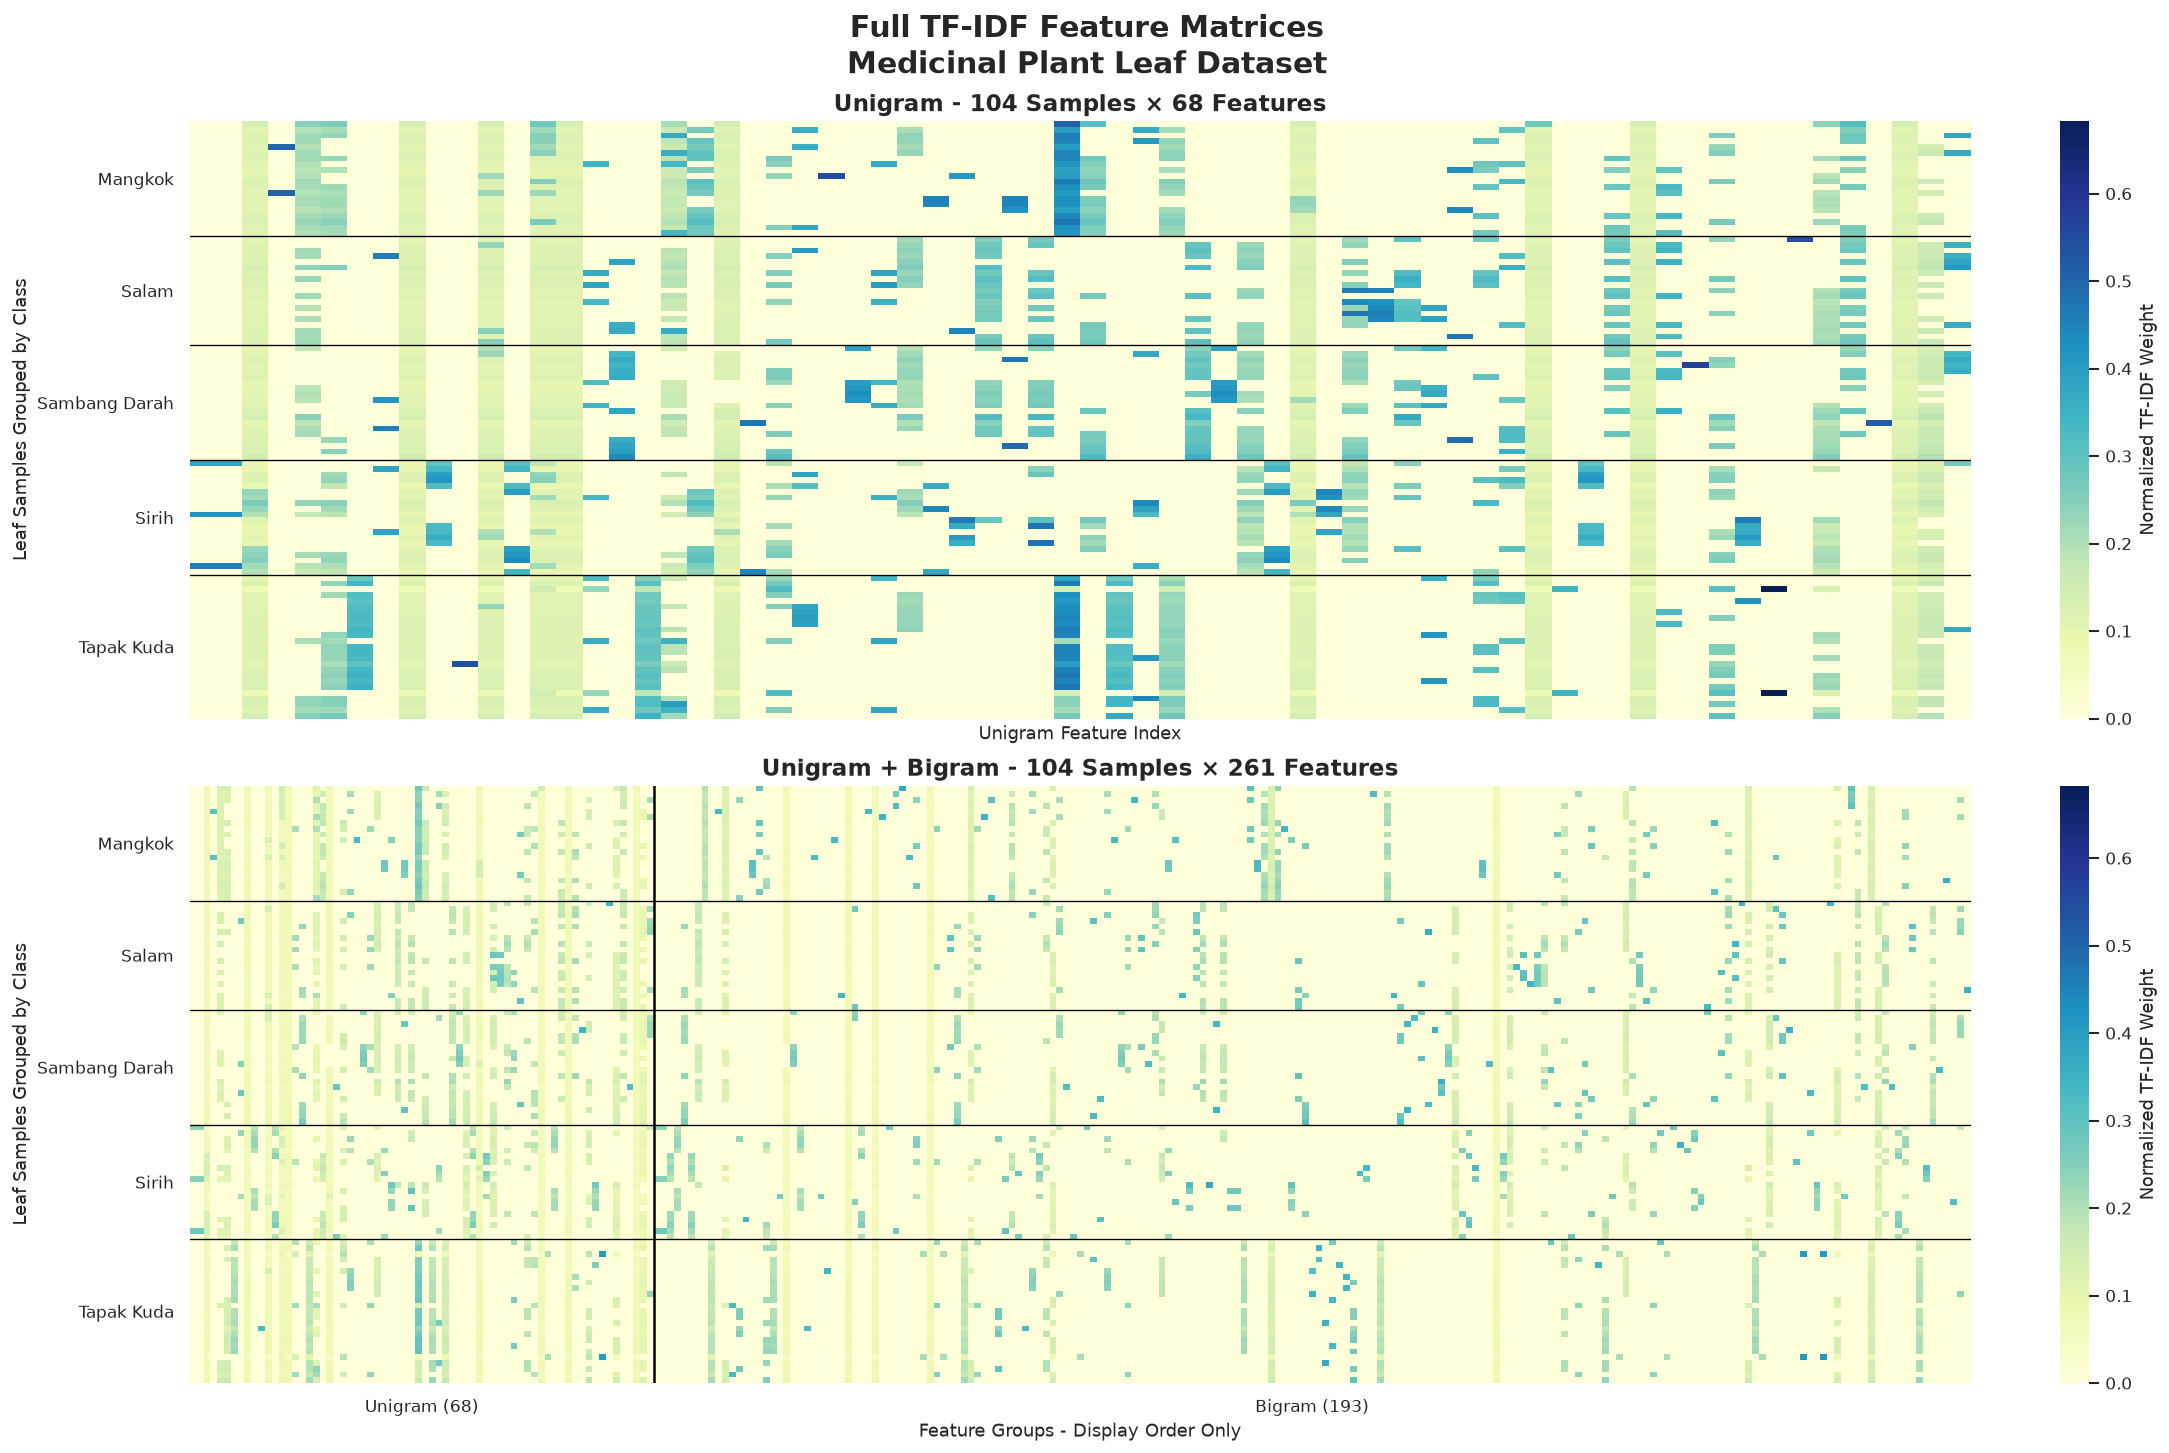

[SAVED] 72_full_tfidf_feature_matrices.png


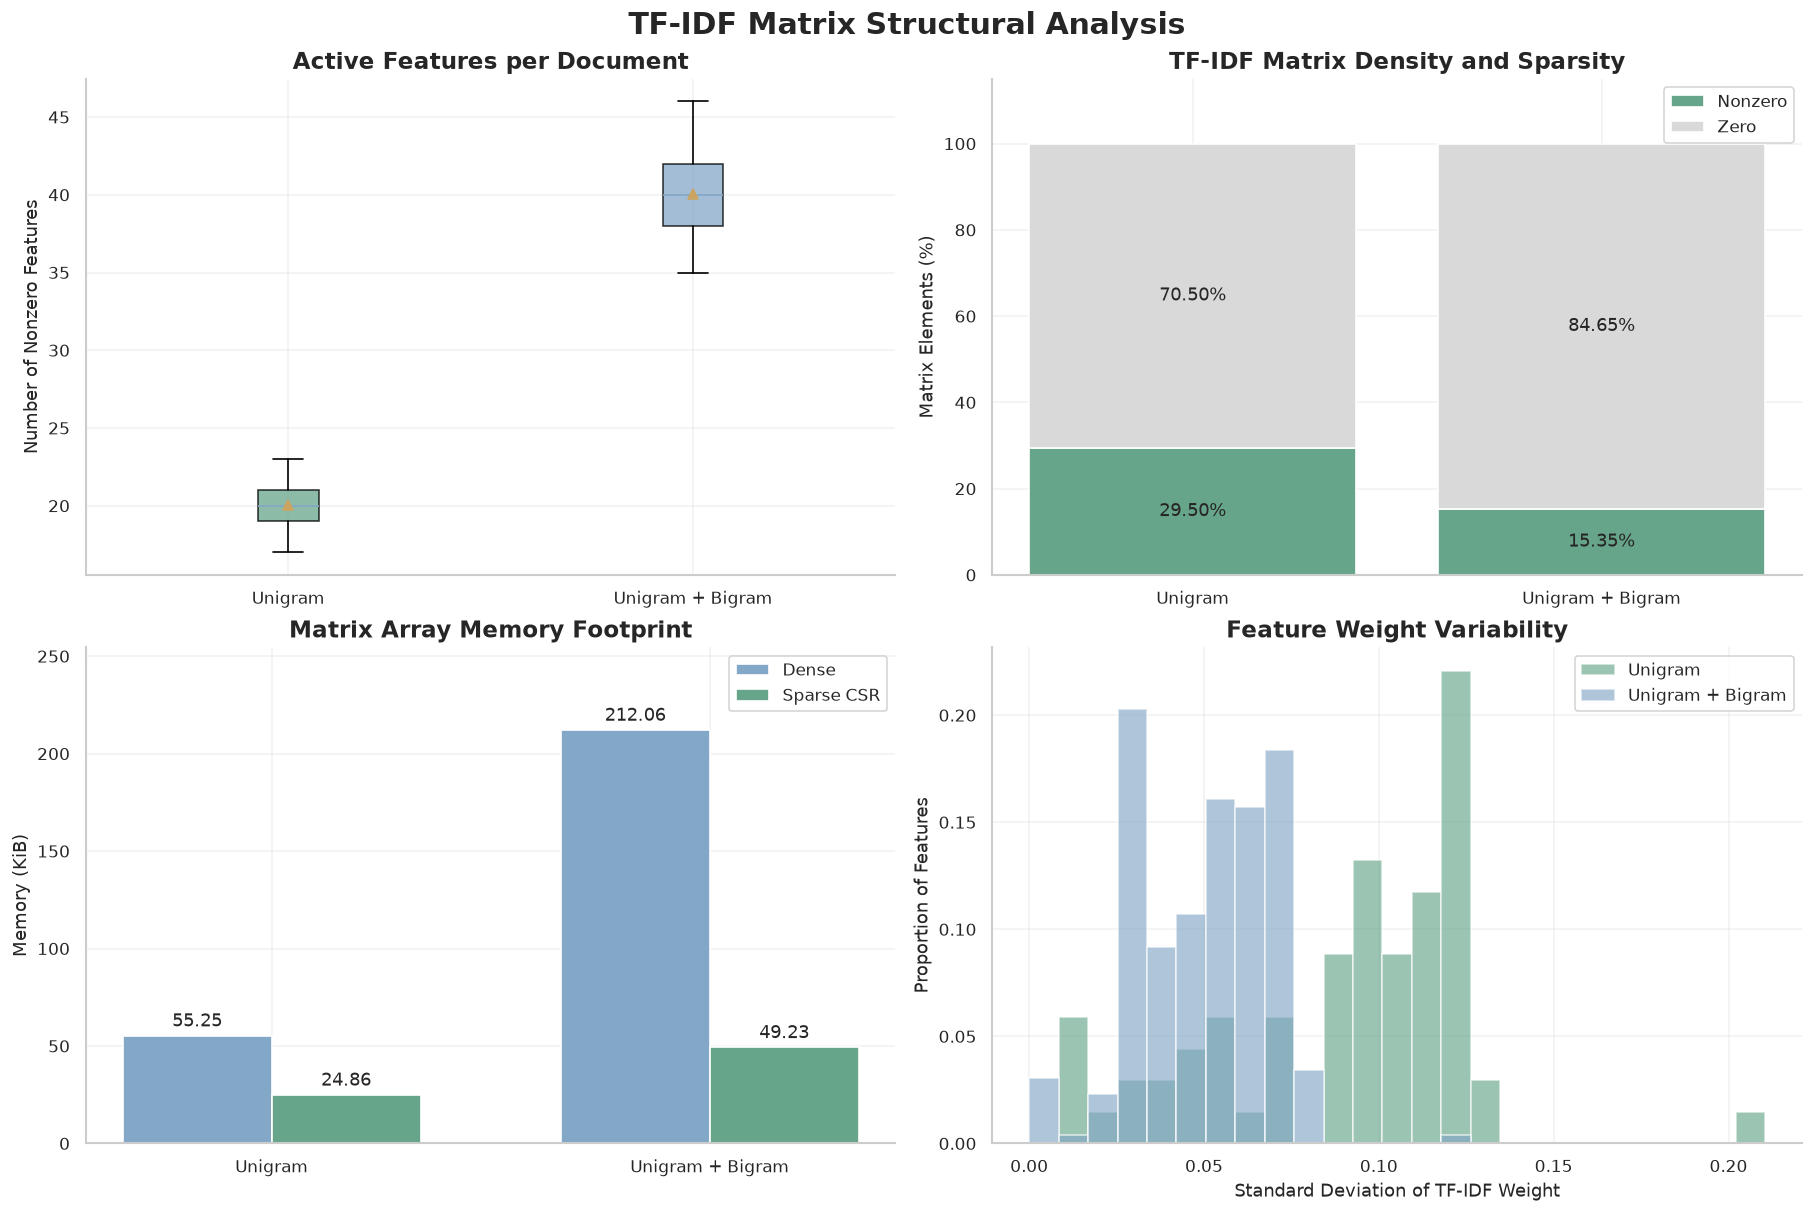

[SAVED] 73_tfidf_matrix_structural_analysis.png


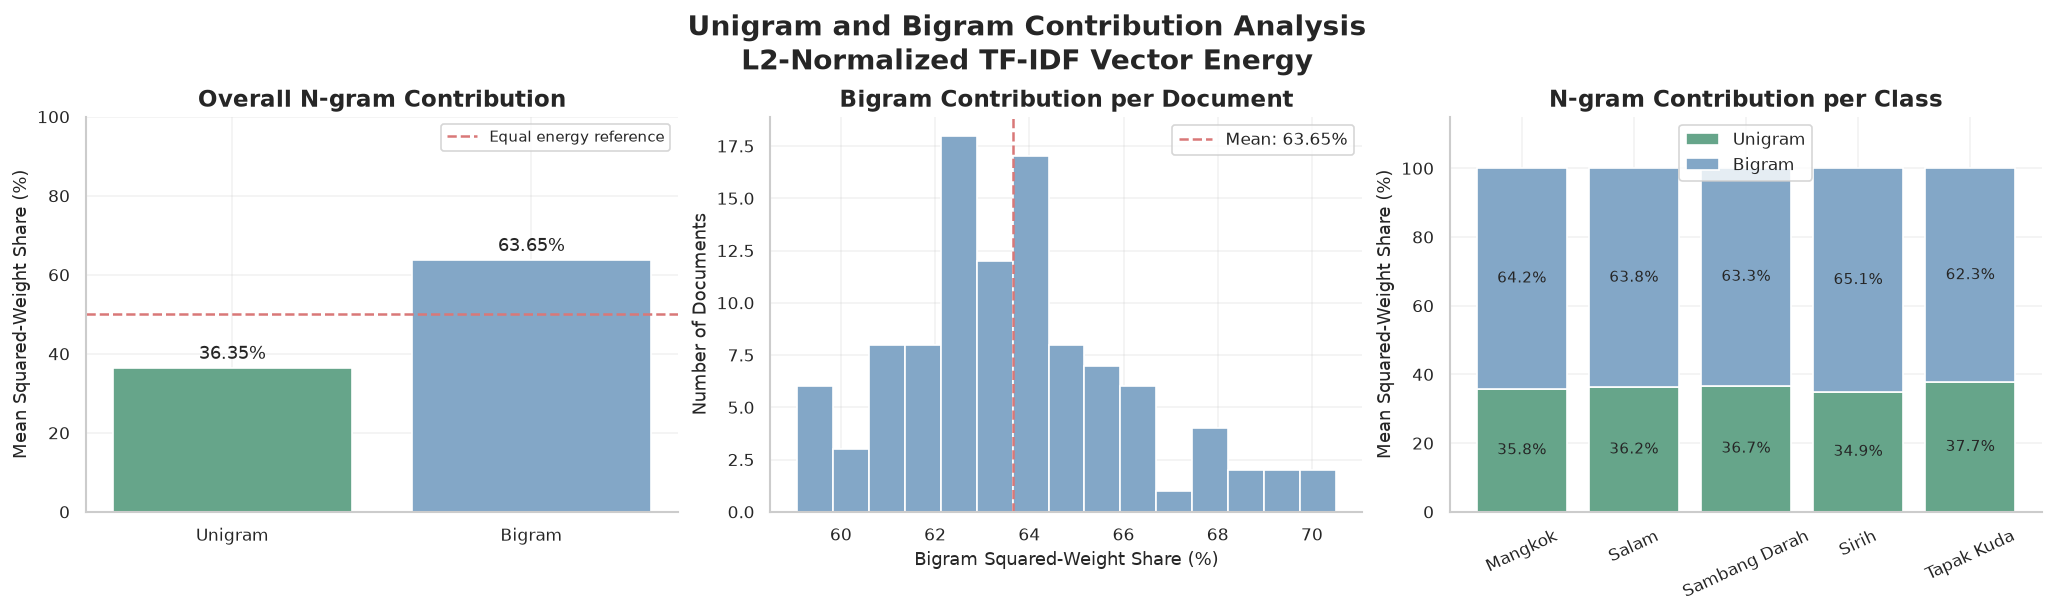

[SAVED] 74_tfidf_ngram_contribution_analysis.png


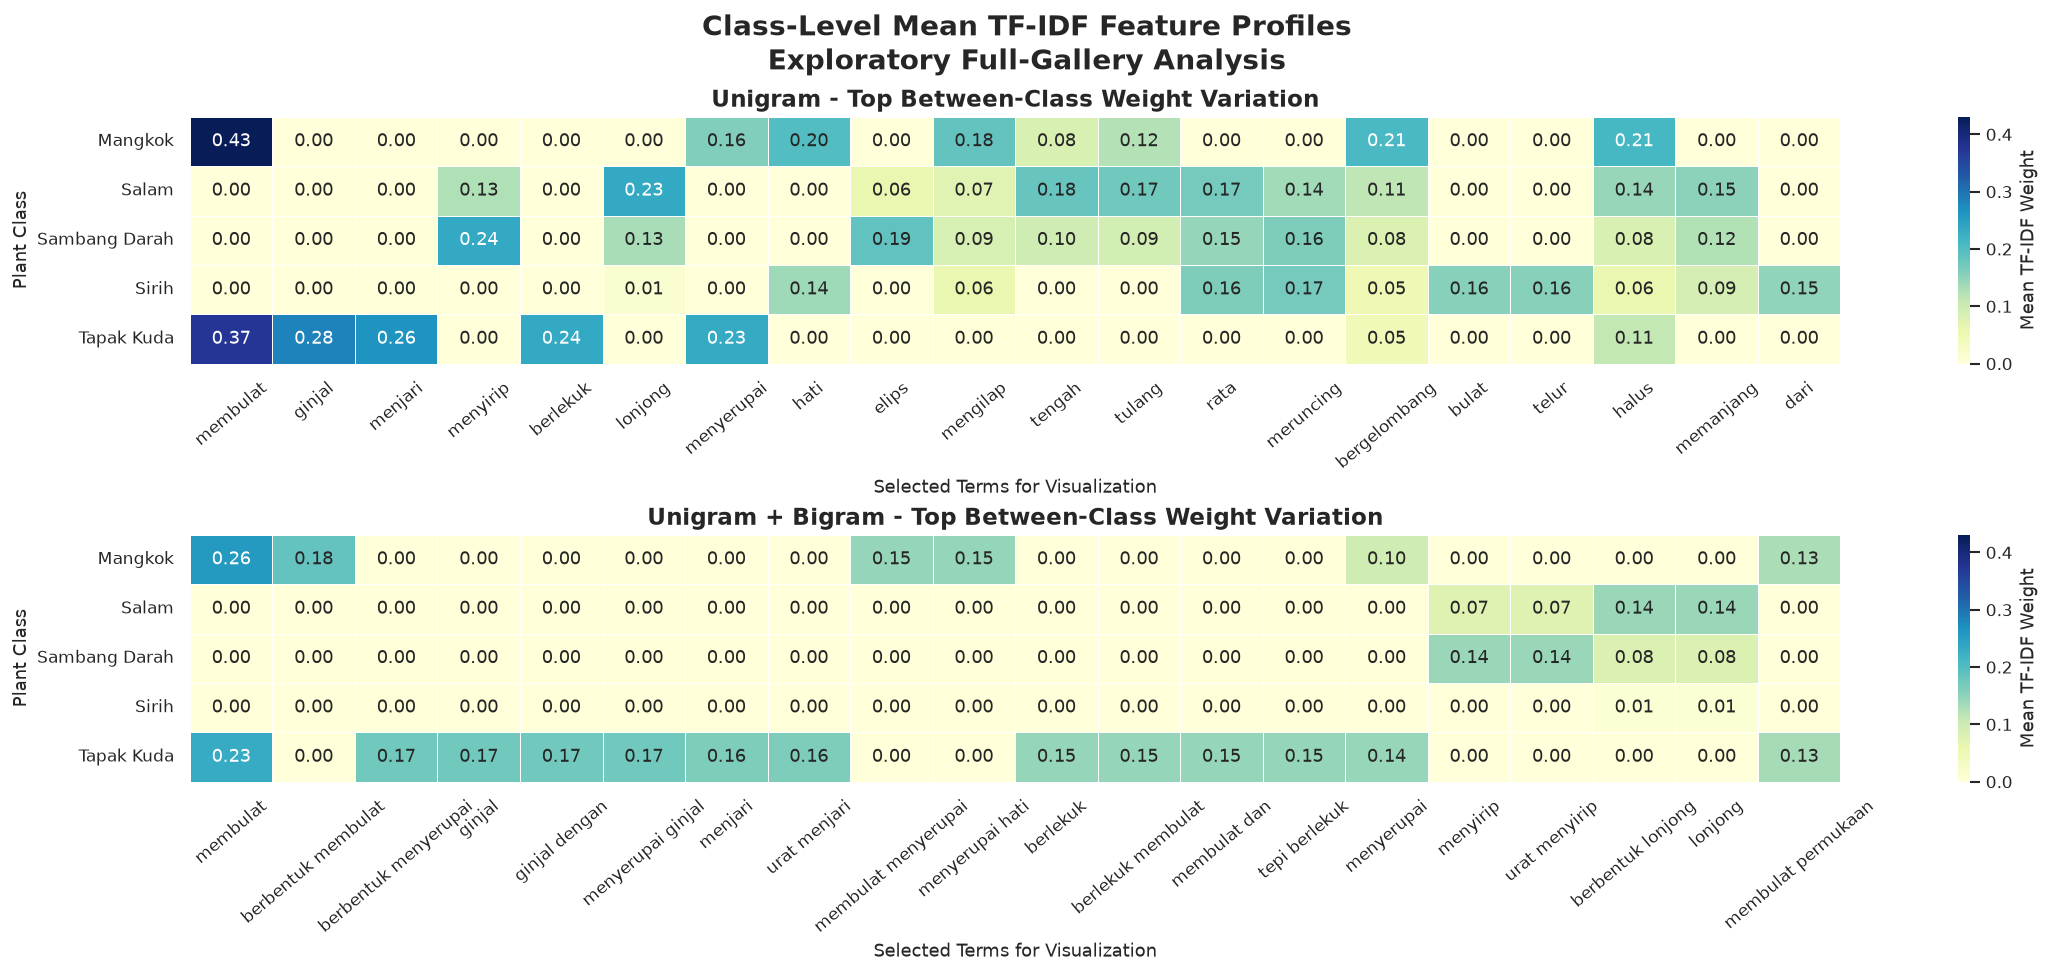

[SAVED] 75_class_mean_tfidf_feature_profiles.png

10. OVERALL MATRIX ANALYSIS SUMMARY
-----------------------------------------------------------------


,Indicator,Result
0,Total documents,104
1,Total configurations,2
2,Total classes,5
3,Baseline matrix shape,"(104, 68)"
4,Alternative matrix shape,"(104, 261)"
5,Baseline nonzero elements,2086
6,Alternative nonzero elements,4166
7,Baseline sparsity percent,70.503394
8,Alternative sparsity percent,84.652225
9,Mean unigram contribution percent,36.348408



11. SAVING MATRIX ANALYSIS REPORTS
-----------------------------------------------------------------
[SAVED] 248_tfidf_matrix_statistics.csv
[SAVED] 249_tfidf_document_statistics.csv
[SAVED] 250_tfidf_matrix_feature_statistics.csv
[SAVED] 251_tfidf_class_matrix_summary.csv
[SAVED] 252_tfidf_class_term_statistics.csv
[SAVED] 253_tfidf_ngram_contribution.csv
[SAVED] 254_tfidf_ngram_contribution_summary.csv
[SAVED] 255_tfidf_class_ngram_contribution.csv
[SAVED] 256_tfidf_matrix_analysis_validation.csv
[SAVED] 257_tfidf_matrix_analysis_summary.csv

FINAL TF-IDF MATRIX ANALYSIS SUMMARY

DATASET INFORMATION
-----------------------------------------------------------------
Total documents       : 104
Total classes         : 5

MATRIX DIMENSIONS
-----------------------------------------------------------------
Unigram matrix        : (104, 68)
Unigram + Bigram      : (104, 261)

MATRIX SPARSITY
-----------------------------------------------------------------

Unigram
Density       : 29.4966%

In [8]:
# ==================================================
# CELL 9 - TF-IDF MATRIX ANALYSIS
# ==================================================

from scipy.sparse import issparse

print("TF-IDF MATRIX ANALYSIS")
print("=" * 65)

TFIDF_MATRIX_ANALYSIS_COMPLETED = False


# ==================================================
# 1. VALIDATE PREVIOUS PROCESSING STAGES
# ==================================================

assert TEXT_DATASET_VALIDATION_COMPLETED is True
assert TFIDF_CONFIGURATION_COMPLETED is True
assert VOCABULARY_ANALYSIS_COMPLETED is True
assert TFIDF_FEATURE_EXTRACTION_COMPLETED is True

assert tfidf_extraction_validation_df["passed"].all()
assert tfidf_document_validation_df["passed"].all()
assert tfidf_idf_validation_df["passed"].all()

assert np.array_equal(
    tfidf_sample_ids,
    loaded_visual_sample_ids
)

assert np.array_equal(
    tfidf_labels,
    validated_text_labels
)

matrix_analysis_corpus_snapshot = list(
    validated_text_corpus
)

matrix_analysis_snapshots = {
    name: matrix.copy()
    for name, matrix in tfidf_matrices.items()
}

print("\n[PASS] Previous processing stages validated.")


# ==================================================
# 2. MATRIX ANALYSIS CONFIGURATION
# ==================================================

MATRIX_ANALYSIS_TOLERANCE = 1e-10

MATRIX_ANALYSIS_SCOPE = (
    "Exploratory Full-Gallery Analysis"
)

MATRIX_ANALYSIS_TOP_TERMS = 20

MATRIX_ANALYSIS_COLORS = {
    TFIDF_BASELINE_NAME: "#66A58A",
    TFIDF_ALTERNATIVE_NAME: "#83A7C7"
}

NGRAM_ANALYSIS_COLORS = {
    "Unigram": "#66A58A",
    "Bigram": "#83A7C7"
}

matrix_analysis_class_names = sorted(
    np.unique(tfidf_labels)
)

print("\n1. MATRIX ANALYSIS CONFIGURATION")
print("-" * 65)

print(f"Total documents : {text_n_samples}")
print(f"Analysis scope  : {MATRIX_ANALYSIS_SCOPE}")
print(f"Tolerance       : {MATRIX_ANALYSIS_TOLERANCE}")

print("[INFO] No TF-IDF refitting will be performed.")


# ==================================================
# 3. INITIALIZE ANALYSIS CONTAINERS
# ==================================================

matrix_statistics_records = []

matrix_document_records = []

matrix_feature_records = []

matrix_class_records = []

matrix_class_term_records = []

matrix_analysis_validation_records = []

tfidf_dense_matrices = {}

tfidf_class_mean_profiles = {}

tfidf_matrix_analysis_figure_paths = []


# ==================================================
# 4. ANALYZE EACH TF-IDF MATRIX
# ==================================================

print("\n2. TF-IDF MATRIX STATISTICS")
print("-" * 65)

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    matrix = tfidf_matrices[configuration_name]

    feature_names = tfidf_feature_names_by_config[
        configuration_name
    ]

    idf_weights = tfidf_idf_weights[
        configuration_name
    ]

    count_matrix = count_matrices[
        configuration_name
    ]

    # Dense representation is used only for analysis.
    # CSR remains the primary feature representation.

    dense_matrix = matrix.toarray()

    tfidf_dense_matrices[
        configuration_name
    ] = dense_matrix

    n_documents, n_features = matrix.shape

    total_elements = n_documents * n_features

    nonzero_elements = matrix.nnz

    zero_elements = total_elements - nonzero_elements

    density = nonzero_elements / total_elements

    sparsity = zero_elements / total_elements


    # --------------------------------------------------
    # A. Memory efficiency
    # --------------------------------------------------

    csr_memory_bytes = (
        matrix.data.nbytes
        + matrix.indices.nbytes
        + matrix.indptr.nbytes
    )

    dense_memory_bytes = dense_matrix.nbytes

    memory_reduction_percent = (
        1 - csr_memory_bytes / dense_memory_bytes
    ) * 100


    # --------------------------------------------------
    # B. Document-level statistics
    # --------------------------------------------------

    document_nonzero_counts = matrix.getnnz(axis=1)

    document_l1_norms = np.sum(
        np.abs(dense_matrix),
        axis=1
    )

    document_l2_norms = np.linalg.norm(
        dense_matrix,
        axis=1
    )

    document_maximum_weights = dense_matrix.max(
        axis=1
    )

    for row_index in range(n_documents):

        row_vector = dense_matrix[row_index]

        active_weights = row_vector[row_vector > 0]

        matrix_document_records.append({

            "configuration": configuration_name,

            "row_index": row_index,

            "sample_id": tfidf_sample_ids[row_index],

            "kelas": tfidf_labels[row_index],

            "nama_file": df_tfidf_metadata.iloc[
                row_index
            ]["nama_file"],

            "total_features": n_features,

            "nonzero_features": int(
                document_nonzero_counts[row_index]
            ),

            "zero_features": int(
                n_features
                - document_nonzero_counts[row_index]
            ),

            "density_percent": float(
                document_nonzero_counts[row_index]
                / n_features * 100
            ),

            "sparsity_percent": float(
                (
                    1
                    - document_nonzero_counts[row_index]
                    / n_features
                ) * 100
            ),

            "minimum_nonzero_weight": (
                float(active_weights.min())
                if active_weights.size > 0
                else np.nan
            ),

            "mean_nonzero_weight": (
                float(active_weights.mean())
                if active_weights.size > 0
                else np.nan
            ),

            "maximum_weight": float(
                document_maximum_weights[row_index]
            ),

            "l1_norm": float(
                document_l1_norms[row_index]
            ),

            "l2_norm": float(
                document_l2_norms[row_index]
            ),

            "squared_l2_norm": float(
                document_l2_norms[row_index] ** 2
            )
        })


    # --------------------------------------------------
    # C. Feature-level statistics
    # --------------------------------------------------

    feature_document_counts = matrix.getnnz(axis=0)

    feature_mean_weights = dense_matrix.mean(
        axis=0
    )

    feature_std_weights = dense_matrix.std(
        axis=0,
        ddof=0
    )

    feature_variance = dense_matrix.var(
        axis=0,
        ddof=0
    )

    for feature_index, term in enumerate(
        feature_names
    ):

        feature_values = dense_matrix[:, feature_index]

        active_values = feature_values[
            feature_values > 0
        ]

        matrix_feature_records.append({

            "configuration": configuration_name,

            "feature_index": feature_index,

            "term": term,

            "ngram_type": (
                "Bigram" if " " in term else "Unigram"
            ),

            "document_frequency": int(
                feature_document_counts[feature_index]
            ),

            "document_coverage_percent": float(
                feature_document_counts[feature_index]
                / n_documents * 100
            ),

            "idf_weight": float(
                idf_weights[feature_index]
            ),

            "mean_tfidf": float(
                feature_mean_weights[feature_index]
            ),

            "std_tfidf": float(
                feature_std_weights[feature_index]
            ),

            "variance_tfidf": float(
                feature_variance[feature_index]
            ),

            "minimum_tfidf": float(
                feature_values.min()
            ),

            "maximum_tfidf": float(
                feature_values.max()
            ),

            "mean_nonzero_tfidf": (
                float(active_values.mean())
                if active_values.size > 0
                else np.nan
            ),

            "mean_squared_weight": float(
                np.mean(feature_values ** 2)
            ),

            "constant_feature": bool(
                np.ptp(feature_values) == 0
            )
        })


    # --------------------------------------------------
    # D. Class-level feature statistics
    # --------------------------------------------------

    class_mean_rows = []

    for class_name in matrix_analysis_class_names:

        class_mask = tfidf_labels == class_name

        class_matrix = dense_matrix[class_mask]

        class_nonzero_counts = (
            document_nonzero_counts[class_mask]
        )

        class_mean_vector = class_matrix.mean(
            axis=0
        )

        class_mean_rows.append(
            class_mean_vector
        )

        class_document_frequency = (
            class_matrix > 0
        ).sum(axis=0)

        matrix_class_records.append({

            "configuration": configuration_name,

            "kelas": class_name,

            "number_of_documents": int(
                class_mask.sum()
            ),

            "feature_dimension": n_features,

            "unique_active_features": int(
                np.sum(
                    np.any(class_matrix > 0, axis=0)
                )
            ),

            "mean_nonzero_features": float(
                class_nonzero_counts.mean()
            ),

            "std_nonzero_features": float(
                class_nonzero_counts.std(ddof=0)
            ),

            "mean_density_percent": float(
                class_nonzero_counts.mean()
                / n_features * 100
            ),

            "mean_sparsity_percent": float(
                (
                    1
                    - class_nonzero_counts.mean()
                    / n_features
                ) * 100
            ),

            "mean_l2_norm": float(
                document_l2_norms[class_mask].mean()
            ),

            "class_mean_vector_l2_norm": float(
                np.linalg.norm(class_mean_vector)
            )
        })

        for feature_index, term in enumerate(
            feature_names
        ):

            matrix_class_term_records.append({

                "configuration": configuration_name,

                "kelas": class_name,

                "feature_index": feature_index,

                "term": term,

                "ngram_type": (
                    "Bigram" if " " in term
                    else "Unigram"
                ),

                "mean_tfidf": float(
                    class_mean_vector[feature_index]
                ),

                "document_frequency": int(
                    class_document_frequency[
                        feature_index
                    ]
                ),

                "document_coverage_percent": float(
                    class_document_frequency[
                        feature_index
                    ]
                    / class_mask.sum() * 100
                )
            })

    tfidf_class_mean_profiles[
        configuration_name
    ] = pd.DataFrame(

        class_mean_rows,

        index=matrix_analysis_class_names,

        columns=feature_names
    )


    # --------------------------------------------------
    # E. Overall matrix statistics
    # --------------------------------------------------

    matrix_statistics_records.append({

        "configuration": configuration_name,

        "number_of_documents": n_documents,

        "feature_dimension": n_features,

        "total_elements": total_elements,

        "nonzero_elements": nonzero_elements,

        "zero_elements": zero_elements,

        "density_percent": density * 100,

        "sparsity_percent": sparsity * 100,

        "minimum_weight": float(
            dense_matrix.min()
        ),

        "minimum_nonzero_weight": float(
            matrix.data.min()
        ),

        "maximum_weight": float(
            matrix.data.max()
        ),

        "mean_weight_all_elements": float(
            dense_matrix.mean()
        ),

        "mean_nonzero_weight": float(
            matrix.data.mean()
        ),

        "median_nonzero_weight": float(
            np.median(matrix.data)
        ),

        "std_nonzero_weight": float(
            matrix.data.std(ddof=0)
        ),

        "minimum_active_features": int(
            document_nonzero_counts.min()
        ),

        "maximum_active_features": int(
            document_nonzero_counts.max()
        ),

        "mean_active_features": float(
            document_nonzero_counts.mean()
        ),

        "minimum_l2_norm": float(
            document_l2_norms.min()
        ),

        "maximum_l2_norm": float(
            document_l2_norms.max()
        ),

        "minimum_feature_variance": float(
            feature_variance.min()
        ),

        "maximum_feature_variance": float(
            feature_variance.max()
        ),

        "constant_features": int(
            np.sum(
                np.ptp(dense_matrix, axis=0) == 0
            )
        ),

        "total_squared_weight": float(
            np.sum(dense_matrix ** 2)
        ),

        "empty_vectors": int(
            np.sum(document_nonzero_counts == 0)
        ),

        "csr_memory_bytes": csr_memory_bytes,

        "dense_memory_bytes": dense_memory_bytes,

        "csr_memory_kib": csr_memory_bytes / 1024,

        "dense_memory_kib": dense_memory_bytes / 1024,

        "memory_reduction_percent": (
            memory_reduction_percent
        ),

        "matrix_format": matrix.format,

        "data_type": str(matrix.dtype)
    })


    # --------------------------------------------------
    # F. Matrix validation
    # --------------------------------------------------

    count_support = count_matrix.copy()

    count_support.data = np.ones(
        count_support.nnz,
        dtype=np.int8
    )

    tfidf_support = matrix.copy()

    tfidf_support.data = np.ones(
        tfidf_support.nnz,
        dtype=np.int8
    )

    support_difference = (
        tfidf_support - count_support
    )

    support_difference.eliminate_zeros()

    class_counts = np.asarray([

        np.sum(tfidf_labels == class_name)

        for class_name in matrix_analysis_class_names
    ])

    weighted_class_mean = np.average(

        np.asarray(class_mean_rows),

        axis=0,

        weights=class_counts
    )

    checks = {

        "Correct matrix shape": (
            matrix.shape == (
                text_n_samples,
                len(feature_names)
            )
        ),

        "Sparse CSR format": (
            issparse(matrix)
            and matrix.format == "csr"
        ),

        "Float64 data type": (
            matrix.dtype == np.dtype(TEXT_FEATURE_DTYPE)
        ),

        "Finite positive stored weights": (
            np.isfinite(matrix.data).all()
            and np.all(matrix.data > 0)
        ),

        "No empty document vectors": (
            np.all(document_nonzero_counts > 0)
        ),

        "All document L2 norms equal one": (
            np.allclose(
                document_l2_norms,
                1.0,
                atol=MATRIX_ANALYSIS_TOLERANCE,
                rtol=0
            )
        ),

        "Count matrix support preserved": (
            support_difference.nnz == 0
        ),

        "Nonzero elements reconcile": (
            document_nonzero_counts.sum()
            == feature_document_counts.sum()
            == matrix.nnz
        ),

        "Density and sparsity reconcile": (
            np.isclose(
                density + sparsity,
                1.0,
                atol=MATRIX_ANALYSIS_TOLERANCE,
                rtol=0
            )
        ),

        "Total squared weights reconcile": (
            np.isclose(
                np.sum(dense_matrix ** 2),
                n_documents,
                atol=MATRIX_ANALYSIS_TOLERANCE,
                rtol=0
            )
        ),

        "All vocabulary features occur": (
            np.all(feature_document_counts > 0)
        ),

        "Class mean profiles reconcile": (
            np.allclose(
                weighted_class_mean,
                feature_mean_weights,
                atol=MATRIX_ANALYSIS_TOLERANCE,
                rtol=0
            )
        )
    }

    for check_name, passed in checks.items():

        matrix_analysis_validation_records.append({

            "configuration": configuration_name,

            "validation_check": check_name,

            "passed": bool(passed),

            "status": (
                "Passed" if passed else "Failed"
            )
        })

    print(f"\nConfiguration : {configuration_name}")

    print(f"Matrix shape  : {matrix.shape}")

    print(f"Sparsity      : {sparsity * 100:.4f}%")

    print(
        f"Mean active features: "
        f"{document_nonzero_counts.mean():.4f}"
    )

    print(
        f"CSR memory    : "
        f"{csr_memory_bytes / 1024:.4f} KiB"
    )

    print(
        f"Dense memory  : "
        f"{dense_memory_bytes / 1024:.4f} KiB"
    )

    print(
        f"Memory saving : "
        f"{memory_reduction_percent:.4f}%"
    )


# ==================================================
# 5. CREATE MATRIX ANALYSIS DATAFRAMES
# ==================================================

tfidf_matrix_statistics_df = pd.DataFrame(
    matrix_statistics_records
)

tfidf_document_statistics_df = pd.DataFrame(
    matrix_document_records
)

tfidf_matrix_feature_statistics_df = pd.DataFrame(
    matrix_feature_records
)

tfidf_class_matrix_summary_df = pd.DataFrame(
    matrix_class_records
)

tfidf_class_term_statistics_df = pd.DataFrame(
    matrix_class_term_records
)

print("\n3. OVERALL MATRIX STATISTICS")
print("-" * 65)

display(
    tfidf_matrix_statistics_df.round(6)
)

print("\n4. DOCUMENT-LEVEL STATISTICS")
print("-" * 65)

display(
    tfidf_document_statistics_df.head(10).round(6)
)

print("\n5. FEATURE-LEVEL STATISTICS")
print("-" * 65)

display(
    tfidf_matrix_feature_statistics_df.head(10).round(6)
)

print("\n6. CLASS-LEVEL MATRIX STATISTICS")
print("-" * 65)

display(
    tfidf_class_matrix_summary_df.round(6)
)


# ==================================================
# 6. ANALYZE UNIGRAM AND BIGRAM CONTRIBUTIONS
# ==================================================

# Contribution is defined as the sum of squared
# normalized weights in each n-gram group.
#
# For an L2-normalized vector:
#
# sum(unigram weights ** 2)
# + sum(bigram weights ** 2) = 1
#
# This is vector energy, not retrieval accuracy.

combined_dense_matrix = tfidf_dense_matrices[
    TFIDF_ALTERNATIVE_NAME
]

combined_unigram_mask = np.asarray([

    " " not in term

    for term in tfidf_bigram_feature_names
])

combined_bigram_mask = ~combined_unigram_mask

combined_unigram_energy = np.sum(

    combined_dense_matrix[
        :, combined_unigram_mask
    ] ** 2,

    axis=1
)

combined_bigram_energy = np.sum(

    combined_dense_matrix[
        :, combined_bigram_mask
    ] ** 2,

    axis=1
)

combined_total_energy = (

    combined_unigram_energy

    + combined_bigram_energy
)

unigram_energy_percent = (

    combined_unigram_energy
    / combined_total_energy * 100
)

bigram_energy_percent = (

    combined_bigram_energy
    / combined_total_energy * 100
)

tfidf_ngram_contribution_df = pd.DataFrame({

    "sample_id": tfidf_sample_ids,

    "kelas": tfidf_labels,

    "unigram_dimension": int(
        combined_unigram_mask.sum()
    ),

    "bigram_dimension": int(
        combined_bigram_mask.sum()
    ),

    "unigram_active_features": np.count_nonzero(

        combined_dense_matrix[
            :, combined_unigram_mask
        ],

        axis=1
    ),

    "bigram_active_features": np.count_nonzero(

        combined_dense_matrix[
            :, combined_bigram_mask
        ],

        axis=1
    ),

    "unigram_squared_weight":
        combined_unigram_energy,

    "bigram_squared_weight":
        combined_bigram_energy,

    "total_squared_weight":
        combined_total_energy,

    "unigram_contribution_percent":
        unigram_energy_percent,

    "bigram_contribution_percent":
        bigram_energy_percent
})

tfidf_ngram_contribution_summary_df = pd.DataFrame([

    {

        "ngram_type": "Unigram",

        "feature_dimension": int(
            combined_unigram_mask.sum()
        ),

        "mean_contribution_percent": float(
            unigram_energy_percent.mean()
        ),

        "std_contribution_percent": float(
            unigram_energy_percent.std(ddof=0)
        ),

        "minimum_contribution_percent": float(
            unigram_energy_percent.min()
        ),

        "median_contribution_percent": float(
            np.median(unigram_energy_percent)
        ),

        "maximum_contribution_percent": float(
            unigram_energy_percent.max()
        )
    },

    {

        "ngram_type": "Bigram",

        "feature_dimension": int(
            combined_bigram_mask.sum()
        ),

        "mean_contribution_percent": float(
            bigram_energy_percent.mean()
        ),

        "std_contribution_percent": float(
            bigram_energy_percent.std(ddof=0)
        ),

        "minimum_contribution_percent": float(
            bigram_energy_percent.min()
        ),

        "median_contribution_percent": float(
            np.median(bigram_energy_percent)
        ),

        "maximum_contribution_percent": float(
            bigram_energy_percent.max()
        )
    }
])

print("\n7. N-GRAM CONTRIBUTION ANALYSIS")
print("-" * 65)

display(
    tfidf_ngram_contribution_summary_df.round(6)
)


# ==================================================
# 7. CLASS-LEVEL N-GRAM CONTRIBUTION
# ==================================================

tfidf_class_ngram_contribution_df = (

    tfidf_ngram_contribution_df

    .groupby("kelas", sort=True)

    .agg(

        number_of_documents=(
            "sample_id", "count"
        ),

        mean_unigram_active_features=(
            "unigram_active_features", "mean"
        ),

        mean_bigram_active_features=(
            "bigram_active_features", "mean"
        ),

        mean_unigram_contribution_percent=(
            "unigram_contribution_percent", "mean"
        ),

        mean_bigram_contribution_percent=(
            "bigram_contribution_percent", "mean"
        ),

        minimum_bigram_contribution_percent=(
            "bigram_contribution_percent", "min"
        ),

        maximum_bigram_contribution_percent=(
            "bigram_contribution_percent", "max"
        )
    )

    .reset_index()
)

print("\n8. CLASS-LEVEL N-GRAM CONTRIBUTION")
print("-" * 65)

display(
    tfidf_class_ngram_contribution_df.round(6)
)


# ==================================================
# 8. CROSS-CONFIGURATION MATHEMATICAL VALIDATION
# ==================================================

# Extract unigram features from the combined matrix
# in the same order as the baseline vocabulary.

matrix_combined_lookup = {

    term: index

    for index, term in enumerate(
        tfidf_bigram_feature_names
    )
}

matrix_shared_unigram_indices = np.asarray([

    matrix_combined_lookup[term]

    for term in tfidf_feature_names
])

matrix_combined_unigram_block = (

    combined_dense_matrix[
        :, matrix_shared_unigram_indices
    ]
)

matrix_unigram_block_norms = np.linalg.norm(

    matrix_combined_unigram_block,

    axis=1,

    keepdims=True
)

assert np.all(matrix_unigram_block_norms > 0)

matrix_renormalized_unigram_block = (

    matrix_combined_unigram_block

    / matrix_unigram_block_norms
)

baseline_dense_matrix = tfidf_dense_matrices[
    TFIDF_BASELINE_NAME
]

unigram_block_maximum_difference = float(

    np.abs(

        matrix_renormalized_unigram_block

        - baseline_dense_matrix

    ).max()
)

# Compare original and current sparse matrices.

matrices_unchanged = True

for name in TFIDF_CONFIGURATION_ORDER:

    difference = (

        tfidf_matrices[name]

        - matrix_analysis_snapshots[name]
    )

    difference.eliminate_zeros()

    matrices_unchanged = (

        matrices_unchanged

        and difference.nnz == 0
    )

matrix_cross_configuration_checks = {

    "Unigram dimension consistent": (
        combined_unigram_mask.sum()
        == UNIGRAM_VOCABULARY_SIZE
    ),

    "Bigram dimension consistent": (
        combined_bigram_mask.sum()
        == BIGRAM_VOCABULARY_SIZE
    ),

    "Unigram and bigram energy sum to one": (
        np.allclose(
            combined_total_energy,
            1.0,
            atol=MATRIX_ANALYSIS_TOLERANCE,
            rtol=0
        )
    ),

    "Contribution percentages sum to 100": (
        np.allclose(
            unigram_energy_percent
            + bigram_energy_percent,
            100.0,
            atol=MATRIX_ANALYSIS_TOLERANCE,
            rtol=0
        )
    ),

    "Renormalized unigram matches baseline": (
        np.allclose(
            matrix_renormalized_unigram_block,
            baseline_dense_matrix,
            atol=MATRIX_ANALYSIS_TOLERANCE,
            rtol=0
        )
    ),

    "Original TF-IDF matrices unchanged": (
        matrices_unchanged
    ),

    "Original corpus unchanged": (
        validated_text_corpus
        == matrix_analysis_corpus_snapshot
    ),

    "Image-text alignment preserved": (
        np.array_equal(
            tfidf_sample_ids,
            loaded_visual_sample_ids
        )
    )
}

for check_name, passed in (
    matrix_cross_configuration_checks.items()
):

    matrix_analysis_validation_records.append({

        "configuration": "Cross Configuration",

        "validation_check": check_name,

        "passed": bool(passed),

        "status": (
            "Passed" if passed else "Failed"
        )
    })

tfidf_matrix_analysis_validation_df = pd.DataFrame(
    matrix_analysis_validation_records
)

assert tfidf_matrix_analysis_validation_df[
    "passed"
].all()

print("\n9. MATRIX ANALYSIS VALIDATION")
print("-" * 65)

display(tfidf_matrix_analysis_validation_df)

print(
    f"Maximum renormalized unigram error: "
    f"{unigram_block_maximum_difference:.12e}"
)

print("[PASS] All matrix analysis checks passed.")


# ==================================================
# 9. VISUALIZATION HELPER
# ==================================================

def save_tfidf_matrix_analysis_figure(
    fig,
    filename
):

    output_path = (
        TEXT_FEATURE_FIGURES_DIR / filename
    )

    fig.savefig(

        output_path,

        dpi=300,

        bbox_inches="tight"
    )

    tfidf_matrix_analysis_figure_paths.append(
        output_path
    )

    plt.show()

    plt.close(fig)

    print(f"[SAVED] {filename}")


# ==================================================
# 10. VISUALIZE FULL TF-IDF FEATURE MATRICES
# ==================================================

# Sort rows by class for visualization only.
# The stored matrices are not reordered.

matrix_visualization_order = np.argsort(

    tfidf_labels,

    kind="stable"
)

matrix_sorted_labels = tfidf_labels[
    matrix_visualization_order
]

matrix_class_boundaries = np.flatnonzero(

    matrix_sorted_labels[1:]
    != matrix_sorted_labels[:-1]

) + 1

matrix_class_starts = np.r_[
    0,
    matrix_class_boundaries
]

matrix_class_ends = np.r_[
    matrix_class_boundaries,
    text_n_samples
]

matrix_class_centers = (

    matrix_class_starts
    + matrix_class_ends

) / 2

matrix_class_tick_labels = matrix_sorted_labels[
    matrix_class_starts
]

# Put unigram columns first and bigram columns second
# in the combined heatmap for easier interpretation.

combined_visualization_column_order = np.r_[

    np.flatnonzero(combined_unigram_mask),

    np.flatnonzero(combined_bigram_mask)
]

matrix_heatmap_maximum = max(

    matrix.data.max()

    for matrix in tfidf_matrices.values()
)

fig, axes = plt.subplots(

    2, 1,

    figsize=(18, 12),

    constrained_layout=True
)

for ax, configuration_name in zip(

    axes,

    TFIDF_CONFIGURATION_ORDER
):

    plot_matrix = tfidf_dense_matrices[
        configuration_name
    ][matrix_visualization_order]

    if configuration_name == TFIDF_ALTERNATIVE_NAME:

        plot_matrix = plot_matrix[
            :, combined_visualization_column_order
        ]

    sns.heatmap(

        plot_matrix,

        cmap="YlGnBu",

        vmin=0,

        vmax=matrix_heatmap_maximum,

        xticklabels=False,

        yticklabels=False,

        cbar_kws={
            "label": "Normalized TF-IDF Weight"
        },

        ax=ax
    )

    for boundary in matrix_class_boundaries:

        ax.axhline(

            boundary,

            color="black",

            linewidth=0.8
        )

    ax.set_yticks(matrix_class_centers)

    ax.set_yticklabels(

        matrix_class_tick_labels,

        rotation=0
    )

    if configuration_name == TFIDF_ALTERNATIVE_NAME:

        ax.axvline(

            UNIGRAM_VOCABULARY_SIZE,

            color="black",

            linewidth=1.5
        )

        ax.set_xticks([

            UNIGRAM_VOCABULARY_SIZE / 2,

            UNIGRAM_VOCABULARY_SIZE
            + BIGRAM_VOCABULARY_SIZE / 2
        ])

        ax.set_xticklabels([

            f"Unigram ({UNIGRAM_VOCABULARY_SIZE})",

            f"Bigram ({BIGRAM_VOCABULARY_SIZE})"
        ])

        ax.set_xlabel(
            "Feature Groups - Display Order Only"
        )

    else:

        ax.set_xlabel("Unigram Feature Index")

    ax.set_ylabel("Leaf Samples Grouped by Class")

    ax.set_title(

        f"{configuration_name} - "

        f"{plot_matrix.shape[0]} Samples × "

        f"{plot_matrix.shape[1]} Features"
    )

fig.suptitle(

    "Full TF-IDF Feature Matrices\n"

    "Medicinal Plant Leaf Dataset",

    fontsize=18,

    fontweight="bold"
)

save_tfidf_matrix_analysis_figure(

    fig,

    "72_full_tfidf_feature_matrices.png"
)


# ==================================================
# 11. VISUALIZE MATRIX CHARACTERISTICS
# ==================================================

fig, axes = plt.subplots(

    2, 2,

    figsize=(15, 10),

    constrained_layout=True
)

plot_labels = [
    "Unigram",
    "Unigram + Bigram"
]

plot_colors = [
    "#66A58A",
    "#83A7C7"
]


# --------------------------------------------------
# A. Active features per document
# --------------------------------------------------

ax = axes[0, 0]

active_feature_data = [

    tfidf_matrices[name].getnnz(axis=1)

    for name in TFIDF_CONFIGURATION_ORDER
]

boxplot = ax.boxplot(

    active_feature_data,

    patch_artist=True,

    showmeans=True
)

for patch, color in zip(
    boxplot["boxes"],
    plot_colors
):

    patch.set_facecolor(color)

    patch.set_alpha(0.75)

ax.set_xticks([1, 2])

ax.set_xticklabels(plot_labels)

ax.set_title("Active Features per Document")

ax.set_ylabel("Number of Nonzero Features")


# --------------------------------------------------
# B. Density and sparsity
# --------------------------------------------------

ax = axes[0, 1]

density_values = tfidf_matrix_statistics_df[
    "density_percent"
].to_numpy()

sparsity_values = tfidf_matrix_statistics_df[
    "sparsity_percent"
].to_numpy()

density_bars = ax.bar(

    plot_labels,

    density_values,

    color="#66A58A",

    label="Nonzero"
)

sparsity_bars = ax.bar(

    plot_labels,

    sparsity_values,

    bottom=density_values,

    color="#D9D9D9",

    label="Zero"
)

ax.bar_label(

    density_bars,

    fmt="%.2f%%",

    label_type="center"
)

ax.bar_label(

    sparsity_bars,

    fmt="%.2f%%",

    label_type="center"
)

ax.set_ylim(0, 115)

ax.set_title("TF-IDF Matrix Density and Sparsity")

ax.set_ylabel("Matrix Elements (%)")

ax.legend()


# --------------------------------------------------
# C. Memory efficiency
# --------------------------------------------------

ax = axes[1, 0]

positions = np.arange(2)

bar_width = 0.34

dense_bars = ax.bar(

    positions - bar_width / 2,

    tfidf_matrix_statistics_df[
        "dense_memory_kib"
    ],

    width=bar_width,

    color="#83A7C7",

    label="Dense"
)

csr_bars = ax.bar(

    positions + bar_width / 2,

    tfidf_matrix_statistics_df[
        "csr_memory_kib"
    ],

    width=bar_width,

    color="#66A58A",

    label="Sparse CSR"
)

ax.bar_label(

    dense_bars,

    fmt="%.2f",

    padding=3
)

ax.bar_label(

    csr_bars,

    fmt="%.2f",

    padding=3
)

ax.set_xticks(positions)

ax.set_xticklabels(plot_labels)

ax.set_title("Matrix Array Memory Footprint")

ax.set_ylabel("Memory (KiB)")

ax.legend()

ax.margins(y=0.20)


# --------------------------------------------------
# D. Feature-level standard deviation
# --------------------------------------------------

ax = axes[1, 1]

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    feature_std = (

        tfidf_matrix_feature_statistics_df.loc[

            tfidf_matrix_feature_statistics_df[
                "configuration"
            ].eq(configuration_name),

            "std_tfidf"
        ]
    )

    ax.hist(

        feature_std,

        bins=np.linspace(

            0,

            tfidf_matrix_feature_statistics_df[
                "std_tfidf"
            ].max() * 1.02,

            26
        ),

        weights=np.full(

            len(feature_std),

            1.0 / len(feature_std)
        ),

        color=MATRIX_ANALYSIS_COLORS[
            configuration_name
        ],

        alpha=0.65,

        edgecolor="white",

        label=configuration_name
    )

ax.set_title("Feature Weight Variability")

ax.set_xlabel("Standard Deviation of TF-IDF Weight")

ax.set_ylabel("Proportion of Features")

ax.legend()

fig.suptitle(

    "TF-IDF Matrix Structural Analysis",

    fontsize=18,

    fontweight="bold"
)

save_tfidf_matrix_analysis_figure(

    fig,

    "73_tfidf_matrix_structural_analysis.png"
)


# ==================================================
# 12. VISUALIZE N-GRAM CONTRIBUTIONS
# ==================================================

fig, axes = plt.subplots(

    1, 3,

    figsize=(17, 5),

    constrained_layout=True
)


# --------------------------------------------------
# A. Overall mean squared-weight contribution
# --------------------------------------------------

ax = axes[0]

bars = ax.bar(

    tfidf_ngram_contribution_summary_df[
        "ngram_type"
    ],

    tfidf_ngram_contribution_summary_df[
        "mean_contribution_percent"
    ],

    color=[
        "#66A58A",
        "#83A7C7"
    ]
)

ax.bar_label(

    bars,

    fmt="%.2f%%",

    padding=3
)

ax.axhline(

    50,

    color="#D97878",

    linestyle="--",

    label="Equal energy reference"
)

ax.set_ylim(0, 100)

ax.set_ylabel("Mean Squared-Weight Share (%)")

ax.set_title("Overall N-gram Contribution")

ax.legend(fontsize=9)


# --------------------------------------------------
# B. Bigram energy distribution
# --------------------------------------------------

ax = axes[1]

ax.hist(

    bigram_energy_percent,

    bins=15,

    color="#83A7C7",

    edgecolor="white"
)

ax.axvline(

    bigram_energy_percent.mean(),

    color="#D97878",

    linestyle="--",

    label=(

        f"Mean: "

        f"{bigram_energy_percent.mean():.2f}%"
    )
)

ax.set_title("Bigram Contribution per Document")

ax.set_xlabel("Bigram Squared-Weight Share (%)")

ax.set_ylabel("Number of Documents")

ax.legend()


# --------------------------------------------------
# C. N-gram contribution by class
# --------------------------------------------------

ax = axes[2]

class_energy_df = (
    tfidf_class_ngram_contribution_df
)

class_unigram_values = class_energy_df[
    "mean_unigram_contribution_percent"
]

class_bigram_values = class_energy_df[
    "mean_bigram_contribution_percent"
]

unigram_bars = ax.bar(

    class_energy_df["kelas"],

    class_unigram_values,

    color="#66A58A",

    label="Unigram"
)

bigram_bars = ax.bar(

    class_energy_df["kelas"],

    class_bigram_values,

    bottom=class_unigram_values,

    color="#83A7C7",

    label="Bigram"
)

ax.bar_label(

    unigram_bars,

    fmt="%.1f%%",

    label_type="center",

    fontsize=9
)

ax.bar_label(

    bigram_bars,

    fmt="%.1f%%",

    label_type="center",

    fontsize=9
)

ax.set_ylim(0, 115)

ax.set_title("N-gram Contribution per Class")

ax.set_ylabel("Mean Squared-Weight Share (%)")

ax.tick_params(

    axis="x",

    labelrotation=25
)

ax.legend()

fig.suptitle(

    "Unigram and Bigram Contribution Analysis\n"

    "L2-Normalized TF-IDF Vector Energy",

    fontsize=17,

    fontweight="bold"
)

save_tfidf_matrix_analysis_figure(

    fig,

    "74_tfidf_ngram_contribution_analysis.png"
)


# ==================================================
# 13. VISUALIZE CLASS MEAN FEATURE PROFILES
# ==================================================

# Select terms by variation between observed
# class mean profiles for visualization only.
#
# No features are removed from the matrices.

fig, axes = plt.subplots(

    2, 1,

    figsize=(17, 8),

    constrained_layout=True
)

matrix_selected_profile_terms = {}

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    profile_df = tfidf_class_mean_profiles[
        configuration_name
    ]

    between_class_range = (

        profile_df.max(axis=0)

        - profile_df.min(axis=0)
    )

    selected_terms = (

        between_class_range

        .sort_values(

            ascending=False,

            kind="stable"
        )

        .head(MATRIX_ANALYSIS_TOP_TERMS)

        .index.tolist()
    )

    matrix_selected_profile_terms[
        configuration_name
    ] = selected_terms

profile_color_maximum = max(

    tfidf_class_mean_profiles[name][

        matrix_selected_profile_terms[name]

    ].to_numpy().max()

    for name in TFIDF_CONFIGURATION_ORDER
)

for ax, configuration_name in zip(

    axes,

    TFIDF_CONFIGURATION_ORDER
):

    profile_df = tfidf_class_mean_profiles[
        configuration_name
    ]

    selected_terms = matrix_selected_profile_terms[
        configuration_name
    ]

    sns.heatmap(

        profile_df[selected_terms],

        annot=True,

        fmt=".2f",

        cmap="YlGnBu",

        vmin=0,

        vmax=profile_color_maximum,

        linewidths=0.5,

        cbar_kws={

            "label": "Mean TF-IDF Weight"
        },

        ax=ax
    )

    ax.set_title(

        f"{configuration_name} - "

        "Top Between-Class Weight Variation"
    )

    ax.set_xlabel("Selected Terms for Visualization")

    ax.set_ylabel("Plant Class")

    ax.tick_params(

        axis="x",

        labelrotation=40
    )

    ax.tick_params(

        axis="y",

        labelrotation=0
    )

fig.suptitle(

    "Class-Level Mean TF-IDF Feature Profiles\n"

    "Exploratory Full-Gallery Analysis",

    fontsize=17,

    fontweight="bold"
)

save_tfidf_matrix_analysis_figure(

    fig,

    "75_class_mean_tfidf_feature_profiles.png"
)


# ==================================================
# 14. CREATE OVERALL MATRIX ANALYSIS SUMMARY
# ==================================================

matrix_analysis_total_checks = len(
    tfidf_matrix_analysis_validation_df
)

matrix_analysis_passed_checks = int(

    tfidf_matrix_analysis_validation_df[
        "passed"
    ].sum()
)

matrix_analysis_all_passed = (

    matrix_analysis_total_checks

    == matrix_analysis_passed_checks
)

tfidf_matrix_analysis_summary_df = pd.DataFrame([

    ("Total documents", text_n_samples),

    ("Total configurations", len(TFIDF_CONFIGS)),

    ("Total classes", len(matrix_analysis_class_names)),

    ("Baseline matrix shape", str(tfidf_matrix.shape)),

    (
        "Alternative matrix shape",
        str(tfidf_bigram_matrix.shape)
    ),

    ("Baseline nonzero elements", tfidf_matrix.nnz),

    (
        "Alternative nonzero elements",
        tfidf_bigram_matrix.nnz
    ),

    (
        "Baseline sparsity percent",

        float(

            tfidf_matrix_statistics_df.loc[

                tfidf_matrix_statistics_df[
                    "configuration"
                ].eq(TFIDF_BASELINE_NAME),

                "sparsity_percent"
            ].iloc[0]
        )
    ),

    (
        "Alternative sparsity percent",

        float(

            tfidf_matrix_statistics_df.loc[

                tfidf_matrix_statistics_df[
                    "configuration"
                ].eq(TFIDF_ALTERNATIVE_NAME),

                "sparsity_percent"
            ].iloc[0]
        )
    ),

    (
        "Mean unigram contribution percent",
        float(unigram_energy_percent.mean())
    ),

    (
        "Mean bigram contribution percent",
        float(bigram_energy_percent.mean())
    ),

    (
        "Minimum bigram contribution percent",
        float(bigram_energy_percent.min())
    ),

    (
        "Maximum bigram contribution percent",
        float(bigram_energy_percent.max())
    ),

    (
        "Maximum renormalized unigram difference",
        unigram_block_maximum_difference
    ),

    (
        "Document-level analysis records",
        len(tfidf_document_statistics_df)
    ),

    (
        "Feature-level analysis records",
        len(tfidf_matrix_feature_statistics_df)
    ),

    (
        "Total matrix validation checks",
        matrix_analysis_total_checks
    ),

    (
        "Matrix validation checks passed",
        matrix_analysis_passed_checks
    ),

    (
        "Matrix validation checks failed",
        matrix_analysis_total_checks
        - matrix_analysis_passed_checks
    ),

    ("Analysis scope", MATRIX_ANALYSIS_SCOPE),

    ("Contribution method", "Squared L2 Vector Energy"),

    ("Original matrices unchanged", matrices_unchanged),

    ("TF-IDF refitted", False),

    ("Feature selection applied", False),

    ("Samples removed", 0),

    ("Descriptions modified", 0),

    ("Generated figures", len(
        tfidf_matrix_analysis_figure_paths
    )),

    ("Retrieval performance evaluated", False),

    ("TF-IDF matrix analysis completed",
     matrix_analysis_all_passed)

], columns=["Indicator", "Result"])

print("\n10. OVERALL MATRIX ANALYSIS SUMMARY")
print("-" * 65)

display(tfidf_matrix_analysis_summary_df)


# ==================================================
# 15. SAVE MATRIX ANALYSIS REPORTS
# ==================================================

tfidf_matrix_analysis_reports = {

    "248_tfidf_matrix_statistics.csv":
        tfidf_matrix_statistics_df,

    "249_tfidf_document_statistics.csv":
        tfidf_document_statistics_df,

    "250_tfidf_matrix_feature_statistics.csv":
        tfidf_matrix_feature_statistics_df,

    "251_tfidf_class_matrix_summary.csv":
        tfidf_class_matrix_summary_df,

    "252_tfidf_class_term_statistics.csv":
        tfidf_class_term_statistics_df,

    "253_tfidf_ngram_contribution.csv":
        tfidf_ngram_contribution_df,

    "254_tfidf_ngram_contribution_summary.csv":
        tfidf_ngram_contribution_summary_df,

    "255_tfidf_class_ngram_contribution.csv":
        tfidf_class_ngram_contribution_df,

    "256_tfidf_matrix_analysis_validation.csv":
        tfidf_matrix_analysis_validation_df,

    "257_tfidf_matrix_analysis_summary.csv":
        tfidf_matrix_analysis_summary_df
}

print("\n11. SAVING MATRIX ANALYSIS REPORTS")
print("-" * 65)

for filename, dataframe in (
    tfidf_matrix_analysis_reports.items()
):

    dataframe.to_csv(

        METRICS_DIR / filename,

        index=False,

        encoding="utf-8-sig",

        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ==================================================
# 16. FINAL MATRIX ANALYSIS VALIDATION
# ==================================================

assert matrix_analysis_all_passed

assert matrix_analysis_total_checks == 32

assert tfidf_matrix_analysis_validation_df[
    "passed"
].all()

assert len(tfidf_document_statistics_df) == (

    text_n_samples * len(TFIDF_CONFIGS)
)

assert len(tfidf_matrix_feature_statistics_df) == (

    UNIGRAM_VOCABULARY_SIZE

    + COMBINED_VOCABULARY_SIZE
)

assert len(tfidf_ngram_contribution_df) == (
    text_n_samples
)

assert np.allclose(

    combined_total_energy,

    1.0,

    atol=MATRIX_ANALYSIS_TOLERANCE,

    rtol=0
)

assert matrices_unchanged

assert validated_text_corpus == (
    matrix_analysis_corpus_snapshot
)

assert np.array_equal(

    tfidf_sample_ids,

    loaded_visual_sample_ids
)

assert len(
    tfidf_matrix_analysis_figure_paths
) == 4

assert all(

    path.is_file()

    and path.stat().st_size > 0

    for path in tfidf_matrix_analysis_figure_paths
)

assert all(

    (METRICS_DIR / filename).is_file()

    and (METRICS_DIR / filename).stat().st_size > 0

    for filename in tfidf_matrix_analysis_reports
)

TFIDF_MATRIX_ANALYSIS_COMPLETED = True


# ==================================================
# 17. FINAL MATRIX ANALYSIS SUMMARY
# ==================================================

print("\n" + "=" * 65)

print("FINAL TF-IDF MATRIX ANALYSIS SUMMARY")

print("=" * 65)

print("\nDATASET INFORMATION")
print("-" * 65)

print(f"Total documents       : {text_n_samples}")

print(
    f"Total classes         : "
    f"{len(matrix_analysis_class_names)}"
)

print("\nMATRIX DIMENSIONS")
print("-" * 65)

print(f"Unigram matrix        : {tfidf_matrix.shape}")

print(f"Unigram + Bigram      : {tfidf_bigram_matrix.shape}")

print("\nMATRIX SPARSITY")
print("-" * 65)

for _, row in tfidf_matrix_statistics_df.iterrows():

    print(f"\n{row['configuration']}")

    print(
        f"Density       : "
        f"{row['density_percent']:.4f}%"
    )

    print(
        f"Sparsity      : "
        f"{row['sparsity_percent']:.4f}%"
    )

    print(
        f"CSR memory    : "
        f"{row['csr_memory_kib']:.4f} KiB"
    )

    print(
        f"Dense memory  : "
        f"{row['dense_memory_kib']:.4f} KiB"
    )

    print(
        f"Memory saving : "
        f"{row['memory_reduction_percent']:.4f}%"
    )

print("\nN-GRAM CONTRIBUTION")
print("-" * 65)

print(

    f"Mean unigram contribution: "

    f"{unigram_energy_percent.mean():.4f}%"
)

print(

    f"Mean bigram contribution : "

    f"{bigram_energy_percent.mean():.4f}%"
)

print(

    f"Minimum bigram contribution: "

    f"{bigram_energy_percent.min():.4f}%"
)

print(

    f"Maximum bigram contribution: "

    f"{bigram_energy_percent.max():.4f}%"
)

print("\nVALIDATION RESULTS")
print("-" * 65)

print(

    f"Matrix validation     : "

    f"{matrix_analysis_passed_checks}/"

    f"{matrix_analysis_total_checks}"
)

print(

    f"Document records      : "

    f"{len(tfidf_document_statistics_df)}"
)

print(

    f"Feature records       : "

    f"{len(tfidf_matrix_feature_statistics_df)}"
)

print(

    f"Generated reports     : "

    f"{len(tfidf_matrix_analysis_reports)}"
)

print(

    f"Generated figures     : "

    f"{len(tfidf_matrix_analysis_figure_paths)}"
)

print("\n[PASS] Matrix structure analysis completed.")

print("[PASS] Document-level statistics calculated.")

print("[PASS] Feature-level statistics calculated.")

print("[PASS] Class-level feature profiles generated.")

print("[PASS] Unigram and bigram contributions validated.")

print("[PASS] Sparse matrix memory analysis completed.")

print("[PASS] Original TF-IDF matrices preserved.")

print("[PASS] Image-text alignment preserved.")

print("[PASS] All matrix analysis reports saved.")

print("\n[INFO] No vectorizers were refitted.")

print("[INFO] No features were removed.")

print("[INFO] No documents were modified.")

print("[INFO] Column reordering is for visualization only.")

print("[INFO] N-gram contribution is not retrieval accuracy.")

print("[INFO] Class-level analysis is exploratory.")

print("[INFO] Independent retrieval evaluation remains pending.")

print("\nTF-IDF matrix analysis completed successfully!")

print("\nNext cell: Cell 10 - Important Term Visualization")

IMPORTANT TERM VISUALIZATION

[PASS] Previous processing stages validated.

1. ANALYSIS CONFIGURATION
-----------------------------------------------------------------
Total documents     : 104
Total classes       : 5
Analysis scope      : Exploratory Full-Gallery Analysis
Top global terms    : 15
Top terms per class : 10
[INFO] No feature selection will be applied.

2. GLOBAL IMPORTANT TERMS
-----------------------------------------------------------------


,configuration,global_rank,term,ngram_type,document_frequency,idf_weight,mean_tfidf
0,Unigram,1,membulat,Unigram,45,1.825319,0.172894
1,Unigram,2,daun,Unigram,104,1.000000,0.135032
2,Unigram,3,berbentuk,Unigram,104,1.000000,0.127763
3,Unigram,4,dan,Unigram,104,1.000000,0.127654
4,Unigram,5,permukaan,Unigram,104,1.000000,0.123405
5,Unigram,6,halus,Unigram,63,1.495077,0.120640
6,Unigram,7,hijau,Unigram,99,1.048790,0.118248
7,Unigram,8,tampak,Unigram,104,1.000000,0.118203
8,Unigram,9,berwarna,Unigram,104,1.000000,0.116862
9,Unigram,10,dengan,Unigram,104,1.000000,0.116862



3. CLASS-LEVEL IMPORTANT TERMS
-----------------------------------------------------------------


,configuration,kelas,class_rank,term,class_mean_tfidf,class_coverage_percent
0,Unigram,Mangkok,1,membulat,0.430756,100.000000
1,Unigram,Mangkok,2,halus,0.211745,100.000000
2,Unigram,Mangkok,3,bergelombang,0.207923,100.000000
3,Unigram,Mangkok,4,hati,0.199508,70.000000
4,Unigram,Mangkok,5,mengilap,0.184356,70.000000
10,Unigram,Salam,1,lonjong,0.233951,84.210526
11,Unigram,Salam,2,tengah,0.181847,63.157895
12,Unigram,Salam,3,tulang,0.173559,63.157895
13,Unigram,Salam,4,rata,0.171085,57.894737
14,Unigram,Salam,5,memanjang,0.152176,52.631579



4. DISCRIMINATIVE TERM ANALYSIS
-----------------------------------------------------------------


,configuration,kelas,discriminative_rank,term,class_mean_tfidf,other_mean_tfidf,discriminative_score,observed_class_specific
0,Unigram,Mangkok,1,membulat,0.430756,0.111499,0.319258,False
1,Unigram,Mangkok,2,hati,0.199508,0.032864,0.166644,False
2,Unigram,Mangkok,3,bergelombang,0.207923,0.069733,0.138190,False
3,Unigram,Mangkok,4,mengilap,0.184356,0.050872,0.133483,False
4,Unigram,Mangkok,5,halus,0.211745,0.098948,0.112797,False
10,Unigram,Salam,1,lonjong,0.233951,0.033996,0.199955,False
11,Unigram,Salam,2,tengah,0.181847,0.042454,0.139393,False
12,Unigram,Salam,3,tulang,0.173559,0.050596,0.122963,False
13,Unigram,Salam,4,relatif,0.116315,0.000000,0.116315,True
14,Unigram,Salam,5,memanjang,0.152176,0.050146,0.102030,False


... (8 outputs left out)

[INFO] Artifact flags require manual review.
[INFO] No descriptions or features were modified.

8. HIGH-RANKED POTENTIAL ARTIFACTS
-----------------------------------------------------------------


,configuration,kelas,discriminative_rank,term,discriminative_score
0,Unigram + Bigram,Mangkok,8,membulat permukaan,0.089003
1,Unigram + Bigram,Sirih,1,berbentuk berbentuk,0.107518



9. REPRESENTATIVE DOCUMENT TERMS
-----------------------------------------------------------------


,configuration,kelas,rank,term,tfidf_weight,potential_writing_artifact
0,Unigram,Mangkok,1,membulat,0.509266,False
1,Unigram,Mangkok,2,tulang,0.318991,False
2,Unigram,Mangkok,3,mengilap,0.309687,False
3,Unigram,Mangkok,4,daun,0.279001,False
4,Unigram,Mangkok,5,tampak,0.279001,False
5,Unigram,Salam,1,tipis,0.546529,False
6,Unigram,Salam,2,runcing,0.298506,False
7,Unigram,Salam,3,sedang,0.272769,False
8,Unigram,Salam,4,memanjang,0.268271,False
9,Unigram,Salam,5,tengah,0.263950,False


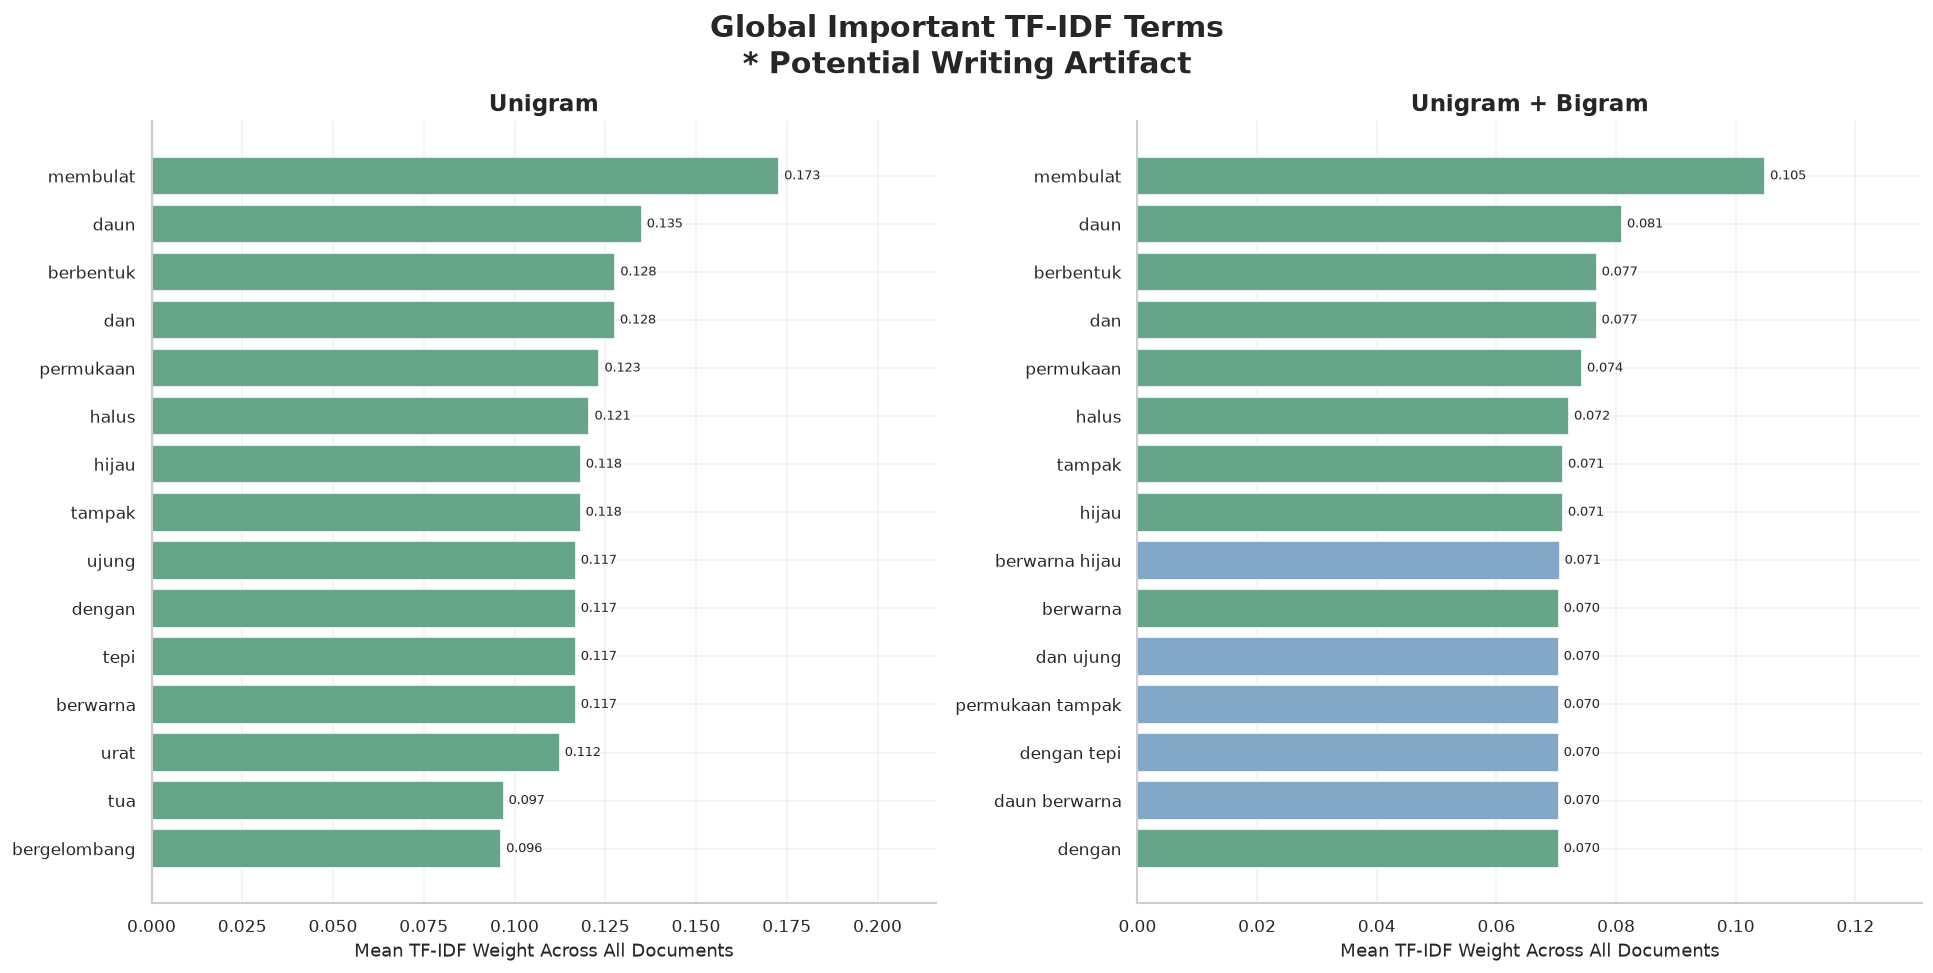

[SAVED] 76_global_important_tfidf_terms.png


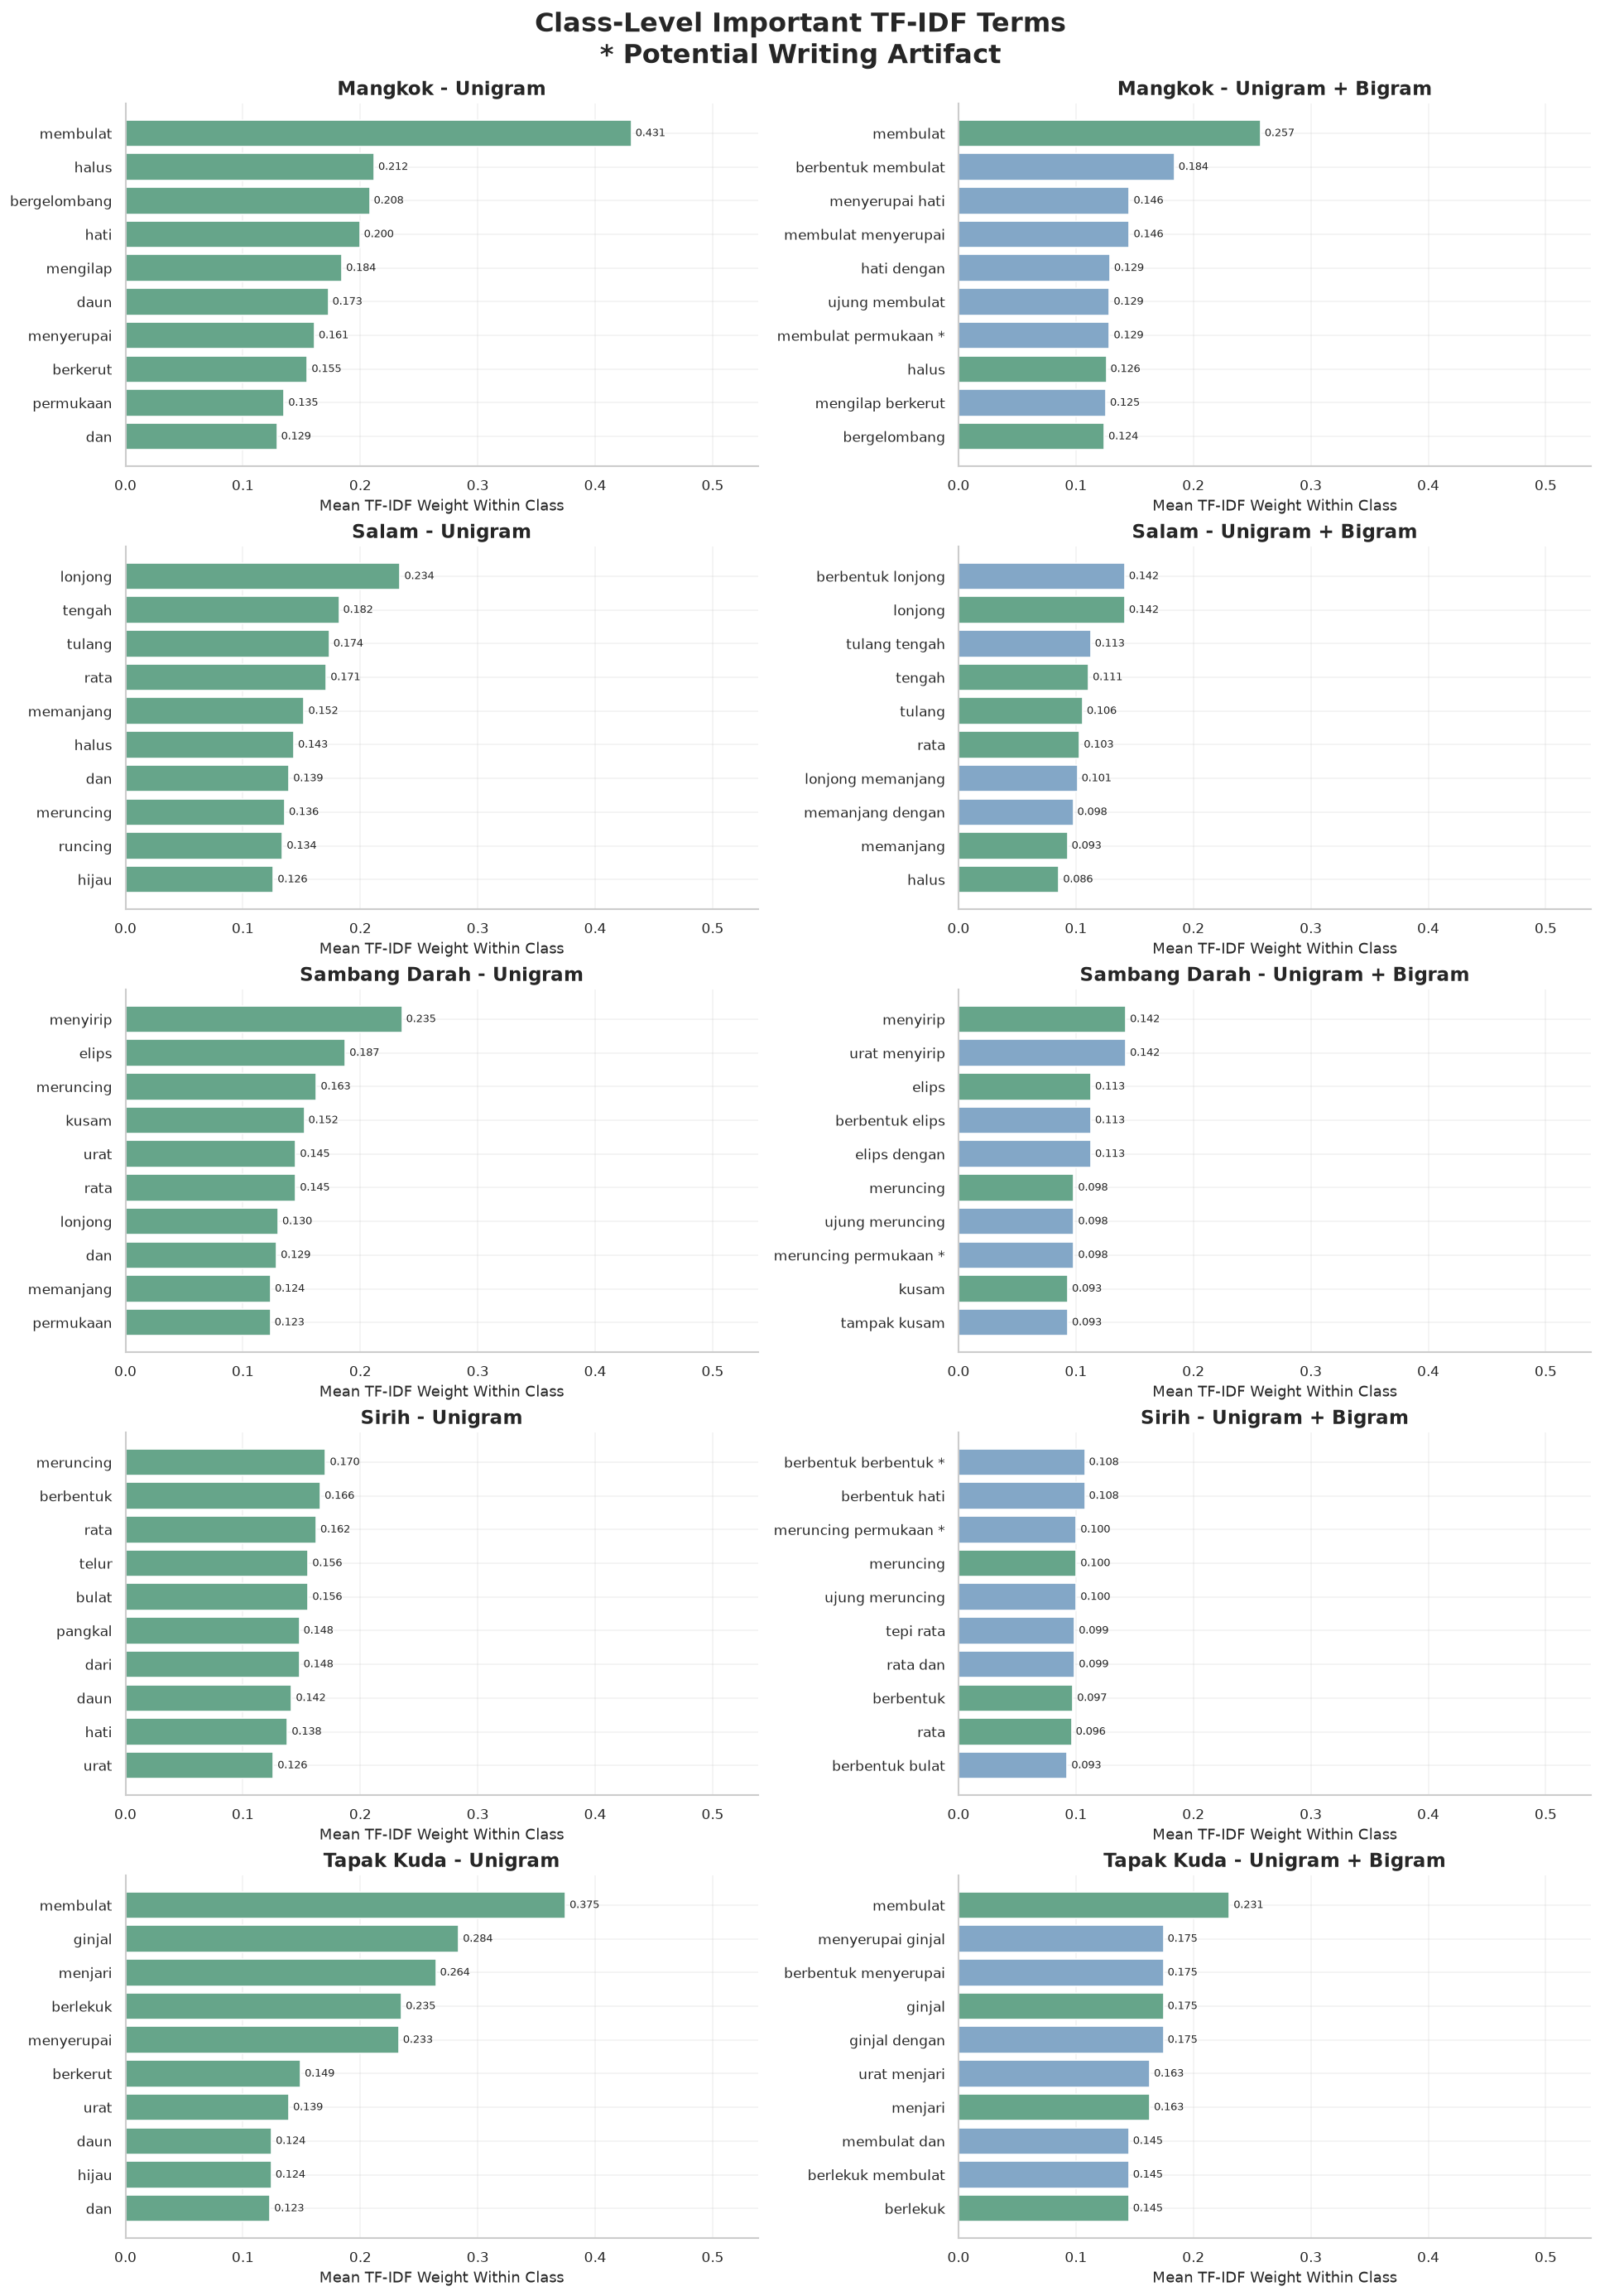

[SAVED] 77_class_level_important_tfidf_terms.png


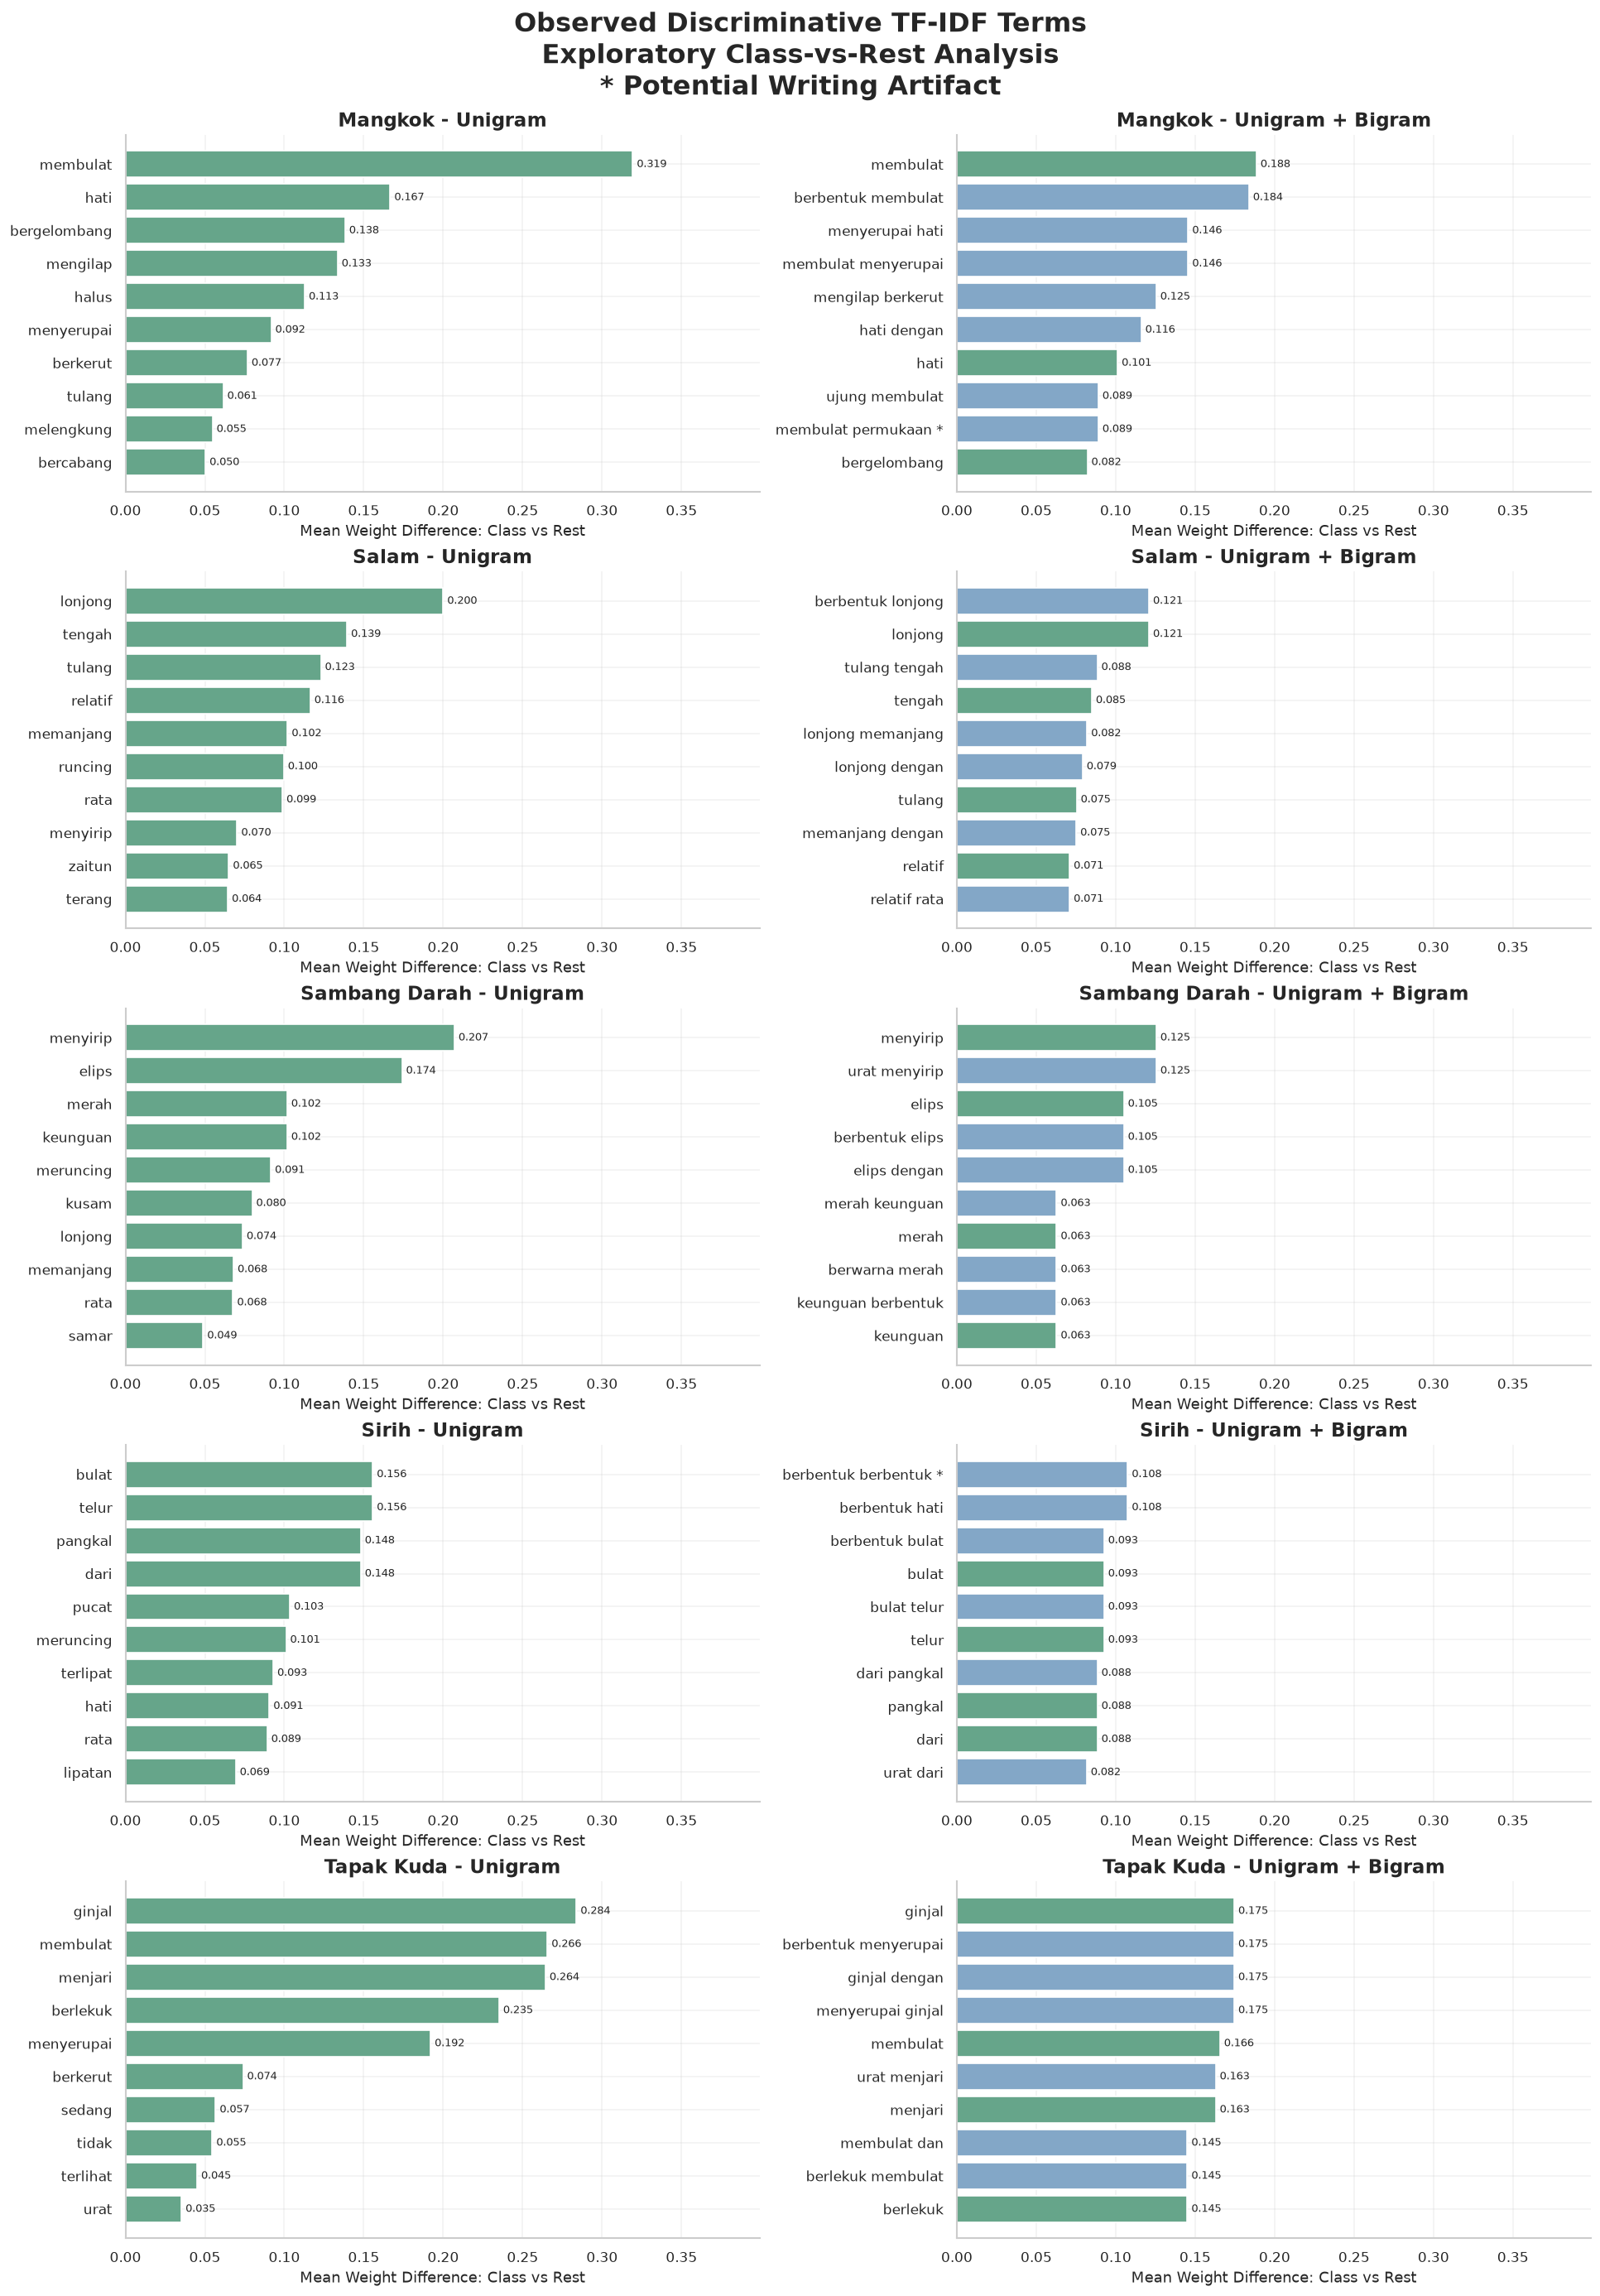

[SAVED] 78_discriminative_tfidf_terms.png


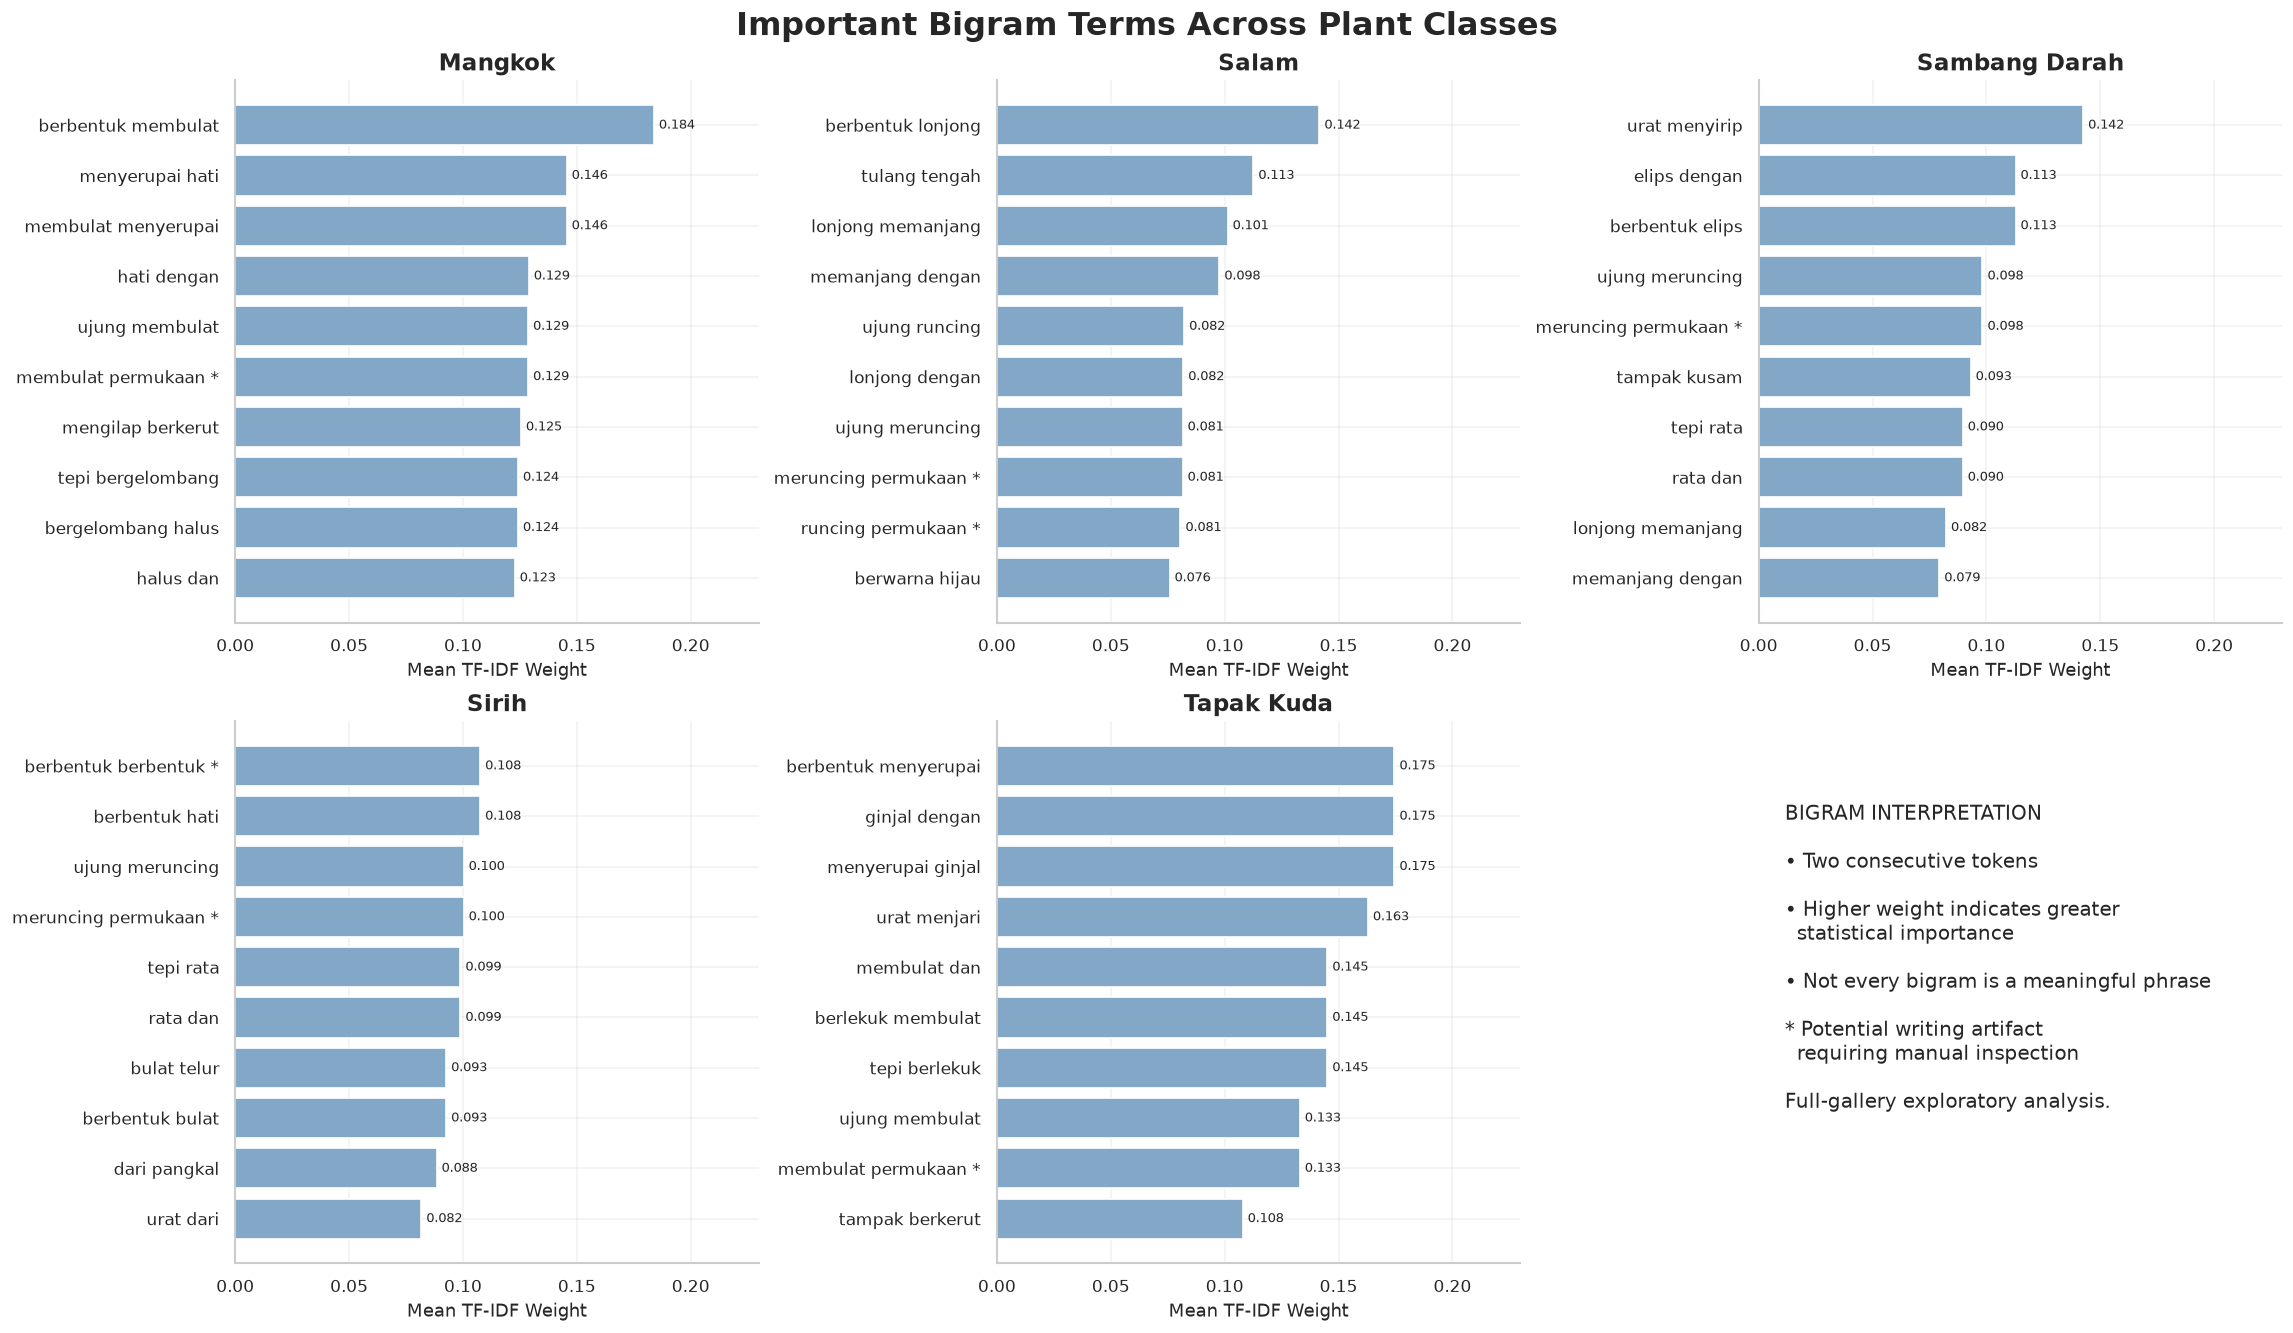

[SAVED] 79_important_bigrams_per_class.png


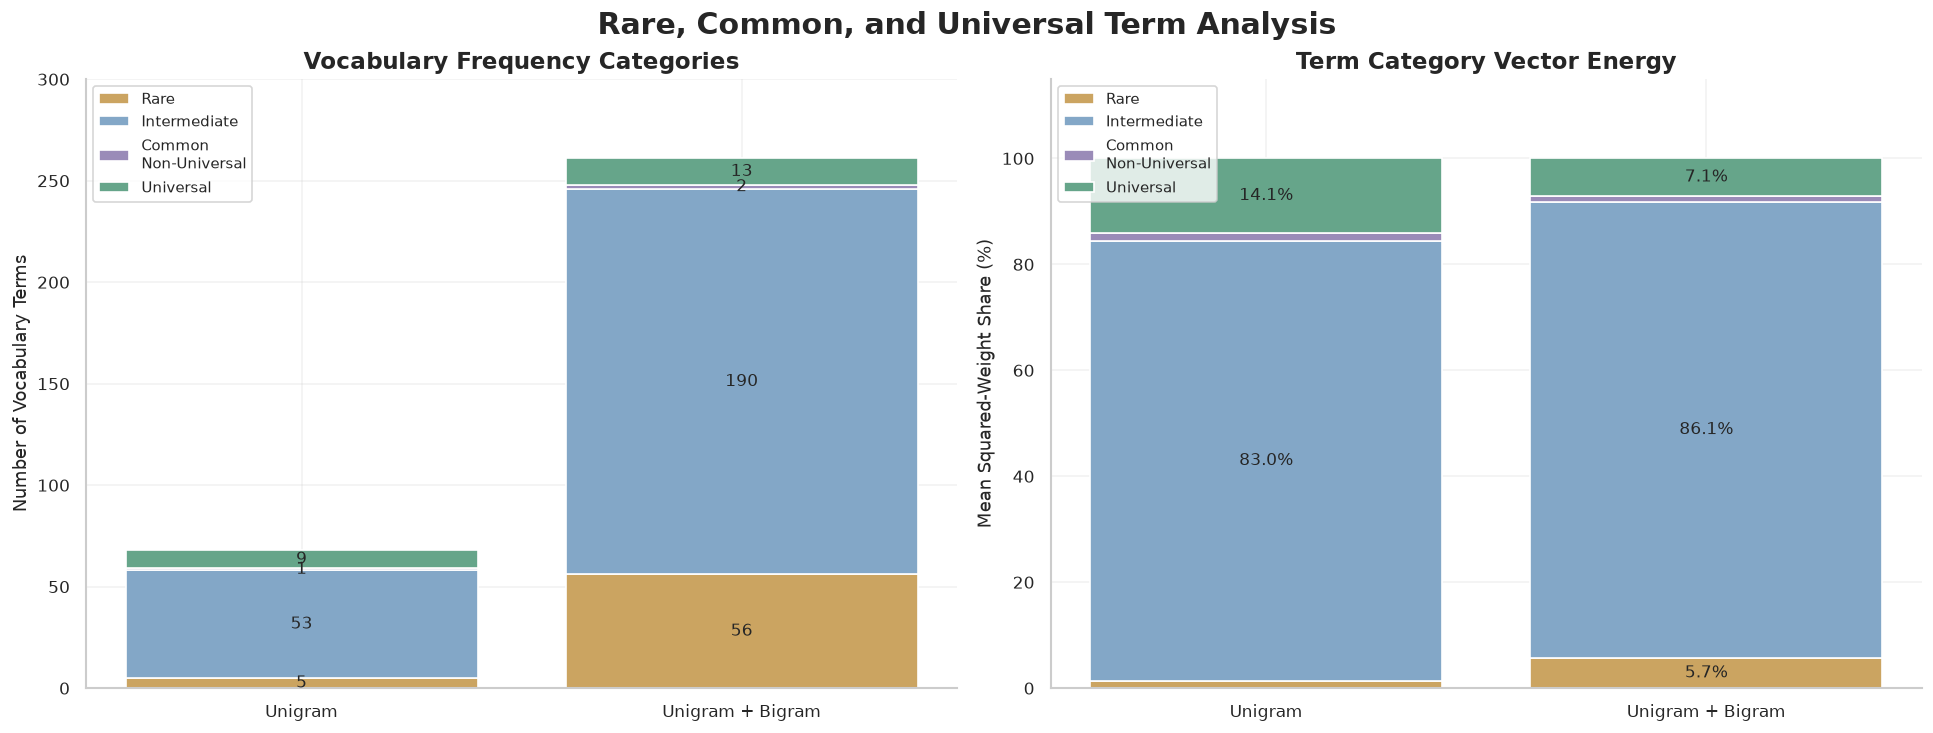

[SAVED] 80_tfidf_term_frequency_categories.png


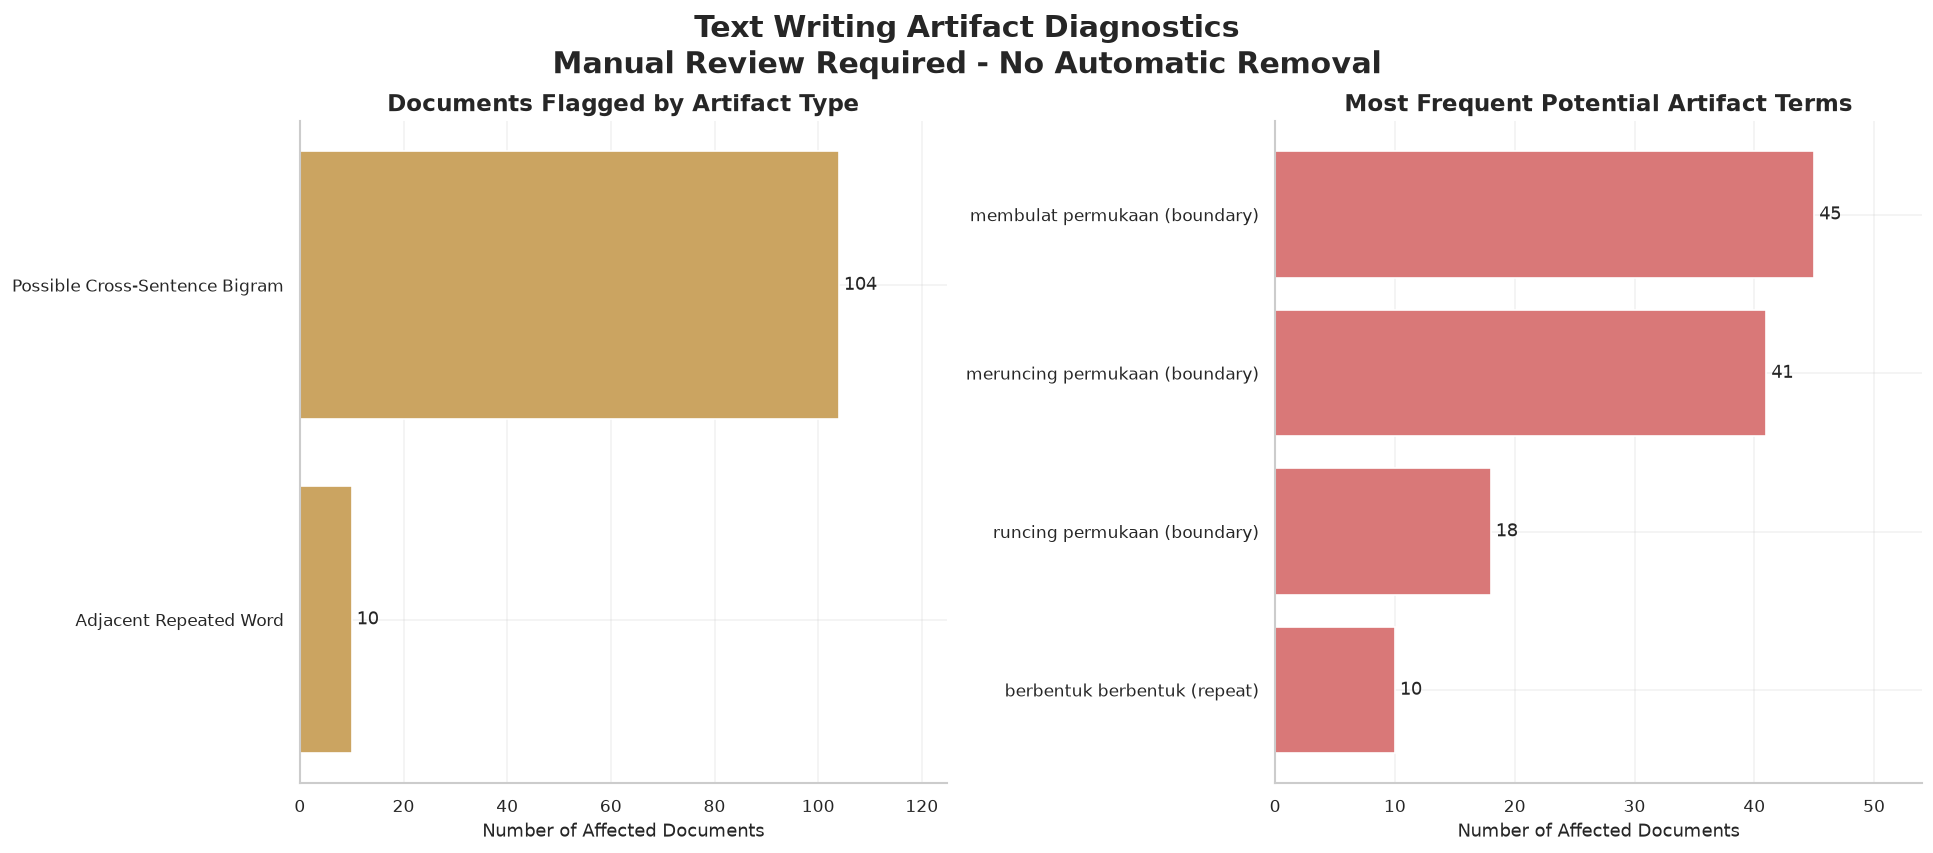

[SAVED] 81_tfidf_writing_artifact_diagnostics.png


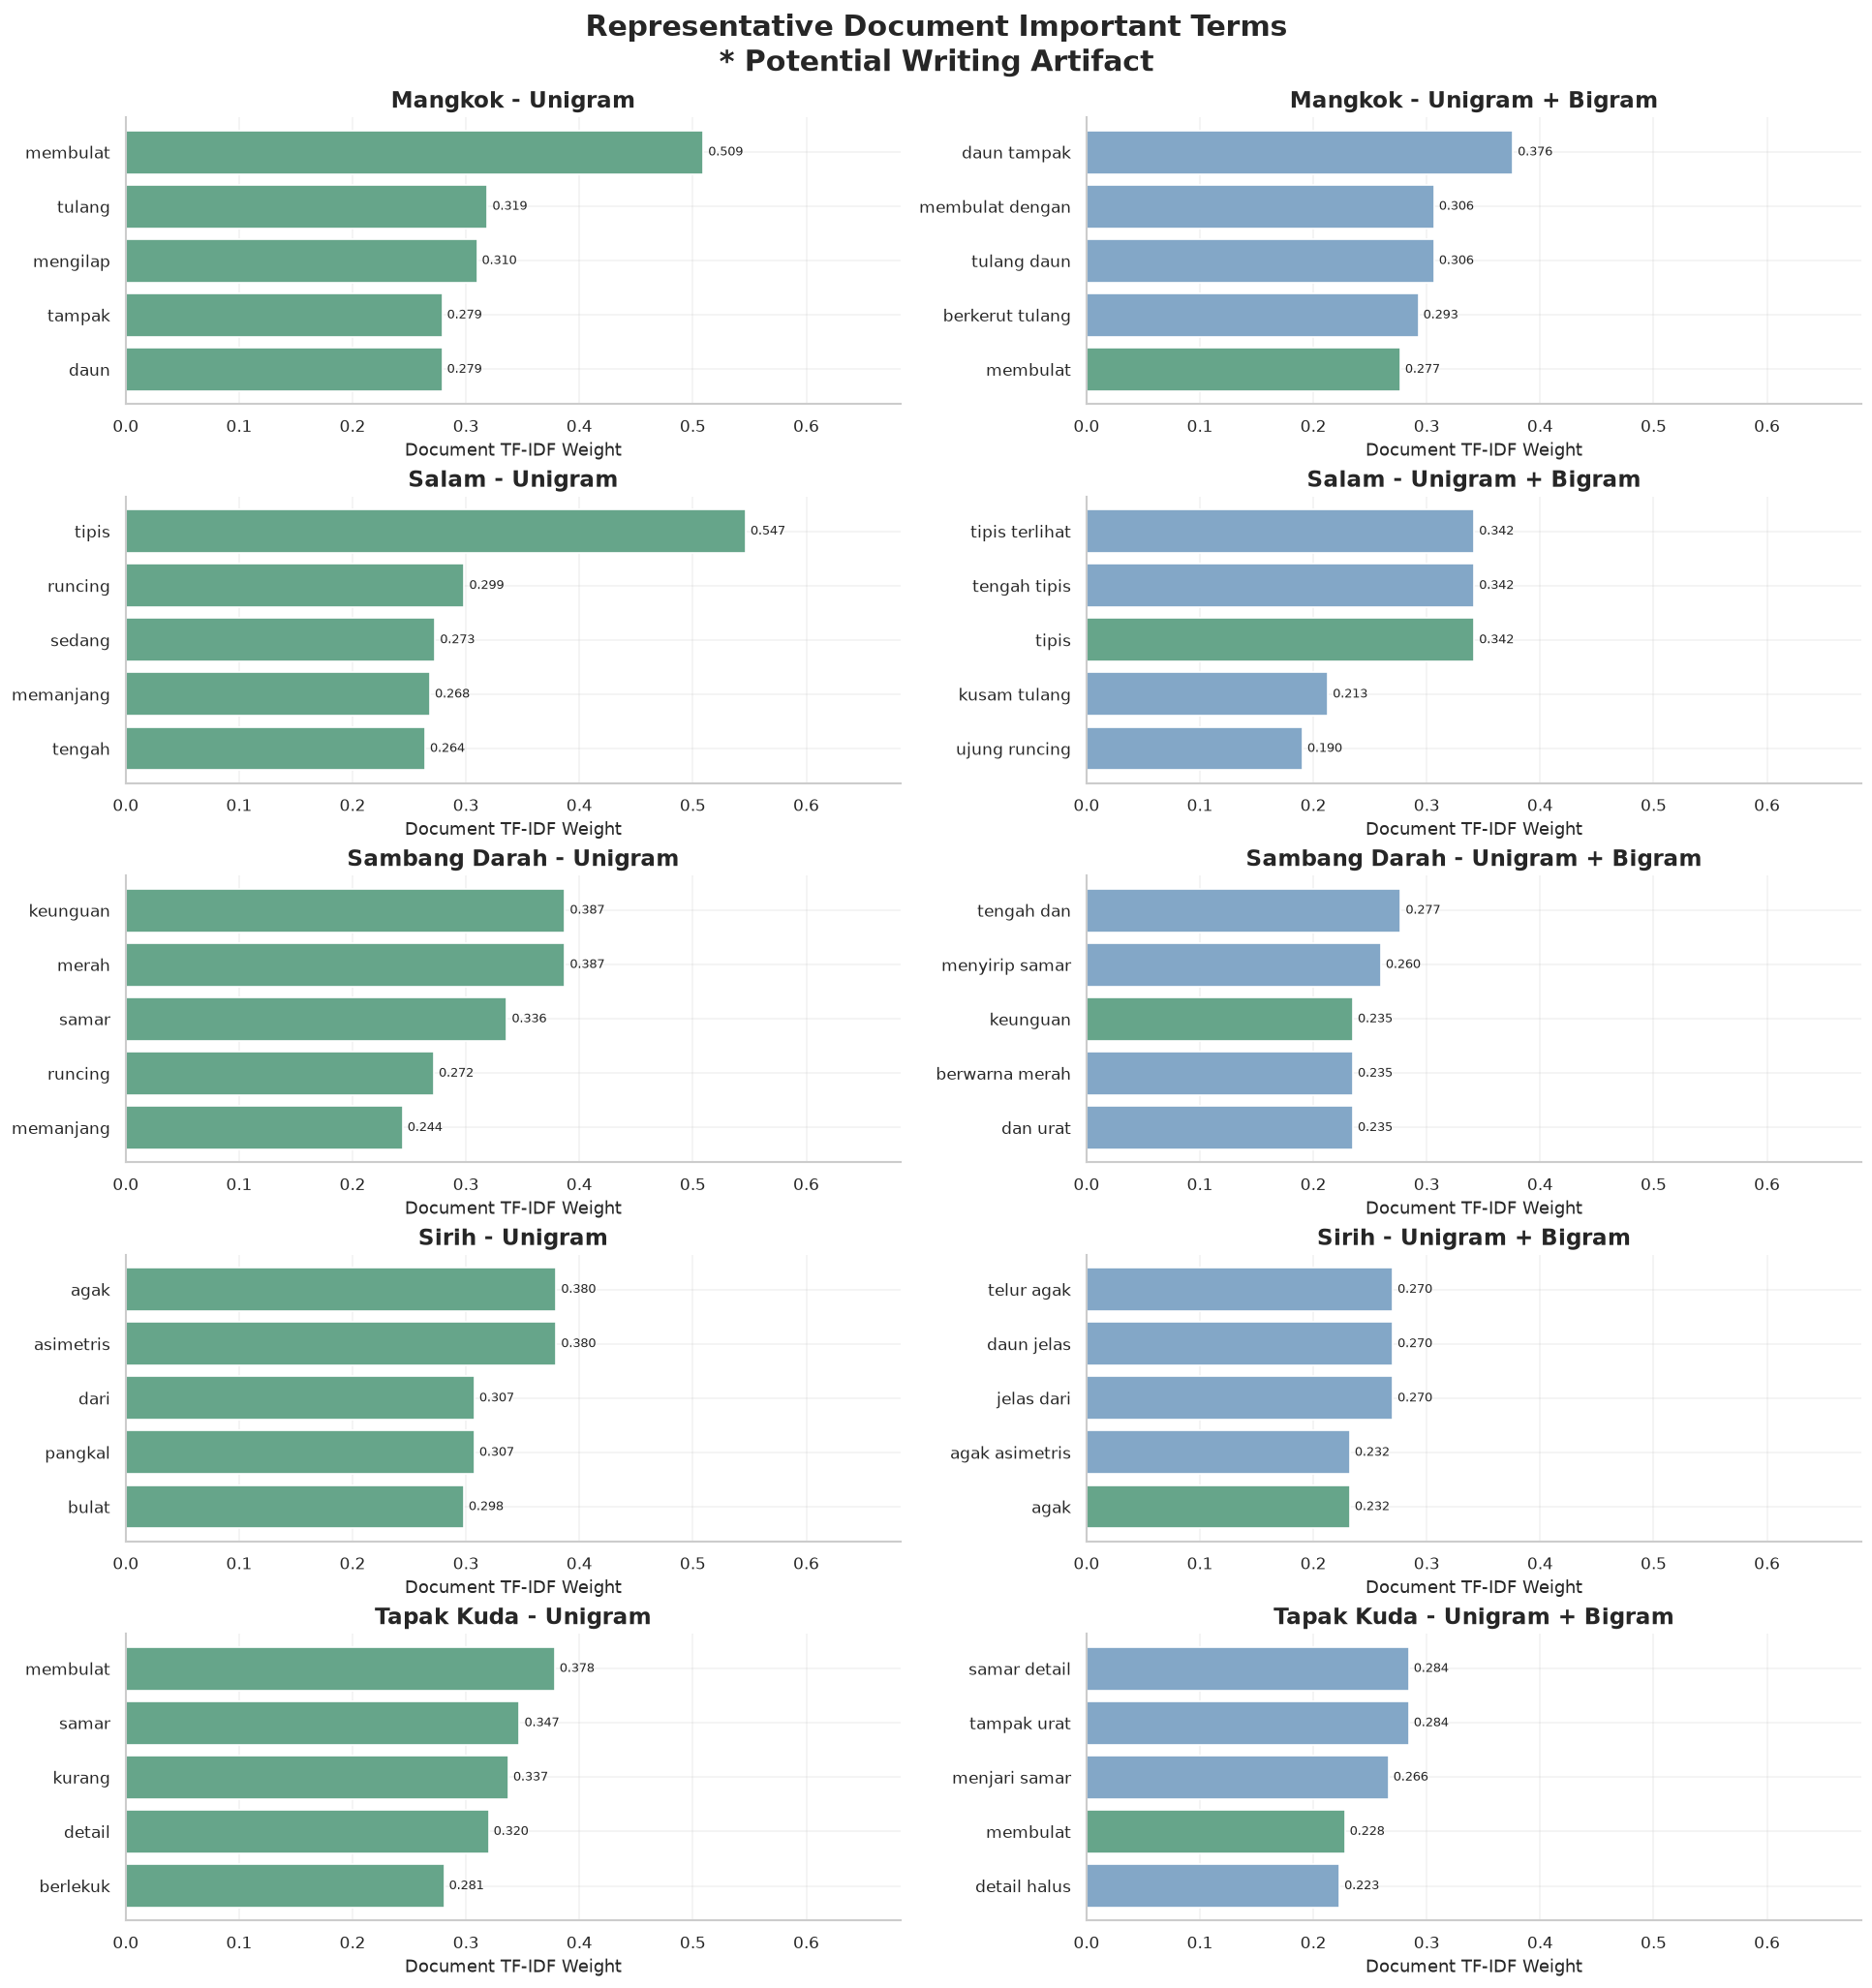

[SAVED] 82_representative_document_important_terms.png

10. IMPORTANT TERM VALIDATION
-----------------------------------------------------------------


,configuration,validation_check,passed,status
0,Unigram,Vocabulary dimension preserved,True,Passed
1,Unigram,Feature names match original vocabulary,True,Passed
2,Unigram,Global mean weights consistent,True,Passed
3,Unigram,Document frequency consistent,True,Passed
4,Unigram,Class-level record count correct,True,Passed
5,Unigram,Class mean weights consistent,True,Passed
6,Unigram,Class-rest mean weights consistent,True,Passed
7,Unigram,Discriminative score consistent,True,Passed
8,Unigram,Class rankings descending,True,Passed
9,Unigram,Discriminative rankings descending,True,Passed



11. OVERALL IMPORTANT TERM SUMMARY
-----------------------------------------------------------------


,Indicator,Result
0,Total documents,104
1,Total classes,5
2,Global term records,329
3,Class-level term records,1645
4,Top global term records,30
5,Top class term records,100
6,Top discriminative term records,100
7,Top bigram records,50
8,Universal term records,22
9,Potential artifact terms,4



12. SAVING IMPORTANT TERM REPORTS
-----------------------------------------------------------------
[SAVED] 258_tfidf_global_important_terms.csv
[SAVED] 259_tfidf_top_global_terms.csv
[SAVED] 260_tfidf_class_important_terms.csv
[SAVED] 261_tfidf_top_class_terms.csv
[SAVED] 262_tfidf_discriminative_terms.csv
[SAVED] 263_tfidf_top_discriminative_terms.csv
[SAVED] 264_tfidf_important_bigrams.csv
[SAVED] 265_tfidf_common_terms.csv
[SAVED] 266_tfidf_universal_terms.csv
[SAVED] 267_tfidf_term_frequency_categories.csv
[SAVED] 268_tfidf_writing_artifacts.csv
[SAVED] 269_tfidf_artifact_summary.csv
[SAVED] 270_tfidf_high_rank_artifact_terms.csv
[SAVED] 271_tfidf_important_representative_terms.csv
[SAVED] 272_tfidf_important_term_validation.csv
[SAVED] 273_tfidf_important_term_summary.csv

FINAL IMPORTANT TERM ANALYSIS SUMMARY

DATASET INFORMATION
-----------------------------------------------------------------
Total documents       : 104
Total classes         : 5

TERM ANALYSIS
---------------

In [9]:
# ==================================================
# CELL 10 - IMPORTANT TERM VISUALIZATION
# ==================================================

import re

print("IMPORTANT TERM VISUALIZATION")
print("=" * 65)

IMPORTANT_TERM_VISUALIZATION_COMPLETED = False


# ==================================================
# 1. VALIDATE PREVIOUS PROCESSING STAGES
# ==================================================

assert TFIDF_FEATURE_EXTRACTION_COMPLETED is True
assert TFIDF_MATRIX_ANALYSIS_COMPLETED is True

assert tfidf_matrix_analysis_validation_df["passed"].all()

assert np.array_equal(
    tfidf_sample_ids,
    loaded_visual_sample_ids
)

assert np.array_equal(
    tfidf_labels,
    validated_text_labels
)

important_term_corpus_snapshot = list(
    validated_text_corpus
)

important_term_matrix_snapshots = {
    name: matrix.copy()
    for name, matrix in tfidf_matrices.items()
}

print("\n[PASS] Previous processing stages validated.")


# ==================================================
# 2. IMPORTANT TERM ANALYSIS CONFIGURATION
# ==================================================

TOP_GLOBAL_TERMS = 15
TOP_CLASS_TERMS = 10
TOP_DISCRIMINATIVE_TERMS = 10
TOP_REPRESENTATIVE_TERMS = 5

IMPORTANT_TERM_TOLERANCE = 1e-10

IMPORTANT_TERM_ANALYSIS_SCOPE = (
    "Exploratory Full-Gallery Analysis"
)

IMPORTANT_TERM_COLORS = {
    "Unigram": "#66A58A",
    "Bigram": "#83A7C7"
}

important_term_class_names = sorted(
    np.unique(tfidf_labels)
)

important_term_figure_paths = []

print("\n1. ANALYSIS CONFIGURATION")
print("-" * 65)

print(f"Total documents     : {text_n_samples}")
print(f"Total classes       : {len(important_term_class_names)}")
print(f"Analysis scope      : {IMPORTANT_TERM_ANALYSIS_SCOPE}")
print(f"Top global terms    : {TOP_GLOBAL_TERMS}")
print(f"Top terms per class : {TOP_CLASS_TERMS}")

print("[INFO] No feature selection will be applied.")


# ==================================================
# 3. GLOBAL IMPORTANT TERM ANALYSIS
# ==================================================

global_important_term_records = []

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    matrix = tfidf_matrices[configuration_name]

    dense_matrix = matrix.toarray()

    feature_names = tfidf_feature_names_by_config[
        configuration_name
    ]

    idf_weights = tfidf_idf_weights[
        configuration_name
    ]

    document_frequency = matrix.getnnz(axis=0)

    for feature_index, term in enumerate(feature_names):

        feature_values = dense_matrix[:, feature_index]

        active_values = feature_values[
            feature_values > 0
        ]

        df_value = int(
            document_frequency[feature_index]
        )

        global_important_term_records.append({

            "configuration": configuration_name,

            "feature_index": feature_index,

            "term": term,

            "ngram_type": (
                "Bigram" if " " in term
                else "Unigram"
            ),

            "document_frequency": df_value,

            "document_coverage_percent": (
                df_value / text_n_samples * 100
            ),

            "idf_weight": float(
                idf_weights[feature_index]
            ),

            "mean_tfidf": float(
                feature_values.mean()
            ),

            "mean_nonzero_tfidf": (
                float(active_values.mean())
                if active_values.size > 0
                else 0.0
            ),

            "maximum_tfidf": float(
                feature_values.max()
            ),

            "std_tfidf": float(
                feature_values.std(ddof=0)
            ),

            "mean_squared_weight": float(
                np.mean(feature_values ** 2)
            ),

            "rare_term": (
                df_value <= RARE_TERM_MAX_DF
            ),

            "common_term": (
                df_value / text_n_samples
                >= COMMON_TERM_MIN_DF_RATIO
            ),

            "universal_term": (
                df_value == text_n_samples
            )
        })


tfidf_global_important_terms_df = pd.DataFrame(
    global_important_term_records
)

tfidf_global_important_terms_df = (

    tfidf_global_important_terms_df

    .sort_values(
        ["configuration", "mean_tfidf", "term"],
        ascending=[True, False, True]
    )

    .reset_index(drop=True)
)

tfidf_global_important_terms_df["global_rank"] = (

    tfidf_global_important_terms_df

    .groupby("configuration")

    .cumcount() + 1
)

tfidf_top_global_terms_df = (

    tfidf_global_important_terms_df

    .groupby("configuration", sort=False)

    .head(TOP_GLOBAL_TERMS)

    .reset_index(drop=True)
)

print("\n2. GLOBAL IMPORTANT TERMS")
print("-" * 65)

display(

    tfidf_top_global_terms_df[
        [
            "configuration",
            "global_rank",
            "term",
            "ngram_type",
            "document_frequency",
            "idf_weight",
            "mean_tfidf"
        ]
    ].round(6)
)


# ==================================================
# 4. CLASS-LEVEL IMPORTANT TERM ANALYSIS
# ==================================================

class_important_term_records = []

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    matrix = tfidf_matrices[
        configuration_name
    ].toarray()

    feature_names = tfidf_feature_names_by_config[
        configuration_name
    ]

    idf_weights = tfidf_idf_weights[
        configuration_name
    ]

    for class_name in important_term_class_names:

        class_mask = (
            tfidf_labels == class_name
        )

        class_matrix = matrix[class_mask]

        other_matrix = matrix[~class_mask]

        class_mean = class_matrix.mean(axis=0)

        other_mean = other_matrix.mean(axis=0)

        class_df = (
            class_matrix > 0
        ).sum(axis=0)

        other_df = (
            other_matrix > 0
        ).sum(axis=0)

        for feature_index, term in enumerate(
            feature_names
        ):

            class_important_term_records.append({

                "configuration": configuration_name,

                "kelas": class_name,

                "feature_index": feature_index,

                "term": term,

                "ngram_type": (
                    "Bigram" if " " in term
                    else "Unigram"
                ),

                "class_documents": len(class_matrix),

                "other_documents": len(other_matrix),

                "class_document_frequency": int(
                    class_df[feature_index]
                ),

                "other_document_frequency": int(
                    other_df[feature_index]
                ),

                "class_coverage_percent": float(
                    class_df[feature_index]
                    / len(class_matrix) * 100
                ),

                "other_coverage_percent": float(
                    other_df[feature_index]
                    / len(other_matrix) * 100
                ),

                "idf_weight": float(
                    idf_weights[feature_index]
                ),

                "class_mean_tfidf": float(
                    class_mean[feature_index]
                ),

                "other_mean_tfidf": float(
                    other_mean[feature_index]
                ),

                "discriminative_score": float(
                    class_mean[feature_index]
                    - other_mean[feature_index]
                ),

                "observed_class_specific": bool(

                    class_df[feature_index] > 0

                    and other_df[feature_index] == 0
                )
            })


tfidf_class_important_terms_df = pd.DataFrame(
    class_important_term_records
)

tfidf_class_important_terms_df = (

    tfidf_class_important_terms_df

    .sort_values(

        [
            "configuration",
            "kelas",
            "class_mean_tfidf",
            "term"
        ],

        ascending=[
            True, True, False, True
        ]
    )

    .reset_index(drop=True)
)

tfidf_class_important_terms_df["class_rank"] = (

    tfidf_class_important_terms_df

    .groupby(
        ["configuration", "kelas"]
    )

    .cumcount() + 1
)

tfidf_top_class_terms_df = (

    tfidf_class_important_terms_df.loc[

        tfidf_class_important_terms_df[
            "class_mean_tfidf"
        ] > 0
    ]

    .groupby(
        ["configuration", "kelas"],
        sort=False
    )

    .head(TOP_CLASS_TERMS)

    .reset_index(drop=True)
)

print("\n3. CLASS-LEVEL IMPORTANT TERMS")
print("-" * 65)

display(

    tfidf_top_class_terms_df[
        [
            "configuration",
            "kelas",
            "class_rank",
            "term",
            "class_mean_tfidf",
            "class_coverage_percent"
        ]
    ]

    .groupby(
        ["configuration", "kelas"],
        sort=False
    )

    .head(5)

    .round(6)
)


# ==================================================
# 5. DISCRIMINATIVE TERM ANALYSIS
# ==================================================

# Discriminative score:
#
# Mean TF-IDF in the target class
# minus
# Mean TF-IDF in all other documents.
#
# This is exploratory supervised interpretation,
# not a feature selection procedure.

tfidf_discriminative_terms_df = (

    tfidf_class_important_terms_df.loc[

        tfidf_class_important_terms_df[
            "discriminative_score"
        ] > IMPORTANT_TERM_TOLERANCE
    ]

    .sort_values(

        [
            "configuration",
            "kelas",
            "discriminative_score",
            "term"
        ],

        ascending=[
            True, True, False, True
        ]
    )

    .reset_index(drop=True)
)

tfidf_discriminative_terms_df[
    "discriminative_rank"
] = (

    tfidf_discriminative_terms_df

    .groupby(
        ["configuration", "kelas"]
    )

    .cumcount() + 1
)

tfidf_top_discriminative_terms_df = (

    tfidf_discriminative_terms_df

    .groupby(
        ["configuration", "kelas"],
        sort=False
    )

    .head(TOP_DISCRIMINATIVE_TERMS)

    .reset_index(drop=True)
)

print("\n4. DISCRIMINATIVE TERM ANALYSIS")
print("-" * 65)

display(

    tfidf_top_discriminative_terms_df[
        [
            "configuration",
            "kelas",
            "discriminative_rank",
            "term",
            "class_mean_tfidf",
            "other_mean_tfidf",
            "discriminative_score",
            "observed_class_specific"
        ]
    ]

    .groupby(
        ["configuration", "kelas"],
        sort=False
    )

    .head(5)

    .round(6)
)


# ==================================================
# 6. IMPORTANT BIGRAM ANALYSIS
# ==================================================

tfidf_important_bigrams_df = (

    tfidf_class_important_terms_df.loc[

        tfidf_class_important_terms_df[
            "ngram_type"
        ].eq("Bigram")

        &

        tfidf_class_important_terms_df[
            "class_mean_tfidf"
        ].gt(0)
    ]

    .sort_values(

        [
            "kelas",
            "class_mean_tfidf",
            "term"
        ],

        ascending=[
            True, False, True
        ]
    )

    .reset_index(drop=True)
)

tfidf_important_bigrams_df["bigram_rank"] = (

    tfidf_important_bigrams_df

    .groupby("kelas")

    .cumcount() + 1
)

tfidf_top_bigrams_df = (

    tfidf_important_bigrams_df

    .groupby("kelas", sort=False)

    .head(TOP_CLASS_TERMS)

    .reset_index(drop=True)
)

print("\n5. IMPORTANT BIGRAMS PER CLASS")
print("-" * 65)

display(

    tfidf_top_bigrams_df[
        [
            "kelas",
            "bigram_rank",
            "term",
            "class_mean_tfidf",
            "class_coverage_percent",
            "discriminative_score"
        ]
    ]

    .groupby("kelas", sort=False)

    .head(5)

    .round(6)
)


# ==================================================
# 7. COMMON AND UNIVERSAL TERM ANALYSIS
# ==================================================

tfidf_common_terms_df = (

    tfidf_global_important_terms_df.loc[

        tfidf_global_important_terms_df[
            "common_term"
        ]
    ]

    .copy()

    .reset_index(drop=True)
)

tfidf_universal_terms_df = (

    tfidf_global_important_terms_df.loc[

        tfidf_global_important_terms_df[
            "universal_term"
        ]
    ]

    .copy()

    .reset_index(drop=True)
)

term_frequency_category_records = []

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    matrix = tfidf_matrices[
        configuration_name
    ].toarray()

    statistics_df = (

        tfidf_global_important_terms_df.loc[

            tfidf_global_important_terms_df[
                "configuration"
            ].eq(configuration_name)
        ]

        .sort_values("feature_index")
    )

    rare_mask = statistics_df[
        "rare_term"
    ].to_numpy(dtype=bool)

    common_mask = statistics_df[
        "common_term"
    ].to_numpy(dtype=bool)

    universal_mask = statistics_df[
        "universal_term"
    ].to_numpy(dtype=bool)

    # Mutually exclusive diagnostic categories.

    category_masks = {

        "Rare": rare_mask,

        "Intermediate": (
            ~rare_mask & ~common_mask
        ),

        "Common Non-Universal": (
            common_mask & ~universal_mask
        ),

        "Universal": universal_mask
    }

    for category_name, category_mask in (
        category_masks.items()
    ):

        squared_weight = np.sum(

            matrix[:, category_mask] ** 2,

            axis=1
        )

        term_frequency_category_records.append({

            "configuration": configuration_name,

            "term_category": category_name,

            "number_of_terms": int(
                category_mask.sum()
            ),

            "mean_squared_weight_share_percent": float(
                squared_weight.mean() * 100
            ),

            "std_squared_weight_share_percent": float(
                squared_weight.std(ddof=0) * 100
            )
        })


tfidf_term_frequency_category_df = pd.DataFrame(
    term_frequency_category_records
)

print("\n6. UNIVERSAL TERM ANALYSIS")
print("-" * 65)

display(

    tfidf_universal_terms_df[
        [
            "configuration",
            "term",
            "ngram_type",
            "document_frequency",
            "idf_weight",
            "mean_tfidf"
        ]
    ].round(6)
)

display(
    tfidf_term_frequency_category_df.round(6)
)

print(
    "[INFO] Common and universal terms are retained."
)


# ==================================================
# 8. WRITING ARTIFACT DIAGNOSTICS
# ==================================================

# Diagnose adjacent repeated words and possible
# cross-sentence bigrams.
#
# No automatic correction is performed.
#
# These flags require manual inspection.

artifact_records = []

artifact_bigram_lookup = {

    term: index

    for index, term in enumerate(
        tfidf_bigram_feature_names
    )
}

artifact_combined_matrix = (
    tfidf_bigram_matrix.toarray()
)

# Check whether original descriptions are available
# in the validated metadata.

original_description_available = (

    "original_description"

    in df_text_validated.columns
)

artifact_metadata = (

    df_text_validated

    .reset_index(drop=True)
)

sentence_boundary_pattern = re.compile(

    r"\b(\w{2,})\s*[.!?;:]+\s*(\w{2,})\b",

    flags=re.UNICODE
)

for row_index, tokens in enumerate(
    validated_token_lists
):

    tokens = list(tokens)

    cleaned_text = str(
        validated_text_corpus[row_index]
    )

    original_text = ""

    if original_description_available:

        original_value = artifact_metadata.iloc[
            row_index
        ]["original_description"]

        if pd.notna(original_value):

            original_text = str(
                original_value
            )

    cleaned_bigram_set = {

        f"{tokens[i]} {tokens[i + 1]}"

        for i in range(len(tokens) - 1)
    }

    # --------------------------------------------------
    # A. Adjacent repeated words
    # --------------------------------------------------

    repeated_terms = {

        f"{tokens[i]} {tokens[i + 1]}"

        for i in range(len(tokens) - 1)

        if tokens[i] == tokens[i + 1]
    }

    for term in sorted(repeated_terms):

        if term not in artifact_bigram_lookup:

            continue

        feature_index = artifact_bigram_lookup[term]

        repeated_word = term.split()[0]

        original_has_repetition = bool(

            re.search(

                rf"\b{re.escape(repeated_word)}\s+"
                rf"{re.escape(repeated_word)}\b",

                original_text.lower()
            )
        )

        if not original_text:

            artifact_source = (
                "Original Description Unavailable"
            )

        elif original_has_repetition:

            artifact_source = (
                "Present in Original Description"
            )

        else:

            artifact_source = (
                "Not Directly Observed in Original"
            )

        artifact_records.append({

            "sample_id": tfidf_sample_ids[row_index],

            "kelas": tfidf_labels[row_index],

            "row_index": row_index,

            "term": term,

            "artifact_type": (
                "Adjacent Repeated Word"
            ),

            "artifact_source": artifact_source,

            "tfidf_weight": float(

                artifact_combined_matrix[
                    row_index,
                    feature_index
                ]
            ),

            "original_description": original_text,

            "cleaned_description": cleaned_text,

            "review_required": True
        })


    # --------------------------------------------------
    # B. Possible cross-sentence bigrams
    # --------------------------------------------------

    if original_text:

        boundary_terms = {

            f"{first.lower()} {second.lower()}"

            for first, second in
            sentence_boundary_pattern.findall(
                original_text
            )
        }

        boundary_terms = (

            boundary_terms

            & cleaned_bigram_set
        )

        for term in sorted(boundary_terms):

            if term not in artifact_bigram_lookup:

                continue

            feature_index = artifact_bigram_lookup[
                term
            ]

            artifact_records.append({

                "sample_id":
                    tfidf_sample_ids[row_index],

                "kelas":
                    tfidf_labels[row_index],

                "row_index":
                    row_index,

                "term":
                    term,

                "artifact_type": (
                    "Possible Cross-Sentence Bigram"
                ),

                "artifact_source": (
                    "Sentence Boundary in Original"
                ),

                "tfidf_weight": float(

                    artifact_combined_matrix[
                        row_index,
                        feature_index
                    ]
                ),

                "original_description":
                    original_text,

                "cleaned_description":
                    cleaned_text,

                "review_required":
                    True
            })


tfidf_writing_artifacts_df = pd.DataFrame(

    artifact_records,

    columns=[

        "sample_id",
        "kelas",
        "row_index",
        "term",
        "artifact_type",
        "artifact_source",
        "tfidf_weight",
        "original_description",
        "cleaned_description",
        "review_required"
    ]
)

tfidf_artifact_summary_df = (

    tfidf_writing_artifacts_df

    .groupby(
        ["artifact_type", "term"],
        sort=True
    )

    .agg(

        affected_documents=(
            "sample_id", "nunique"
        ),

        affected_classes=(
            "kelas", "nunique"
        ),

        mean_tfidf_weight=(
            "tfidf_weight", "mean"
        ),

        maximum_tfidf_weight=(
            "tfidf_weight", "max"
        )
    )

    .reset_index()

    .sort_values(

        ["affected_documents", "term"],

        ascending=[False, True]
    )

    .reset_index(drop=True)
)

print("\n7. WRITING ARTIFACT DIAGNOSTICS")
print("-" * 65)

print(
    f"Original descriptions available: "
    f"{original_description_available}"
)

display(
    tfidf_artifact_summary_df.round(6)
)

if not tfidf_writing_artifacts_df.empty:

    display(

        tfidf_writing_artifacts_df[
            [
                "sample_id",
                "kelas",
                "term",
                "artifact_type",
                "artifact_source",
                "tfidf_weight"
            ]
        ].head(15)
    )

print("[INFO] Artifact flags require manual review.")
print("[INFO] No descriptions or features were modified.")


# ==================================================
# 9. ANNOTATE POTENTIAL ARTIFACT TERMS
# ==================================================

artifact_term_set = set(
    tfidf_writing_artifacts_df["term"]
)

for dataframe in [

    tfidf_global_important_terms_df,

    tfidf_top_global_terms_df,

    tfidf_class_important_terms_df,

    tfidf_top_class_terms_df,

    tfidf_discriminative_terms_df,

    tfidf_top_discriminative_terms_df,

    tfidf_important_bigrams_df,

    tfidf_top_bigrams_df
]:

    dataframe["potential_writing_artifact"] = (

        dataframe["term"].isin(
            artifact_term_set
        )
    )


# Identify possible artifacts among the highest
# discriminative terms.

tfidf_high_rank_artifact_terms_df = (

    tfidf_top_discriminative_terms_df.loc[

        tfidf_top_discriminative_terms_df[
            "potential_writing_artifact"
        ]
    ]

    .copy()

    .reset_index(drop=True)
)

print("\n8. HIGH-RANKED POTENTIAL ARTIFACTS")
print("-" * 65)

display(

    tfidf_high_rank_artifact_terms_df[
        [
            "configuration",
            "kelas",
            "discriminative_rank",
            "term",
            "discriminative_score"
        ]
    ].round(6)
)


# ==================================================
# 10. REPRESENTATIVE DOCUMENT TERM ANALYSIS
# ==================================================

# Reuse representative samples selected in Cell 8.

important_representative_records = []

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    matrix = tfidf_matrices[
        configuration_name
    ]

    feature_names = tfidf_feature_names_by_config[
        configuration_name
    ]

    for row_index in tfidf_representative_indices:

        vector = (

            matrix[row_index]

            .toarray()

            .ravel()
        )

        nonzero_indices = np.flatnonzero(
            vector > 0
        )

        ranked_indices = sorted(

            nonzero_indices,

            key=lambda index: (

                -vector[index],

                feature_names[index]
            )
        )[:TOP_REPRESENTATIVE_TERMS]

        for rank, feature_index in enumerate(

            ranked_indices,

            start=1
        ):

            term = feature_names[
                feature_index
            ]

            important_representative_records.append({

                "configuration": configuration_name,

                "sample_id": tfidf_sample_ids[
                    row_index
                ],

                "kelas": tfidf_labels[
                    row_index
                ],

                "rank": rank,

                "feature_index": int(
                    feature_index
                ),

                "term": term,

                "ngram_type": (
                    "Bigram" if " " in term
                    else "Unigram"
                ),

                "tfidf_weight": float(
                    vector[feature_index]
                ),

                "potential_writing_artifact": (
                    term in artifact_term_set
                ),

                "description": str(
                    validated_text_corpus[row_index]
                )
            })


tfidf_important_representative_terms_df = pd.DataFrame(
    important_representative_records
)

print("\n9. REPRESENTATIVE DOCUMENT TERMS")
print("-" * 65)

display(

    tfidf_important_representative_terms_df[
        [
            "configuration",
            "kelas",
            "rank",
            "term",
            "tfidf_weight",
            "potential_writing_artifact"
        ]
    ].round(6)
)


# ==================================================
# 11. VISUALIZATION HELPER
# ==================================================

def save_important_term_figure(fig, filename):

    output_path = (
        TEXT_FEATURE_FIGURES_DIR / filename
    )

    fig.savefig(

        output_path,

        dpi=300,

        bbox_inches="tight"
    )

    important_term_figure_paths.append(
        output_path
    )

    plt.show()
    plt.close(fig)

    print(f"[SAVED] {filename}")


def plot_ranked_terms(

    ax,
    dataframe,
    value_column,
    title,
    xlabel
):

    plot_df = dataframe.sort_values(
        value_column
    )

    colors = [

        IMPORTANT_TERM_COLORS[
            ngram_type
        ]

        for ngram_type in plot_df["ngram_type"]
    ]

    labels = [

        f"{term} *" if artifact else term

        for term, artifact in zip(

            plot_df["term"],

            plot_df.get(

                "potential_writing_artifact",

                pd.Series(
                    False,
                    index=plot_df.index
                )
            )
        )
    ]

    bars = ax.barh(

        labels,

        plot_df[value_column],

        color=colors
    )

    ax.bar_label(

        bars,

        fmt="%.3f",

        padding=3,

        fontsize=8
    )

    ax.set_title(title)

    ax.set_xlabel(xlabel)

    ax.margins(x=0.25)


# ==================================================
# 12. VISUALIZE GLOBAL IMPORTANT TERMS
# ==================================================

fig, axes = plt.subplots(

    1, 2,

    figsize=(16, 8),

    constrained_layout=True
)

for ax, configuration_name in zip(

    axes,

    TFIDF_CONFIGURATION_ORDER
):

    plot_df = (

        tfidf_top_global_terms_df.loc[

            tfidf_top_global_terms_df[
                "configuration"
            ].eq(configuration_name)
        ]
    )

    plot_ranked_terms(

        ax,

        plot_df,

        "mean_tfidf",

        configuration_name,

        "Mean TF-IDF Weight Across All Documents"
    )

fig.suptitle(

    "Global Important TF-IDF Terms\n"

    "* Potential Writing Artifact",

    fontsize=18,

    fontweight="bold"
)

save_important_term_figure(

    fig,

    "76_global_important_tfidf_terms.png"
)


# ==================================================
# 13. VISUALIZE IMPORTANT TERMS PER CLASS
# ==================================================

# One row for each plant class.
# Left: unigram.
# Right: unigram + bigram.

fig, axes = plt.subplots(

    len(important_term_class_names),

    2,

    figsize=(16, 23),

    constrained_layout=True
)

class_term_plot_max = (

    tfidf_top_class_terms_df[
        "class_mean_tfidf"
    ].max()
)

for row_index, class_name in enumerate(

    important_term_class_names
):

    for column_index, configuration_name in enumerate(

        TFIDF_CONFIGURATION_ORDER
    ):

        plot_df = (

            tfidf_top_class_terms_df.loc[

                tfidf_top_class_terms_df[
                    "configuration"
                ].eq(configuration_name)

                &

                tfidf_top_class_terms_df[
                    "kelas"
                ].eq(class_name)
            ]
        )

        ax = axes[
            row_index,
            column_index
        ]

        plot_ranked_terms(

            ax,

            plot_df,

            "class_mean_tfidf",

            f"{class_name} - {configuration_name}",

            "Mean TF-IDF Weight Within Class"
        )

        ax.set_xlim(
            0,
            class_term_plot_max * 1.25
        )

fig.suptitle(

    "Class-Level Important TF-IDF Terms\n"

    "* Potential Writing Artifact",

    fontsize=19,

    fontweight="bold"
)

save_important_term_figure(

    fig,

    "77_class_level_important_tfidf_terms.png"
)


# ==================================================
# 14. VISUALIZE DISCRIMINATIVE TERMS
# ==================================================

fig, axes = plt.subplots(

    len(important_term_class_names),

    2,

    figsize=(16, 23),

    constrained_layout=True
)

discriminative_plot_max = (

    tfidf_top_discriminative_terms_df[
        "discriminative_score"
    ].max()
)

for row_index, class_name in enumerate(

    important_term_class_names
):

    for column_index, configuration_name in enumerate(

        TFIDF_CONFIGURATION_ORDER
    ):

        plot_df = (

            tfidf_top_discriminative_terms_df.loc[

                tfidf_top_discriminative_terms_df[
                    "configuration"
                ].eq(configuration_name)

                &

                tfidf_top_discriminative_terms_df[
                    "kelas"
                ].eq(class_name)
            ]
        )

        ax = axes[
            row_index,
            column_index
        ]

        plot_ranked_terms(

            ax,

            plot_df,

            "discriminative_score",

            f"{class_name} - {configuration_name}",

            "Mean Weight Difference: Class vs Rest"
        )

        ax.set_xlim(

            0,

            discriminative_plot_max * 1.25
        )

fig.suptitle(

    "Observed Discriminative TF-IDF Terms\n"

    "Exploratory Class-vs-Rest Analysis\n"

    "* Potential Writing Artifact",

    fontsize=19,

    fontweight="bold"
)

save_important_term_figure(

    fig,

    "78_discriminative_tfidf_terms.png"
)


# ==================================================
# 15. VISUALIZE IMPORTANT BIGRAMS PER CLASS
# ==================================================

fig, axes = plt.subplots(

    2, 3,

    figsize=(19, 11),

    constrained_layout=True
)

bigram_plot_max = (

    tfidf_top_bigrams_df[
        "class_mean_tfidf"
    ].max()
)

for ax, class_name in zip(

    axes.flat,

    important_term_class_names
):

    plot_df = (

        tfidf_top_bigrams_df.loc[

            tfidf_top_bigrams_df[
                "kelas"
            ].eq(class_name)
        ]
    )

    plot_ranked_terms(

        ax,

        plot_df,

        "class_mean_tfidf",

        class_name,

        "Mean TF-IDF Weight"
    )

    ax.set_xlim(
        0,
        bigram_plot_max * 1.25
    )


# Use the remaining panel as an explanation.

axes.flat[-1].axis("off")

axes.flat[-1].text(

    0.05,
    0.85,

    "BIGRAM INTERPRETATION\n\n"

    "• Two consecutive tokens\n\n"

    "• Higher weight indicates greater\n"
    "  statistical importance\n\n"

    "• Not every bigram is a meaningful phrase\n\n"

    "* Potential writing artifact\n"
    "  requiring manual inspection\n\n"

    "Full-gallery exploratory analysis.",

    transform=axes.flat[-1].transAxes,

    fontsize=12,

    va="top"
)

fig.suptitle(

    "Important Bigram Terms Across Plant Classes",

    fontsize=19,

    fontweight="bold"
)

save_important_term_figure(

    fig,

    "79_important_bigrams_per_class.png"
)


# ==================================================
# 16. VISUALIZE TERM FREQUENCY CATEGORIES
# ==================================================

fig, axes = plt.subplots(

    1, 2,

    figsize=(16, 6),

    constrained_layout=True
)

category_order = [

    "Rare",

    "Intermediate",

    "Common Non-Universal",

    "Universal"
]

category_colors = [

    "#CBA461",

    "#83A7C7",

    "#9A8BB8",

    "#66A58A"
]

category_labels = [
    "Rare",
    "Intermediate",
    "Common\nNon-Universal",
    "Universal"
]

positions = np.arange(
    len(TFIDF_CONFIGURATION_ORDER)
)

for ax, value_column, ylabel, chart_title in [

    (

        axes[0],

        "number_of_terms",

        "Number of Vocabulary Terms",

        "Vocabulary Frequency Categories"
    ),

    (

        axes[1],

        "mean_squared_weight_share_percent",

        "Mean Squared-Weight Share (%)",

        "Term Category Vector Energy"
    )
]:

    bottoms = np.zeros(
        len(TFIDF_CONFIGURATION_ORDER)
    )

    for category_name, color, category_label in zip(

        category_order,

        category_colors,

        category_labels
    ):

        values = [

            tfidf_term_frequency_category_df.loc[

                tfidf_term_frequency_category_df[
                    "configuration"
                ].eq(name)

                &

                tfidf_term_frequency_category_df[
                    "term_category"
                ].eq(category_name),

                value_column

            ].iloc[0]

            for name in TFIDF_CONFIGURATION_ORDER
        ]

        values = np.asarray(values)

        bars = ax.bar(

            positions,

            values,

            bottom=bottoms,

            color=color,

            label=category_label
        )

        if value_column == "number_of_terms":

            bar_labels = [

                f"{int(value)}" if value > 0 else ""

                for value in values
            ]

        else:

            bar_labels = [

                f"{value:.1f}%"
                if value >= 3
                else ""

                for value in values
            ]

        ax.bar_label(

            bars,

            labels=bar_labels,

            label_type="center",

            fontsize=10
        )

        bottoms += values

    ax.set_xticks(positions)

    ax.set_xticklabels([

        "Unigram",

        "Unigram + Bigram"
    ])

    ax.set_ylabel(ylabel)

    ax.set_title(chart_title)

    ax.legend(fontsize=9)

    ax.margins(y=0.15)

fig.suptitle(

    "Rare, Common, and Universal Term Analysis",

    fontsize=18,

    fontweight="bold"
)

save_important_term_figure(

    fig,

    "80_tfidf_term_frequency_categories.png"
)


# ==================================================
# 17. VISUALIZE WRITING ARTIFACT DIAGNOSTICS
# ==================================================

fig, axes = plt.subplots(

    1, 2,

    figsize=(16, 7),

    constrained_layout=True
)

if not tfidf_writing_artifacts_df.empty:

    artifact_type_counts = (

        tfidf_writing_artifacts_df

        .groupby("artifact_type")["sample_id"]

        .nunique()

        .sort_values()
    )

    bars = axes[0].barh(

        artifact_type_counts.index,

        artifact_type_counts.values,

        color="#CBA461"
    )

    axes[0].bar_label(
        bars,
        padding=3
    )

    axes[0].set_title(
        "Documents Flagged by Artifact Type"
    )

    axes[0].set_xlabel(
        "Number of Affected Documents"
    )

    axes[0].margins(x=0.20)

    top_artifacts = (

        tfidf_artifact_summary_df

        .head(10)

        .sort_values("affected_documents")
    )

    artifact_plot_labels = [

        f"{term} (repeat)"
        if artifact_type == "Adjacent Repeated Word"
        else f"{term} (boundary)"

        for term, artifact_type in zip(

            top_artifacts["term"],

            top_artifacts["artifact_type"]
        )
    ]

    bars = axes[1].barh(

        artifact_plot_labels,

        top_artifacts["affected_documents"],

        color="#D97878"
    )

    axes[1].bar_label(
        bars,
        padding=3
    )

    axes[1].set_title(
        "Most Frequent Potential Artifact Terms"
    )

    axes[1].set_xlabel(
        "Number of Affected Documents"
    )

    axes[1].margins(x=0.20)

else:

    for ax in axes:

        ax.axis("off")

        ax.text(

            0.5,

            0.5,

            "No writing artifacts detected\n"
            "by the configured diagnostic rules.",

            ha="center",

            va="center",

            transform=ax.transAxes
        )

fig.suptitle(

    "Text Writing Artifact Diagnostics\n"

    "Manual Review Required - No Automatic Removal",

    fontsize=18,

    fontweight="bold"
)

save_important_term_figure(

    fig,

    "81_tfidf_writing_artifact_diagnostics.png"
)


# ==================================================
# 18. VISUALIZE REPRESENTATIVE DOCUMENT TERMS
# ==================================================

fig, axes = plt.subplots(

    len(important_term_class_names),

    2,

    figsize=(16, 17),

    constrained_layout=True
)

representative_plot_max = (

    tfidf_important_representative_terms_df[
        "tfidf_weight"
    ].max()
)

for row_index, class_name in enumerate(

    important_term_class_names
):

    for column_index, configuration_name in enumerate(

        TFIDF_CONFIGURATION_ORDER
    ):

        plot_df = (

            tfidf_important_representative_terms_df.loc[

                tfidf_important_representative_terms_df[
                    "configuration"
                ].eq(configuration_name)

                &

                tfidf_important_representative_terms_df[
                    "kelas"
                ].eq(class_name)
            ]
        )

        ax = axes[
            row_index,
            column_index
        ]

        plot_ranked_terms(

            ax,

            plot_df,

            "tfidf_weight",

            f"{class_name} - {configuration_name}",

            "Document TF-IDF Weight"
        )

        ax.set_xlim(

            0,

            representative_plot_max * 1.25
        )

fig.suptitle(

    "Representative Document Important Terms\n"

    "* Potential Writing Artifact",

    fontsize=18,

    fontweight="bold"
)

save_important_term_figure(

    fig,

    "82_representative_document_important_terms.png"
)


# ==================================================
# 19. VALIDATE IMPORTANT TERM ANALYSIS
# ==================================================

important_term_validation_records = []


def register_important_term_check(
    check_name,
    passed,
    configuration="Overall"
):

    important_term_validation_records.append({

        "configuration": configuration,

        "validation_check": check_name,

        "passed": bool(passed),

        "status": (
            "Passed" if passed else "Failed"
        )
    })


for configuration_name in TFIDF_CONFIGURATION_ORDER:

    matrix = tfidf_matrices[
        configuration_name
    ].toarray()

    feature_names = tfidf_feature_names_by_config[
        configuration_name
    ]

    global_statistics = (

        tfidf_global_important_terms_df.loc[

            tfidf_global_important_terms_df[
                "configuration"
            ].eq(configuration_name)
        ]

        .sort_values("feature_index")
    )

    class_statistics = (

        tfidf_class_important_terms_df.loc[

            tfidf_class_important_terms_df[
                "configuration"
            ].eq(configuration_name)
        ]
    )

    frequency_categories = (

        tfidf_term_frequency_category_df.loc[

            tfidf_term_frequency_category_df[
                "configuration"
            ].eq(configuration_name)
        ]
    )

    ranked_class_terms = (

        tfidf_top_class_terms_df.loc[

            tfidf_top_class_terms_df[
                "configuration"
            ].eq(configuration_name)
        ]
    )

    ranked_discriminative_terms = (

        tfidf_top_discriminative_terms_df.loc[

            tfidf_top_discriminative_terms_df[
                "configuration"
            ].eq(configuration_name)
        ]
    )

    # Reconstruct class-level means.

    class_means_match = True

    class_rest_means_match = True

    for class_name in important_term_class_names:

        mask = tfidf_labels == class_name

        class_rows = (

            class_statistics.loc[

                class_statistics[
                    "kelas"
                ].eq(class_name)
            ]

            .sort_values("feature_index")
        )

        class_means_match = (

            class_means_match

            and np.allclose(

                class_rows["class_mean_tfidf"],

                matrix[mask].mean(axis=0),

                atol=IMPORTANT_TERM_TOLERANCE,

                rtol=0
            )
        )

        class_rest_means_match = (

            class_rest_means_match

            and np.allclose(

                class_rows["other_mean_tfidf"],

                matrix[~mask].mean(axis=0),

                atol=IMPORTANT_TERM_TOLERANCE,

                rtol=0
            )
        )

    checks = {

        "Vocabulary dimension preserved": (

            len(global_statistics)
            == matrix.shape[1]
        ),

        "Feature names match original vocabulary": (

            np.array_equal(

                global_statistics["term"].to_numpy(),

                feature_names
            )
        ),

        "Global mean weights consistent": (

            np.allclose(

                global_statistics["mean_tfidf"],

                matrix.mean(axis=0),

                atol=IMPORTANT_TERM_TOLERANCE,

                rtol=0
            )
        ),

        "Document frequency consistent": (

            np.array_equal(

                global_statistics[
                    "document_frequency"
                ],

                (matrix > 0).sum(axis=0)
            )
        ),

        "Class-level record count correct": (

            len(class_statistics)

            == len(important_term_class_names)
            * matrix.shape[1]
        ),

        "Class mean weights consistent":
            class_means_match,

        "Class-rest mean weights consistent":
            class_rest_means_match,

        "Discriminative score consistent": (

            np.allclose(

                class_statistics[
                    "discriminative_score"
                ],

                class_statistics[
                    "class_mean_tfidf"
                ]

                - class_statistics[
                    "other_mean_tfidf"
                ],

                atol=IMPORTANT_TERM_TOLERANCE,

                rtol=0
            )
        ),

        "Class rankings descending": (

            ranked_class_terms

            .groupby("kelas")[
                "class_mean_tfidf"
            ]

            .apply(
                lambda series:
                series.is_monotonic_decreasing
            )

            .all()
        ),

        "Discriminative rankings descending": (

            ranked_discriminative_terms

            .groupby("kelas")[
                "discriminative_score"
            ]

            .apply(
                lambda series:
                series.is_monotonic_decreasing
            )

            .all()
        ),

        "Term frequency category counts reconcile": (

            frequency_categories[
                "number_of_terms"
            ].sum()

            == matrix.shape[1]
        ),

        "Category vector energy sums to 100 percent": (

            np.isclose(

                frequency_categories[
                    "mean_squared_weight_share_percent"
                ].sum(),

                100.0,

                atol=IMPORTANT_TERM_TOLERANCE,

                rtol=0
            )
        )
    }

    for check_name, passed in checks.items():

        register_important_term_check(

            check_name,

            passed,

            configuration_name
        )


# --------------------------------------------------
# Overall matrix consistency
# --------------------------------------------------

important_term_matrices_unchanged = True

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    difference = (

        tfidf_matrices[configuration_name]

        - important_term_matrix_snapshots[
            configuration_name
        ]
    )

    difference.eliminate_zeros()

    important_term_matrices_unchanged = (

        important_term_matrices_unchanged

        and difference.nnz == 0
    )


# Validate artifact sample IDs and weights.

artifact_ids_valid = set(

    tfidf_writing_artifacts_df["sample_id"]

).issubset(

    set(tfidf_sample_ids)
)

artifact_weights_valid = True

for _, row in tfidf_writing_artifacts_df.iterrows():

    feature_index = artifact_bigram_lookup[
        row["term"]
    ]

    expected_weight = artifact_combined_matrix[

        int(row["row_index"]),

        feature_index
    ]

    artifact_weights_valid = (

        artifact_weights_valid

        and np.isclose(

            row["tfidf_weight"],

            expected_weight,

            atol=IMPORTANT_TERM_TOLERANCE,

            rtol=0
        )

        and expected_weight > 0
    )


representative_weights_valid = True

for _, row in (
    tfidf_important_representative_terms_df.iterrows()
):

    row_indices = np.flatnonzero(

        tfidf_sample_ids == row["sample_id"]
    )

    if len(row_indices) != 1:

        representative_weights_valid = False

        continue

    original_weight = tfidf_matrices[

        row["configuration"]

    ][

        row_indices[0],

        int(row["feature_index"])
    ]

    representative_weights_valid = (

        representative_weights_valid

        and np.isclose(

            row["tfidf_weight"],

            original_weight,

            atol=IMPORTANT_TERM_TOLERANCE,

            rtol=0
        )
    )


overall_checks = {

    "Original TF-IDF matrices unchanged": (
        important_term_matrices_unchanged
    ),

    "Original text corpus unchanged": (

        list(validated_text_corpus)

        == important_term_corpus_snapshot
    ),

    "Image-text alignment preserved": (

        np.array_equal(

            tfidf_sample_ids,

            loaded_visual_sample_ids
        )
    ),

    "Artifact sample IDs valid":
        artifact_ids_valid,

    "Artifact feature weights valid":
        artifact_weights_valid,

    "Representative feature weights valid":
        representative_weights_valid,

    "Important bigrams contain two tokens": (

        tfidf_top_bigrams_df["term"]

        .str.split()

        .str.len()

        .eq(2)

        .all()
    ),

    "All visualization files generated": (

        len(important_term_figure_paths) == 7

        and all(

            path.is_file()

            and path.stat().st_size > 0

            for path in important_term_figure_paths
        )
    )
}

for check_name, passed in overall_checks.items():

    register_important_term_check(

        check_name,

        passed
    )


tfidf_important_term_validation_df = pd.DataFrame(
    important_term_validation_records
)

assert tfidf_important_term_validation_df[
    "passed"
].all()

print("\n10. IMPORTANT TERM VALIDATION")
print("-" * 65)

display(
    tfidf_important_term_validation_df
)


# ==================================================
# 20. CREATE OVERALL ANALYSIS SUMMARY
# ==================================================

important_term_total_checks = len(
    tfidf_important_term_validation_df
)

important_term_passed_checks = int(

    tfidf_important_term_validation_df[
        "passed"
    ].sum()
)

repeated_word_artifacts = (

    tfidf_writing_artifacts_df.loc[

        tfidf_writing_artifacts_df[
            "artifact_type"
        ].eq("Adjacent Repeated Word")
    ]
)

boundary_artifacts = (

    tfidf_writing_artifacts_df.loc[

        tfidf_writing_artifacts_df[
            "artifact_type"
        ].eq("Possible Cross-Sentence Bigram")
    ]
)

tfidf_important_term_summary_df = pd.DataFrame([

    ("Total documents", text_n_samples),

    (
        "Total classes",
        len(important_term_class_names)
    ),

    (
        "Global term records",
        len(tfidf_global_important_terms_df)
    ),

    (
        "Class-level term records",
        len(tfidf_class_important_terms_df)
    ),

    (
        "Top global term records",
        len(tfidf_top_global_terms_df)
    ),

    (
        "Top class term records",
        len(tfidf_top_class_terms_df)
    ),

    (
        "Top discriminative term records",
        len(tfidf_top_discriminative_terms_df)
    ),

    (
        "Top bigram records",
        len(tfidf_top_bigrams_df)
    ),

    (
        "Universal term records",
        len(tfidf_universal_terms_df)
    ),

    (
        "Potential artifact terms",
        len(artifact_term_set)
    ),

    (
        "Documents with potential artifacts",

        tfidf_writing_artifacts_df[
            "sample_id"
        ].nunique()
    ),

    (
        "Documents with adjacent repeated words",

        repeated_word_artifacts[
            "sample_id"
        ].nunique()
    ),

    (
        "Documents with possible cross-sentence bigrams",

        boundary_artifacts[
            "sample_id"
        ].nunique()
    ),

    (
        "High-ranked potential artifact records",
        len(tfidf_high_rank_artifact_terms_df)
    ),

    (
        "Representative term records",
        len(tfidf_important_representative_terms_df)
    ),

    (
        "Original descriptions available",
        original_description_available
    ),

    (
        "Total validation checks",
        important_term_total_checks
    ),

    (
        "Validation checks passed",
        important_term_passed_checks
    ),

    (
        "Validation checks failed",

        important_term_total_checks
        - important_term_passed_checks
    ),

    (
        "Analysis scope",
        IMPORTANT_TERM_ANALYSIS_SCOPE
    ),

    (
        "Original matrices unchanged",
        important_term_matrices_unchanged
    ),

    ("Vectorizers refitted", False),

    ("Feature selection applied", False),

    ("Features removed", 0),

    ("Samples removed", 0),

    ("Descriptions modified", 0),

    ("Retrieval performance evaluated", False),

    (
        "Generated figures",
        len(important_term_figure_paths)
    ),

    ("Important term visualization completed", True)

], columns=["Indicator", "Result"])

print("\n11. OVERALL IMPORTANT TERM SUMMARY")
print("-" * 65)

display(
    tfidf_important_term_summary_df
)


# ==================================================
# 21. SAVE IMPORTANT TERM ANALYSIS REPORTS
# ==================================================

tfidf_important_term_reports = {

    "258_tfidf_global_important_terms.csv":
        tfidf_global_important_terms_df,

    "259_tfidf_top_global_terms.csv":
        tfidf_top_global_terms_df,

    "260_tfidf_class_important_terms.csv":
        tfidf_class_important_terms_df,

    "261_tfidf_top_class_terms.csv":
        tfidf_top_class_terms_df,

    "262_tfidf_discriminative_terms.csv":
        tfidf_discriminative_terms_df,

    "263_tfidf_top_discriminative_terms.csv":
        tfidf_top_discriminative_terms_df,

    "264_tfidf_important_bigrams.csv":
        tfidf_top_bigrams_df,

    "265_tfidf_common_terms.csv":
        tfidf_common_terms_df,

    "266_tfidf_universal_terms.csv":
        tfidf_universal_terms_df,

    "267_tfidf_term_frequency_categories.csv":
        tfidf_term_frequency_category_df,

    "268_tfidf_writing_artifacts.csv":
        tfidf_writing_artifacts_df,

    "269_tfidf_artifact_summary.csv":
        tfidf_artifact_summary_df,

    "270_tfidf_high_rank_artifact_terms.csv":
        tfidf_high_rank_artifact_terms_df,

    "271_tfidf_important_representative_terms.csv":
        tfidf_important_representative_terms_df,

    "272_tfidf_important_term_validation.csv":
        tfidf_important_term_validation_df,

    "273_tfidf_important_term_summary.csv":
        tfidf_important_term_summary_df
}

print("\n12. SAVING IMPORTANT TERM REPORTS")
print("-" * 65)

for filename, dataframe in (
    tfidf_important_term_reports.items()
):

    dataframe.to_csv(

        METRICS_DIR / filename,

        index=False,

        encoding="utf-8-sig",

        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ==================================================
# 22. FINAL IMPORTANT TERM VALIDATION
# ==================================================

assert important_term_total_checks == 32

assert important_term_passed_checks == (
    important_term_total_checks
)

assert len(tfidf_global_important_terms_df) == (

    UNIGRAM_VOCABULARY_SIZE

    + COMBINED_VOCABULARY_SIZE
)

assert len(tfidf_class_important_terms_df) == (

    len(important_term_class_names)

    * (

        UNIGRAM_VOCABULARY_SIZE

        + COMBINED_VOCABULARY_SIZE
    )
)

assert important_term_matrices_unchanged

assert list(validated_text_corpus) == (
    important_term_corpus_snapshot
)

assert np.array_equal(

    tfidf_sample_ids,

    loaded_visual_sample_ids
)

assert len(important_term_figure_paths) == 7

assert all(

    (METRICS_DIR / filename).is_file()

    and (METRICS_DIR / filename).stat().st_size > 0

    for filename in tfidf_important_term_reports
)

IMPORTANT_TERM_VISUALIZATION_COMPLETED = True


# ==================================================
# 23. FINAL IMPORTANT TERM ANALYSIS SUMMARY
# ==================================================

print("\n" + "=" * 65)

print("FINAL IMPORTANT TERM ANALYSIS SUMMARY")

print("=" * 65)

print("\nDATASET INFORMATION")
print("-" * 65)

print(f"Total documents       : {text_n_samples}")

print(

    f"Total classes         : "

    f"{len(important_term_class_names)}"
)

print("\nTERM ANALYSIS")
print("-" * 65)

print(

    f"Global term records   : "

    f"{len(tfidf_global_important_terms_df)}"
)

print(

    f"Class-level records   : "

    f"{len(tfidf_class_important_terms_df)}"
)

print(

    f"Top global terms      : "

    f"{len(tfidf_top_global_terms_df)}"
)

print(

    f"Top class terms       : "

    f"{len(tfidf_top_class_terms_df)}"
)

print(

    f"Top bigrams           : "

    f"{len(tfidf_top_bigrams_df)}"
)

print("\nWRITING ARTIFACT DIAGNOSTICS")
print("-" * 65)

print(

    f"Potential artifact terms: "

    f"{len(artifact_term_set)}"
)

print(

    f"Repeated-word documents : "

    f"{repeated_word_artifacts['sample_id'].nunique()}"
)

print(

    f"Cross-sentence documents: "

    f"{boundary_artifacts['sample_id'].nunique()}"
)

print("\nVALIDATION RESULTS")
print("-" * 65)

print(

    f"Validation checks     : "

    f"{important_term_passed_checks}/"

    f"{important_term_total_checks}"
)

print(

    f"Generated reports     : "

    f"{len(tfidf_important_term_reports)}"
)

print(

    f"Generated figures     : "

    f"{len(important_term_figure_paths)}"
)

print("\n[PASS] Global important terms analyzed.")

print("[PASS] Class-level important terms analyzed.")

print("[PASS] Discriminative term scores calculated.")

print("[PASS] Important bigrams visualized.")

print("[PASS] Common and universal terms analyzed.")

print("[PASS] Writing artifact diagnostics completed.")

print("[PASS] Representative document terms validated.")

print("[PASS] Original TF-IDF matrices preserved.")

print("[PASS] Image-text alignment preserved.")

print("[PASS] All analysis reports saved.")

print("\n[INFO] No vectorizers were refitted.")

print("[INFO] No features were removed.")

print("[INFO] No descriptions were modified.")

print("[INFO] Class labels were used for interpretation only.")

print("[INFO] Artifact flags require manual inspection.")

print("[INFO] Term importance is not retrieval accuracy.")

print("\nImportant term visualization completed successfully!")

print("\nNext cell: Cell 11 - Text Feature Quality Validation")

TEXT FEATURE QUALITY VALIDATION

[PASS] Previous processing stages validated.

1. QUALITY VALIDATION CONFIGURATION
-----------------------------------------------------------------
Low variance threshold : 1e-06
High correlation       : 0.95
High sparsity          : 0.95
Numerical tolerance    : 1e-10
Near-duplicate limit   : 0.85
[INFO] Diagnostic thresholds only.
[INFO] No automatic feature removal.

2. EXACT DESCRIPTION DUPLICATION
-----------------------------------------------------------------
Duplicate groups : 8
Duplicate members: 17
Duplicate pairs  : 10


,duplicate_group_id,description,number_of_documents,number_of_classes,classes,sample_ids,cross_class_duplicate
0,text_quality_duplicate_001,daun berwarna hijau kekuningan berbentuk menyerupai ginjal dengan tepi berlekuk membulat dan ujung membulat permukaa...,2,1,Tapak Kuda,"leaf_43ae297ca838aebb, leaf_721244faca19b94f",False
1,text_quality_duplicate_002,daun berwarna hijau sedang berbentuk menyerupai ginjal dengan tepi berlekuk membulat dan ujung membulat permukaan ta...,3,1,Tapak Kuda,"leaf_acea8a79416b27c0, leaf_f72f88757c4de8ba, leaf_012389d8d324b6c8",False
2,text_quality_duplicate_003,daun berwarna hijau tua berbentuk bulat telur memanjang terlipat dengan tepi rata dan ujung meruncing permukaan tamp...,2,1,Sirih,"leaf_6397705392627f3c, leaf_2574445c571a7dc3",False
3,text_quality_duplicate_004,daun berwarna hijau tua berbentuk membulat lebar dengan tepi bergelombang halus dan ujung membulat permukaan tampak ...,2,1,Mangkok,"leaf_1a80f5749cc68900, leaf_ef0854556175e2b0",False
4,text_quality_duplicate_005,daun berwarna hijau tua berbentuk menyerupai ginjal dengan tepi bergelombang halus dan ujung membulat permukaan tamp...,2,1,Tapak Kuda,"leaf_2976a10d6fff3cd5, leaf_055c97f32cf57da5",False
5,text_quality_duplicate_006,daun berwarna hijau tua berbentuk menyerupai ginjal dengan tepi berlekuk membulat dan ujung membulat permukaan tampa...,2,1,Tapak Kuda,"leaf_d755ad14cfc3f8bf, leaf_d19ceb083d0a7e82",False
6,text_quality_duplicate_007,daun berwarna hijau tua berbentuk menyerupai ginjal dengan tepi berlekuk membulat dan ujung membulat permukaan tampa...,2,1,Tapak Kuda,"leaf_193e4fc967161d9a, leaf_8d727458048a81c7",False
7,text_quality_duplicate_008,daun berwarna hijau tua berbentuk menyerupai ginjal dengan tepi daun tidak terlihat jelas dan ujung membulat permuka...,2,1,Tapak Kuda,"leaf_22bf36f7b3abd78c, leaf_8f8d177305fb06f2",False



3. NEAR-DUPLICATE DESCRIPTION ANALYSIS
-----------------------------------------------------------------
All flagged pairs       : 75
Cross-class pairs       : 5
Flagged unique documents: 65


,sample_id_a,sample_id_b,class_a,class_b,jaccard_similarity
0,leaf_a57a1270adf22253,leaf_c289208cb093f769,Salam,Sambang Darah,0.956522
1,leaf_ca3c3b7a5db35c1d,leaf_c289208cb093f769,Salam,Sambang Darah,0.875000
2,leaf_8809ccde35d4b945,leaf_eacbf33f28cb6b28,Salam,Sambang Darah,0.869565
3,leaf_1da6bca6d5320ae2,leaf_1a45e1e109be76ee,Salam,Sambang Darah,0.863636
4,leaf_1da6bca6d5320ae2,leaf_22cacefa73426c68,Salam,Sambang Darah,0.863636



4. FEATURE QUALITY ANALYSIS
-----------------------------------------------------------------

Configuration: Unigram
Constant features       : 0
Low-variance features   : 0
High-sparsity features  : 19
High-correlation pairs  : 12
Identical feature pairs : 10
Identical document pairs: 10
Technical valid samples : 104/104

Configuration: Unigram + Bigram
Constant features       : 0
Low-variance features   : 0
High-sparsity features  : 141
High-correlation pairs  : 209
Identical feature pairs : 166
Identical document pairs: 10
Technical valid samples : 104/104

5. TEXT FEATURE QUALITY SUMMARY
-----------------------------------------------------------------


,configuration,number_of_documents,feature_dimension,constant_features,low_variance_features,high_sparsity_features,high_correlation_pairs,high_correlation_feature_members,identical_feature_pairs,identical_feature_members,identical_document_pairs,identical_document_members,cross_class_identical_document_pairs,identical_vectors_different_descriptions,technical_valid_documents,technical_failed_documents,nan_values,infinite_values
0,Unigram,104,68,0,0,19,12,16,10,12,10,17,0,0,104,0,0,0
1,Unigram + Bigram,104,261,0,0,141,209,152,166,138,10,17,0,0,104,0,0,0


... (11 outputs left out)

text_feature_quality_status,configuration,Ready - Initial Checks Passed,Ready - Pending Review,Failed,total_documents
0,Unigram,31,73,0,104
1,Unigram + Bigram,0,104,0,104


[INFO] Readiness status is diagnostic only.
[INFO] Previous metadata review status remains unchanged.

12. TECHNICAL VALIDATION RESULTS
-----------------------------------------------------------------


,configuration,validation_check,passed,status
0,Unigram,Correct matrix dimensions,True,Passed
1,Unigram,Sparse CSR representation,True,Passed
2,Unigram,Correct float64 data type,True,Passed
3,Unigram,Finite matrix values,True,Passed
4,Unigram,Nonnegative matrix values,True,Passed
5,Unigram,No empty document vectors,True,Passed
6,Unigram,L2 normalization valid,True,Passed
7,Unigram,Nonzero element counts reconcile,True,Passed
8,Unigram,Feature variances finite and nonnegative,True,Passed
9,Unigram,Correlation matrix symmetric,True,Passed


[PASS] All technical quality checks passed.


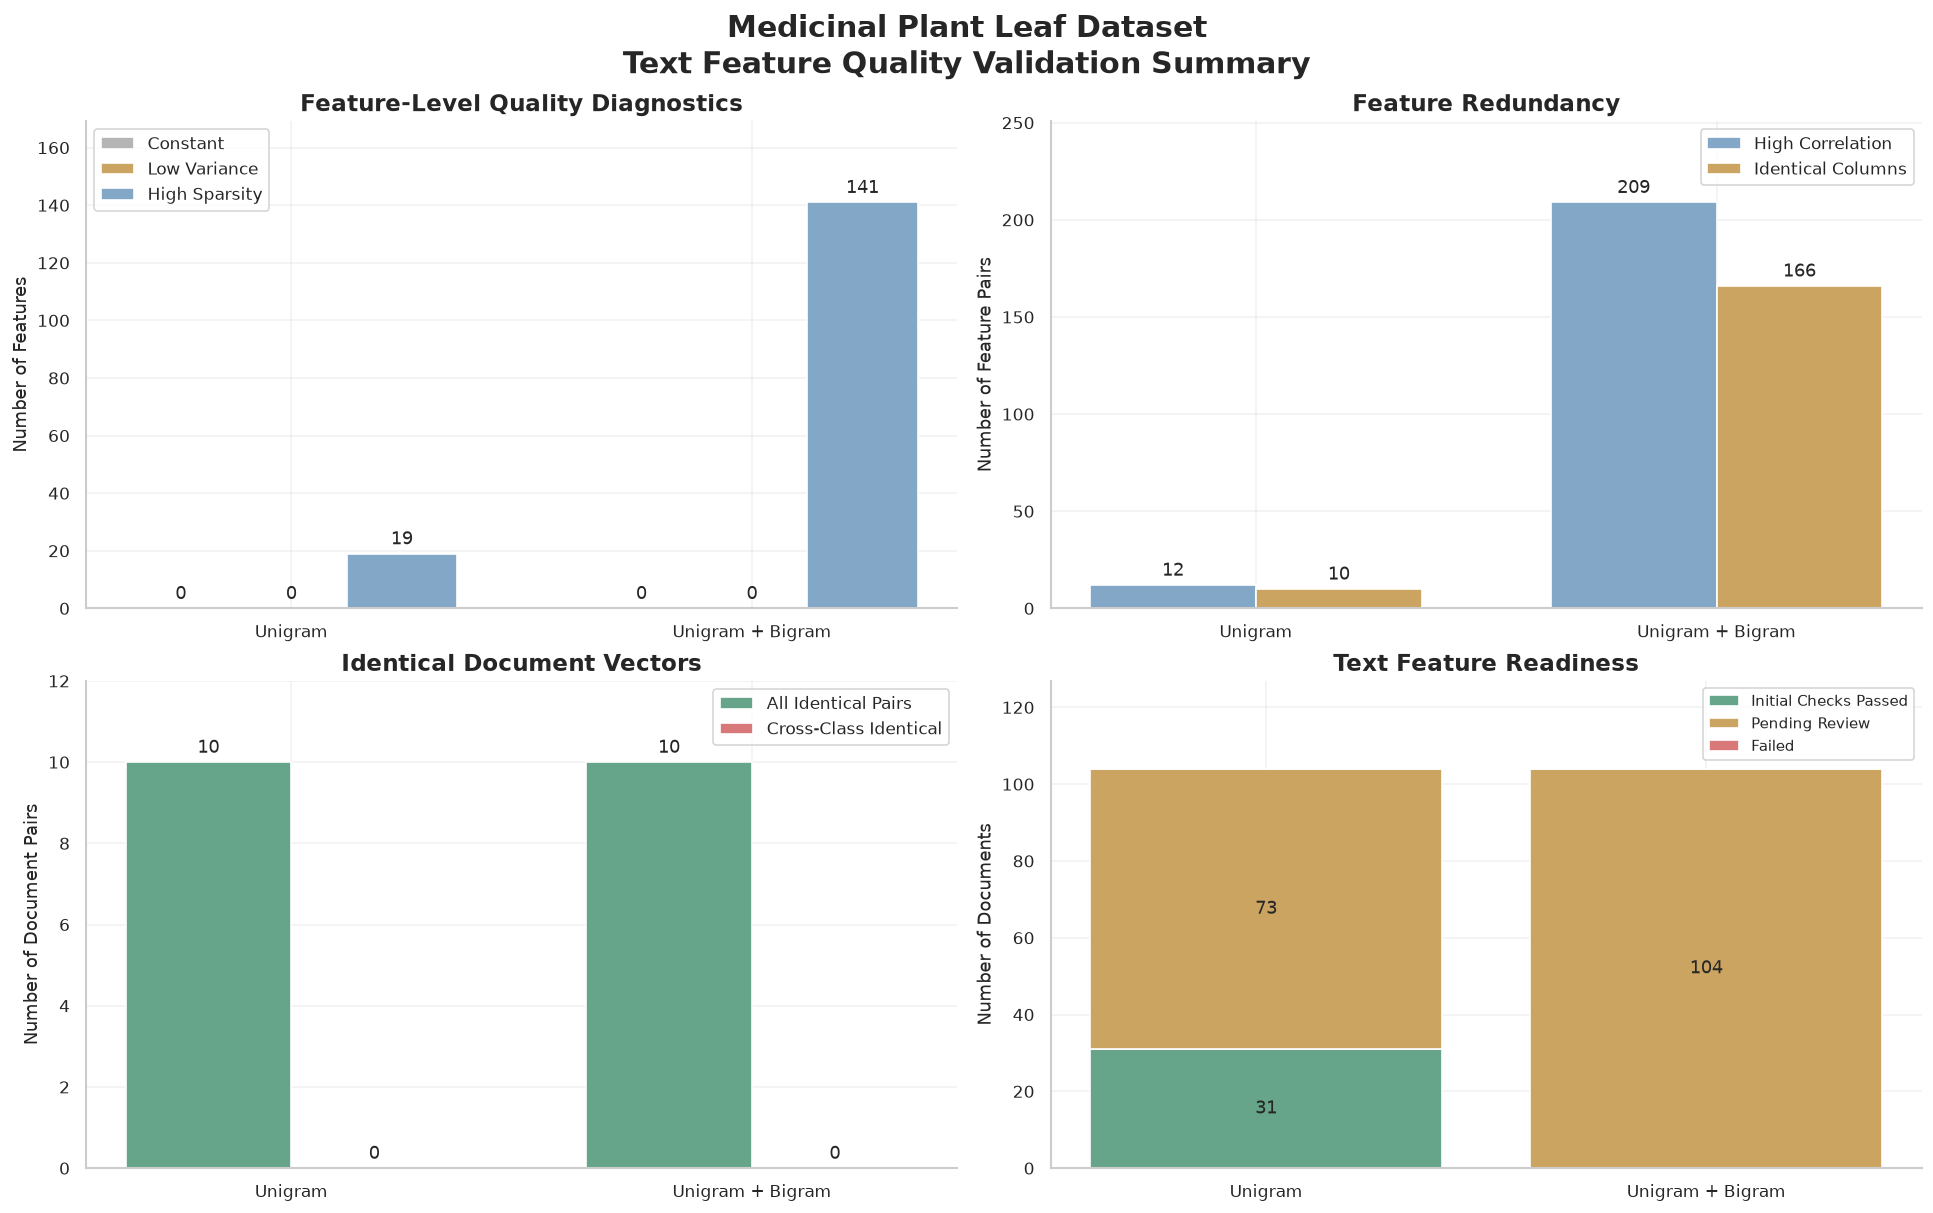

[SAVED] 83_text_feature_quality_summary.png


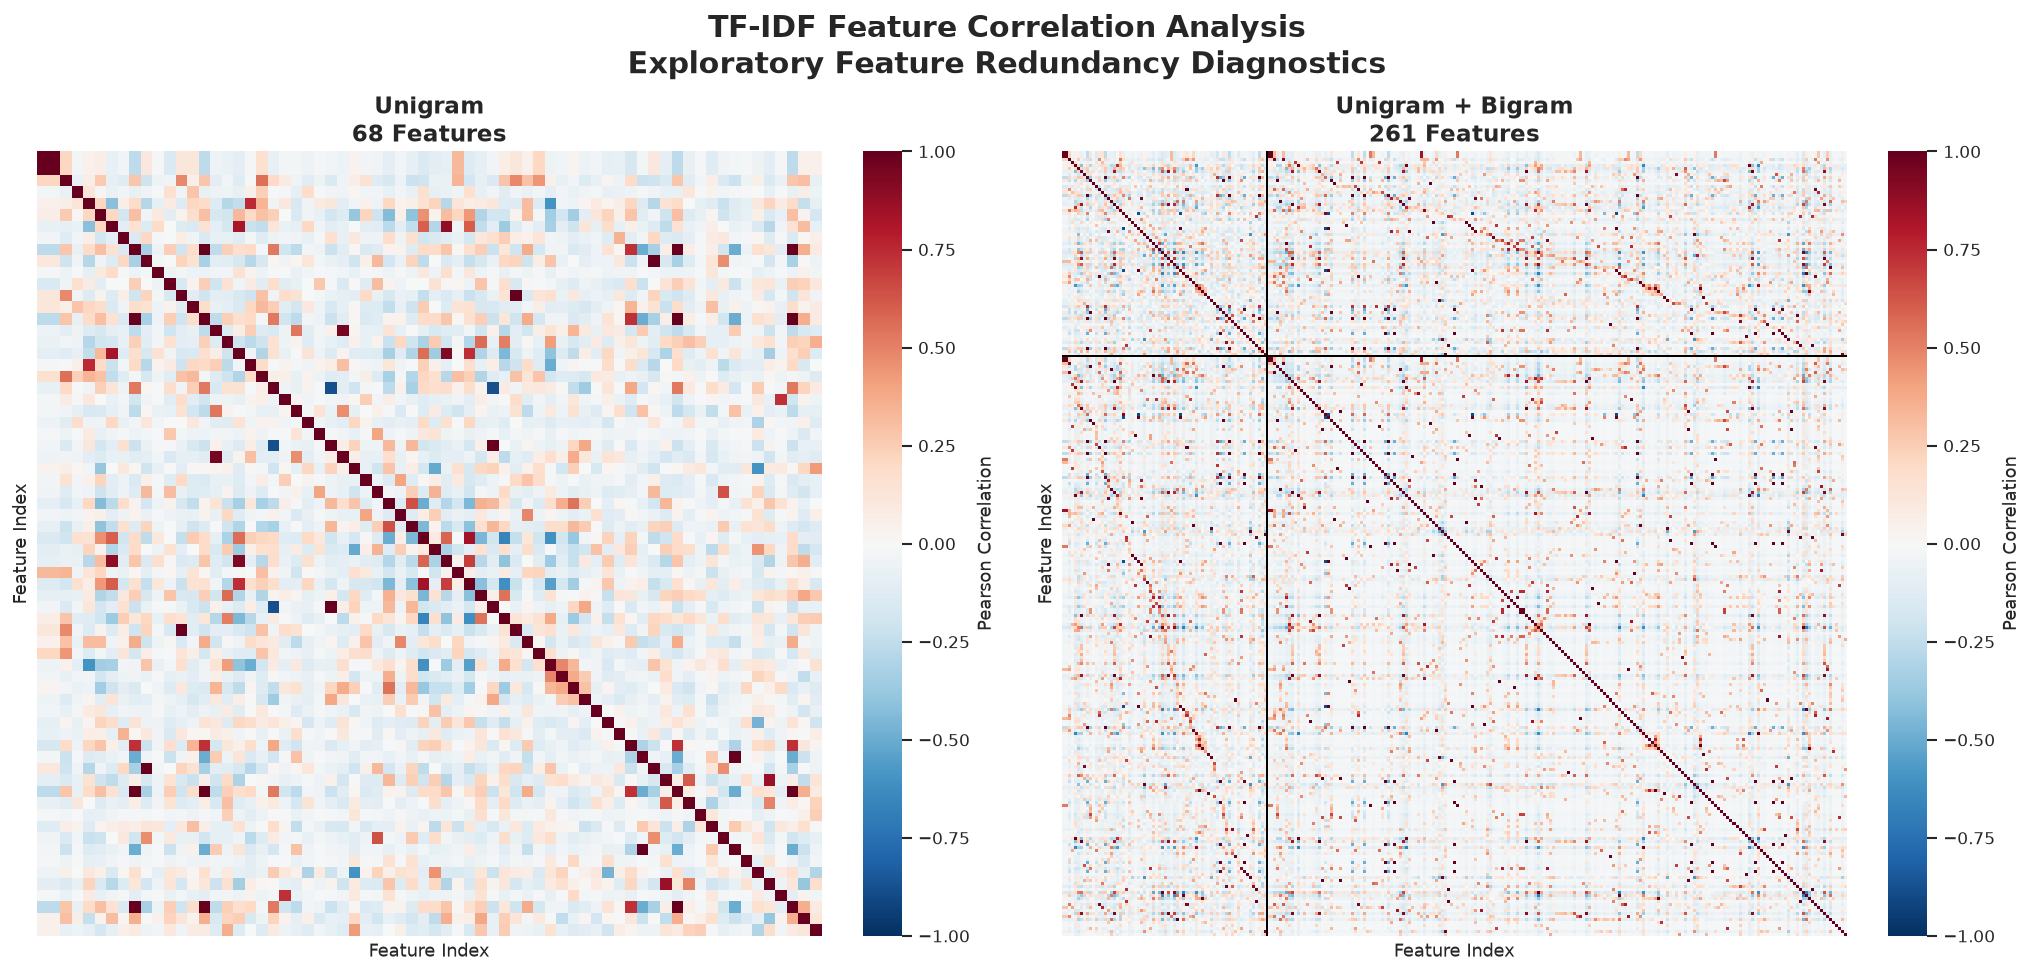

[SAVED] 84_tfidf_feature_correlation_matrices.png


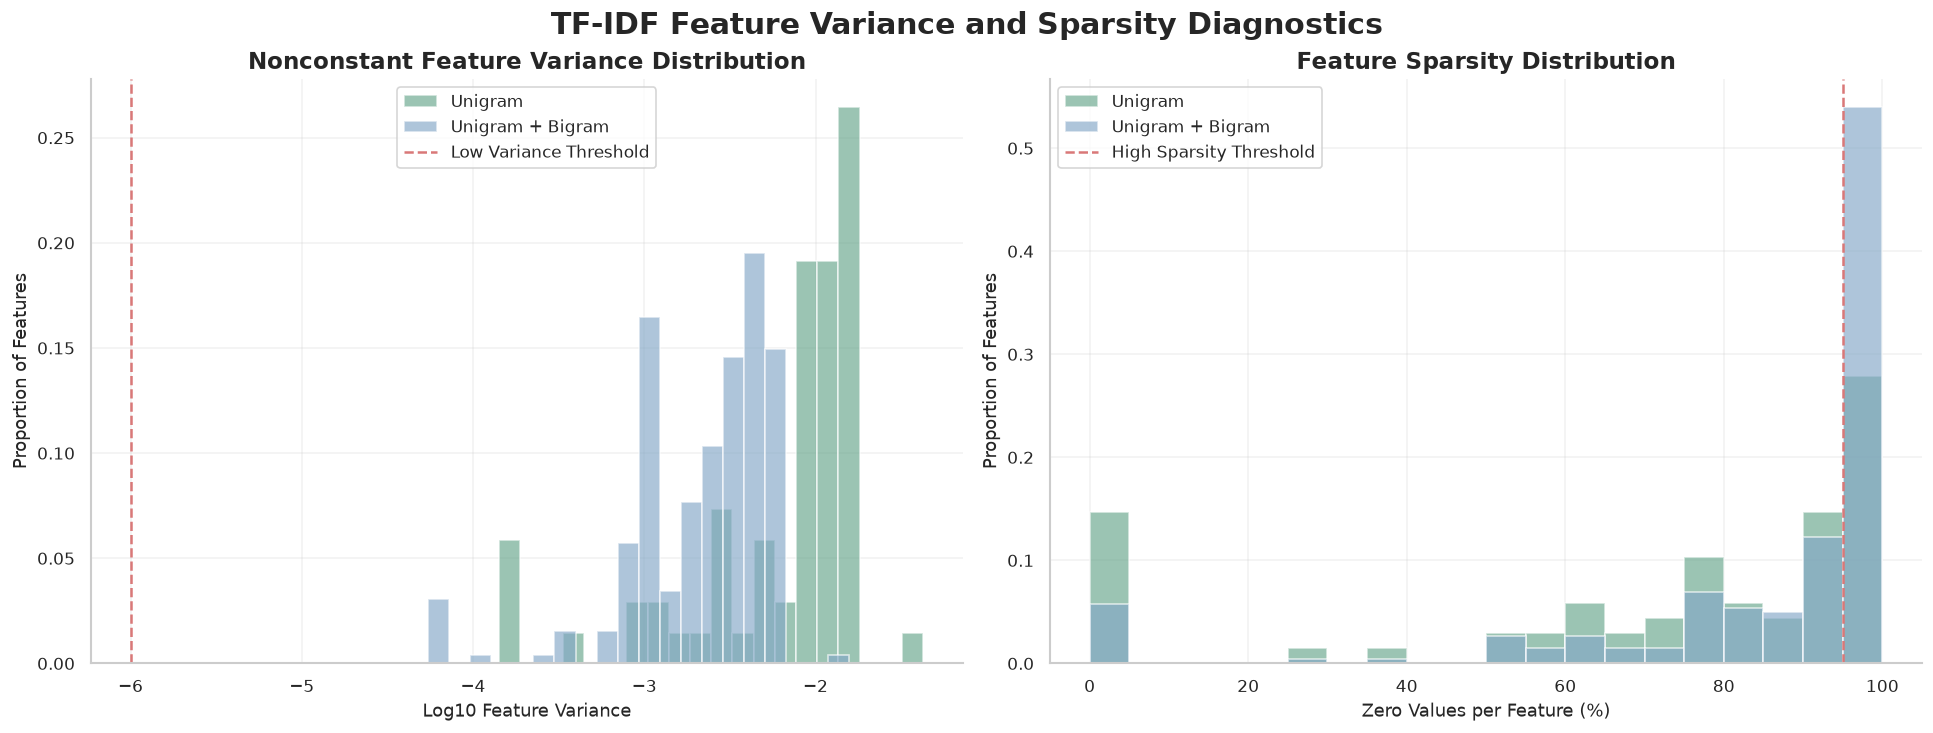

[SAVED] 85_tfidf_variance_sparsity_diagnostics.png


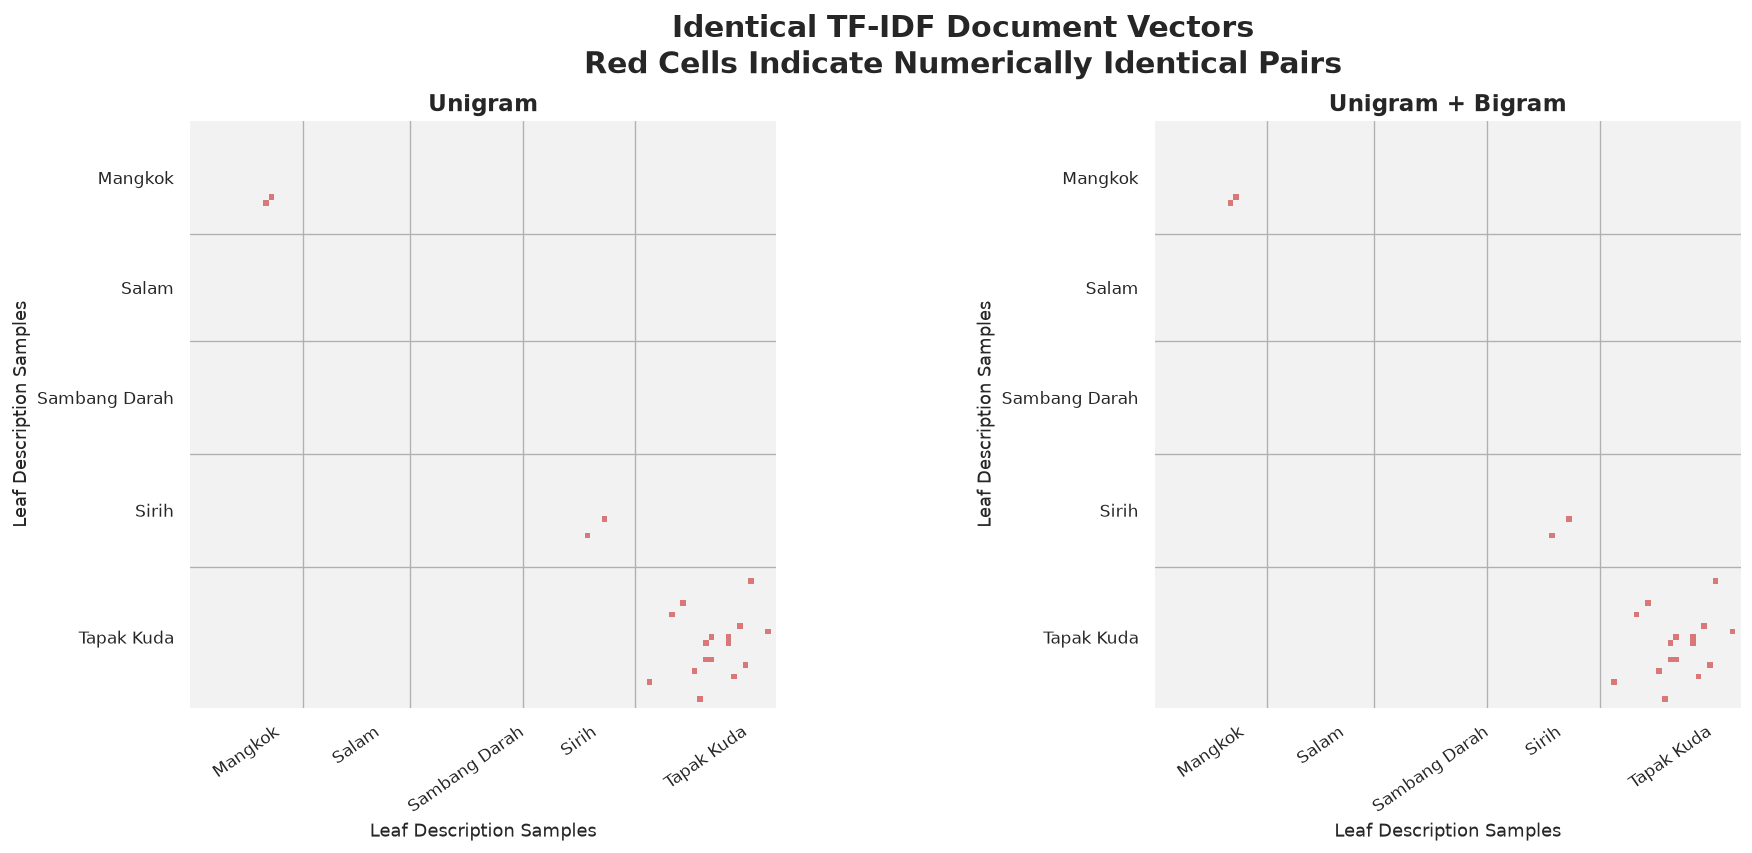

[SAVED] 86_tfidf_identical_document_vectors.png


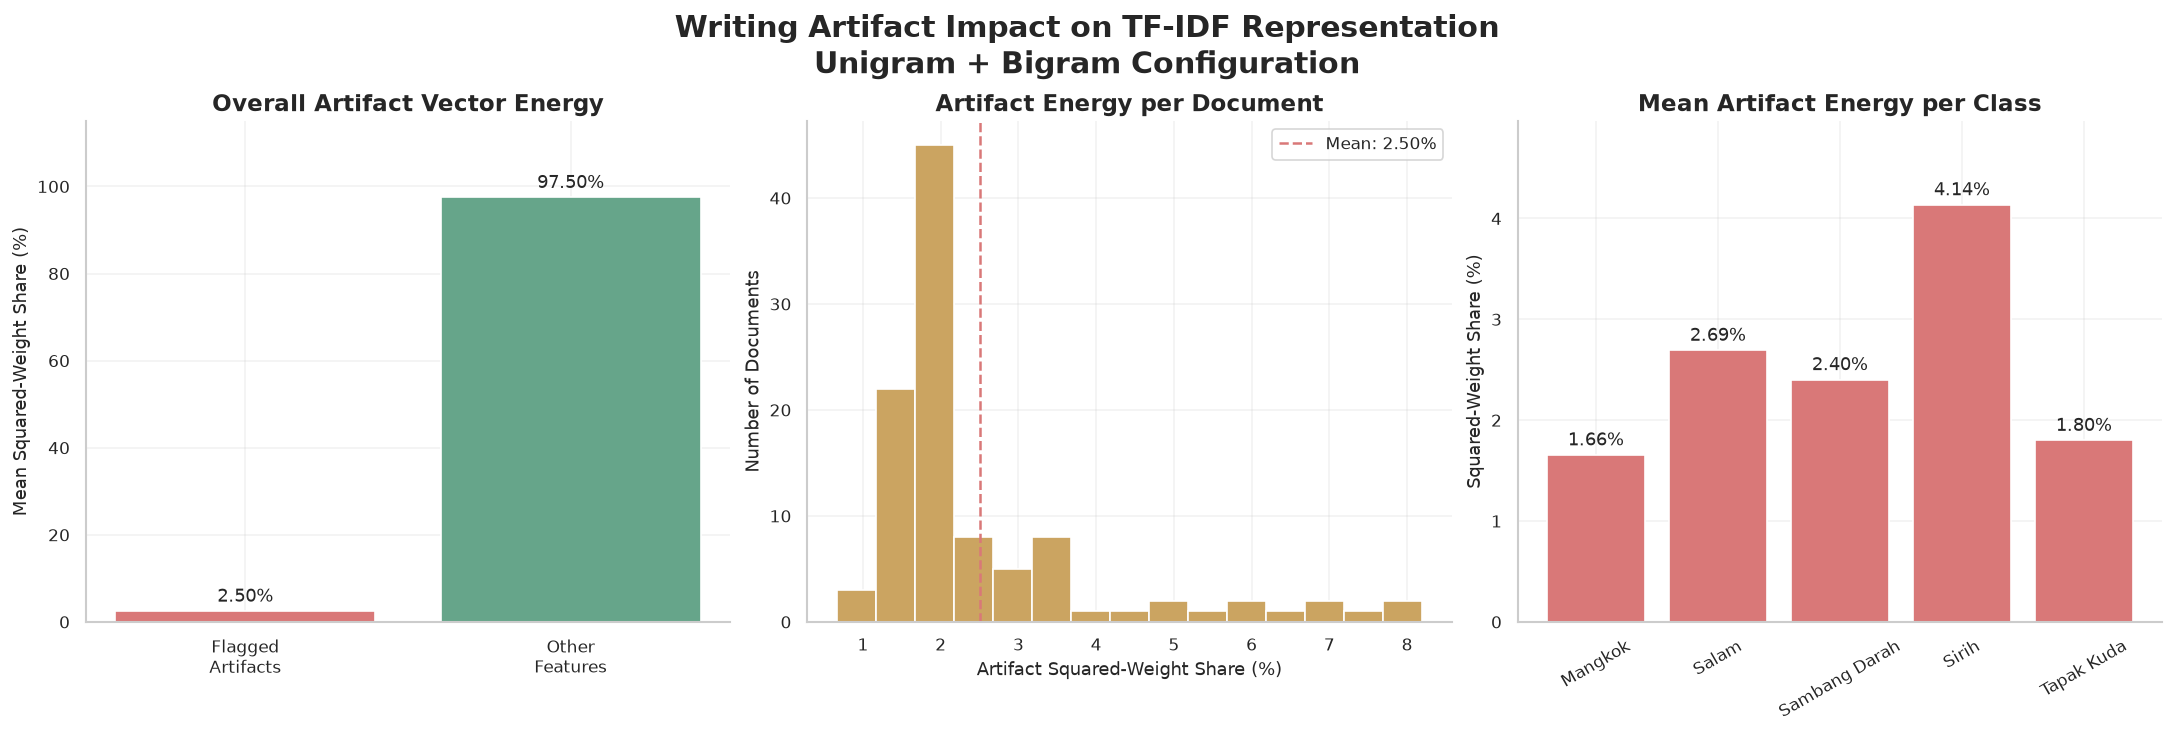

[SAVED] 87_tfidf_writing_artifact_impact.png

13. OVERALL TEXT FEATURE QUALITY SUMMARY
-----------------------------------------------------------------


,Indicator,Result
0,Total documents,104
1,Total configurations,2
2,Total feature records,329
3,Total document quality records,208
4,Exact duplicate description groups,8
5,Exact duplicate description members,17
6,Exact duplicate description pairs,10
7,Near-duplicate description pairs,75
8,Cross-class near-duplicate pairs,5
9,Constant feature records,0



14. SAVING QUALITY VALIDATION REPORTS
-----------------------------------------------------------------
[SAVED] 274_tfidf_feature_quality_statistics.csv
[SAVED] 275_tfidf_constant_features.csv
[SAVED] 276_tfidf_low_variance_features.csv
[SAVED] 277_tfidf_high_sparsity_features.csv
[SAVED] 278_tfidf_high_correlation_pairs.csv
[SAVED] 279_tfidf_identical_feature_pairs.csv
[SAVED] 280_tfidf_exact_duplicate_groups.csv
[SAVED] 281_tfidf_near_duplicate_pairs.csv
[SAVED] 282_tfidf_cross_class_near_duplicate_pairs.csv
[SAVED] 283_tfidf_identical_document_pairs.csv
[SAVED] 284_tfidf_redundancy_summary.csv
[SAVED] 285_tfidf_artifact_impact.csv
[SAVED] 286_tfidf_class_artifact_impact.csv
[SAVED] 287_tfidf_sample_quality.csv
[SAVED] 288_tfidf_quality_readiness.csv
[SAVED] 289_tfidf_feature_quality_summary.csv
[SAVED] 290_tfidf_quality_validation.csv
[SAVED] 291_tfidf_quality_validation_summary.csv

FINAL TEXT FEATURE QUALITY VALIDATION SUMMARY

DATASET INFORMATION
--------------------------------

In [10]:
# ==================================================
# CELL 11 - TEXT FEATURE QUALITY VALIDATION
# ==================================================

from scipy.spatial.distance import pdist, squareform
from scipy.sparse import issparse

print("TEXT FEATURE QUALITY VALIDATION")
print("=" * 65)

TEXT_FEATURE_QUALITY_VALIDATION_COMPLETED = False


# ==================================================
# 1. VALIDATE PREVIOUS PROCESSING STAGES
# ==================================================

assert TFIDF_FEATURE_EXTRACTION_COMPLETED is True
assert TFIDF_MATRIX_ANALYSIS_COMPLETED is True
assert IMPORTANT_TERM_VISUALIZATION_COMPLETED is True

assert tfidf_extraction_validation_df["passed"].all()
assert tfidf_matrix_analysis_validation_df["passed"].all()
assert tfidf_important_term_validation_df["passed"].all()

assert np.array_equal(
    tfidf_sample_ids,
    loaded_visual_sample_ids
)

assert np.array_equal(
    tfidf_labels,
    validated_text_labels
)

assert len(validated_text_corpus) == text_n_samples

text_quality_corpus_snapshot = list(
    validated_text_corpus
)

text_quality_matrix_snapshots = {
    name: matrix.copy()
    for name, matrix in tfidf_matrices.items()
}

print("\n[PASS] Previous processing stages validated.")


# ==================================================
# 2. TEXT FEATURE QUALITY CONFIGURATION
# ==================================================

TEXT_QUALITY_TOLERANCE = 1e-10

TEXT_LOW_VARIANCE_THRESHOLD = 1e-6

TEXT_HIGH_CORRELATION_THRESHOLD = 0.95

TEXT_HIGH_SPARSITY_THRESHOLD = 0.95

TEXT_NEAR_DUPLICATE_THRESHOLD = 0.85

TEXT_QUALITY_ANALYSIS_SCOPE = (
    "Exploratory Full-Gallery Analysis"
)

TEXT_QUALITY_COLORS = {

    TFIDF_BASELINE_NAME: "#66A58A",

    TFIDF_ALTERNATIVE_NAME: "#83A7C7"
}

text_quality_class_names = sorted(
    np.unique(tfidf_labels)
)

text_quality_figure_paths = []

print("\n1. QUALITY VALIDATION CONFIGURATION")
print("-" * 65)

print(f"Low variance threshold : {TEXT_LOW_VARIANCE_THRESHOLD}")
print(f"High correlation       : {TEXT_HIGH_CORRELATION_THRESHOLD}")
print(f"High sparsity          : {TEXT_HIGH_SPARSITY_THRESHOLD}")
print(f"Numerical tolerance    : {TEXT_QUALITY_TOLERANCE}")
print(f"Near-duplicate limit   : {TEXT_NEAR_DUPLICATE_THRESHOLD}")

print("[INFO] Diagnostic thresholds only.")
print("[INFO] No automatic feature removal.")


# ==================================================
# 3. INITIALIZE QUALITY ANALYSIS CONTAINERS
# ==================================================

text_feature_quality_records = []

text_correlation_records = []

text_identical_feature_records = []

text_identical_document_records = []

text_sample_quality_records = []

text_quality_summary_records = []

text_quality_validation_records = []

tfidf_feature_correlation_matrices = {}

tfidf_document_distance_matrices = {}


def register_text_quality_check(
    configuration,
    check_name,
    passed
):

    text_quality_validation_records.append({

        "configuration": configuration,

        "validation_check": check_name,

        "passed": bool(passed),

        "status": (
            "Passed" if passed else "Failed"
        )
    })


# ==================================================
# 4. ANALYZE EXACT DESCRIPTION DUPLICATION
# ==================================================

quality_documents_df = pd.DataFrame({

    "row_index": np.arange(text_n_samples),

    "sample_id": tfidf_sample_ids,

    "kelas": tfidf_labels,

    "description": validated_text_corpus
})

quality_documents_df["exact_duplicate_description"] = (

    quality_documents_df["description"]

    .duplicated(keep=False)
)

text_exact_duplicate_documents_df = (

    quality_documents_df.loc[

        quality_documents_df[
            "exact_duplicate_description"
        ]
    ]

    .copy()

    .reset_index(drop=True)
)

text_exact_duplicate_groups_df = (

    text_exact_duplicate_documents_df

    .groupby("description", sort=True)

    .agg(

        number_of_documents=(
            "sample_id", "count"
        ),

        number_of_classes=(
            "kelas", "nunique"
        ),

        classes=(
            "kelas",
            lambda x: ", ".join(sorted(set(x)))
        ),

        sample_ids=(
            "sample_id",
            lambda x: ", ".join(map(str, x))
        )
    )

    .reset_index()
)

text_exact_duplicate_groups_df[
    "cross_class_duplicate"
] = (

    text_exact_duplicate_groups_df[
        "number_of_classes"
    ] > 1
)

text_exact_duplicate_groups_df.insert(

    0,

    "duplicate_group_id",

    [

        f"text_quality_duplicate_{i:03d}"

        for i in range(
            1,
            len(text_exact_duplicate_groups_df) + 1
        )
    ]
)

document_pair_i, document_pair_j = np.triu_indices(

    text_n_samples,

    k=1
)

quality_corpus_array = np.asarray(
    validated_text_corpus,
    dtype=str
)

exact_description_pair_mask = (

    quality_corpus_array[document_pair_i]

    == quality_corpus_array[document_pair_j]
)

same_class_pair_mask = (

    tfidf_labels[document_pair_i]

    == tfidf_labels[document_pair_j]
)

print("\n2. EXACT DESCRIPTION DUPLICATION")
print("-" * 65)

print(
    f"Duplicate groups : "
    f"{len(text_exact_duplicate_groups_df)}"
)

print(
    f"Duplicate members: "
    f"{len(text_exact_duplicate_documents_df)}"
)

print(
    f"Duplicate pairs  : "
    f"{exact_description_pair_mask.sum()}"
)

display(text_exact_duplicate_groups_df)


# ==================================================
# 5. ANALYZE NEAR-DUPLICATE DESCRIPTIONS
# ==================================================

# Use the unigram analyzer to maintain consistency
# with the fitted baseline vocabulary.

quality_text_analyzer = (
    tfidf_vectorizer.build_analyzer()
)

quality_token_sets = [

    set(quality_text_analyzer(document))

    for document in validated_text_corpus
]

text_near_duplicate_records = []

for i, j in zip(
    document_pair_i,
    document_pair_j
):

    token_union = (

        quality_token_sets[i]

        | quality_token_sets[j]
    )

    token_intersection = (

        quality_token_sets[i]

        & quality_token_sets[j]
    )

    jaccard_score = (

        len(token_intersection)
        / len(token_union)

        if token_union
        else 0.0
    )

    if jaccard_score >= TEXT_NEAR_DUPLICATE_THRESHOLD:

        text_near_duplicate_records.append({

            "row_index_a": int(i),

            "row_index_b": int(j),

            "sample_id_a": tfidf_sample_ids[i],

            "sample_id_b": tfidf_sample_ids[j],

            "class_a": tfidf_labels[i],

            "class_b": tfidf_labels[j],

            "same_class": bool(
                tfidf_labels[i] == tfidf_labels[j]
            ),

            "exact_description_match": bool(
                quality_corpus_array[i]
                == quality_corpus_array[j]
            ),

            "jaccard_similarity": float(
                jaccard_score
            ),

            "description_a":
                validated_text_corpus[i],

            "description_b":
                validated_text_corpus[j]
        })


text_quality_near_duplicate_pairs_df = pd.DataFrame(

    text_near_duplicate_records,

    columns=[

        "row_index_a",
        "row_index_b",
        "sample_id_a",
        "sample_id_b",
        "class_a",
        "class_b",
        "same_class",
        "exact_description_match",
        "jaccard_similarity",
        "description_a",
        "description_b"
    ]
)

text_quality_near_duplicate_pairs_df = (

    text_quality_near_duplicate_pairs_df

    .sort_values(
        "jaccard_similarity",
        ascending=False
    )

    .reset_index(drop=True)
)

text_cross_class_near_duplicate_pairs_df = (

    text_quality_near_duplicate_pairs_df.loc[

        ~text_quality_near_duplicate_pairs_df[
            "same_class"
        ].astype(bool)
    ]

    .copy()

    .reset_index(drop=True)
)

near_duplicate_sample_ids = set(

    text_quality_near_duplicate_pairs_df[
        "sample_id_a"
    ]

) | set(

    text_quality_near_duplicate_pairs_df[
        "sample_id_b"
    ]
)

cross_class_near_duplicate_sample_ids = set(

    text_cross_class_near_duplicate_pairs_df[
        "sample_id_a"
    ]

) | set(

    text_cross_class_near_duplicate_pairs_df[
        "sample_id_b"
    ]
)

print("\n3. NEAR-DUPLICATE DESCRIPTION ANALYSIS")
print("-" * 65)

print(
    f"All flagged pairs       : "
    f"{len(text_quality_near_duplicate_pairs_df)}"
)

print(
    f"Cross-class pairs       : "
    f"{len(text_cross_class_near_duplicate_pairs_df)}"
)

print(
    f"Flagged unique documents: "
    f"{len(near_duplicate_sample_ids)}"
)

display(

    text_cross_class_near_duplicate_pairs_df[
        [
            "sample_id_a",
            "sample_id_b",
            "class_a",
            "class_b",
            "jaccard_similarity"
        ]
    ].round(6)
)


# ==================================================
# 6. ANALYZE FEATURE QUALITY
# ==================================================

print("\n4. FEATURE QUALITY ANALYSIS")
print("-" * 65)

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    matrix = tfidf_matrices[
        configuration_name
    ]

    dense_matrix = matrix.toarray()

    feature_names = tfidf_feature_names_by_config[
        configuration_name
    ]

    n_documents, n_features = dense_matrix.shape

    feature_means = dense_matrix.mean(axis=0)

    feature_variances = dense_matrix.var(
        axis=0,
        ddof=0
    )

    feature_standard_deviations = (
        np.sqrt(feature_variances)
    )

    feature_document_frequency = (
        dense_matrix > 0
    ).sum(axis=0)

    feature_zero_ratios = (

        1 - feature_document_frequency / n_documents
    )


    # --------------------------------------------------
    # A. Constant and low-variance features
    # --------------------------------------------------

    constant_feature_mask = (

        np.ptp(dense_matrix, axis=0) == 0
    )

    low_variance_feature_mask = (

        (feature_variances < TEXT_LOW_VARIANCE_THRESHOLD)

        & ~constant_feature_mask
    )

    high_sparsity_feature_mask = (

        feature_zero_ratios
        >= TEXT_HIGH_SPARSITY_THRESHOLD
    )


    # --------------------------------------------------
    # B. Pearson feature correlation
    # --------------------------------------------------

    # Constant columns do not have a defined
    # Pearson correlation.

    centered_features = (

        dense_matrix - feature_means
    )

    centered_feature_norms = np.linalg.norm(

        centered_features,

        axis=0
    )

    standardized_columns = np.divide(

        centered_features,

        centered_feature_norms,

        out=np.zeros_like(centered_features),

        where=centered_feature_norms > 0
    )

    feature_correlation_matrix = np.clip(

        standardized_columns.T
        @ standardized_columns,

        -1.0,

        1.0
    )

    feature_correlation_matrix[
        constant_feature_mask, :
    ] = np.nan

    feature_correlation_matrix[
        :, constant_feature_mask
    ] = np.nan

    tfidf_feature_correlation_matrices[
        configuration_name
    ] = feature_correlation_matrix

    feature_pair_i, feature_pair_j = np.triu_indices(

        n_features,

        k=1
    )

    correlation_values = feature_correlation_matrix[

        feature_pair_i,

        feature_pair_j
    ]

    high_correlation_mask = (

        np.isfinite(correlation_values)

        &

        (
            np.abs(correlation_values)
            >= TEXT_HIGH_CORRELATION_THRESHOLD
        )
    )


    # --------------------------------------------------
    # C. Numerically identical feature columns
    # --------------------------------------------------

    # Chebyshev distance is the largest absolute
    # difference between corresponding values.

    feature_column_max_differences = pdist(

        dense_matrix.T,

        metric="chebyshev"
    )

    identical_feature_mask = (

        feature_column_max_differences
        <= TEXT_QUALITY_TOLERANCE
    )

    high_corr_feature_indices = set()

    identical_feature_indices = set()

    for pair_index in np.flatnonzero(
        high_correlation_mask
    ):

        i = feature_pair_i[pair_index]

        j = feature_pair_j[pair_index]

        high_corr_feature_indices.update([i, j])

        term_a = feature_names[i]

        term_b = feature_names[j]

        text_correlation_records.append({

            "configuration": configuration_name,

            "feature_index_a": int(i),

            "feature_index_b": int(j),

            "term_a": term_a,

            "term_b": term_b,

            "ngram_type_a": (
                "Bigram" if " " in term_a
                else "Unigram"
            ),

            "ngram_type_b": (
                "Bigram" if " " in term_b
                else "Unigram"
            ),

            "pearson_correlation": float(
                correlation_values[pair_index]
            ),

            "absolute_correlation": float(
                abs(correlation_values[pair_index])
            ),

            "identical_columns": bool(
                identical_feature_mask[pair_index]
            )
        })


    for pair_index in np.flatnonzero(
        identical_feature_mask
    ):

        i = feature_pair_i[pair_index]

        j = feature_pair_j[pair_index]

        identical_feature_indices.update([i, j])

        text_identical_feature_records.append({

            "configuration": configuration_name,

            "feature_index_a": int(i),

            "feature_index_b": int(j),

            "term_a": feature_names[i],

            "term_b": feature_names[j],

            "maximum_absolute_difference": float(

                feature_column_max_differences[
                    pair_index
                ]
            ),

            "identical_within_tolerance": True
        })


    # --------------------------------------------------
    # D. Save feature-level quality diagnostics
    # --------------------------------------------------

    for feature_index, term in enumerate(
        feature_names
    ):

        text_feature_quality_records.append({

            "configuration": configuration_name,

            "feature_index": feature_index,

            "term": term,

            "ngram_type": (
                "Bigram" if " " in term
                else "Unigram"
            ),

            "mean_tfidf": float(
                feature_means[feature_index]
            ),

            "variance_tfidf": float(
                feature_variances[feature_index]
            ),

            "std_tfidf": float(
                feature_standard_deviations[
                    feature_index
                ]
            ),

            "document_frequency": int(
                feature_document_frequency[
                    feature_index
                ]
            ),

            "zero_ratio": float(
                feature_zero_ratios[feature_index]
            ),

            "constant_feature": bool(
                constant_feature_mask[feature_index]
            ),

            "low_variance_feature": bool(
                low_variance_feature_mask[
                    feature_index
                ]
            ),

            "high_sparsity_feature": bool(
                high_sparsity_feature_mask[
                    feature_index
                ]
            ),

            "high_correlation_member": (
                feature_index in high_corr_feature_indices
            ),

            "identical_column_member": (
                feature_index in identical_feature_indices
            ),

            "potential_writing_artifact": (
                term in artifact_term_set
            )
        })


    # --------------------------------------------------
    # E. Identical document feature vectors
    # --------------------------------------------------

    document_max_differences = pdist(

        dense_matrix,

        metric="chebyshev"
    )

    tfidf_document_distance_matrices[
        configuration_name
    ] = squareform(document_max_differences)

    identical_document_mask = (

        document_max_differences
        <= TEXT_QUALITY_TOLERANCE
    )

    identical_document_indices = set()

    cross_class_identical_document_indices = set()

    for pair_index in np.flatnonzero(
        identical_document_mask
    ):

        i = document_pair_i[pair_index]

        j = document_pair_j[pair_index]

        identical_document_indices.update([i, j])

        same_class = bool(
            tfidf_labels[i] == tfidf_labels[j]
        )

        exact_description_match = bool(

            quality_corpus_array[i]
            == quality_corpus_array[j]
        )

        if not same_class:

            cross_class_identical_document_indices.update(
                [i, j]
            )

        text_identical_document_records.append({

            "configuration": configuration_name,

            "row_index_a": int(i),

            "row_index_b": int(j),

            "sample_id_a": tfidf_sample_ids[i],

            "sample_id_b": tfidf_sample_ids[j],

            "class_a": tfidf_labels[i],

            "class_b": tfidf_labels[j],

            "same_class": same_class,

            "exact_description_match":
                exact_description_match,

            "maximum_absolute_difference": float(

                document_max_differences[
                    pair_index
                ]
            )
        })


    # --------------------------------------------------
    # F. Document-level quality validation
    # --------------------------------------------------

    document_norms = np.linalg.norm(

        dense_matrix,

        axis=1
    )

    document_nonzero_counts = np.count_nonzero(

        dense_matrix,

        axis=1
    )

    finite_document_mask = np.isfinite(

        dense_matrix

    ).all(axis=1)

    nonnegative_document_mask = (

        dense_matrix >= 0

    ).all(axis=1)

    valid_document_norms = np.isclose(

        document_norms,

        1.0,

        atol=TEXT_QUALITY_TOLERANCE,

        rtol=0
    )

    technical_valid_mask = (

        finite_document_mask

        & nonnegative_document_mask

        & (document_nonzero_counts > 0)

        & valid_document_norms
    )

    for row_index in range(n_documents):

        sample_id = tfidf_sample_ids[row_index]

        text_sample_quality_records.append({

            "configuration": configuration_name,

            "row_index": row_index,

            "sample_id": sample_id,

            "kelas": tfidf_labels[row_index],

            "nonzero_features": int(
                document_nonzero_counts[row_index]
            ),

            "l2_norm": float(
                document_norms[row_index]
            ),

            "finite_values": bool(
                finite_document_mask[row_index]
            ),

            "nonnegative_values": bool(
                nonnegative_document_mask[
                    row_index
                ]
            ),

            "technical_valid": bool(
                technical_valid_mask[row_index]
            ),

            "exact_duplicate_description": bool(

                quality_documents_df.iloc[row_index][
                    "exact_duplicate_description"
                ]
            ),

            "identical_document_vector": (
                row_index in identical_document_indices
            ),

            "cross_class_identical_vector": (

                row_index
                in cross_class_identical_document_indices
            ),

            "near_duplicate_description": (

                sample_id in near_duplicate_sample_ids
            ),

            "cross_class_near_duplicate": (

                sample_id
                in cross_class_near_duplicate_sample_ids
            )
        })


    # --------------------------------------------------
    # G. Register quality summary
    # --------------------------------------------------

    text_quality_summary_records.append({

        "configuration": configuration_name,

        "number_of_documents": n_documents,

        "feature_dimension": n_features,

        "constant_features": int(
            constant_feature_mask.sum()
        ),

        "low_variance_features": int(
            low_variance_feature_mask.sum()
        ),

        "high_sparsity_features": int(
            high_sparsity_feature_mask.sum()
        ),

        "high_correlation_pairs": int(
            high_correlation_mask.sum()
        ),

        "high_correlation_feature_members": len(
            high_corr_feature_indices
        ),

        "identical_feature_pairs": int(
            identical_feature_mask.sum()
        ),

        "identical_feature_members": len(
            identical_feature_indices
        ),

        "identical_document_pairs": int(
            identical_document_mask.sum()
        ),

        "identical_document_members": len(
            identical_document_indices
        ),

        "cross_class_identical_document_pairs": int(

            np.sum(

                identical_document_mask

                & ~same_class_pair_mask
            )
        ),

        "identical_vectors_different_descriptions": int(

            np.sum(

                identical_document_mask

                & ~exact_description_pair_mask
            )
        ),

        "technical_valid_documents": int(
            technical_valid_mask.sum()
        ),

        "technical_failed_documents": int(
            (~technical_valid_mask).sum()
        ),

        "nan_values": int(
            np.isnan(dense_matrix).sum()
        ),

        "infinite_values": int(
            np.isinf(dense_matrix).sum()
        )
    })


    # --------------------------------------------------
    # H. Technical and mathematical checks
    # --------------------------------------------------

    quality_checks = {

        "Correct matrix dimensions": (

            matrix.shape == (
                text_n_samples,
                len(feature_names)
            )
        ),

        "Sparse CSR representation": (

            issparse(matrix)

            and matrix.format == "csr"
        ),

        "Correct float64 data type": (

            matrix.dtype == np.dtype(TEXT_FEATURE_DTYPE)
        ),

        "Finite matrix values": (

            np.isfinite(dense_matrix).all()
        ),

        "Nonnegative matrix values": (

            np.all(dense_matrix >= 0)
        ),

        "No empty document vectors": (

            np.all(document_nonzero_counts > 0)
        ),

        "L2 normalization valid": (

            valid_document_norms.all()
        ),

        "Nonzero element counts reconcile": (

            document_nonzero_counts.sum()

            == feature_document_frequency.sum()

            == matrix.nnz
        ),

        "Feature variances finite and nonnegative": (

            np.isfinite(feature_variances).all()

            and np.all(feature_variances >= 0)
        ),

        "Correlation matrix symmetric": (

            np.allclose(

                feature_correlation_matrix,

                feature_correlation_matrix.T,

                atol=TEXT_QUALITY_TOLERANCE,

                rtol=0,

                equal_nan=True
            )
        ),

        "Nonconstant correlation diagonal valid": (

            np.allclose(

                np.diag(feature_correlation_matrix)[
                    ~constant_feature_mask
                ],

                1.0,

                atol=TEXT_QUALITY_TOLERANCE,

                rtol=0
            )
        ),

        "Exact descriptions have identical vectors": (

            np.all(

                identical_document_mask[
                    exact_description_pair_mask
                ]
            )
        ),

        "Document distances finite": (

            np.isfinite(document_max_differences).all()
        ),

        "All document technical checks passed": (

            technical_valid_mask.all()
        )
    }

    for check_name, passed in quality_checks.items():

        register_text_quality_check(

            configuration_name,

            check_name,

            passed
        )


    print(f"\nConfiguration: {configuration_name}")

    print(
        f"Constant features       : "
        f"{constant_feature_mask.sum()}"
    )

    print(
        f"Low-variance features   : "
        f"{low_variance_feature_mask.sum()}"
    )

    print(
        f"High-sparsity features  : "
        f"{high_sparsity_feature_mask.sum()}"
    )

    print(
        f"High-correlation pairs  : "
        f"{high_correlation_mask.sum()}"
    )

    print(
        f"Identical feature pairs : "
        f"{identical_feature_mask.sum()}"
    )

    print(
        f"Identical document pairs: "
        f"{identical_document_mask.sum()}"
    )

    print(
        f"Technical valid samples : "
        f"{technical_valid_mask.sum()}/{n_documents}"
    )


# ==================================================
# 7. CREATE QUALITY DIAGNOSTIC DATAFRAMES
# ==================================================

tfidf_feature_quality_df = pd.DataFrame(
    text_feature_quality_records
)

tfidf_high_correlation_pairs_df = pd.DataFrame(

    text_correlation_records,

    columns=[

        "configuration",
        "feature_index_a",
        "feature_index_b",
        "term_a",
        "term_b",
        "ngram_type_a",
        "ngram_type_b",
        "pearson_correlation",
        "absolute_correlation",
        "identical_columns"
    ]
)

tfidf_identical_feature_pairs_df = pd.DataFrame(

    text_identical_feature_records,

    columns=[

        "configuration",
        "feature_index_a",
        "feature_index_b",
        "term_a",
        "term_b",
        "maximum_absolute_difference",
        "identical_within_tolerance"
    ]
)

tfidf_identical_document_pairs_df = pd.DataFrame(

    text_identical_document_records,

    columns=[

        "configuration",
        "row_index_a",
        "row_index_b",
        "sample_id_a",
        "sample_id_b",
        "class_a",
        "class_b",
        "same_class",
        "exact_description_match",
        "maximum_absolute_difference"
    ]
)

tfidf_sample_quality_df = pd.DataFrame(
    text_sample_quality_records
)

tfidf_feature_quality_summary_df = pd.DataFrame(
    text_quality_summary_records
)

tfidf_constant_features_df = (

    tfidf_feature_quality_df.loc[

        tfidf_feature_quality_df[
            "constant_feature"
        ]
    ].copy()
)

tfidf_low_variance_features_df = (

    tfidf_feature_quality_df.loc[

        tfidf_feature_quality_df[
            "low_variance_feature"
        ]
    ].copy()
)

tfidf_high_sparsity_features_df = (

    tfidf_feature_quality_df.loc[

        tfidf_feature_quality_df[
            "high_sparsity_feature"
        ]
    ]

    .sort_values(
        ["configuration", "zero_ratio", "term"],
        ascending=[True, False, True]
    )

    .reset_index(drop=True)
)

print("\n5. TEXT FEATURE QUALITY SUMMARY")
print("-" * 65)

display(tfidf_feature_quality_summary_df)

print("\n6. IDENTICAL FEATURE COLUMN EXAMPLES")
print("-" * 65)

display(
    tfidf_identical_feature_pairs_df.head(20)
)

print("\n7. HIGH-CORRELATION FEATURE EXAMPLES")
print("-" * 65)

display(

    tfidf_high_correlation_pairs_df

    .sort_values(
        "absolute_correlation",
        ascending=False
    )

    .head(20)

    .round(8)
)

print("\n8. IDENTICAL DOCUMENT VECTORS")
print("-" * 65)

display(tfidf_identical_document_pairs_df)


# ==================================================
# 8. ANALYZE IDENTICAL FEATURE PAIR TYPES
# ==================================================

tfidf_redundancy_summary_df = (

    tfidf_high_correlation_pairs_df

    .copy()
)

tfidf_redundancy_summary_df["pair_type"] = [

    "Unigram-Unigram"

    if a == "Unigram" and b == "Unigram"

    else "Bigram-Bigram"

    if a == "Bigram" and b == "Bigram"

    else "Unigram-Bigram"

    for a, b in zip(

        tfidf_redundancy_summary_df[
            "ngram_type_a"
        ],

        tfidf_redundancy_summary_df[
            "ngram_type_b"
        ]
    )
]

tfidf_redundancy_summary_df = (

    tfidf_redundancy_summary_df

    .groupby(
        ["configuration", "pair_type"],
        sort=False
    )

    .agg(

        high_correlation_pairs=(
            "absolute_correlation", "count"
        ),

        identical_feature_pairs=(
            "identical_columns", "sum"
        )
    )

    .reset_index()
)

print("\n9. FEATURE REDUNDANCY BY N-GRAM TYPE")
print("-" * 65)

display(tfidf_redundancy_summary_df)


# ==================================================
# 9. ANALYZE WRITING ARTIFACT IMPACT
# ==================================================

# Calculate squared-weight energy from features
# flagged for each individual document in Cell 10.
#
# Do not sum the same feature twice when it has
# multiple artifact flags.

quality_combined_matrix = (
    tfidf_bigram_matrix.toarray()
)

quality_combined_lookup = {

    term: index

    for index, term in enumerate(
        tfidf_bigram_feature_names
    )
}

artifact_feature_mask = np.zeros(

    quality_combined_matrix.shape,

    dtype=bool
)

repeated_artifact_feature_mask = np.zeros_like(
    artifact_feature_mask
)

boundary_artifact_feature_mask = np.zeros_like(
    artifact_feature_mask
)

artifact_mapping_valid = True

for _, row in tfidf_writing_artifacts_df.iterrows():

    row_index = int(row["row_index"])

    term = row["term"]

    if (

        not 0 <= row_index < text_n_samples

        or term not in quality_combined_lookup
    ):

        artifact_mapping_valid = False

        continue

    feature_index = quality_combined_lookup[term]

    if (

        tfidf_sample_ids[row_index]
        != row["sample_id"]
    ):

        artifact_mapping_valid = False

        continue

    artifact_feature_mask[
        row_index, feature_index
    ] = True

    if row["artifact_type"] == "Adjacent Repeated Word":

        repeated_artifact_feature_mask[
            row_index, feature_index
        ] = True

    elif row["artifact_type"] == "Possible Cross-Sentence Bigram":

        boundary_artifact_feature_mask[
            row_index, feature_index
        ] = True


combined_squared_weights = (
    quality_combined_matrix ** 2
)

combined_document_energy = (
    combined_squared_weights.sum(axis=1)
)

artifact_energy = np.sum(

    combined_squared_weights
    * artifact_feature_mask,

    axis=1
)

repeated_artifact_energy = np.sum(

    combined_squared_weights
    * repeated_artifact_feature_mask,

    axis=1
)

boundary_artifact_energy = np.sum(

    combined_squared_weights
    * boundary_artifact_feature_mask,

    axis=1
)

artifact_energy_percent = (

    artifact_energy
    / combined_document_energy * 100
)

tfidf_artifact_impact_df = pd.DataFrame({

    "row_index": np.arange(text_n_samples),

    "sample_id": tfidf_sample_ids,

    "kelas": tfidf_labels,

    "flagged_artifact_features": (
        artifact_feature_mask.sum(axis=1)
    ),

    "repeated_word_artifact": (
        repeated_artifact_feature_mask.any(axis=1)
    ),

    "cross_sentence_artifact": (
        boundary_artifact_feature_mask.any(axis=1)
    ),

    "artifact_energy_percent":
        artifact_energy_percent,

    "repeated_word_energy_percent": (

        repeated_artifact_energy
        / combined_document_energy * 100
    ),

    "cross_sentence_energy_percent": (

        boundary_artifact_energy
        / combined_document_energy * 100
    ),

    "remaining_vector_energy_percent": (

        100 - artifact_energy_percent
    )
})

tfidf_class_artifact_impact_df = (

    tfidf_artifact_impact_df

    .groupby("kelas", sort=True)

    .agg(

        number_of_documents=(
            "sample_id", "count"
        ),

        affected_documents=(
            "flagged_artifact_features",
            lambda x: int((x > 0).sum())
        ),

        mean_artifact_energy_percent=(
            "artifact_energy_percent", "mean"
        ),

        minimum_artifact_energy_percent=(
            "artifact_energy_percent", "min"
        ),

        maximum_artifact_energy_percent=(
            "artifact_energy_percent", "max"
        )
    )

    .reset_index()
)

print("\n10. WRITING ARTIFACT IMPACT")
print("-" * 65)

print(
    f"Mean artifact energy: "
    f"{artifact_energy_percent.mean():.4f}%"
)

print(
    f"Maximum artifact energy: "
    f"{artifact_energy_percent.max():.4f}%"
)

display(
    tfidf_class_artifact_impact_df.round(6)
)


# ==================================================
# 10. DETERMINE TEXT FEATURE READINESS
# ==================================================

# Keep technical validity separate from
# unresolved data-quality review flags.

artifact_sample_ids = set(

    tfidf_artifact_impact_df.loc[

        tfidf_artifact_impact_df[
            "flagged_artifact_features"
        ].gt(0),

        "sample_id"
    ]
)

repeated_word_sample_ids = set(

    tfidf_artifact_impact_df.loc[

        tfidf_artifact_impact_df[
            "repeated_word_artifact"
        ],

        "sample_id"
    ]
)

tfidf_sample_quality_df[
    "source_repeated_word_review"
] = (

    tfidf_sample_quality_df[
        "sample_id"
    ].isin(repeated_word_sample_ids)
)

tfidf_sample_quality_df[
    "potential_artifact_feature_review"
] = (

    tfidf_sample_quality_df[
        "configuration"
    ].eq(TFIDF_ALTERNATIVE_NAME)

    &

    tfidf_sample_quality_df[
        "sample_id"
    ].isin(artifact_sample_ids)
)

tfidf_sample_quality_df[
    "quality_review_required"
] = (

    tfidf_sample_quality_df[
        [
            "exact_duplicate_description",
            "identical_document_vector",
            "near_duplicate_description",
            "cross_class_near_duplicate",
            "source_repeated_word_review",
            "potential_artifact_feature_review"
        ]
    ].any(axis=1)
)

tfidf_sample_quality_df[
    "text_feature_quality_status"
] = np.select(

    [

        ~tfidf_sample_quality_df["technical_valid"],

        tfidf_sample_quality_df["quality_review_required"]
    ],

    [

        "Failed",

        "Ready - Pending Review"
    ],

    default="Ready - Initial Checks Passed"
)

text_quality_status_order = [

    "Ready - Initial Checks Passed",

    "Ready - Pending Review",

    "Failed"
]

tfidf_quality_readiness_df = (

    tfidf_sample_quality_df

    .groupby(
        ["configuration", "text_feature_quality_status"]
    )

    .size()

    .unstack(fill_value=0)

    .reindex(
        columns=text_quality_status_order,
        fill_value=0
    )

    .reindex(TFIDF_CONFIGURATION_ORDER)

    .reset_index()
)

tfidf_quality_readiness_df[
    "total_documents"
] = (

    tfidf_quality_readiness_df[
        text_quality_status_order
    ].sum(axis=1)
)

print("\n11. TEXT FEATURE QUALITY READINESS")
print("-" * 65)

display(tfidf_quality_readiness_df)

print(
    "[INFO] Readiness status is diagnostic only."
)

print(
    "[INFO] Previous metadata review status remains unchanged."
)


# ==================================================
# 11. OVERALL QUALITY VALIDATION
# ==================================================

text_quality_matrices_unchanged = True

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    difference = (

        tfidf_matrices[configuration_name]

        - text_quality_matrix_snapshots[
            configuration_name
        ]
    )

    difference.eliminate_zeros()

    text_quality_matrices_unchanged = (

        text_quality_matrices_unchanged

        and difference.nnz == 0
    )


text_quality_overall_checks = {

    "Original TF-IDF matrices unchanged": (

        text_quality_matrices_unchanged
    ),

    "Original text corpus unchanged": (

        list(validated_text_corpus)

        == text_quality_corpus_snapshot
    ),

    "Image-text alignment preserved": (

        np.array_equal(

            tfidf_sample_ids,

            loaded_visual_sample_ids
        )
    ),

    "Artifact sample-feature mapping valid": (

        artifact_mapping_valid
    ),

    "Artifact weights positive": (

        np.all(

            quality_combined_matrix[
                artifact_feature_mask
            ] > 0
        )
    ),

    "Artifact energy within valid range": (

        np.isfinite(artifact_energy_percent).all()

        and np.all(artifact_energy_percent >= 0)

        and np.all(

            artifact_energy_percent
            <= 100 + TEXT_QUALITY_TOLERANCE
        )
    ),

    "Artifact masks reconcile": (

        np.array_equal(

            artifact_feature_mask,

            repeated_artifact_feature_mask

            | boundary_artifact_feature_mask
        )
    ),

    "Artifact and remaining energy reconcile": (

        np.allclose(

            tfidf_artifact_impact_df[
                "artifact_energy_percent"
            ]

            + tfidf_artifact_impact_df[
                "remaining_vector_energy_percent"
            ],

            100.0,

            atol=TEXT_QUALITY_TOLERANCE,

            rtol=0
        )
    ),

    "Feature-level records reconcile": (

        len(tfidf_feature_quality_df)

        == sum(

            matrix.shape[1]

            for matrix in tfidf_matrices.values()
        )
    ),

    "Document-level records reconcile": (

        len(tfidf_sample_quality_df)

        == text_n_samples * len(tfidf_matrices)
    ),

    "Readiness counts reconcile": (

        tfidf_quality_readiness_df[
            "total_documents"
        ].eq(text_n_samples).all()
    )
}

for check_name, passed in (
    text_quality_overall_checks.items()
):

    register_text_quality_check(

        "Overall",

        check_name,

        passed
    )

tfidf_quality_validation_df = pd.DataFrame(
    text_quality_validation_records
)

print("\n12. TECHNICAL VALIDATION RESULTS")
print("-" * 65)

display(tfidf_quality_validation_df)

assert tfidf_quality_validation_df["passed"].all(), (

    tfidf_quality_validation_df.loc[

        ~tfidf_quality_validation_df["passed"]
    ].to_string(index=False)
)

print("[PASS] All technical quality checks passed.")


# ==================================================
# 12. VISUALIZATION HELPER
# ==================================================

def save_text_quality_figure(fig, filename):

    output_path = (
        TEXT_FEATURE_FIGURES_DIR / filename
    )

    fig.savefig(

        output_path,

        dpi=300,

        bbox_inches="tight"
    )

    text_quality_figure_paths.append(
        output_path
    )

    plt.show()
    plt.close(fig)

    print(f"[SAVED] {filename}")


# ==================================================
# 13. VISUALIZE TEXT FEATURE QUALITY SUMMARY
# ==================================================

fig, axes = plt.subplots(

    2, 2,

    figsize=(16, 10),

    constrained_layout=True
)

quality_plot_labels = [

    "Unigram",

    "Unigram + Bigram"
]

quality_plot_colors = [

    "#66A58A",

    "#83A7C7"
]


# --------------------------------------------------
# A. Constant, low-variance and high-sparsity features
# --------------------------------------------------

ax = axes[0, 0]

positions = np.arange(2)

bar_width = 0.24

for offset, column, label, color in [

    (
        -bar_width,
        "constant_features",
        "Constant",
        "#B5B5B5"
    ),

    (
        0,
        "low_variance_features",
        "Low Variance",
        "#CBA461"
    ),

    (
        bar_width,
        "high_sparsity_features",
        "High Sparsity",
        "#83A7C7"
    )
]:

    bars = ax.bar(

        positions + offset,

        tfidf_feature_quality_summary_df[column],

        width=bar_width,

        label=label,

        color=color
    )

    ax.bar_label(
        bars,
        padding=3
    )

ax.set_xticks(positions)

ax.set_xticklabels(quality_plot_labels)

ax.set_ylabel("Number of Features")

ax.set_title("Feature-Level Quality Diagnostics")

ax.legend()

ax.margins(y=0.2)


# --------------------------------------------------
# B. Redundancy
# --------------------------------------------------

ax = axes[0, 1]

bars_a = ax.bar(

    positions - 0.18,

    tfidf_feature_quality_summary_df[
        "high_correlation_pairs"
    ],

    width=0.36,

    color="#83A7C7",

    label="High Correlation"
)

bars_b = ax.bar(

    positions + 0.18,

    tfidf_feature_quality_summary_df[
        "identical_feature_pairs"
    ],

    width=0.36,

    color="#CBA461",

    label="Identical Columns"
)

ax.bar_label(bars_a, padding=3)

ax.bar_label(bars_b, padding=3)

ax.set_xticks(positions)

ax.set_xticklabels(quality_plot_labels)

ax.set_title("Feature Redundancy")

ax.set_ylabel("Number of Feature Pairs")

ax.legend()

ax.margins(y=0.2)


# --------------------------------------------------
# C. Identical document vectors
# --------------------------------------------------

ax = axes[1, 0]

bars_a = ax.bar(

    positions - 0.18,

    tfidf_feature_quality_summary_df[
        "identical_document_pairs"
    ],

    width=0.36,

    color="#66A58A",

    label="All Identical Pairs"
)

bars_b = ax.bar(

    positions + 0.18,

    tfidf_feature_quality_summary_df[
        "cross_class_identical_document_pairs"
    ],

    width=0.36,

    color="#D97878",

    label="Cross-Class Identical"
)

ax.bar_label(bars_a, padding=3)

ax.bar_label(bars_b, padding=3)

ax.set_xticks(positions)

ax.set_xticklabels(quality_plot_labels)

ax.set_title("Identical Document Vectors")

ax.set_ylabel("Number of Document Pairs")

ax.legend()

ax.margins(y=0.2)


# --------------------------------------------------
# D. Feature readiness
# --------------------------------------------------

ax = axes[1, 1]

bottom = np.zeros(2)

for status, color in zip(

    text_quality_status_order,

    [
        "#66A58A",
        "#CBA461",
        "#D97878"
    ]
):

    values = tfidf_quality_readiness_df[
        status
    ].to_numpy()

    bars = ax.bar(

        quality_plot_labels,

        values,

        bottom=bottom,

        color=color,

        label=status.replace("Ready - ", "")
    )

    ax.bar_label(

        bars,

        labels=[

            str(int(v)) if v > 0 else ""

            for v in values
        ],

        label_type="center"
    )

    bottom += values

ax.set_title("Text Feature Readiness")

ax.set_ylabel("Number of Documents")

ax.set_ylim(0, text_n_samples * 1.22)

ax.legend(fontsize=9)

fig.suptitle(

    "Medicinal Plant Leaf Dataset\n"

    "Text Feature Quality Validation Summary",

    fontsize=18,

    fontweight="bold"
)

save_text_quality_figure(

    fig,

    "83_text_feature_quality_summary.png"
)


# ==================================================
# 14. VISUALIZE FEATURE CORRELATION MATRICES
# ==================================================

fig, axes = plt.subplots(

    1, 2,

    figsize=(17, 8),

    constrained_layout=True
)

for ax, configuration_name in zip(

    axes,

    TFIDF_CONFIGURATION_ORDER
):

    correlation_matrix = (

        tfidf_feature_correlation_matrices[
            configuration_name
        ]
    )

    plot_feature_names = (

        tfidf_feature_names_by_config[
            configuration_name
        ]
    )

    # Reorder combined features for display only.

    if configuration_name == TFIDF_ALTERNATIVE_NAME:

        unigram_indices = np.flatnonzero([

            " " not in term

            for term in plot_feature_names
        ])

        bigram_indices = np.flatnonzero([

            " " in term

            for term in plot_feature_names
        ])

        plot_order = np.r_[

            unigram_indices,

            bigram_indices
        ]

        correlation_matrix = correlation_matrix[
            np.ix_(plot_order, plot_order)
        ]

    sns.heatmap(

        correlation_matrix,

        cmap="RdBu_r",

        center=0,

        vmin=-1,

        vmax=1,

        square=True,

        xticklabels=False,

        yticklabels=False,

        cbar_kws={

            "label": "Pearson Correlation"
        },

        ax=ax
    )

    if configuration_name == TFIDF_ALTERNATIVE_NAME:

        boundary = len(unigram_indices)

        ax.axhline(
            boundary,
            color="black",
            linewidth=1.2
        )

        ax.axvline(
            boundary,
            color="black",
            linewidth=1.2
        )

    ax.set_title(

        f"{configuration_name}\n"

        f"{correlation_matrix.shape[0]} Features"
    )

    ax.set_xlabel("Feature Index")

    ax.set_ylabel("Feature Index")

fig.suptitle(

    "TF-IDF Feature Correlation Analysis\n"

    "Exploratory Feature Redundancy Diagnostics",

    fontsize=18,

    fontweight="bold"
)

save_text_quality_figure(

    fig,

    "84_tfidf_feature_correlation_matrices.png"
)


# ==================================================
# 15. VISUALIZE FEATURE VARIANCE AND SPARSITY
# ==================================================

fig, axes = plt.subplots(

    1, 2,

    figsize=(16, 6),

    constrained_layout=True
)

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    plot_df = (

        tfidf_feature_quality_df.loc[

            tfidf_feature_quality_df[
                "configuration"
            ].eq(configuration_name)
        ]
    )

    color = TEXT_QUALITY_COLORS[
        configuration_name
    ]

    positive_variances = plot_df.loc[

        plot_df["variance_tfidf"] > 0,

        "variance_tfidf"
    ]

    axes[0].hist(

        np.log10(positive_variances),

        bins=20,

        weights=np.full(

            len(positive_variances),

            1 / len(positive_variances)
        ),

        alpha=0.65,

        color=color,

        edgecolor="white",

        label=configuration_name
    )

    axes[1].hist(

        plot_df["zero_ratio"] * 100,

        bins=np.linspace(0, 100, 21),

        weights=np.full(

            len(plot_df),

            1 / len(plot_df)
        ),

        alpha=0.65,

        color=color,

        edgecolor="white",

        label=configuration_name
    )

axes[0].axvline(

    np.log10(TEXT_LOW_VARIANCE_THRESHOLD),

    color="#D97878",

    linestyle="--",

    label="Low Variance Threshold"
)

axes[0].set_title(
    "Nonconstant Feature Variance Distribution"
)

axes[0].set_xlabel("Log10 Feature Variance")

axes[0].set_ylabel("Proportion of Features")

axes[0].legend()

axes[1].axvline(

    TEXT_HIGH_SPARSITY_THRESHOLD * 100,

    color="#D97878",

    linestyle="--",

    label="High Sparsity Threshold"
)

axes[1].set_title("Feature Sparsity Distribution")

axes[1].set_xlabel("Zero Values per Feature (%)")

axes[1].set_ylabel("Proportion of Features")

axes[1].legend()

fig.suptitle(

    "TF-IDF Feature Variance and Sparsity Diagnostics",

    fontsize=18,

    fontweight="bold"
)

save_text_quality_figure(

    fig,

    "85_tfidf_variance_sparsity_diagnostics.png"
)


# ==================================================
# 16. VISUALIZE DOCUMENT DUPLICATION
# ==================================================

fig, axes = plt.subplots(

    1, 2,

    figsize=(16, 7),

    constrained_layout=True
)

document_plot_order = np.argsort(

    tfidf_labels,

    kind="stable"
)

document_sorted_labels = tfidf_labels[
    document_plot_order
]

document_class_boundaries = np.flatnonzero(

    document_sorted_labels[1:]

    != document_sorted_labels[:-1]

) + 1

document_class_starts = np.r_[

    0,

    document_class_boundaries
]

document_class_ends = np.r_[

    document_class_boundaries,

    text_n_samples
]

document_class_centers = (

    document_class_starts

    + document_class_ends

) / 2

for ax, configuration_name in zip(

    axes,

    TFIDF_CONFIGURATION_ORDER
):

    distance_matrix = (

        tfidf_document_distance_matrices[
            configuration_name
        ]
    )

    duplicate_matrix = (

        distance_matrix <= TEXT_QUALITY_TOLERANCE

    ).astype(int)

    # Exclude self-matches.

    np.fill_diagonal(
        duplicate_matrix,
        0
    )

    duplicate_matrix = duplicate_matrix[

        np.ix_(
            document_plot_order,
            document_plot_order
        )
    ]

    sns.heatmap(

        duplicate_matrix,

        cmap=["#F2F2F2", "#D97878"],

        vmin=0,

        vmax=1,

        square=True,

        cbar=False,

        xticklabels=False,

        yticklabels=False,

        ax=ax
    )

    for boundary in document_class_boundaries:

        ax.axhline(
            boundary,
            color="#B0B0B0",
            linewidth=0.8
        )

        ax.axvline(
            boundary,
            color="#B0B0B0",
            linewidth=0.8
        )

    ax.set_xticks(document_class_centers)

    ax.set_xticklabels(

        document_sorted_labels[
            document_class_starts
        ],

        rotation=35
    )

    ax.set_yticks(document_class_centers)

    ax.set_yticklabels(

        document_sorted_labels[
            document_class_starts
        ],

        rotation=0
    )

    ax.set_title(configuration_name)

    ax.set_xlabel("Leaf Description Samples")

    ax.set_ylabel("Leaf Description Samples")

fig.suptitle(

    "Identical TF-IDF Document Vectors\n"

    "Red Cells Indicate Numerically Identical Pairs",

    fontsize=18,

    fontweight="bold"
)

save_text_quality_figure(

    fig,

    "86_tfidf_identical_document_vectors.png"
)


# ==================================================
# 17. VISUALIZE WRITING ARTIFACT IMPACT
# ==================================================

fig, axes = plt.subplots(

    1, 3,

    figsize=(18, 6),

    constrained_layout=True
)

mean_artifact_energy = float(

    artifact_energy_percent.mean()
)

mean_remaining_energy = (
    100 - mean_artifact_energy
)


# --------------------------------------------------
# A. Overall vector energy
# --------------------------------------------------

ax = axes[0]

bars = ax.bar(

    [
        "Flagged\nArtifacts",
        "Other\nFeatures"
    ],

    [
        mean_artifact_energy,
        mean_remaining_energy
    ],

    color=[
        "#D97878",
        "#66A58A"
    ]
)

ax.bar_label(

    bars,

    fmt="%.2f%%",

    padding=3
)

ax.set_ylim(0, 115)

ax.set_ylabel("Mean Squared-Weight Share (%)")

ax.set_title("Overall Artifact Vector Energy")


# --------------------------------------------------
# B. Artifact energy distribution
# --------------------------------------------------

ax = axes[1]

ax.hist(

    artifact_energy_percent,

    bins=15,

    color="#CBA461",

    edgecolor="white"
)

ax.axvline(

    mean_artifact_energy,

    color="#D97878",

    linestyle="--",

    label=f"Mean: {mean_artifact_energy:.2f}%"
)

ax.set_title("Artifact Energy per Document")

ax.set_xlabel("Artifact Squared-Weight Share (%)")

ax.set_ylabel("Number of Documents")

ax.legend()


# --------------------------------------------------
# C. Artifact energy by class
# --------------------------------------------------

ax = axes[2]

bars = ax.bar(

    tfidf_class_artifact_impact_df["kelas"],

    tfidf_class_artifact_impact_df[
        "mean_artifact_energy_percent"
    ],

    color="#D97878"
)

ax.bar_label(

    bars,

    fmt="%.2f%%",

    padding=3
)

ax.set_title("Mean Artifact Energy per Class")

ax.set_ylabel("Squared-Weight Share (%)")

ax.tick_params(
    axis="x",
    labelrotation=30
)

ax.margins(y=0.2)

fig.suptitle(

    "Writing Artifact Impact on TF-IDF Representation\n"

    "Unigram + Bigram Configuration",

    fontsize=18,

    fontweight="bold"
)

save_text_quality_figure(

    fig,

    "87_tfidf_writing_artifact_impact.png"
)


# ==================================================
# 18. CREATE FINAL QUALITY VALIDATION SUMMARY
# ==================================================

text_quality_total_checks = len(
    tfidf_quality_validation_df
)

text_quality_passed_checks = int(

    tfidf_quality_validation_df["passed"].sum()
)

text_quality_summary_df = pd.DataFrame([

    (
        "Total documents",
        text_n_samples
    ),

    (
        "Total configurations",
        len(tfidf_matrices)
    ),

    (
        "Total feature records",
        len(tfidf_feature_quality_df)
    ),

    (
        "Total document quality records",
        len(tfidf_sample_quality_df)
    ),

    (
        "Exact duplicate description groups",
        len(text_exact_duplicate_groups_df)
    ),

    (
        "Exact duplicate description members",
        len(text_exact_duplicate_documents_df)
    ),

    (
        "Exact duplicate description pairs",
        int(exact_description_pair_mask.sum())
    ),

    (
        "Near-duplicate description pairs",
        len(text_quality_near_duplicate_pairs_df)
    ),

    (
        "Cross-class near-duplicate pairs",
        len(text_cross_class_near_duplicate_pairs_df)
    ),

    (
        "Constant feature records",
        len(tfidf_constant_features_df)
    ),

    (
        "Low-variance feature records",
        len(tfidf_low_variance_features_df)
    ),

    (
        "High-sparsity feature records",
        len(tfidf_high_sparsity_features_df)
    ),

    (
        "High-correlation feature pairs",
        len(tfidf_high_correlation_pairs_df)
    ),

    (
        "Identical feature column pairs",
        len(tfidf_identical_feature_pairs_df)
    ),

    (
        "Identical document vector pairs",
        len(tfidf_identical_document_pairs_df)
    ),

    (
        "Cross-class identical document pairs",

        int(

            (
                ~tfidf_identical_document_pairs_df[
                    "same_class"
                ].astype(bool)
            ).sum()
        )
    ),

    (
        "Documents with potential artifact features",

        len(artifact_sample_ids)
    ),

    (
        "Mean artifact energy percent",

        float(artifact_energy_percent.mean())
    ),

    (
        "Minimum artifact energy percent",

        float(artifact_energy_percent.min())
    ),

    (
        "Maximum artifact energy percent",

        float(artifact_energy_percent.max())
    ),

    (
        "Technical validation checks",

        text_quality_total_checks
    ),

    (
        "Technical validation checks passed",

        text_quality_passed_checks
    ),

    (
        "Technical validation checks failed",

        text_quality_total_checks

        - text_quality_passed_checks
    ),

    (
        "Original TF-IDF matrices unchanged",

        text_quality_matrices_unchanged
    ),

    (
        "Generated figures",

        len(text_quality_figure_paths)
    ),

    (
        "Analysis scope",

        TEXT_QUALITY_ANALYSIS_SCOPE
    ),

    ("Features removed", 0),

    ("Samples removed", 0),

    ("Descriptions modified", 0),

    ("Vectorizers refitted", False),

    ("Feature selection applied", False),

    ("Manual data review still required", True),

    ("Independent evaluation requires reference-only refit", True),

    ("Independent retrieval evaluation completed", False),

    ("Text feature quality validation completed", True)

], columns=["Indicator", "Result"])

print("\n13. OVERALL TEXT FEATURE QUALITY SUMMARY")
print("-" * 65)

display(text_quality_summary_df)


# ==================================================
# 19. SAVE QUALITY VALIDATION REPORTS
# ==================================================

text_quality_reports = {

    "274_tfidf_feature_quality_statistics.csv":
        tfidf_feature_quality_df,

    "275_tfidf_constant_features.csv":
        tfidf_constant_features_df,

    "276_tfidf_low_variance_features.csv":
        tfidf_low_variance_features_df,

    "277_tfidf_high_sparsity_features.csv":
        tfidf_high_sparsity_features_df,

    "278_tfidf_high_correlation_pairs.csv":
        tfidf_high_correlation_pairs_df,

    "279_tfidf_identical_feature_pairs.csv":
        tfidf_identical_feature_pairs_df,

    "280_tfidf_exact_duplicate_groups.csv":
        text_exact_duplicate_groups_df,

    "281_tfidf_near_duplicate_pairs.csv":
        text_quality_near_duplicate_pairs_df,

    "282_tfidf_cross_class_near_duplicate_pairs.csv":
        text_cross_class_near_duplicate_pairs_df,

    "283_tfidf_identical_document_pairs.csv":
        tfidf_identical_document_pairs_df,

    "284_tfidf_redundancy_summary.csv":
        tfidf_redundancy_summary_df,

    "285_tfidf_artifact_impact.csv":
        tfidf_artifact_impact_df,

    "286_tfidf_class_artifact_impact.csv":
        tfidf_class_artifact_impact_df,

    "287_tfidf_sample_quality.csv":
        tfidf_sample_quality_df,

    "288_tfidf_quality_readiness.csv":
        tfidf_quality_readiness_df,

    "289_tfidf_feature_quality_summary.csv":
        tfidf_feature_quality_summary_df,

    "290_tfidf_quality_validation.csv":
        tfidf_quality_validation_df,

    "291_tfidf_quality_validation_summary.csv":
        text_quality_summary_df
}

print("\n14. SAVING QUALITY VALIDATION REPORTS")
print("-" * 65)

for filename, dataframe in text_quality_reports.items():

    dataframe.to_csv(

        METRICS_DIR / filename,

        index=False,

        encoding="utf-8-sig",

        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ==================================================
# 20. FINAL QUALITY VALIDATION
# ==================================================

assert tfidf_quality_validation_df["passed"].all()

assert text_quality_total_checks == (

    14 * len(TFIDF_CONFIGURATION_ORDER) + 11
)

assert text_quality_passed_checks == (
    text_quality_total_checks
)

assert text_quality_matrices_unchanged

assert list(validated_text_corpus) == (
    text_quality_corpus_snapshot
)

assert np.array_equal(

    tfidf_sample_ids,

    loaded_visual_sample_ids
)

assert tfidf_sample_quality_df[
    "technical_valid"
].all()

assert len(text_quality_figure_paths) == 5

assert all(

    path.is_file()

    and path.stat().st_size > 0

    for path in text_quality_figure_paths
)

assert all(

    (METRICS_DIR / filename).is_file()

    and (METRICS_DIR / filename).stat().st_size > 0

    for filename in text_quality_reports
)

TEXT_FEATURE_QUALITY_VALIDATION_COMPLETED = True


# ==================================================
# 21. FINAL TEXT FEATURE QUALITY SUMMARY
# ==================================================

print("\n" + "=" * 65)

print("FINAL TEXT FEATURE QUALITY VALIDATION SUMMARY")

print("=" * 65)

print("\nDATASET INFORMATION")
print("-" * 65)

print(f"Total documents    : {text_n_samples}")

print(f"Total configurations: {len(tfidf_matrices)}")

for _, row in (
    tfidf_feature_quality_summary_df.iterrows()
):

    print(f"\n{row['configuration']}")

    print("-" * 65)

    print(
        f"Feature dimension       : "
        f"{row['feature_dimension']}"
    )

    print(
        f"Constant features       : "
        f"{row['constant_features']}"
    )

    print(
        f"Low-variance features   : "
        f"{row['low_variance_features']}"
    )

    print(
        f"High-sparsity features  : "
        f"{row['high_sparsity_features']}"
    )

    print(
        f"High-correlation pairs  : "
        f"{row['high_correlation_pairs']}"
    )

    print(
        f"Identical feature pairs : "
        f"{row['identical_feature_pairs']}"
    )

    print(
        f"Identical document pairs: "
        f"{row['identical_document_pairs']}"
    )

    print(
        f"Cross-class identical   : "
        f"{row['cross_class_identical_document_pairs']}"
    )

    print(
        f"Technical valid samples : "
        f"{row['technical_valid_documents']}/"
        f"{row['number_of_documents']}"
    )

print("\nDESCRIPTION DUPLICATION")
print("-" * 65)

print(
    f"Exact duplicate groups  : "
    f"{len(text_exact_duplicate_groups_df)}"
)

print(
    f"Exact duplicate members : "
    f"{len(text_exact_duplicate_documents_df)}"
)

print(
    f"Near-duplicate pairs    : "
    f"{len(text_quality_near_duplicate_pairs_df)}"
)

print(
    f"Cross-class near duplicates: "
    f"{len(text_cross_class_near_duplicate_pairs_df)}"
)

print("\nWRITING ARTIFACT IMPACT")
print("-" * 65)

print(
    f"Affected documents: "
    f"{len(artifact_sample_ids)}"
)

print(
    f"Mean artifact energy: "
    f"{artifact_energy_percent.mean():.4f}%"
)

print(
    f"Maximum artifact energy: "
    f"{artifact_energy_percent.max():.4f}%"
)

print("\nVALIDATION RESULTS")
print("-" * 65)

print(

    f"Technical checks: "

    f"{text_quality_passed_checks}/"

    f"{text_quality_total_checks}"
)

print(
    f"Generated reports: "
    f"{len(text_quality_reports)}"
)

print(
    f"Generated figures: "
    f"{len(text_quality_figure_paths)}"
)

print("\n[PASS] Feature variance analysis completed.")

print("[PASS] Feature sparsity analysis completed.")

print("[PASS] Feature redundancy diagnostics completed.")

print("[PASS] Duplicate document analysis completed.")

print("[PASS] Writing artifact impact calculated.")

print("[PASS] Technical feature validation completed.")

print("[PASS] Original TF-IDF matrices preserved.")

print("[PASS] Image-text alignment preserved.")

print("[PASS] All quality reports saved.")

print("\n[INFO] No features were removed.")

print("[INFO] No samples were removed.")

print("[INFO] No descriptions were modified.")

print("[INFO] No vectorizers were refitted.")

print("[INFO] Diagnostic flags require manual review.")

print("[INFO] Independent retrieval evaluation remains pending.")

print("\nText feature quality validation completed successfully!")

print("\nNext cell: Cell 12 - Cosine Similarity Analysis")

COSINE SIMILARITY ANALYSIS

[PASS] Previous processing stages validated.

1. COSINE SIMILARITY CONFIGURATION
-----------------------------------------------------------------
Total documents : 104
Total classes   : 5
Top-K values    : [1, 3, 5, 10]
Tolerance       : 1e-10
Analysis scope  : Exploratory Full-Gallery Analysis
[INFO] Self-matches are excluded from pair analysis.
[INFO] Existing TF-IDF matrices will not be modified.

2. DOCUMENT PAIR CONFIGURATION
-----------------------------------------------------------------
Total unique pairs : 5356
Within-class pairs : 1041
Cross-class pairs  : 4315

3. COSINE SIMILARITY MATRIX CALCULATION
-----------------------------------------------------------------

Configuration: Unigram
Matrix shape     : (104, 104)
Minimum score    : 0.079567
Maximum score    : 1.000000
Within-class mean: 0.539059
Cross-class mean : 0.303897
Similarity gap   : 0.235161
Computation time : 0.7959 ms

Configuration: Unigram + Bigram
Matrix shape     : (104, 104)

,configuration,pair_type,number_of_pairs,minimum_similarity,maximum_similarity,mean_similarity,median_similarity,std_similarity,q1_similarity,q3_similarity,identical_similarity_pairs,zero_similarity_pairs
0,Unigram,All Pairs,5356,0.079567,1.000000,0.349604,0.304541,0.170322,0.221903,0.439726,10,0
1,Unigram,Within Class,1041,0.114713,1.000000,0.539059,0.537946,0.199742,0.375048,0.701987,10,0
2,Unigram,Cross Class,4315,0.079567,0.940002,0.303897,0.277468,0.125038,0.208231,0.375677,0,0
3,Unigram + Bigram,All Pairs,5356,0.040643,1.000000,0.234295,0.191822,0.155136,0.127062,0.283976,10,0
4,Unigram + Bigram,Within Class,1041,0.062217,1.000000,0.423666,0.412454,0.200130,0.264131,0.573429,10,0
5,Unigram + Bigram,Cross Class,4315,0.040643,0.867398,0.188609,0.170404,0.097324,0.115789,0.235230,0,0



5. WITHIN-CLASS VS CROSS-CLASS SEPARATION
-----------------------------------------------------------------


,configuration,feature_dimension,within_class_mean,cross_class_mean,mean_similarity_gap,median_similarity_gap,descriptive_standardized_separation,within_class_pairs,cross_class_pairs,similarity_computation_time_ms,maximum_dot_product_difference
0,Unigram,68,0.539059,0.303897,0.235161,0.260478,1.411274,1041,4315,0.7959,0.0
1,Unigram + Bigram,261,0.423666,0.188609,0.235057,0.242050,1.493757,1041,4315,1.3511,0.0



6. CLASS-LEVEL COSINE SIMILARITY
-----------------------------------------------------------------


,configuration,class_a,class_b,number_of_pairs,mean_similarity,std_similarity
0,Unigram,Mangkok,Mangkok,190,0.620781,0.127234
1,Unigram,Mangkok,Salam,380,0.314278,0.104852
2,Unigram,Mangkok,Sambang Darah,400,0.277273,0.094370
3,Unigram,Mangkok,Sirih,400,0.280580,0.102259
4,Unigram,Mangkok,Tapak Kuda,500,0.458529,0.101859
5,Unigram,Salam,Salam,171,0.480847,0.164090
6,Unigram,Salam,Sambang Darah,380,0.434011,0.151659
7,Unigram,Salam,Sirih,380,0.297981,0.084766
8,Unigram,Salam,Tapak Kuda,475,0.234097,0.085073
9,Unigram,Sambang Darah,Sambang Darah,190,0.449825,0.192732


... (7 outputs left out)

,configuration,query_sample_id,query_class,rank,reference_sample_id,reference_class,cosine_similarity,same_class
0,Unigram,leaf_165d2f32c7fda707,Mangkok,1,leaf_23b789945271fb92,Mangkok,0.816337,True
1,Unigram,leaf_165d2f32c7fda707,Mangkok,2,leaf_12439b9ebf0eb8d3,Mangkok,0.801573,True
2,Unigram,leaf_165d2f32c7fda707,Mangkok,3,leaf_8f425d66b1e193b9,Mangkok,0.761038,True
3,Unigram,leaf_165d2f32c7fda707,Mangkok,4,leaf_663a651dd51f9c94,Mangkok,0.734944,True
4,Unigram,leaf_165d2f32c7fda707,Mangkok,5,leaf_8f09fd62c7391c0d,Mangkok,0.731715,True
5,Unigram,leaf_c29e2560b188fb2c,Salam,1,leaf_1ebaf9512209a61f,Salam,0.770880,True
6,Unigram,leaf_c29e2560b188fb2c,Salam,2,leaf_ac463b36b6e61052,Salam,0.598149,True
7,Unigram,leaf_c29e2560b188fb2c,Salam,3,leaf_0a8999109a734f1d,Salam,0.570881,True
8,Unigram,leaf_c29e2560b188fb2c,Salam,4,leaf_a21b39e63066049c,Sambang Darah,0.556853,False
9,Unigram,leaf_c29e2560b188fb2c,Salam,5,leaf_8809ccde35d4b945,Salam,0.554520,True



11. COSINE SIMILARITY VALIDATION
-----------------------------------------------------------------


,configuration,validation_check,passed,status
0,Unigram,Correct similarity matrix dimensions,True,Passed
1,Unigram,All similarity values finite,True,Passed
2,Unigram,Similarity scores within valid range,True,Passed
3,Unigram,Similarity matrix symmetric,True,Passed
4,Unigram,Self-similarity diagonal equals one,True,Passed
5,Unigram,Cosine similarity matches L2 dot product,True,Passed
6,Unigram,Identical document vectors have cosine one,True,Passed
7,Unigram,Unique document pair count correct,True,Passed
8,Unigram,Within and cross-class counts reconcile,True,Passed
9,Unigram + Bigram,Correct similarity matrix dimensions,True,Passed


[PASS] All mathematical validation checks passed.


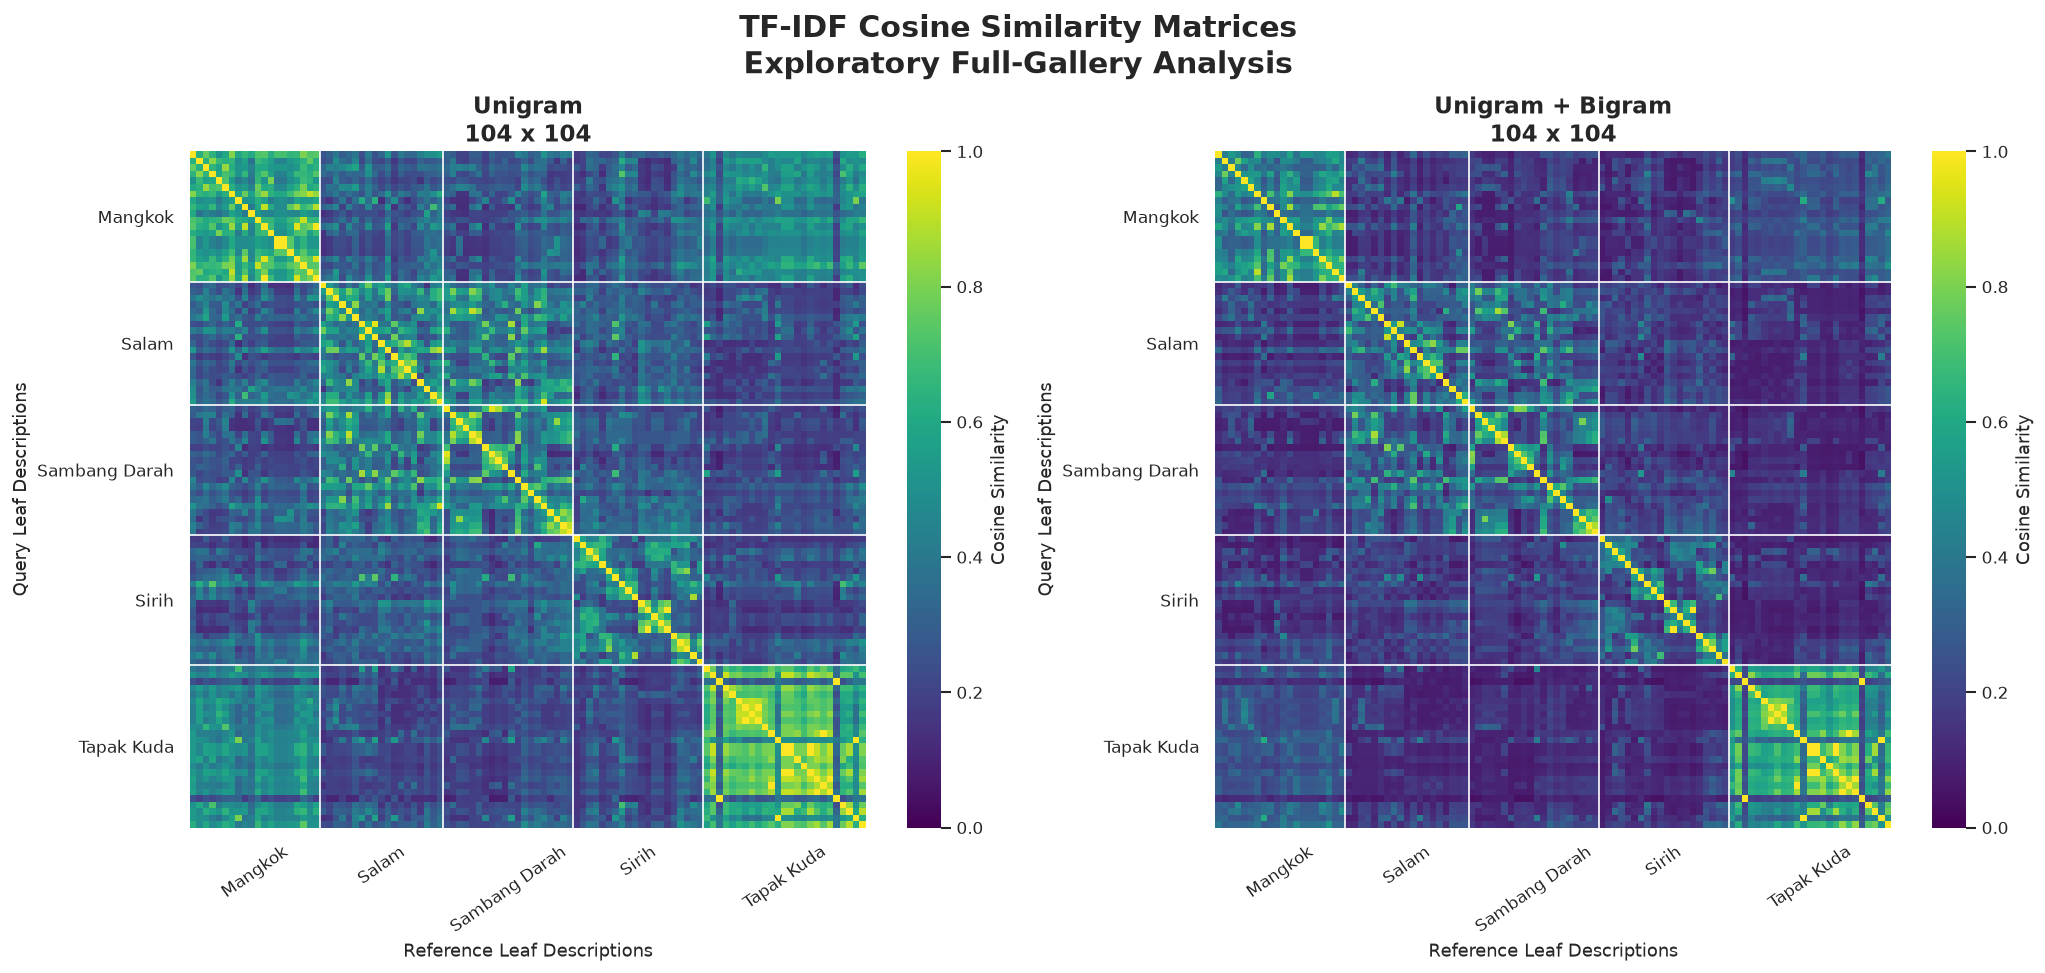

[SAVED] 88_tfidf_cosine_similarity_matrices.png


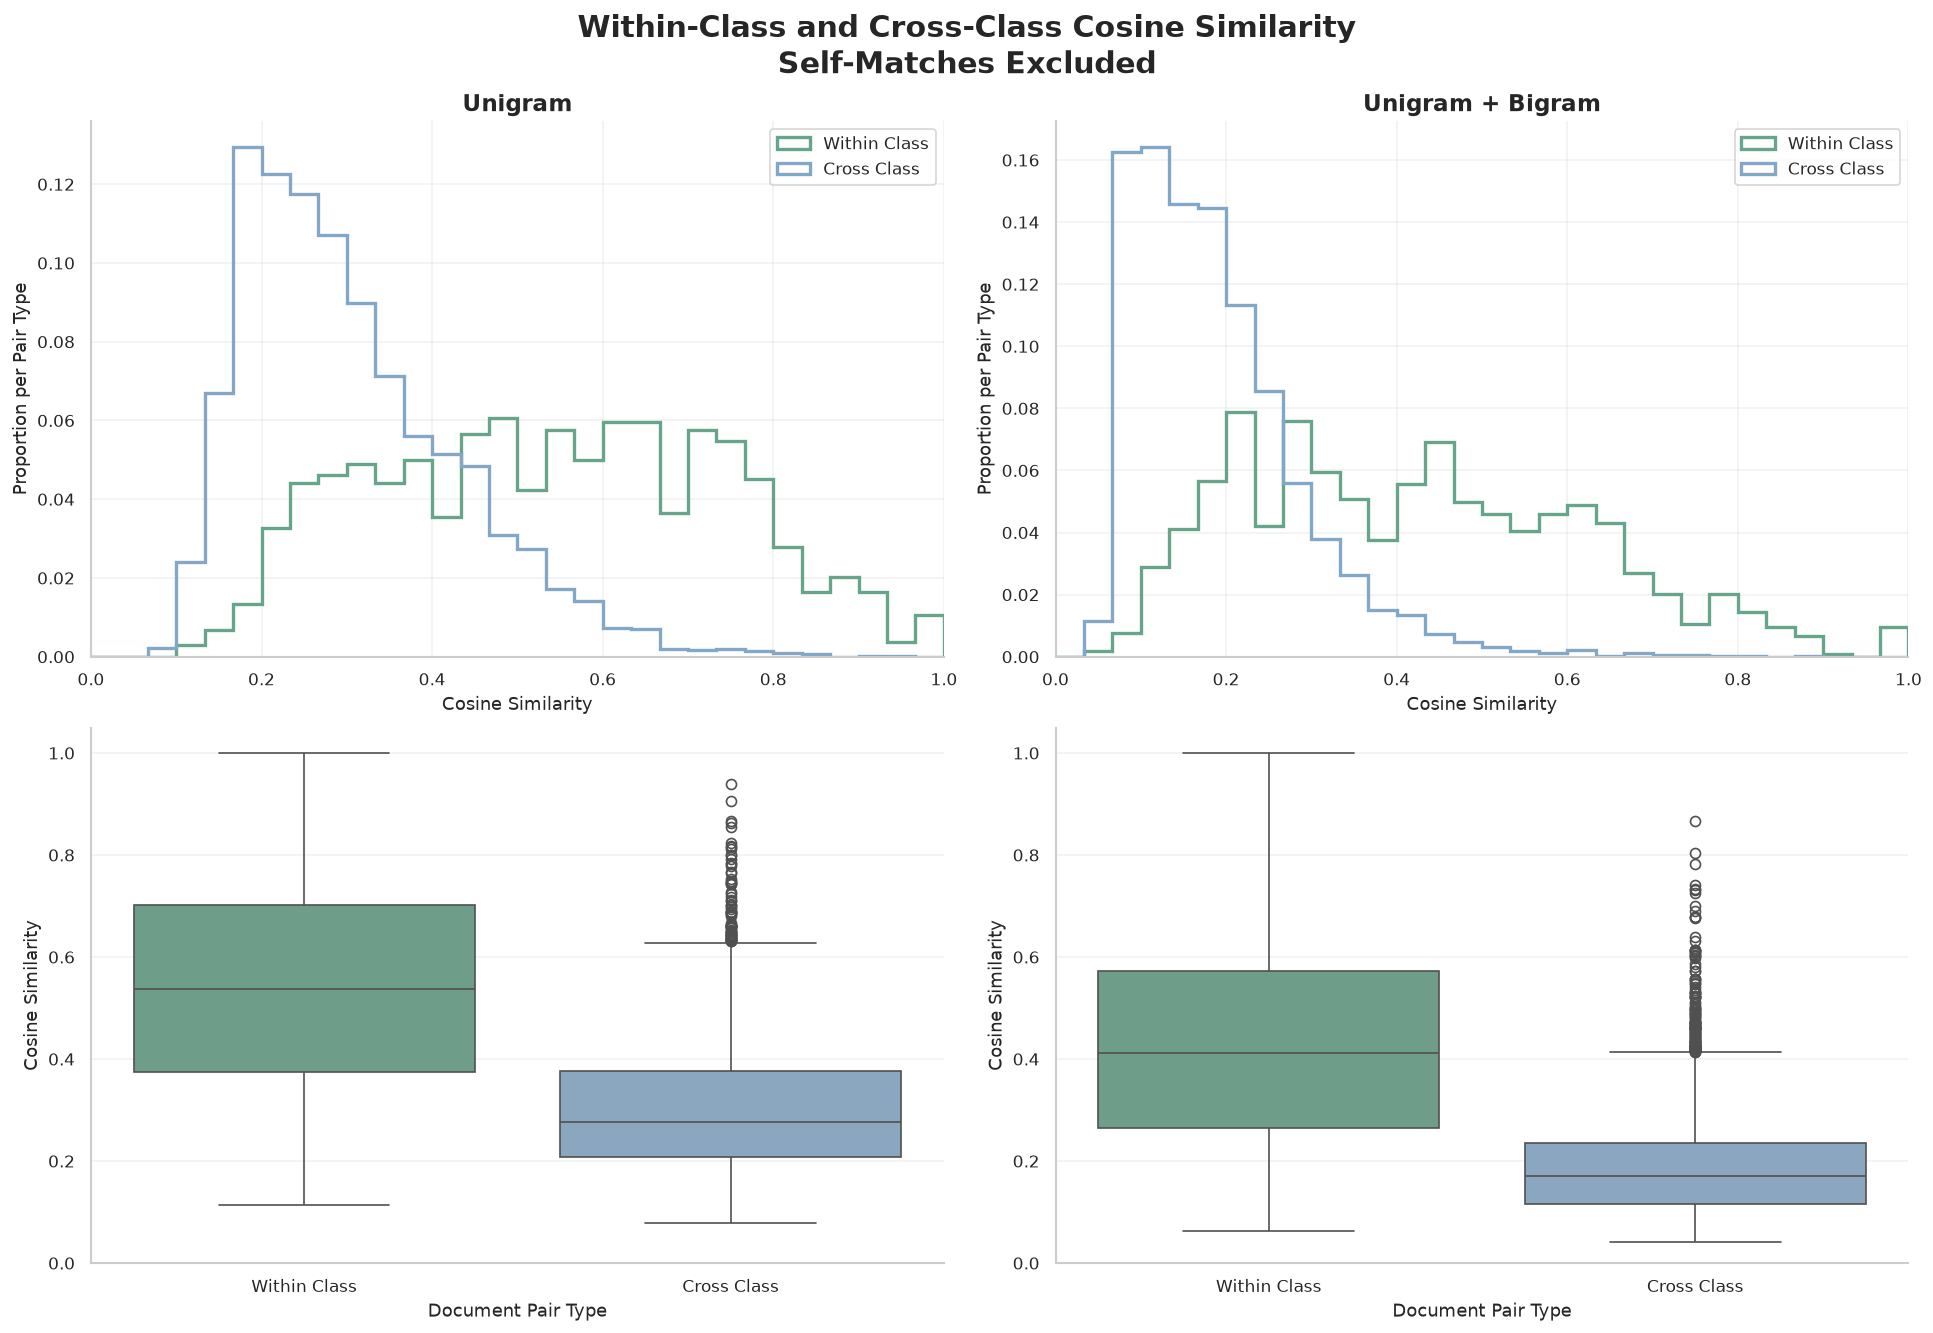

[SAVED] 89_tfidf_cosine_similarity_distributions.png


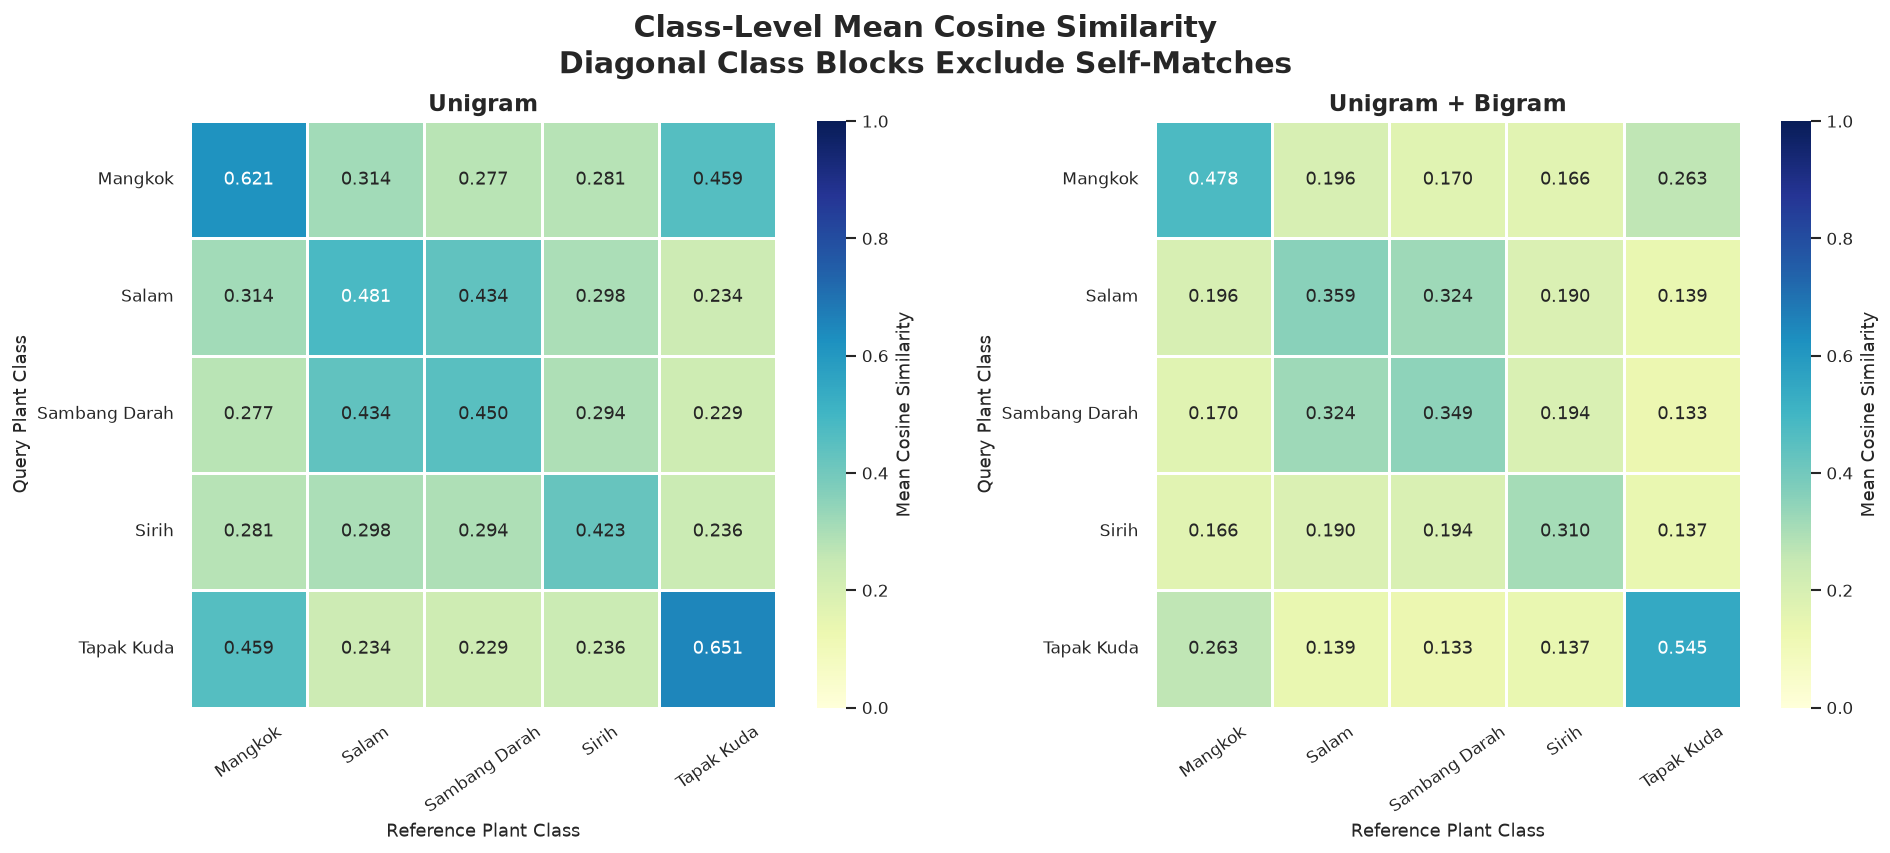

[SAVED] 90_tfidf_class_cosine_similarity.png


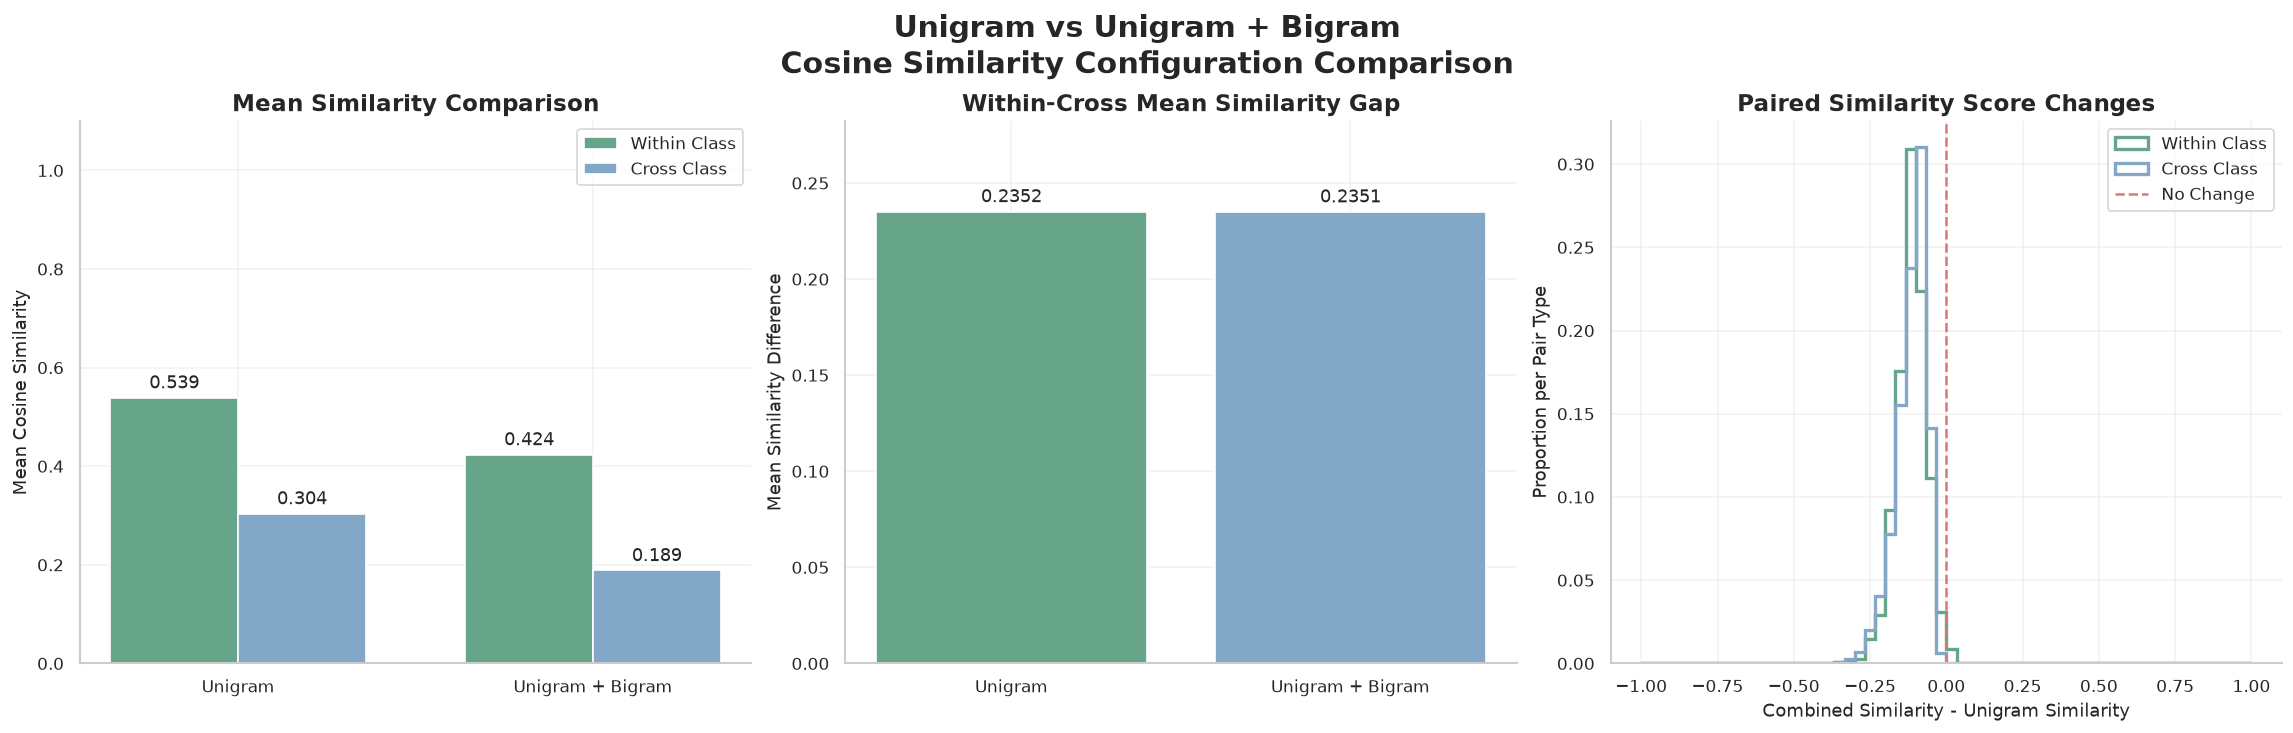

[SAVED] 91_tfidf_cosine_configuration_comparison.png


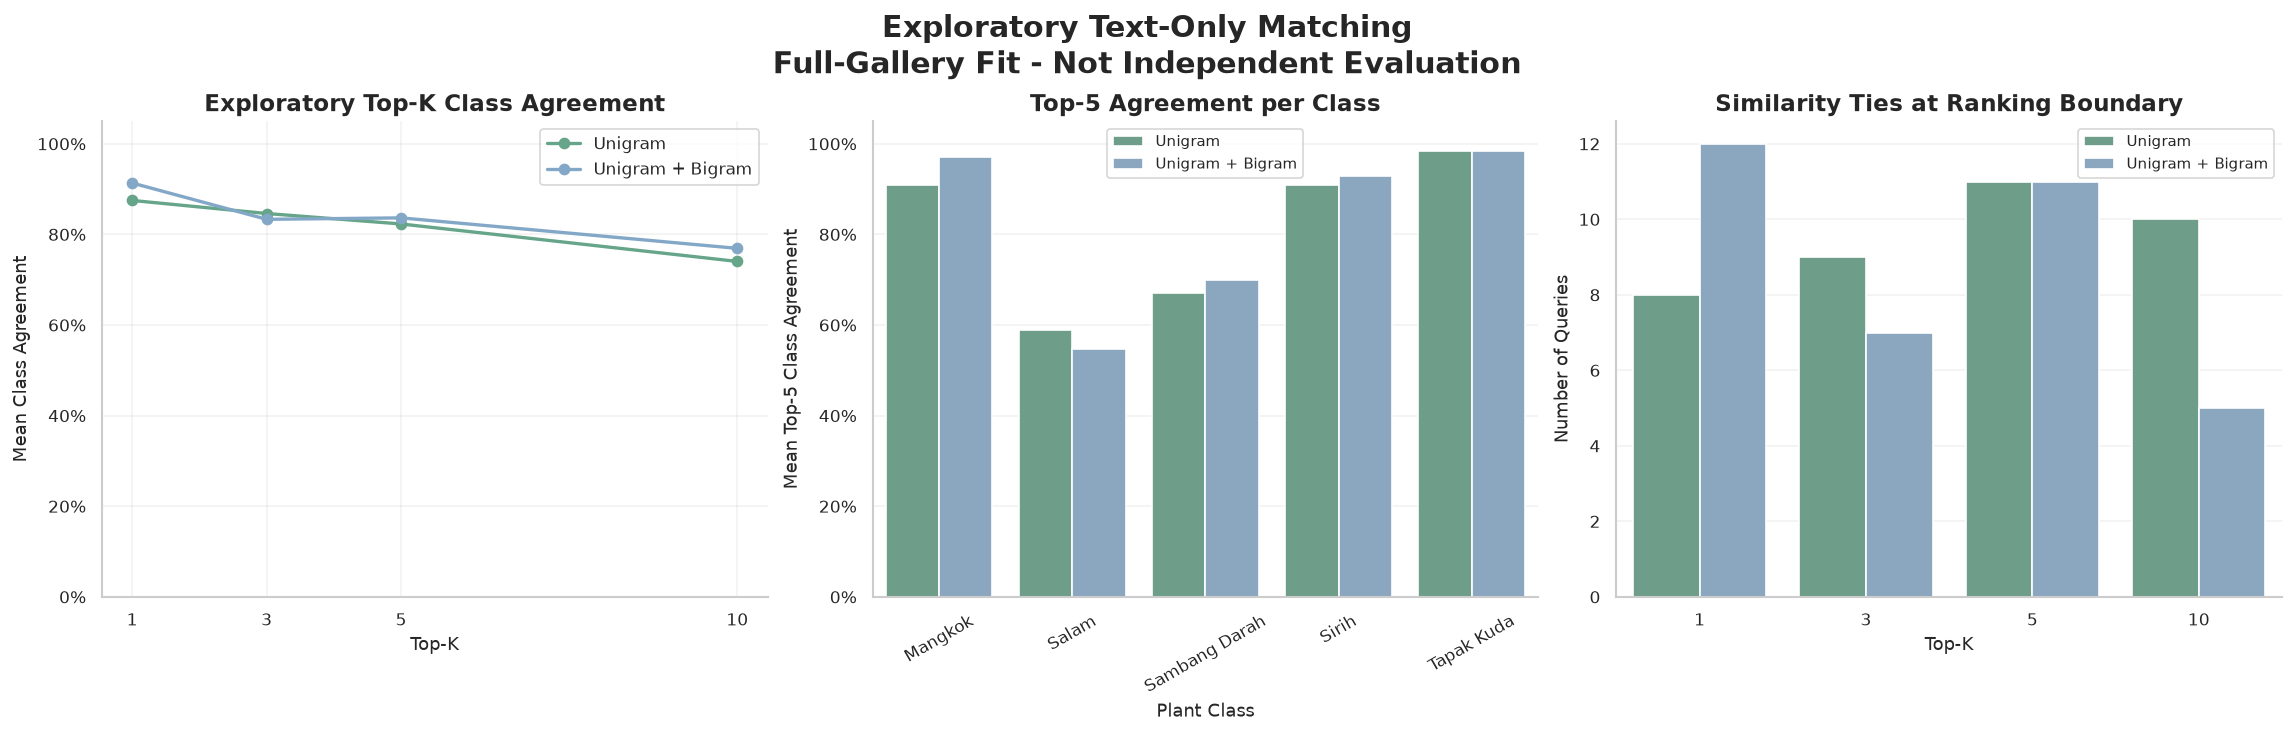

[SAVED] 92_tfidf_exploratory_topk_matching.png

12. OVERALL COSINE SIMILARITY SUMMARY
-----------------------------------------------------------------


,Indicator,Result
0,Total documents,104
1,Total classes,5
2,Total configurations,2
3,Unigram similarity matrix shape,"(104, 104)"
4,Combined similarity matrix shape,"(104, 104)"
5,Unique document pairs per configuration,5356
6,Within-class pairs per configuration,1041
7,Cross-class pairs per configuration,4315
8,Total pair-level records,10712
9,Class-level pair records,30



13. SAVING COSINE SIMILARITY REPORTS
-----------------------------------------------------------------
[SAVED] 292_tfidf_unigram_cosine_matrix.csv
[SAVED] 293_tfidf_combined_cosine_matrix.csv
[SAVED] 294_tfidf_cosine_document_pairs.csv
[SAVED] 295_tfidf_cosine_similarity_statistics.csv
[SAVED] 296_tfidf_cosine_separation_summary.csv
[SAVED] 297_tfidf_class_cosine_statistics.csv
[SAVED] 298_tfidf_cosine_configuration_comparison.csv
[SAVED] 299_tfidf_cosine_comparison_summary.csv
[SAVED] 300_tfidf_exploratory_topk_matches.csv
[SAVED] 301_tfidf_exploratory_topk_queries.csv
[SAVED] 302_tfidf_exploratory_topk_summary.csv
[SAVED] 303_tfidf_exploratory_topk_class_summary.csv
[SAVED] 304_tfidf_cosine_topk_ties.csv
[SAVED] 305_tfidf_representative_cosine_matches.csv
[SAVED] 306_tfidf_cosine_validation.csv
[SAVED] 307_tfidf_cosine_analysis_summary.csv

FINAL COSINE SIMILARITY ANALYSIS SUMMARY

DATASET INFORMATION
-----------------------------------------------------------------
Total documents 

In [11]:
# ==================================================
# CELL 12 - COSINE SIMILARITY ANALYSIS
# ==================================================

from sklearn.metrics.pairwise import cosine_similarity
from matplotlib.ticker import PercentFormatter

print("COSINE SIMILARITY ANALYSIS")
print("=" * 65)

COSINE_SIMILARITY_ANALYSIS_COMPLETED = False


# ==================================================
# 1. VALIDATE PREVIOUS PROCESSING STAGES
# ==================================================

assert TFIDF_FEATURE_EXTRACTION_COMPLETED is True
assert TFIDF_MATRIX_ANALYSIS_COMPLETED is True
assert IMPORTANT_TERM_VISUALIZATION_COMPLETED is True
assert TEXT_FEATURE_QUALITY_VALIDATION_COMPLETED is True

assert tfidf_quality_validation_df["passed"].all()

assert np.array_equal(
    tfidf_sample_ids,
    loaded_visual_sample_ids
)

assert np.array_equal(
    tfidf_labels,
    validated_text_labels
)

cosine_sample_ids = np.asarray(
    tfidf_sample_ids,
    dtype=str
)

cosine_labels = np.asarray(tfidf_labels)

cosine_n_samples = len(cosine_sample_ids)

assert len(np.unique(cosine_sample_ids)) == cosine_n_samples

cosine_matrix_snapshots = {
    name: matrix.copy()
    for name, matrix in tfidf_matrices.items()
}

cosine_corpus_snapshot = list(validated_text_corpus)

print("\n[PASS] Previous processing stages validated.")


# ==================================================
# 2. COSINE SIMILARITY CONFIGURATION
# ==================================================

COSINE_TOLERANCE = 1e-10

COSINE_TOP_K_VALUES = [1, 3, 5, 10]

COSINE_ANALYSIS_SCOPE = (
    "Exploratory Full-Gallery Analysis"
)

COSINE_COLORS = {

    TFIDF_BASELINE_NAME: "#66A58A",

    TFIDF_ALTERNATIVE_NAME: "#83A7C7"
}

COSINE_PAIR_COLORS = {

    "Within Class": "#66A58A",

    "Cross Class": "#83A7C7"
}

cosine_class_names = sorted(
    np.unique(cosine_labels)
)

cosine_figure_paths = []

assert max(COSINE_TOP_K_VALUES) < cosine_n_samples

print("\n1. COSINE SIMILARITY CONFIGURATION")
print("-" * 65)

print(f"Total documents : {cosine_n_samples}")

print(f"Total classes   : {len(cosine_class_names)}")

print(f"Top-K values    : {COSINE_TOP_K_VALUES}")

print(f"Tolerance       : {COSINE_TOLERANCE}")

print(f"Analysis scope  : {COSINE_ANALYSIS_SCOPE}")

print("[INFO] Self-matches are excluded from pair analysis.")

print("[INFO] Existing TF-IDF matrices will not be modified.")


# ==================================================
# 3. INITIALIZE ANALYSIS CONTAINERS
# ==================================================

tfidf_cosine_similarity_matrices = {}

cosine_pair_records = []

cosine_statistics_records = []

cosine_class_pair_records = []

cosine_separation_records = []

cosine_topk_records = []

cosine_topk_summary_records = []

cosine_validation_records = []


def register_cosine_check(
    configuration,
    check_name,
    passed
):

    cosine_validation_records.append({

        "configuration": configuration,

        "validation_check": check_name,

        "passed": bool(passed),

        "status": (
            "Passed" if passed else "Failed"
        )
    })


# ==================================================
# 4. PREPARE UNIQUE DOCUMENT PAIRS
# ==================================================

# Upper triangle excludes the diagonal and
# prevents duplicate counting of (A, B) and (B, A).

cosine_pair_i, cosine_pair_j = np.triu_indices(

    cosine_n_samples,

    k=1
)

cosine_same_class_mask = (

    cosine_labels[cosine_pair_i]

    == cosine_labels[cosine_pair_j]
)

cosine_cross_class_mask = (
    ~cosine_same_class_mask
)

cosine_total_pairs = len(cosine_pair_i)

cosine_within_class_pairs = int(
    cosine_same_class_mask.sum()
)

cosine_cross_class_pairs = int(
    cosine_cross_class_mask.sum()
)

print("\n2. DOCUMENT PAIR CONFIGURATION")
print("-" * 65)

print(f"Total unique pairs : {cosine_total_pairs}")

print(f"Within-class pairs : {cosine_within_class_pairs}")

print(f"Cross-class pairs  : {cosine_cross_class_pairs}")


# ==================================================
# 5. SIMILARITY STATISTICS HELPER
# ==================================================

def calculate_cosine_statistics(values):

    values = np.asarray(
        values,
        dtype=np.float64
    )

    assert values.size > 0

    return {

        "number_of_pairs": len(values),

        "minimum_similarity": float(
            values.min()
        ),

        "maximum_similarity": float(
            values.max()
        ),

        "mean_similarity": float(
            values.mean()
        ),

        "median_similarity": float(
            np.median(values)
        ),

        "std_similarity": float(
            values.std(ddof=0)
        ),

        "q1_similarity": float(
            np.percentile(values, 25)
        ),

        "q3_similarity": float(
            np.percentile(values, 75)
        ),

        "identical_similarity_pairs": int(

            np.isclose(

                values,

                1.0,

                atol=COSINE_TOLERANCE,

                rtol=0
            ).sum()
        ),

        "zero_similarity_pairs": int(

            np.isclose(

                values,

                0.0,

                atol=COSINE_TOLERANCE,

                rtol=0
            ).sum()
        )
    }


# ==================================================
# 6. CALCULATE COSINE SIMILARITY MATRICES
# ==================================================

print("\n3. COSINE SIMILARITY MATRIX CALCULATION")
print("-" * 65)

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    matrix = tfidf_matrices[
        configuration_name
    ]

    start_time = time.perf_counter()

    similarity_matrix_raw = cosine_similarity(
        matrix
    )

    similarity_time_ms = (

        time.perf_counter() - start_time

    ) * 1000


    # --------------------------------------------------
    # A. Validate raw cosine similarity
    # --------------------------------------------------

    register_cosine_check(

        configuration_name,

        "Correct similarity matrix dimensions",

        similarity_matrix_raw.shape == (

            cosine_n_samples,

            cosine_n_samples
        )
    )

    register_cosine_check(

        configuration_name,

        "All similarity values finite",

        np.isfinite(
            similarity_matrix_raw
        ).all()
    )

    register_cosine_check(

        configuration_name,

        "Similarity scores within valid range",

        np.all(

            similarity_matrix_raw
            >= -COSINE_TOLERANCE

        )

        and np.all(

            similarity_matrix_raw
            <= 1 + COSINE_TOLERANCE
        )
    )

    register_cosine_check(

        configuration_name,

        "Similarity matrix symmetric",

        np.allclose(

            similarity_matrix_raw,

            similarity_matrix_raw.T,

            atol=COSINE_TOLERANCE,

            rtol=0
        )
    )

    register_cosine_check(

        configuration_name,

        "Self-similarity diagonal equals one",

        np.allclose(

            np.diag(similarity_matrix_raw),

            1.0,

            atol=COSINE_TOLERANCE,

            rtol=0
        )
    )

    # Validate cosine against the dot product,
    # since the TF-IDF vectors are L2 normalized.

    dot_product_matrix = (

        matrix @ matrix.T

    ).toarray()

    maximum_dot_product_difference = float(

        np.max(

            np.abs(

                similarity_matrix_raw

                - dot_product_matrix
            )
        )
    )

    register_cosine_check(

        configuration_name,

        "Cosine similarity matches L2 dot product",

        np.allclose(

            similarity_matrix_raw,

            dot_product_matrix,

            atol=COSINE_TOLERANCE,

            rtol=0
        )
    )

    # Remove only floating-point overshoot.
    # Do not use clipping to hide invalid scores.

    assert np.isfinite(similarity_matrix_raw).all()

    assert similarity_matrix_raw.min() >= -COSINE_TOLERANCE

    assert similarity_matrix_raw.max() <= 1 + COSINE_TOLERANCE

    similarity_matrix = np.clip(

        similarity_matrix_raw,

        0.0,

        1.0
    )

    tfidf_cosine_similarity_matrices[
        configuration_name
    ] = similarity_matrix


    # --------------------------------------------------
    # B. Extract unique document similarity pairs
    # --------------------------------------------------

    pair_scores = similarity_matrix[

        cosine_pair_i,

        cosine_pair_j
    ]

    within_scores = pair_scores[
        cosine_same_class_mask
    ]

    cross_scores = pair_scores[
        cosine_cross_class_mask
    ]

    for i, j, score in zip(

        cosine_pair_i,

        cosine_pair_j,

        pair_scores
    ):

        same_class = bool(

            cosine_labels[i]

            == cosine_labels[j]
        )

        cosine_pair_records.append({

            "configuration": configuration_name,

            "row_index_a": int(i),

            "row_index_b": int(j),

            "sample_id_a": cosine_sample_ids[i],

            "sample_id_b": cosine_sample_ids[j],

            "class_a": cosine_labels[i],

            "class_b": cosine_labels[j],

            "same_class": same_class,

            "pair_type": (

                "Within Class"

                if same_class

                else "Cross Class"
            ),

            "cosine_similarity": float(score)
        })


    # --------------------------------------------------
    # C. Calculate similarity distribution statistics
    # --------------------------------------------------

    for pair_type, values in [

        ("All Pairs", pair_scores),

        ("Within Class", within_scores),

        ("Cross Class", cross_scores)
    ]:

        statistics = calculate_cosine_statistics(
            values
        )

        cosine_statistics_records.append({

            "configuration": configuration_name,

            "pair_type": pair_type,

            **statistics
        })


    # --------------------------------------------------
    # D. Calculate within-vs-cross-class separation
    # --------------------------------------------------

    within_mean = float(within_scores.mean())

    cross_mean = float(cross_scores.mean())

    mean_similarity_gap = within_mean - cross_mean

    median_similarity_gap = float(

        np.median(within_scores)

        - np.median(cross_scores)
    )

    # Descriptive separation index:
    # gap divided by the average within-group variance.

    separation_denominator = np.sqrt(

        (

            within_scores.var(ddof=0)

            + cross_scores.var(ddof=0)

        ) / 2
    )

    standardized_separation = (

        mean_similarity_gap / separation_denominator

        if separation_denominator > 0

        else np.nan
    )

    cosine_separation_records.append({

        "configuration": configuration_name,

        "feature_dimension": matrix.shape[1],

        "within_class_mean": within_mean,

        "cross_class_mean": cross_mean,

        "mean_similarity_gap": mean_similarity_gap,

        "median_similarity_gap": median_similarity_gap,

        "descriptive_standardized_separation":
            standardized_separation,

        "within_class_pairs": len(within_scores),

        "cross_class_pairs": len(cross_scores),

        "similarity_computation_time_ms":
            similarity_time_ms,

        "maximum_dot_product_difference":
            maximum_dot_product_difference
    })


    # --------------------------------------------------
    # E. Validate identical document vectors
    # --------------------------------------------------

    identical_pairs = (

        tfidf_identical_document_pairs_df.loc[

            tfidf_identical_document_pairs_df[
                "configuration"
            ].eq(configuration_name)
        ]
    )

    identical_row_i = identical_pairs[
        "row_index_a"
    ].to_numpy(dtype=int)

    identical_row_j = identical_pairs[
        "row_index_b"
    ].to_numpy(dtype=int)

    identical_pair_scores = similarity_matrix[

        identical_row_i,

        identical_row_j
    ]

    register_cosine_check(

        configuration_name,

        "Identical document vectors have cosine one",

        np.allclose(

            identical_pair_scores,

            1.0,

            atol=COSINE_TOLERANCE,

            rtol=0
        )
    )

    register_cosine_check(

        configuration_name,

        "Unique document pair count correct",

        len(pair_scores) == (

            cosine_n_samples

            * (cosine_n_samples - 1)

            // 2
        )
    )

    register_cosine_check(

        configuration_name,

        "Within and cross-class counts reconcile",

        len(within_scores) + len(cross_scores)

        == len(pair_scores)
    )


    print(f"\nConfiguration: {configuration_name}")

    print(f"Matrix shape     : {similarity_matrix.shape}")

    print(f"Minimum score    : {pair_scores.min():.6f}")

    print(f"Maximum score    : {pair_scores.max():.6f}")

    print(f"Within-class mean: {within_mean:.6f}")

    print(f"Cross-class mean : {cross_mean:.6f}")

    print(f"Similarity gap   : {mean_similarity_gap:.6f}")

    print(f"Computation time : {similarity_time_ms:.4f} ms")


# ==================================================
# 7. CREATE MAIN SIMILARITY MATRIX ALIASES
# ==================================================

tfidf_cosine_similarity_matrix = (

    tfidf_cosine_similarity_matrices[
        TFIDF_BASELINE_NAME
    ]
)

tfidf_bigram_cosine_similarity_matrix = (

    tfidf_cosine_similarity_matrices[
        TFIDF_ALTERNATIVE_NAME
    ]
)

tfidf_cosine_pairs_df = pd.DataFrame(
    cosine_pair_records
)

tfidf_cosine_statistics_df = pd.DataFrame(
    cosine_statistics_records
)

tfidf_cosine_separation_df = pd.DataFrame(
    cosine_separation_records
)

print("\n4. COSINE SIMILARITY STATISTICS")
print("-" * 65)

display(

    tfidf_cosine_statistics_df.round(6)
)

print("\n5. WITHIN-CLASS VS CROSS-CLASS SEPARATION")
print("-" * 65)

display(

    tfidf_cosine_separation_df.round(6)
)


# ==================================================
# 8. CLASS-LEVEL COSINE SIMILARITY ANALYSIS
# ==================================================

tfidf_class_cosine_similarity_matrices = {}

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    similarity_matrix = (

        tfidf_cosine_similarity_matrices[
            configuration_name
        ]
    )

    class_similarity_matrix = np.zeros(

        (
            len(cosine_class_names),

            len(cosine_class_names)
        ),

        dtype=np.float64
    )

    for i, class_a in enumerate(cosine_class_names):

        class_a_indices = np.flatnonzero(

            cosine_labels == class_a
        )

        for j, class_b in enumerate(cosine_class_names):

            class_b_indices = np.flatnonzero(

                cosine_labels == class_b
            )

            class_block = similarity_matrix[

                np.ix_(

                    class_a_indices,

                    class_b_indices
                )
            ]

            # For same-class blocks, use unique
            # document pairs and exclude self-matches.

            if class_a == class_b:

                block_indices = np.triu_indices(

                    len(class_a_indices),

                    k=1
                )

                block_values = class_block[
                    block_indices
                ]

            else:

                block_values = class_block.ravel()

            class_similarity_matrix[i, j] = (
                block_values.mean()
            )

            # Save each unordered class combination once.

            if j >= i:

                cosine_class_pair_records.append({

                    "configuration": configuration_name,

                    "class_a": class_a,

                    "class_b": class_b,

                    "pair_type": (

                        "Within Class"

                        if class_a == class_b

                        else "Cross Class"
                    ),

                    **calculate_cosine_statistics(
                        block_values
                    )
                })

    tfidf_class_cosine_similarity_matrices[
        configuration_name
    ] = class_similarity_matrix

    register_cosine_check(

        configuration_name,

        "Class-level similarity matrix symmetric",

        np.allclose(

            class_similarity_matrix,

            class_similarity_matrix.T,

            atol=COSINE_TOLERANCE,

            rtol=0
        )
    )


tfidf_class_cosine_statistics_df = pd.DataFrame(
    cosine_class_pair_records
)

print("\n6. CLASS-LEVEL COSINE SIMILARITY")
print("-" * 65)

display(

    tfidf_class_cosine_statistics_df[

        [
            "configuration",

            "class_a",

            "class_b",

            "number_of_pairs",

            "mean_similarity",

            "std_similarity"
        ]

    ].round(6)
)


# ==================================================
# 9. COMPARE UNIGRAM AND UNIGRAM + BIGRAM
# ==================================================

unigram_pair_scores = (

    tfidf_cosine_similarity_matrix[

        cosine_pair_i,

        cosine_pair_j
    ]
)

combined_pair_scores = (

    tfidf_bigram_cosine_similarity_matrix[

        cosine_pair_i,

        cosine_pair_j
    ]
)

cosine_score_difference = (

    combined_pair_scores

    - unigram_pair_scores
)

tfidf_cosine_configuration_comparison_df = pd.DataFrame({

    "sample_id_a": cosine_sample_ids[cosine_pair_i],

    "sample_id_b": cosine_sample_ids[cosine_pair_j],

    "class_a": cosine_labels[cosine_pair_i],

    "class_b": cosine_labels[cosine_pair_j],

    "same_class": cosine_same_class_mask,

    "pair_type": np.where(

        cosine_same_class_mask,

        "Within Class",

        "Cross Class"
    ),

    "unigram_similarity": unigram_pair_scores,

    "combined_similarity": combined_pair_scores,

    "similarity_difference": cosine_score_difference
})

cosine_comparison_summary_records = []

for pair_type, mask in [

    (
        "All Pairs",

        np.ones(cosine_total_pairs, dtype=bool)
    ),

    (
        "Within Class",

        cosine_same_class_mask
    ),

    (
        "Cross Class",

        cosine_cross_class_mask
    )
]:

    differences = cosine_score_difference[mask]

    cosine_comparison_summary_records.append({

        "pair_type": pair_type,

        "number_of_pairs": int(mask.sum()),

        "unigram_mean_similarity": float(

            unigram_pair_scores[mask].mean()
        ),

        "combined_mean_similarity": float(

            combined_pair_scores[mask].mean()
        ),

        "mean_similarity_change": float(
            differences.mean()
        ),

        "median_similarity_change": float(
            np.median(differences)
        ),

        "increased_similarity_pairs": int(

            (differences > COSINE_TOLERANCE).sum()
        ),

        "decreased_similarity_pairs": int(

            (differences < -COSINE_TOLERANCE).sum()
        ),

        "unchanged_similarity_pairs": int(

            (np.abs(differences) <= COSINE_TOLERANCE).sum()
        )
    })

tfidf_cosine_comparison_summary_df = pd.DataFrame(
    cosine_comparison_summary_records
)

print("\n7. CONFIGURATION COMPARISON")
print("-" * 65)

display(

    tfidf_cosine_comparison_summary_df.round(6)
)


# ==================================================
# 10. EXPLORATORY TOP-K TEXT MATCHING
# ==================================================

# IMPORTANT:
# This is a full-gallery diagnostic.
#
# It is NOT independent retrieval evaluation because
# the TF-IDF vectorizers were fitted on all documents.
#
# Exclude the query itself.
# Resolve exact score ties using sample_id.

cosine_retrieval_records = []

cosine_topk_tie_records = []

maximum_top_k = max(COSINE_TOP_K_VALUES)

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    similarity_matrix = (

        tfidf_cosine_similarity_matrices[
            configuration_name
        ]
    )

    for query_index in range(cosine_n_samples):

        query_scores = similarity_matrix[
            query_index
        ].copy()

        candidate_indices = np.flatnonzero(

            np.arange(cosine_n_samples)

            != query_index
        )

        # Primary order: descending cosine similarity.
        # Secondary order: ascending sample ID.

        ranking_order = np.lexsort((

            cosine_sample_ids[candidate_indices],

            -query_scores[candidate_indices]
        ))

        ranked_indices = candidate_indices[
            ranking_order
        ]

        top_indices = ranked_indices[
            :maximum_top_k
        ]

        query_class = cosine_labels[
            query_index
        ]


        # --------------------------------------------------
        # A. Store individual Top-K matching results
        # --------------------------------------------------

        for rank, reference_index in enumerate(

            top_indices,

            start=1
        ):

            cosine_retrieval_records.append({

                "configuration": configuration_name,

                "query_index": query_index,

                "query_sample_id":
                    cosine_sample_ids[query_index],

                "query_class": query_class,

                "rank": rank,

                "reference_index": int(
                    reference_index
                ),

                "reference_sample_id":
                    cosine_sample_ids[reference_index],

                "reference_class":
                    cosine_labels[reference_index],

                "cosine_similarity": float(
                    query_scores[reference_index]
                ),

                "same_class": bool(

                    query_class

                    == cosine_labels[reference_index]
                ),

                "exact_duplicate_description": bool(

                    validated_text_corpus[query_index]

                    == validated_text_corpus[reference_index]
                )
            })


        # --------------------------------------------------
        # B. Calculate exploratory Top-K class agreement
        # --------------------------------------------------

        for k in COSINE_TOP_K_VALUES:

            selected_indices = ranked_indices[:k]

            number_same_class = int(

                np.sum(

                    cosine_labels[selected_indices]

                    == query_class
                )
            )

            duplicate_matches = sum(

                validated_text_corpus[query_index]

                == validated_text_corpus[index]

                for index in selected_indices
            )

            cutoff_score = query_scores[
                ranked_indices[k - 1]
            ]

            next_score = query_scores[
                ranked_indices[k]
            ] if k < len(ranked_indices) else -np.inf

            boundary_tie = bool(

                np.isclose(

                    cutoff_score,

                    next_score,

                    atol=COSINE_TOLERANCE,

                    rtol=0
                )
            )

            cosine_topk_records.append({

                "configuration": configuration_name,

                "query_sample_id":
                    cosine_sample_ids[query_index],

                "query_class": query_class,

                "top_k": k,

                "same_class_matches":
                    number_same_class,

                "class_agreement_at_k":
                    number_same_class / k,

                "exact_duplicate_matches":
                    int(duplicate_matches),

                "mean_top_k_similarity": float(

                    query_scores[selected_indices].mean()
                ),

                "boundary_tie": boundary_tie
            })

            cosine_topk_tie_records.append({

                "configuration": configuration_name,

                "query_sample_id":
                    cosine_sample_ids[query_index],

                "query_class": query_class,

                "top_k": k,

                "cutoff_similarity": float(
                    cutoff_score
                ),

                "boundary_tie": boundary_tie
            })


tfidf_exploratory_topk_matches_df = pd.DataFrame(
    cosine_retrieval_records
)

tfidf_exploratory_topk_queries_df = pd.DataFrame(
    cosine_topk_records
)

tfidf_cosine_topk_ties_df = pd.DataFrame(
    cosine_topk_tie_records
)


# ==================================================
# 11. SUMMARIZE EXPLORATORY TOP-K MATCHING
# ==================================================

tfidf_exploratory_topk_summary_df = (

    tfidf_exploratory_topk_queries_df

    .groupby(

        ["configuration", "top_k"],

        sort=False
    )

    .agg(

        number_of_queries=(
            "query_sample_id", "count"
        ),

        mean_class_agreement_at_k=(
            "class_agreement_at_k", "mean"
        ),

        std_class_agreement_at_k=(
            "class_agreement_at_k",
            lambda x: x.std(ddof=0)
        ),

        mean_top_k_similarity=(
            "mean_top_k_similarity", "mean"
        ),

        total_exact_duplicate_matches=(
            "exact_duplicate_matches", "sum"
        ),

        boundary_tie_queries=(
            "boundary_tie", "sum"
        )
    )

    .reset_index()
)

tfidf_exploratory_topk_class_summary_df = (

    tfidf_exploratory_topk_queries_df

    .groupby(

        [
            "configuration",

            "query_class",

            "top_k"
        ],

        sort=False
    )

    .agg(

        number_of_queries=(
            "query_sample_id", "count"
        ),

        mean_class_agreement_at_k=(
            "class_agreement_at_k", "mean"
        ),

        mean_top_k_similarity=(
            "mean_top_k_similarity", "mean"
        ),

        total_exact_duplicate_matches=(
            "exact_duplicate_matches", "sum"
        ),

        boundary_tie_queries=(
            "boundary_tie", "sum"
        )
    )

    .reset_index()
)

print("\n8. EXPLORATORY TOP-K MATCHING SUMMARY")
print("-" * 65)

display(

    tfidf_exploratory_topk_summary_df.round(6)
)

print("\n9. TOP-5 CLASS AGREEMENT PER PLANT CLASS")
print("-" * 65)

display(

    tfidf_exploratory_topk_class_summary_df.loc[

        tfidf_exploratory_topk_class_summary_df[
            "top_k"
        ].eq(5)

    ].round(6)
)

print("[INFO] These results are exploratory only.")

print("[INFO] They are not final retrieval performance.")


# ==================================================
# 12. REPRESENTATIVE TEXT MATCHING RESULTS
# ==================================================

cosine_representative_sample_ids = [

    cosine_sample_ids[int(index)]

    for index in tfidf_representative_indices
]

tfidf_representative_cosine_matches_df = (

    tfidf_exploratory_topk_matches_df.loc[

        tfidf_exploratory_topk_matches_df[
            "query_sample_id"
        ].isin(cosine_representative_sample_ids)

        &

        tfidf_exploratory_topk_matches_df[
            "rank"
        ].le(5)
    ]

    .copy()

    .reset_index(drop=True)
)

print("\n10. REPRESENTATIVE TEXT MATCHING RESULTS")
print("-" * 65)

display(

    tfidf_representative_cosine_matches_df[

        [
            "configuration",

            "query_sample_id",

            "query_class",

            "rank",

            "reference_sample_id",

            "reference_class",

            "cosine_similarity",

            "same_class"
        ]

    ].round(6)
)


# ==================================================
# 13. VALIDATE EXPLORATORY MATCHING
# ==================================================

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    matching_df = (

        tfidf_exploratory_topk_matches_df.loc[

            tfidf_exploratory_topk_matches_df[
                "configuration"
            ].eq(configuration_name)
        ]
    )

    query_summary_df = (

        tfidf_exploratory_topk_queries_df.loc[

            tfidf_exploratory_topk_queries_df[
                "configuration"
            ].eq(configuration_name)
        ]
    )

    register_cosine_check(

        configuration_name,

        "No self-matches in Top-K results",

        matching_df[
            "query_sample_id"
        ].ne(

            matching_df["reference_sample_id"]

        ).all()
    )

    register_cosine_check(

        configuration_name,

        "Correct Top-K match record count",

        len(matching_df)

        == cosine_n_samples * maximum_top_k
    )

    register_cosine_check(

        configuration_name,

        "Each query has unique reference candidates",

        matching_df.groupby(
            "query_sample_id"
        )["reference_sample_id"].nunique().eq(

            maximum_top_k

        ).all()
    )

    register_cosine_check(

        configuration_name,

        "Similarity ranking descending",

        matching_df.groupby(

            "query_sample_id",

            sort=False

        )["cosine_similarity"].apply(

            lambda x: x.is_monotonic_decreasing

        ).all()
    )

    register_cosine_check(

        configuration_name,

        "Top-K class agreement within valid range",

        query_summary_df[
            "class_agreement_at_k"
        ].between(0, 1).all()
    )

    register_cosine_check(

        configuration_name,

        "Correct query-level Top-K record count",

        len(query_summary_df)

        == cosine_n_samples * len(COSINE_TOP_K_VALUES)
    )

    matching_scores = (

        tfidf_cosine_similarity_matrices[
            configuration_name
        ][

            matching_df[
                "query_index"
            ].to_numpy(dtype=int),

            matching_df[
                "reference_index"
            ].to_numpy(dtype=int)
        ]
    )

    register_cosine_check(

        configuration_name,

        "Top-K scores match original similarity matrix",

        np.allclose(

            matching_df["cosine_similarity"],

            matching_scores,

            atol=COSINE_TOLERANCE,

            rtol=0
        )
    )


# ==================================================
# 14. OVERALL CONSISTENCY VALIDATION
# ==================================================

cosine_original_matrices_unchanged = True

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    difference = (

        tfidf_matrices[configuration_name]

        - cosine_matrix_snapshots[configuration_name]
    )

    difference.eliminate_zeros()

    cosine_original_matrices_unchanged = (

        cosine_original_matrices_unchanged

        and difference.nnz == 0
    )

overall_cosine_checks = {

    "Original TF-IDF matrices unchanged":

        cosine_original_matrices_unchanged,

    "Original text corpus unchanged":

        list(validated_text_corpus)
        == cosine_corpus_snapshot,

    "Image-text sample alignment preserved":

        np.array_equal(

            tfidf_sample_ids,

            loaded_visual_sample_ids
        ),

    "Pair-level records reconcile":

        len(tfidf_cosine_pairs_df)

        == cosine_total_pairs * len(tfidf_matrices),

    "Configuration comparison records reconcile":

        len(tfidf_cosine_configuration_comparison_df)

        == cosine_total_pairs,

    "Class-pair records reconcile":

        len(tfidf_class_cosine_statistics_df)

        == (

            len(tfidf_matrices)

            * len(cosine_class_names)

            * (len(cosine_class_names) + 1)

            // 2
        ),

    "All comparison differences finite":

        np.isfinite(cosine_score_difference).all()
}

for check_name, passed in overall_cosine_checks.items():

    register_cosine_check(

        "Overall",

        check_name,

        passed
    )

tfidf_cosine_validation_df = pd.DataFrame(
    cosine_validation_records
)

print("\n11. COSINE SIMILARITY VALIDATION")
print("-" * 65)

display(tfidf_cosine_validation_df)

assert tfidf_cosine_validation_df["passed"].all(), (

    tfidf_cosine_validation_df.loc[

        ~tfidf_cosine_validation_df["passed"]

    ].to_string(index=False)
)

print("[PASS] All mathematical validation checks passed.")


# ==================================================
# 15. VISUALIZATION HELPER
# ==================================================

def save_cosine_figure(fig, filename):

    output_path = (
        TEXT_FEATURE_FIGURES_DIR / filename
    )

    fig.savefig(

        output_path,

        dpi=300,

        bbox_inches="tight"
    )

    cosine_figure_paths.append(output_path)

    plt.show()

    plt.close(fig)

    print(f"[SAVED] {filename}")


# Prepare class-sorted display order.

cosine_plot_order = np.argsort(

    cosine_labels,

    kind="stable"
)

cosine_sorted_labels = cosine_labels[
    cosine_plot_order
]

cosine_class_boundaries = np.flatnonzero(

    cosine_sorted_labels[1:]

    != cosine_sorted_labels[:-1]

) + 1

cosine_class_starts = np.r_[

    0,

    cosine_class_boundaries
]

cosine_class_ends = np.r_[

    cosine_class_boundaries,

    cosine_n_samples
]

cosine_class_centers = (

    cosine_class_starts

    + cosine_class_ends

) / 2


# ==================================================
# 16. VISUALIZE COSINE SIMILARITY MATRICES
# ==================================================

fig, axes = plt.subplots(

    1, 2,

    figsize=(17, 8),

    constrained_layout=True
)

for ax, configuration_name in zip(

    axes,

    TFIDF_CONFIGURATION_ORDER
):

    matrix = tfidf_cosine_similarity_matrices[
        configuration_name
    ]

    sorted_matrix = matrix[

        np.ix_(

            cosine_plot_order,

            cosine_plot_order
        )
    ]

    sns.heatmap(

        sorted_matrix,

        cmap="viridis",

        vmin=0,

        vmax=1,

        square=True,

        xticklabels=False,

        yticklabels=False,

        cbar_kws={

            "label": "Cosine Similarity"
        },

        ax=ax
    )

    for boundary in cosine_class_boundaries:

        ax.axhline(

            boundary,

            color="white",

            linewidth=1
        )

        ax.axvline(

            boundary,

            color="white",

            linewidth=1
        )

    ax.set_xticks(cosine_class_centers)

    ax.set_xticklabels(

        cosine_sorted_labels[
            cosine_class_starts
        ],

        rotation=35
    )

    ax.set_yticks(cosine_class_centers)

    ax.set_yticklabels(

        cosine_sorted_labels[
            cosine_class_starts
        ],

        rotation=0
    )

    ax.set_title(

        f"{configuration_name}\n"

        f"{cosine_n_samples} x {cosine_n_samples}"
    )

    ax.set_xlabel("Reference Leaf Descriptions")

    ax.set_ylabel("Query Leaf Descriptions")

fig.suptitle(

    "TF-IDF Cosine Similarity Matrices\n"

    "Exploratory Full-Gallery Analysis",

    fontsize=18,

    fontweight="bold"
)

save_cosine_figure(

    fig,

    "88_tfidf_cosine_similarity_matrices.png"
)


# ==================================================
# 17. VISUALIZE WITHIN AND CROSS-CLASS SIMILARITY
# ==================================================

fig, axes = plt.subplots(

    2, 2,

    figsize=(16, 11),

    constrained_layout=True
)

shared_similarity_bins = np.linspace(

    0,

    1,

    31
)

for column_index, configuration_name in enumerate(

    TFIDF_CONFIGURATION_ORDER
):

    plot_df = (

        tfidf_cosine_pairs_df.loc[

            tfidf_cosine_pairs_df[
                "configuration"
            ].eq(configuration_name)
        ]
    )

    ax_hist = axes[0, column_index]

    for pair_type in [

        "Within Class",

        "Cross Class"
    ]:

        values = plot_df.loc[

            plot_df["pair_type"].eq(pair_type),

            "cosine_similarity"
        ].to_numpy()

        ax_hist.hist(

            values,

            bins=shared_similarity_bins,

            weights=np.full(

                len(values),

                1 / len(values)
            ),

            histtype="step",

            linewidth=2,

            color=COSINE_PAIR_COLORS[pair_type],

            label=pair_type
        )

    ax_hist.set_title(configuration_name)

    ax_hist.set_xlabel("Cosine Similarity")

    ax_hist.set_ylabel("Proportion per Pair Type")

    ax_hist.set_xlim(0, 1)

    ax_hist.legend()

    ax_box = axes[1, column_index]

    sns.boxplot(

        data=plot_df,

        x="pair_type",

        y="cosine_similarity",

        order=[

            "Within Class",

            "Cross Class"
        ],

        hue="pair_type",

        hue_order=[

            "Within Class",

            "Cross Class"
        ],

        palette=COSINE_PAIR_COLORS,

        dodge=False,

        ax=ax_box
    )

    legend = ax_box.get_legend()

    if legend is not None:

        legend.remove()

    ax_box.set_xlabel("Document Pair Type")

    ax_box.set_ylabel("Cosine Similarity")

    ax_box.set_ylim(0, 1.05)

fig.suptitle(

    "Within-Class and Cross-Class Cosine Similarity\n"

    "Self-Matches Excluded",

    fontsize=18,

    fontweight="bold"
)

save_cosine_figure(

    fig,

    "89_tfidf_cosine_similarity_distributions.png"
)


# ==================================================
# 18. VISUALIZE CLASS-LEVEL SIMILARITY
# ==================================================

fig, axes = plt.subplots(

    1, 2,

    figsize=(16, 7),

    constrained_layout=True
)

for ax, configuration_name in zip(

    axes,

    TFIDF_CONFIGURATION_ORDER
):

    class_matrix = (

        tfidf_class_cosine_similarity_matrices[
            configuration_name
        ]
    )

    sns.heatmap(

        class_matrix,

        cmap="YlGnBu",

        annot=True,

        fmt=".3f",

        vmin=0,

        vmax=1,

        square=True,

        linewidths=0.8,

        linecolor="white",

        xticklabels=cosine_class_names,

        yticklabels=cosine_class_names,

        cbar_kws={

            "label": "Mean Cosine Similarity"
        },

        ax=ax
    )

    ax.set_title(configuration_name)

    ax.set_xlabel("Reference Plant Class")

    ax.set_ylabel("Query Plant Class")

    ax.tick_params(

        axis="x",

        labelrotation=35
    )

    ax.tick_params(

        axis="y",

        labelrotation=0
    )

fig.suptitle(

    "Class-Level Mean Cosine Similarity\n"

    "Diagonal Class Blocks Exclude Self-Matches",

    fontsize=18,

    fontweight="bold"
)

save_cosine_figure(

    fig,

    "90_tfidf_class_cosine_similarity.png"
)


# ==================================================
# 19. VISUALIZE CONFIGURATION COMPARISON
# ==================================================

fig, axes = plt.subplots(

    1, 3,

    figsize=(19, 6),

    constrained_layout=True
)

positions = np.arange(
    len(TFIDF_CONFIGURATION_ORDER)
)

separation_plot_df = (

    tfidf_cosine_separation_df

    .set_index("configuration")

    .loc[TFIDF_CONFIGURATION_ORDER]

    .reset_index()
)

configuration_plot_labels = [

    "Unigram",

    "Unigram + Bigram"
]

# A. Within and cross-class mean similarities.

ax = axes[0]

bars_a = ax.bar(

    positions - 0.18,

    separation_plot_df["within_class_mean"],

    width=0.36,

    color="#66A58A",

    label="Within Class"
)

bars_b = ax.bar(

    positions + 0.18,

    separation_plot_df["cross_class_mean"],

    width=0.36,

    color="#83A7C7",

    label="Cross Class"
)

ax.bar_label(bars_a, fmt="%.3f", padding=3)

ax.bar_label(bars_b, fmt="%.3f", padding=3)

ax.set_xticks(positions)

ax.set_xticklabels(configuration_plot_labels)

ax.set_ylim(0, 1.1)

ax.set_ylabel("Mean Cosine Similarity")

ax.set_title("Mean Similarity Comparison")

ax.legend()


# B. Mean similarity separation gap.

ax = axes[1]

bars = ax.bar(

    configuration_plot_labels,

    separation_plot_df["mean_similarity_gap"],

    color=[

        COSINE_COLORS[name]

        for name in TFIDF_CONFIGURATION_ORDER
    ]
)

ax.bar_label(

    bars,

    fmt="%.4f",

    padding=3
)

ax.axhline(0, color="gray", linewidth=1)

ax.set_title("Within-Cross Mean Similarity Gap")

ax.set_ylabel("Mean Similarity Difference")

ax.margins(y=0.2)


# C. Paired changes after adding bigrams.

ax = axes[2]

for pair_type, mask in [

    (
        "Within Class",

        cosine_same_class_mask
    ),

    (
        "Cross Class",

        cosine_cross_class_mask
    )
]:

    differences = cosine_score_difference[mask]

    ax.hist(

        differences,

        bins=np.linspace(-1, 1, 61),

        weights=np.full(

            len(differences),

            1 / len(differences)
        ),

        histtype="step",

        linewidth=2,

        color=COSINE_PAIR_COLORS[pair_type],

        label=pair_type
    )

ax.axvline(

    0,

    color="#D97878",

    linestyle="--",

    label="No Change"
)

ax.set_title("Paired Similarity Score Changes")

ax.set_xlabel("Combined Similarity - Unigram Similarity")

ax.set_ylabel("Proportion per Pair Type")

ax.legend()

fig.suptitle(

    "Unigram vs Unigram + Bigram\n"

    "Cosine Similarity Configuration Comparison",

    fontsize=18,

    fontweight="bold"
)

save_cosine_figure(

    fig,

    "91_tfidf_cosine_configuration_comparison.png"
)


# ==================================================
# 20. VISUALIZE EXPLORATORY TOP-K MATCHING
# ==================================================

fig, axes = plt.subplots(

    1, 3,

    figsize=(19, 6),

    constrained_layout=True
)

# A. Overall class agreement by K.

ax = axes[0]

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    plot_df = (

        tfidf_exploratory_topk_summary_df.loc[

            tfidf_exploratory_topk_summary_df[
                "configuration"
            ].eq(configuration_name)
        ]

        .sort_values("top_k")
    )

    ax.plot(

        plot_df["top_k"],

        plot_df["mean_class_agreement_at_k"],

        marker="o",

        linewidth=2,

        color=COSINE_COLORS[configuration_name],

        label=configuration_name
    )

ax.set_xticks(COSINE_TOP_K_VALUES)

ax.set_ylim(0, 1.05)

ax.yaxis.set_major_formatter(
    PercentFormatter(1)
)

ax.set_xlabel("Top-K")

ax.set_ylabel("Mean Class Agreement")

ax.set_title("Exploratory Top-K Class Agreement")

ax.legend()


# B. Top-5 class agreement per class.

ax = axes[1]

class_plot_df = (

    tfidf_exploratory_topk_class_summary_df.loc[

        tfidf_exploratory_topk_class_summary_df[
            "top_k"
        ].eq(5)
    ]
)

sns.barplot(

    data=class_plot_df,

    x="query_class",

    y="mean_class_agreement_at_k",

    hue="configuration",

    order=cosine_class_names,

    hue_order=TFIDF_CONFIGURATION_ORDER,

    palette=COSINE_COLORS,

    ax=ax
)

ax.set_ylim(0, 1.05)

ax.yaxis.set_major_formatter(
    PercentFormatter(1)
)

ax.set_xlabel("Plant Class")

ax.set_ylabel("Mean Top-5 Class Agreement")

ax.set_title("Top-5 Agreement per Class")

ax.tick_params(

    axis="x",

    labelrotation=30
)

ax.legend(fontsize=9)


# C. Number of queries with ties at the Top-K cutoff.

ax = axes[2]

sns.barplot(

    data=tfidf_exploratory_topk_summary_df,

    x="top_k",

    y="boundary_tie_queries",

    hue="configuration",

    hue_order=TFIDF_CONFIGURATION_ORDER,

    palette=COSINE_COLORS,

    ax=ax
)

ax.set_xlabel("Top-K")

ax.set_ylabel("Number of Queries")

ax.set_title("Similarity Ties at Ranking Boundary")

ax.legend(fontsize=9)

fig.suptitle(

    "Exploratory Text-Only Matching\n"

    "Full-Gallery Fit - Not Independent Evaluation",

    fontsize=18,

    fontweight="bold"
)

save_cosine_figure(

    fig,

    "92_tfidf_exploratory_topk_matching.png"
)


# ==================================================
# 21. CREATE COSINE ANALYSIS SUMMARY
# ==================================================

cosine_total_checks = len(
    tfidf_cosine_validation_df
)

cosine_passed_checks = int(

    tfidf_cosine_validation_df["passed"].sum()
)

cosine_summary_df = pd.DataFrame([

    (
        "Total documents",

        cosine_n_samples
    ),

    (
        "Total classes",

        len(cosine_class_names)
    ),

    (
        "Total configurations",

        len(tfidf_matrices)
    ),

    (
        "Unigram similarity matrix shape",

        str(tfidf_cosine_similarity_matrix.shape)
    ),

    (
        "Combined similarity matrix shape",

        str(tfidf_bigram_cosine_similarity_matrix.shape)
    ),

    (
        "Unique document pairs per configuration",

        cosine_total_pairs
    ),

    (
        "Within-class pairs per configuration",

        cosine_within_class_pairs
    ),

    (
        "Cross-class pairs per configuration",

        cosine_cross_class_pairs
    ),

    (
        "Total pair-level records",

        len(tfidf_cosine_pairs_df)
    ),

    (
        "Class-level pair records",

        len(tfidf_class_cosine_statistics_df)
    ),

    (
        "Exploratory Top-K match records",

        len(tfidf_exploratory_topk_matches_df)
    ),

    (
        "Exploratory query-level records",

        len(tfidf_exploratory_topk_queries_df)
    ),

    (
        "Representative match records",

        len(tfidf_representative_cosine_matches_df)
    ),

    (
        "Baseline within-class mean",

        separation_plot_df.iloc[0]["within_class_mean"]
    ),

    (
        "Baseline cross-class mean",

        separation_plot_df.iloc[0]["cross_class_mean"]
    ),

    (
        "Baseline mean similarity gap",

        separation_plot_df.iloc[0]["mean_similarity_gap"]
    ),

    (
        "Alternative within-class mean",

        separation_plot_df.iloc[1]["within_class_mean"]
    ),

    (
        "Alternative cross-class mean",

        separation_plot_df.iloc[1]["cross_class_mean"]
    ),

    (
        "Alternative mean similarity gap",

        separation_plot_df.iloc[1]["mean_similarity_gap"]
    ),

    (
        "Total validation checks",

        cosine_total_checks
    ),

    (
        "Validation checks passed",

        cosine_passed_checks
    ),

    (
        "Validation checks failed",

        cosine_total_checks - cosine_passed_checks
    ),

    (
        "Original TF-IDF matrices unchanged",

        cosine_original_matrices_unchanged
    ),

    (
        "Generated figures",

        len(cosine_figure_paths)
    ),

    (
        "Analysis scope",

        COSINE_ANALYSIS_SCOPE
    ),

    ("Self-matches excluded from ranking", True),

    ("Feature selection applied", False),

    ("Features removed", 0),

    ("Samples removed", 0),

    ("Descriptions modified", 0),

    ("Vectorizers refitted", False),

    ("Final text configuration selected", False),

    ("Independent retrieval evaluation completed", False),

    ("Manual data review still required", True),

    ("Cosine similarity analysis completed", True)

], columns=["Indicator", "Result"])

print("\n12. OVERALL COSINE SIMILARITY SUMMARY")
print("-" * 65)

display(cosine_summary_df)


# ==================================================
# 22. PREPARE SIMILARITY MATRIX DATAFRAMES
# ==================================================

tfidf_cosine_matrix_df = pd.DataFrame(

    tfidf_cosine_similarity_matrix,

    index=cosine_sample_ids,

    columns=cosine_sample_ids
)

tfidf_bigram_cosine_matrix_df = pd.DataFrame(

    tfidf_bigram_cosine_similarity_matrix,

    index=cosine_sample_ids,

    columns=cosine_sample_ids
)

tfidf_cosine_matrix_df.index.name = "sample_id"

tfidf_bigram_cosine_matrix_df.index.name = "sample_id"


# ==================================================
# 23. SAVE COSINE SIMILARITY REPORTS
# ==================================================

cosine_analysis_reports = {

    "292_tfidf_unigram_cosine_matrix.csv":
        tfidf_cosine_matrix_df.reset_index(),

    "293_tfidf_combined_cosine_matrix.csv":
        tfidf_bigram_cosine_matrix_df.reset_index(),

    "294_tfidf_cosine_document_pairs.csv":
        tfidf_cosine_pairs_df,

    "295_tfidf_cosine_similarity_statistics.csv":
        tfidf_cosine_statistics_df,

    "296_tfidf_cosine_separation_summary.csv":
        tfidf_cosine_separation_df,

    "297_tfidf_class_cosine_statistics.csv":
        tfidf_class_cosine_statistics_df,

    "298_tfidf_cosine_configuration_comparison.csv":
        tfidf_cosine_configuration_comparison_df,

    "299_tfidf_cosine_comparison_summary.csv":
        tfidf_cosine_comparison_summary_df,

    "300_tfidf_exploratory_topk_matches.csv":
        tfidf_exploratory_topk_matches_df,

    "301_tfidf_exploratory_topk_queries.csv":
        tfidf_exploratory_topk_queries_df,

    "302_tfidf_exploratory_topk_summary.csv":
        tfidf_exploratory_topk_summary_df,

    "303_tfidf_exploratory_topk_class_summary.csv":
        tfidf_exploratory_topk_class_summary_df,

    "304_tfidf_cosine_topk_ties.csv":
        tfidf_cosine_topk_ties_df,

    "305_tfidf_representative_cosine_matches.csv":
        tfidf_representative_cosine_matches_df,

    "306_tfidf_cosine_validation.csv":
        tfidf_cosine_validation_df,

    "307_tfidf_cosine_analysis_summary.csv":
        cosine_summary_df
}

print("\n13. SAVING COSINE SIMILARITY REPORTS")
print("-" * 65)

for filename, dataframe in cosine_analysis_reports.items():

    dataframe.to_csv(

        METRICS_DIR / filename,

        index=False,

        encoding="utf-8-sig",

        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ==================================================
# 24. FINAL COSINE SIMILARITY VALIDATION
# ==================================================

assert tfidf_cosine_validation_df["passed"].all()

assert cosine_original_matrices_unchanged

assert cosine_passed_checks == cosine_total_checks

assert np.array_equal(

    tfidf_sample_ids,

    loaded_visual_sample_ids
)

assert len(tfidf_cosine_pairs_df) == (

    cosine_total_pairs

    * len(TFIDF_CONFIGURATION_ORDER)
)

assert len(tfidf_exploratory_topk_matches_df) == (

    cosine_n_samples

    * maximum_top_k

    * len(TFIDF_CONFIGURATION_ORDER)
)

assert len(cosine_figure_paths) == 5

assert all(

    path.is_file()

    and path.stat().st_size > 0

    for path in cosine_figure_paths
)

assert all(

    (METRICS_DIR / filename).is_file()

    and (METRICS_DIR / filename).stat().st_size > 0

    for filename in cosine_analysis_reports
)

COSINE_SIMILARITY_ANALYSIS_COMPLETED = True


# ==================================================
# 25. FINAL COSINE SIMILARITY ANALYSIS SUMMARY
# ==================================================

print("\n" + "=" * 65)

print("FINAL COSINE SIMILARITY ANALYSIS SUMMARY")

print("=" * 65)

print("\nDATASET INFORMATION")
print("-" * 65)

print(f"Total documents : {cosine_n_samples}")

print(f"Total classes   : {len(cosine_class_names)}")

print(f"Configurations  : {len(tfidf_matrices)}")


print("\nDOCUMENT PAIR INFORMATION")
print("-" * 65)

print(f"Unique pairs       : {cosine_total_pairs}")

print(f"Within-class pairs : {cosine_within_class_pairs}")

print(f"Cross-class pairs  : {cosine_cross_class_pairs}")


for _, row in tfidf_cosine_separation_df.iterrows():

    print(f"\n{row['configuration']}")

    print("-" * 65)

    print(

        f"Feature dimension : "

        f"{row['feature_dimension']}"
    )

    print(

        f"Within-class mean : "

        f"{row['within_class_mean']:.6f}"
    )

    print(

        f"Cross-class mean  : "

        f"{row['cross_class_mean']:.6f}"
    )

    print(

        f"Similarity gap    : "

        f"{row['mean_similarity_gap']:.6f}"
    )


print("\nEXPLORATORY TOP-K MATCHING")
print("-" * 65)

print(

    f"Total matching records : "

    f"{len(tfidf_exploratory_topk_matches_df)}"
)

print(

    f"Query-level records    : "

    f"{len(tfidf_exploratory_topk_queries_df)}"
)

print(

    f"Top-K configurations   : "

    f"{COSINE_TOP_K_VALUES}"
)


print("\nVALIDATION RESULTS")
print("-" * 65)

print(

    f"Technical checks  : "

    f"{cosine_passed_checks}/{cosine_total_checks}"
)

print(

    f"Generated reports : "

    f"{len(cosine_analysis_reports)}"
)

print(

    f"Generated figures : "

    f"{len(cosine_figure_paths)}"
)

print("\n[PASS] Cosine similarity matrices calculated.")

print("[PASS] Similarity values within valid range.")

print("[PASS] Matrix symmetry validated.")

print("[PASS] Self-similarity diagonal validated.")

print("[PASS] Identical document similarity validated.")

print("[PASS] Within-class and cross-class analysis completed.")

print("[PASS] Class-level similarity analysis completed.")

print("[PASS] Exploratory Top-K matching completed.")

print("[PASS] Self-matches excluded from ranking.")

print("[PASS] Original TF-IDF matrices preserved.")

print("[PASS] All analysis reports saved.")

print("\n[INFO] No vectorizers were refitted.")

print("[INFO] No features or samples were removed.")

print("[INFO] Final text configuration is not selected.")

print("[INFO] Manual data-quality review remains pending.")

print("[INFO] Full-gallery results are exploratory only.")

print("[INFO] Independent evaluation requires reference-only fitting.")

print("\nCosine similarity analysis completed successfully!")

print("\nNext cell: Cell 13 - Query Transformation Consistency")

QUERY TRANSFORMATION CONSISTENCY
[PASS] Previous processing stages validated.

1. QUERY CONFIGURATION
-----------------------------------------------------------------


,Parameter,Value
0,unicode_normalization,NFKC
1,lowercase,True
2,punctuation_replacement,space
3,underscore_replacement,space
4,normalize_whitespace,True
5,remove_class_names,True
6,class_aliases,"[mangkok, salam, sambang darah, sirih, tapak kuda]"
7,stopword_removal,False
8,stemming,False
9,preserve_repeated_words,True


[PASS] Original vectorizer states preserved.

2. QUERY PREPROCESSING EXAMPLE
-----------------------------------------------------------------
Original :   Daun BERWARNA Hijau, berbentuk lonjong dengan ujung meruncing!  
Cleaned  : daun berwarna hijau berbentuk lonjong dengan ujung meruncing
[PASS] Query transformation function defined.
[PASS] Text query matching function defined.

3. RAW DESCRIPTION PREPROCESSING PARITY
-----------------------------------------------------------------
Metadata path: D:\Project\Multimodal_Leaf_Retrieval\dataset\processed\metadata_processed.csv
Matching cleaned descriptions: 104 / 104
Matching validated corpus: 104 / 104

4. EXISTING DOCUMENT CONSISTENCY
-----------------------------------------------------------------

Configuration: Unigram
Batch maximum difference: 1.665e-16

Configuration: Unigram + Bigram
Batch maximum difference: 1.110e-16

Existing document consistency summary:


,configuration,total_documents,passed_documents,minimum_self_similarity,maximum_vector_difference,maximum_similarity_difference
0,Unigram,104,104,1.0,1.665335e-16,6.661338e-16
1,Unigram + Bigram,104,104,1.0,1.110223e-16,6.661338e-16



5. USER QUERY TEST CASES
-----------------------------------------------------------------
Total query test cases: 16


,query_id,query_type,target_class,text,expected
0,Q01,Morphology Query,Mangkok,Daun berbentuk membulat menyerupai hati dengan tepi bergelombang.,Usable
1,Q02,Morphology Query,Salam,Daun hijau berbentuk lonjong memanjang dengan ujung runcing.,Usable
2,Q03,Morphology Query,Sambang Darah,Daun berwarna merah keunguan berbentuk elips dengan urat menyirip.,Usable
3,Q04,Morphology Query,Sirih,Daun berbentuk hati dengan ujung meruncing dan tepi rata.,Usable
4,Q05,Morphology Query,Tapak Kuda,Daun menyerupai ginjal dengan urat menjari dan tepi berlekuk.,Usable
5,Q06,Case and Punctuation Variation,Salam,"DAUN HIJAU, BERBENTUK LONJONG MEMANJANG DENGAN UJUNG RUNCING!!!",Usable
6,Q07,Single Known Token,,hijau,Valid
7,Q08,Partial OOV,,hijau qzxv plmokn,Valid - Partial OOV
8,Q09,All OOV,,qzxv plmokn,All OOV
9,Q10,Empty String,,,Empty Query


... (4 outputs left out)

[PASS] All query transformation checks passed.

9. QUERY TEST SUMMARY
-----------------------------------------------------------------


,configuration,total_test_cases,passed_test_cases,usable_queries,total_matching_records,mean_transformation_time_ms,rejected_queries
0,Unigram,16,16,8,40,0.395844,8
1,Unigram + Bigram,16,16,8,40,0.371431,8



10. MORPHOLOGY QUERY TOP-K MATCHING
-----------------------------------------------------------------


,configuration,query_id,illustrative_target_class,rank,sample_id,kelas,cosine_similarity
0,Unigram,Q01,Mangkok,1,leaf_12439b9ebf0eb8d3,Mangkok,0.710576
1,Unigram,Q01,Mangkok,2,leaf_4de65b11758965f6,Mangkok,0.690026
2,Unigram,Q01,Mangkok,3,leaf_de9e3e4ed5d89dfc,Mangkok,0.666459
3,Unigram,Q01,Mangkok,4,leaf_0ebc8f4f3ee9c8d5,Mangkok,0.663079
4,Unigram,Q01,Mangkok,5,leaf_23b789945271fb92,Mangkok,0.646897
5,Unigram,Q02,Salam,1,leaf_a21b39e63066049c,Sambang Darah,0.670980
6,Unigram,Q02,Salam,2,leaf_1ebaf9512209a61f,Salam,0.633759
7,Unigram,Q02,Salam,3,leaf_8809ccde35d4b945,Salam,0.576959
8,Unigram,Q02,Salam,4,leaf_fdd0a74681efeff6,Salam,0.563134
9,Unigram,Q02,Salam,5,leaf_a7704c0316865cd7,Salam,0.551420


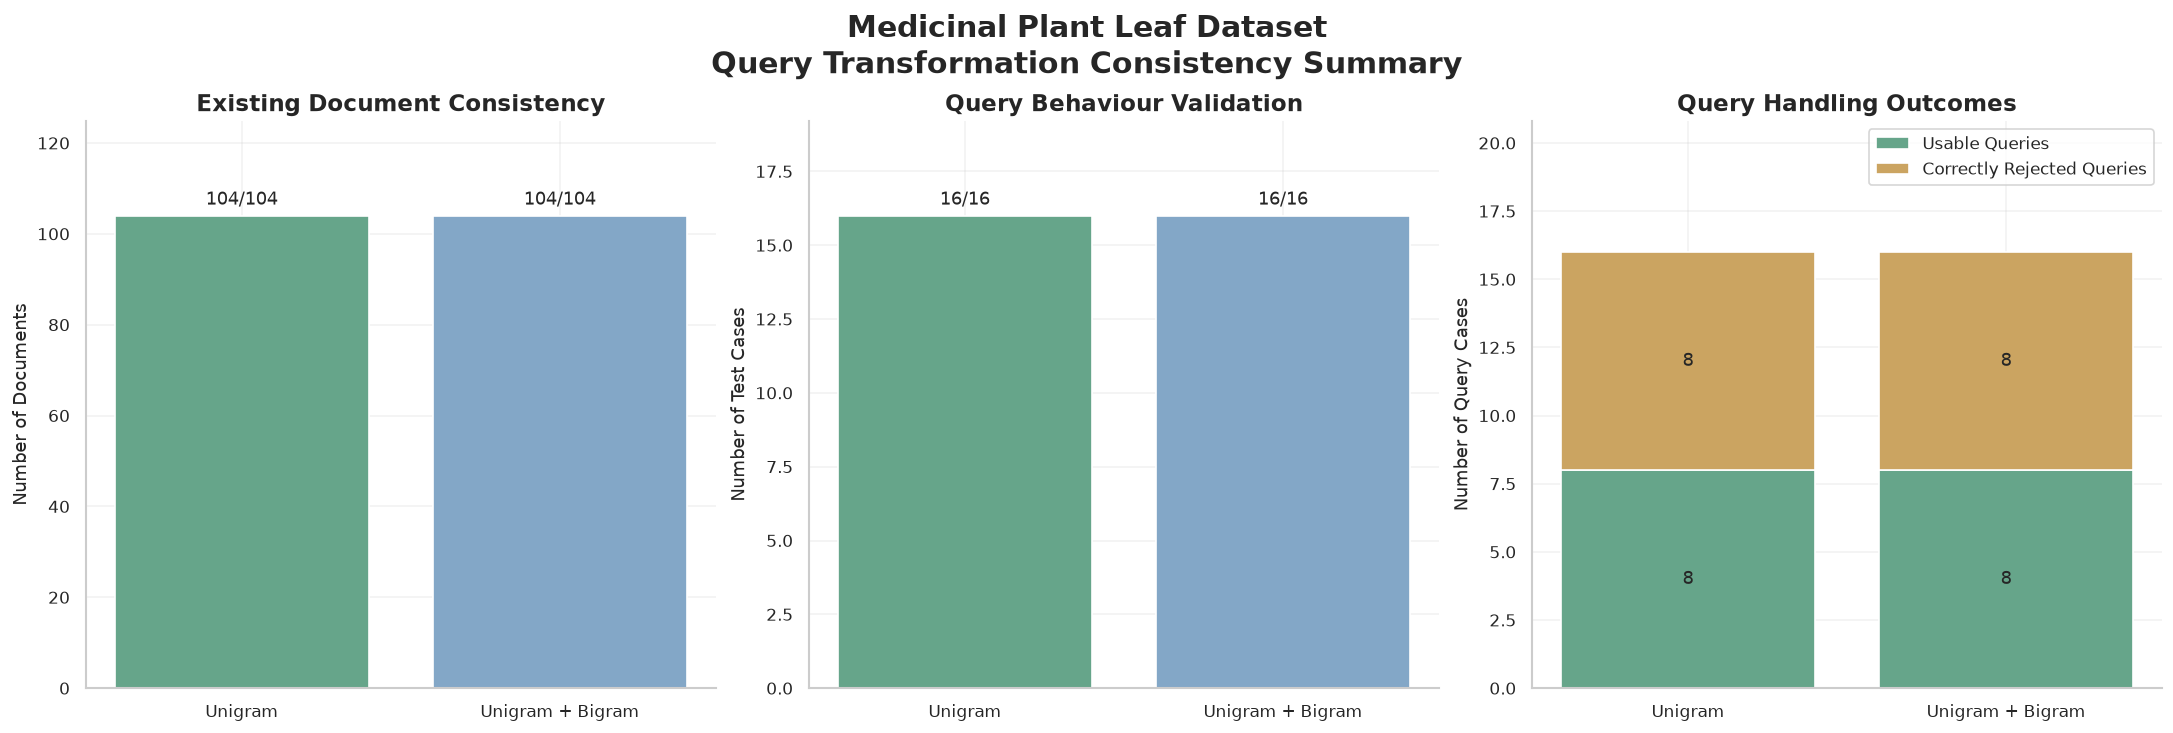

[SAVED] 93_query_transformation_consistency_summary.png


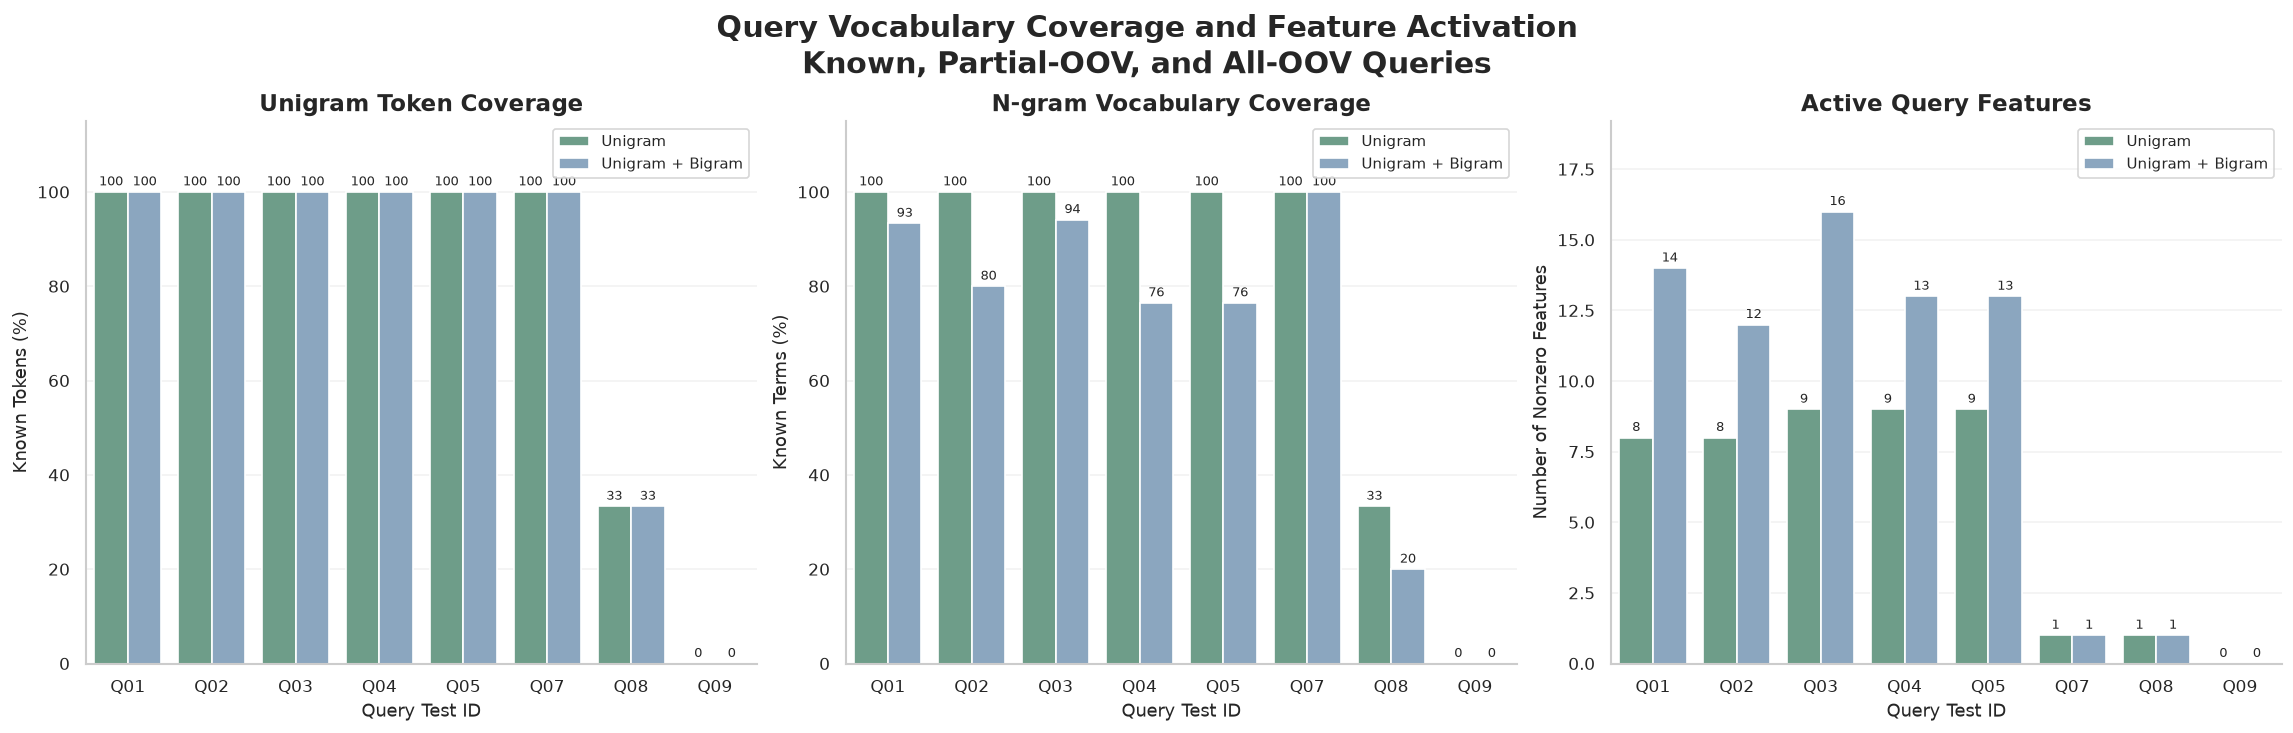

[SAVED] 94_query_vocabulary_coverage_analysis.png


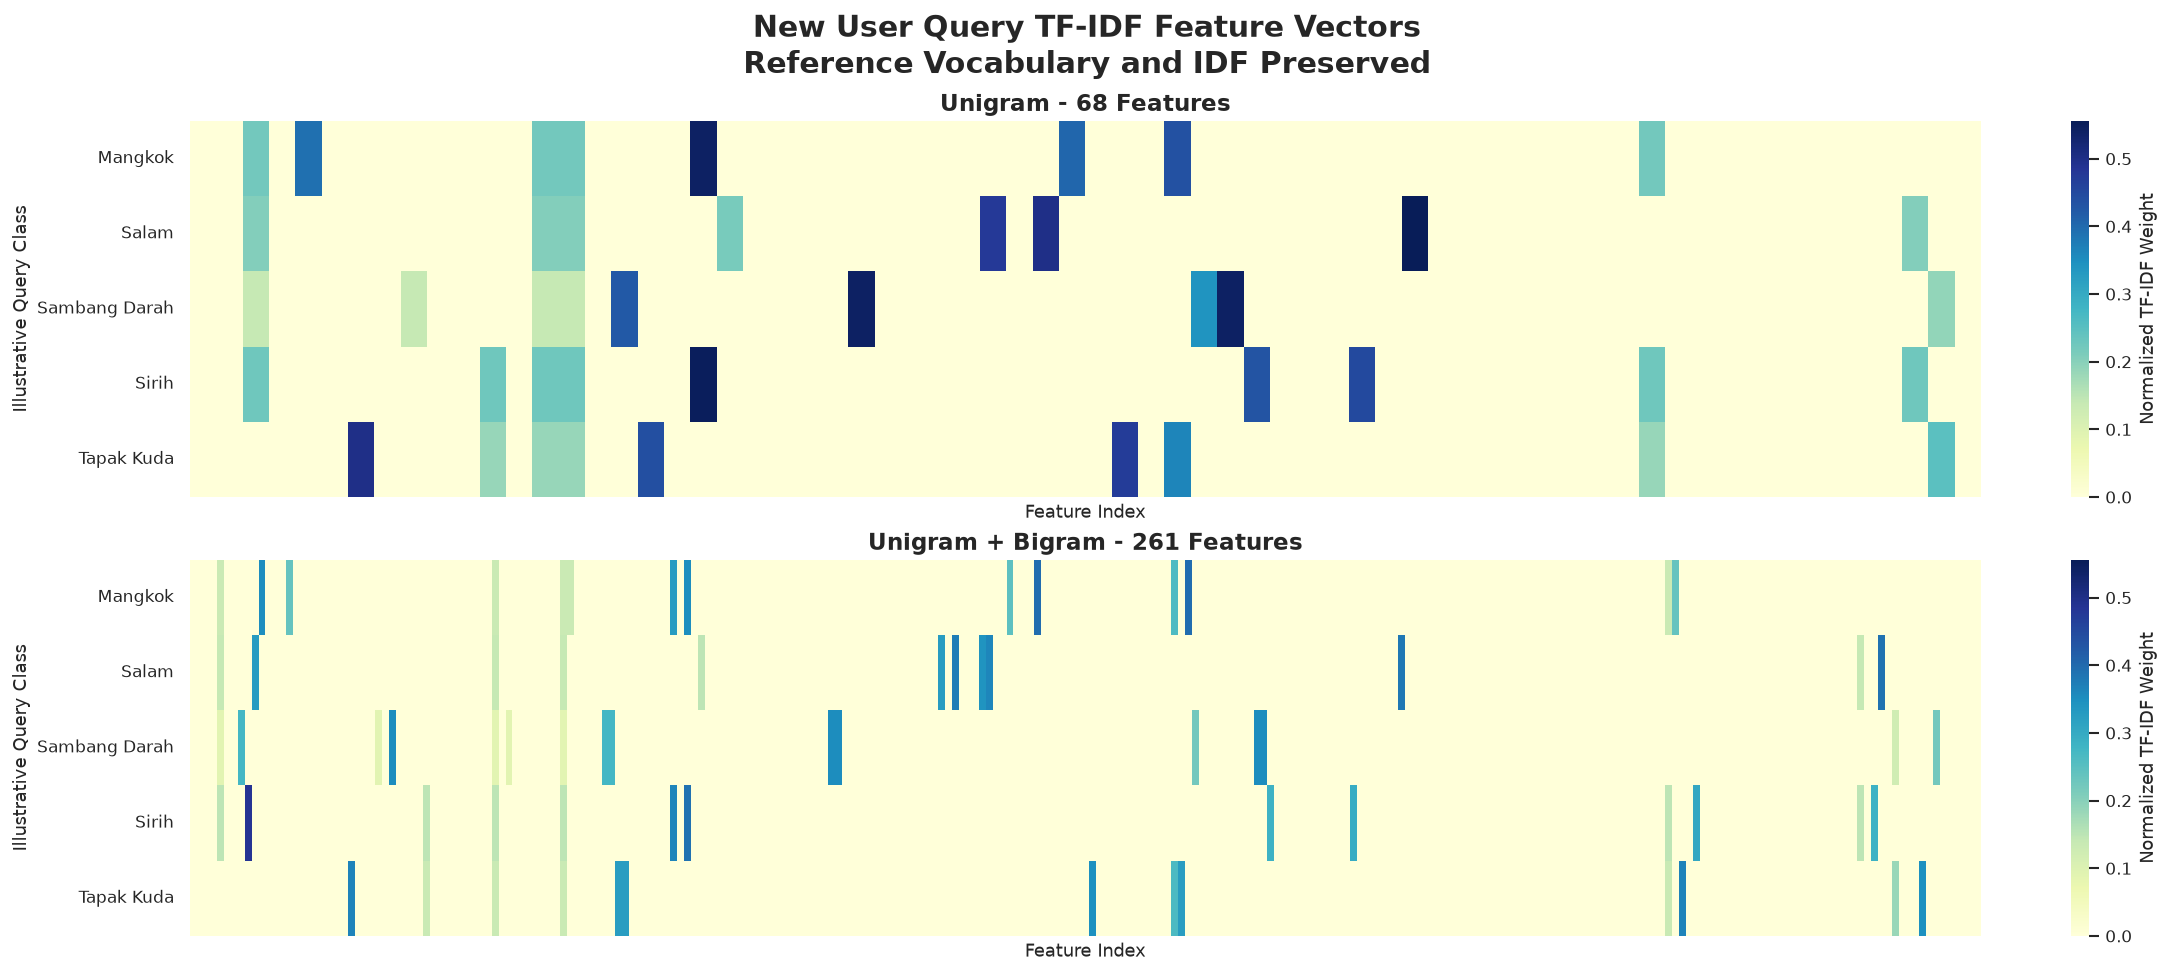

[SAVED] 95_query_tfidf_feature_vectors.png


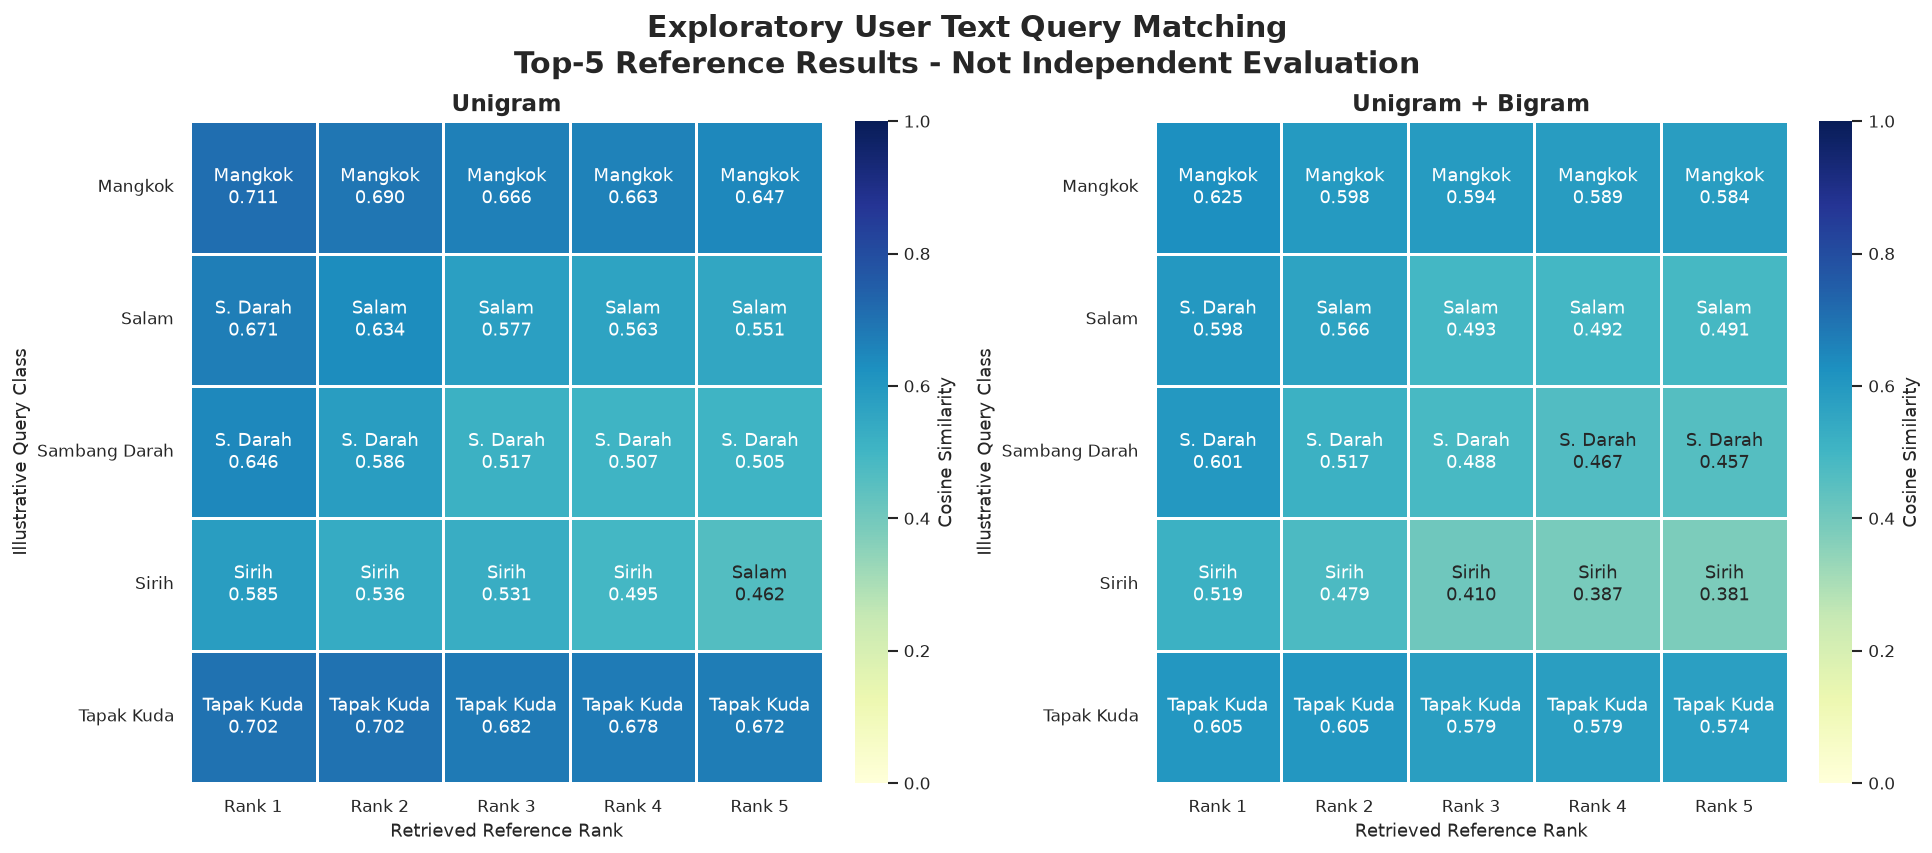

[SAVED] 96_exploratory_text_query_matching.png

11. OVERALL QUERY TRANSFORMATION SUMMARY
-----------------------------------------------------------------


,Indicator,Result
0,Reference documents,104
1,TF-IDF configurations,2
2,Raw preprocessing parity passed,104
3,Existing document consistency records,208
4,Existing document consistency passed,208
5,Maximum vector difference,0.0
6,Maximum cosine similarity difference,0.0
7,Query test cases,16
8,Total query test records,32
9,Query test records passed,32



12. SAVING QUERY TRANSFORMATION REPORTS
-----------------------------------------------------------------
[SAVED] 308_query_preprocessing_parity.csv
[SAVED] 309_tfidf_query_transformation_consistency.csv
[SAVED] 310_tfidf_query_consistency_summary.csv
[SAVED] 311_tfidf_query_test_results.csv
[SAVED] 312_tfidf_query_topk_matches.csv
[SAVED] 313_tfidf_query_active_terms.csv
[SAVED] 314_tfidf_query_test_summary.csv
[SAVED] 315_tfidf_query_validation.csv
[SAVED] 316_query_transformation_summary.csv

FINAL QUERY TRANSFORMATION CONSISTENCY SUMMARY

PREPROCESSING CONSISTENCY
-----------------------------------------------------------------
Raw preprocessing parity : 104/104

EXISTING DOCUMENT CONSISTENCY
-----------------------------------------------------------------

Unigram
Documents passed          : 104/104
Maximum vector difference : 1.665e-16
Maximum similarity difference: 6.661e-16

Unigram + Bigram
Documents passed          : 104/104
Maximum vector difference : 1.110e-16
Maximum si

In [12]:
    # ==================================================
# CELL 13 - QUERY TRANSFORMATION CONSISTENCY
# ==================================================

import re
import time
import unicodedata

from pathlib import Path
from collections import Counter
from scipy.sparse import issparse
from sklearn.metrics.pairwise import cosine_similarity

print("QUERY TRANSFORMATION CONSISTENCY")
print("=" * 65)

QUERY_TRANSFORMATION_CONSISTENCY_COMPLETED = False


# ==================================================
# 1. VALIDATE PREVIOUS PROCESSING STAGES
# ==================================================

assert TFIDF_FEATURE_EXTRACTION_COMPLETED is True
assert TFIDF_MATRIX_ANALYSIS_COMPLETED is True
assert TEXT_FEATURE_QUALITY_VALIDATION_COMPLETED is True
assert COSINE_SIMILARITY_ANALYSIS_COMPLETED is True

assert tfidf_quality_validation_df["passed"].all()
assert tfidf_cosine_validation_df["passed"].all()

assert np.array_equal(
    tfidf_sample_ids,
    loaded_visual_sample_ids
)

assert np.array_equal(
    tfidf_labels,
    validated_text_labels
)

query_sample_ids = np.asarray(
    tfidf_sample_ids, dtype=str
)

query_reference_labels = np.asarray(
    tfidf_labels
)

query_n_samples = len(query_sample_ids)

print("[PASS] Previous processing stages validated.")


# ==================================================
# 2. QUERY TRANSFORMATION CONFIGURATION
# ==================================================

QUERY_TRANSFORMATION_TOLERANCE = 1e-10
QUERY_TOP_K = 5

QUERY_ANALYSIS_SCOPE = (
    "Exploratory Full-Gallery Query Transformation"
)

QUERY_REMOVE_CLASS_NAMES = True

QUERY_CLASS_ALIASES = [
    "mangkok",
    "salam",
    "sambang darah",
    "sirih",
    "tapak kuda"
]

QUERY_COLORS = {
    TFIDF_BASELINE_NAME: "#66A58A",
    TFIDF_ALTERNATIVE_NAME: "#83A7C7"
}

query_preprocessing_config = {
    "unicode_normalization": "NFKC",
    "lowercase": True,
    "punctuation_replacement": "space",
    "underscore_replacement": "space",
    "normalize_whitespace": True,
    "remove_class_names": QUERY_REMOVE_CLASS_NAMES,
    "class_aliases": QUERY_CLASS_ALIASES.copy(),
    "stopword_removal": False,
    "stemming": False,
    "preserve_repeated_words": True,
    "preserve_sentence_boundaries": False,
    "vectorizer_operation": "transform",
    "empty_query_policy": "reject_text_matching",
    "all_oov_policy": "reject_text_matching"
}

query_figure_paths = []
query_validation_records = []

print("\n1. QUERY CONFIGURATION")
print("-" * 65)

display(
    pd.DataFrame(
        query_preprocessing_config.items(),
        columns=["Parameter", "Value"]
    )
)


# ==================================================
# 3. SAVE ORIGINAL VECTORIZER STATE
# ==================================================

query_vectorizer_snapshots = {}

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    vectorizer = tfidf_vectorizers[configuration_name]

    query_vectorizer_snapshots[configuration_name] = {
        "vocabulary": dict(vectorizer.vocabulary_),
        "idf": vectorizer.idf_.copy(),
        "feature_names": (
            vectorizer.get_feature_names_out().copy()
        ),
        "params": vectorizer.get_params(deep=False).copy(),
        "matrix": tfidf_matrices[
            configuration_name
        ].copy()
    }

query_corpus_snapshot = list(validated_text_corpus)

print("[PASS] Original vectorizer states preserved.")


# ==================================================
# 4. VALIDATION HELPER FUNCTIONS
# ==================================================

def register_query_check(
    configuration,
    check_name,
    passed
):

    query_validation_records.append({
        "configuration": configuration,
        "validation_check": check_name,
        "passed": bool(passed),
        "status": "Passed" if passed else "Failed"
    })


def maximum_sparse_difference(matrix_a, matrix_b):

    assert matrix_a.shape == matrix_b.shape

    difference = (matrix_a - matrix_b).tocsr()

    difference.eliminate_zeros()

    if difference.nnz == 0:
        return 0.0

    return float(
        np.max(np.abs(difference.data))
    )


# ==================================================
# 5. DEFINE QUERY PREPROCESSING FUNCTION
# ==================================================

# Class names are removed using complete-word matching.
# Longer aliases are matched first.

query_alias_pattern = re.compile(
    r"\b(?:"
    + "|".join(
        re.escape(alias)
        for alias in sorted(
            QUERY_CLASS_ALIASES,
            key=len,
            reverse=True
        )
    )
    + r")\b"
)


def preprocess_text_query(raw_query):

    if raw_query is None:
        return ""

    if not isinstance(raw_query, str):
        raise TypeError(
            "Text query must be a string."
        )

    text = unicodedata.normalize(
        "NFKC",
        raw_query
    )

    # Case folding.
    text = text.lower()

    # Replace punctuation and underscores with spaces.
    text = re.sub(
        r"[^\w\s]|_",
        " ",
        text
    )

    # Normalize whitespace before alias matching.
    text = " ".join(text.split())

    # Prevent explicit class names from becoming
    # shortcuts in morphology-based retrieval.
    if QUERY_REMOVE_CLASS_NAMES:

        text = query_alias_pattern.sub(
            " ",
            text
        )

    # Final whitespace normalization.
    text = " ".join(text.split())

    return text


print("\n2. QUERY PREPROCESSING EXAMPLE")
print("-" * 65)

example_raw_query = (
    "  Daun BERWARNA Hijau, berbentuk "
    "lonjong dengan ujung meruncing!  "
)

example_cleaned_query = preprocess_text_query(
    example_raw_query
)

print("Original :", example_raw_query)
print("Cleaned  :", example_cleaned_query)


# ==================================================
# 6. DEFINE QUERY TRANSFORMATION FUNCTION
# ==================================================

def transform_text_query(
    raw_query,
    configuration_name=TFIDF_BASELINE_NAME
):

    if configuration_name not in tfidf_vectorizers:

        raise ValueError(
            f"Unknown TF-IDF configuration: "
            f"{configuration_name}"
        )

    vectorizer = tfidf_vectorizers[
        configuration_name
    ]

    vocabulary = vectorizer.vocabulary_

    feature_dimension = len(vocabulary)

    result = {
        "configuration": configuration_name,
        "raw_query": raw_query,
        "cleaned_query": "",
        "status": None,
        "usable_for_matching": False,
        "feature_dimension": feature_dimension,
        "unigram_token_count": 0,
        "known_unigram_count": 0,
        "unigram_coverage": 0.0,
        "generated_term_count": 0,
        "known_term_count": 0,
        "oov_term_count": 0,
        "vocabulary_coverage": 0.0,
        "known_terms": [],
        "oov_terms": [],
        "nonzero_features": 0,
        "l2_norm": 0.0,
        "transformation_time_ms": 0.0,
        "vector": None
    }

    start_time = time.perf_counter()

    # --------------------------------------------------
    # A. Validate input type
    # --------------------------------------------------

    if raw_query is not None and not isinstance(
        raw_query, str
    ):

        result["status"] = "Invalid Input"

    else:

        cleaned_query = preprocess_text_query(
            raw_query
        )

        result["cleaned_query"] = cleaned_query

        # ----------------------------------------------
        # B. Empty query handling
        # ----------------------------------------------

        if not cleaned_query:

            result["status"] = "Empty Query"

        else:

            # Use the original fitted vectorizer analyzer.
            generated_terms = vectorizer.build_analyzer()(
                cleaned_query
            )

            # Use baseline analyzer for unigram coverage.
            unigram_tokens = (
                tfidf_vectorizer.build_analyzer()(
                    cleaned_query
                )
            )

            known_unigrams = [
                term for term in unigram_tokens
                if term in vocabulary
            ]

            known_terms = [
                term for term in generated_terms
                if term in vocabulary
            ]

            oov_terms = [
                term for term in generated_terms
                if term not in vocabulary
            ]

            result.update({
                "unigram_token_count": len(unigram_tokens),
                "known_unigram_count": len(known_unigrams),
                "generated_term_count": len(generated_terms),
                "known_term_count": len(known_terms),
                "oov_term_count": len(oov_terms),
                "known_terms": known_terms,
                "oov_terms": oov_terms
            })

            if unigram_tokens:

                result["unigram_coverage"] = (
                    len(known_unigrams)
                    / len(unigram_tokens)
                )

            if generated_terms:

                result["vocabulary_coverage"] = (
                    len(known_terms)
                    / len(generated_terms)
                )

            # ------------------------------------------
            # C. No valid tokens
            # ------------------------------------------

            if not generated_terms:

                result["status"] = "No Valid Tokens"

            else:

                # IMPORTANT:
                # Never use fit() or fit_transform()
                # for an incoming user query.

                query_vector = vectorizer.transform(
                    [cleaned_query]
                ).tocsr()

                query_norm = float(
                    np.sqrt(
                        query_vector.multiply(
                            query_vector
                        ).sum()
                    )
                )

                result["vector"] = query_vector

                result["nonzero_features"] = (
                    query_vector.nnz
                )

                result["l2_norm"] = query_norm

                # Validate numerical properties.
                assert query_vector.shape == (
                    1, feature_dimension
                )

                assert np.isfinite(
                    query_vector.data
                ).all()

                assert np.all(
                    query_vector.data >= 0
                )

                # --------------------------------------
                # D. Handle zero vectors
                # --------------------------------------

                if query_vector.nnz == 0:

                    result["status"] = "All OOV"

                else:

                    assert np.isclose(
                        query_norm,
                        1.0,
                        atol=QUERY_TRANSFORMATION_TOLERANCE,
                        rtol=0
                    )

                    result["usable_for_matching"] = True

                    if oov_terms:

                        result["status"] = "Valid - Partial OOV"

                    else:

                        result["status"] = "Valid"

    result["transformation_time_ms"] = (
        time.perf_counter() - start_time
    ) * 1000

    return result


print("[PASS] Query transformation function defined.")


# ==================================================
# 7. DEFINE TEXT QUERY MATCHING FUNCTION
# ==================================================

def match_text_query(
    raw_query,
    configuration_name=TFIDF_BASELINE_NAME,
    top_k=QUERY_TOP_K,
    exclude_sample_id=None
):

    if (
        not isinstance(top_k, (int, np.integer))
        or isinstance(top_k, bool)
        or top_k < 1
    ):

        raise ValueError(
            "top_k must be a positive integer."
        )

    query_result = transform_text_query(
        raw_query,
        configuration_name
    )

    matching_columns = [
        "rank",
        "reference_index",
        "sample_id",
        "kelas",
        "cosine_similarity"
    ]

    # Do not produce arbitrary rankings from
    # empty or all-zero query vectors.

    if not query_result["usable_for_matching"]:

        return (
            query_result,
            pd.DataFrame(columns=matching_columns)
        )

    reference_matrix = tfidf_matrices[
        configuration_name
    ]

    scores = cosine_similarity(
        query_result["vector"],
        reference_matrix
    ).ravel()

    assert np.isfinite(scores).all()

    assert scores.min() >= (
        -QUERY_TRANSFORMATION_TOLERANCE
    )

    assert scores.max() <= (
        1 + QUERY_TRANSFORMATION_TOLERANCE
    )

    scores = np.clip(scores, 0.0, 1.0)

    candidate_indices = np.arange(
        query_n_samples
    )

    # Optional exclusion when an existing sample
    # is being used as the query.

    if exclude_sample_id is not None:

        candidate_indices = candidate_indices[
            query_sample_ids[candidate_indices]
            != str(exclude_sample_id)
        ]

    # Primary ranking: descending similarity.
    # Secondary ranking: ascending sample ID.

    ranking_order = np.lexsort((
        query_sample_ids[candidate_indices],
        -scores[candidate_indices]
    ))

    selected_indices = candidate_indices[
        ranking_order[:top_k]
    ]

    matches_df = pd.DataFrame({
        "rank": np.arange(
            1, len(selected_indices) + 1
        ),
        "reference_index": selected_indices,
        "sample_id": query_sample_ids[selected_indices],
        "kelas": query_reference_labels[selected_indices],
        "cosine_similarity": scores[selected_indices]
    })

    return query_result, matches_df


print("[PASS] Text query matching function defined.")


# ==================================================
# 8. LOAD ORIGINAL DESCRIPTIONS FOR PARITY CHECK
# ==================================================

# Locate the existing processed metadata without
# changing the original file.

query_root_candidates = []

if "PROJECT_ROOT" in globals():

    query_root_candidates.append(
        Path(PROJECT_ROOT)
    )

query_root_candidates.extend([
    Path.cwd(),
    *Path.cwd().parents
])

query_metadata_candidates = [
    root / "dataset" / "processed" / "metadata_processed.csv"
    for root in query_root_candidates
]

query_metadata_path = next(
    (
        path for path in query_metadata_candidates
        if path.is_file()
    ),
    None
)

assert query_metadata_path is not None, (
    "metadata_processed.csv was not found under "
    "dataset/processed/. Check PROJECT_ROOT."
)

query_source_metadata_df = pd.read_csv(
    query_metadata_path,
    dtype={"sample_id": str},
    keep_default_na=False
)

required_query_metadata_columns = {
    "sample_id",
    "original_description",
    "cleaned_description",
    "tokenized_description"
}

assert required_query_metadata_columns.issubset(
    query_source_metadata_df.columns
)

assert query_source_metadata_df[
    "sample_id"
].is_unique

assert set(query_sample_ids).issubset(
    query_source_metadata_df["sample_id"]
)

# Reindex metadata to follow the actual matrix order.

query_source_metadata_df = (
    query_source_metadata_df
    .set_index("sample_id")
    .loc[query_sample_ids]
    .reset_index()
)

assert np.array_equal(
    query_source_metadata_df["sample_id"].to_numpy(),
    query_sample_ids
)

query_raw_descriptions = (
    query_source_metadata_df[
        "original_description"
    ].tolist()
)

query_reprocessed_descriptions = [
    preprocess_text_query(text)
    for text in query_raw_descriptions
]

query_preprocessing_parity_df = pd.DataFrame({
    "sample_id": query_sample_ids,
    "kelas": query_reference_labels,
    "original_description": query_raw_descriptions,
    "stored_cleaned_description": (
        query_source_metadata_df[
            "cleaned_description"
        ].tolist()
    ),
    "validated_corpus": list(validated_text_corpus),
    "reprocessed_description": (
        query_reprocessed_descriptions
    )
})

query_preprocessing_parity_df[
    "matches_stored_cleaned"
] = (
    query_preprocessing_parity_df[
        "reprocessed_description"
    ]
    == query_preprocessing_parity_df[
        "stored_cleaned_description"
    ]
)

query_preprocessing_parity_df[
    "matches_validated_corpus"
] = (
    query_preprocessing_parity_df[
        "reprocessed_description"
    ]
    == query_preprocessing_parity_df[
        "validated_corpus"
    ]
)

print("\n3. RAW DESCRIPTION PREPROCESSING PARITY")
print("-" * 65)

print(
    "Metadata path:",
    query_metadata_path
)

print(
    "Matching cleaned descriptions:",
    query_preprocessing_parity_df[
        "matches_stored_cleaned"
    ].sum(),
    "/",
    query_n_samples
)

print(
    "Matching validated corpus:",
    query_preprocessing_parity_df[
        "matches_validated_corpus"
    ].sum(),
    "/",
    query_n_samples
)

register_query_check(
    "Overall",
    "Raw descriptions reproduce stored cleaned text",
    query_preprocessing_parity_df[
        "matches_stored_cleaned"
    ].all()
)

register_query_check(
    "Overall",
    "Raw descriptions reproduce validated corpus",
    query_preprocessing_parity_df[
        "matches_validated_corpus"
    ].all()
)

# If this fails, do not continue with an inconsistent
# preprocessing pipeline.

assert query_preprocessing_parity_df[
    "matches_validated_corpus"
].all(), (
    "Query preprocessing does not reproduce "
    "the existing corpus. Inspect parity results."
)


# ==================================================
# 9. VALIDATE EXISTING DOCUMENT TRANSFORMATION
# ==================================================

query_consistency_records = []

print("\n4. EXISTING DOCUMENT CONSISTENCY")
print("-" * 65)

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    vectorizer = tfidf_vectorizers[
        configuration_name
    ]

    reference_matrix = tfidf_matrices[
        configuration_name
    ]

    # A. Batch transformation consistency.

    retransformed_matrix = vectorizer.transform(
        validated_text_corpus
    ).tocsr()

    batch_max_difference = maximum_sparse_difference(
        retransformed_matrix,
        reference_matrix
    )

    register_query_check(
        configuration_name,
        "Batch transformation reproduces reference matrix",
        batch_max_difference
        <= QUERY_TRANSFORMATION_TOLERANCE
    )

    # B. Individual raw-description query consistency.

    for row_index, raw_query in enumerate(
        query_raw_descriptions
    ):

        result = transform_text_query(
            raw_query,
            configuration_name
        )

        assert result["usable_for_matching"], (
            f"Existing sample produced invalid query: "
            f"{query_sample_ids[row_index]}"
        )

        query_vector = result["vector"]

        reference_vector = reference_matrix[
            row_index:row_index + 1
        ]

        vector_difference = maximum_sparse_difference(
            query_vector,
            reference_vector
        )

        self_similarity = float(
            cosine_similarity(
                query_vector,
                reference_vector
            )[0, 0]
        )

        # Verify that a query reproduces the complete
        # similarity row generated in Cell 12.

        query_similarity_scores = cosine_similarity(
            query_vector,
            reference_matrix
        ).ravel()

        expected_similarity_scores = (
            tfidf_cosine_similarity_matrices[
                configuration_name
            ][row_index]
        )

        similarity_difference = float(
            np.max(
                np.abs(
                    query_similarity_scores
                    - expected_similarity_scores
                )
            )
        )

        passed = (
            vector_difference
            <= QUERY_TRANSFORMATION_TOLERANCE

            and similarity_difference
            <= QUERY_TRANSFORMATION_TOLERANCE

            and np.isclose(
                self_similarity,
                1.0,
                atol=QUERY_TRANSFORMATION_TOLERANCE,
                rtol=0
            )
        )

        query_consistency_records.append({
            "configuration": configuration_name,
            "row_index": row_index,
            "sample_id": query_sample_ids[row_index],
            "kelas": query_reference_labels[row_index],
            "feature_dimension": query_vector.shape[1],
            "nonzero_features": query_vector.nnz,
            "query_l2_norm": result["l2_norm"],
            "self_similarity": self_similarity,
            "maximum_vector_difference": vector_difference,
            "maximum_similarity_difference": (
                similarity_difference
            ),
            "passed": bool(passed)
        })

    print(f"\nConfiguration: {configuration_name}")

    print(
        f"Batch maximum difference: "
        f"{batch_max_difference:.3e}"
    )


tfidf_query_transformation_consistency_df = pd.DataFrame(
    query_consistency_records
)

tfidf_query_consistency_summary_df = (
    tfidf_query_transformation_consistency_df
    .groupby("configuration", sort=False)
    .agg(
        total_documents=("sample_id", "count"),
        passed_documents=("passed", "sum"),
        minimum_self_similarity=("self_similarity", "min"),
        maximum_vector_difference=(
            "maximum_vector_difference", "max"
        ),
        maximum_similarity_difference=(
            "maximum_similarity_difference", "max"
        )
    )
    .reset_index()
)

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    config_records = (
        tfidf_query_transformation_consistency_df.loc[
            tfidf_query_transformation_consistency_df[
                "configuration"
            ].eq(configuration_name)
        ]
    )

    register_query_check(
        configuration_name,
        "All individual document transformations consistent",
        (
            len(config_records) == query_n_samples
            and config_records["passed"].all()
        )
    )

print("\nExisting document consistency summary:")

display(tfidf_query_consistency_summary_df)


# ==================================================
# 10. DEFINE NEW USER QUERY TEST CASES
# ==================================================

# Expected classes are illustrative morphology labels.
# They are NOT passed to the retrieval algorithm.

query_test_cases = [

    {
        "query_id": "Q01",
        "query_type": "Morphology Query",
        "target_class": "Mangkok",
        "text": (
            "Daun berbentuk membulat menyerupai hati "
            "dengan tepi bergelombang."
        ),
        "expected": "Usable"
    },

    {
        "query_id": "Q02",
        "query_type": "Morphology Query",
        "target_class": "Salam",
        "text": (
            "Daun hijau berbentuk lonjong memanjang "
            "dengan ujung runcing."
        ),
        "expected": "Usable"
    },

    {
        "query_id": "Q03",
        "query_type": "Morphology Query",
        "target_class": "Sambang Darah",
        "text": (
            "Daun berwarna merah keunguan berbentuk "
            "elips dengan urat menyirip."
        ),
        "expected": "Usable"
    },

    {
        "query_id": "Q04",
        "query_type": "Morphology Query",
        "target_class": "Sirih",
        "text": (
            "Daun berbentuk hati dengan ujung "
            "meruncing dan tepi rata."
        ),
        "expected": "Usable"
    },

    {
        "query_id": "Q05",
        "query_type": "Morphology Query",
        "target_class": "Tapak Kuda",
        "text": (
            "Daun menyerupai ginjal dengan urat "
            "menjari dan tepi berlekuk."
        ),
        "expected": "Usable"
    },

    {
        "query_id": "Q06",
        "query_type": "Case and Punctuation Variation",
        "target_class": "Salam",
        "text": (
            "  DAUN HIJAU, BERBENTUK LONJONG "
            "MEMANJANG DENGAN UJUNG RUNCING!!! "
        ),
        "expected": "Usable"
    },

    {
        "query_id": "Q07",
        "query_type": "Single Known Token",
        "target_class": "",
        "text": "hijau",
        "expected": "Valid"
    },

    {
        "query_id": "Q08",
        "query_type": "Partial OOV",
        "target_class": "",
        "text": "hijau qzxv plmokn",
        "expected": "Valid - Partial OOV"
    },

    {
        "query_id": "Q09",
        "query_type": "All OOV",
        "target_class": "",
        "text": "qzxv plmokn",
        "expected": "All OOV"
    },

    {
        "query_id": "Q10",
        "query_type": "Empty String",
        "target_class": "",
        "text": "",
        "expected": "Empty Query"
    },

    {
        "query_id": "Q11",
        "query_type": "Whitespace Only",
        "target_class": "",
        "text": "   \t   \n   ",
        "expected": "Empty Query"
    },

    {
        "query_id": "Q12",
        "query_type": "Punctuation Only",
        "target_class": "",
        "text": "!?.,;---",
        "expected": "Empty Query"
    },

    {
        "query_id": "Q13",
        "query_type": "Class Name Only",
        "target_class": "",
        "text": "Sirih",
        "expected": "Empty Query"
    },

    {
        "query_id": "Q14",
        "query_type": "Invalid Short Tokens",
        "target_class": "",
        "text": "a b c",
        "expected": "No Valid Tokens"
    },

    {
        "query_id": "Q15",
        "query_type": "Missing Input",
        "target_class": "",
        "text": None,
        "expected": "Empty Query"
    },

    {
        "query_id": "Q16",
        "query_type": "Invalid Input Type",
        "target_class": "",
        "text": 12345,
        "expected": "Invalid Input"
    }
]

print("\n5. USER QUERY TEST CASES")
print("-" * 65)

print(
    f"Total query test cases: "
    f"{len(query_test_cases)}"
)

display(pd.DataFrame(query_test_cases))


# ==================================================
# 11. EXECUTE NEW QUERY TRANSFORMATION TESTS
# ==================================================

query_test_records = []
query_matching_records = []
query_active_term_records = []

tfidf_query_vectors_by_config = {
    name: {}
    for name in TFIDF_CONFIGURATION_ORDER
}

print("\n6. EXECUTING QUERY TRANSFORMATION TESTS")
print("-" * 65)

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    vectorizer = tfidf_vectorizers[
        configuration_name
    ]

    feature_names = vectorizer.get_feature_names_out()

    for test_case in query_test_cases:

        result, matches_df = match_text_query(
            test_case["text"],
            configuration_name=configuration_name,
            top_k=QUERY_TOP_K
        )

        query_id = test_case["query_id"]

        query_vector = result["vector"]

        tfidf_query_vectors_by_config[
            configuration_name
        ][query_id] = query_vector

        # ----------------------------------------------
        # A. Check expected query behaviour
        # ----------------------------------------------

        if test_case["expected"] == "Usable":

            status_passed = result[
                "usable_for_matching"
            ]

        else:

            status_passed = (
                result["status"] == test_case["expected"]
            )

        vector_valid = True

        if query_vector is not None:

            vector_valid = (
                issparse(query_vector)

                and query_vector.format == "csr"

                and query_vector.shape == (
                    1, len(feature_names)
                )

                and np.isfinite(
                    query_vector.data
                ).all()

                and np.all(
                    query_vector.data >= 0
                )
            )

        if result["usable_for_matching"]:

            normalization_valid = np.isclose(
                result["l2_norm"],
                1.0,
                atol=QUERY_TRANSFORMATION_TOLERANCE,
                rtol=0
            )

            matching_valid = (
                len(matches_df) == QUERY_TOP_K

                and matches_df[
                    "sample_id"
                ].is_unique

                and matches_df[
                    "cosine_similarity"
                ].between(0, 1).all()

                and matches_df[
                    "cosine_similarity"
                ].is_monotonic_decreasing
            )

        else:

            normalization_valid = (
                result["l2_norm"] == 0
            )

            matching_valid = matches_df.empty

        test_passed = bool(
            status_passed
            and vector_valid
            and normalization_valid
            and matching_valid
        )

        register_query_check(
            configuration_name,
            f"{query_id} - {test_case['query_type']}",
            test_passed
        )

        # ----------------------------------------------
        # B. Store query transformation diagnostics
        # ----------------------------------------------

        top1_class = (
            matches_df.iloc[0]["kelas"]
            if not matches_df.empty
            else ""
        )

        top1_similarity = (
            float(matches_df.iloc[0]["cosine_similarity"])
            if not matches_df.empty
            else np.nan
        )

        query_test_records.append({
            "configuration": configuration_name,
            "query_id": query_id,
            "query_type": test_case["query_type"],
            "illustrative_target_class": (
                test_case["target_class"]
            ),
            "raw_query": test_case["text"],
            "cleaned_query": result["cleaned_query"],
            "expected_status": test_case["expected"],
            "query_status": result["status"],
            "usable_for_matching": (
                result["usable_for_matching"]
            ),
            "feature_dimension": (
                result["feature_dimension"]
            ),
            "unigram_token_count": (
                result["unigram_token_count"]
            ),
            "known_unigram_count": (
                result["known_unigram_count"]
            ),
            "unigram_coverage_percent": (
                result["unigram_coverage"] * 100
            ),
            "generated_term_count": (
                result["generated_term_count"]
            ),
            "known_term_count": (
                result["known_term_count"]
            ),
            "oov_term_count": (
                result["oov_term_count"]
            ),
            "vocabulary_coverage_percent": (
                result["vocabulary_coverage"] * 100
            ),
            "known_terms": ", ".join(
                sorted(set(result["known_terms"]))
            ),
            "oov_terms": ", ".join(
                sorted(set(result["oov_terms"]))
            ),
            "nonzero_features": (
                result["nonzero_features"]
            ),
            "l2_norm": result["l2_norm"],
            "transformation_time_ms": (
                result["transformation_time_ms"]
            ),
            "returned_matches": len(matches_df),
            "top1_class": top1_class,
            "top1_similarity": top1_similarity,
            "passed": test_passed
        })

        # ----------------------------------------------
        # C. Store retrieval matches
        # ----------------------------------------------

        for match in matches_df.to_dict("records"):

            query_matching_records.append({
                "configuration": configuration_name,
                "query_id": query_id,
                "query_type": test_case["query_type"],
                "illustrative_target_class": (
                    test_case["target_class"]
                ),
                **match
            })

        # ----------------------------------------------
        # D. Store active query features
        # ----------------------------------------------

        if query_vector is not None:

            for feature_index, weight in zip(
                query_vector.indices,
                query_vector.data
            ):

                term = feature_names[feature_index]

                query_active_term_records.append({
                    "configuration": configuration_name,
                    "query_id": query_id,
                    "feature_index": int(feature_index),
                    "term": term,
                    "ngram_type": (
                        "Bigram" if " " in term
                        else "Unigram"
                    ),
                    "tfidf_weight": float(weight)
                })

        print(
            f"[{'PASS' if test_passed else 'FAIL'}] "
            f"{configuration_name} | "
            f"{query_id} | "
            f"{result['status']}"
        )


tfidf_query_test_results_df = pd.DataFrame(
    query_test_records
)

tfidf_query_topk_matches_df = pd.DataFrame(
    query_matching_records
)

tfidf_query_active_terms_df = pd.DataFrame(
    query_active_term_records
)

print("\n7. QUERY TRANSFORMATION RESULTS")
print("-" * 65)

display(
    tfidf_query_test_results_df[[
        "configuration",
        "query_id",
        "query_type",
        "query_status",
        "nonzero_features",
        "unigram_coverage_percent",
        "vocabulary_coverage_percent",
        "l2_norm",
        "returned_matches",
        "passed"
    ]].round(6)
)


# ==================================================
# 12. VALIDATE FORMAT INVARIANCE
# ==================================================

# Q02 and Q06 contain the same description,
# with different case, punctuation, and whitespace.

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    vector_q02 = tfidf_query_vectors_by_config[
        configuration_name
    ]["Q02"]

    vector_q06 = tfidf_query_vectors_by_config[
        configuration_name
    ]["Q06"]

    format_difference = maximum_sparse_difference(
        vector_q02,
        vector_q06
    )

    register_query_check(
        configuration_name,
        "Case and punctuation invariance",
        format_difference
        <= QUERY_TRANSFORMATION_TOLERANCE
    )

    # Additional self-match exclusion test.

    original_sample_id = query_sample_ids[0]

    result, excluded_matches_df = match_text_query(
        query_raw_descriptions[0],
        configuration_name=configuration_name,
        top_k=QUERY_TOP_K,
        exclude_sample_id=original_sample_id
    )

    register_query_check(
        configuration_name,
        "Optional self-match exclusion",
        (
            len(excluded_matches_df) == QUERY_TOP_K
            and original_sample_id
            not in excluded_matches_df[
                "sample_id"
            ].values
        )
    )


# ==================================================
# 13. VALIDATE VECTORIZER INTEGRITY
# ==================================================

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    vectorizer = tfidf_vectorizers[
        configuration_name
    ]

    original_state = query_vectorizer_snapshots[
        configuration_name
    ]

    register_query_check(
        configuration_name,
        "Vocabulary unchanged",
        vectorizer.vocabulary_
        == original_state["vocabulary"]
    )

    register_query_check(
        configuration_name,
        "IDF weights unchanged",
        np.array_equal(
            vectorizer.idf_,
            original_state["idf"]
        )
    )

    register_query_check(
        configuration_name,
        "Feature order unchanged",
        np.array_equal(
            vectorizer.get_feature_names_out(),
            original_state["feature_names"]
        )
    )

    register_query_check(
        configuration_name,
        "Vectorizer parameters unchanged",
        vectorizer.get_params(deep=False)
        == original_state["params"]
    )

    register_query_check(
        configuration_name,
        "Original reference matrix unchanged",
        maximum_sparse_difference(
            tfidf_matrices[configuration_name],
            original_state["matrix"]
        ) == 0
    )


# ==================================================
# 14. OVERALL QUERY VALIDATION
# ==================================================

register_query_check(
    "Overall",
    "Original corpus unchanged",
    list(validated_text_corpus)
    == query_corpus_snapshot
)

register_query_check(
    "Overall",
    "Image-text alignment preserved",
    np.array_equal(
        tfidf_sample_ids,
        loaded_visual_sample_ids
    )
)

register_query_check(
    "Overall",
    "Existing document records reconcile",
    len(tfidf_query_transformation_consistency_df)
    == query_n_samples * len(TFIDF_CONFIGURATION_ORDER)
)

register_query_check(
    "Overall",
    "Query test records reconcile",
    len(tfidf_query_test_results_df)
    == len(query_test_cases) * len(TFIDF_CONFIGURATION_ORDER)
)

usable_query_mask = (
    tfidf_query_test_results_df[
        "usable_for_matching"
    ]
)

register_query_check(
    "Overall",
    "Invalid queries return no matches",
    tfidf_query_test_results_df.loc[
        ~usable_query_mask,
        "returned_matches"
    ].eq(0).all()
)

register_query_check(
    "Overall",
    "Usable query vectors have unit L2 norm",
    np.allclose(
        tfidf_query_test_results_df.loc[
            usable_query_mask,
            "l2_norm"
        ],
        1.0,
        atol=QUERY_TRANSFORMATION_TOLERANCE,
        rtol=0
    )
)

register_query_check(
    "Overall",
    "Query matching record counts reconcile",
    len(tfidf_query_topk_matches_df)
    == int(usable_query_mask.sum()) * QUERY_TOP_K
)

register_query_check(
    "Overall",
    "Vocabulary coverage within valid range",
    tfidf_query_test_results_df[
        "vocabulary_coverage_percent"
    ].between(0, 100).all()
)

register_query_check(
    "Overall",
    "Known and OOV term counts reconcile",
    (
        tfidf_query_test_results_df["known_term_count"]
        + tfidf_query_test_results_df["oov_term_count"]
        == tfidf_query_test_results_df["generated_term_count"]
    ).all()
)

tfidf_query_validation_df = pd.DataFrame(
    query_validation_records
)

print("\n8. TECHNICAL VALIDATION RESULTS")
print("-" * 65)

display(tfidf_query_validation_df)

assert tfidf_query_validation_df["passed"].all(), (
    tfidf_query_validation_df.loc[
        ~tfidf_query_validation_df["passed"]
    ].to_string(index=False)
)

print("[PASS] All query transformation checks passed.")


# ==================================================
# 15. SUMMARIZE QUERY TRANSFORMATION RESULTS
# ==================================================

tfidf_query_test_summary_df = (
    tfidf_query_test_results_df
    .groupby("configuration", sort=False)
    .agg(
        total_test_cases=("query_id", "count"),
        passed_test_cases=("passed", "sum"),
        usable_queries=("usable_for_matching", "sum"),
        total_matching_records=("returned_matches", "sum"),
        mean_transformation_time_ms=(
            "transformation_time_ms", "mean"
        )
    )
    .reset_index()
)

tfidf_query_test_summary_df["rejected_queries"] = (
    tfidf_query_test_summary_df["total_test_cases"]
    - tfidf_query_test_summary_df["usable_queries"]
)

print("\n9. QUERY TEST SUMMARY")
print("-" * 65)

display(tfidf_query_test_summary_df.round(6))

print("\n10. MORPHOLOGY QUERY TOP-K MATCHING")
print("-" * 65)

display(
    tfidf_query_topk_matches_df.loc[
        tfidf_query_topk_matches_df[
            "query_type"
        ].eq("Morphology Query")
    ][[
        "configuration",
        "query_id",
        "illustrative_target_class",
        "rank",
        "sample_id",
        "kelas",
        "cosine_similarity"
    ]].round(6)
)


# ==================================================
# 16. VISUALIZATION HELPER
# ==================================================

def save_query_figure(fig, filename):

    output_path = (
        TEXT_FEATURE_FIGURES_DIR / filename
    )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    query_figure_paths.append(output_path)

    plt.show()
    plt.close(fig)

    print(f"[SAVED] {filename}")


# ==================================================
# 17. VISUALIZE QUERY CONSISTENCY SUMMARY
# ==================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6),
    constrained_layout=True
)

plot_summary = (
    tfidf_query_consistency_summary_df
    .set_index("configuration")
    .loc[TFIDF_CONFIGURATION_ORDER]
    .reset_index()
)

plot_colors = [
    QUERY_COLORS[name]
    for name in TFIDF_CONFIGURATION_ORDER
]

# A. Existing document consistency.

ax = axes[0]

bars = ax.bar(
    plot_summary["configuration"],
    plot_summary["passed_documents"],
    color=plot_colors
)

ax.bar_label(
    bars,
    labels=[
        f"{int(value)}/{query_n_samples}"
        for value in plot_summary["passed_documents"]
    ],
    padding=4
)

ax.set_ylim(0, query_n_samples * 1.2)
ax.set_ylabel("Number of Documents")
ax.set_title("Existing Document Consistency")

# B. Query test case success.

ax = axes[1]

bars = ax.bar(
    tfidf_query_test_summary_df["configuration"],
    tfidf_query_test_summary_df["passed_test_cases"],
    color=plot_colors
)

ax.bar_label(
    bars,
    labels=[
        f"{int(value)}/{len(query_test_cases)}"
        for value in tfidf_query_test_summary_df[
            "passed_test_cases"
        ]
    ],
    padding=4
)

ax.set_ylim(0, len(query_test_cases) * 1.2)
ax.set_ylabel("Number of Test Cases")
ax.set_title("Query Behaviour Validation")

# C. Usable and rejected query tests.

ax = axes[2]

summary_values = (
    tfidf_query_test_summary_df
    .set_index("configuration")
    .loc[TFIDF_CONFIGURATION_ORDER]
)

usable_values = summary_values[
    "usable_queries"
].to_numpy()

rejected_values = summary_values[
    "rejected_queries"
].to_numpy()

bars_a = ax.bar(
    TFIDF_CONFIGURATION_ORDER,
    usable_values,
    color="#66A58A",
    label="Usable Queries"
)

bars_b = ax.bar(
    TFIDF_CONFIGURATION_ORDER,
    rejected_values,
    bottom=usable_values,
    color="#CBA461",
    label="Correctly Rejected Queries"
)

ax.bar_label(
    bars_a,
    label_type="center"
)

ax.bar_label(
    bars_b,
    label_type="center"
)

ax.set_ylim(0, len(query_test_cases) * 1.3)
ax.set_ylabel("Number of Query Cases")
ax.set_title("Query Handling Outcomes")
ax.legend()

fig.suptitle(
    "Medicinal Plant Leaf Dataset\n"
    "Query Transformation Consistency Summary",
    fontsize=18,
    fontweight="bold"
)

save_query_figure(
    fig,
    "93_query_transformation_consistency_summary.png"
)


# ==================================================
# 18. VISUALIZE VOCABULARY COVERAGE
# ==================================================

coverage_plot_df = (
    tfidf_query_test_results_df.loc[
        tfidf_query_test_results_df[
            "query_id"
        ].isin([
            "Q01", "Q02", "Q03", "Q04", "Q05",
            "Q07", "Q08", "Q09"
        ])
    ].copy()
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 6),
    constrained_layout=True
)

for ax, column, title, ylabel in [

    (
        axes[0],
        "unigram_coverage_percent",
        "Unigram Token Coverage",
        "Known Tokens (%)"
    ),

    (
        axes[1],
        "vocabulary_coverage_percent",
        "N-gram Vocabulary Coverage",
        "Known Terms (%)"
    ),

    (
        axes[2],
        "nonzero_features",
        "Active Query Features",
        "Number of Nonzero Features"
    )
]:

    sns.barplot(
        data=coverage_plot_df,
        x="query_id",
        y=column,
        hue="configuration",
        hue_order=TFIDF_CONFIGURATION_ORDER,
        palette=QUERY_COLORS,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Query Test ID")
    ax.set_ylabel(ylabel)

    for container in ax.containers:

        ax.bar_label(
            container,
            fmt="%.0f",
            padding=2,
            fontsize=8
        )

    if column.endswith("_percent"):
        ax.set_ylim(0, 115)
    else:
        ax.margins(y=0.2)

    ax.legend(fontsize=9)

fig.suptitle(
    "Query Vocabulary Coverage and Feature Activation\n"
    "Known, Partial-OOV, and All-OOV Queries",
    fontsize=18,
    fontweight="bold"
)

save_query_figure(
    fig,
    "94_query_vocabulary_coverage_analysis.png"
)


# ==================================================
# 19. VISUALIZE REPRESENTATIVE QUERY FEATURE VECTORS
# ==================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(18, 8),
    constrained_layout=True
)

morphology_query_cases = [
    case for case in query_test_cases
    if case["query_type"] == "Morphology Query"
]

query_display_labels = [
    case["target_class"]
    for case in morphology_query_cases
]

query_display_matrices = {}

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    query_display_matrices[configuration_name] = (
        np.vstack([
            tfidf_query_vectors_by_config[
                configuration_name
            ][case["query_id"]].toarray().ravel()
            for case in morphology_query_cases
        ])
    )

shared_query_vmax = max(
    matrix.max()
    for matrix in query_display_matrices.values()
)

for ax, configuration_name in zip(
    axes,
    TFIDF_CONFIGURATION_ORDER
):

    matrix = query_display_matrices[
        configuration_name
    ]

    sns.heatmap(
        matrix,
        cmap="YlGnBu",
        vmin=0,
        vmax=shared_query_vmax,
        xticklabels=False,
        yticklabels=query_display_labels,
        cbar_kws={
            "label": "Normalized TF-IDF Weight"
        },
        ax=ax
    )

    ax.set_title(
        f"{configuration_name} - "
        f"{matrix.shape[1]} Features"
    )

    ax.set_xlabel("Feature Index")
    ax.set_ylabel("Illustrative Query Class")

    ax.tick_params(
        axis="y",
        labelrotation=0
    )

fig.suptitle(
    "New User Query TF-IDF Feature Vectors\n"
    "Reference Vocabulary and IDF Preserved",
    fontsize=18,
    fontweight="bold"
)

save_query_figure(
    fig,
    "95_query_tfidf_feature_vectors.png"
)


# ==================================================
# 20. VISUALIZE EXPLORATORY QUERY MATCHING
# ==================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7),
    constrained_layout=True
)

for ax, configuration_name in zip(
    axes,
    TFIDF_CONFIGURATION_ORDER
):

    plot_scores = np.zeros(
        (len(morphology_query_cases), QUERY_TOP_K)
    )

    plot_annotations = np.empty(
        plot_scores.shape,
        dtype=object
    )

    for i, case in enumerate(
        morphology_query_cases
    ):

        matches = (
            tfidf_query_topk_matches_df.loc[
                tfidf_query_topk_matches_df[
                    "configuration"
                ].eq(configuration_name)

                &

                tfidf_query_topk_matches_df[
                    "query_id"
                ].eq(case["query_id"])
            ]
            .sort_values("rank")
        )

        for j, row in enumerate(
            matches.itertuples(index=False)
        ):

            plot_scores[i, j] = (
                row.cosine_similarity
            )

            display_class = row.kelas.replace(
                "Sambang Darah",
                "S. Darah"
            )

            plot_annotations[i, j] = (
                f"{display_class}\n"
                f"{row.cosine_similarity:.3f}"
            )

    sns.heatmap(
        plot_scores,
        annot=plot_annotations,
        fmt="",
        cmap="YlGnBu",
        vmin=0,
        vmax=1,
        linewidths=0.8,
        linecolor="white",
        xticklabels=[
            f"Rank {k}"
            for k in range(1, QUERY_TOP_K + 1)
        ],
        yticklabels=query_display_labels,
        cbar_kws={
            "label": "Cosine Similarity"
        },
        ax=ax
    )

    ax.set_title(configuration_name)
    ax.set_xlabel("Retrieved Reference Rank")
    ax.set_ylabel("Illustrative Query Class")

    ax.tick_params(
        axis="y",
        labelrotation=0
    )

fig.suptitle(
    "Exploratory User Text Query Matching\n"
    "Top-5 Reference Results - Not Independent Evaluation",
    fontsize=18,
    fontweight="bold"
)

save_query_figure(
    fig,
    "96_exploratory_text_query_matching.png"
)


# ==================================================
# 21. CREATE FINAL QUERY TRANSFORMATION SUMMARY
# ==================================================

query_total_checks = len(
    tfidf_query_validation_df
)

query_passed_checks = int(
    tfidf_query_validation_df["passed"].sum()
)

query_transformation_summary_df = pd.DataFrame([

    ("Reference documents", query_n_samples),

    (
        "TF-IDF configurations",
        len(TFIDF_CONFIGURATION_ORDER)
    ),

    (
        "Raw preprocessing parity passed",
        int(
            query_preprocessing_parity_df[
                "matches_validated_corpus"
            ].sum()
        )
    ),

    (
        "Existing document consistency records",
        len(
            tfidf_query_transformation_consistency_df
        )
    ),

    (
        "Existing document consistency passed",
        int(
            tfidf_query_transformation_consistency_df[
                "passed"
            ].sum()
        )
    ),

    (
        "Maximum vector difference",
        float(
            tfidf_query_transformation_consistency_df[
                "maximum_vector_difference"
            ].max()
        )
    ),

    (
        "Maximum cosine similarity difference",
        float(
            tfidf_query_transformation_consistency_df[
                "maximum_similarity_difference"
            ].max()
        )
    ),

    ("Query test cases", len(query_test_cases)),

    (
        "Total query test records",
        len(tfidf_query_test_results_df)
    ),

    (
        "Query test records passed",
        int(tfidf_query_test_results_df["passed"].sum())
    ),

    (
        "Usable query records",
        int(usable_query_mask.sum())
    ),

    (
        "Rejected query records",
        int((~usable_query_mask).sum())
    ),

    (
        "Query matching records",
        len(tfidf_query_topk_matches_df)
    ),

    (
        "Active query term records",
        len(tfidf_query_active_terms_df)
    ),

    ("Top-K", QUERY_TOP_K),

    ("Total validation checks", query_total_checks),

    ("Validation checks passed", query_passed_checks),

    (
        "Validation checks failed",
        query_total_checks - query_passed_checks
    ),

    ("Generated figures", len(query_figure_paths)),

    ("Analysis scope", QUERY_ANALYSIS_SCOPE),

    ("Vocabulary refitted", False),

    ("IDF recalculated", False),

    ("Original corpus modified", False),

    ("Features removed", 0),

    ("Samples removed", 0),

    ("Invalid query ranking generated", False),

    ("Final text configuration selected", False),

    ("Independent retrieval evaluation completed", False),

    ("Manual data review still required", True),

    ("Query transformation consistency completed", True)

], columns=["Indicator", "Result"])

print("\n11. OVERALL QUERY TRANSFORMATION SUMMARY")
print("-" * 65)

display(query_transformation_summary_df)


# ==================================================
# 22. SAVE QUERY TRANSFORMATION REPORTS
# ==================================================

query_transformation_reports = {

    "308_query_preprocessing_parity.csv":
        query_preprocessing_parity_df,

    "309_tfidf_query_transformation_consistency.csv":
        tfidf_query_transformation_consistency_df,

    "310_tfidf_query_consistency_summary.csv":
        tfidf_query_consistency_summary_df,

    "311_tfidf_query_test_results.csv":
        tfidf_query_test_results_df,

    "312_tfidf_query_topk_matches.csv":
        tfidf_query_topk_matches_df,

    "313_tfidf_query_active_terms.csv":
        tfidf_query_active_terms_df,

    "314_tfidf_query_test_summary.csv":
        tfidf_query_test_summary_df,

    "315_tfidf_query_validation.csv":
        tfidf_query_validation_df,

    "316_query_transformation_summary.csv":
        query_transformation_summary_df
}

print("\n12. SAVING QUERY TRANSFORMATION REPORTS")
print("-" * 65)

for filename, dataframe in (
    query_transformation_reports.items()
):

    dataframe.to_csv(
        METRICS_DIR / filename,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ==================================================
# 23. FINAL QUERY TRANSFORMATION VALIDATION
# ==================================================

assert tfidf_query_validation_df["passed"].all()

assert tfidf_query_test_results_df["passed"].all()

assert tfidf_query_transformation_consistency_df[
    "passed"
].all()

assert query_preprocessing_parity_df[
    "matches_validated_corpus"
].all()

assert query_total_checks == query_passed_checks

assert len(query_figure_paths) == 4

assert all(
    path.is_file()
    and path.stat().st_size > 0
    for path in query_figure_paths
)

assert all(
    (METRICS_DIR / filename).is_file()
    and (METRICS_DIR / filename).stat().st_size > 0
    for filename in query_transformation_reports
)

QUERY_TRANSFORMATION_CONSISTENCY_COMPLETED = True


# ==================================================
# 24. FINAL QUERY TRANSFORMATION SUMMARY
# ==================================================

print("\n" + "=" * 65)

print("FINAL QUERY TRANSFORMATION CONSISTENCY SUMMARY")

print("=" * 65)

print("\nPREPROCESSING CONSISTENCY")
print("-" * 65)

print(
    "Raw preprocessing parity : "
    f"{query_preprocessing_parity_df['matches_validated_corpus'].sum()}"
    f"/{query_n_samples}"
)

print("\nEXISTING DOCUMENT CONSISTENCY")
print("-" * 65)

for _, row in (
    tfidf_query_consistency_summary_df.iterrows()
):

    print(f"\n{row['configuration']}")

    print(
        f"Documents passed          : "
        f"{row['passed_documents']}/"
        f"{row['total_documents']}"
    )

    print(
        f"Maximum vector difference : "
        f"{row['maximum_vector_difference']:.3e}"
    )

    print(
        f"Maximum similarity difference: "
        f"{row['maximum_similarity_difference']:.3e}"
    )

print("\nNEW QUERY TRANSFORMATION")
print("-" * 65)

print(
    f"Query cases               : "
    f"{len(query_test_cases)}"
)

print(
    f"Total query records       : "
    f"{len(tfidf_query_test_results_df)}"
)

print(
    f"Passed query records      : "
    f"{tfidf_query_test_results_df['passed'].sum()}"
)

print(
    f"Usable query records      : "
    f"{usable_query_mask.sum()}"
)

print(
    f"Rejected query records    : "
    f"{(~usable_query_mask).sum()}"
)

print(
    f"Top-K matching records    : "
    f"{len(tfidf_query_topk_matches_df)}"
)

print("\nTECHNICAL VALIDATION")
print("-" * 65)

print(
    f"Validation checks : "
    f"{query_passed_checks}/{query_total_checks}"
)

print(
    f"Generated reports : "
    f"{len(query_transformation_reports)}"
)

print(
    f"Generated figures : "
    f"{len(query_figure_paths)}"
)

print("\n[PASS] Raw query preprocessing validated.")

print("[PASS] Existing document transformations consistent.")

print("[PASS] New query transformations validated.")

print("[PASS] Empty query handling validated.")

print("[PASS] Partial-OOV query handling validated.")

print("[PASS] All-OOV query handling validated.")

print("[PASS] Invalid input handling validated.")

print("[PASS] L2 normalization validated.")

print("[PASS] Optional self-match exclusion validated.")

print("[PASS] Original vocabulary and IDF preserved.")

print("[PASS] Original reference matrices preserved.")

print("[PASS] Query matching reports saved.")

print("\n[INFO] No vectorizers were refitted.")

print("[INFO] No reference documents were modified.")

print("[INFO] Invalid queries produce no text ranking.")

print("[INFO] Query results remain exploratory.")

print("[INFO] Manual data-quality review remains pending.")

print(
    "\nQuery transformation consistency "
    "completed successfully!"
)

print(
    "\nNext cell: Cell 14 - "
    "Image-Text Sample Alignment"
)

IMAGE-TEXT SAMPLE ALIGNMENT
[PASS] All previous processing stages completed.
[PASS] Cell 13 query transformation validated.

1. ALIGNMENT CONFIGURATION
-----------------------------------------------------------------
Expected samples        : 104
Visual feature dim      : 143
Unigram feature dim     : 68
Combined feature dim    : 261
Alignment scope         : Full-Gallery Multimodal Dataset

2. INPUT ARTIFACT VALIDATION
-----------------------------------------------------------------
[AVAILABLE] visual_features_normalized.npy
[AVAILABLE] visual_features_raw.npy
[AVAILABLE] visual_features_baseline.npy
[AVAILABLE] visual_sample_ids.npy
[AVAILABLE] visual_feature_metadata.csv
[AVAILABLE] metadata_processed.csv

3. VISUAL FEATURE ARTIFACTS
-----------------------------------------------------------------
Normalized visual matrix : (104, 143)
Raw visual matrix        : (104, 143)
Baseline visual matrix   : (104, 143)
Visual sample IDs        : (104,)
Visual metadata          : (104, 58)


,source,total_ids,unique_ids,duplicate_ids,empty_ids,invalid_ids,passed
0,Visual feature IDs,104,104,0,0,0,True
1,Text feature IDs,104,104,0,0,0,True
2,Visual metadata IDs,104,104,0,0,0,True
3,Text metadata IDs,104,104,0,0,0,True
4,Processed metadata IDs,104,104,0,0,0,True



6. MISSING SAMPLE ANALYSIS
-----------------------------------------------------------------
Missing text samples   : 0
Missing visual samples : 0
Missing source records : 0
Unrepresented samples  : 0
[PASS] Visual and text feature order identical
[PASS] Saved visual IDs match Cell 4 visual IDs
[PASS] Visual metadata order matches visual matrix
[PASS] Text metadata order matches text matrix
[PASS] Text label order matches validated labels

7. FEATURE MATRIX VALIDATION
-----------------------------------------------------------------


,feature_matrix,number_of_samples,feature_dimension,expected_dimension,matrix_format,nan_values,infinite_values,passed
0,Visual - Normalized,104,143,143,Dense,0,0,True
1,Visual - Raw,104,143,143,Dense,0,0,True
2,Visual - Baseline,104,143,143,Dense,0,0,True
3,Text - Unigram,104,68,68,csr,0,0,True
4,Text - Unigram + Bigram,104,261,261,csr,0,0,True


Unigram reproduction difference: 1.665e-16
Unigram + Bigram reproduction difference: 1.110e-16

8. SAMPLE-LEVEL ALIGNMENT RESULTS
-----------------------------------------------------------------


,row_index,sample_id,kelas,sample_id_match,nama_file_match,kelas_match,tampilan_daun_match,description_match,alignment_status
0,0,leaf_165d2f32c7fda707,Mangkok,True,True,True,True,True,Aligned
1,1,leaf_8473270c3702f48b,Mangkok,True,True,True,True,True,Aligned
2,2,leaf_8f425d66b1e193b9,Mangkok,True,True,True,True,True,Aligned
3,3,leaf_0ebc8f4f3ee9c8d5,Mangkok,True,True,True,True,True,Aligned
4,4,leaf_b0c5f55e42499cae,Mangkok,True,True,True,True,True,Aligned
5,5,leaf_de9e3e4ed5d89dfc,Mangkok,True,True,True,True,True,Aligned
6,6,leaf_23b789945271fb92,Mangkok,True,True,True,True,True,Aligned
7,7,leaf_84de0dc731018607,Mangkok,True,True,True,True,True,Aligned
8,8,leaf_36d4f083fa652592,Mangkok,True,True,True,True,True,Aligned
9,9,leaf_c9d8d87fbc748d16,Mangkok,True,True,True,True,True,Aligned


... (5 outputs left out)

,multimodal_row_index,sample_id,nama_file,kelas,tampilan_daun,processed_image_path,cleaned_description,visual_feature_row,text_unigram_feature_row,text_combined_feature_row,image_text_alignment_status
0,0,leaf_165d2f32c7fda707,mangkok 10.jpeg,Mangkok,belakang,dataset/processed/images/daun_mangkok/foto belakang/mangkok 10.jpeg.png,daun berwarna hijau tua berbentuk membulat dengan tepi bergelombang halus dan ujung membulat permukaan tampak mengil...,0,0,0,Aligned
1,20,leaf_c29e2560b188fb2c,daun salam 10.jpeg,Salam,belakang,dataset/processed/images/daun_salam/foto belakang/daun salam 10.jpeg.png,daun berwarna hijau sedang berbentuk lonjong memanjang dengan tepi rata dan ujung runcing permukaan tampak kusam tul...,20,20,20,Aligned
2,39,leaf_df16548c53396aeb,sambang darah 10.jpeg,Sambang Darah,belakang,dataset/processed/images/daun_sambang_darah/foto belakang/sambang darah 10.jpeg.png,daun berwarna merah keunguan berbentuk lonjong memanjang dengan tepi bergelombang halus dan ujung runcing permukaan ...,39,39,39,Aligned
3,59,leaf_1d4f34320b1b8b8d,Hijau_Sehat1.jpg,Sirih,belakang,dataset/processed/images/daun_sirih/foto belakang/Hijau_Sehat1.jpg.png,daun berwarna hijau zaitun berbentuk bulat telur agak asimetris dengan tepi rata dan ujung runcing permukaan tampak ...,59,59,59,Aligned
4,79,leaf_7be37d0f3c7e488a,tapak kuda 11.jpeg,Tapak Kuda,belakang,dataset/processed/images/daun_tapak_kuda/foto belakang/tapak kuda 11.jpeg.png,daun berwarna hijau sedang berbentuk menyerupai ginjal dengan tepi berlekuk membulat dan ujung membulat permukaan ta...,79,79,79,Aligned


[INFO] Saved visual artifact checksums checked.

13. OVERALL ALIGNMENT VALIDATION
-----------------------------------------------------------------


,category,validation_check,passed,status
0,Input Artifacts,All required input artifacts available,True,Passed
1,Metadata,Visual metadata required columns available,True,Passed
2,Metadata,Text metadata required columns available,True,Passed
3,Metadata,Processed metadata required columns available,True,Passed
4,Sample Identity,Visual feature IDs valid and unique,True,Passed
5,Sample Identity,Text feature IDs valid and unique,True,Passed
6,Sample Identity,Visual metadata IDs valid and unique,True,Passed
7,Sample Identity,Text metadata IDs valid and unique,True,Passed
8,Sample Identity,Processed metadata IDs valid and unique,True,Passed
9,Sample Coverage,No Missing Text Sample,True,Passed


[PASS] All image-text alignment checks passed.


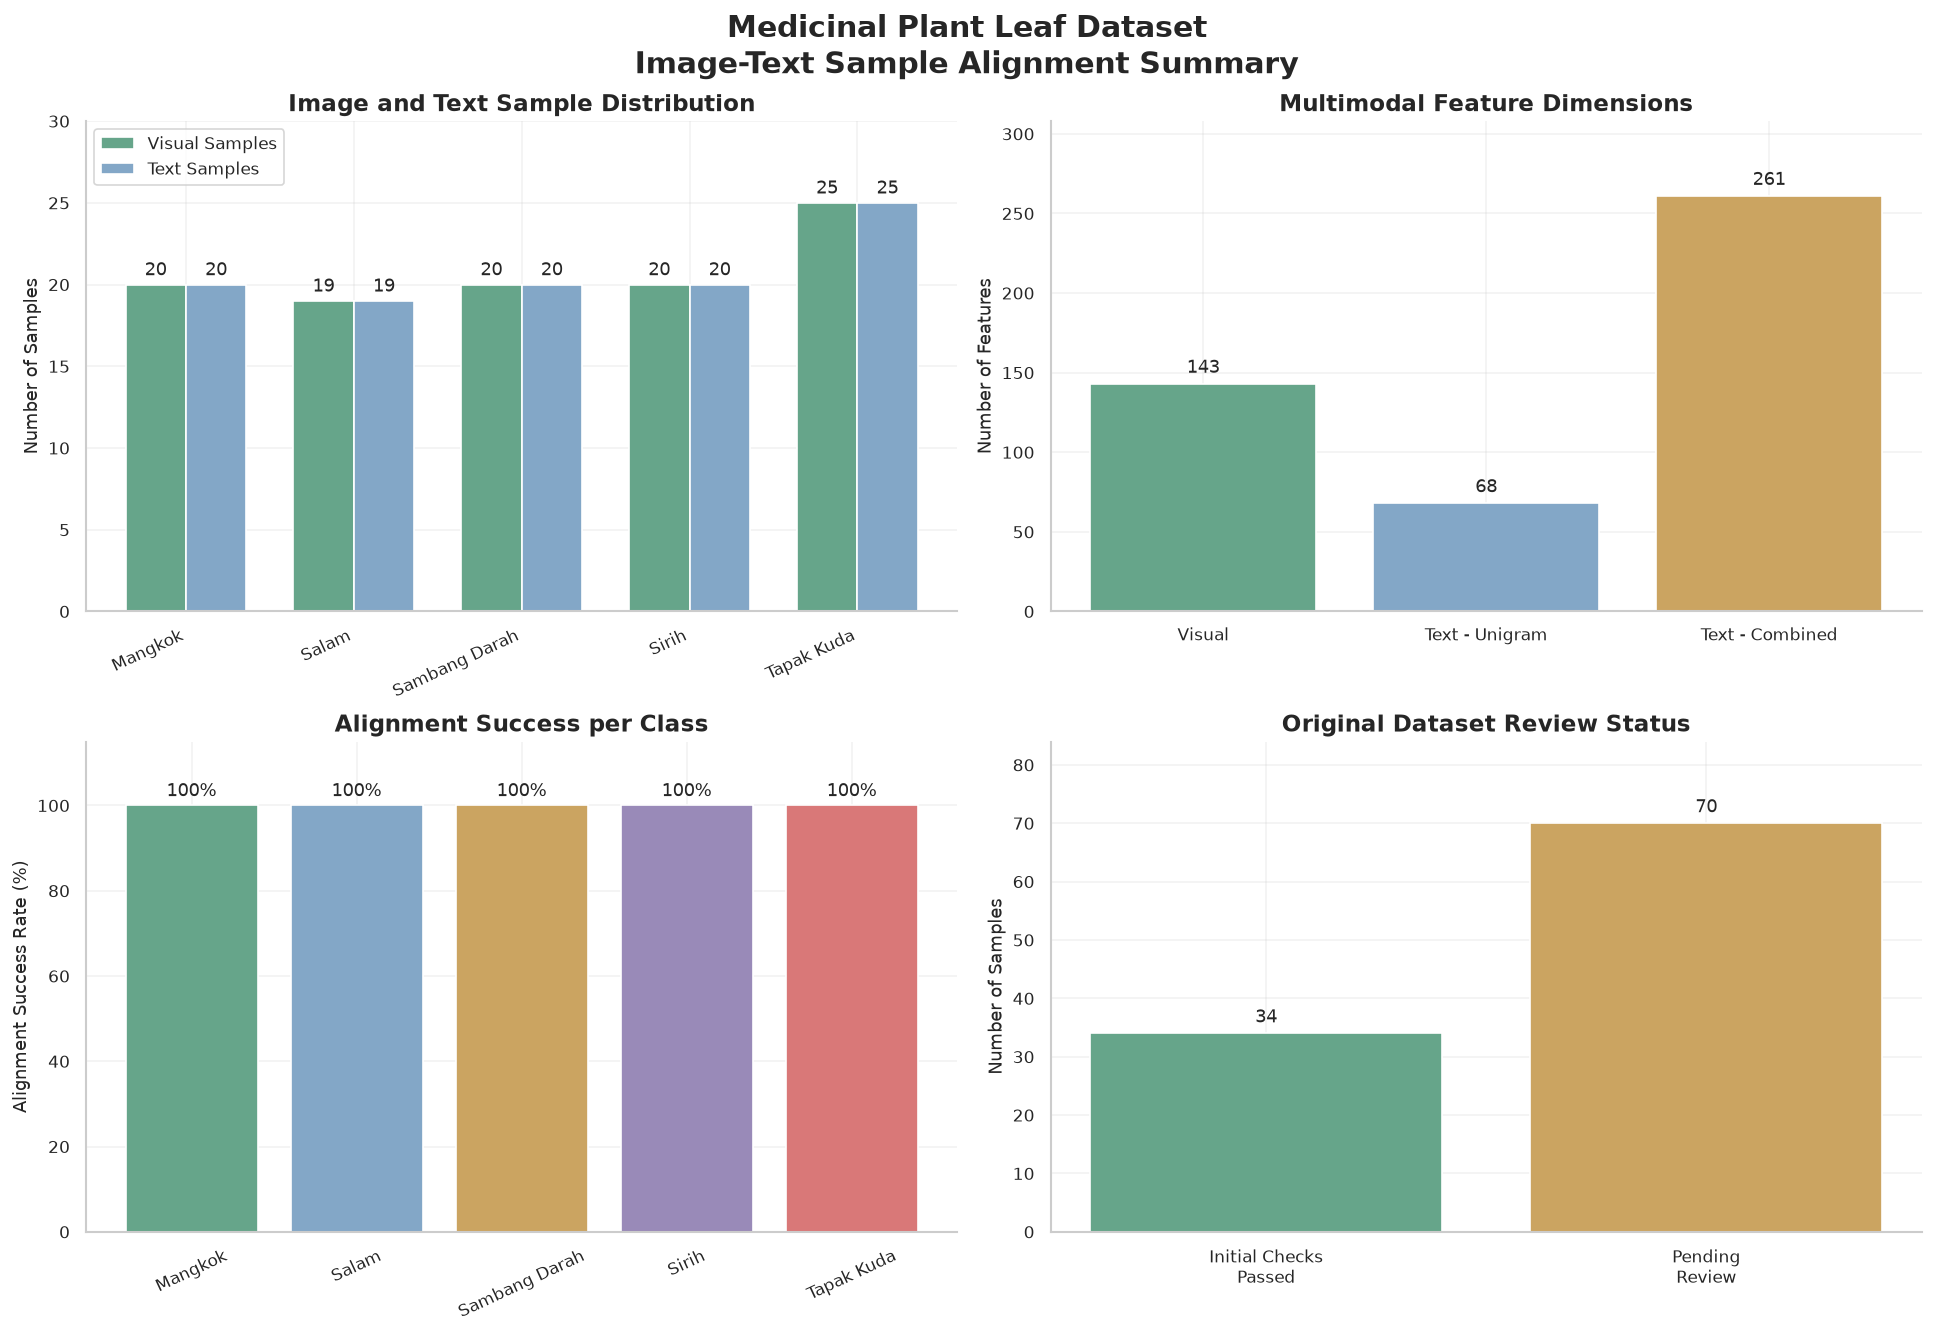

[SAVED] 97_image_text_alignment_summary.png


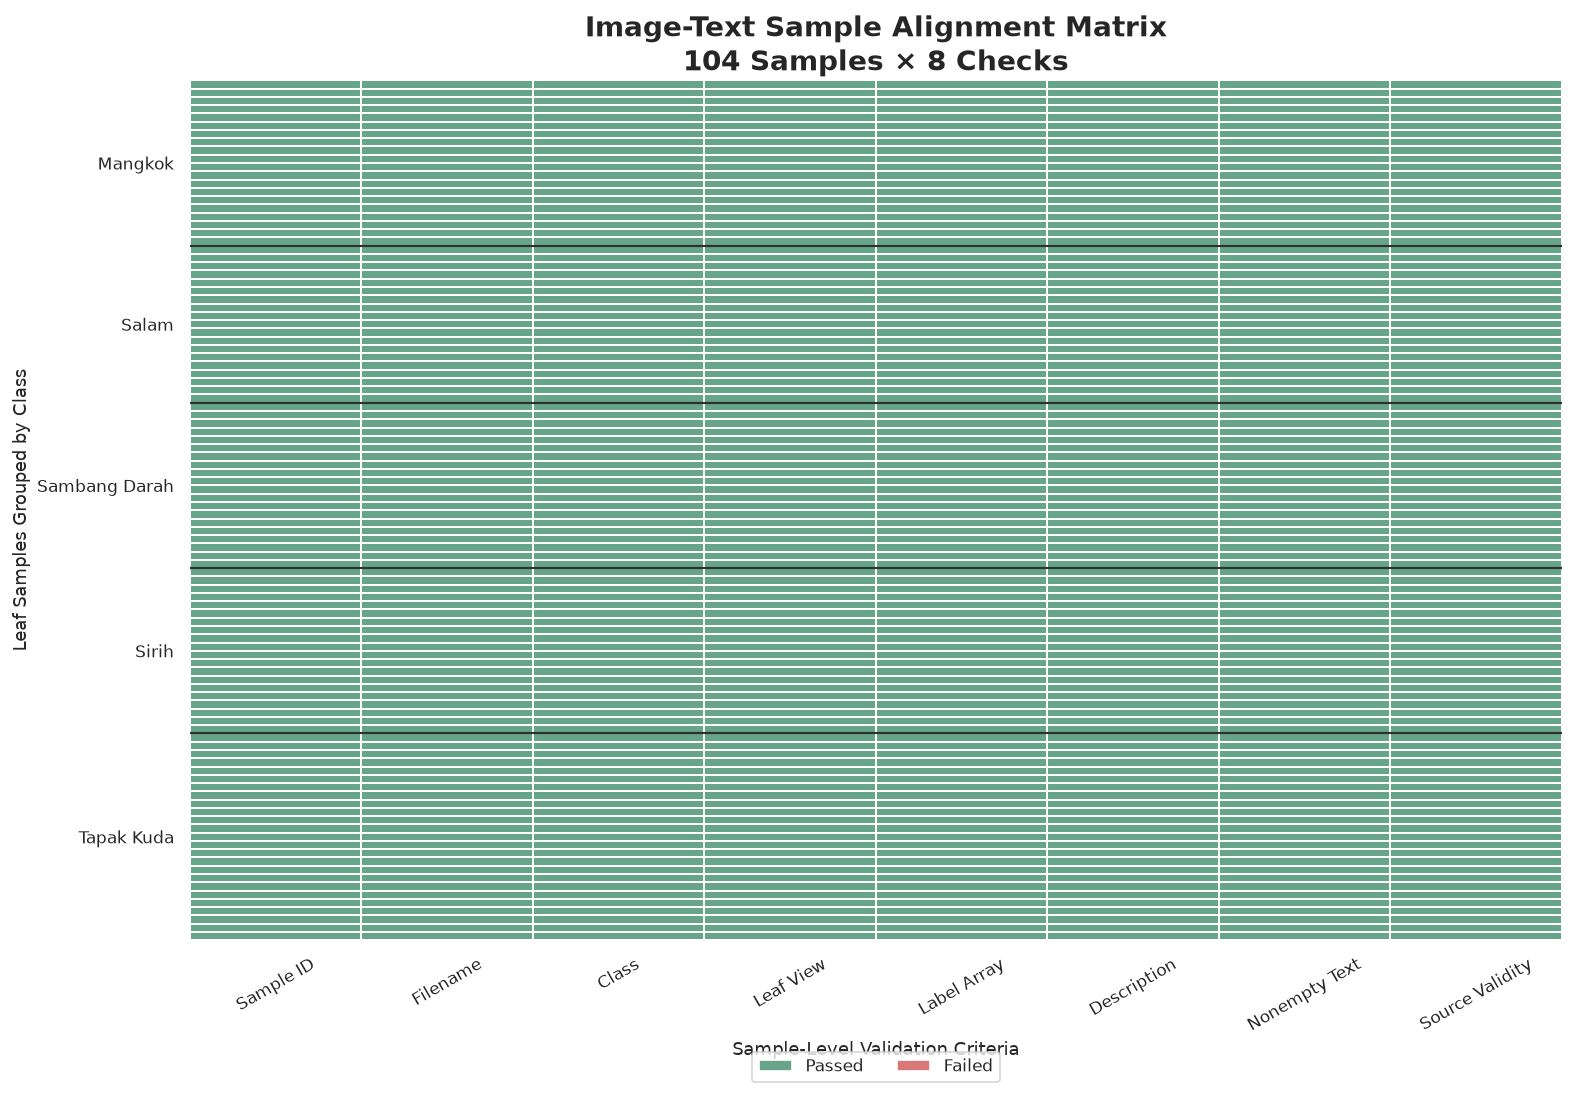

[SAVED] 98_image_text_sample_alignment_matrix.png


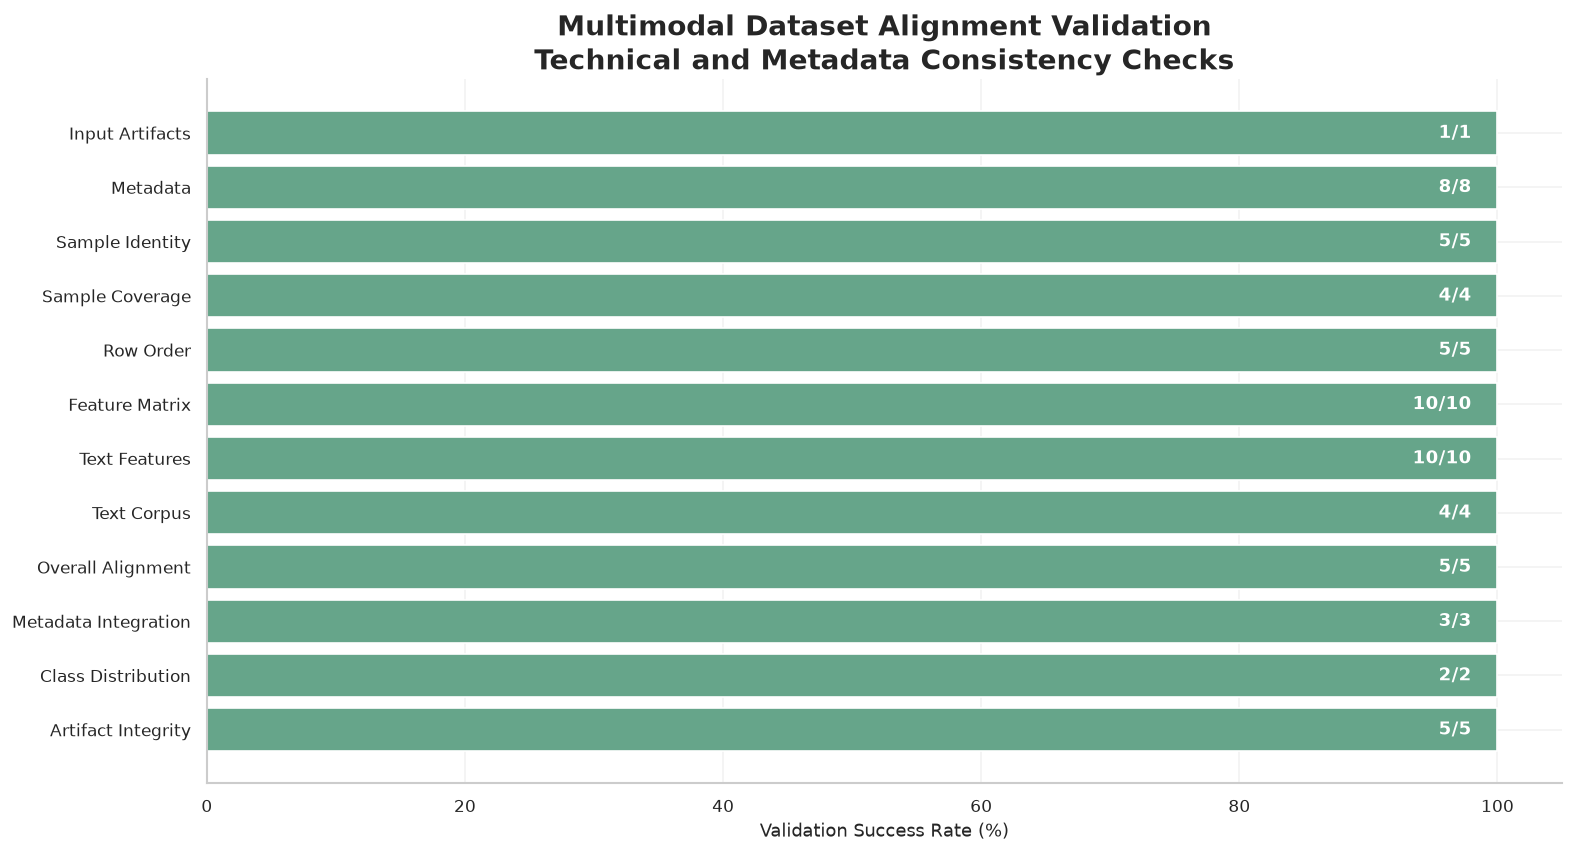

[SAVED] 99_multimodal_alignment_validation.png

14. OVERALL IMAGE-TEXT ALIGNMENT SUMMARY
-----------------------------------------------------------------


,Indicator,Result
0,Total source samples,104
1,Total visual samples,104
2,Total text samples,104
3,Total aligned samples,104
4,Failed alignment samples,0
5,Alignment success rate (%),100.0
6,Total classes,5
7,Visual feature matrix shape,"(104, 143)"
8,Unigram feature matrix shape,"(104, 68)"
9,Combined feature matrix shape,"(104, 261)"



15. SAVING ALIGNMENT REPORTS
-----------------------------------------------------------------
[SAVED] 317_image_text_id_integrity.csv
[SAVED] 318_image_text_missing_samples.csv
[SAVED] 319_image_text_matrix_summary.csv
[SAVED] 320_image_text_sample_alignment.csv
[SAVED] 321_image_text_class_alignment_summary.csv
[SAVED] 322_image_text_alignment_validation.csv
[SAVED] 323_image_text_review_summary.csv
[SAVED] 324_representative_multimodal_pairs.csv
[SAVED] 325_multimodal_aligned_metadata.csv
[SAVED] 326_alignment_validation_category.csv
[SAVED] 327_image_text_alignment_summary.csv

FINAL IMAGE-TEXT SAMPLE ALIGNMENT SUMMARY

DATASET INFORMATION
-----------------------------------------------------------------
Visual samples    : 104
Text samples      : 104
Aligned samples   : 104
Failed samples    : 0
Total classes     : 5

FEATURE MATRIX DIMENSIONS
-----------------------------------------------------------------
Visual features  : (104, 143)
Unigram features : (104, 68)
Combined feat

In [13]:
# ==================================================
# CELL 14 - IMAGE-TEXT SAMPLE ALIGNMENT
# ==================================================

import hashlib
from pathlib import Path
from scipy.sparse import issparse

print("IMAGE-TEXT SAMPLE ALIGNMENT")
print("=" * 65)

IMAGE_TEXT_ALIGNMENT_COMPLETED = False


# ==================================================
# 1. VALIDATE PREVIOUS PROCESSING STAGES
# ==================================================

required_stages = [
    "TFIDF_FEATURE_EXTRACTION_COMPLETED",
    "TFIDF_MATRIX_ANALYSIS_COMPLETED",
    "TEXT_FEATURE_QUALITY_VALIDATION_COMPLETED",
    "COSINE_SIMILARITY_ANALYSIS_COMPLETED",
    "QUERY_TRANSFORMATION_CONSISTENCY_COMPLETED"
]

for stage in required_stages:

    assert globals().get(stage, False), (
        f"{stage} is not completed. "
        "Run the previous cells first."
    )

assert tfidf_quality_validation_df["passed"].all()
assert tfidf_cosine_validation_df["passed"].all()
assert tfidf_query_validation_df["passed"].all()

print("[PASS] All previous processing stages completed.")
print("[PASS] Cell 13 query transformation validated.")


# ==================================================
# 2. ALIGNMENT CONFIGURATION
# ==================================================

ALIGNMENT_SCOPE = "Full-Gallery Multimodal Dataset"

ALIGNMENT_EXPECTED_SAMPLES = 104
ALIGNMENT_EXPECTED_VISUAL_DIM = 143
ALIGNMENT_EXPECTED_UNIGRAM_DIM = 68
ALIGNMENT_EXPECTED_COMBINED_DIM = 261

ALIGNMENT_TOLERANCE = 1e-10

ALIGNMENT_CLASS_COLORS = {
    "Mangkok": "#66A58A",
    "Salam": "#83A7C7",
    "Sambang Darah": "#CBA461",
    "Sirih": "#998AB8",
    "Tapak Kuda": "#D97878"
}

alignment_validation_records = []
alignment_figure_paths = []

print("\n1. ALIGNMENT CONFIGURATION")
print("-" * 65)

print(f"Expected samples        : {ALIGNMENT_EXPECTED_SAMPLES}")
print(f"Visual feature dim      : {ALIGNMENT_EXPECTED_VISUAL_DIM}")
print(f"Unigram feature dim     : {ALIGNMENT_EXPECTED_UNIGRAM_DIM}")
print(f"Combined feature dim    : {ALIGNMENT_EXPECTED_COMBINED_DIM}")
print(f"Alignment scope         : {ALIGNMENT_SCOPE}")


# ==================================================
# 3. VALIDATION HELPER
# ==================================================

def register_alignment_check(
    category,
    check_name,
    passed
):

    alignment_validation_records.append({
        "category": category,
        "validation_check": check_name,
        "passed": bool(passed),
        "status": "Passed" if passed else "Failed"
    })


# ==================================================
# 4. CONFIGURE INPUT ARTIFACT PATHS
# ==================================================

# Reuse the processed metadata path from Cell 13.

alignment_metadata_path = Path(
    query_metadata_path
).resolve()

alignment_project_root = (
    alignment_metadata_path.parents[2]
)

alignment_visual_dir = (
    alignment_project_root
    / "dataset"
    / "features"
    / "visual"
)

alignment_input_paths = {

    "normalized_visual":
        alignment_visual_dir
        / "visual_features_normalized.npy",

    "raw_visual":
        alignment_visual_dir
        / "visual_features_raw.npy",

    "baseline_visual":
        alignment_visual_dir
        / "visual_features_baseline.npy",

    "visual_sample_ids":
        alignment_visual_dir
        / "visual_sample_ids.npy",

    "visual_metadata":
        alignment_visual_dir
        / "visual_feature_metadata.csv",

    "processed_metadata":
        alignment_metadata_path
}

print("\n2. INPUT ARTIFACT VALIDATION")
print("-" * 65)

for name, path in alignment_input_paths.items():

    assert path.is_file(), (
        f"Required artifact not found: {path}"
    )

    assert path.stat().st_size > 0, (
        f"Empty artifact: {path}"
    )

    print(f"[AVAILABLE] {path.name}")

register_alignment_check(
    "Input Artifacts",
    "All required input artifacts available",
    all(
        path.is_file()
        and path.stat().st_size > 0
        for path in alignment_input_paths.values()
    )
)


# ==================================================
# 5. LOAD VISUAL FEATURE ARTIFACTS
# ==================================================

alignment_visual_matrix = np.load(
    alignment_input_paths["normalized_visual"],
    allow_pickle=False
)

alignment_visual_raw_matrix = np.load(
    alignment_input_paths["raw_visual"],
    allow_pickle=False
)

alignment_visual_baseline_matrix = np.load(
    alignment_input_paths["baseline_visual"],
    allow_pickle=False
)

alignment_visual_ids = np.asarray(
    np.load(
        alignment_input_paths["visual_sample_ids"],
        allow_pickle=False
    ),
    dtype=str
)

alignment_visual_metadata_df = pd.read_csv(
    alignment_input_paths["visual_metadata"],
    dtype={"sample_id": str},
    keep_default_na=False
)

print("\n3. VISUAL FEATURE ARTIFACTS")
print("-" * 65)

print(
    "Normalized visual matrix :",
    alignment_visual_matrix.shape
)

print(
    "Raw visual matrix        :",
    alignment_visual_raw_matrix.shape
)

print(
    "Baseline visual matrix   :",
    alignment_visual_baseline_matrix.shape
)

print(
    "Visual sample IDs        :",
    alignment_visual_ids.shape
)

print(
    "Visual metadata          :",
    alignment_visual_metadata_df.shape
)


# ==================================================
# 6. PREPARE TEXT FEATURE ARTIFACTS
# ==================================================

alignment_text_ids = np.asarray(
    tfidf_sample_ids,
    dtype=str
)

alignment_text_labels = np.asarray(
    tfidf_labels,
    dtype=str
)

alignment_unigram_matrix = tfidf_matrices[
    TFIDF_BASELINE_NAME
]

alignment_combined_matrix = tfidf_matrices[
    TFIDF_ALTERNATIVE_NAME
]

alignment_text_metadata_df = (
    df_tfidf_metadata.copy()
    .reset_index(drop=True)
)

alignment_text_metadata_df["sample_id"] = (
    alignment_text_metadata_df[
        "sample_id"
    ].astype(str)
)

print("\n4. TEXT FEATURE ARTIFACTS")
print("-" * 65)

print(
    "Unigram matrix    :",
    alignment_unigram_matrix.shape
)

print(
    "Combined matrix   :",
    alignment_combined_matrix.shape
)

print(
    "Text sample IDs   :",
    alignment_text_ids.shape
)

print(
    "Text metadata     :",
    alignment_text_metadata_df.shape
)


# ==================================================
# 7. LOAD PROCESSED SOURCE METADATA
# ==================================================

alignment_source_metadata_df = pd.read_csv(
    alignment_metadata_path,
    dtype={"sample_id": str},
    keep_default_na=False
)

alignment_identity_columns = [
    "sample_id",
    "nama_file",
    "kelas",
    "tampilan_daun"
]

alignment_required_source_columns = (
    alignment_identity_columns
    + [
        "processed_image_path",
        "mask_path",
        "original_description",
        "cleaned_description",
        "tokenized_description",
        "text_quality_status",
        "tokenization_status",
        "multimodal_valid",
        "final_dataset_status"
    ]
)

for name, dataframe, required_columns in [

    (
        "Visual metadata",
        alignment_visual_metadata_df,
        alignment_identity_columns
    ),

    (
        "Text metadata",
        alignment_text_metadata_df,
        alignment_identity_columns
    ),

    (
        "Processed metadata",
        alignment_source_metadata_df,
        alignment_required_source_columns
    )
]:

    missing_columns = (
        set(required_columns)
        - set(dataframe.columns)
    )

    assert not missing_columns, (
        f"{name} missing columns: "
        f"{sorted(missing_columns)}"
    )

    register_alignment_check(
        "Metadata",
        f"{name} required columns available",
        not missing_columns
    )


# ==================================================
# 8. VALIDATE SAMPLE ID UNIQUENESS
# ==================================================

alignment_id_sources = {

    "Visual feature IDs":
        alignment_visual_ids,

    "Text feature IDs":
        alignment_text_ids,

    "Visual metadata IDs":
        alignment_visual_metadata_df[
            "sample_id"
        ].to_numpy(dtype=str),

    "Text metadata IDs":
        alignment_text_metadata_df[
            "sample_id"
        ].to_numpy(dtype=str),

    "Processed metadata IDs":
        alignment_source_metadata_df[
            "sample_id"
        ].to_numpy(dtype=str)
}

alignment_id_records = []

for source_name, sample_ids in (
    alignment_id_sources.items()
):

    assert sample_ids.ndim == 1

    duplicate_count = int(
        pd.Series(sample_ids).duplicated().sum()
    )

    empty_count = int(
        np.sum(
            np.char.strip(sample_ids) == ""
        )
    )

    invalid_id_count = int(
        np.isin(
            np.char.lower(
                np.char.strip(sample_ids)
            ),
            ["nan", "none", "null"]
        ).sum()
    )

    passed = (
        duplicate_count == 0
        and empty_count == 0
        and invalid_id_count == 0
    )

    alignment_id_records.append({
        "source": source_name,
        "total_ids": len(sample_ids),
        "unique_ids": len(np.unique(sample_ids)),
        "duplicate_ids": duplicate_count,
        "empty_ids": empty_count,
        "invalid_ids": invalid_id_count,
        "passed": passed
    })

    register_alignment_check(
        "Sample Identity",
        f"{source_name} valid and unique",
        passed
    )

alignment_id_integrity_df = pd.DataFrame(
    alignment_id_records
)

print("\n5. SAMPLE ID INTEGRITY")
print("-" * 65)

display(alignment_id_integrity_df)

assert alignment_id_integrity_df["passed"].all(), (
    "Duplicate, empty, or invalid sample IDs detected."
)


# ==================================================
# 9. DETECT MISSING AND EXTRA SAMPLES
# ==================================================

alignment_visual_id_set = set(
    alignment_visual_ids
)

alignment_text_id_set = set(
    alignment_text_ids
)

alignment_source_id_set = set(
    alignment_source_metadata_df["sample_id"]
)

alignment_missing_text_ids = sorted(
    alignment_visual_id_set
    - alignment_text_id_set
)

alignment_missing_visual_ids = sorted(
    alignment_text_id_set
    - alignment_visual_id_set
)

alignment_missing_source_ids = sorted(
    (
        alignment_visual_id_set
        | alignment_text_id_set
    )
    - alignment_source_id_set
)

alignment_unrepresented_source_ids = sorted(
    alignment_source_id_set
    - (
        alignment_visual_id_set
        | alignment_text_id_set
    )
)

alignment_missing_records = []

for issue_type, sample_ids in [

    (
        "Missing Text Sample",
        alignment_missing_text_ids
    ),

    (
        "Missing Visual Sample",
        alignment_missing_visual_ids
    ),

    (
        "Missing Source Metadata",
        alignment_missing_source_ids
    ),

    (
        "Unrepresented Source Sample",
        alignment_unrepresented_source_ids
    )
]:

    register_alignment_check(
        "Sample Coverage",
        f"No {issue_type}",
        len(sample_ids) == 0
    )

    for sample_id in sample_ids:

        alignment_missing_records.append({
            "issue_type": issue_type,
            "sample_id": sample_id
        })

alignment_missing_samples_df = pd.DataFrame(
    alignment_missing_records,
    columns=["issue_type", "sample_id"]
)

print("\n6. MISSING SAMPLE ANALYSIS")
print("-" * 65)

print(
    "Missing text samples   :",
    len(alignment_missing_text_ids)
)

print(
    "Missing visual samples :",
    len(alignment_missing_visual_ids)
)

print(
    "Missing source records :",
    len(alignment_missing_source_ids)
)

print(
    "Unrepresented samples  :",
    len(alignment_unrepresented_source_ids)
)

assert alignment_missing_samples_df.empty, (
    alignment_missing_samples_df.to_string(
        index=False
    )
)


# ==================================================
# 10. VALIDATE EXACT ROW ORDER
# ==================================================

alignment_row_order_checks = {

    "Visual and text feature order identical":

        np.array_equal(
            alignment_visual_ids,
            alignment_text_ids
        ),

    "Saved visual IDs match Cell 4 visual IDs":

        np.array_equal(
            alignment_visual_ids,
            np.asarray(
                loaded_visual_sample_ids,
                dtype=str
            )
        ),

    "Visual metadata order matches visual matrix":

        np.array_equal(
            alignment_visual_metadata_df[
                "sample_id"
            ].to_numpy(dtype=str),
            alignment_visual_ids
        ),

    "Text metadata order matches text matrix":

        np.array_equal(
            alignment_text_metadata_df[
                "sample_id"
            ].to_numpy(dtype=str),
            alignment_text_ids
        ),

    "Text label order matches validated labels":

        np.array_equal(
            alignment_text_labels,
            np.asarray(
                validated_text_labels,
                dtype=str
            )
        )
}

for check_name, passed in (
    alignment_row_order_checks.items()
):

    register_alignment_check(
        "Row Order",
        check_name,
        passed
    )

    print(
        f"[{'PASS' if passed else 'FAIL'}] "
        f"{check_name}"
    )

assert all(
    alignment_row_order_checks.values()
), (
    "Feature row order mismatch detected. "
    "Inspect sample IDs before multimodal fusion."
)

alignment_n_samples = len(
    alignment_visual_ids
)

assert (
    alignment_n_samples
    == ALIGNMENT_EXPECTED_SAMPLES
)

# Deliberately do not reorder feature matrices.
# An unexpected order mismatch must be investigated.


# ==================================================
# 11. VALIDATE FEATURE MATRIX DIMENSIONS
# ==================================================

alignment_feature_matrices = {

    "Visual - Normalized":
        alignment_visual_matrix,

    "Visual - Raw":
        alignment_visual_raw_matrix,

    "Visual - Baseline":
        alignment_visual_baseline_matrix,

    "Text - Unigram":
        alignment_unigram_matrix,

    "Text - Unigram + Bigram":
        alignment_combined_matrix
}

alignment_expected_dimensions = {

    "Visual - Normalized":
        ALIGNMENT_EXPECTED_VISUAL_DIM,

    "Visual - Raw":
        ALIGNMENT_EXPECTED_VISUAL_DIM,

    "Visual - Baseline":
        ALIGNMENT_EXPECTED_VISUAL_DIM,

    "Text - Unigram":
        ALIGNMENT_EXPECTED_UNIGRAM_DIM,

    "Text - Unigram + Bigram":
        ALIGNMENT_EXPECTED_COMBINED_DIM
}

alignment_matrix_records = []

for matrix_name, matrix in (
    alignment_feature_matrices.items()
):

    is_sparse = issparse(matrix)

    values = (
        matrix.data
        if is_sparse
        else matrix
    )

    expected_shape = (
        alignment_n_samples,
        alignment_expected_dimensions[matrix_name]
    )

    correct_shape = (
        matrix.shape == expected_shape
    )

    finite_values = bool(
        np.isfinite(values).all()
    )

    nan_count = int(
        np.isnan(values).sum()
    )

    infinite_count = int(
        np.isinf(values).sum()
    )

    matrix_passed = (
        correct_shape
        and finite_values
    )

    register_alignment_check(
        "Feature Matrix",
        f"{matrix_name} dimensions valid",
        correct_shape
    )

    register_alignment_check(
        "Feature Matrix",
        f"{matrix_name} finite values",
        finite_values
    )

    alignment_matrix_records.append({
        "feature_matrix": matrix_name,
        "number_of_samples": matrix.shape[0],
        "feature_dimension": matrix.shape[1],
        "expected_dimension":
            alignment_expected_dimensions[matrix_name],
        "matrix_format": (
            matrix.format
            if is_sparse
            else "Dense"
        ),
        "nan_values": nan_count,
        "infinite_values": infinite_count,
        "passed": matrix_passed
    })

alignment_matrix_summary_df = pd.DataFrame(
    alignment_matrix_records
)

print("\n7. FEATURE MATRIX VALIDATION")
print("-" * 65)

display(alignment_matrix_summary_df)

assert alignment_matrix_summary_df["passed"].all()


# ==================================================
# 12. VALIDATE TEXT MATRIX PROPERTIES
# ==================================================

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    matrix = tfidf_matrices[
        configuration_name
    ]

    assert issparse(matrix)

    row_norms = np.sqrt(
        np.asarray(
            matrix.multiply(matrix).sum(axis=1)
        ).ravel()
    )

    register_alignment_check(
        "Text Features",
        f"{configuration_name} CSR format",
        matrix.format == "csr"
    )

    register_alignment_check(
        "Text Features",
        f"{configuration_name} nonnegative weights",
        np.all(matrix.data >= 0)
    )

    register_alignment_check(
        "Text Features",
        f"{configuration_name} no zero document vectors",
        np.all(row_norms > 0)
    )

    register_alignment_check(
        "Text Features",
        f"{configuration_name} unit L2 norm",
        np.allclose(
            row_norms,
            1.0,
            atol=ALIGNMENT_TOLERANCE,
            rtol=0
        )
    )

    register_alignment_check(
        "Text Features",
        f"{configuration_name} vocabulary dimension",
        (
            len(
                tfidf_vectorizers[
                    configuration_name
                ].get_feature_names_out()
            )
            == matrix.shape[1]
        )
    )


# ==================================================
# 13. ALIGN SOURCE METADATA BY SAMPLE ID
# ==================================================

# Only metadata is indexed by sample ID.
# The feature matrices remain unchanged.

alignment_source_ordered_df = (
    alignment_source_metadata_df
    .set_index("sample_id")
    .loc[alignment_visual_ids]
    .reset_index()
)

register_alignment_check(
    "Metadata",
    "Source metadata aligned with feature order",
    np.array_equal(
        alignment_source_ordered_df[
            "sample_id"
        ].to_numpy(dtype=str),
        alignment_visual_ids
    )
)


# ==================================================
# 14. VALIDATE METADATA CONSISTENCY
# ==================================================

alignment_record_df = pd.DataFrame({
    "row_index": np.arange(alignment_n_samples),
    "sample_id": alignment_visual_ids,
    "visual_sample_id": alignment_visual_ids,
    "text_sample_id": alignment_text_ids
})

alignment_record_df[
    "sample_id_match"
] = (
    alignment_visual_ids
    == alignment_text_ids
)

for column in [
    "nama_file",
    "kelas",
    "tampilan_daun"
]:

    visual_values = (
        alignment_visual_metadata_df[
            column
        ].astype(str).to_numpy()
    )

    text_values = (
        alignment_text_metadata_df[
            column
        ].astype(str).to_numpy()
    )

    source_values = (
        alignment_source_ordered_df[
            column
        ].astype(str).to_numpy()
    )

    alignment_record_df[
        f"visual_{column}"
    ] = visual_values

    alignment_record_df[
        f"text_{column}"
    ] = text_values

    alignment_record_df[
        f"source_{column}"
    ] = source_values

    alignment_record_df[
        f"{column}_match"
    ] = (
        (visual_values == text_values)
        & (visual_values == source_values)
    )

    register_alignment_check(
        "Metadata",
        f"{column} consistent across all sources",
        alignment_record_df[
            f"{column}_match"
        ].all()
    )

alignment_record_df[
    "label_array_match"
] = (
    alignment_text_labels
    == alignment_source_ordered_df[
        "kelas"
    ].to_numpy(dtype=str)
)

register_alignment_check(
    "Metadata",
    "TF-IDF label array matches source metadata",
    alignment_record_df[
        "label_array_match"
    ].all()
)


# ==================================================
# 15. VALIDATE TEXT CORPUS CONSISTENCY
# ==================================================

alignment_corpus = np.asarray(
    validated_text_corpus,
    dtype=str
)

alignment_source_texts = (
    alignment_source_ordered_df[
        "cleaned_description"
    ].to_numpy(dtype=str)
)

assert len(alignment_corpus) == (
    alignment_n_samples
)

alignment_record_df[
    "description_match"
] = (
    alignment_corpus
    == alignment_source_texts
)

alignment_record_df[
    "description_nonempty"
] = (
    np.char.strip(alignment_corpus)
    != ""
)

register_alignment_check(
    "Text Corpus",
    "Validated corpus matches aligned source descriptions",
    alignment_record_df[
        "description_match"
    ].all()
)

register_alignment_check(
    "Text Corpus",
    "All aligned descriptions nonempty",
    alignment_record_df[
        "description_nonempty"
    ].all()
)

# Reproduce each feature matrix using transform only.

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    vectorizer = tfidf_vectorizers[
        configuration_name
    ]

    original_matrix = tfidf_matrices[
        configuration_name
    ]

    reproduced_matrix = vectorizer.transform(
        alignment_source_texts.tolist()
    ).tocsr()

    difference = (
        reproduced_matrix - original_matrix
    ).tocsr()

    difference.eliminate_zeros()

    maximum_difference = (
        float(np.max(np.abs(difference.data)))
        if difference.nnz > 0
        else 0.0
    )

    register_alignment_check(
        "Text Corpus",
        f"{configuration_name} row features reproduced",
        maximum_difference <= ALIGNMENT_TOLERANCE
    )

    print(
        f"{configuration_name} reproduction difference: "
        f"{maximum_difference:.3e}"
    )


# ==================================================
# 16. VALIDATE SOURCE DATASET READINESS
# ==================================================

alignment_source_valid = (
    alignment_source_ordered_df[
        "multimodal_valid"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("true")
)

alignment_record_df[
    "source_multimodal_valid"
] = alignment_source_valid.to_numpy()

alignment_match_columns = [
    "sample_id_match",
    "nama_file_match",
    "kelas_match",
    "tampilan_daun_match",
    "label_array_match",
    "description_match",
    "description_nonempty",
    "source_multimodal_valid"
]

alignment_record_df[
    "alignment_passed"
] = (
    alignment_record_df[
        alignment_match_columns
    ].all(axis=1)
)

alignment_record_df[
    "alignment_status"
] = np.where(
    alignment_record_df["alignment_passed"],
    "Aligned",
    "Alignment Failed"
)

alignment_record_df[
    "kelas"
] = alignment_source_ordered_df[
    "kelas"
].to_numpy()

register_alignment_check(
    "Overall Alignment",
    "All source samples technically valid",
    alignment_source_valid.all()
)

register_alignment_check(
    "Overall Alignment",
    "All sample-level identity checks passed",
    alignment_record_df[
        "alignment_passed"
    ].all()
)

print("\n8. SAMPLE-LEVEL ALIGNMENT RESULTS")
print("-" * 65)

display(
    alignment_record_df[[
        "row_index",
        "sample_id",
        "kelas",
        "sample_id_match",
        "nama_file_match",
        "kelas_match",
        "tampilan_daun_match",
        "description_match",
        "alignment_status"
    ]].head(10)
)


# ==================================================
# 17. CREATE ALIGNED MULTIMODAL METADATA
# ==================================================

# Preserve source metadata and all original review
# information. No review flags are cleared.

df_multimodal_aligned = (
    alignment_source_ordered_df.copy()
    .reset_index(drop=True)
)

df_multimodal_aligned.insert(
    0,
    "multimodal_row_index",
    np.arange(alignment_n_samples)
)

df_multimodal_aligned[
    "visual_feature_row"
] = np.arange(alignment_n_samples)

df_multimodal_aligned[
    "text_unigram_feature_row"
] = np.arange(alignment_n_samples)

df_multimodal_aligned[
    "text_combined_feature_row"
] = np.arange(alignment_n_samples)

df_multimodal_aligned[
    "image_text_alignment_valid"
] = alignment_record_df[
    "alignment_passed"
].to_numpy()

df_multimodal_aligned[
    "image_text_alignment_status"
] = alignment_record_df[
    "alignment_status"
].to_numpy()

# Preserve original preprocessing readiness.
# This is not the final text-feature review status.

df_multimodal_aligned[
    "source_dataset_status"
] = df_multimodal_aligned[
    "final_dataset_status"
]

if "validation_status" in (
    alignment_visual_metadata_df.columns
):

    df_multimodal_aligned[
        "visual_feature_validation_status"
    ] = alignment_visual_metadata_df[
        "validation_status"
    ].to_numpy()

register_alignment_check(
    "Metadata Integration",
    "Integrated metadata sample IDs unique",
    df_multimodal_aligned[
        "sample_id"
    ].is_unique
)

register_alignment_check(
    "Metadata Integration",
    "Integrated metadata order matches both modalities",
    np.array_equal(
        df_multimodal_aligned[
            "sample_id"
        ].to_numpy(dtype=str),
        alignment_visual_ids
    )
    and np.array_equal(
        df_multimodal_aligned[
            "sample_id"
        ].to_numpy(dtype=str),
        alignment_text_ids
    )
)

# Confirm that every original metadata field
# remains unchanged after alignment.

register_alignment_check(
    "Metadata Integration",
    "Original metadata and review flags preserved",
    df_multimodal_aligned[
        alignment_source_ordered_df.columns
    ].equals(
        alignment_source_ordered_df
    )
)


# ==================================================
# 18. CREATE MAIN MULTIMODAL FEATURE ALIASES
# ==================================================

multimodal_sample_ids = (
    alignment_visual_ids.copy()
)

multimodal_labels = (
    alignment_source_ordered_df[
        "kelas"
    ].to_numpy(dtype=str)
)

multimodal_visual_features = (
    alignment_visual_matrix
)

multimodal_visual_features_raw = (
    alignment_visual_raw_matrix
)

multimodal_visual_features_baseline = (
    alignment_visual_baseline_matrix
)

multimodal_text_features_unigram = (
    alignment_unigram_matrix
)

multimodal_text_features_combined = (
    alignment_combined_matrix
)

multimodal_text_corpus = (
    alignment_corpus.tolist()
)

# Keep each modality separate for score-level fusion.

print("\n9. ALIGNED MULTIMODAL FEATURES")
print("-" * 65)

print(
    "Visual features    :",
    multimodal_visual_features.shape
)

print(
    "Unigram features   :",
    multimodal_text_features_unigram.shape
)

print(
    "Combined features  :",
    multimodal_text_features_combined.shape
)

print(
    "Multimodal samples :",
    len(multimodal_sample_ids)
)


# ==================================================
# 19. ANALYZE ALIGNMENT PER CLASS
# ==================================================

alignment_class_summary_df = (
    alignment_record_df
    .groupby("kelas", sort=True)
    .agg(
        total_samples=(
            "sample_id",
            "count"
        ),
        aligned_samples=(
            "alignment_passed",
            "sum"
        )
    )
    .reset_index()
)

alignment_class_summary_df[
    "failed_samples"
] = (
    alignment_class_summary_df["total_samples"]
    - alignment_class_summary_df["aligned_samples"]
)

alignment_class_summary_df[
    "alignment_success_percent"
] = (
    alignment_class_summary_df["aligned_samples"]
    / alignment_class_summary_df["total_samples"]
    * 100
)

alignment_total_passed = int(
    alignment_record_df[
        "alignment_passed"
    ].sum()
)

alignment_total_failed = (
    alignment_n_samples
    - alignment_total_passed
)

print("\n10. CLASS-LEVEL ALIGNMENT SUMMARY")
print("-" * 65)

display(
    alignment_class_summary_df.round(4)
)

register_alignment_check(
    "Class Distribution",
    "Class-level counts reconcile",
    alignment_class_summary_df[
        "total_samples"
    ].sum()
    == alignment_n_samples
)

register_alignment_check(
    "Class Distribution",
    "All classes have complete alignment",
    alignment_class_summary_df[
        "failed_samples"
    ].eq(0).all()
)


# ==================================================
# 20. ANALYZE ORIGINAL DATASET REVIEW STATUS
# ==================================================

alignment_review_summary_df = (
    df_multimodal_aligned[
        "source_dataset_status"
    ]
    .value_counts()
    .rename_axis("source_dataset_status")
    .reset_index(name="number_of_samples")
)

alignment_review_summary_df[
    "percentage"
] = (
    alignment_review_summary_df[
        "number_of_samples"
    ]
    / alignment_n_samples
    * 100
)

alignment_pending_review_count = int(
    df_multimodal_aligned[
        "source_dataset_status"
    ].eq(
        "Ready - Pending Review"
    ).sum()
)

alignment_initial_pass_count = int(
    df_multimodal_aligned[
        "source_dataset_status"
    ].eq(
        "Ready - Initial Checks Passed"
    ).sum()
)

print("\n11. ORIGINAL DATASET REVIEW STATUS")
print("-" * 65)

display(
    alignment_review_summary_df.round(4)
)

print(
    "[INFO] Alignment success does not clear "
    "manual review requirements."
)

print(
    "[INFO] Text-feature quality diagnostics "
    "from Cell 11 remain applicable."
)


# ==================================================
# 21. SELECT REPRESENTATIVE MULTIMODAL PAIRS
# ==================================================

representative_multimodal_columns = [
    "multimodal_row_index",
    "sample_id",
    "nama_file",
    "kelas",
    "tampilan_daun",
    "processed_image_path",
    "cleaned_description",
    "visual_feature_row",
    "text_unigram_feature_row",
    "text_combined_feature_row",
    "image_text_alignment_status"
]

alignment_representative_pairs_df = (
    df_multimodal_aligned
    .groupby("kelas", sort=True)
    .head(1)[representative_multimodal_columns]
    .reset_index(drop=True)
)

print("\n12. REPRESENTATIVE MULTIMODAL PAIRS")
print("-" * 65)

display(
    alignment_representative_pairs_df
)


# ==================================================
# 22. OPTIONAL SAVED VISUAL CHECKSUM VERIFICATION
# ==================================================

# Verify against the manifest report from Notebook 03
# when the report is available in the metrics directory.

alignment_manifest_path = (
    Path(METRICS_DIR)
    / "174_visual_feature_artifact_manifest.csv"
)

alignment_checksum_verified = False

if alignment_manifest_path.is_file():

    alignment_manifest_df = pd.read_csv(
        alignment_manifest_path
    )

    assert alignment_manifest_df[
        "filename"
    ].is_unique

    alignment_manifest_df = (
        alignment_manifest_df
        .set_index("filename")
    )

    for name in [
        "normalized_visual",
        "raw_visual",
        "baseline_visual",
        "visual_sample_ids",
        "visual_metadata"
    ]:

        file_path = alignment_input_paths[name]

        actual_sha256 = hashlib.sha256(
            file_path.read_bytes()
        ).hexdigest()

        expected_sha256 = str(
            alignment_manifest_df.loc[
                file_path.name,
                "sha256"
            ]
        )

        register_alignment_check(
            "Artifact Integrity",
            f"{file_path.name} checksum matches manifest",
            actual_sha256 == expected_sha256
        )

    alignment_checksum_verified = all(
        record["passed"]
        for record in alignment_validation_records
        if record["category"] == "Artifact Integrity"
    )

    print(
        "[INFO] Saved visual artifact checksums checked."
    )

else:

    print(
        "[INFO] Visual manifest CSV unavailable. "
        "Additional checksum check skipped."
    )


# ==================================================
# 23. FINAL ALIGNMENT VALIDATION
# ==================================================

register_alignment_check(
    "Overall Alignment",
    "Expected total sample count",
    alignment_n_samples
    == ALIGNMENT_EXPECTED_SAMPLES
)

register_alignment_check(
    "Overall Alignment",
    "No samples failed alignment",
    alignment_total_failed == 0
)

register_alignment_check(
    "Overall Alignment",
    "All modality row counts identical",
    all(
        matrix.shape[0] == alignment_n_samples
        for matrix in alignment_feature_matrices.values()
    )
)

alignment_validation_df = pd.DataFrame(
    alignment_validation_records
)

alignment_total_checks = len(
    alignment_validation_df
)

alignment_passed_checks = int(
    alignment_validation_df["passed"].sum()
)

print("\n13. OVERALL ALIGNMENT VALIDATION")
print("-" * 65)

display(alignment_validation_df)

# Save diagnostic results even when validation fails.

alignment_validation_df.to_csv(
    Path(METRICS_DIR)
    / "322_image_text_alignment_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

assert alignment_validation_df["passed"].all(), (
    alignment_validation_df.loc[
        ~alignment_validation_df["passed"]
    ].to_string(index=False)
)

print("[PASS] All image-text alignment checks passed.")


# ==================================================
# 24. VISUALIZATION HELPER
# ==================================================

def save_alignment_figure(fig, filename):

    output_path = (
        Path(TEXT_FEATURE_FIGURES_DIR)
        / filename
    )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    alignment_figure_paths.append(
        output_path
    )

    plt.show()
    plt.close(fig)

    print(f"[SAVED] {filename}")


# ==================================================
# 25. VISUALIZE MULTIMODAL ALIGNMENT SUMMARY
# ==================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 11),
    constrained_layout=True
)

class_names = (
    alignment_class_summary_df[
        "kelas"
    ].tolist()
)

class_counts = (
    alignment_class_summary_df[
        "total_samples"
    ].to_numpy()
)

class_colors = [
    ALIGNMENT_CLASS_COLORS.get(
        name, "#83A7C7"
    )
    for name in class_names
]


# A. Sample distribution per modality.

ax = axes[0, 0]

positions = np.arange(len(class_names))

bars_visual = ax.bar(
    positions - 0.18,
    class_counts,
    width=0.36,
    color="#66A58A",
    label="Visual Samples"
)

text_class_counts = [
    np.sum(alignment_text_labels == name)
    for name in class_names
]

bars_text = ax.bar(
    positions + 0.18,
    text_class_counts,
    width=0.36,
    color="#83A7C7",
    label="Text Samples"
)

ax.bar_label(
    bars_visual,
    padding=3
)

ax.bar_label(
    bars_text,
    padding=3
)

ax.set_xticks(positions)

ax.set_xticklabels(
    class_names,
    rotation=25,
    ha="right"
)

ax.set_ylabel("Number of Samples")
ax.set_title("Image and Text Sample Distribution")
ax.margins(y=0.2)
ax.legend()


# B. Feature dimensions.

ax = axes[0, 1]

dimension_labels = [
    "Visual",
    "Text - Unigram",
    "Text - Combined"
]

dimension_values = [
    multimodal_visual_features.shape[1],
    multimodal_text_features_unigram.shape[1],
    multimodal_text_features_combined.shape[1]
]

bars = ax.bar(
    dimension_labels,
    dimension_values,
    color=[
        "#66A58A",
        "#83A7C7",
        "#CBA461"
    ]
)

ax.bar_label(
    bars,
    padding=4
)

ax.set_ylabel("Number of Features")
ax.set_title("Multimodal Feature Dimensions")
ax.margins(y=0.18)


# C. Class-level alignment success.

ax = axes[1, 0]

bars = ax.bar(
    class_names,
    alignment_class_summary_df[
        "alignment_success_percent"
    ],
    color=class_colors
)

ax.bar_label(
    bars,
    fmt="%.0f%%",
    padding=3
)

ax.set_ylim(0, 115)
ax.set_ylabel("Alignment Success Rate (%)")
ax.set_title("Alignment Success per Class")

ax.tick_params(
    axis="x",
    labelrotation=25
)


# D. Original dataset review status.

ax = axes[1, 1]

review_labels = [
    "Initial Checks\nPassed",
    "Pending\nReview"
]

review_values = [
    alignment_initial_pass_count,
    alignment_pending_review_count
]

bars = ax.bar(
    review_labels,
    review_values,
    color=[
        "#66A58A",
        "#CBA461"
    ]
)

ax.bar_label(
    bars,
    padding=4
)

ax.set_ylabel("Number of Samples")
ax.set_title("Original Dataset Review Status")
ax.margins(y=0.2)

fig.suptitle(
    "Medicinal Plant Leaf Dataset\n"
    "Image-Text Sample Alignment Summary",
    fontsize=18,
    fontweight="bold"
)

save_alignment_figure(
    fig,
    "97_image_text_alignment_summary.png"
)


# ==================================================
# 26. VISUALIZE SAMPLE-LEVEL ALIGNMENT MATRIX
# ==================================================

alignment_plot_order = np.argsort(
    multimodal_labels,
    kind="stable"
)

alignment_plot_labels = multimodal_labels[
    alignment_plot_order
]

alignment_plot_matrix = (
    alignment_record_df[
        alignment_match_columns
    ]
    .to_numpy(dtype=int)
    [alignment_plot_order]
)

alignment_boundaries = np.flatnonzero(
    alignment_plot_labels[1:]
    != alignment_plot_labels[:-1]
) + 1

alignment_starts = np.r_[
    0,
    alignment_boundaries
]

alignment_ends = np.r_[
    alignment_boundaries,
    alignment_n_samples
]

alignment_centers = (
    alignment_starts
    + alignment_ends
) / 2

from matplotlib.colors import ListedColormap

fig, ax = plt.subplots(
    figsize=(13, 9),
    constrained_layout=True
)

sns.heatmap(
    alignment_plot_matrix,
    cmap=ListedColormap([
        "#D97878",
        "#66A58A"
    ]),
    vmin=0,
    vmax=1,
    xticklabels=[
        "Sample ID",
        "Filename",
        "Class",
        "Leaf View",
        "Label Array",
        "Description",
        "Nonempty Text",
        "Source Validity"
    ],
    yticklabels=False,
    linewidths=0.2,
    linecolor="white",
    cbar=False,
    ax=ax
)

for boundary in alignment_boundaries:

    ax.axhline(
        boundary,
        color="#303030",
        linewidth=1.3
    )

ax.set_yticks(
    alignment_centers
)

ax.set_yticklabels(
    alignment_plot_labels[
        alignment_starts
    ],
    rotation=0
)

ax.tick_params(
    axis="x",
    labelrotation=30
)

ax.set_ylabel(
    "Leaf Samples Grouped by Class"
)

ax.set_xlabel(
    "Sample-Level Validation Criteria"
)

ax.set_title(
    "Image-Text Sample Alignment Matrix\n"
    f"{alignment_n_samples} Samples × "
    f"{len(alignment_match_columns)} Checks",
    fontsize=17,
    fontweight="bold"
)

from matplotlib.patches import Patch

ax.legend(
    handles=[
        Patch(
            facecolor="#66A58A",
            label="Passed"
        ),
        Patch(
            facecolor="#D97878",
            label="Failed"
        )
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2
)

save_alignment_figure(
    fig,
    "98_image_text_sample_alignment_matrix.png"
)


# ==================================================
# 27. VISUALIZE VALIDATION SUCCESS BY CATEGORY
# ==================================================

alignment_validation_category_df = (
    alignment_validation_df
    .groupby("category", sort=False)
    .agg(
        total_checks=(
            "validation_check",
            "count"
        ),
        passed_checks=(
            "passed",
            "sum"
        )
    )
    .reset_index()
)

alignment_validation_category_df[
    "success_rate_percent"
] = (
    alignment_validation_category_df[
        "passed_checks"
    ]
    / alignment_validation_category_df[
        "total_checks"
    ]
    * 100
)

fig, ax = plt.subplots(
    figsize=(13, 7),
    constrained_layout=True
)

bars = ax.barh(
    alignment_validation_category_df[
        "category"
    ],
    alignment_validation_category_df[
        "success_rate_percent"
    ],
    color="#66A58A"
)

for bar, row in zip(
    bars,
    alignment_validation_category_df.itertuples()
):

    ax.text(
        bar.get_width() - 2,
        bar.get_y() + bar.get_height() / 2,
        f"{row.passed_checks}/{row.total_checks}",
        va="center",
        ha="right",
        color="white",
        fontweight="bold",
        fontsize=11
    )

ax.set_xlim(0, 105)
ax.invert_yaxis()

ax.set_xlabel(
    "Validation Success Rate (%)"
)

ax.set_title(
    "Multimodal Dataset Alignment Validation\n"
    "Technical and Metadata Consistency Checks",
    fontsize=17,
    fontweight="bold"
)

save_alignment_figure(
    fig,
    "99_multimodal_alignment_validation.png"
)


# ==================================================
# 28. CREATE FINAL ALIGNMENT SUMMARY
# ==================================================

alignment_summary_df = pd.DataFrame([

    ("Total source samples",
     len(alignment_source_metadata_df)),

    ("Total visual samples",
     len(alignment_visual_ids)),

    ("Total text samples",
     len(alignment_text_ids)),

    ("Total aligned samples",
     alignment_total_passed),

    ("Failed alignment samples",
     alignment_total_failed),

    ("Alignment success rate (%)",
     alignment_total_passed
     / alignment_n_samples * 100),

    ("Total classes",
     len(np.unique(multimodal_labels))),

    ("Visual feature matrix shape",
     str(multimodal_visual_features.shape)),

    ("Unigram feature matrix shape",
     str(multimodal_text_features_unigram.shape)),

    ("Combined feature matrix shape",
     str(multimodal_text_features_combined.shape)),

    ("Missing visual samples",
     len(alignment_missing_visual_ids)),

    ("Missing text samples",
     len(alignment_missing_text_ids)),

    ("Missing source records",
     len(alignment_missing_source_ids)),

    ("Duplicate visual IDs",
     len(alignment_visual_ids)
     - len(np.unique(alignment_visual_ids))),

    ("Duplicate text IDs",
     len(alignment_text_ids)
     - len(np.unique(alignment_text_ids))),

    ("Exact row order preserved", True),

    ("Class labels consistent",
     alignment_record_df["kelas_match"].all()),

    ("Filenames consistent",
     alignment_record_df["nama_file_match"].all()),

    ("Leaf views consistent",
     alignment_record_df["tampilan_daun_match"].all()),

    ("Descriptions consistent",
     alignment_record_df["description_match"].all()),

    ("Source initial checks passed",
     alignment_initial_pass_count),

    ("Source pending review",
     alignment_pending_review_count),

    ("Additional visual checksum verified",
     alignment_checksum_verified),

    ("Total validation checks",
     alignment_total_checks),

    ("Validation checks passed",
     alignment_passed_checks),

    ("Validation checks failed",
     alignment_total_checks
     - alignment_passed_checks),

    ("Generated figures",
     len(alignment_figure_paths)),

    ("Samples removed", 0),

    ("Feature matrices reordered", False),

    ("Feature selection applied", False),

    ("Vectorizers refitted", False),

    ("Visual features renormalized", False),

    ("Raw visual features retained", True),

    ("Review flags preserved", True),

    ("Final text configuration selected", False),

    ("Multimodal feature concatenation applied", False),

    ("Multimodal score fusion completed", False),

    ("Independent retrieval evaluation completed", False),

    ("Alignment scope", ALIGNMENT_SCOPE),

    ("Image-text sample alignment completed", True)

], columns=["Indicator", "Result"])

print("\n14. OVERALL IMAGE-TEXT ALIGNMENT SUMMARY")
print("-" * 65)

display(alignment_summary_df)


# ==================================================
# 29. SAVE ALIGNMENT REPORTS
# ==================================================

alignment_reports = {

    "317_image_text_id_integrity.csv":
        alignment_id_integrity_df,

    "318_image_text_missing_samples.csv":
        alignment_missing_samples_df,

    "319_image_text_matrix_summary.csv":
        alignment_matrix_summary_df,

    "320_image_text_sample_alignment.csv":
        alignment_record_df,

    "321_image_text_class_alignment_summary.csv":
        alignment_class_summary_df,

    "322_image_text_alignment_validation.csv":
        alignment_validation_df,

    "323_image_text_review_summary.csv":
        alignment_review_summary_df,

    "324_representative_multimodal_pairs.csv":
        alignment_representative_pairs_df,

    "325_multimodal_aligned_metadata.csv":
        df_multimodal_aligned,

    "326_alignment_validation_category.csv":
        alignment_validation_category_df,

    "327_image_text_alignment_summary.csv":
        alignment_summary_df
}

print("\n15. SAVING ALIGNMENT REPORTS")
print("-" * 65)

for filename, dataframe in (
    alignment_reports.items()
):

    dataframe.to_csv(
        Path(METRICS_DIR) / filename,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ==================================================
# 30. FINAL COMPLETION CHECKS
# ==================================================

assert alignment_validation_df["passed"].all()

assert alignment_total_passed == alignment_n_samples

assert alignment_total_failed == 0

assert len(df_multimodal_aligned) == (
    alignment_n_samples
)

assert np.array_equal(
    multimodal_sample_ids,
    alignment_text_ids
)

assert len(alignment_figure_paths) == 3

assert all(
    path.is_file()
    and path.stat().st_size > 0
    for path in alignment_figure_paths
)

assert all(
    (
        Path(METRICS_DIR) / filename
    ).is_file()

    and (
        Path(METRICS_DIR) / filename
    ).stat().st_size > 0

    for filename in alignment_reports
)

IMAGE_TEXT_ALIGNMENT_COMPLETED = True


# ==================================================
# 31. FINAL SUMMARY
# ==================================================

print("\n" + "=" * 65)

print("FINAL IMAGE-TEXT SAMPLE ALIGNMENT SUMMARY")

print("=" * 65)

print("\nDATASET INFORMATION")
print("-" * 65)

print(
    f"Visual samples    : "
    f"{len(alignment_visual_ids)}"
)

print(
    f"Text samples      : "
    f"{len(alignment_text_ids)}"
)

print(
    f"Aligned samples   : "
    f"{alignment_total_passed}"
)

print(
    f"Failed samples    : "
    f"{alignment_total_failed}"
)

print(
    f"Total classes     : "
    f"{len(np.unique(multimodal_labels))}"
)

print("\nFEATURE MATRIX DIMENSIONS")
print("-" * 65)

print(
    "Visual features  :",
    multimodal_visual_features.shape
)

print(
    "Unigram features :",
    multimodal_text_features_unigram.shape
)

print(
    "Combined features:",
    multimodal_text_features_combined.shape
)

print("\nORIGINAL DATASET REVIEW STATUS")
print("-" * 65)

print(
    f"Initial checks passed : "
    f"{alignment_initial_pass_count}"
)

print(
    f"Pending review        : "
    f"{alignment_pending_review_count}"
)

print("\nVALIDATION RESULTS")
print("-" * 65)

print(
    f"Technical checks  : "
    f"{alignment_passed_checks}/{alignment_total_checks}"
)

print(
    f"Generated reports : "
    f"{len(alignment_reports)}"
)

print(
    f"Generated figures : "
    f"{len(alignment_figure_paths)}"
)

print("\n[PASS] Visual and text sample IDs aligned.")

print("[PASS] Exact feature row order preserved.")

print("[PASS] All feature dimensions validated.")

print("[PASS] Class label consistency validated.")

print("[PASS] Filename consistency validated.")

print("[PASS] Leaf view consistency validated.")

print("[PASS] Text corpus consistency validated.")

print("[PASS] Multimodal metadata constructed.")

print("[PASS] Original review flags preserved.")

print("[PASS] Raw visual features preserved.")

print("[PASS] All alignment reports saved.")

print("\n[INFO] No samples were removed.")

print("[INFO] No vectorizers were refitted.")

print("[INFO] No feature matrices were reordered.")

print("[INFO] Modalities remain separate.")

print("[INFO] Manual data-quality review remains pending.")

print("[INFO] Multimodal fusion has not been performed.")

print("\nImage-text sample alignment completed successfully!")

print("\nNext cell: Cell 15 - Save Text Features")

SAVE TEXT FEATURES
[PASS] Previous processing stages validated.
[PASS] Image-text alignment validated.

1. SAVING CONFIGURATION
-----------------------------------------------------------------
Output directory : D:\Project\Multimodal_Leaf_Retrieval\dataset\features\text
Total samples    : 104
Saving scope     : Full Dataset - Gallery Development
Schema version   : 1.0.0

2. SHARED ARTIFACTS PREPARED
-----------------------------------------------------------------
Sample IDs : (104,)
Labels     : (104,)
Corpus     : 104
Metadata   : (104, 52)

3. SAVING TF-IDF CONFIGURATIONS
-----------------------------------------------------------------

Configuration: Unigram
[SAVED] tfidf_unigram_features.npz
[SAVED] tfidf_unigram_vectorizer.joblib
[SAVED] tfidf_unigram_feature_names.npy
[SAVED] tfidf_unigram_idf_weights.npy
[SAVED] tfidf_unigram_vocabulary.csv

Configuration: Unigram + Bigram
[SAVED] tfidf_unigram_bigram_features.npz
[SAVED] tfidf_unigram_bigram_vectorizer.joblib
[SAVED] tfidf_u

C:\Users\ronn7\AppData\Local\Temp\ipykernel_21656\699826651.py:797: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  loaded_vocabulary_df = pd.read_csv(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_21656\699826651.py:797: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  loaded_vocabulary_df = pd.read_csv(


,configuration,number_of_samples,feature_dimension,nonzero_values,matrix_difference,reference_reproduction_difference,cosine_similarity_difference,vocabulary_size,matrix_file_size_kib,vectorizer_file_size_kib
0,Unigram,104,68,2086,0.0,1.665335e-16,4.440892e-16,68,10.820312,1.419922
1,Unigram + Bigram,104,261,4166,0.0,1.110223e-16,6.661338e-16,261,17.756836,3.093750



6. RELOADED QUERY TRANSFORMATION VALIDATION
-----------------------------------------------------------------


,configuration,query_id,query_type,query_status,usable_for_matching,maximum_vector_difference,maximum_cosine_difference,passed
0,Unigram,Q01,Morphology Query,Valid,True,0.0,0.0,True
1,Unigram,Q02,Morphology Query,Valid,True,0.0,0.0,True
2,Unigram,Q03,Morphology Query,Valid,True,0.0,0.0,True
3,Unigram,Q04,Morphology Query,Valid,True,0.0,0.0,True
4,Unigram,Q05,Morphology Query,Valid,True,0.0,0.0,True
5,Unigram,Q06,Case and Punctuation Variation,Valid,True,0.0,0.0,True
6,Unigram,Q07,Single Known Token,Valid,True,0.0,0.0,True
7,Unigram,Q08,Partial OOV,Valid - Partial OOV,True,0.0,0.0,True
8,Unigram,Q09,All OOV,All OOV,False,0.0,NaN,True
9,Unigram,Q10,Empty String,Empty Query,False,NaN,NaN,True



7. ARTIFACT CHECKSUM VALIDATION
-----------------------------------------------------------------
[SAVED] text_feature_artifact_manifest.csv


,filename,category,configuration,size_kib
0,tfidf_unigram_features.npz,Sparse Feature Matrix,Unigram,10.8203
1,tfidf_unigram_vectorizer.joblib,TF-IDF Vectorizer,Unigram,1.4199
2,tfidf_unigram_feature_names.npy,Feature Names,Unigram,3.3125
3,tfidf_unigram_idf_weights.npy,IDF Weights,Unigram,0.6562
4,tfidf_unigram_vocabulary.csv,Vocabulary Report,Unigram,2.6338
5,tfidf_unigram_bigram_features.npz,Sparse Feature Matrix,Unigram + Bigram,17.7568
6,tfidf_unigram_bigram_vectorizer.joblib,TF-IDF Vectorizer,Unigram + Bigram,3.0938
7,tfidf_unigram_bigram_feature_names.npy,Feature Names,Unigram + Bigram,20.5156
8,tfidf_unigram_bigram_idf_weights.npy,IDF Weights,Unigram + Bigram,2.1641
9,tfidf_unigram_bigram_vocabulary.csv,Vocabulary Report,Unigram + Bigram,11.5498



8. SAVE-LOAD VALIDATION RESULTS
-----------------------------------------------------------------


,category,validation_check,passed,status
0,Input Alignment,Input sample IDs and labels aligned,True,Passed
1,Input Alignment,Input corpus and metadata aligned,True,Passed
2,Unigram,Saved matrix dimensions preserved,True,Passed
3,Unigram,Sparse CSR format preserved,True,Passed
4,Unigram,Matrix dtype preserved,True,Passed
...,...,...,...,...
103,Artifact Integrity,text_feature_extraction_config.json integrity verified,True,Passed
104,Artifact Integrity,Manifest contains all expected payload artifacts,True,Passed
105,Artifact Integrity,Manifest filenames preserved,True,Passed
106,Artifact Integrity,Manifest checksums preserved,True,Passed


[PASS] All save-load checks passed.

9. ARTIFACT STORAGE SUMMARY
-----------------------------------------------------------------


,configuration,number_of_artifacts,total_size_bytes,total_size_kib
0,Unigram,5,19295,18.8428
1,Unigram + Bigram,5,56402,55.0801
2,Shared,6,199806,195.1230


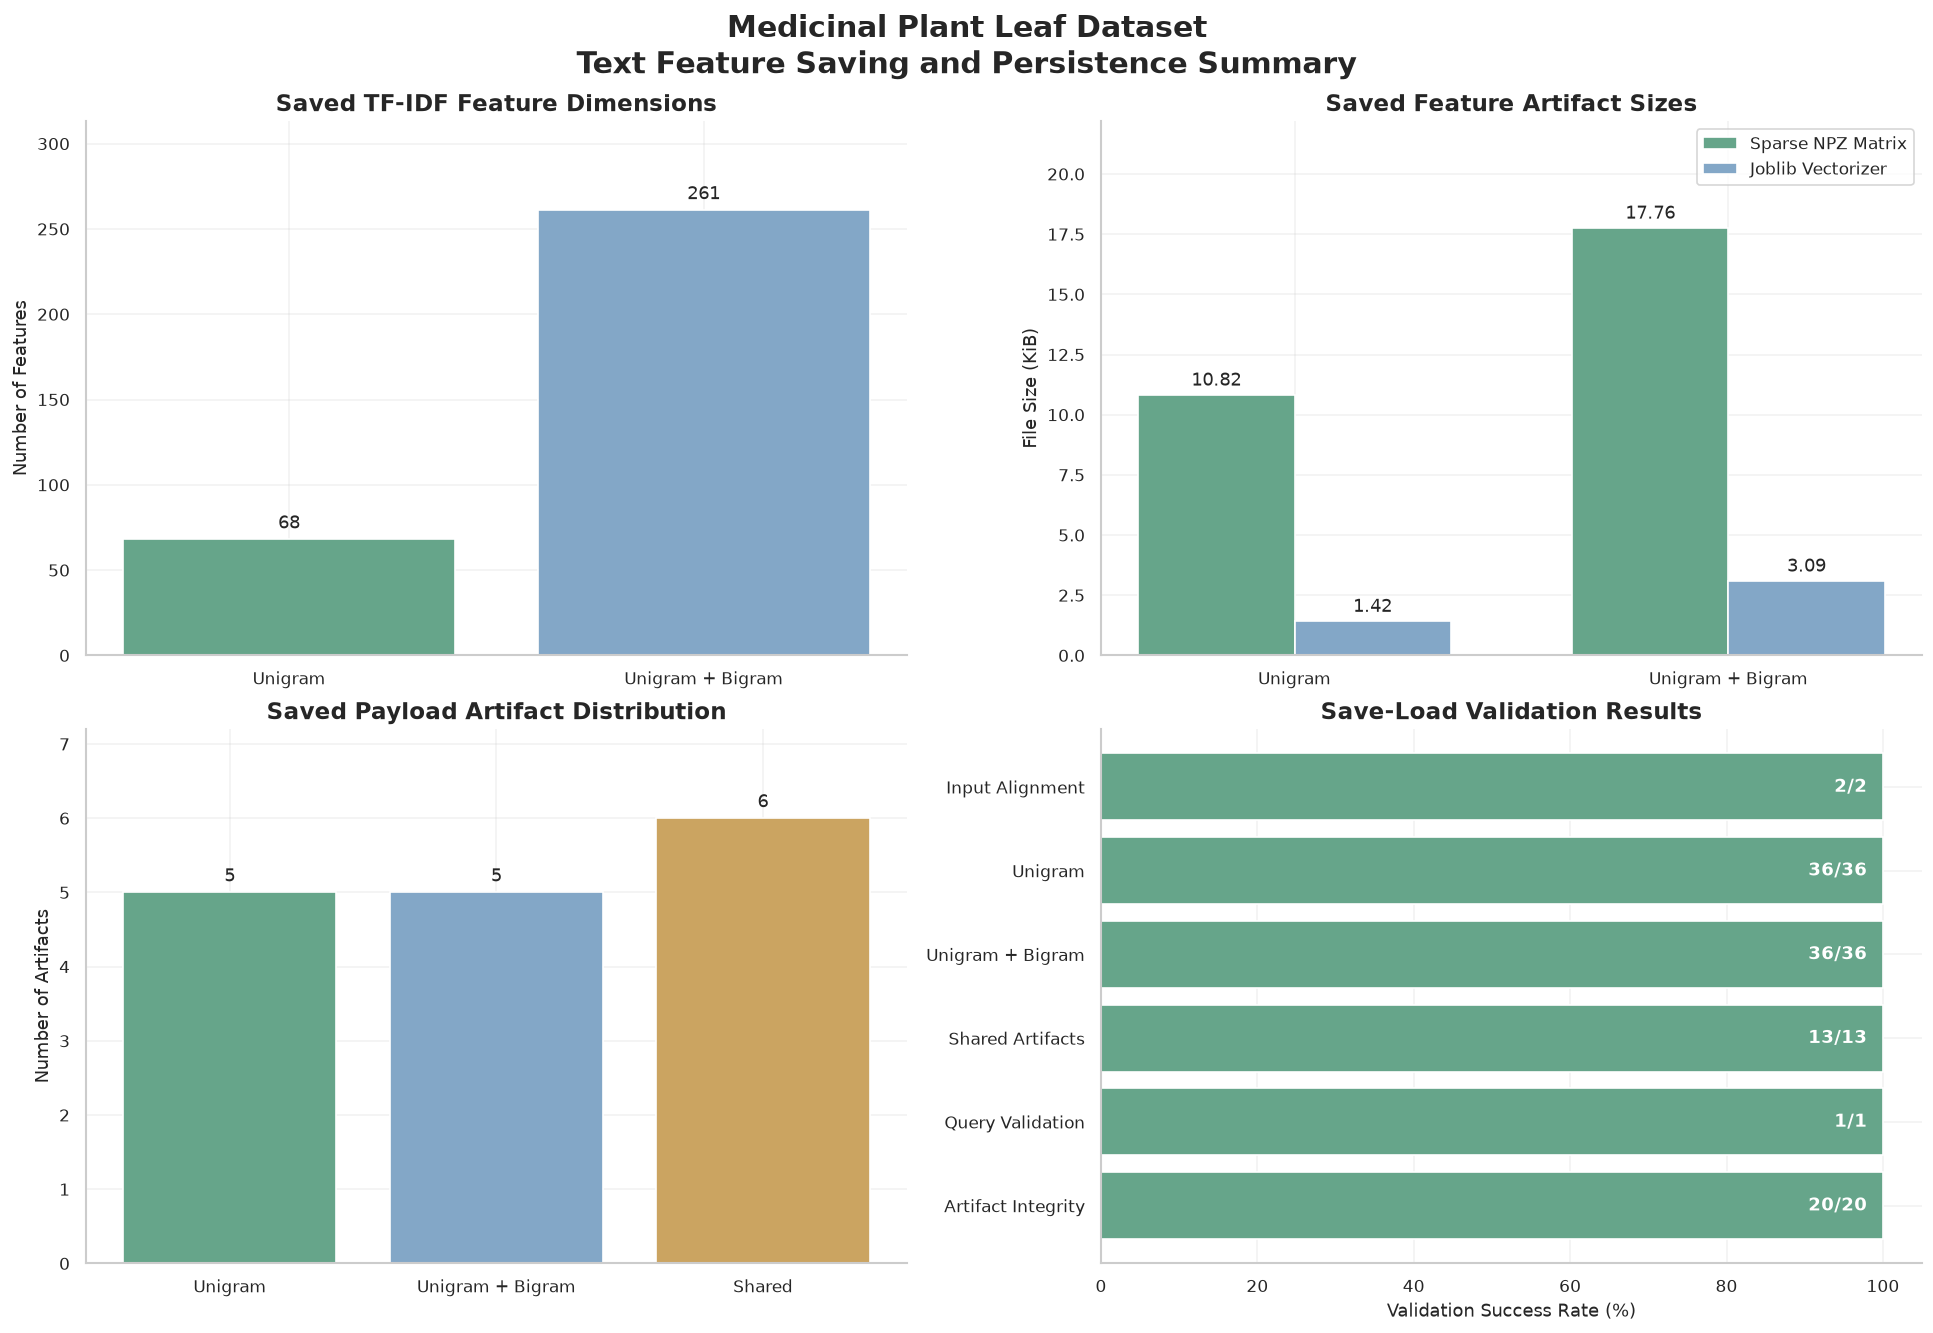

[SAVED] 100_text_feature_saving_summary.png

10. FINAL SAVING SUMMARY
-----------------------------------------------------------------


,Indicator,Result
0,Total samples,104
1,Total classes,5
2,TF-IDF configurations saved,2
3,Unigram matrix shape,"(104, 68)"
4,Combined matrix shape,"(104, 261)"
5,Payload artifacts saved,16
6,Total artifacts including manifest,17
7,Payload artifact size (KiB),269.045898
8,Total artifact size including manifest (KiB),272.269531
9,Maximum saved matrix difference,0.0



11. SAVING REPORTS
-----------------------------------------------------------------
[SAVED] 328_text_feature_artifact_manifest.csv
[SAVED] 329_text_feature_save_load_validation.csv
[SAVED] 330_text_feature_save_load_summary.csv
[SAVED] 331_saved_text_query_validation.csv
[SAVED] 332_text_artifact_size_summary.csv
[SAVED] 333_text_save_validation_category.csv
[SAVED] 334_text_feature_saving_summary.csv

FINAL TEXT FEATURE SAVING SUMMARY

DATASET INFORMATION
-----------------------------------------------------------------
Total samples : 104
Total classes : 5
Configurations: 2

SAVED FEATURE MATRICES
-----------------------------------------------------------------
Unigram: (104, 68)
Unigram + Bigram: (104, 261)

ARTIFACT INFORMATION
-----------------------------------------------------------------
Payload artifacts : 16
Including manifest: 17
Payload file size : 269.0459 KiB
Output directory  : D:\Project\Multimodal_Leaf_Retrieval\dataset\features\text

VALIDATION RESULTS
-----------

In [14]:
# ==================================================
# CELL 15 - SAVE TEXT FEATURES
# ==================================================

import json
import sys
import hashlib
import joblib
import scipy
import sklearn

from pathlib import Path
from datetime import datetime, timezone
from scipy.sparse import save_npz, load_npz, issparse
from sklearn.metrics.pairwise import cosine_similarity

print("SAVE TEXT FEATURES")
print("=" * 65)

TEXT_FEATURE_SAVING_COMPLETED = False
TEXT_FEATURES_SAVED = False


# ==================================================
# 1. VALIDATE PREVIOUS PROCESSING STAGES
# ==================================================

required_stages = [
    "TFIDF_FEATURE_EXTRACTION_COMPLETED",
    "TFIDF_MATRIX_ANALYSIS_COMPLETED",
    "TEXT_FEATURE_QUALITY_VALIDATION_COMPLETED",
    "COSINE_SIMILARITY_ANALYSIS_COMPLETED",
    "QUERY_TRANSFORMATION_CONSISTENCY_COMPLETED",
    "IMAGE_TEXT_ALIGNMENT_COMPLETED"
]

for stage in required_stages:

    assert globals().get(stage, False), (
        f"{stage} is not completed. "
        "Run the previous cells first."
    )

assert tfidf_quality_validation_df["passed"].all()
assert tfidf_cosine_validation_df["passed"].all()
assert tfidf_query_validation_df["passed"].all()
assert alignment_validation_df["passed"].all()

assert np.array_equal(
    multimodal_sample_ids,
    tfidf_sample_ids
)

assert np.array_equal(
    multimodal_sample_ids,
    loaded_visual_sample_ids
)

print("[PASS] Previous processing stages validated.")
print("[PASS] Image-text alignment validated.")


# ==================================================
# 2. TEXT FEATURE SAVING CONFIGURATION
# ==================================================

TEXT_SAVE_TOLERANCE = 1e-10

TEXT_SAVE_SCOPE = (
    "Full Dataset - Gallery Development"
)

TEXT_ARTIFACT_SCHEMA_VERSION = "1.0.0"

# Use the project directory from Cell 14.

text_save_project_root = Path(
    alignment_project_root
).resolve()

TEXT_FEATURE_SAVE_DIR = (
    text_save_project_root
    / "dataset"
    / "features"
    / "text"
)

TEXT_FEATURE_SAVE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

Path(METRICS_DIR).mkdir(
    parents=True,
    exist_ok=True
)

Path(TEXT_FEATURE_FIGURES_DIR).mkdir(
    parents=True,
    exist_ok=True
)

text_save_configuration_slugs = {
    TFIDF_BASELINE_NAME: "unigram",
    TFIDF_ALTERNATIVE_NAME: "unigram_bigram"
}

text_save_n_samples = len(
    multimodal_sample_ids
)

text_save_validation_records = []
text_artifact_records = []
text_save_figure_paths = []
text_saved_configuration_paths = {}

print("\n1. SAVING CONFIGURATION")
print("-" * 65)

print(f"Output directory : {TEXT_FEATURE_SAVE_DIR}")
print(f"Total samples    : {text_save_n_samples}")
print(f"Saving scope     : {TEXT_SAVE_SCOPE}")
print(f"Schema version   : {TEXT_ARTIFACT_SCHEMA_VERSION}")


# ==================================================
# 3. HELPER FUNCTIONS
# ==================================================

def register_text_save_check(
    category,
    check_name,
    passed
):

    text_save_validation_records.append({
        "category": category,
        "validation_check": check_name,
        "passed": bool(passed),
        "status": "Passed" if passed else "Failed"
    })


def calculate_file_sha256(file_path):

    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:

        for block in iter(
            lambda: file.read(65536),
            b""
        ):

            sha256.update(block)

    return sha256.hexdigest()


def register_text_artifact(
    file_path,
    category,
    configuration="Shared"
):

    file_path = Path(file_path)

    assert file_path.is_file()
    assert file_path.stat().st_size > 0

    text_artifact_records.append({
        "filename": file_path.name,
        "relative_path": file_path.relative_to(
            text_save_project_root
        ).as_posix(),
        "category": category,
        "configuration": configuration,
        "file_format": file_path.suffix,
        "size_bytes": file_path.stat().st_size,
        "size_kib": file_path.stat().st_size / 1024,
        "sha256": calculate_file_sha256(file_path)
    })

    print(f"[SAVED] {file_path.name}")


def save_text_json(data, output_path):

    with open(
        output_path,
        "w",
        encoding="utf-8"
    ) as file:

        json.dump(
            data,
            file,
            ensure_ascii=False,
            indent=4,
            default=str,
            allow_nan=False
        )


def read_text_json(file_path):

    with open(
        file_path,
        "r",
        encoding="utf-8"
    ) as file:

        return json.load(file)


def sparse_max_difference(matrix_a, matrix_b):

    assert matrix_a.shape == matrix_b.shape

    difference = (
        matrix_a - matrix_b
    ).tocsr()

    difference.eliminate_zeros()

    if difference.nnz == 0:
        return 0.0

    return float(
        np.max(
            np.abs(difference.data)
        )
    )


# ==================================================
# 4. PREPARE SHARED TEXT ARTIFACTS
# ==================================================

text_save_sample_ids = np.asarray(
    multimodal_sample_ids,
    dtype=str
)

text_save_labels = np.asarray(
    multimodal_labels,
    dtype=str
)

text_save_corpus = list(
    multimodal_text_corpus
)

text_save_metadata_df = (
    df_multimodal_aligned.copy()
    .reset_index(drop=True)
)

assert len(text_save_sample_ids) == text_save_n_samples
assert len(text_save_labels) == text_save_n_samples
assert len(text_save_corpus) == text_save_n_samples
assert len(text_save_metadata_df) == text_save_n_samples

assert len(
    np.unique(text_save_sample_ids)
) == text_save_n_samples

assert np.array_equal(
    text_save_metadata_df["sample_id"].to_numpy(dtype=str),
    text_save_sample_ids
)

assert np.array_equal(
    text_save_metadata_df["kelas"].to_numpy(dtype=str),
    text_save_labels
)

assert all(
    isinstance(text, str)
    and text.strip()
    for text in text_save_corpus
)

assert text_save_corpus == list(
    validated_text_corpus
)

# Retain original metadata and review flags.

register_text_save_check(
    "Input Alignment",
    "Input sample IDs and labels aligned",
    True
)

register_text_save_check(
    "Input Alignment",
    "Input corpus and metadata aligned",
    np.array_equal(
        text_save_metadata_df[
            "cleaned_description"
        ].to_numpy(dtype=str),
        np.asarray(text_save_corpus, dtype=str)
    )
)

print("\n2. SHARED ARTIFACTS PREPARED")
print("-" * 65)

print("Sample IDs :", text_save_sample_ids.shape)
print("Labels     :", text_save_labels.shape)
print("Corpus     :", len(text_save_corpus))
print("Metadata   :", text_save_metadata_df.shape)


# ==================================================
# 5. SAVE TF-IDF MATRICES AND VECTORIZERS
# ==================================================

print("\n3. SAVING TF-IDF CONFIGURATIONS")
print("-" * 65)

text_saved_configuration_info = {}

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    slug = text_save_configuration_slugs[
        configuration_name
    ]

    vectorizer = tfidf_vectorizers[
        configuration_name
    ]

    matrix = tfidf_matrices[
        configuration_name
    ].tocsr(copy=True)

    feature_names = np.asarray(
        vectorizer.get_feature_names_out(),
        dtype=str
    )

    idf_weights = np.asarray(
        vectorizer.idf_
    ).copy()

    assert matrix.shape[0] == text_save_n_samples
    assert matrix.shape[1] == len(feature_names)
    assert matrix.shape[1] == len(idf_weights)

    assert np.isfinite(matrix.data).all()
    assert np.isfinite(idf_weights).all()
    assert np.all(matrix.data >= 0)

    matrix_path = (
        TEXT_FEATURE_SAVE_DIR
        / f"tfidf_{slug}_features.npz"
    )

    vectorizer_path = (
        TEXT_FEATURE_SAVE_DIR
        / f"tfidf_{slug}_vectorizer.joblib"
    )

    feature_names_path = (
        TEXT_FEATURE_SAVE_DIR
        / f"tfidf_{slug}_feature_names.npy"
    )

    idf_path = (
        TEXT_FEATURE_SAVE_DIR
        / f"tfidf_{slug}_idf_weights.npy"
    )

    vocabulary_path = (
        TEXT_FEATURE_SAVE_DIR
        / f"tfidf_{slug}_vocabulary.csv"
    )

    print(f"\nConfiguration: {configuration_name}")

    # A. Save sparse CSR matrix.

    save_npz(
        matrix_path,
        matrix,
        compressed=True
    )

    register_text_artifact(
        matrix_path,
        "Sparse Feature Matrix",
        configuration_name
    )

    # B. Save complete fitted vectorizer.

    joblib.dump(
        vectorizer,
        vectorizer_path,
        compress=3
    )

    register_text_artifact(
        vectorizer_path,
        "TF-IDF Vectorizer",
        configuration_name
    )

    # C. Save feature names in original column order.

    np.save(
        feature_names_path,
        feature_names,
        allow_pickle=False
    )

    register_text_artifact(
        feature_names_path,
        "Feature Names",
        configuration_name
    )

    # D. Save exact IDF weights.

    np.save(
        idf_path,
        idf_weights,
        allow_pickle=False
    )

    register_text_artifact(
        idf_path,
        "IDF Weights",
        configuration_name
    )

    # E. Save human-readable vocabulary report.

    document_frequency = np.asarray(
        (matrix != 0).sum(axis=0)
    ).ravel()

    vocabulary_df = pd.DataFrame({
        "feature_index": np.arange(
            len(feature_names)
        ),
        "term": feature_names,
        "ngram_type": [
            "Bigram" if " " in term
            else "Unigram"
            for term in feature_names
        ],
        "document_frequency": document_frequency,
        "idf_weight": idf_weights
    })

    vocabulary_df.to_csv(
        vocabulary_path,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    register_text_artifact(
        vocabulary_path,
        "Vocabulary Report",
        configuration_name
    )

    # F. Store artifact paths for reloading.

    text_saved_configuration_paths[
        configuration_name
    ] = {
        "matrix": matrix_path,
        "vectorizer": vectorizer_path,
        "feature_names": feature_names_path,
        "idf": idf_path,
        "vocabulary": vocabulary_path
    }

    matrix_elements = (
        matrix.shape[0] * matrix.shape[1]
    )

    text_saved_configuration_info[
        configuration_name
    ] = {
        "slug": slug,
        "matrix_shape": list(matrix.shape),
        "feature_dimension": matrix.shape[1],
        "nonzero_values": int(matrix.nnz),
        "sparsity_percent": float(
            (1 - matrix.nnz / matrix_elements)
            * 100
        ),
        "matrix_format": "CSR",
        "matrix_dtype": str(matrix.dtype),
        "ngram_range": list(
            vectorizer.ngram_range
        ),
        "vectorizer_parameters": (
            vectorizer.get_params(deep=False)
        ),
        "files": {
            key: path.name
            for key, path in (
                text_saved_configuration_paths[
                    configuration_name
                ].items()
            )
        }
    }


# ==================================================
# 6. SAVE SAMPLE IDS AND CLASS LABELS
# ==================================================

print("\n4. SAVING SAMPLE IDENTITY ARTIFACTS")
print("-" * 65)

text_sample_ids_path = (
    TEXT_FEATURE_SAVE_DIR
    / "text_sample_ids.npy"
)

text_labels_path = (
    TEXT_FEATURE_SAVE_DIR
    / "text_class_labels.npy"
)

np.save(
    text_sample_ids_path,
    text_save_sample_ids,
    allow_pickle=False
)

register_text_artifact(
    text_sample_ids_path,
    "Sample Identity"
)

np.save(
    text_labels_path,
    text_save_labels,
    allow_pickle=False
)

register_text_artifact(
    text_labels_path,
    "Class Labels"
)


# ==================================================
# 7. SAVE MULTIMODAL METADATA
# ==================================================

text_metadata_save_path = (
    TEXT_FEATURE_SAVE_DIR
    / "multimodal_feature_metadata.csv"
)

text_save_metadata_df.to_csv(
    text_metadata_save_path,
    index=False,
    encoding="utf-8-sig"
)

register_text_artifact(
    text_metadata_save_path,
    "Multimodal Metadata"
)


# ==================================================
# 8. SAVE TEXT CORPUS
# ==================================================

text_corpus_save_path = (
    TEXT_FEATURE_SAVE_DIR
    / "text_corpus.json"
)

text_corpus_payload = {
    "number_of_documents": text_save_n_samples,
    "sample_ids": text_save_sample_ids.tolist(),
    "descriptions": text_save_corpus
}

save_text_json(
    text_corpus_payload,
    text_corpus_save_path
)

register_text_artifact(
    text_corpus_save_path,
    "Text Corpus"
)


# ==================================================
# 9. SAVE QUERY PREPROCESSING CONFIGURATION
# ==================================================

text_preprocessing_save_path = (
    TEXT_FEATURE_SAVE_DIR
    / "text_query_preprocessing_config.json"
)

save_text_json(
    query_preprocessing_config,
    text_preprocessing_save_path
)

register_text_artifact(
    text_preprocessing_save_path,
    "Preprocessing Configuration"
)


# ==================================================
# 10. SAVE TEXT FEATURE EXTRACTION CONFIGURATION
# ==================================================

text_feature_save_config = {

    "schema_version": TEXT_ARTIFACT_SCHEMA_VERSION,

    "project": (
        "Multimodal Medicinal Plant Leaf Retrieval "
        "Using Visual and Textual Features"
    ),

    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "feature_extraction_method": "TF-IDF",

    "reference_fit_scope": TEXT_SAVE_SCOPE,

    "number_of_samples": text_save_n_samples,

    "number_of_classes": int(
        len(np.unique(text_save_labels))
    ),

    "class_distribution": {
        str(label): int(count)
        for label, count in zip(
            *np.unique(
                text_save_labels,
                return_counts=True
            )
        )
    },

    "baseline_configuration": TFIDF_BASELINE_NAME,

    "alternative_configuration": TFIDF_ALTERNATIVE_NAME,

    "configurations": text_saved_configuration_info,

    "text_matching_method": "Cosine Similarity",

    "text_normalization": "L2",

    "matrix_storage_format": "Compressed Sparse CSR NPZ",

    "query_preprocessing_file": (
        text_preprocessing_save_path.name
    ),

    "sample_ids_file": text_sample_ids_path.name,

    "class_labels_file": text_labels_path.name,

    "metadata_file": text_metadata_save_path.name,

    "corpus_file": text_corpus_save_path.name,

    "visual_artifact_checksums": {
        key: {
            "filename": Path(
                alignment_input_paths[key]
            ).name,

            "sha256": calculate_file_sha256(
                alignment_input_paths[key]
            )
        }
        for key in [
            "normalized_visual",
            "raw_visual",
            "baseline_visual",
            "visual_sample_ids",
            "visual_metadata"
        ]
    },

    "fusion_method": "Score-Level Late Fusion",

    "feature_selection_applied": False,

    "features_removed": 0,

    "samples_removed": 0,

    "final_text_configuration_selected": False,

    "manual_data_review_required": True,

    "evaluation_requires_reference_only_refit": True,

    "independent_retrieval_evaluation_completed": False,

    "query_vectorizer_operation": "transform",

    "self_match_policy": (
        "Exclude query sample ID when applicable"
    ),

    "zero_vector_policy": (
        "Do not generate text-only ranking"
    ),

    "software_versions": {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scipy": scipy.__version__,
        "scikit_learn": sklearn.__version__,
        "joblib": joblib.__version__
    }
}

text_config_save_path = (
    TEXT_FEATURE_SAVE_DIR
    / "text_feature_extraction_config.json"
)

save_text_json(
    text_feature_save_config,
    text_config_save_path
)

register_text_artifact(
    text_config_save_path,
    "Feature Extraction Configuration"
)


# ==================================================
# 11. RELOAD SAVED TF-IDF ARTIFACTS
# ==================================================

print("\n5. RELOADING SAVED ARTIFACTS")
print("-" * 65)

loaded_text_vectorizers = {}
loaded_text_feature_matrices = {}
loaded_text_feature_names = {}
loaded_text_idf_weights = {}

text_save_load_summary_records = []

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    paths = text_saved_configuration_paths[
        configuration_name
    ]

    # Only load trusted local Joblib artifacts.

    loaded_vectorizer = joblib.load(
        paths["vectorizer"]
    )

    loaded_matrix = load_npz(
        paths["matrix"]
    ).tocsr()

    loaded_feature_names = np.load(
        paths["feature_names"],
        allow_pickle=False
    )

    loaded_idf = np.load(
        paths["idf"],
        allow_pickle=False
    )

    loaded_vocabulary_df = pd.read_csv(
        paths["vocabulary"],
        keep_default_na=False,
        dtype={"term": str},
        float_precision="round_trip"
    )

    loaded_text_vectorizers[
        configuration_name
    ] = loaded_vectorizer

    loaded_text_feature_matrices[
        configuration_name
    ] = loaded_matrix

    loaded_text_feature_names[
        configuration_name
    ] = loaded_feature_names

    loaded_text_idf_weights[
        configuration_name
    ] = loaded_idf

    original_vectorizer = tfidf_vectorizers[
        configuration_name
    ]

    original_matrix = tfidf_matrices[
        configuration_name
    ]

    original_feature_names = (
        original_vectorizer.get_feature_names_out()
    )

    # ----------------------------------------------
    # A. Validate matrix properties
    # ----------------------------------------------

    matrix_difference = sparse_max_difference(
        loaded_matrix,
        original_matrix
    )

    row_norms = np.sqrt(
        np.asarray(
            loaded_matrix.multiply(
                loaded_matrix
            ).sum(axis=1)
        ).ravel()
    )

    matrix_checks = {

        "Saved matrix dimensions preserved":
            loaded_matrix.shape == original_matrix.shape,

        "Sparse CSR format preserved":
            issparse(loaded_matrix)
            and loaded_matrix.format == "csr",

        "Matrix dtype preserved":
            loaded_matrix.dtype == original_matrix.dtype,

        "Nonzero value count preserved":
            loaded_matrix.nnz == original_matrix.nnz,

        "Matrix values exactly preserved":
            matrix_difference == 0,

        "Matrix values finite":
            np.isfinite(loaded_matrix.data).all(),

        "Matrix values nonnegative":
            np.all(loaded_matrix.data >= 0),

        "Unit L2 norm preserved":
            np.allclose(
                row_norms,
                1.0,
                atol=TEXT_SAVE_TOLERANCE,
                rtol=0
            )
    }

    for check_name, passed in matrix_checks.items():

        register_text_save_check(
            configuration_name,
            check_name,
            passed
        )

    # ----------------------------------------------
    # B. Validate fitted vectorizer properties
    # ----------------------------------------------

    vectorizer_checks = {

        "Vectorizer parameters preserved":
            loaded_vectorizer.get_params(deep=False)
            == original_vectorizer.get_params(deep=False),

        "Vocabulary mapping preserved":
            loaded_vectorizer.vocabulary_
            == original_vectorizer.vocabulary_,

        "Vectorizer IDF exactly preserved":
            np.array_equal(
                loaded_vectorizer.idf_,
                original_vectorizer.idf_
            ),

        "Vectorizer feature order preserved":
            np.array_equal(
                loaded_vectorizer.get_feature_names_out(),
                original_feature_names
            ),

        "Saved feature names preserved":
            np.array_equal(
                loaded_feature_names,
                original_feature_names
            ),

        "Saved IDF array preserved":
            np.array_equal(
                loaded_idf,
                original_vectorizer.idf_
            ),

        "Vocabulary report feature indices preserved":
            np.array_equal(
                loaded_vocabulary_df[
                    "feature_index"
                ].to_numpy(),
                np.arange(loaded_matrix.shape[1])
            ),

        "Vocabulary report terms preserved":
            np.array_equal(
                loaded_vocabulary_df[
                    "term"
                ].to_numpy(dtype=str),
                loaded_feature_names
            ),

        "Vocabulary report IDF preserved":
            np.allclose(
                loaded_vocabulary_df[
                    "idf_weight"
                ].to_numpy(dtype=float),
                loaded_idf,
                atol=TEXT_SAVE_TOLERANCE,
                rtol=0
            ),

        "Vocabulary report document frequency preserved":
            np.array_equal(
                loaded_vocabulary_df[
                    "document_frequency"
                ].to_numpy(),
                np.asarray(
                    (loaded_matrix != 0).sum(axis=0)
                ).ravel()
            )
    }

    for check_name, passed in vectorizer_checks.items():

        register_text_save_check(
            configuration_name,
            check_name,
            passed
        )

    # ----------------------------------------------
    # C. Reproduce reference features
    # ----------------------------------------------

    reproduced_matrix = (
        loaded_vectorizer.transform(
            text_save_corpus
        ).tocsr()
    )

    reproduction_difference = sparse_max_difference(
        reproduced_matrix,
        loaded_matrix
    )

    register_text_save_check(
        configuration_name,
        "Reloaded vectorizer reproduces reference matrix",
        reproduction_difference
        <= TEXT_SAVE_TOLERANCE
    )

    # ----------------------------------------------
    # D. Reproduce cosine similarity matrix
    # ----------------------------------------------

    reproduced_similarity = cosine_similarity(
        loaded_matrix
    )

    original_similarity = (
        tfidf_cosine_similarity_matrices[
            configuration_name
        ]
    )

    similarity_difference = float(
        np.max(
            np.abs(
                reproduced_similarity
                - original_similarity
            )
        )
    )

    register_text_save_check(
        configuration_name,
        "Reloaded cosine similarity consistent",
        similarity_difference
        <= TEXT_SAVE_TOLERANCE
    )

    # ----------------------------------------------
    # E. Store configuration-level summary
    # ----------------------------------------------

    text_save_load_summary_records.append({

        "configuration": configuration_name,

        "number_of_samples": loaded_matrix.shape[0],

        "feature_dimension": loaded_matrix.shape[1],

        "nonzero_values": loaded_matrix.nnz,

        "matrix_difference": matrix_difference,

        "reference_reproduction_difference":
            reproduction_difference,

        "cosine_similarity_difference":
            similarity_difference,

        "vocabulary_size": len(
            loaded_vectorizer.vocabulary_
        ),

        "matrix_file_size_kib":
            paths["matrix"].stat().st_size / 1024,

        "vectorizer_file_size_kib":
            paths["vectorizer"].stat().st_size / 1024
    })

    print(f"\nConfiguration: {configuration_name}")

    print("Matrix shape :", loaded_matrix.shape)

    print(
        f"Matrix difference       : "
        f"{matrix_difference:.3e}"
    )

    print(
        f"Reproduction difference : "
        f"{reproduction_difference:.3e}"
    )

    print(
        f"Cosine difference       : "
        f"{similarity_difference:.3e}"
    )


text_save_load_summary_df = pd.DataFrame(
    text_save_load_summary_records
)

display(text_save_load_summary_df)


# ==================================================
# 12. VALIDATE SHARED ARTIFACTS AFTER RELOADING
# ==================================================

loaded_text_sample_ids = np.load(
    text_sample_ids_path,
    allow_pickle=False
)

loaded_text_class_labels = np.load(
    text_labels_path,
    allow_pickle=False
)

loaded_text_metadata_df = pd.read_csv(
    text_metadata_save_path,
    dtype=str,
    keep_default_na=False
)

loaded_text_corpus_payload = read_text_json(
    text_corpus_save_path
)

loaded_text_corpus = (
    loaded_text_corpus_payload[
        "descriptions"
    ]
)

loaded_query_preprocessing_config = read_text_json(
    text_preprocessing_save_path
)

loaded_text_feature_config = read_text_json(
    text_config_save_path
)

# Compare metadata using its CSV text representation.

expected_metadata_as_text = (
    text_save_metadata_df
    .fillna("")
    .astype(str)
)

shared_artifact_checks = {

    "Sample IDs exactly preserved":
        np.array_equal(
            loaded_text_sample_ids,
            text_save_sample_ids
        ),

    "Class labels exactly preserved":
        np.array_equal(
            loaded_text_class_labels,
            text_save_labels
        ),

    "Metadata column order preserved":
        list(loaded_text_metadata_df.columns)
        == list(text_save_metadata_df.columns),

    "Metadata values and review flags preserved":
        loaded_text_metadata_df.equals(
            expected_metadata_as_text
        ),

    "Metadata sample ID order preserved":
        np.array_equal(
            loaded_text_metadata_df[
                "sample_id"
            ].to_numpy(dtype=str),
            loaded_text_sample_ids
        ),

    "Metadata class labels preserved":
        np.array_equal(
            loaded_text_metadata_df[
                "kelas"
            ].to_numpy(dtype=str),
            loaded_text_class_labels
        ),

    "Text corpus exactly preserved":
        loaded_text_corpus == text_save_corpus,

    "Corpus sample ID order preserved":
        loaded_text_corpus_payload["sample_ids"]
        == loaded_text_sample_ids.tolist(),

    "Corpus document count preserved":
        loaded_text_corpus_payload[
            "number_of_documents"
        ] == text_save_n_samples,

    "Query preprocessing configuration preserved":
        loaded_query_preprocessing_config
        == query_preprocessing_config,

    "Feature extraction configuration preserved":
        loaded_text_feature_config
        == json.loads(
            json.dumps(
                text_feature_save_config,
                default=str,
                allow_nan=False
            )
        ),

    "Reloaded image-text sample order identical":
        np.array_equal(
            loaded_text_sample_ids,
            loaded_visual_sample_ids
        ),

    "Reference-only refitting requirement preserved":
        loaded_text_feature_config[
            "evaluation_requires_reference_only_refit"
        ] is True
}

for check_name, passed in shared_artifact_checks.items():

    register_text_save_check(
        "Shared Artifacts",
        check_name,
        passed
    )


# ==================================================
# 13. VALIDATE QUERY TRANSFORMATION AFTER RELOADING
# ==================================================

print("\n6. RELOADED QUERY TRANSFORMATION VALIDATION")
print("-" * 65)

text_saved_query_records = []

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    loaded_vectorizer = loaded_text_vectorizers[
        configuration_name
    ]

    loaded_matrix = loaded_text_feature_matrices[
        configuration_name
    ]

    for test_case in query_test_cases:

        raw_query = test_case["text"]

        original_result = transform_text_query(
            raw_query,
            configuration_name
        )

        original_vector = original_result[
            "vector"
        ]

        query_id = test_case[
            "query_id"
        ]

        vector_difference = np.nan
        cosine_difference = np.nan

        # Queries rejected before vectorization.

        if original_vector is None:

            passed = (
                not original_result[
                    "usable_for_matching"
                ]
            )

        else:

            cleaned_query = original_result[
                "cleaned_query"
            ]

            reloaded_query_vector = (
                loaded_vectorizer.transform(
                    [cleaned_query]
                ).tocsr()
            )

            vector_difference = sparse_max_difference(
                reloaded_query_vector,
                original_vector
            )

            if original_result["usable_for_matching"]:

                original_scores = cosine_similarity(
                    original_vector,
                    tfidf_matrices[
                        configuration_name
                    ]
                )

                reloaded_scores = cosine_similarity(
                    reloaded_query_vector,
                    loaded_matrix
                )

                cosine_difference = float(
                    np.max(
                        np.abs(
                            original_scores
                            - reloaded_scores
                        )
                    )
                )

                passed = (
                    vector_difference
                    <= TEXT_SAVE_TOLERANCE

                    and cosine_difference
                    <= TEXT_SAVE_TOLERANCE
                )

            else:

                # All-OOV queries must remain zero vectors.

                passed = (
                    reloaded_query_vector.nnz == 0

                    and vector_difference
                    <= TEXT_SAVE_TOLERANCE
                )

        text_saved_query_records.append({

            "configuration": configuration_name,

            "query_id": query_id,

            "query_type": test_case["query_type"],

            "query_status": original_result["status"],

            "usable_for_matching":
                original_result["usable_for_matching"],

            "maximum_vector_difference":
                vector_difference,

            "maximum_cosine_difference":
                cosine_difference,

            "passed": bool(passed)
        })

        register_text_save_check(
            configuration_name,
            f"Reloaded query consistency - {query_id}",
            passed
        )


text_saved_query_validation_df = pd.DataFrame(
    text_saved_query_records
)

display(
    text_saved_query_validation_df
)

register_text_save_check(
    "Query Validation",
    "All expected query records evaluated",
    len(text_saved_query_validation_df)
    == len(query_test_cases)
    * len(TFIDF_CONFIGURATION_ORDER)
)


# ==================================================
# 14. VERIFY SAVED ARTIFACT CHECKSUMS
# ==================================================

print("\n7. ARTIFACT CHECKSUM VALIDATION")
print("-" * 65)

text_artifact_manifest_df = pd.DataFrame(
    text_artifact_records
)

assert text_artifact_manifest_df[
    "filename"
].is_unique

for row in text_artifact_manifest_df.itertuples():

    artifact_path = (
        text_save_project_root
        / row.relative_path
    )

    exists = artifact_path.is_file()

    checksum_valid = (
        exists
        and calculate_file_sha256(
            artifact_path
        ) == row.sha256
    )

    size_valid = (
        exists
        and artifact_path.stat().st_size
        == row.size_bytes
    )

    register_text_save_check(
        "Artifact Integrity",
        f"{row.filename} integrity verified",
        checksum_valid and size_valid
    )


# ==================================================
# 15. SAVE AND VALIDATE ARTIFACT MANIFEST
# ==================================================

text_manifest_path = (
    TEXT_FEATURE_SAVE_DIR
    / "text_feature_artifact_manifest.csv"
)

text_artifact_manifest_df.to_csv(
    text_manifest_path,
    index=False,
    encoding="utf-8-sig"
)

loaded_text_manifest_df = pd.read_csv(
    text_manifest_path,
    dtype={
        "filename": str,
        "relative_path": str,
        "sha256": str
    }
)

register_text_save_check(
    "Artifact Integrity",
    "Manifest contains all expected payload artifacts",
    len(loaded_text_manifest_df) == 16
)

register_text_save_check(
    "Artifact Integrity",
    "Manifest filenames preserved",
    loaded_text_manifest_df[
        "filename"
    ].tolist()
    == text_artifact_manifest_df[
        "filename"
    ].tolist()
)

register_text_save_check(
    "Artifact Integrity",
    "Manifest checksums preserved",
    loaded_text_manifest_df[
        "sha256"
    ].tolist()
    == text_artifact_manifest_df[
        "sha256"
    ].tolist()
)

register_text_save_check(
    "Artifact Integrity",
    "Manifest file sizes preserved",
    np.array_equal(
        loaded_text_manifest_df[
            "size_bytes"
        ].to_numpy(),
        text_artifact_manifest_df[
            "size_bytes"
        ].to_numpy()
    )
)

print(f"[SAVED] {text_manifest_path.name}")

display(
    text_artifact_manifest_df[[
        "filename",
        "category",
        "configuration",
        "size_kib"
    ]].round(4)
)


# ==================================================
# 16. FINAL SAVE-LOAD VALIDATION
# ==================================================

text_save_validation_df = pd.DataFrame(
    text_save_validation_records
)

# Alias for subsequent notebook summary.

text_save_load_validation_df = (
    text_save_validation_df
)

text_save_total_checks = len(
    text_save_validation_df
)

text_save_passed_checks = int(
    text_save_validation_df[
        "passed"
    ].sum()
)

text_save_failed_checks = (
    text_save_total_checks
    - text_save_passed_checks
)

text_save_validation_df.to_csv(
    Path(METRICS_DIR)
    / "329_text_feature_save_load_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n8. SAVE-LOAD VALIDATION RESULTS")
print("-" * 65)

display(text_save_validation_df)

assert text_save_validation_df["passed"].all(), (
    text_save_validation_df.loc[
        ~text_save_validation_df["passed"]
    ].to_string(index=False)
)

print("[PASS] All save-load checks passed.")


# ==================================================
# 17. SUMMARIZE SAVED ARTIFACT SIZES
# ==================================================

text_artifact_total_bytes = int(
    text_artifact_manifest_df[
        "size_bytes"
    ].sum()
)

text_artifact_total_kib = (
    text_artifact_total_bytes / 1024
)

text_artifact_size_summary_df = (
    text_artifact_manifest_df
    .groupby("configuration", sort=False)
    .agg(
        number_of_artifacts=(
            "filename", "count"
        ),
        total_size_bytes=(
            "size_bytes", "sum"
        ),
        total_size_kib=(
            "size_kib", "sum"
        )
    )
    .reset_index()
)

text_save_validation_category_df = (
    text_save_validation_df
    .groupby("category", sort=False)
    .agg(
        total_checks=(
            "validation_check", "count"
        ),
        passed_checks=(
            "passed", "sum"
        )
    )
    .reset_index()
)

text_save_validation_category_df[
    "success_rate_percent"
] = (
    text_save_validation_category_df[
        "passed_checks"
    ]
    / text_save_validation_category_df[
        "total_checks"
    ]
    * 100
)

print("\n9. ARTIFACT STORAGE SUMMARY")
print("-" * 65)

display(
    text_artifact_size_summary_df.round(4)
)


# ==================================================
# 18. VISUALIZE TEXT FEATURE SAVING SUMMARY
# ==================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 11),
    constrained_layout=True
)

configuration_labels = [
    "Unigram",
    "Unigram + Bigram"
]

configuration_colors = [
    "#66A58A",
    "#83A7C7"
]

plot_save_summary = (
    text_save_load_summary_df
    .set_index("configuration")
    .loc[TFIDF_CONFIGURATION_ORDER]
    .reset_index()
)

# A. Saved feature dimensions.

ax = axes[0, 0]

bars = ax.bar(
    configuration_labels,
    plot_save_summary["feature_dimension"],
    color=configuration_colors
)

ax.bar_label(
    bars,
    padding=4
)

ax.set_ylabel("Number of Features")
ax.set_title("Saved TF-IDF Feature Dimensions")
ax.margins(y=0.2)


# B. Actual saved matrix and vectorizer file sizes.

ax = axes[0, 1]

positions = np.arange(
    len(configuration_labels)
)

bars_matrix = ax.bar(
    positions - 0.18,
    plot_save_summary["matrix_file_size_kib"],
    width=0.36,
    color="#66A58A",
    label="Sparse NPZ Matrix"
)

bars_vectorizer = ax.bar(
    positions + 0.18,
    plot_save_summary["vectorizer_file_size_kib"],
    width=0.36,
    color="#83A7C7",
    label="Joblib Vectorizer"
)

ax.bar_label(
    bars_matrix,
    fmt="%.2f",
    padding=3
)

ax.bar_label(
    bars_vectorizer,
    fmt="%.2f",
    padding=3
)

ax.set_xticks(positions)
ax.set_xticklabels(configuration_labels)

ax.set_ylabel("File Size (KiB)")
ax.set_title("Saved Feature Artifact Sizes")
ax.margins(y=0.25)
ax.legend()


# C. Saved artifact count per configuration.

ax = axes[1, 0]

bars = ax.bar(
    text_artifact_size_summary_df[
        "configuration"
    ],
    text_artifact_size_summary_df[
        "number_of_artifacts"
    ],
    color=[
        "#66A58A"
        if name == TFIDF_BASELINE_NAME
        else "#83A7C7"
        if name == TFIDF_ALTERNATIVE_NAME
        else "#CBA461"
        for name in text_artifact_size_summary_df[
            "configuration"
        ]
    ]
)

ax.bar_label(
    bars,
    padding=4
)

ax.set_ylabel("Number of Artifacts")
ax.set_title("Saved Payload Artifact Distribution")
ax.margins(y=0.2)


# D. Validation success per category.

ax = axes[1, 1]

bars = ax.barh(
    text_save_validation_category_df[
        "category"
    ],
    text_save_validation_category_df[
        "success_rate_percent"
    ],
    color="#66A58A"
)

for bar, row in zip(
    bars,
    text_save_validation_category_df.itertuples()
):

    ax.text(
        bar.get_width() - 2,
        bar.get_y() + bar.get_height() / 2,
        f"{row.passed_checks}/{row.total_checks}",
        va="center",
        ha="right",
        color="white",
        fontweight="bold"
    )

ax.set_xlim(0, 105)
ax.invert_yaxis()

ax.set_xlabel("Validation Success Rate (%)")
ax.set_title("Save-Load Validation Results")

fig.suptitle(
    "Medicinal Plant Leaf Dataset\n"
    "Text Feature Saving and Persistence Summary",
    fontsize=18,
    fontweight="bold"
)

text_save_figure_path = (
    Path(TEXT_FEATURE_FIGURES_DIR)
    / "100_text_feature_saving_summary.png"
)

fig.savefig(
    text_save_figure_path,
    dpi=300,
    bbox_inches="tight"
)

text_save_figure_paths.append(
    text_save_figure_path
)

plt.show()
plt.close(fig)

print(
    f"[SAVED] {text_save_figure_path.name}"
)


# ==================================================
# 19. CREATE FINAL TEXT FEATURE SAVING SUMMARY
# ==================================================

text_feature_saving_summary_df = pd.DataFrame([

    ("Total samples", text_save_n_samples),

    (
        "Total classes",
        len(np.unique(text_save_labels))
    ),

    (
        "TF-IDF configurations saved",
        len(loaded_text_vectorizers)
    ),

    (
        "Unigram matrix shape",
        str(
            loaded_text_feature_matrices[
                TFIDF_BASELINE_NAME
            ].shape
        )
    ),

    (
        "Combined matrix shape",
        str(
            loaded_text_feature_matrices[
                TFIDF_ALTERNATIVE_NAME
            ].shape
        )
    ),

    (
        "Payload artifacts saved",
        len(text_artifact_manifest_df)
    ),

    (
        "Total artifacts including manifest",
        len(text_artifact_manifest_df) + 1
    ),

    (
        "Payload artifact size (KiB)",
        text_artifact_total_kib
    ),

    (
        "Total artifact size including manifest (KiB)",
        (
            text_artifact_total_bytes
            + text_manifest_path.stat().st_size
        ) / 1024
    ),

    (
        "Maximum saved matrix difference",
        text_save_load_summary_df[
            "matrix_difference"
        ].max()
    ),

    (
        "Maximum reference reproduction difference",
        text_save_load_summary_df[
            "reference_reproduction_difference"
        ].max()
    ),

    (
        "Maximum cosine similarity difference",
        text_save_load_summary_df[
            "cosine_similarity_difference"
        ].max()
    ),

    (
        "Reloaded query test records",
        len(text_saved_query_validation_df)
    ),

    (
        "Reloaded query test records passed",
        int(
            text_saved_query_validation_df[
                "passed"
            ].sum()
        )
    ),

    (
        "Total validation checks",
        text_save_total_checks
    ),

    (
        "Validation checks passed",
        text_save_passed_checks
    ),

    (
        "Validation checks failed",
        text_save_failed_checks
    ),

    (
        "Generated figures",
        len(text_save_figure_paths)
    ),

    ("Sample ID order preserved", True),

    ("Image-text alignment preserved", True),

    ("Original metadata preserved", True),

    ("Original review flags preserved", True),

    ("Sparse CSR format preserved", True),

    ("Vocabulary preserved", True),

    ("IDF preserved", True),

    ("Query preprocessing preserved", True),

    ("Vectorizers refitted", False),

    ("Features removed", 0),

    ("Samples removed", 0),

    ("Text corpus modified", False),

    ("Final text configuration selected", False),

    ("Evaluation requires reference-only refit", True),

    ("Manual data review required", True),

    ("Independent evaluation completed", False),

    ("Saving scope", TEXT_SAVE_SCOPE),

    (
        "Output directory",
        TEXT_FEATURE_SAVE_DIR.relative_to(
            text_save_project_root
        ).as_posix()
    ),

    ("Text feature saving completed", True)

], columns=["Indicator", "Result"])

# Summary alias for Cell 16.

text_saving_summary_df = (
    text_feature_saving_summary_df
)

print("\n10. FINAL SAVING SUMMARY")
print("-" * 65)

display(text_feature_saving_summary_df)


# ==================================================
# 20. SAVE TEXT FEATURE REPORTS
# ==================================================

text_saving_reports = {

    "328_text_feature_artifact_manifest.csv":
        text_artifact_manifest_df,

    "329_text_feature_save_load_validation.csv":
        text_save_validation_df,

    "330_text_feature_save_load_summary.csv":
        text_save_load_summary_df,

    "331_saved_text_query_validation.csv":
        text_saved_query_validation_df,

    "332_text_artifact_size_summary.csv":
        text_artifact_size_summary_df,

    "333_text_save_validation_category.csv":
        text_save_validation_category_df,

    "334_text_feature_saving_summary.csv":
        text_feature_saving_summary_df
}

print("\n11. SAVING REPORTS")
print("-" * 65)

for filename, dataframe in (
    text_saving_reports.items()
):

    dataframe.to_csv(
        Path(METRICS_DIR) / filename,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ==================================================
# 21. FINAL COMPLETION CHECKS
# ==================================================

assert text_save_validation_df["passed"].all()

assert text_save_failed_checks == 0

assert text_saved_query_validation_df[
    "passed"
].all()

assert len(
    text_artifact_manifest_df
) == 16

assert text_manifest_path.is_file()

assert np.array_equal(
    loaded_text_sample_ids,
    multimodal_sample_ids
)

assert all(
    (
        text_save_project_root
        / row.relative_path
    ).is_file()

    and calculate_file_sha256(
        text_save_project_root
        / row.relative_path
    ) == row.sha256

    for row in text_artifact_manifest_df.itertuples()
)

assert all(
    (Path(METRICS_DIR) / filename).is_file()

    and (
        Path(METRICS_DIR) / filename
    ).stat().st_size > 0

    for filename in text_saving_reports
)

assert all(
    path.is_file()
    and path.stat().st_size > 0
    for path in text_save_figure_paths
)

TEXT_FEATURE_SAVING_COMPLETED = True
TEXT_FEATURES_SAVED = True


# ==================================================
# 22. PRINT FINAL SUMMARY
# ==================================================

print("\n" + "=" * 65)

print("FINAL TEXT FEATURE SAVING SUMMARY")

print("=" * 65)

print("\nDATASET INFORMATION")
print("-" * 65)

print(
    f"Total samples : "
    f"{text_save_n_samples}"
)

print(
    f"Total classes : "
    f"{len(np.unique(text_save_labels))}"
)

print(
    f"Configurations: "
    f"{len(loaded_text_vectorizers)}"
)

print("\nSAVED FEATURE MATRICES")
print("-" * 65)

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    print(
        f"{configuration_name}: "
        f"{loaded_text_feature_matrices[configuration_name].shape}"
    )

print("\nARTIFACT INFORMATION")
print("-" * 65)

print(
    f"Payload artifacts : "
    f"{len(text_artifact_manifest_df)}"
)

print(
    f"Including manifest: "
    f"{len(text_artifact_manifest_df) + 1}"
)

print(
    f"Payload file size : "
    f"{text_artifact_total_kib:.4f} KiB"
)

print(
    f"Output directory  : "
    f"{TEXT_FEATURE_SAVE_DIR}"
)

print("\nVALIDATION RESULTS")
print("-" * 65)

print(
    f"Technical checks : "
    f"{text_save_passed_checks}/{text_save_total_checks}"
)

print(
    f"Query checks     : "
    f"{text_saved_query_validation_df['passed'].sum()}/"
    f"{len(text_saved_query_validation_df)}"
)

print(
    f"Failed checks    : "
    f"{text_save_failed_checks}"
)

print(
    f"Generated reports: "
    f"{len(text_saving_reports)}"
)

print(
    f"Generated figures: "
    f"{len(text_save_figure_paths)}"
)

print("\n[PASS] Both fitted TF-IDF vectorizers saved.")

print("[PASS] Both sparse feature matrices saved.")

print("[PASS] Feature names and IDF weights saved.")

print("[PASS] Vocabulary reports saved.")

print("[PASS] Sample IDs and class labels preserved.")

print("[PASS] Multimodal metadata saved.")

print("[PASS] Text corpus and preprocessing configuration saved.")

print("[PASS] Save-load matrix consistency validated.")

print("[PASS] Reloaded cosine similarity validated.")

print("[PASS] Reloaded query transformation validated.")

print("[PASS] Artifact integrity checks passed.")

print("[PASS] Image-text sample alignment preserved.")

print("\n[INFO] No vectorizers were refitted.")

print("[INFO] No features or samples were removed.")

print("[INFO] Final TF-IDF configuration is not selected.")

print("[INFO] Manual data-quality review remains pending.")

print("[INFO] Independent evaluation requires reference-only fitting.")

print("\nText feature saving completed successfully!")

print("\nNext cell: Cell 16 - Text Feature Extraction Summary")

TEXT FEATURE EXTRACTION SUMMARY
[PASS] All required processing stages completed.

1. SUMMARY CONFIGURATION
----------------------------------------------------------------------
Total documents : 104
Total classes   : 5
Analysis scope  : Full Dataset - Gallery Development
[PASS] Final sample identity and corpus validated.

2. FINAL DATASET CLASS DISTRIBUTION
----------------------------------------------------------------------


,kelas,number_of_documents,percentage
0,Mangkok,20,19.2308
1,Salam,19,18.2692
2,Sambang Darah,20,19.2308
3,Sirih,20,19.2308
4,Tapak Kuda,25,24.0385



3. DOCUMENT LENGTH SUMMARY
----------------------------------------------------------------------


,total_documents,total_tokens,minimum_tokens,maximum_tokens,mean_tokens,median_tokens,std_tokens,empty_documents
0,104,2188,18,24,21.038462,21.0,1.224141,0



4. FINAL TF-IDF FEATURE SUMMARY
----------------------------------------------------------------------


,configuration,number_of_documents,feature_dimension,unigram_features,bigram_features,nonzero_values,sparsity_percent,mean_active_features,sparse_memory_kib
0,Unigram,104,68,68,0,2086,70.503394,20.057692,24.855469
1,Unigram + Bigram,104,261,68,193,4166,84.652225,40.057692,49.230469


... (12 outputs left out)

[PASS] Saved feature artifacts remain intact.

11. OVERALL PIPELINE VALIDATION
----------------------------------------------------------------------


,validation_stage,total_checks,passed_checks,failed_checks,success_rate_percent,status
0,Text Feature Quality Validation,39,39,0,100.0,Passed
1,Cosine Similarity Validation,41,41,0,100.0,Passed
2,Raw Description Preprocessing Parity,104,104,0,100.0,Passed
3,Existing Document Transformation,208,208,0,100.0,Passed
4,New User Query Tests,32,32,0,100.0,Passed
5,Query Transformation Validation,61,61,0,100.0,Passed
6,Image-Text Sample Alignment,104,104,0,100.0,Passed
7,Alignment Technical Validation,62,62,0,100.0,Passed
8,Text Feature Save-Load Validation,108,108,0,100.0,Passed
9,Reloaded Query Consistency,32,32,0,100.0,Passed


[PASS] All summarized technical validation stages passed.

12. RESEARCH LIMITATIONS
----------------------------------------------------------------------


,limitation,status
0,Small Dataset,Remaining Limitation
1,Description Duplication,Manual Review Required
2,Cross-Class Vocabulary Overlap,To Be Evaluated
3,Potential Writing Artifacts,Manual Review Required
4,Sparse and Redundant Features,Retained for Comparison
5,Out-of-Vocabulary Queries,Handling Implemented
6,Full-Gallery Fitting,Independent Evaluation Required
7,Manual Dataset Quality Review,Manual Review Required
8,Text Configuration Selection,Configuration Not Selected


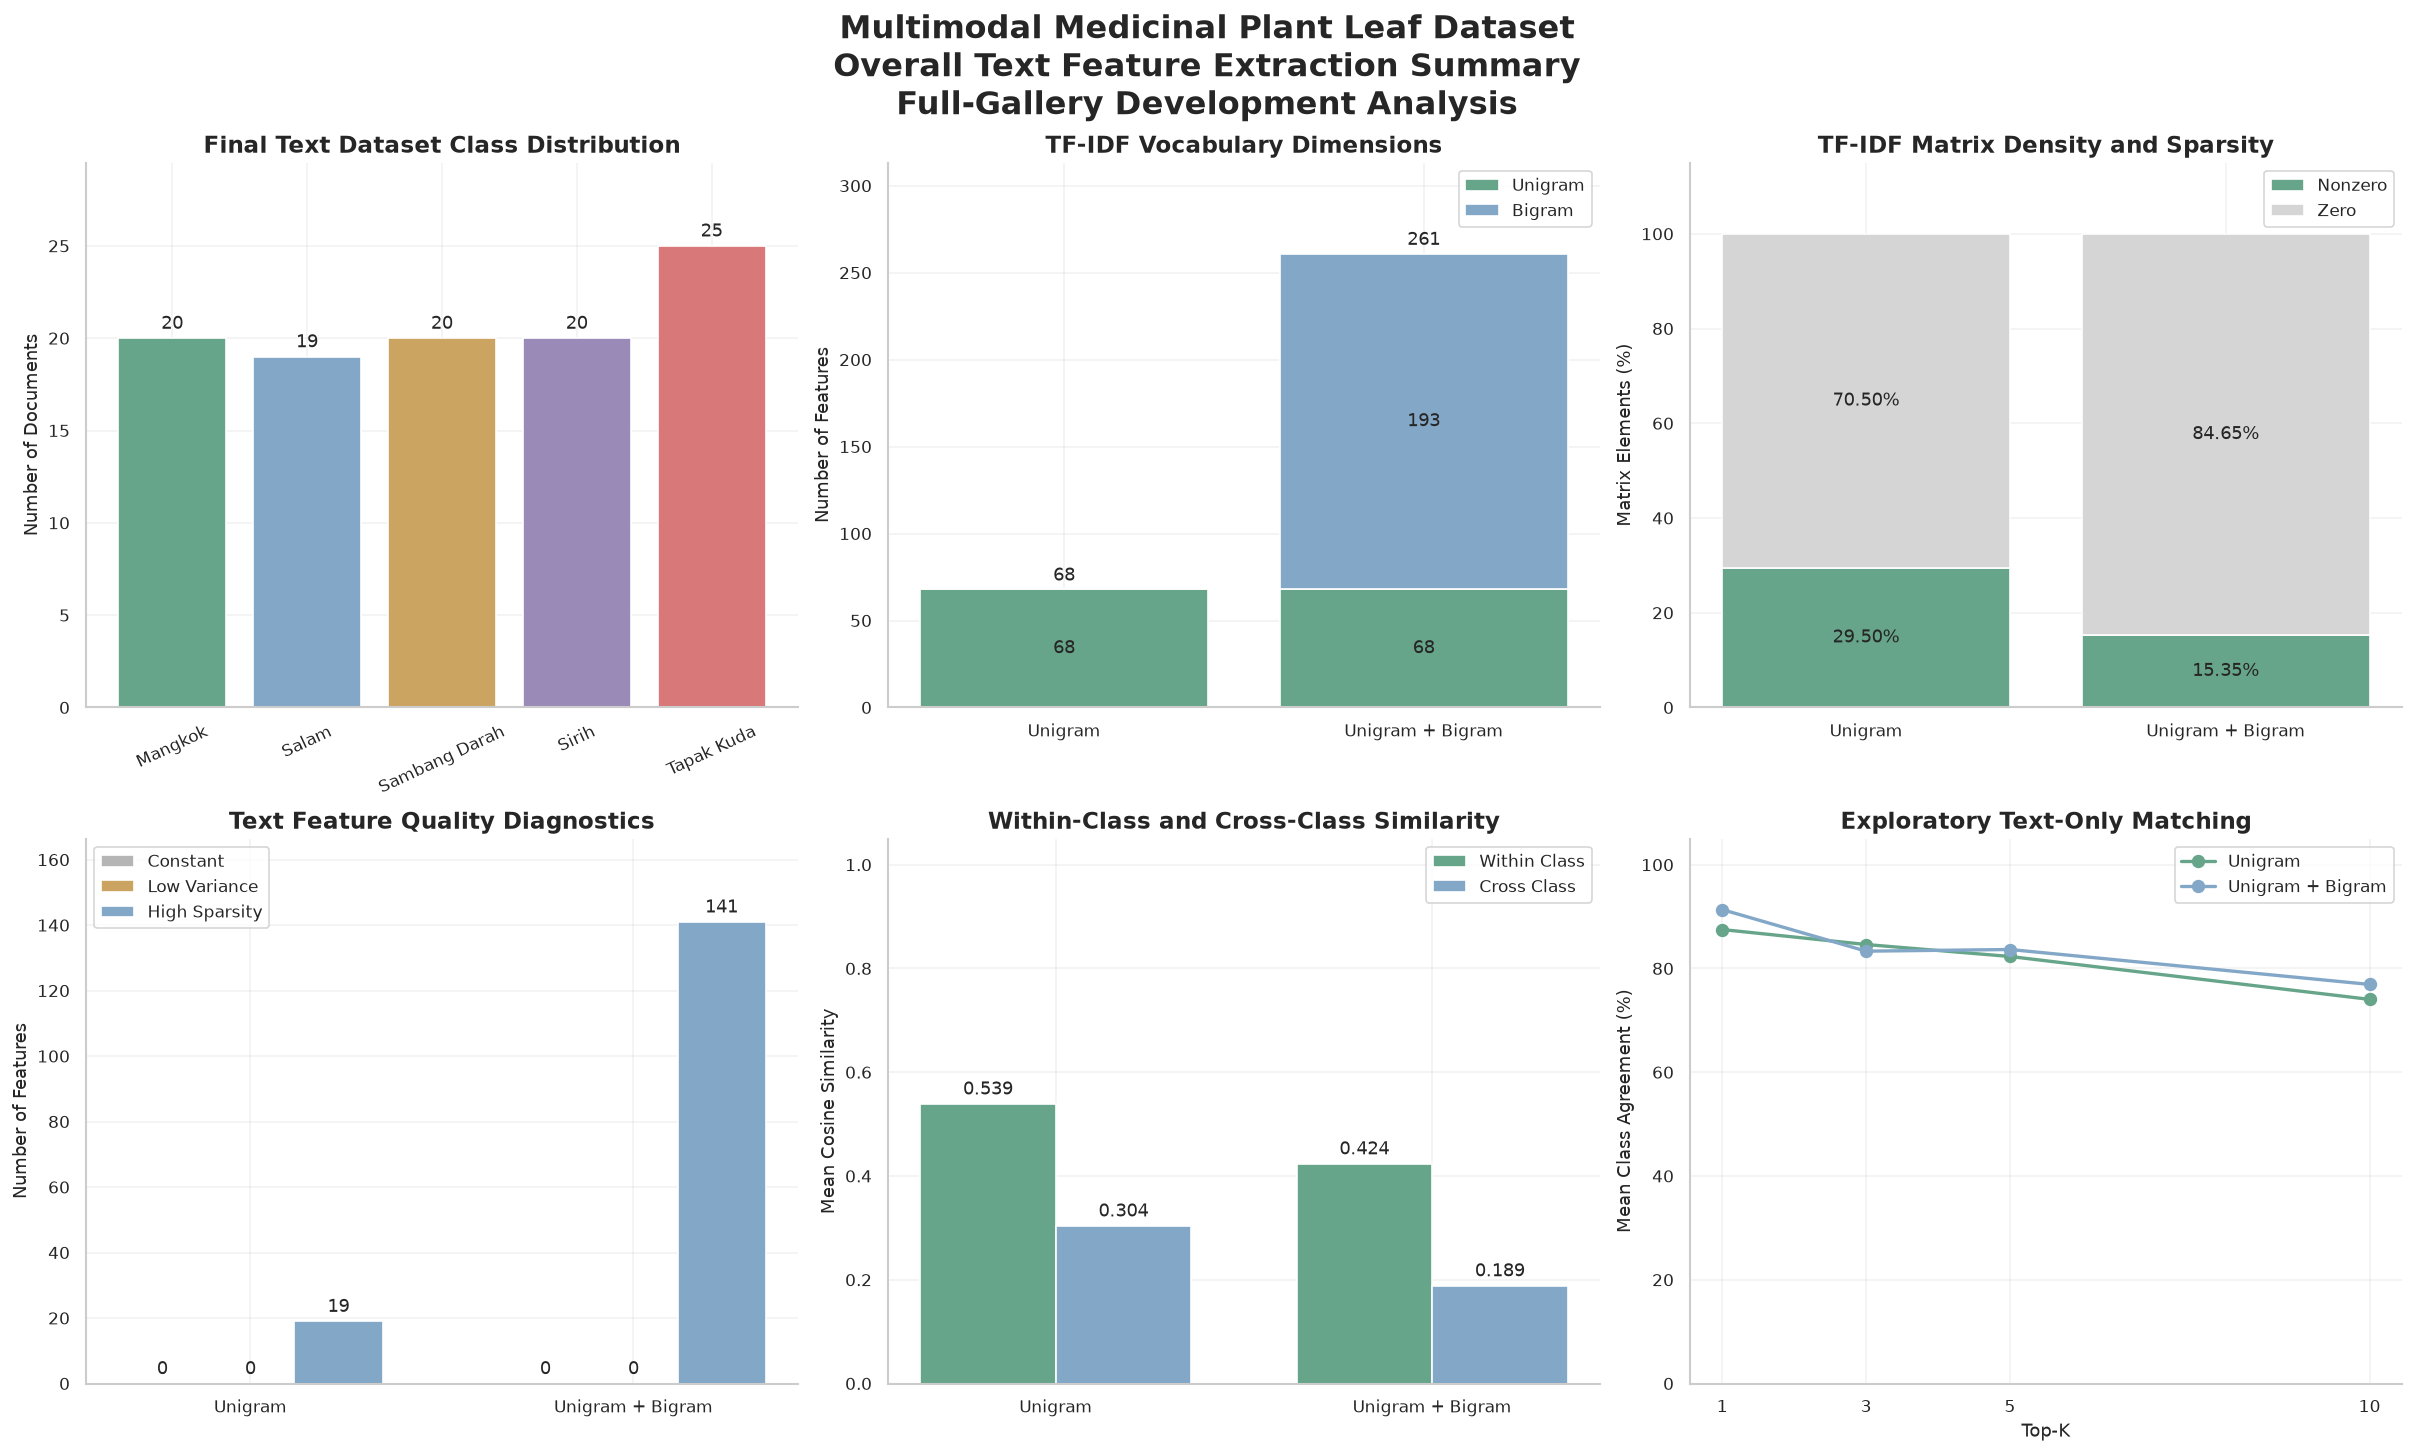

[SAVED] 101_overall_text_feature_extraction_summary.png


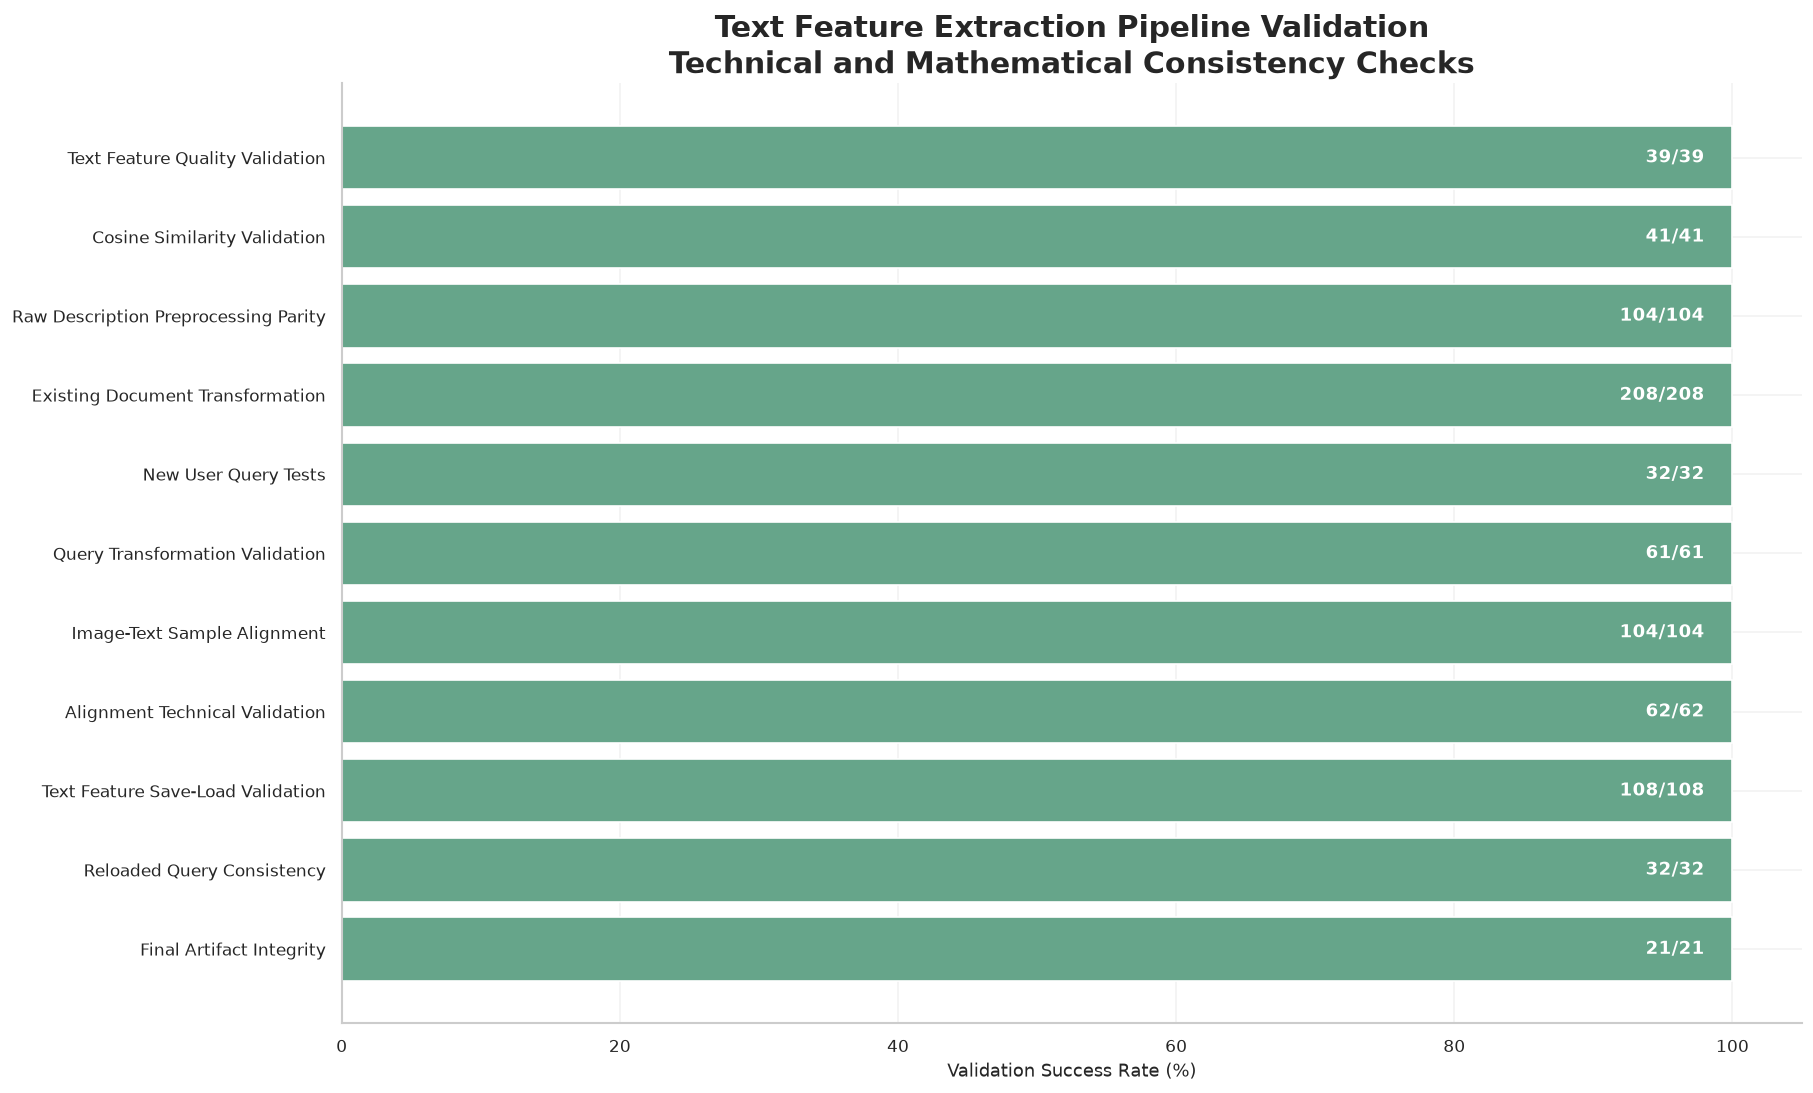

[SAVED] 102_text_feature_extraction_pipeline_validation.png


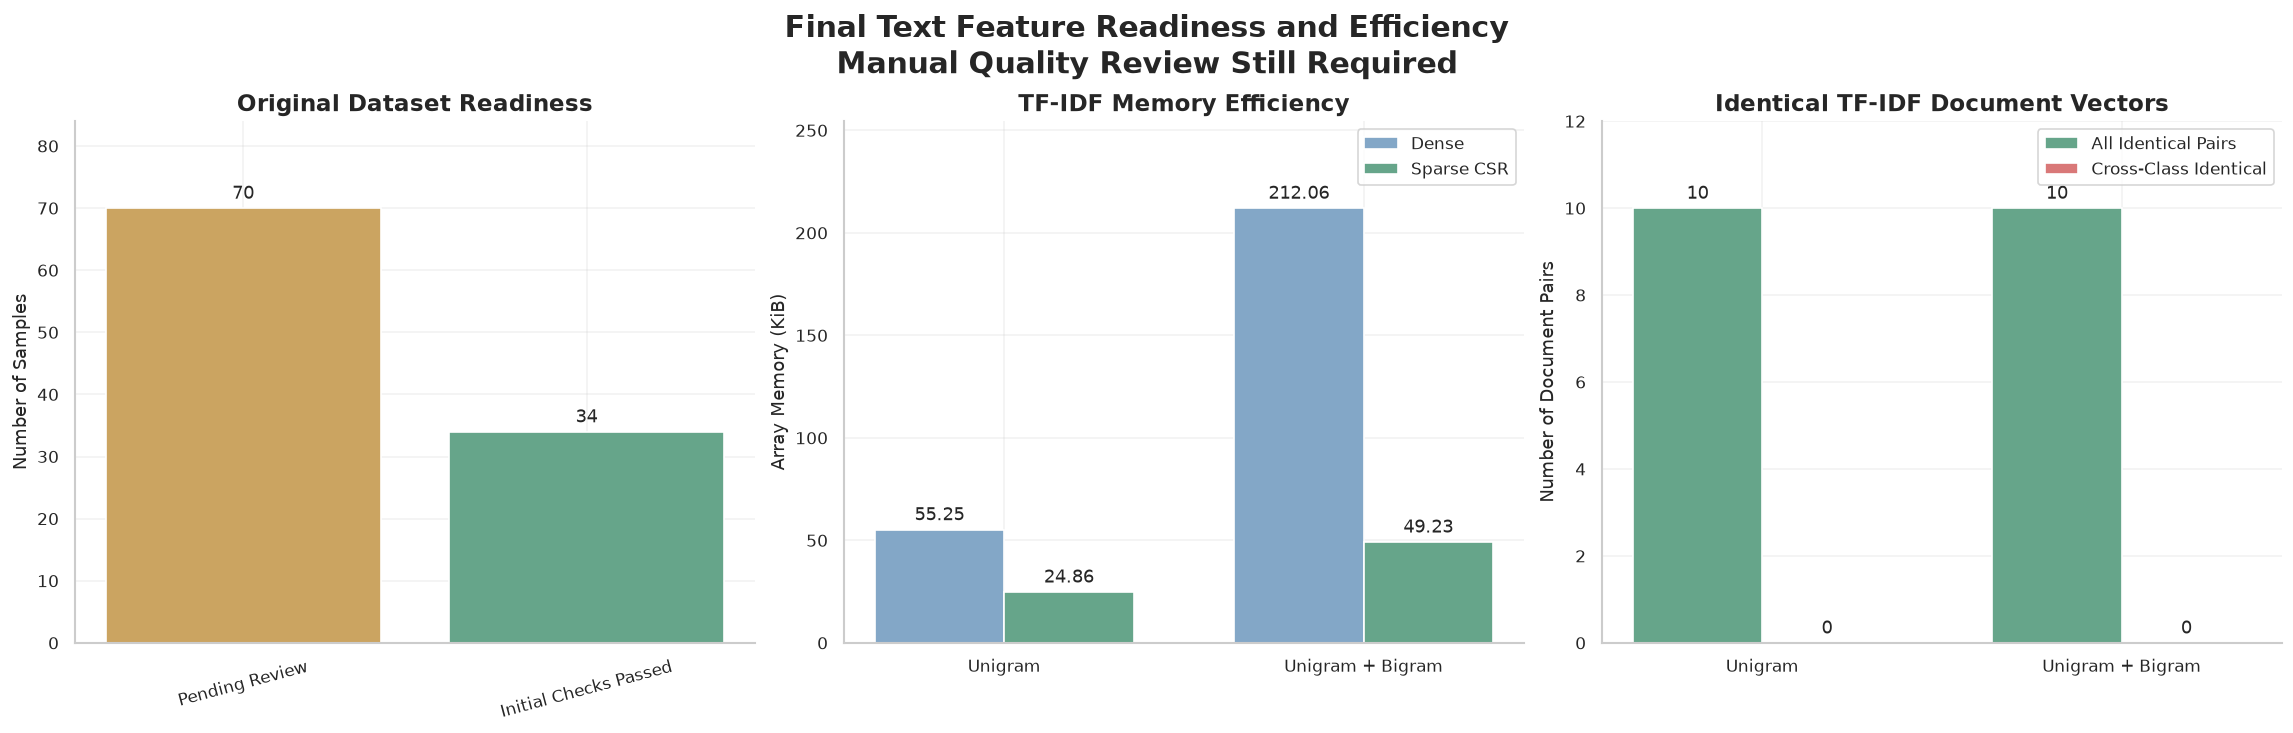

[SAVED] 103_final_text_feature_readiness_summary.png

13. FINAL TEXT FEATURE EXTRACTION SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Notebook,04_text_feature_extraction.ipynb
1,Total documents,104
2,Total classes,5
3,Mean document length,21.038462
4,Total word tokens,2188
5,TF-IDF configurations,2
6,Unigram feature dimension,68
7,Bigram feature dimension,193
8,Combined feature dimension,261
9,Unigram matrix shape,"(104, 68)"



14. SAVING FINAL SUMMARY REPORTS
----------------------------------------------------------------------
[SAVED] 335_final_text_class_distribution.csv
[SAVED] 336_final_document_length_summary.csv
[SAVED] 337_final_tfidf_feature_summary.csv
[SAVED] 338_final_text_feature_quality_summary.csv
[SAVED] 339_final_text_artifact_diagnostics.csv
[SAVED] 340_final_text_cosine_similarity_summary.csv
[SAVED] 341_final_exploratory_text_topk_summary.csv
[SAVED] 342_final_text_dataset_review_summary.csv
[SAVED] 343_final_text_artifact_integrity.csv
[SAVED] 344_text_pipeline_validation_summary.csv
[SAVED] 345_text_feature_research_limitations.csv
[SAVED] 346_text_feature_extraction_summary.csv
[SAVED] 347_text_feature_extraction_handoff.json

FINAL TEXT FEATURE EXTRACTION NOTEBOOK SUMMARY

DATASET INFORMATION
----------------------------------------------------------------------
Total documents     : 104
Total plant classes : 5
Mean document length: 21.0385
Total word tokens   : 2188

FEATURE EXTRACT

In [15]:
# ==================================================
# CELL 16 - TEXT FEATURE EXTRACTION SUMMARY
# ==================================================

import json
import hashlib

from pathlib import Path
from datetime import datetime, timezone
from scipy.spatial.distance import pdist
from scipy.sparse import issparse
from sklearn.metrics.pairwise import cosine_similarity

print("TEXT FEATURE EXTRACTION SUMMARY")
print("=" * 70)

TEXT_FEATURE_EXTRACTION_NOTEBOOK_COMPLETED = False


# ==================================================
# 1. VALIDATE PREVIOUS PROCESSING STAGES
# ==================================================

required_stages = [
    "TFIDF_FEATURE_EXTRACTION_COMPLETED",
    "TFIDF_MATRIX_ANALYSIS_COMPLETED",
    "TEXT_FEATURE_QUALITY_VALIDATION_COMPLETED",
    "COSINE_SIMILARITY_ANALYSIS_COMPLETED",
    "QUERY_TRANSFORMATION_CONSISTENCY_COMPLETED",
    "IMAGE_TEXT_ALIGNMENT_COMPLETED",
    "TEXT_FEATURE_SAVING_COMPLETED"
]

for stage in required_stages:

    assert globals().get(stage, False), (
        f"{stage} has not been completed. "
        "Run the previous cells first."
    )

print("[PASS] All required processing stages completed.")


# ==================================================
# 2. SUMMARY CONFIGURATION
# ==================================================

TEXT_SUMMARY_SCOPE = (
    "Full Dataset - Gallery Development"
)

TEXT_SUMMARY_TOLERANCE = 1e-10

SUMMARY_LOW_VARIANCE_THRESHOLD = 1e-6
SUMMARY_HIGH_SPARSITY_THRESHOLD = 0.95
SUMMARY_HIGH_CORRELATION_THRESHOLD = 0.95

TEXT_SUMMARY_COLORS = {
    TFIDF_BASELINE_NAME: "#66A58A",
    TFIDF_ALTERNATIVE_NAME: "#83A7C7"
}

TEXT_SUMMARY_CLASS_COLORS = {
    "Mangkok": "#66A58A",
    "Salam": "#83A7C7",
    "Sambang Darah": "#CBA461",
    "Sirih": "#998AB8",
    "Tapak Kuda": "#D97878"
}

text_summary_sample_ids = np.asarray(
    loaded_text_sample_ids,
    dtype=str
)

text_summary_labels = np.asarray(
    loaded_text_class_labels,
    dtype=str
)

text_summary_corpus = list(
    loaded_text_corpus
)

text_summary_n_samples = len(
    text_summary_sample_ids
)

text_summary_n_classes = len(
    np.unique(text_summary_labels)
)

text_summary_metadata_df = (
    df_multimodal_aligned.copy()
    .reset_index(drop=True)
)

text_summary_figure_paths = []

Path(METRICS_DIR).mkdir(
    parents=True,
    exist_ok=True
)

Path(TEXT_FEATURE_FIGURES_DIR).mkdir(
    parents=True,
    exist_ok=True
)

print("\n1. SUMMARY CONFIGURATION")
print("-" * 70)

print(f"Total documents : {text_summary_n_samples}")
print(f"Total classes   : {text_summary_n_classes}")
print(f"Analysis scope  : {TEXT_SUMMARY_SCOPE}")


# ==================================================
# 3. VALIDATE FINAL DATASET IDENTITY
# ==================================================

assert text_summary_n_samples == 104
assert text_summary_n_classes == 5

assert len(text_summary_corpus) == (
    text_summary_n_samples
)

assert len(text_summary_metadata_df) == (
    text_summary_n_samples
)

assert len(
    np.unique(text_summary_sample_ids)
) == text_summary_n_samples

assert np.array_equal(
    text_summary_sample_ids,
    multimodal_sample_ids
)

assert np.array_equal(
    text_summary_sample_ids,
    loaded_visual_sample_ids
)

assert np.array_equal(
    text_summary_labels,
    multimodal_labels
)

assert np.array_equal(
    text_summary_metadata_df[
        "sample_id"
    ].to_numpy(dtype=str),
    text_summary_sample_ids
)

assert np.array_equal(
    text_summary_metadata_df[
        "kelas"
    ].to_numpy(dtype=str),
    text_summary_labels
)

assert text_summary_corpus == list(
    validated_text_corpus
)

assert all(
    isinstance(document, str)
    and document.strip()
    for document in text_summary_corpus
)

print("[PASS] Final sample identity and corpus validated.")


# ==================================================
# 4. FINAL DATASET CLASS DISTRIBUTION
# ==================================================

text_final_class_summary_df = (
    pd.Series(
        text_summary_labels,
        name="kelas"
    )
    .value_counts()
    .sort_index()
    .rename_axis("kelas")
    .reset_index(name="number_of_documents")
)

text_final_class_summary_df["percentage"] = (
    text_final_class_summary_df[
        "number_of_documents"
    ]
    / text_summary_n_samples
    * 100
)

assert text_final_class_summary_df[
    "number_of_documents"
].sum() == text_summary_n_samples

print("\n2. FINAL DATASET CLASS DISTRIBUTION")
print("-" * 70)

display(
    text_final_class_summary_df.round(4)
)


# ==================================================
# 5. DOCUMENT LENGTH SUMMARY
# ==================================================

summary_unigram_analyzer = (
    loaded_text_vectorizers[
        TFIDF_BASELINE_NAME
    ].build_analyzer()
)

text_summary_document_lengths = np.asarray([
    len(summary_unigram_analyzer(document))
    for document in text_summary_corpus
])

text_document_length_summary_df = pd.DataFrame([{

    "total_documents": text_summary_n_samples,

    "total_tokens": int(
        text_summary_document_lengths.sum()
    ),

    "minimum_tokens": int(
        text_summary_document_lengths.min()
    ),

    "maximum_tokens": int(
        text_summary_document_lengths.max()
    ),

    "mean_tokens": float(
        text_summary_document_lengths.mean()
    ),

    "median_tokens": float(
        np.median(text_summary_document_lengths)
    ),

    "std_tokens": float(
        text_summary_document_lengths.std()
    ),

    "empty_documents": int(
        (text_summary_document_lengths == 0).sum()
    )

}])

print("\n3. DOCUMENT LENGTH SUMMARY")
print("-" * 70)

display(
    text_document_length_summary_df.round(6)
)


# ==================================================
# 6. FINAL TF-IDF FEATURE MATRIX SUMMARY
# ==================================================

text_final_feature_records = []

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    matrix = loaded_text_feature_matrices[
        configuration_name
    ]

    vectorizer = loaded_text_vectorizers[
        configuration_name
    ]

    feature_names = np.asarray(
        vectorizer.get_feature_names_out(),
        dtype=str
    )

    assert issparse(matrix)
    assert matrix.format == "csr"

    assert matrix.shape[0] == (
        text_summary_n_samples
    )

    assert matrix.shape[1] == len(
        feature_names
    )

    assert np.isfinite(matrix.data).all()
    assert np.all(matrix.data >= 0)

    total_elements = (
        matrix.shape[0]
        * matrix.shape[1]
    )

    nonzero_values = int(
        matrix.count_nonzero()
    )

    zero_values = (
        total_elements
        - nonzero_values
    )

    row_norms = np.sqrt(
        np.asarray(
            matrix.multiply(matrix).sum(axis=1)
        ).ravel()
    )

    active_features_per_document = np.asarray(
        (matrix != 0).sum(axis=1)
    ).ravel()

    unigram_count = sum(
        " " not in term
        for term in feature_names
    )

    bigram_count = sum(
        " " in term
        for term in feature_names
    )

    sparse_memory_bytes = (
        matrix.data.nbytes
        + matrix.indices.nbytes
        + matrix.indptr.nbytes
    )

    dense_memory_bytes = (
        total_elements
        * matrix.dtype.itemsize
    )

    assert np.allclose(
        row_norms,
        1.0,
        atol=TEXT_SUMMARY_TOLERANCE,
        rtol=0
    )

    text_final_feature_records.append({

        "configuration": configuration_name,

        "number_of_documents": matrix.shape[0],

        "feature_dimension": matrix.shape[1],

        "unigram_features": unigram_count,

        "bigram_features": bigram_count,

        "total_matrix_elements": total_elements,

        "nonzero_values": nonzero_values,

        "zero_values": zero_values,

        "density_percent": (
            nonzero_values
            / total_elements
            * 100
        ),

        "sparsity_percent": (
            zero_values
            / total_elements
            * 100
        ),

        "mean_active_features": float(
            active_features_per_document.mean()
        ),

        "minimum_active_features": int(
            active_features_per_document.min()
        ),

        "maximum_active_features": int(
            active_features_per_document.max()
        ),

        "minimum_nonzero_weight": float(
            matrix.data.min()
        ),

        "maximum_nonzero_weight": float(
            matrix.data.max()
        ),

        "minimum_idf": float(
            vectorizer.idf_.min()
        ),

        "maximum_idf": float(
            vectorizer.idf_.max()
        ),

        "minimum_l2_norm": float(
            row_norms.min()
        ),

        "maximum_l2_norm": float(
            row_norms.max()
        ),

        "zero_document_vectors": int(
            (row_norms == 0).sum()
        ),

        "nan_values": int(
            np.isnan(matrix.data).sum()
        ),

        "infinite_values": int(
            np.isinf(matrix.data).sum()
        ),

        "dense_memory_kib": (
            dense_memory_bytes / 1024
        ),

        "sparse_memory_kib": (
            sparse_memory_bytes / 1024
        ),

        "memory_reduction_percent": (
            1 - sparse_memory_bytes
            / dense_memory_bytes
        ) * 100,

        "matrix_format": matrix.format.upper(),

        "matrix_dtype": str(matrix.dtype)
    })


text_final_feature_summary_df = pd.DataFrame(
    text_final_feature_records
)

print("\n4. FINAL TF-IDF FEATURE SUMMARY")
print("-" * 70)

display(
    text_final_feature_summary_df[[
        "configuration",
        "number_of_documents",
        "feature_dimension",
        "unigram_features",
        "bigram_features",
        "nonzero_values",
        "sparsity_percent",
        "mean_active_features",
        "sparse_memory_kib"
    ]].round(6)
)


# ==================================================
# 7. FINAL TEXT FEATURE QUALITY DIAGNOSTICS
# ==================================================

# Diagnostic thresholds are retained explicitly.
# No feature selection or sample removal is performed.

text_final_quality_records = []

document_pair_i, document_pair_j = (
    np.triu_indices(
        text_summary_n_samples,
        k=1
    )
)

same_class_pair_mask = (
    text_summary_labels[document_pair_i]
    == text_summary_labels[document_pair_j]
)

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    matrix = loaded_text_feature_matrices[
        configuration_name
    ]

    # Dense conversion is used only for diagnostics.
    # Stored TF-IDF matrices remain sparse.

    dense_matrix = matrix.toarray()

    feature_variances = np.var(
        dense_matrix,
        axis=0
    )

    feature_zero_ratios = np.mean(
        dense_matrix == 0,
        axis=0
    )

    constant_mask = (
        np.ptp(
            dense_matrix,
            axis=0
        ) == 0
    )

    low_variance_mask = (
        ~constant_mask
        &
        (
            feature_variances
            < SUMMARY_LOW_VARIANCE_THRESHOLD
        )
    )

    high_sparsity_mask = (
        feature_zero_ratios
        >= SUMMARY_HIGH_SPARSITY_THRESHOLD
    )

    nonconstant_matrix = dense_matrix[
        :,
        ~constant_mask
    ]

    if nonconstant_matrix.shape[1] >= 2:

        correlation_matrix = np.corrcoef(
            nonconstant_matrix,
            rowvar=False
        )

        correlation_i, correlation_j = (
            np.triu_indices(
                correlation_matrix.shape[0],
                k=1
            )
        )

        correlation_values = correlation_matrix[
            correlation_i,
            correlation_j
        ]

        high_correlation_pairs = int(
            np.sum(
                np.isfinite(correlation_values)
                &
                (
                    np.abs(correlation_values)
                    >= SUMMARY_HIGH_CORRELATION_THRESHOLD
                )
            )
        )

    else:

        high_correlation_pairs = 0

    # Numerically identical feature columns.

    feature_pair_distances = pdist(
        dense_matrix.T,
        metric="chebyshev"
    )

    identical_feature_pairs = int(
        np.sum(
            feature_pair_distances
            <= TEXT_SUMMARY_TOLERANCE
        )
    )

    # Numerically identical document vectors.

    document_pair_distances = pdist(
        dense_matrix,
        metric="chebyshev"
    )

    identical_document_mask = (
        document_pair_distances
        <= TEXT_SUMMARY_TOLERANCE
    )

    identical_document_pairs = int(
        identical_document_mask.sum()
    )

    identical_cross_class_pairs = int(
        (
            identical_document_mask
            &
            ~same_class_pair_mask
        ).sum()
    )

    text_final_quality_records.append({

        "configuration": configuration_name,

        "feature_dimension": matrix.shape[1],

        "constant_features": int(
            constant_mask.sum()
        ),

        "low_variance_features": int(
            low_variance_mask.sum()
        ),

        "high_sparsity_features": int(
            high_sparsity_mask.sum()
        ),

        "high_correlation_pairs":
            high_correlation_pairs,

        "identical_feature_pairs":
            identical_feature_pairs,

        "identical_document_pairs":
            identical_document_pairs,

        "identical_cross_class_pairs":
            identical_cross_class_pairs,

        "low_variance_threshold":
            SUMMARY_LOW_VARIANCE_THRESHOLD,

        "high_sparsity_threshold":
            SUMMARY_HIGH_SPARSITY_THRESHOLD,

        "high_correlation_threshold":
            SUMMARY_HIGH_CORRELATION_THRESHOLD,

        "identical_vector_tolerance":
            TEXT_SUMMARY_TOLERANCE,

        "features_removed": 0,

        "samples_removed": 0
    })


text_final_quality_summary_df = pd.DataFrame(
    text_final_quality_records
)

print("\n5. FINAL TEXT FEATURE QUALITY")
print("-" * 70)

display(
    text_final_quality_summary_df[[
        "configuration",
        "constant_features",
        "low_variance_features",
        "high_sparsity_features",
        "high_correlation_pairs",
        "identical_feature_pairs",
        "identical_document_pairs",
        "identical_cross_class_pairs"
    ]]
)


# ==================================================
# 8. WRITING ARTIFACT DIAGNOSTICS
# ==================================================

# Potential artifacts identified in Cell 10.
# These are diagnostics, not automatically removed.

summary_flagged_artifact_terms = [
    "membulat permukaan",
    "meruncing permukaan",
    "runcing permukaan",
    "berbentuk berbentuk"
]

text_final_artifact_records = []

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    matrix = loaded_text_feature_matrices[
        configuration_name
    ]

    vectorizer = loaded_text_vectorizers[
        configuration_name
    ]

    vocabulary = vectorizer.vocabulary_

    artifact_indices = [
        vocabulary[term]
        for term in summary_flagged_artifact_terms
        if term in vocabulary
    ]

    total_energy = np.asarray(
        matrix.multiply(matrix).sum(axis=1)
    ).ravel()

    if artifact_indices:

        artifact_matrix = matrix[
            :,
            artifact_indices
        ]

        artifact_energy = np.asarray(
            artifact_matrix.multiply(
                artifact_matrix
            ).sum(axis=1)
        ).ravel()

    else:

        artifact_energy = np.zeros(
            text_summary_n_samples
        )

    artifact_share = np.divide(

        artifact_energy,

        total_energy,

        out=np.zeros_like(artifact_energy),

        where=total_energy > 0

    ) * 100

    text_final_artifact_records.append({

        "configuration": configuration_name,

        "flagged_artifact_features":
            len(artifact_indices),

        "documents_with_flagged_features": int(
            (artifact_energy > 0).sum()
        ),

        "mean_artifact_energy_percent": float(
            artifact_share.mean()
        ),

        "maximum_artifact_energy_percent": float(
            artifact_share.max()
        ),

        "automatic_removal_applied": False,

        "manual_review_required": True
    })


text_final_artifact_summary_df = pd.DataFrame(
    text_final_artifact_records
)

print("\n6. WRITING ARTIFACT SUMMARY")
print("-" * 70)

display(
    text_final_artifact_summary_df.round(6)
)


# ==================================================
# 9. FINAL COSINE SIMILARITY SUMMARY
# ==================================================

text_final_cosine_records = []

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    matrix = loaded_text_feature_matrices[
        configuration_name
    ]

    similarity_matrix = cosine_similarity(
        matrix
    )

    pairwise_scores = similarity_matrix[
        document_pair_i,
        document_pair_j
    ]

    within_class_scores = pairwise_scores[
        same_class_pair_mask
    ]

    cross_class_scores = pairwise_scores[
        ~same_class_pair_mask
    ]

    within_mean = float(
        within_class_scores.mean()
    )

    cross_mean = float(
        cross_class_scores.mean()
    )

    similarity_gap = (
        within_mean - cross_mean
    )

    text_final_cosine_records.append({

        "configuration": configuration_name,

        "total_unique_pairs": len(
            pairwise_scores
        ),

        "within_class_pairs": len(
            within_class_scores
        ),

        "cross_class_pairs": len(
            cross_class_scores
        ),

        "overall_mean_similarity": float(
            pairwise_scores.mean()
        ),

        "within_class_mean": within_mean,

        "cross_class_mean": cross_mean,

        "mean_similarity_gap": similarity_gap,

        "within_class_median": float(
            np.median(within_class_scores)
        ),

        "cross_class_median": float(
            np.median(cross_class_scores)
        ),

        "within_class_std": float(
            within_class_scores.std()
        ),

        "cross_class_std": float(
            cross_class_scores.std()
        ),

        "maximum_cross_class_similarity": float(
            cross_class_scores.max()
        ),

        "self_matches_excluded": True,

        "analysis_scope": TEXT_SUMMARY_SCOPE
    })


text_final_cosine_summary_df = pd.DataFrame(
    text_final_cosine_records
)

print("\n7. FINAL COSINE SIMILARITY SUMMARY")
print("-" * 70)

display(
    text_final_cosine_summary_df[[
        "configuration",
        "total_unique_pairs",
        "within_class_mean",
        "cross_class_mean",
        "mean_similarity_gap",
        "maximum_cross_class_similarity"
    ]].round(6)
)


# ==================================================
# 10. EXPLORATORY TOP-K CLASS AGREEMENT
# ==================================================

# This is full-gallery analysis, not independent
# retrieval evaluation.

SUMMARY_TOP_K_VALUES = [1, 3, 5, 10]

text_final_topk_records = []

for configuration_name in TFIDF_CONFIGURATION_ORDER:

    matrix = loaded_text_feature_matrices[
        configuration_name
    ]

    similarity_matrix = np.clip(
        cosine_similarity(matrix),
        0.0,
        1.0
    )

    rankings = []

    for query_index in range(
        text_summary_n_samples
    ):

        candidates = np.arange(
            text_summary_n_samples
        )

        # Exclude the query itself.

        candidates = candidates[
            candidates != query_index
        ]

        ranking_order = np.lexsort((

            text_summary_sample_ids[candidates],

            -similarity_matrix[
                query_index,
                candidates
            ]

        ))

        rankings.append(
            candidates[ranking_order]
        )

    for top_k in SUMMARY_TOP_K_VALUES:

        query_agreements = []

        for query_index, ranked_indices in enumerate(
            rankings
        ):

            retrieved_indices = ranked_indices[
                :top_k
            ]

            relevant_mask = (
                text_summary_labels[retrieved_indices]
                ==
                text_summary_labels[query_index]
            )

            query_agreements.append(
                relevant_mask.mean()
            )

        text_final_topk_records.append({

            "configuration": configuration_name,

            "top_k": top_k,

            "number_of_queries":
                text_summary_n_samples,

            "mean_class_agreement_percent": float(
                np.mean(query_agreements) * 100
            ),

            "std_class_agreement_percent": float(
                np.std(query_agreements) * 100
            ),

            "self_matches_excluded": True,

            "independent_evaluation": False,

            "analysis_scope": TEXT_SUMMARY_SCOPE
        })


text_final_topk_summary_df = pd.DataFrame(
    text_final_topk_records
)

print("\n8. EXPLORATORY TOP-K MATCHING SUMMARY")
print("-" * 70)

display(
    text_final_topk_summary_df.pivot(

        index="top_k",

        columns="configuration",

        values="mean_class_agreement_percent"

    ).round(4)
)


# ==================================================
# 11. FINAL DATASET REVIEW STATUS
# ==================================================

# Preserve original source dataset readiness.
# Do not confuse it with Cell 11 text-feature review.

text_final_review_summary_df = (
    text_summary_metadata_df[
        "source_dataset_status"
    ]
    .value_counts(dropna=False)
    .rename_axis("source_dataset_status")
    .reset_index(name="number_of_samples")
)

text_final_review_summary_df["percentage"] = (
    text_final_review_summary_df[
        "number_of_samples"
    ]
    / text_summary_n_samples
    * 100
)

assert text_final_review_summary_df[
    "number_of_samples"
].sum() == text_summary_n_samples

print("\n9. ORIGINAL DATASET REVIEW STATUS")
print("-" * 70)

display(
    text_final_review_summary_df.round(4)
)

print(
    "[INFO] Original review flags remain unchanged."
)

print(
    "[INFO] Text-specific quality diagnostics "
    "remain applicable."
)


# ==================================================
# 12. FINAL ARTIFACT INTEGRITY VERIFICATION
# ==================================================

text_final_integrity_records = []

final_text_manifest_path = (
    Path(TEXT_FEATURE_SAVE_DIR)
    / "text_feature_artifact_manifest.csv"
)

assert final_text_manifest_path.is_file()

final_text_manifest_df = pd.read_csv(

    final_text_manifest_path,

    dtype={
        "filename": str,
        "relative_path": str,
        "sha256": str
    }

)

assert final_text_manifest_df[
    "filename"
].is_unique

for row in final_text_manifest_df.itertuples():

    artifact_path = (
        Path(text_save_project_root)
        / row.relative_path
    )

    exists = artifact_path.is_file()

    if exists:

        actual_size = (
            artifact_path.stat().st_size
        )

        actual_sha256 = hashlib.sha256(
            artifact_path.read_bytes()
        ).hexdigest()

    else:

        actual_size = 0
        actual_sha256 = ""

    size_match = (
        actual_size == row.size_bytes
    )

    checksum_match = (
        actual_sha256 == row.sha256
    )

    text_final_integrity_records.append({

        "filename": row.filename,

        "modality": "Text",

        "file_exists": exists,

        "size_bytes": actual_size,

        "size_match": size_match,

        "checksum_match": checksum_match,

        "passed": bool(
            exists
            and size_match
            and checksum_match
        )
    })


# Also verify the visual artifacts referenced
# by the saved text feature configuration.

for artifact_name, artifact_info in (
    loaded_text_feature_config[
        "visual_artifact_checksums"
    ].items()
):

    artifact_path = Path(
        alignment_input_paths[
            artifact_name
        ]
    )

    exists = artifact_path.is_file()

    actual_sha256 = (
        hashlib.sha256(
            artifact_path.read_bytes()
        ).hexdigest()
        if exists
        else ""
    )

    checksum_match = (
        actual_sha256
        == artifact_info["sha256"]
    )

    filename_match = (
        artifact_path.name
        == artifact_info["filename"]
    )

    text_final_integrity_records.append({

        "filename": artifact_path.name,

        "modality": "Visual",

        "file_exists": exists,

        "size_bytes": (
            artifact_path.stat().st_size
            if exists
            else 0
        ),

        "size_match": None,

        "checksum_match": checksum_match,

        "passed": bool(
            exists
            and checksum_match
            and filename_match
        )
    })


text_final_integrity_df = pd.DataFrame(
    text_final_integrity_records
)

print("\n10. FINAL ARTIFACT INTEGRITY")
print("-" * 70)

display(text_final_integrity_df)

assert text_final_integrity_df["passed"].all(), (
    text_final_integrity_df.loc[
        ~text_final_integrity_df["passed"]
    ].to_string(index=False)
)

print("[PASS] Saved feature artifacts remain intact.")


# ==================================================
# 13. CONSOLIDATE PIPELINE VALIDATION RESULTS
# ==================================================

text_pipeline_validation_records = []


def add_pipeline_validation(
    stage_name,
    passed_values
):

    values = pd.Series(passed_values)

    assert len(values) > 0

    assert values.notna().all()

    assert values.isin(
        [True, False]
    ).all()

    total_checks = len(values)

    passed_checks = int(
        values.astype(bool).sum()
    )

    text_pipeline_validation_records.append({

        "validation_stage": stage_name,

        "total_checks": total_checks,

        "passed_checks": passed_checks,

        "failed_checks": (
            total_checks
            - passed_checks
        ),

        "success_rate_percent": (
            passed_checks
            / total_checks
            * 100
        ),

        "status": (
            "Passed"
            if passed_checks == total_checks
            else "Failed"
        )
    })


# Cell 11 - Feature quality validation.

add_pipeline_validation(

    "Text Feature Quality Validation",

    tfidf_quality_validation_df[
        "passed"
    ]
)


# Cell 12 - Cosine similarity validation.

add_pipeline_validation(

    "Cosine Similarity Validation",

    tfidf_cosine_validation_df[
        "passed"
    ]
)


# Cell 13 - Raw query preprocessing.

add_pipeline_validation(

    "Raw Description Preprocessing Parity",

    query_preprocessing_parity_df[
        "matches_validated_corpus"
    ]
)


# Cell 13 - Existing document transformation.

add_pipeline_validation(

    "Existing Document Transformation",

    tfidf_query_transformation_consistency_df[
        "passed"
    ]
)


# Cell 13 - New user queries.

add_pipeline_validation(

    "New User Query Tests",

    tfidf_query_test_results_df[
        "passed"
    ]
)


# Cell 13 - Overall query validation.

add_pipeline_validation(

    "Query Transformation Validation",

    tfidf_query_validation_df[
        "passed"
    ]
)


# Cell 14 - Sample-level alignment.

add_pipeline_validation(

    "Image-Text Sample Alignment",

    alignment_record_df[
        "alignment_passed"
    ]
)


# Cell 14 - Technical alignment validation.

add_pipeline_validation(

    "Alignment Technical Validation",

    alignment_validation_df[
        "passed"
    ]
)


# Cell 15 - Save-load validation.

add_pipeline_validation(

    "Text Feature Save-Load Validation",

    text_save_validation_df[
        "passed"
    ]
)


# Cell 15 - Reloaded query validation.

add_pipeline_validation(

    "Reloaded Query Consistency",

    text_saved_query_validation_df[
        "passed"
    ]
)


# Cell 16 - Artifact integrity validation.

add_pipeline_validation(

    "Final Artifact Integrity",

    text_final_integrity_df[
        "passed"
    ]
)


text_pipeline_validation_summary_df = pd.DataFrame(
    text_pipeline_validation_records
)

print("\n11. OVERALL PIPELINE VALIDATION")
print("-" * 70)

display(
    text_pipeline_validation_summary_df.round(4)
)

assert text_pipeline_validation_summary_df[
    "failed_checks"
].eq(0).all()

# These validation categories overlap.
# Therefore, do not sum them and interpret the
# result as independent validation observations.

print(
    "[PASS] All summarized technical "
    "validation stages passed."
)


# ==================================================
# 14. DOCUMENT RESEARCH LIMITATIONS
# ==================================================

text_research_limitations_df = pd.DataFrame([

    {
        "limitation": "Small Dataset",

        "description": (
            "The dataset contains 104 paired samples "
            "from five medicinal plant classes."
        ),

        "implication": (
            "External generalization has not been established."
        ),

        "recommended_action": (
            "Collect independent samples and "
            "additional plant specimens."
        ),

        "status": "Remaining Limitation"
    },

    {
        "limitation": "Description Duplication",

        "description": (
            "Some documents produce numerically "
            "identical TF-IDF vectors."
        ),

        "implication": (
            "Duplicate descriptions can produce "
            "similarity ties and optimistic retrieval results."
        ),

        "recommended_action": (
            "Audit duplicate groups and specimen identity "
            "before constructing evaluation splits."
        ),

        "status": "Manual Review Required"
    },

    {
        "limitation": "Cross-Class Vocabulary Overlap",

        "description": (
            "Different plant classes may share "
            "similar morphological descriptions."
        ),

        "implication": (
            "Text-only retrieval may confuse "
            "plants with similar textual characteristics."
        ),

        "recommended_action": (
            "Evaluate complementary visual information "
            "through multimodal fusion."
        ),

        "status": "To Be Evaluated"
    },

    {
        "limitation": "Potential Writing Artifacts",

        "description": (
            "Some bigrams may originate from sentence "
            "boundaries or adjacent repeated words."
        ),

        "implication": (
            "Text representation may contain "
            "writing-pattern information."
        ),

        "recommended_action": (
            "Manually review flagged descriptions and "
            "compare a corrected corpus if appropriate."
        ),

        "status": "Manual Review Required"
    },

    {
        "limitation": "Sparse and Redundant Features",

        "description": (
            "Some TF-IDF features are rare, highly "
            "correlated, or numerically identical."
        ),

        "implication": (
            "Additional dimensions do not necessarily "
            "provide independent information."
        ),

        "recommended_action": (
            "Evaluate feature configurations without "
            "automatic full-gallery feature removal."
        ),

        "status": "Retained for Comparison"
    },

    {
        "limitation": "Out-of-Vocabulary Queries",

        "description": (
            "TF-IDF depends on vocabulary learned "
            "from reference documents."
        ),

        "implication": (
            "Unseen words may be ignored or "
            "produce an unusable zero vector."
        ),

        "recommended_action": (
            "Apply OOV detection and appropriate "
            "single-modality fallback."
        ),

        "status": "Handling Implemented"
    },

    {
        "limitation": "Full-Gallery Fitting",

        "description": (
            "Current vectorizers and visual normalizers "
            "were fitted using the complete gallery."
        ),

        "implication": (
            "Exploratory matching does not constitute "
            "independent retrieval evaluation."
        ),

        "recommended_action": (
            "Refit vocabulary, IDF, and visual normalization "
            "using reference data only for each evaluation split."
        ),

        "status": "Independent Evaluation Required"
    },

    {
        "limitation": "Manual Dataset Quality Review",

        "description": (
            "Original dataset review flags and "
            "text-specific diagnostic flags remain unresolved."
        ),

        "implication": (
            "Technical validity does not establish "
            "botanical or semantic correctness."
        ),

        "recommended_action": (
            "Complete manual quality review and "
            "document inclusion decisions."
        ),

        "status": "Manual Review Required"
    },

    {
        "limitation": "Text Configuration Selection",

        "description": (
            "Both unigram and unigram-bigram "
            "configurations remain available."
        ),

        "implication": (
            "The better configuration has not been "
            "established independently."
        ),

        "recommended_action": (
            "Select configuration and fusion weights "
            "using validation data, not final test data."
        ),

        "status": "Configuration Not Selected"
    }

])

print("\n12. RESEARCH LIMITATIONS")
print("-" * 70)

display(
    text_research_limitations_df[[
        "limitation",
        "status"
    ]]
)


# ==================================================
# 15. VISUALIZATION HELPER
# ==================================================

def save_text_summary_figure(
    figure,
    filename
):

    output_path = (
        Path(TEXT_FEATURE_FIGURES_DIR)
        / filename
    )

    figure.savefig(

        output_path,

        dpi=300,

        bbox_inches="tight"

    )

    text_summary_figure_paths.append(
        output_path
    )

    plt.show()
    plt.close(figure)

    print(f"[SAVED] {filename}")


# ==================================================
# 16. VISUALIZE OVERALL TEXT FEATURE SUMMARY
# ==================================================

fig, axes = plt.subplots(

    2, 3,

    figsize=(20, 12),

    constrained_layout=True

)

configuration_names = list(
    TFIDF_CONFIGURATION_ORDER
)

configuration_colors = [
    TEXT_SUMMARY_COLORS[name]
    for name in configuration_names
]

feature_plot_df = (
    text_final_feature_summary_df
    .set_index("configuration")
    .loc[configuration_names]
)

quality_plot_df = (
    text_final_quality_summary_df
    .set_index("configuration")
    .loc[configuration_names]
)

cosine_plot_df = (
    text_final_cosine_summary_df
    .set_index("configuration")
    .loc[configuration_names]
)


# --------------------------------------------------
# A. Final dataset class distribution
# --------------------------------------------------

ax = axes[0, 0]

class_names = text_final_class_summary_df[
    "kelas"
].tolist()

bars = ax.bar(

    class_names,

    text_final_class_summary_df[
        "number_of_documents"
    ],

    color=[
        TEXT_SUMMARY_CLASS_COLORS.get(
            name,
            "#83A7C7"
        )
        for name in class_names
    ]

)

ax.bar_label(
    bars,
    padding=3
)

ax.set_title(
    "Final Text Dataset Class Distribution"
)

ax.set_ylabel(
    "Number of Documents"
)

ax.tick_params(
    axis="x",
    labelrotation=25
)

ax.margins(y=0.18)


# --------------------------------------------------
# B. Vocabulary and feature dimensions
# --------------------------------------------------

ax = axes[0, 1]

bars_unigram = ax.bar(

    configuration_names,

    feature_plot_df[
        "unigram_features"
    ],

    color="#66A58A",

    label="Unigram"

)

bars_bigram = ax.bar(

    configuration_names,

    feature_plot_df[
        "bigram_features"
    ],

    bottom=feature_plot_df[
        "unigram_features"
    ],

    color="#83A7C7",

    label="Bigram"

)

ax.bar_label(

    bars_unigram,

    label_type="center"

)

ax.bar_label(

    bars_bigram,

    labels=[
        str(value) if value > 0 else ""
        for value in feature_plot_df[
            "bigram_features"
        ]
    ],

    label_type="center"

)

for i, dimension in enumerate(
    feature_plot_df["feature_dimension"]
):

    ax.text(

        i,

        dimension + 5,

        str(dimension),

        ha="center"

    )

ax.set_title(
    "TF-IDF Vocabulary Dimensions"
)

ax.set_ylabel(
    "Number of Features"
)

ax.margins(y=0.2)

ax.legend()


# --------------------------------------------------
# C. Matrix sparsity
# --------------------------------------------------

ax = axes[0, 2]

bars_density = ax.bar(

    configuration_names,

    feature_plot_df[
        "density_percent"
    ],

    color="#66A58A",

    label="Nonzero"

)

bars_sparsity = ax.bar(

    configuration_names,

    feature_plot_df[
        "sparsity_percent"
    ],

    bottom=feature_plot_df[
        "density_percent"
    ],

    color="#D5D5D5",

    label="Zero"

)

ax.bar_label(

    bars_density,

    fmt="%.2f%%",

    label_type="center"

)

ax.bar_label(

    bars_sparsity,

    fmt="%.2f%%",

    label_type="center"

)

ax.set_ylim(0, 115)

ax.set_title(
    "TF-IDF Matrix Density and Sparsity"
)

ax.set_ylabel(
    "Matrix Elements (%)"
)

ax.legend()


# --------------------------------------------------
# D. Feature quality diagnostics
# --------------------------------------------------

ax = axes[1, 0]

positions = np.arange(
    len(configuration_names)
)

bar_width = 0.23

quality_columns = [

    (
        "constant_features",
        "Constant",
        "#B5B5B5"
    ),

    (
        "low_variance_features",
        "Low Variance",
        "#CBA461"
    ),

    (
        "high_sparsity_features",
        "High Sparsity",
        "#83A7C7"
    )
]

for i, (column, label, color) in enumerate(
    quality_columns
):

    bars = ax.bar(

        positions + (i - 1) * bar_width,

        quality_plot_df[column],

        width=bar_width,

        label=label,

        color=color

    )

    ax.bar_label(
        bars,
        padding=3
    )

ax.set_xticks(positions)

ax.set_xticklabels(
    configuration_names
)

ax.set_ylabel(
    "Number of Features"
)

ax.set_title(
    "Text Feature Quality Diagnostics"
)

ax.margins(y=0.18)

ax.legend()


# --------------------------------------------------
# E. Within-class and cross-class similarity
# --------------------------------------------------

ax = axes[1, 1]

bars_within = ax.bar(

    positions - 0.18,

    cosine_plot_df[
        "within_class_mean"
    ],

    width=0.36,

    color="#66A58A",

    label="Within Class"

)

bars_cross = ax.bar(

    positions + 0.18,

    cosine_plot_df[
        "cross_class_mean"
    ],

    width=0.36,

    color="#83A7C7",

    label="Cross Class"

)

ax.bar_label(

    bars_within,

    fmt="%.3f",

    padding=3

)

ax.bar_label(

    bars_cross,

    fmt="%.3f",

    padding=3

)

ax.set_xticks(positions)

ax.set_xticklabels(
    configuration_names
)

ax.set_ylim(0, 1.05)

ax.set_ylabel(
    "Mean Cosine Similarity"
)

ax.set_title(
    "Within-Class and Cross-Class Similarity"
)

ax.legend()


# --------------------------------------------------
# F. Exploratory Top-K class agreement
# --------------------------------------------------

ax = axes[1, 2]

for configuration_name in configuration_names:

    subset = text_final_topk_summary_df.loc[
        text_final_topk_summary_df[
            "configuration"
        ].eq(configuration_name)
    ].sort_values("top_k")

    ax.plot(

        subset["top_k"],

        subset[
            "mean_class_agreement_percent"
        ],

        marker="o",

        linewidth=2,

        markersize=7,

        color=TEXT_SUMMARY_COLORS[
            configuration_name
        ],

        label=configuration_name

    )

ax.set_xticks(
    SUMMARY_TOP_K_VALUES
)

ax.set_ylim(0, 105)

ax.set_xlabel(
    "Top-K"
)

ax.set_ylabel(
    "Mean Class Agreement (%)"
)

ax.set_title(
    "Exploratory Text-Only Matching"
)

ax.legend()

fig.suptitle(

    "Multimodal Medicinal Plant Leaf Dataset\n"
    "Overall Text Feature Extraction Summary\n"
    "Full-Gallery Development Analysis",

    fontsize=19,

    fontweight="bold"

)

save_text_summary_figure(

    fig,

    "101_overall_text_feature_extraction_summary.png"

)


# ==================================================
# 17. VISUALIZE PIPELINE VALIDATION SUMMARY
# ==================================================

fig, ax = plt.subplots(

    figsize=(15, 9),

    constrained_layout=True

)

bars = ax.barh(

    text_pipeline_validation_summary_df[
        "validation_stage"
    ],

    text_pipeline_validation_summary_df[
        "success_rate_percent"
    ],

    color=[

        "#66A58A"
        if status == "Passed"
        else "#D97878"

        for status in (
            text_pipeline_validation_summary_df[
                "status"
            ]
        )

    ]

)

for bar, row in zip(

    bars,

    text_pipeline_validation_summary_df.itertuples()

):

    ax.text(

        bar.get_width() - 2,

        bar.get_y() + bar.get_height() / 2,

        f"{row.passed_checks}/{row.total_checks}",

        va="center",

        ha="right",

        color="white",

        fontweight="bold",

        fontsize=11

    )

ax.set_xlim(0, 105)

ax.invert_yaxis()

ax.set_xlabel(
    "Validation Success Rate (%)"
)

ax.set_title(

    "Text Feature Extraction Pipeline Validation\n"
    "Technical and Mathematical Consistency Checks",

    fontsize=18,

    fontweight="bold"

)

save_text_summary_figure(

    fig,

    "102_text_feature_extraction_pipeline_validation.png"

)


# ==================================================
# 18. VISUALIZE FEATURE READINESS AND STORAGE
# ==================================================

fig, axes = plt.subplots(

    1, 3,

    figsize=(19, 6),

    constrained_layout=True

)


# --------------------------------------------------
# A. Original dataset review status
# --------------------------------------------------

ax = axes[0]

review_labels = (

    text_final_review_summary_df[
        "source_dataset_status"
    ]

    .astype(str)

    .str.replace(
        "Ready - ",
        "",
        regex=False
    )

    .tolist()

)

review_colors = [

    "#CBA461"
    if "review" in name.lower()
    else "#66A58A"
    if "passed" in name.lower()
    else "#D97878"

    for name in review_labels

]

bars = ax.bar(

    review_labels,

    text_final_review_summary_df[
        "number_of_samples"
    ],

    color=review_colors

)

ax.bar_label(
    bars,
    padding=3
)

ax.set_ylabel(
    "Number of Samples"
)

ax.set_title(
    "Original Dataset Readiness"
)

ax.tick_params(
    axis="x",
    labelrotation=15
)

ax.margins(y=0.2)


# --------------------------------------------------
# B. Dense and sparse memory comparison
# --------------------------------------------------

ax = axes[1]

bars_dense = ax.bar(

    positions - 0.18,

    feature_plot_df[
        "dense_memory_kib"
    ],

    width=0.36,

    color="#83A7C7",

    label="Dense"

)

bars_sparse = ax.bar(

    positions + 0.18,

    feature_plot_df[
        "sparse_memory_kib"
    ],

    width=0.36,

    color="#66A58A",

    label="Sparse CSR"

)

ax.bar_label(

    bars_dense,

    fmt="%.2f",

    padding=3

)

ax.bar_label(

    bars_sparse,

    fmt="%.2f",

    padding=3

)

ax.set_xticks(positions)

ax.set_xticklabels(
    configuration_names
)

ax.set_ylabel(
    "Array Memory (KiB)"
)

ax.set_title(
    "TF-IDF Memory Efficiency"
)

ax.margins(y=0.2)

ax.legend()


# --------------------------------------------------
# C. Identical document vectors
# --------------------------------------------------

ax = axes[2]

bars_all = ax.bar(

    positions - 0.18,

    quality_plot_df[
        "identical_document_pairs"
    ],

    width=0.36,

    color="#66A58A",

    label="All Identical Pairs"

)

bars_cross = ax.bar(

    positions + 0.18,

    quality_plot_df[
        "identical_cross_class_pairs"
    ],

    width=0.36,

    color="#D97878",

    label="Cross-Class Identical"

)

ax.bar_label(
    bars_all,
    padding=3
)

ax.bar_label(
    bars_cross,
    padding=3
)

ax.set_xticks(positions)

ax.set_xticklabels(
    configuration_names
)

ax.set_ylabel(
    "Number of Document Pairs"
)

ax.set_title(
    "Identical TF-IDF Document Vectors"
)

ax.margins(y=0.2)

ax.legend()

fig.suptitle(

    "Final Text Feature Readiness and Efficiency\n"
    "Manual Quality Review Still Required",

    fontsize=18,

    fontweight="bold"

)

save_text_summary_figure(

    fig,

    "103_final_text_feature_readiness_summary.png"

)


# ==================================================
# 19. PREPARE FINAL NOTEBOOK SUMMARY
# ==================================================

summary_unigram = (
    text_final_feature_summary_df
    .set_index("configuration")
    .loc[TFIDF_BASELINE_NAME]
)

summary_combined = (
    text_final_feature_summary_df
    .set_index("configuration")
    .loc[TFIDF_ALTERNATIVE_NAME]
)

summary_unigram_cosine = (
    text_final_cosine_summary_df
    .set_index("configuration")
    .loc[TFIDF_BASELINE_NAME]
)

summary_combined_cosine = (
    text_final_cosine_summary_df
    .set_index("configuration")
    .loc[TFIDF_ALTERNATIVE_NAME]
)

summary_unigram_quality = (
    text_final_quality_summary_df
    .set_index("configuration")
    .loc[TFIDF_BASELINE_NAME]
)

summary_combined_quality = (
    text_final_quality_summary_df
    .set_index("configuration")
    .loc[TFIDF_ALTERNATIVE_NAME]
)

text_feature_extraction_summary_df = pd.DataFrame([

    ("Notebook", "04_text_feature_extraction.ipynb"),

    ("Total documents", text_summary_n_samples),

    ("Total classes", text_summary_n_classes),

    (
        "Mean document length",
        float(
            text_summary_document_lengths.mean()
        )
    ),

    (
        "Total word tokens",
        int(
            text_summary_document_lengths.sum()
        )
    ),

    (
        "TF-IDF configurations",
        len(TFIDF_CONFIGURATION_ORDER)
    ),

    (
        "Unigram feature dimension",
        int(summary_unigram["feature_dimension"])
    ),

    (
        "Bigram feature dimension",
        int(summary_combined["bigram_features"])
    ),

    (
        "Combined feature dimension",
        int(summary_combined["feature_dimension"])
    ),

    (
        "Unigram matrix shape",
        str(
            loaded_text_feature_matrices[
                TFIDF_BASELINE_NAME
            ].shape
        )
    ),

    (
        "Combined matrix shape",
        str(
            loaded_text_feature_matrices[
                TFIDF_ALTERNATIVE_NAME
            ].shape
        )
    ),

    (
        "Unigram nonzero elements",
        int(summary_unigram["nonzero_values"])
    ),

    (
        "Combined nonzero elements",
        int(summary_combined["nonzero_values"])
    ),

    (
        "Unigram sparsity percent",
        float(summary_unigram["sparsity_percent"])
    ),

    (
        "Combined sparsity percent",
        float(summary_combined["sparsity_percent"])
    ),

    (
        "Unigram identical document pairs",
        int(
            summary_unigram_quality[
                "identical_document_pairs"
            ]
        )
    ),

    (
        "Combined identical document pairs",
        int(
            summary_combined_quality[
                "identical_document_pairs"
            ]
        )
    ),

    (
        "Unigram high-correlation pairs",
        int(
            summary_unigram_quality[
                "high_correlation_pairs"
            ]
        )
    ),

    (
        "Combined high-correlation pairs",
        int(
            summary_combined_quality[
                "high_correlation_pairs"
            ]
        )
    ),

    (
        "Unigram within-class similarity",
        float(
            summary_unigram_cosine[
                "within_class_mean"
            ]
        )
    ),

    (
        "Unigram cross-class similarity",
        float(
            summary_unigram_cosine[
                "cross_class_mean"
            ]
        )
    ),

    (
        "Unigram mean similarity gap",
        float(
            summary_unigram_cosine[
                "mean_similarity_gap"
            ]
        )
    ),

    (
        "Combined within-class similarity",
        float(
            summary_combined_cosine[
                "within_class_mean"
            ]
        )
    ),

    (
        "Combined cross-class similarity",
        float(
            summary_combined_cosine[
                "cross_class_mean"
            ]
        )
    ),

    (
        "Combined mean similarity gap",
        float(
            summary_combined_cosine[
                "mean_similarity_gap"
            ]
        )
    ),

    (
        "Existing document consistency records",
        len(
            tfidf_query_transformation_consistency_df
        )
    ),

    (
        "Existing document consistency passed",
        int(
            tfidf_query_transformation_consistency_df[
                "passed"
            ].sum()
        )
    ),

    (
        "New query test records",
        len(tfidf_query_test_results_df)
    ),

    (
        "New query test records passed",
        int(
            tfidf_query_test_results_df[
                "passed"
            ].sum()
        )
    ),

    (
        "Image-text aligned samples",
        int(
            alignment_record_df[
                "alignment_passed"
            ].sum()
        )
    ),

    (
        "Text payload artifacts",
        len(final_text_manifest_df)
    ),

    (
        "Text artifacts including manifest",
        len(final_text_manifest_df) + 1
    ),

    (
        "Save-load validation checks",
        len(text_save_validation_df)
    ),

    (
        "Save-load validation passed",
        int(
            text_save_validation_df[
                "passed"
            ].sum()
        )
    ),

    (
        "Final artifact integrity checks",
        len(text_final_integrity_df)
    ),

    (
        "Final artifact integrity passed",
        int(
            text_final_integrity_df[
                "passed"
            ].sum()
        )
    ),

    (
        "Validation stages summarized",
        len(
            text_pipeline_validation_summary_df
        )
    ),

    (
        "Validation stages passed",
        int(
            text_pipeline_validation_summary_df[
                "status"
            ].eq("Passed").sum()
        )
    ),

    (
        "Final summary figures",
        len(text_summary_figure_paths)
    ),

    (
        "Research limitations documented",
        len(text_research_limitations_df)
    ),

    ("Feature extraction method", "TF-IDF"),

    ("Text matching method", "Cosine Similarity"),

    ("Text feature normalization", "L2"),

    ("Feature storage format", "Sparse CSR NPZ"),

    ("Feature selection applied", False),

    ("Samples removed", 0),

    ("Features removed", 0),

    ("Manual data review required", True),

    ("Final text configuration selected", False),

    ("Independent retrieval evaluation completed", False),

    ("Evaluation requires reference-only refit", True),

    ("Multimodal score fusion completed", False),

    ("Ready for multimodal fusion development", True),

    ("Analysis scope", TEXT_SUMMARY_SCOPE)

], columns=["Indicator", "Result"])

print("\n13. FINAL TEXT FEATURE EXTRACTION SUMMARY")
print("-" * 70)

display(
    text_feature_extraction_summary_df
)


# ==================================================
# 20. SAVE FINAL NOTEBOOK REPORTS
# ==================================================

text_final_summary_reports = {

    "335_final_text_class_distribution.csv":
        text_final_class_summary_df,

    "336_final_document_length_summary.csv":
        text_document_length_summary_df,

    "337_final_tfidf_feature_summary.csv":
        text_final_feature_summary_df,

    "338_final_text_feature_quality_summary.csv":
        text_final_quality_summary_df,

    "339_final_text_artifact_diagnostics.csv":
        text_final_artifact_summary_df,

    "340_final_text_cosine_similarity_summary.csv":
        text_final_cosine_summary_df,

    "341_final_exploratory_text_topk_summary.csv":
        text_final_topk_summary_df,

    "342_final_text_dataset_review_summary.csv":
        text_final_review_summary_df,

    "343_final_text_artifact_integrity.csv":
        text_final_integrity_df,

    "344_text_pipeline_validation_summary.csv":
        text_pipeline_validation_summary_df,

    "345_text_feature_research_limitations.csv":
        text_research_limitations_df,

    "346_text_feature_extraction_summary.csv":
        text_feature_extraction_summary_df
}

print("\n14. SAVING FINAL SUMMARY REPORTS")
print("-" * 70)

for filename, dataframe in (
    text_final_summary_reports.items()
):

    dataframe.to_csv(

        Path(METRICS_DIR) / filename,

        index=False,

        encoding="utf-8-sig",

        float_format="%.17g"

    )

    print(f"[SAVED] {filename}")


# ==================================================
# 21. SAVE NOTEBOOK HANDOFF CONFIGURATION
# ==================================================

text_notebook_handoff = {

    "notebook": "04_text_feature_extraction.ipynb",

    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "technical_status": "Completed",

    "number_of_samples": text_summary_n_samples,

    "number_of_classes": text_summary_n_classes,

    "visual_feature_dimension": int(
        multimodal_visual_features.shape[1]
    ),

    "text_configurations": {

        "unigram": {

            "feature_dimension": int(
                summary_unigram[
                    "feature_dimension"
                ]
            ),

            "matrix_file":
                "tfidf_unigram_features.npz",

            "vectorizer_file":
                "tfidf_unigram_vectorizer.joblib"
        },

        "unigram_bigram": {

            "feature_dimension": int(
                summary_combined[
                    "feature_dimension"
                ]
            ),

            "matrix_file":
                "tfidf_unigram_bigram_features.npz",

            "vectorizer_file":
                "tfidf_unigram_bigram_vectorizer.joblib"
        }
    },

    "sample_ids_file": "text_sample_ids.npy",

    "labels_file": "text_class_labels.npy",

    "metadata_file": "multimodal_feature_metadata.csv",

    "corpus_file": "text_corpus.json",

    "preprocessing_config_file":
        "text_query_preprocessing_config.json",

    "feature_config_file":
        "text_feature_extraction_config.json",

    "artifact_manifest_file":
        "text_feature_artifact_manifest.csv",

    "visual_matching_method": "Euclidean Distance",

    "text_matching_method": "Cosine Similarity",

    "planned_fusion_method": "Score-Level Late Fusion",

    "reference_fit_scope": TEXT_SUMMARY_SCOPE,

    "final_text_configuration_selected": False,

    "final_fusion_weights_selected": False,

    "manual_data_review_required": True,

    "evaluation_requires_reference_only_refit": True,

    "independent_retrieval_evaluation_completed": False,

    "ready_for_fusion_development": True,

    "next_stage": "Multimodal Fusion"
}

text_notebook_handoff_path = (
    Path(METRICS_DIR)
    / "347_text_feature_extraction_handoff.json"
)

with open(

    text_notebook_handoff_path,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        text_notebook_handoff,

        file,

        indent=4,

        ensure_ascii=False,

        allow_nan=False

    )

print(
    f"[SAVED] {text_notebook_handoff_path.name}"
)


# ==================================================
# 22. FINAL NOTEBOOK COMPLETION VALIDATION
# ==================================================

assert text_final_feature_summary_df[
    "nan_values"
].eq(0).all()

assert text_final_feature_summary_df[
    "infinite_values"
].eq(0).all()

assert text_final_feature_summary_df[
    "zero_document_vectors"
].eq(0).all()

assert text_final_integrity_df[
    "passed"
].all()

assert text_pipeline_validation_summary_df[
    "failed_checks"
].eq(0).all()

assert alignment_record_df[
    "alignment_passed"
].all()

assert (
    multimodal_visual_features.shape
    == (104, 143)
)

assert (
    loaded_text_feature_matrices[
        TFIDF_BASELINE_NAME
    ].shape
    == (104, 68)
)

assert (
    loaded_text_feature_matrices[
        TFIDF_ALTERNATIVE_NAME
    ].shape
    == (104, 261)
)

assert len(
    text_summary_figure_paths
) == 3

assert all(

    path.is_file()

    and path.stat().st_size > 0

    for path in text_summary_figure_paths

)

assert all(

    (Path(METRICS_DIR) / filename).is_file()

    and (
        Path(METRICS_DIR) / filename
    ).stat().st_size > 0

    for filename in text_final_summary_reports

)

with open(

    text_notebook_handoff_path,

    "r",

    encoding="utf-8"

) as file:

    reloaded_text_handoff = json.load(file)

assert (
    reloaded_text_handoff
    == text_notebook_handoff
)

TEXT_FEATURE_EXTRACTION_NOTEBOOK_COMPLETED = True

TEXT_FEATURE_EXTRACTION_COMPLETED = True


# ==================================================
# 23. PRINT FINAL NOTEBOOK SUMMARY
# ==================================================

print("\n" + "=" * 70)

print("FINAL TEXT FEATURE EXTRACTION NOTEBOOK SUMMARY")

print("=" * 70)


print("\nDATASET INFORMATION")
print("-" * 70)

print(
    f"Total documents     : "
    f"{text_summary_n_samples}"
)

print(
    f"Total plant classes : "
    f"{text_summary_n_classes}"
)

print(
    f"Mean document length: "
    f"{text_summary_document_lengths.mean():.4f}"
)

print(
    f"Total word tokens   : "
    f"{text_summary_document_lengths.sum()}"
)


print("\nFEATURE EXTRACTION INFORMATION")
print("-" * 70)

print("Feature extraction method : TF-IDF")

print("Text matching method      : Cosine Similarity")

print("Feature normalization     : L2")

print("Feature storage format    : Sparse CSR NPZ")


print("\nFINAL FEATURE MATRICES")
print("-" * 70)

print(

    "Visual features  :",

    multimodal_visual_features.shape

)

print(

    "Unigram features :",

    loaded_text_feature_matrices[
        TFIDF_BASELINE_NAME
    ].shape

)

print(

    "Combined features:",

    loaded_text_feature_matrices[
        TFIDF_ALTERNATIVE_NAME
    ].shape

)


print("\nFINAL COSINE SIMILARITY SUMMARY")
print("-" * 70)

for row in text_final_cosine_summary_df.itertuples():

    print(f"\n{row.configuration}")

    print(

        "Within-class mean : "

        f"{row.within_class_mean:.6f}"

    )

    print(

        "Cross-class mean  : "

        f"{row.cross_class_mean:.6f}"

    )

    print(

        "Similarity gap    : "

        f"{row.mean_similarity_gap:.6f}"

    )


print("\nVALIDATION RESULTS")
print("-" * 70)

for row in (
    text_pipeline_validation_summary_df.itertuples()
):

    print(

        f"[{row.status.upper()}] "

        f"{row.validation_stage}: "

        f"{row.passed_checks}/{row.total_checks}"

    )


print("\nSAVED OUTPUTS")
print("-" * 70)

print(

    f"Text artifacts including manifest : "

    f"{len(final_text_manifest_df) + 1}"

)

print(

    f"Final summary reports             : "

    f"{len(text_final_summary_reports)}"

)

print(

    f"Handoff configuration             : 1"

)

print(

    f"Final summary figures             : "

    f"{len(text_summary_figure_paths)}"

)


print("\nNOTEBOOK STATUS")
print("-" * 70)

print("[PASS] Text dataset validated.")

print("[PASS] Vocabulary analysis completed.")

print("[PASS] Both TF-IDF configurations extracted.")

print("[PASS] Text feature matrix analysis completed.")

print("[PASS] Important term analysis completed.")

print("[PASS] Text feature quality diagnostics completed.")

print("[PASS] Cosine similarity analysis completed.")

print("[PASS] Query transformation validated.")

print("[PASS] Image-text sample alignment validated.")

print("[PASS] Text feature artifacts saved and verified.")

print("[PASS] Final summary reports generated.")


print("\nREMAINING RESEARCH TASKS")
print("-" * 70)

print("[PENDING] Manual data-quality review.")

print("[PENDING] Final TF-IDF configuration selection.")

print("[PENDING] Visual similarity score normalization.")

print("[PENDING] Multimodal score-level fusion.")

print("[PENDING] Fusion weight selection.")

print("[PENDING] Independent retrieval evaluation.")

print("[PENDING] Flask application implementation.")


print("\n" + "=" * 70)

print("NOTEBOOK 04 COMPLETED SUCCESSFULLY")

print("Technical processing progress: 100%")

print("=" * 70)

print("\nNext stage: Multimodal Fusion")